# Final results: immediate replies and later damage persistence

The frozen human-move policy predicts whether an opponent's immediate reply preserves
a mistake's damage. Predicting the change in damage after 2–10 plies produces much smaller
gains over no-change. Subsequent moves by both players can change that damage; this
predictive pattern does not establish a causal explanation.


[Cohorts and targets](#1.-Cohorts-and-targets) · [Development versus test](#2.-Development-versus-test)
· [Immediate reply](#3.-Immediate-opponent-reply) · [Later play](#4.-Later-damage-persistence)
· [Diagnostics](#5.-Recovered-versus-persistent-diagnostics) · [Robustness](#6.-Robustness-and-subgroups)
· [Development curves](#7.-Development-training-diagnostics) · [Provenance](#8.-Limitations-and-provenance)


In [1]:
import json
from io import BytesIO
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import HTML, Image, Markdown, display

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold'})
COLORS = {'no_change': '#888888', 'training_mean': '#bd6f29', 'lightgbm': '#176b9b',
          'raw_maia': '#137d69', 'reply_control': '#bd6f29', 'reply_maia': '#6653a2',
          'training_majority': '#888888'}
NAMES = {'no_change': 'No-change', 'training_mean': 'Training-mean',
         'training_majority': 'Training-majority / prevalence', 'raw_maia': 'Raw Maia-2',
         'reply_control': 'LightGBM: damage + opponent Elo',
         'reply_maia': 'LightGBM: damage + opponent Elo + Maia-2',
         'ten_control': 'LightGBM: F24', 'ten_maia': 'LightGBM: F24 + Maia-2',
         **{f'primary_{h}': 'Frozen LightGBM' for h in [2, 4, 6, 10]}}
FIVE = '2017-04, 2017-06, 2017-07, 2018-02, 2019-02'
FOUR = '2017-04, 2017-06, 2017-07, 2018-02'
TEST = '2025-03 temporal holdout; completed one-time frozen evaluation'
DEV = 'Game-grouped development out-of-fold validation; exploratory'

def figure(fig):
    buffer = BytesIO()
    fig.savefig(buffer, format='png', dpi=145, bbox_inches='tight', facecolor='white')
    display(Image(data=buffer.getvalue()))
    plt.close(fig)

def table(frame, title, archives, protocol=TEST, collapsed=False):
    note = f'<b>{title}</b><br>Training/reference archives: {archives}<br>Protocol: {protocol}'
    body = frame.to_html(index=False, na_rep='—', float_format=lambda x: f'{x:,.6f}', border=0)
    body = '<div style="overflow-x:auto; max-width:100%">'+body+'</div>'
    if collapsed:
        body = '<details><summary>Show complete table</summary>'+body+'</details>'
    display(HTML('<p>'+note+'</p>'+body))

def labelled(frame):
    result = frame.copy()
    if 'model' in result:
        result['model'] = result.model.map(NAMES)
    return result.rename(columns={'horizon': 'Plies', 'model': 'Method', 'threshold': 'Damage > (pp)',
        'n': 'Rows', 'games': 'Games', 'mae': 'MAE (pp)', 'spearman': 'Spearman',
        'accuracy': 'Accuracy', 'balanced_accuracy': 'Balanced accuracy', 'roc_auc': 'ROC-AUC',
        'precision': 'Precision (+)', 'recall': 'Recall (+)', 'other_class_recall': 'Recall (−)',
        'brier': 'Brier loss', 'log_loss': 'Log loss', 'f1': 'F1 (+)',
        'average_precision': 'Average precision (+)', 'majority_accuracy': 'Majority accuracy',
        'recovered_only_mae': 'Recovered-only MAE (diagnostic)'})


In [2]:
# Embedded result snapshot; no file reads or writes.
DATA = json.loads(r'''
{"tables":{"metrics":[{"task":"primary","horizon":2,"model":"no_change","threshold":20,"games":955,"excluded_missing_target":0,"mae":13.14005708989969,"spearman":null,"recovered_only_mae":33.79275972871355,"majority_accuracy":0.7210059171597634,"n":3380,"accuracy":0.7210059171597634,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":2437,"fp":0,"fn":943,"tp":0,"roc_auc":0.5,"brier":null,"f1":0.0,"average_precision":0.2789940828402367,"log_loss":null},{"task":"primary","horizon":2,"model":"primary_2","threshold":20,"games":955,"excluded_missing_target":0,"mae":13.11211341418534,"spearman":0.14003908677998977,"recovered_only_mae":33.448690159475,"majority_accuracy":0.7210059171597634,"n":3380,"accuracy":0.7210059171597634,"balanced_accuracy":0.5035755764240842,"precision":0.5,"recall":0.01166489925768823,"other_class_recall":0.9954862535904802,"tn":2426,"fp":11,"fn":932,"tp":11,"roc_auc":0.6050508878891219,"brier":null,"f1":0.022797927461139896,"average_precision":0.3675943539836817,"log_loss":null},{"task":"primary","horizon":2,"model":"training_mean","threshold":20,"games":955,"excluded_missing_target":0,"mae":15.209203608675558,"spearman":null,"recovered_only_mae":27.540881070412016,"majority_accuracy":0.7210059171597634,"n":3380,"accuracy":0.6295857988165681,"balanced_accuracy":0.5201408473380732,"precision":0.31227217496962334,"recall":0.2725344644750795,"other_class_recall":0.7677472302010668,"tn":1871,"fp":566,"fn":686,"tp":257,"roc_auc":0.5405110154471691,"brier":null,"f1":0.29105322763306907,"average_precision":0.30686243584765943,"log_loss":null},{"task":"primary","horizon":4,"model":"no_change","threshold":20,"games":955,"excluded_missing_target":0,"mae":17.60357817691947,"spearman":null,"recovered_only_mae":38.051456848618834,"majority_accuracy":0.6650887573964497,"n":3380,"accuracy":0.6650887573964497,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":2248,"fp":0,"fn":1132,"tp":0,"roc_auc":0.5,"brier":null,"f1":0.0,"average_precision":0.3349112426035503,"log_loss":null},{"task":"primary","horizon":4,"model":"primary_4","threshold":20,"games":955,"excluded_missing_target":0,"mae":17.4402670587272,"spearman":0.13200377772602415,"recovered_only_mae":36.68309791315853,"majority_accuracy":0.6650887573964497,"n":3380,"accuracy":0.6677514792899408,"balanced_accuracy":0.507045131597148,"precision":0.6216216216216216,"recall":0.020318021201413426,"other_class_recall":0.9937722419928826,"tn":2234,"fp":14,"fn":1109,"tp":23,"roc_auc":0.5900525634093281,"brier":null,"f1":0.03934987168520103,"average_precision":0.4225894686732832,"log_loss":null},{"task":"primary","horizon":4,"model":"training_mean","threshold":20,"games":955,"excluded_missing_target":0,"mae":19.546459252256817,"spearman":null,"recovered_only_mae":30.08021981408151,"majority_accuracy":0.6650887573964497,"n":3380,"accuracy":0.5251479289940828,"balanced_accuracy":0.5232912176351496,"precision":0.35623100303951366,"recall":0.5176678445229682,"other_class_recall":0.5289145907473309,"tn":1189,"fp":1059,"fn":546,"tp":586,"roc_auc":0.5323937335739346,"brier":null,"f1":0.4220381706877926,"average_precision":0.35704164609184286,"log_loss":null},{"task":"primary","horizon":6,"model":"no_change","threshold":20,"games":955,"excluded_missing_target":0,"mae":20.61866326489196,"spearman":null,"recovered_only_mae":41.02579976725178,"majority_accuracy":0.6399408284023669,"n":3380,"accuracy":0.6399408284023669,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":2163,"fp":0,"fn":1217,"tp":0,"roc_auc":0.5,"brier":null,"f1":0.0,"average_precision":0.3600591715976331,"log_loss":null},{"task":"primary","horizon":6,"model":"primary_6","threshold":20,"games":955,"excluded_missing_target":0,"mae":20.30096348944599,"spearman":0.09612360061134682,"recovered_only_mae":39.15273278831857,"majority_accuracy":0.6399408284023669,"n":3380,"accuracy":0.6446745562130177,"balanced_accuracy":0.5105266316943926,"precision":0.6333333333333333,"recall":0.031224322103533278,"other_class_recall":0.989828941285252,"tn":2141,"fp":22,"fn":1179,"tp":38,"roc_auc":0.5719319199307392,"brier":null,"f1":0.05951448707909162,"average_precision":0.43742271425554735,"log_loss":null},{"task":"primary","horizon":6,"model":"training_mean","threshold":20,"games":955,"excluded_missing_target":0,"mae":22.60385615319397,"spearman":null,"recovered_only_mae":31.91002067500065,"majority_accuracy":0.6399408284023669,"n":3380,"accuracy":0.4928994082840237,"balanced_accuracy":0.5302994904593615,"precision":0.3823946994794132,"recall":0.6639276910435498,"other_class_recall":0.39667128987517336,"tn":858,"fp":1305,"fn":409,"tp":808,"roc_auc":0.5411374384537742,"brier":null,"f1":0.4852852852852853,"average_precision":0.3857827115828033,"log_loss":null},{"task":"primary","horizon":10,"model":"no_change","threshold":20,"games":955,"excluded_missing_target":0,"mae":24.42176472181878,"spearman":null,"recovered_only_mae":46.121097293919846,"majority_accuracy":0.6195266272189349,"n":3380,"accuracy":0.6195266272189349,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":2094,"fp":0,"fn":1286,"tp":0,"roc_auc":0.5,"brier":null,"f1":0.0,"average_precision":0.3804733727810651,"log_loss":null},{"task":"primary","horizon":10,"model":"primary_10","threshold":20,"games":955,"excluded_missing_target":0,"mae":23.844333059601055,"spearman":0.11903998594232497,"recovered_only_mae":43.44099099168471,"majority_accuracy":0.6195266272189349,"n":3380,"accuracy":0.6298816568047337,"balanced_accuracy":0.5202091883645935,"precision":0.6422764227642277,"recall":0.061430793157076204,"other_class_recall":0.9789875835721108,"tn":2050,"fp":44,"fn":1207,"tp":79,"roc_auc":0.5676750279625858,"brier":null,"f1":0.11213626685592619,"average_precision":0.46518185987168953,"log_loss":null},{"task":"primary","horizon":10,"model":"training_mean","threshold":20,"games":955,"excluded_missing_target":0,"mae":26.42673048526046,"spearman":null,"recovered_only_mae":35.60433974153021,"majority_accuracy":0.6195266272189349,"n":3380,"accuracy":0.4582840236686391,"balanced_accuracy":0.5243920644186678,"precision":0.39539347408829173,"recall":0.8009331259720062,"other_class_recall":0.24785100286532952,"tn":519,"fp":1575,"fn":256,"tp":1030,"roc_auc":0.5283055267141102,"brier":null,"f1":0.5294268825494731,"average_precision":0.39319148457217373,"log_loss":null},{"task":"reply","horizon":1,"model":"raw_maia","threshold":20,"games":951,"excluded_missing_target":24,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":3356,"accuracy":0.7368891537544696,"balanced_accuracy":0.7287008968043451,"precision":0.7380365071534287,"recall":0.8095238095238095,"other_class_recall":0.6478779840848806,"tn":977,"fp":531,"fn":352,"tp":1496,"roc_auc":0.8102161846773915,"brier":0.17970363026175154,"f1":0.7721290322580645,"average_precision":0.8338687327582893,"log_loss":0.5458516944451788},{"task":"reply","horizon":1,"model":"reply_control","threshold":20,"games":951,"excluded_missing_target":24,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":3356,"accuracy":0.5670441001191895,"balanced_accuracy":0.5387328189052327,"precision":0.5751236211487257,"recall":0.8181818181818182,"other_class_recall":0.2592838196286472,"tn":391,"fp":1117,"fn":336,"tp":1512,"roc_auc":0.5691684393193014,"brier":0.24397126035377584,"f1":0.6754523118159482,"average_precision":0.608079689463144,"log_loss":0.6810277886272166},{"task":"reply","horizon":1,"model":"reply_maia","threshold":20,"games":951,"excluded_missing_target":24,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":3356,"accuracy":0.7339094159713945,"balanced_accuracy":0.7256292558016696,"precision":0.7353376047313948,"recall":0.8073593073593074,"other_class_recall":0.6438992042440318,"tn":971,"fp":537,"fn":356,"tp":1492,"roc_auc":0.8100495050926085,"brier":0.17676510082920835,"f1":0.7696672685065773,"average_precision":0.8345084399782203,"log_loss":0.526934034322019},{"task":"reply","horizon":1,"model":"training_majority","threshold":20,"games":951,"excluded_missing_target":24,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":3356,"accuracy":0.5506555423122765,"balanced_accuracy":0.5,"precision":0.5506555423122765,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":1508,"fn":0,"tp":1848,"roc_auc":0.5,"brier":0.24748996031633858,"f1":0.7102229054573405,"average_precision":0.5506555423122765,"log_loss":0.6881196904292524},{"task":"ten","horizon":10,"model":"ten_control","threshold":20,"games":955,"excluded_missing_target":0,"mae":24.066104684849464,"spearman":0.07844486278779968,"recovered_only_mae":43.51834054801931,"majority_accuracy":0.6195266272189349,"n":3380,"accuracy":0.6266272189349112,"balanced_accuracy":0.5178826863689636,"precision":0.5869565217391305,"recall":0.06298600311041991,"other_class_recall":0.9727793696275072,"tn":2037,"fp":57,"fn":1205,"tp":81,"roc_auc":0.5485271552729342,"brier":null,"f1":0.11376404494382023,"average_precision":0.44519922766367154,"log_loss":null},{"task":"ten","horizon":10,"model":"ten_maia","threshold":20,"games":955,"excluded_missing_target":0,"mae":23.689191110811457,"spearman":0.14638004652261874,"recovered_only_mae":41.43067168546872,"majority_accuracy":0.6195266272189349,"n":3380,"accuracy":0.6393491124260355,"balanced_accuracy":0.5521541217519953,"precision":0.5807228915662651,"recall":0.187402799377916,"other_class_recall":0.9169054441260746,"tn":1920,"fp":174,"fn":1045,"tp":241,"roc_auc":0.5959294941779891,"brier":null,"f1":0.28336272780717225,"average_precision":0.4896027258110671,"log_loss":null},{"task":"primary","horizon":2,"model":"no_change","threshold":25,"games":880,"excluded_missing_target":0,"mae":13.840540789104516,"spearman":null,"recovered_only_mae":38.25363619807707,"majority_accuracy":0.7324766355140186,"n":2568,"accuracy":0.7324766355140186,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1881,"fp":0,"fn":687,"tp":0,"roc_auc":0.5,"brier":null,"f1":0.0,"average_precision":0.2675233644859813,"log_loss":null},{"task":"primary","horizon":2,"model":"primary_2","threshold":25,"games":880,"excluded_missing_target":0,"mae":13.80638073587002,"spearman":0.14593383715619185,"recovered_only_mae":37.85942662009764,"majority_accuracy":0.7324766355140186,"n":2568,"accuracy":0.7328660436137072,"balanced_accuracy":0.5048856758808494,"precision":0.5263157894736842,"recall":0.01455604075691412,"other_class_recall":0.9952153110047847,"tn":1872,"fp":9,"fn":677,"tp":10,"roc_auc":0.6076152624072644,"brier":null,"f1":0.028328611898016998,"average_precision":0.35728958618307705,"log_loss":null},{"task":"primary","horizon":2,"model":"training_mean","threshold":25,"games":880,"excluded_missing_target":0,"mae":16.029902584347667,"spearman":null,"recovered_only_mae":31.990102440256344,"majority_accuracy":0.7324766355140186,"n":2568,"accuracy":0.7289719626168224,"balanced_accuracy":0.4980696414849483,"precision":0.09090909090909091,"recall":0.001455604075691412,"other_class_recall":0.9946836788942052,"tn":1871,"fp":10,"fn":686,"tp":1,"roc_auc":0.5305967048095295,"brier":null,"f1":0.0028653295128939827,"average_precision":0.282559476249126,"log_loss":null},{"task":"primary","horizon":4,"model":"no_change","threshold":25,"games":880,"excluded_missing_target":0,"mae":18.478086890477506,"spearman":null,"recovered_only_mae":42.42408420208971,"majority_accuracy":0.6752336448598131,"n":2568,"accuracy":0.6752336448598131,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1734,"fp":0,"fn":834,"tp":0,"roc_auc":0.5,"brier":null,"f1":0.0,"average_precision":0.3247663551401869,"log_loss":null},{"task":"primary","horizon":4,"model":"primary_4","threshold":25,"games":880,"excluded_missing_target":0,"mae":18.287143086851373,"spearman":0.12747938523988053,"recovered_only_mae":40.87627705905736,"majority_accuracy":0.6752336448598131,"n":2568,"accuracy":0.6787383177570093,"balanced_accuracy":0.5085073809464539,"precision":0.6551724137931034,"recall":0.022781774580335732,"other_class_recall":0.994232987312572,"tn":1724,"fp":10,"fn":815,"tp":19,"roc_auc":0.599312245705166,"brier":null,"f1":0.0440324449594438,"average_precision":0.42013519102910013,"log_loss":null},{"task":"primary","horizon":4,"model":"training_mean","threshold":25,"games":880,"excluded_missing_target":0,"mae":20.54828557016802,"spearman":null,"recovered_only_mae":34.43367833510905,"majority_accuracy":0.6752336448598131,"n":2568,"accuracy":0.5751557632398754,"balanced_accuracy":0.5155107747711866,"precision":0.3457382953181273,"recall":0.34532374100719426,"other_class_recall":0.6856978085351788,"tn":1189,"fp":545,"fn":546,"tp":288,"roc_auc":0.5247086068169686,"brier":null,"f1":0.34553089382123575,"average_precision":0.3397932903965367,"log_loss":null},{"task":"primary","horizon":6,"model":"no_change","threshold":25,"games":880,"excluded_missing_target":0,"mae":21.234550142169446,"spearman":null,"recovered_only_mae":45.28420772695228,"majority_accuracy":0.6518691588785047,"n":2568,"accuracy":0.6518691588785047,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1674,"fp":0,"fn":894,"tp":0,"roc_auc":0.5,"brier":null,"f1":0.0,"average_precision":0.34813084112149534,"log_loss":null},{"task":"primary","horizon":6,"model":"primary_6","threshold":25,"games":880,"excluded_missing_target":0,"mae":20.881953160323867,"spearman":0.10662146363265716,"recovered_only_mae":43.18145544756765,"majority_accuracy":0.6518691588785047,"n":2568,"accuracy":0.6565420560747663,"balanced_accuracy":0.5116627777376858,"precision":0.62,"recall":0.03467561521252797,"other_class_recall":0.9886499402628435,"tn":1655,"fp":19,"fn":863,"tp":31,"roc_auc":0.5768831904719903,"brier":null,"f1":0.06567796610169492,"average_precision":0.42911562999999564,"log_loss":null},{"task":"primary","horizon":6,"model":"training_mean","threshold":25,"games":880,"excluded_missing_target":0,"mae":23.330658787213046,"spearman":null,"recovered_only_mae":36.08743371451369,"majority_accuracy":0.6518691588785047,"n":2568,"accuracy":0.5229750778816199,"balanced_accuracy":0.5275251978542734,"precision":0.3727901614142967,"recall":0.5425055928411633,"other_class_recall":0.5125448028673835,"tn":858,"fp":816,"fn":409,"tp":485,"roc_auc":0.5377419889399394,"brier":null,"f1":0.4419134396355353,"average_precision":0.37235781401407053,"log_loss":null},{"task":"primary","horizon":10,"model":"no_change","threshold":25,"games":880,"excluded_missing_target":0,"mae":25.042211078582987,"spearman":null,"recovered_only_mae":49.80244319059786,"majority_accuracy":0.6234423676012462,"n":2568,"accuracy":0.6234423676012462,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1601,"fp":0,"fn":967,"tp":0,"roc_auc":0.5,"brier":null,"f1":0.0,"average_precision":0.3765576323987539,"log_loss":null},{"task":"primary","horizon":10,"model":"primary_10","threshold":25,"games":880,"excluded_missing_target":0,"mae":24.40207993700162,"spearman":0.13680736985589703,"recovered_only_mae":46.78796249731317,"majority_accuracy":0.6234423676012462,"n":2568,"accuracy":0.6339563862928349,"balanced_accuracy":0.5209224844606557,"precision":0.6421052631578947,"recall":0.06308169596690796,"other_class_recall":0.9787632729544035,"tn":1567,"fp":34,"fn":906,"tp":61,"roc_auc":0.5767401062030129,"brier":null,"f1":0.11487758945386065,"average_precision":0.4704070577230501,"log_loss":null},{"task":"primary","horizon":10,"model":"training_mean","threshold":25,"games":880,"excluded_missing_target":0,"mae":27.007030391826767,"spearman":null,"recovered_only_mae":39.19089159533678,"majority_accuracy":0.6234423676012462,"n":2568,"accuracy":0.47897196261682246,"balanced_accuracy":0.5297180472132528,"precision":0.3965421081985499,"recall":0.7352637021716649,"other_class_recall":0.32417239225484074,"tn":519,"fp":1082,"fn":256,"tp":711,"roc_auc":0.540208194593994,"brier":null,"f1":0.5152173913043478,"average_precision":0.40313989273605516,"log_loss":null},{"task":"reply","horizon":1,"model":"raw_maia","threshold":25,"games":876,"excluded_missing_target":21,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":2547,"accuracy":0.7381232822928936,"balanced_accuracy":0.7247358390882674,"precision":0.7457733249843457,"recall":0.8202479338842975,"other_class_recall":0.6292237442922375,"tn":689,"fp":406,"fn":261,"tp":1191,"roc_auc":0.8048942098443966,"brier":0.18069383593397229,"f1":0.7812397507379468,"average_precision":0.836381652185626,"log_loss":0.553453457178562},{"task":"reply","horizon":1,"model":"reply_control","threshold":25,"games":876,"excluded_missing_target":21,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":2547,"accuracy":0.5826462504907735,"balanced_accuracy":0.5296558360692857,"precision":0.586559857587895,"recall":0.9077134986225895,"other_class_recall":0.15159817351598173,"tn":166,"fp":929,"fn":134,"tp":1318,"roc_auc":0.5602629658980842,"brier":0.24215880019889802,"f1":0.712625033792917,"average_precision":0.6201197787492012,"log_loss":0.6773679005691828},{"task":"reply","horizon":1,"model":"reply_maia","threshold":25,"games":876,"excluded_missing_target":21,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":2547,"accuracy":0.7334118570867687,"balanced_accuracy":0.7185827767085551,"precision":0.7384330660086367,"recall":0.8243801652892562,"other_class_recall":0.6127853881278539,"tn":671,"fp":424,"fn":255,"tp":1197,"roc_auc":0.8052124608475792,"brier":0.17728873730003972,"f1":0.7790432801822323,"average_precision":0.8378942492052399,"log_loss":0.5287049027253854},{"task":"reply","horizon":1,"model":"training_majority","threshold":25,"games":876,"excluded_missing_target":21,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":2547,"accuracy":0.5700824499411072,"balanced_accuracy":0.5,"precision":0.5700824499411072,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":1095,"fn":0,"tp":1452,"roc_auc":0.5,"brier":0.24523118858206722,"f1":0.7261815453863466,"average_precision":0.5700824499411072,"log_loss":0.6835816230086645},{"task":"ten","horizon":10,"model":"ten_control","threshold":25,"games":880,"excluded_missing_target":0,"mae":24.635206489232683,"spearman":0.08397180418565593,"recovered_only_mae":46.74397713553215,"majority_accuracy":0.6234423676012462,"n":2568,"accuracy":0.6312305295950156,"balanced_accuracy":0.519350625610803,"precision":0.5925925925925926,"recall":0.06618407445708377,"other_class_recall":0.9725171767645222,"tn":1557,"fp":44,"fn":903,"tp":64,"roc_auc":0.5506996338250331,"brier":null,"f1":0.11906976744186047,"average_precision":0.44330806514402094,"log_loss":null},{"task":"ten","horizon":10,"model":"ten_maia","threshold":25,"games":880,"excluded_missing_target":0,"mae":24.205105901106663,"spearman":0.1530097128067378,"recovered_only_mae":44.335838073803004,"majority_accuracy":0.6234423676012462,"n":2568,"accuracy":0.6433021806853583,"balanced_accuracy":0.5546268587303566,"precision":0.5779816513761468,"recall":0.1954498448810755,"other_class_recall":0.9138038725796377,"tn":1463,"fp":138,"fn":778,"tp":189,"roc_auc":0.6013098070169434,"brier":null,"f1":0.2921174652241113,"average_precision":0.48949919627007793,"log_loss":null},{"task":"primary","horizon":2,"model":"no_change","threshold":30,"games":808,"excluded_missing_target":0,"mae":14.428847500474967,"spearman":null,"recovered_only_mae":41.83885758532949,"majority_accuracy":0.7370313302516692,"n":1947,"accuracy":0.7370313302516692,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1435,"fp":0,"fn":512,"tp":0,"roc_auc":0.5,"brier":null,"f1":0.0,"average_precision":0.2629686697483308,"log_loss":null},{"task":"primary","horizon":2,"model":"primary_2","threshold":30,"games":808,"excluded_missing_target":0,"mae":14.386184763524561,"spearman":0.14393907632069364,"recovered_only_mae":41.33756517315651,"majority_accuracy":0.7370313302516692,"n":1947,"accuracy":0.7380585516178737,"balanced_accuracy":0.5069781685540069,"precision":0.5555555555555556,"recall":0.01953125,"other_class_recall":0.9944250871080139,"tn":1427,"fp":8,"fn":502,"tp":10,"roc_auc":0.613666430749129,"brier":null,"f1":0.03773584905660377,"average_precision":0.3660022534994867,"log_loss":null},{"task":"primary","horizon":2,"model":"training_mean","threshold":30,"games":808,"excluded_missing_target":0,"mae":16.736527124784033,"spearman":null,"recovered_only_mae":35.57532382750878,"majority_accuracy":0.7370313302516692,"n":1947,"accuracy":0.7370313302516692,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1435,"fp":0,"fn":512,"tp":0,"roc_auc":0.5377933090156795,"brier":null,"f1":0.0,"average_precision":0.29680683580468153,"log_loss":null},{"task":"primary","horizon":4,"model":"no_change","threshold":30,"games":808,"excluded_missing_target":0,"mae":19.027606455416805,"spearman":null,"recovered_only_mae":45.848497124996875,"majority_accuracy":0.677452491011813,"n":1947,"accuracy":0.677452491011813,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1319,"fp":0,"fn":628,"tp":0,"roc_auc":0.5,"brier":null,"f1":0.0,"average_precision":0.32254750898818696,"log_loss":null},{"task":"primary","horizon":4,"model":"primary_4","threshold":30,"games":808,"excluded_missing_target":0,"mae":18.768512707910567,"spearman":0.13664091512393994,"recovered_only_mae":43.95522261141889,"majority_accuracy":0.677452491011813,"n":1947,"accuracy":0.6831022085259374,"balanced_accuracy":0.5120947880801417,"precision":0.7037037037037037,"recall":0.030254777070063694,"other_class_recall":0.9939347990902199,"tn":1311,"fp":8,"fn":609,"tp":19,"roc_auc":0.6037832656471077,"brier":null,"f1":0.05801526717557252,"average_precision":0.4268710150212718,"log_loss":null},{"task":"primary","horizon":4,"model":"training_mean","threshold":30,"games":808,"excluded_missing_target":0,"mae":21.125091135076524,"spearman":null,"recovered_only_mae":37.84314771116748,"majority_accuracy":0.677452491011813,"n":1947,"accuracy":0.652799178222907,"balanced_accuracy":0.516006866811858,"precision":0.3867924528301887,"recall":0.1305732484076433,"other_class_recall":0.9014404852160728,"tn":1189,"fp":130,"fn":546,"tp":82,"roc_auc":0.535753176262658,"brier":null,"f1":0.19523809523809524,"average_precision":0.3526195161253987,"log_loss":null},{"task":"primary","horizon":6,"model":"no_change","threshold":30,"games":808,"excluded_missing_target":0,"mae":21.66151492647688,"spearman":null,"recovered_only_mae":49.08860586413213,"majority_accuracy":0.6599897277863379,"n":1947,"accuracy":0.6599897277863379,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1285,"fp":0,"fn":662,"tp":0,"roc_auc":0.5,"brier":null,"f1":0.0,"average_precision":0.34001027221366203,"log_loss":null},{"task":"primary","horizon":6,"model":"primary_6","threshold":30,"games":808,"excluded_missing_target":0,"mae":21.196851127037736,"spearman":0.1185716294267403,"recovered_only_mae":46.51219042564733,"majority_accuracy":0.6599897277863379,"n":1947,"accuracy":0.6666666666666666,"balanced_accuracy":0.5153114603782901,"precision":0.6511627906976745,"recall":0.04229607250755287,"other_class_recall":0.9883268482490273,"tn":1270,"fp":15,"fn":634,"tp":28,"roc_auc":0.5809573630197373,"brier":null,"f1":0.07943262411347518,"average_precision":0.43395546434635784,"log_loss":null},{"task":"primary","horizon":6,"model":"training_mean","threshold":30,"games":808,"excluded_missing_target":0,"mae":23.83979060833203,"spearman":null,"recovered_only_mae":39.844793432666584,"majority_accuracy":0.6599897277863379,"n":1947,"accuracy":0.5706214689265536,"balanced_accuracy":0.5249397533708724,"precision":0.3720588235294118,"recall":0.3821752265861027,"other_class_recall":0.667704280155642,"tn":858,"fp":427,"fn":409,"tp":253,"roc_auc":0.5407561098898516,"brier":null,"f1":0.3770491803278688,"average_precision":0.37187527780126606,"log_loss":null},{"task":"primary","horizon":10,"model":"no_change","threshold":30,"games":808,"excluded_missing_target":0,"mae":24.989497076970014,"spearman":null,"recovered_only_mae":53.207506210207114,"majority_accuracy":0.6343091936312275,"n":1947,"accuracy":0.6343091936312275,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1235,"fp":0,"fn":712,"tp":0,"roc_auc":0.5,"brier":null,"f1":0.0,"average_precision":0.3656908063687725,"log_loss":null},{"task":"primary","horizon":10,"model":"primary_10","threshold":30,"games":808,"excluded_missing_target":0,"mae":24.26735396082687,"spearman":0.1536045894755695,"recovered_only_mae":49.58039514972433,"majority_accuracy":0.6343091936312275,"n":1947,"accuracy":0.6461222393425783,"balanced_accuracy":0.524478574352909,"precision":0.6455696202531646,"recall":0.07162921348314606,"other_class_recall":0.977327935222672,"tn":1207,"fp":28,"fn":661,"tp":51,"roc_auc":0.5883614611290543,"brier":null,"f1":0.12895069532237674,"average_precision":0.47245207628804103,"log_loss":null},{"task":"primary","horizon":10,"model":"training_mean","threshold":30,"games":808,"excluded_missing_target":0,"mae":27.08209572663523,"spearman":null,"recovered_only_mae":42.512200208453734,"majority_accuracy":0.6343091936312275,"n":1947,"accuracy":0.5007704160246533,"balanced_accuracy":0.5303461765910021,"precision":0.3890784982935154,"recall":0.6404494382022472,"other_class_recall":0.4202429149797571,"tn":519,"fp":716,"fn":256,"tp":456,"roc_auc":0.5389795523813856,"brier":null,"f1":0.4840764331210191,"average_precision":0.3916354018809924,"log_loss":null},{"task":"reply","horizon":1,"model":"raw_maia","threshold":30,"games":800,"excluded_missing_target":20,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":1927,"accuracy":0.7400103788271926,"balanced_accuracy":0.7190629414884372,"precision":0.7527733755942948,"recall":0.8340649692712906,"other_class_recall":0.6040609137055838,"tn":476,"fp":312,"fn":189,"tp":950,"roc_auc":0.8060063596618283,"brier":0.17786480995809217,"f1":0.7913369429404414,"average_precision":0.8489089046493615,"log_loss":0.5454584372601315},{"task":"reply","horizon":1,"model":"reply_control","threshold":30,"games":800,"excluded_missing_target":20,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":1927,"accuracy":0.6004151530877011,"balanced_accuracy":0.5202204489644938,"precision":0.6014293567894448,"recall":0.9604916593503073,"other_class_recall":0.0799492385786802,"tn":63,"fp":725,"fn":45,"tp":1094,"roc_auc":0.5395222677297299,"brier":0.239956711874012,"f1":0.7396889790398918,"average_precision":0.6290818338972272,"log_loss":0.672935768988283},{"task":"reply","horizon":1,"model":"reply_maia","threshold":30,"games":800,"excluded_missing_target":20,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":1927,"accuracy":0.737934613388687,"balanced_accuracy":0.7155471894038319,"precision":0.7484326018808778,"recall":0.8384547848990342,"other_class_recall":0.5926395939086294,"tn":467,"fp":321,"fn":184,"tp":955,"roc_auc":0.8073834693359123,"brier":0.17457845359167626,"f1":0.7908902691511387,"average_precision":0.8533842094066977,"log_loss":0.5219471397513716},{"task":"reply","horizon":1,"model":"training_majority","threshold":30,"games":800,"excluded_missing_target":20,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":1927,"accuracy":0.5910742086144266,"balanced_accuracy":0.5,"precision":0.5910742086144266,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":788,"fn":0,"tp":1139,"roc_auc":0.5,"brier":0.2427904711992568,"f1":0.7429876060013046,"average_precision":0.5910742086144266,"log_loss":0.6786780110722561},{"task":"ten","horizon":10,"model":"ten_control","threshold":30,"games":808,"excluded_missing_target":0,"mae":24.562006978507462,"spearman":0.08728784732636956,"recovered_only_mae":49.653408702387594,"majority_accuracy":0.6343091936312275,"n":1947,"accuracy":0.6425269645608629,"balanced_accuracy":0.521347177364327,"precision":0.5952380952380952,"recall":0.0702247191011236,"other_class_recall":0.9724696356275304,"tn":1201,"fp":34,"fn":662,"tp":50,"roc_auc":0.5582563799299458,"brier":null,"f1":0.12562814070351758,"average_precision":0.44354891384807016,"log_loss":null},{"task":"ten","horizon":10,"model":"ten_maia","threshold":30,"games":808,"excluded_missing_target":0,"mae":23.961888650972234,"spearman":0.177644726019952,"recovered_only_mae":46.72570868254381,"majority_accuracy":0.6343091936312275,"n":1947,"accuracy":0.6605033384694402,"balanced_accuracy":0.5646613292089342,"precision":0.6040816326530613,"recall":0.20786516853932585,"other_class_recall":0.9214574898785425,"tn":1138,"fp":97,"fn":564,"tp":148,"roc_auc":0.6278351453395807,"brier":null,"f1":0.30929989550679204,"average_precision":0.5045189919171099,"log_loss":null}],"intervals":[{"task":"primary","horizon":2,"model":"primary_2","baseline":"no_change","metric":"mae_improvement_pp","threshold":20,"n":3380,"games":955,"estimate":0.027943675714332185,"lower95":-0.026046186209573337,"upper95":0.0806491435121493,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":2,"model":"primary_2","baseline":"no_change","metric":"mae_improvement_percent","threshold":20,"n":3380,"games":955,"estimate":0.2126602306455086,"lower95":-0.19608344044218862,"upper95":0.6069940333311107,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":2,"model":"primary_2","baseline":"training_mean","metric":"mae_improvement_pp","threshold":20,"n":3380,"games":955,"estimate":2.0970901944901805,"lower95":1.9224973565988452,"upper95":2.276189280120116,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":2,"model":"primary_2","baseline":"training_mean","metric":"mae_improvement_percent","threshold":20,"n":3380,"games":955,"estimate":13.788297194561665,"lower95":12.432597153008212,"upper95":15.235137874928267,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":4,"model":"primary_4","baseline":"no_change","metric":"mae_improvement_pp","threshold":20,"n":3380,"games":955,"estimate":0.16331111819224978,"lower95":-0.027115476949086902,"upper95":0.36914854595367247,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":4,"model":"primary_4","baseline":"no_change","metric":"mae_improvement_percent","threshold":20,"n":3380,"games":955,"estimate":0.927715470973801,"lower95":-0.15851465303710233,"upper95":2.0495785737362917,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":4,"model":"primary_4","baseline":"training_mean","metric":"mae_improvement_pp","threshold":20,"n":3380,"games":955,"estimate":2.10619219352959,"lower95":1.8229695391058964,"upper95":2.402080860163761,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":4,"model":"primary_4","baseline":"training_mean","metric":"mae_improvement_percent","threshold":20,"n":3380,"games":955,"estimate":10.775313146734803,"lower95":9.319525257892693,"upper95":12.273631138672844,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":6,"model":"primary_6","baseline":"no_change","metric":"mae_improvement_pp","threshold":20,"n":3380,"games":955,"estimate":0.31769977544597366,"lower95":0.07854914806475471,"upper95":0.5743695910082561,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":6,"model":"primary_6","baseline":"no_change","metric":"mae_improvement_percent","threshold":20,"n":3380,"games":955,"estimate":1.5408359473377247,"lower95":0.38158384813562174,"upper95":2.7311872486414046,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":6,"model":"primary_6","baseline":"training_mean","metric":"mae_improvement_pp","threshold":20,"n":3380,"games":955,"estimate":2.302892663747983,"lower95":1.9938217314507025,"upper95":2.6216209202368916,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":6,"model":"primary_6","baseline":"training_mean","metric":"mae_improvement_percent","threshold":20,"n":3380,"games":955,"estimate":10.188052198441277,"lower95":8.801125996717651,"upper95":11.61962611271891,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":10,"model":"primary_10","baseline":"no_change","metric":"mae_improvement_pp","threshold":20,"n":3380,"games":955,"estimate":0.5774316622177483,"lower95":0.24385552852893325,"upper95":0.9300675577200317,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":10,"model":"primary_10","baseline":"no_change","metric":"mae_improvement_percent","threshold":20,"n":3380,"games":955,"estimate":2.36441415595926,"lower95":1.002018635110999,"upper95":3.7429448146986126,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":10,"model":"primary_10","baseline":"training_mean","metric":"mae_improvement_pp","threshold":20,"n":3380,"games":955,"estimate":2.582397425659408,"lower95":2.190137791860284,"upper95":2.988805128988374,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":10,"model":"primary_10","baseline":"training_mean","metric":"mae_improvement_percent","threshold":20,"n":3380,"games":955,"estimate":9.771914187794602,"lower95":8.280766198845226,"upper95":11.303380786635605,"valid_replicates":2000,"repeats":2000},{"task":"reply","horizon":1,"model":"reply_maia","baseline":"reply_control","metric":"brier_improvement","threshold":20,"n":3356,"games":951,"estimate":0.06720615952456718,"lower95":0.06056057036585921,"upper95":0.07361217576881243,"valid_replicates":2000,"repeats":2000},{"task":"reply","horizon":1,"model":"reply_maia","baseline":"reply_control","metric":"accuracy_gain_pp","threshold":20,"n":3356,"games":951,"estimate":16.6865315852205,"lower95":14.703208508786691,"upper95":18.67544033912836,"valid_replicates":2000,"repeats":2000},{"task":"reply","horizon":1,"model":"reply_maia","baseline":"reply_control","metric":"balanced_accuracy_gain_pp","threshold":20,"n":3356,"games":951,"estimate":18.689643689643688,"lower95":16.790961861158543,"upper95":20.59207106151892,"valid_replicates":2000,"repeats":2000},{"task":"reply","horizon":1,"model":"raw_maia","baseline":"training_majority","metric":"brier_improvement","threshold":20,"n":3356,"games":951,"estimate":0.06778633005458737,"lower95":0.059060831996458264,"upper95":0.07616260385404323,"valid_replicates":2000,"repeats":2000},{"task":"reply","horizon":1,"model":"raw_maia","baseline":"training_majority","metric":"accuracy_gain_pp","threshold":20,"n":3356,"games":951,"estimate":18.62336114421931,"lower95":16.397366074790174,"upper95":20.78335619706549,"valid_replicates":2000,"repeats":2000},{"task":"reply","horizon":1,"model":"raw_maia","baseline":"training_majority","metric":"balanced_accuracy_gain_pp","threshold":20,"n":3356,"games":951,"estimate":22.870089680434514,"lower95":21.2462125951538,"upper95":24.369028015438523,"valid_replicates":2000,"repeats":2000},{"task":"ten","horizon":10,"model":"ten_maia","baseline":"ten_control","metric":"mae_improvement_pp","threshold":20,"n":3380,"games":955,"estimate":0.37691357403795306,"lower95":0.20285555383981962,"upper95":0.5578251864058963,"valid_replicates":2000,"repeats":2000},{"task":"ten","horizon":10,"model":"ten_maia","baseline":"ten_control","metric":"mae_improvement_percent","threshold":20,"n":3380,"games":955,"estimate":1.5661594552741867,"lower95":0.851995272356164,"upper95":2.2944020664440625,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":2,"model":"primary_2","baseline":"no_change","metric":"mae_improvement_pp","threshold":25,"n":2568,"games":880,"estimate":0.03416005323451034,"lower95":-0.035030231492133815,"upper95":0.09730433321383565,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":2,"model":"primary_2","baseline":"no_change","metric":"mae_improvement_percent","threshold":25,"n":2568,"games":880,"estimate":0.2468115498882935,"lower95":-0.25795977335568465,"upper95":0.7026425887175461,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":2,"model":"primary_2","baseline":"training_mean","metric":"mae_improvement_pp","threshold":25,"n":2568,"games":880,"estimate":2.223521848477645,"lower95":2.024445855909497,"upper95":2.428685256750849,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":2,"model":"primary_2","baseline":"training_mean","metric":"mae_improvement_percent","threshold":25,"n":2568,"games":880,"estimate":13.871087717331445,"lower95":12.433547260749219,"upper95":15.493061756618795,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":4,"model":"primary_4","baseline":"no_change","metric":"mae_improvement_pp","threshold":25,"n":2568,"games":880,"estimate":0.19094380362613575,"lower95":-0.051749512540739874,"upper95":0.42305131695761067,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":4,"model":"primary_4","baseline":"no_change","metric":"mae_improvement_percent","threshold":25,"n":2568,"games":880,"estimate":1.0333526666363737,"lower95":-0.28689589124506915,"upper95":2.27344863159246,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":4,"model":"primary_4","baseline":"training_mean","metric":"mae_improvement_pp","threshold":25,"n":2568,"games":880,"estimate":2.261142483316582,"lower95":1.9488566087150003,"upper95":2.5920367734116936,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":4,"model":"primary_4","baseline":"training_mean","metric":"mae_improvement_percent","threshold":25,"n":2568,"games":880,"estimate":11.004044476583054,"lower95":9.41879192931628,"upper95":12.7454008748116,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":6,"model":"primary_6","baseline":"no_change","metric":"mae_improvement_pp","threshold":25,"n":2568,"games":880,"estimate":0.3525969818455992,"lower95":0.056463637706944576,"upper95":0.6402587439163097,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":6,"model":"primary_6","baseline":"no_change","metric":"mae_improvement_percent","threshold":25,"n":2568,"games":880,"estimate":1.6604871753104886,"lower95":0.26161213767944547,"upper95":2.9669247502154192,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":6,"model":"primary_6","baseline":"training_mean","metric":"mae_improvement_pp","threshold":25,"n":2568,"games":880,"estimate":2.448705626889156,"lower95":2.0828052925440947,"upper95":2.8271488631298065,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":6,"model":"primary_6","baseline":"training_mean","metric":"mae_improvement_percent","threshold":25,"n":2568,"games":880,"estimate":10.49565573446744,"lower95":8.880210305244018,"upper95":12.217363436547645,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":10,"model":"primary_10","baseline":"no_change","metric":"mae_improvement_pp","threshold":25,"n":2568,"games":880,"estimate":0.6401311415814197,"lower95":0.2543716307888876,"upper95":1.0317189230049608,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":10,"model":"primary_10","baseline":"no_change","metric":"mae_improvement_percent","threshold":25,"n":2568,"games":880,"estimate":2.556208553520588,"lower95":1.0459944108383292,"upper95":4.049063325628351,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":10,"model":"primary_10","baseline":"training_mean","metric":"mae_improvement_pp","threshold":25,"n":2568,"games":880,"estimate":2.604950454825187,"lower95":2.1804609469171767,"upper95":3.0434897704389074,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":10,"model":"primary_10","baseline":"training_mean","metric":"mae_improvement_percent","threshold":25,"n":2568,"games":880,"estimate":9.645453117324328,"lower95":8.044053167275244,"upper95":11.347037984573536,"valid_replicates":2000,"repeats":2000},{"task":"reply","horizon":1,"model":"reply_maia","baseline":"reply_control","metric":"brier_improvement","threshold":25,"n":2547,"games":876,"estimate":0.06487006289885815,"lower95":0.05651242056771932,"upper95":0.07229847636574573,"valid_replicates":2000,"repeats":2000},{"task":"reply","horizon":1,"model":"reply_maia","baseline":"reply_control","metric":"accuracy_gain_pp","threshold":25,"n":2547,"games":876,"estimate":15.07656065959953,"lower95":12.47925618924119,"upper95":17.501185330889076,"valid_replicates":2000,"repeats":2000},{"task":"reply","horizon":1,"model":"reply_maia","baseline":"reply_control","metric":"balanced_accuracy_gain_pp","threshold":25,"n":2547,"games":876,"estimate":18.89269406392694,"lower95":16.573302957296484,"upper95":21.18078935882705,"valid_replicates":2000,"repeats":2000},{"task":"reply","horizon":1,"model":"raw_maia","baseline":"training_majority","metric":"brier_improvement","threshold":25,"n":2547,"games":876,"estimate":0.06453735264809532,"lower95":0.05408548781286327,"upper95":0.07377620877144346,"valid_replicates":2000,"repeats":2000},{"task":"reply","horizon":1,"model":"raw_maia","baseline":"training_majority","metric":"accuracy_gain_pp","threshold":25,"n":2547,"games":876,"estimate":16.80408323517864,"lower95":14.296650211126382,"upper95":19.32843097287727,"valid_replicates":2000,"repeats":2000},{"task":"reply","horizon":1,"model":"raw_maia","baseline":"training_majority","metric":"balanced_accuracy_gain_pp","threshold":25,"n":2547,"games":876,"estimate":22.473583908826743,"lower95":20.495925985462065,"upper95":24.343256647029886,"valid_replicates":2000,"repeats":2000},{"task":"ten","horizon":10,"model":"ten_maia","baseline":"ten_control","metric":"mae_improvement_pp","threshold":25,"n":2568,"games":880,"estimate":0.4301005881260469,"lower95":0.20474894278024108,"upper95":0.6543807779454518,"valid_replicates":2000,"repeats":2000},{"task":"ten","horizon":10,"model":"ten_maia","baseline":"ten_control","metric":"mae_improvement_percent","threshold":25,"n":2568,"games":880,"estimate":1.7458777474182365,"lower95":0.8374887311144276,"upper95":2.6452071165497784,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":2,"model":"primary_2","baseline":"no_change","metric":"mae_improvement_pp","threshold":30,"n":1947,"games":808,"estimate":0.04266273695039608,"lower95":-0.04374969645378037,"upper95":0.12237081593245212,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":2,"model":"primary_2","baseline":"no_change","metric":"mae_improvement_percent","threshold":30,"n":1947,"games":808,"estimate":0.29567667791202096,"lower95":-0.30936535814125243,"upper95":0.8331642271174072,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":2,"model":"primary_2","baseline":"training_mean","metric":"mae_improvement_pp","threshold":30,"n":1947,"games":808,"estimate":2.350342361259451,"lower95":2.1112804741769247,"upper95":2.5761834362928195,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":2,"model":"primary_2","baseline":"training_mean","metric":"mae_improvement_percent","threshold":30,"n":1947,"games":808,"estimate":14.043190344901259,"lower95":12.352765569884461,"upper95":15.851723776558774,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":4,"model":"primary_4","baseline":"no_change","metric":"mae_improvement_pp","threshold":30,"n":1947,"games":808,"estimate":0.25909374750621583,"lower95":-0.07324641223642005,"upper95":0.5659754906890759,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":4,"model":"primary_4","baseline":"no_change","metric":"mae_improvement_percent","threshold":30,"n":1947,"games":808,"estimate":1.361672831069388,"lower95":-0.3933695189677861,"upper95":2.8943261307353123,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":4,"model":"primary_4","baseline":"training_mean","metric":"mae_improvement_pp","threshold":30,"n":1947,"games":808,"estimate":2.3565784271658985,"lower95":1.9241972810182497,"upper95":2.737742679925482,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":4,"model":"primary_4","baseline":"training_mean","metric":"mae_improvement_percent","threshold":30,"n":1947,"games":808,"estimate":11.155352713499026,"lower95":9.046770632247375,"upper95":13.06525805332172,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":6,"model":"primary_6","baseline":"no_change","metric":"mae_improvement_pp","threshold":30,"n":1947,"games":808,"estimate":0.46466379943916336,"lower95":0.05698547159543386,"upper95":0.851848444867572,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":6,"model":"primary_6","baseline":"no_change","metric":"mae_improvement_percent","threshold":30,"n":1947,"games":808,"estimate":2.1451122002146037,"lower95":0.26279233441523875,"upper95":3.8263412183773453,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":6,"model":"primary_6","baseline":"training_mean","metric":"mae_improvement_pp","threshold":30,"n":1947,"games":808,"estimate":2.642939481294302,"lower95":2.1468684004234206,"upper95":3.1355318174885007,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":6,"model":"primary_6","baseline":"training_mean","metric":"mae_improvement_percent","threshold":30,"n":1947,"games":808,"estimate":11.086252915202165,"lower95":8.968891832340846,"upper95":13.170587783100594,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":10,"model":"primary_10","baseline":"no_change","metric":"mae_improvement_pp","threshold":30,"n":1947,"games":808,"estimate":0.7221431161431664,"lower95":0.24773611786928137,"upper95":1.1991936253011632,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":10,"model":"primary_10","baseline":"no_change","metric":"mae_improvement_percent","threshold":30,"n":1947,"games":808,"estimate":2.8897865127853373,"lower95":0.9734884758524753,"upper95":4.779824696511477,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":10,"model":"primary_10","baseline":"training_mean","metric":"mae_improvement_pp","threshold":30,"n":1947,"games":808,"estimate":2.8147417658083853,"lower95":2.293743071024736,"upper95":3.3874377623198226,"valid_replicates":2000,"repeats":2000},{"task":"primary","horizon":10,"model":"primary_10","baseline":"training_mean","metric":"mae_improvement_percent","threshold":30,"n":1947,"games":808,"estimate":10.39336761165084,"lower95":8.369359855505948,"upper95":12.657537152590928,"valid_replicates":2000,"repeats":2000},{"task":"reply","horizon":1,"model":"reply_maia","baseline":"reply_control","metric":"brier_improvement","threshold":30,"n":1927,"games":800,"estimate":0.06537825828233566,"lower95":0.05623334226403986,"upper95":0.07344093844956802,"valid_replicates":2000,"repeats":2000},{"task":"reply","horizon":1,"model":"reply_maia","baseline":"reply_control","metric":"accuracy_gain_pp","threshold":30,"n":1927,"games":800,"estimate":13.7519460300986,"lower95":11.092528879049432,"upper95":16.279130838381864,"valid_replicates":2000,"repeats":2000},{"task":"reply","horizon":1,"model":"reply_maia","baseline":"reply_control","metric":"balanced_accuracy_gain_pp","threshold":30,"n":1927,"games":800,"estimate":19.532674043933806,"lower95":17.19109101671293,"upper95":21.94580549273279,"valid_replicates":2000,"repeats":2000},{"task":"reply","horizon":1,"model":"raw_maia","baseline":"training_majority","metric":"brier_improvement","threshold":30,"n":1927,"games":800,"estimate":0.06492566124116499,"lower95":0.053510591966889814,"upper95":0.07580196388652648,"valid_replicates":2000,"repeats":2000},{"task":"reply","horizon":1,"model":"raw_maia","baseline":"training_majority","metric":"accuracy_gain_pp","threshold":30,"n":1927,"games":800,"estimate":14.893617021276595,"lower95":12.115646105067794,"upper95":17.539535340314135,"valid_replicates":2000,"repeats":2000},{"task":"reply","horizon":1,"model":"raw_maia","baseline":"training_majority","metric":"balanced_accuracy_gain_pp","threshold":30,"n":1927,"games":800,"estimate":21.90629414884372,"lower95":19.706388147974693,"upper95":24.03756541783861,"valid_replicates":2000,"repeats":2000},{"task":"ten","horizon":10,"model":"ten_maia","baseline":"ten_control","metric":"mae_improvement_pp","threshold":30,"n":1947,"games":808,"estimate":0.6001183275352712,"lower95":0.31967799066181013,"upper95":0.8812810090659335,"valid_replicates":2000,"repeats":2000},{"task":"ten","horizon":10,"model":"ten_maia","baseline":"ten_control","metric":"mae_improvement_percent","threshold":30,"n":1947,"games":808,"estimate":2.4432788739958955,"lower95":1.3278938831089675,"upper95":3.5787269429479167,"valid_replicates":2000,"repeats":2000}],"subgroups":[{"task":"primary","horizon":2,"model":"no_change","variable":"player_elo_band","group":"1600\u2013<2000","games":362,"small_group":false,"mae":13.000336711707934,"spearman":null,"recovered_only_mae":33.50874332800236,"majority_accuracy":0.7139282735613011,"n":1199,"accuracy":0.7139282735613011,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":856,"fp":0,"fn":343,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"no_change","variable":"player_elo_band","group":"<1600","games":460,"small_group":false,"mae":13.59570209967908,"spearman":null,"recovered_only_mae":34.15911828401293,"majority_accuracy":0.7156802928615009,"n":1639,"accuracy":0.7156802928615009,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1173,"fp":0,"fn":466,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"no_change","variable":"player_elo_band","group":">=2000","games":182,"small_group":false,"mae":12.071279529795433,"spearman":null,"recovered_only_mae":33.24570404717942,"majority_accuracy":0.7527675276752768,"n":542,"accuracy":0.7527675276752768,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":408,"fp":0,"fn":134,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"no_change","variable":"time_control","group":"0+1","games":1,"small_group":true,"mae":5.786811858254072,"spearman":null,"recovered_only_mae":null,"majority_accuracy":1.0,"n":1,"accuracy":1.0,"balanced_accuracy":null,"precision":null,"recall":null,"other_class_recall":1.0,"tn":1,"fp":0,"fn":0,"tp":0,"roc_auc":null,"brier":null},{"task":"primary","horizon":2,"model":"no_change","variable":"time_control","group":"120+0","games":3,"small_group":true,"mae":11.50532241176454,"spearman":null,"recovered_only_mae":46.12423137767484,"majority_accuracy":0.8181818181818182,"n":11,"accuracy":0.8181818181818182,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":9,"fp":0,"fn":2,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"no_change","variable":"time_control","group":"120+1","games":45,"small_group":false,"mae":13.97594725785469,"spearman":null,"recovered_only_mae":32.30239005356251,"majority_accuracy":0.6643835616438356,"n":146,"accuracy":0.6643835616438356,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":97,"fp":0,"fn":49,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"no_change","variable":"time_control","group":"15+0","games":9,"small_group":true,"mae":12.193119715545569,"spearman":null,"recovered_only_mae":28.047009478698836,"majority_accuracy":0.625,"n":40,"accuracy":0.625,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":25,"fp":0,"fn":15,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"no_change","variable":"time_control","group":"15+4","games":1,"small_group":true,"mae":38.644583102746914,"spearman":null,"recovered_only_mae":57.65013361027364,"majority_accuracy":0.3333333333333333,"n":3,"accuracy":0.3333333333333333,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":2,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"no_change","variable":"time_control","group":"180+0","games":146,"small_group":false,"mae":12.276008856811009,"spearman":null,"recovered_only_mae":32.44382581284983,"majority_accuracy":0.7269155206286837,"n":509,"accuracy":0.7269155206286837,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":370,"fp":0,"fn":139,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"no_change","variable":"time_control","group":"180+2","games":136,"small_group":false,"mae":11.902644468942542,"spearman":null,"recovered_only_mae":31.56969927030578,"majority_accuracy":0.7311111111111112,"n":450,"accuracy":0.7311111111111112,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":329,"fp":0,"fn":121,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"no_change","variable":"time_control","group":"1800+30","games":1,"small_group":true,"mae":4.835785337775128,"spearman":null,"recovered_only_mae":6.840481761041289,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"no_change","variable":"time_control","group":"240+2","games":3,"small_group":true,"mae":8.969615590057808,"spearman":null,"recovered_only_mae":37.4453741360996,"majority_accuracy":0.8,"n":5,"accuracy":0.8,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":4,"fp":0,"fn":1,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"no_change","variable":"time_control","group":"30+0","games":6,"small_group":true,"mae":6.902360943809386,"spearman":null,"recovered_only_mae":44.30419863282281,"majority_accuracy":0.9230769230769231,"n":13,"accuracy":0.9230769230769231,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":12,"fp":0,"fn":1,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"no_change","variable":"time_control","group":"300+0","games":150,"small_group":false,"mae":14.57377404528752,"spearman":null,"recovered_only_mae":35.4886525876347,"majority_accuracy":0.7177280550774526,"n":581,"accuracy":0.7177280550774526,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":417,"fp":0,"fn":164,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"no_change","variable":"time_control","group":"300+2","games":2,"small_group":true,"mae":12.887994446472137,"spearman":null,"recovered_only_mae":28.88719411586017,"majority_accuracy":0.5714285714285714,"n":14,"accuracy":0.5714285714285714,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":8,"fp":0,"fn":6,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"no_change","variable":"time_control","group":"300+3","games":49,"small_group":false,"mae":13.829436764860413,"spearman":null,"recovered_only_mae":32.587298604005,"majority_accuracy":0.6847290640394089,"n":203,"accuracy":0.6847290640394089,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":139,"fp":0,"fn":64,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"no_change","variable":"time_control","group":"300+5","games":1,"small_group":true,"mae":7.417052981414102,"spearman":null,"recovered_only_mae":21.757006574579226,"majority_accuracy":0.6666666666666666,"n":3,"accuracy":0.6666666666666666,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":2,"fp":0,"fn":1,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"no_change","variable":"time_control","group":"360+3","games":2,"small_group":true,"mae":4.374992221260402,"spearman":null,"recovered_only_mae":16.400308116786178,"majority_accuracy":0.8333333333333334,"n":6,"accuracy":0.8333333333333334,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":5,"fp":0,"fn":1,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"no_change","variable":"time_control","group":"420+0","games":2,"small_group":true,"mae":14.488585029015482,"spearman":null,"recovered_only_mae":49.430585854994185,"majority_accuracy":0.8571428571428571,"n":7,"accuracy":0.8571428571428571,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":6,"fp":0,"fn":1,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"no_change","variable":"time_control","group":"540+0","games":1,"small_group":true,"mae":5.109928069248141,"spearman":null,"recovered_only_mae":13.38176636011208,"majority_accuracy":0.8,"n":5,"accuracy":0.8,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":4,"fp":0,"fn":1,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"no_change","variable":"time_control","group":"60+0","games":231,"small_group":false,"mae":13.534269324537004,"spearman":null,"recovered_only_mae":36.08283591567015,"majority_accuracy":0.7305458768873403,"n":861,"accuracy":0.7305458768873403,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":629,"fp":0,"fn":232,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"no_change","variable":"time_control","group":"60+1","games":1,"small_group":true,"mae":13.896227151915095,"spearman":null,"recovered_only_mae":25.520331885062433,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"no_change","variable":"time_control","group":"60+3","games":1,"small_group":true,"mae":0.1502103202256908,"spearman":null,"recovered_only_mae":null,"majority_accuracy":1.0,"n":2,"accuracy":1.0,"balanced_accuracy":null,"precision":null,"recall":null,"other_class_recall":1.0,"tn":2,"fp":0,"fn":0,"tp":0,"roc_auc":null,"brier":null},{"task":"primary","horizon":2,"model":"no_change","variable":"time_control","group":"600+0","games":145,"small_group":false,"mae":12.628003675782063,"spearman":null,"recovered_only_mae":32.94947603477721,"majority_accuracy":0.7266514806378133,"n":439,"accuracy":0.7266514806378133,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":319,"fp":0,"fn":120,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"no_change","variable":"time_control","group":"600+5","games":13,"small_group":true,"mae":13.485080208302989,"spearman":null,"recovered_only_mae":33.790571690754376,"majority_accuracy":0.74,"n":50,"accuracy":0.74,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":37,"fp":0,"fn":13,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"no_change","variable":"time_control","group":"900+10","games":6,"small_group":true,"mae":13.269791361316194,"spearman":null,"recovered_only_mae":33.414274758649256,"majority_accuracy":0.7037037037037037,"n":27,"accuracy":0.7037037037037037,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":19,"fp":0,"fn":8,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"no_change","variable":"speed_label","group":"Blitz","games":489,"small_group":false,"mae":13.103567147805826,"spearman":null,"recovered_only_mae":33.257158587515704,"majority_accuracy":0.7199322416713722,"n":1771,"accuracy":0.7199322416713722,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1275,"fp":0,"fn":496,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"no_change","variable":"speed_label","group":"Bullet","games":288,"small_group":false,"mae":13.55766291450569,"spearman":null,"recovered_only_mae":35.6495062911283,"majority_accuracy":0.7232401157184185,"n":1037,"accuracy":0.7232401157184185,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":750,"fp":0,"fn":287,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"no_change","variable":"speed_label","group":"Classical","games":1,"small_group":true,"mae":4.835785337775128,"spearman":null,"recovered_only_mae":6.840481761041289,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"no_change","variable":"speed_label","group":"Rapid","games":168,"small_group":false,"mae":12.54770328954162,"spearman":null,"recovered_only_mae":32.72269330051211,"majority_accuracy":0.7283018867924528,"n":530,"accuracy":0.7283018867924528,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":386,"fp":0,"fn":144,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"no_change","variable":"speed_label","group":"UltraBullet","games":9,"small_group":true,"mae":12.193119715545569,"spearman":null,"recovered_only_mae":28.047009478698836,"majority_accuracy":0.625,"n":40,"accuracy":0.625,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":25,"fp":0,"fn":15,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"no_change","variable":"game_phase","group":"endgame","games":120,"small_group":false,"mae":13.459612702047078,"spearman":null,"recovered_only_mae":39.04906944315102,"majority_accuracy":0.7446153846153846,"n":325,"accuracy":0.7446153846153846,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":242,"fp":0,"fn":83,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"no_change","variable":"game_phase","group":"middlegame","games":313,"small_group":false,"mae":13.235458032707667,"spearman":null,"recovered_only_mae":38.80281315560128,"majority_accuracy":0.7530364372469636,"n":741,"accuracy":0.7530364372469636,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":558,"fp":0,"fn":183,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"no_change","variable":"game_phase","group":"opening","games":859,"small_group":false,"mae":13.064625943586547,"spearman":null,"recovered_only_mae":31.794069206676966,"majority_accuracy":0.7074330164217805,"n":2314,"accuracy":0.7074330164217805,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1637,"fp":0,"fn":677,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"primary_2","variable":"player_elo_band","group":"1600\u2013<2000","games":362,"small_group":false,"mae":12.984585164065564,"spearman":0.12191098641734878,"recovered_only_mae":33.06508462777552,"majority_accuracy":0.7139282735613011,"n":1199,"accuracy":0.713094245204337,"balanced_accuracy":0.5046575706384022,"precision":0.46153846153846156,"recall":0.01749271137026239,"other_class_recall":0.991822429906542,"tn":849,"fp":7,"fn":337,"tp":6,"roc_auc":0.5899566769297839,"brier":null},{"task":"primary","horizon":2,"model":"primary_2","variable":"player_elo_band","group":"<1600","games":460,"small_group":false,"mae":13.544496576995522,"spearman":0.1404307927269137,"recovered_only_mae":33.90434499064116,"majority_accuracy":0.7156802928615009,"n":1639,"accuracy":0.7169005491153142,"balanced_accuracy":0.5034393305745511,"precision":0.6666666666666666,"recall":0.008583690987124463,"other_class_recall":0.9982949701619779,"tn":1171,"fp":2,"fn":462,"tp":4,"roc_auc":0.6033281011602253,"brier":null},{"task":"primary","horizon":2,"model":"primary_2","variable":"player_elo_band","group":">=2000","games":182,"small_group":false,"mae":12.086708189181142,"spearman":0.16242399455015802,"recovered_only_mae":32.84601512999362,"majority_accuracy":0.7527675276752768,"n":542,"accuracy":0.7509225092250923,"balanced_accuracy":0.5012803628914252,"precision":0.3333333333333333,"recall":0.007462686567164179,"other_class_recall":0.9950980392156863,"tn":406,"fp":2,"fn":133,"tp":1,"roc_auc":0.6379133743049459,"brier":null},{"task":"primary","horizon":2,"model":"primary_2","variable":"time_control","group":"0+1","games":1,"small_group":true,"mae":4.679684863420584,"spearman":null,"recovered_only_mae":null,"majority_accuracy":1.0,"n":1,"accuracy":1.0,"balanced_accuracy":null,"precision":null,"recall":null,"other_class_recall":1.0,"tn":1,"fp":0,"fn":0,"tp":0,"roc_auc":null,"brier":null},{"task":"primary","horizon":2,"model":"primary_2","variable":"time_control","group":"120+0","games":3,"small_group":true,"mae":11.525704887931594,"spearman":-0.5454545454545455,"recovered_only_mae":46.553681942281486,"majority_accuracy":0.8181818181818182,"n":11,"accuracy":0.8181818181818182,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":9,"fp":0,"fn":2,"tp":0,"roc_auc":0.16666666666666669,"brier":null},{"task":"primary","horizon":2,"model":"primary_2","variable":"time_control","group":"120+1","games":45,"small_group":false,"mae":13.926379677284272,"spearman":0.15373655189084398,"recovered_only_mae":32.244936927079266,"majority_accuracy":0.6643835616438356,"n":146,"accuracy":0.6643835616438356,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":97,"fp":0,"fn":49,"tp":0,"roc_auc":0.5825794235219861,"brier":null},{"task":"primary","horizon":2,"model":"primary_2","variable":"time_control","group":"15+0","games":9,"small_group":true,"mae":13.271544385962063,"spearman":0.05563112722476342,"recovered_only_mae":27.53637991192397,"majority_accuracy":0.625,"n":40,"accuracy":0.55,"balanced_accuracy":0.44,"precision":0.0,"recall":0.0,"other_class_recall":0.88,"tn":22,"fp":3,"fn":15,"tp":0,"roc_auc":0.5786666666666667,"brier":null},{"task":"primary","horizon":2,"model":"primary_2","variable":"time_control","group":"15+4","games":1,"small_group":true,"mae":38.71291164345894,"spearman":-0.5,"recovered_only_mae":57.84140749818651,"majority_accuracy":0.3333333333333333,"n":3,"accuracy":0.3333333333333333,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":2,"tp":0,"roc_auc":0.0,"brier":null},{"task":"primary","horizon":2,"model":"primary_2","variable":"time_control","group":"180+0","games":146,"small_group":false,"mae":12.134779256096536,"spearman":0.19278330221974738,"recovered_only_mae":31.942743542700462,"majority_accuracy":0.7269155206286837,"n":509,"accuracy":0.7328094302554028,"balanced_accuracy":0.5107913669064749,"precision":1.0,"recall":0.02158273381294964,"other_class_recall":1.0,"tn":370,"fp":0,"fn":136,"tp":3,"roc_auc":0.6441765506513708,"brier":null},{"task":"primary","horizon":2,"model":"primary_2","variable":"time_control","group":"180+2","games":136,"small_group":false,"mae":11.887505953354246,"spearman":0.11206520444033823,"recovered_only_mae":31.491139165661963,"majority_accuracy":0.7311111111111112,"n":450,"accuracy":0.7311111111111112,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":329,"fp":0,"fn":121,"tp":0,"roc_auc":0.5652993041774473,"brier":null},{"task":"primary","horizon":2,"model":"primary_2","variable":"time_control","group":"1800+30","games":1,"small_group":true,"mae":5.031689311054211,"spearman":-0.9999999999999999,"recovered_only_mae":6.90097833417869,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":0.0,"brier":null},{"task":"primary","horizon":2,"model":"primary_2","variable":"time_control","group":"240+2","games":3,"small_group":true,"mae":8.568949436688762,"spearman":0.6,"recovered_only_mae":35.63678347276487,"majority_accuracy":0.8,"n":5,"accuracy":0.8,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":4,"fp":0,"fn":1,"tp":0,"roc_auc":1.0,"brier":null},{"task":"primary","horizon":2,"model":"primary_2","variable":"time_control","group":"30+0","games":6,"small_group":true,"mae":6.856420444737877,"spearman":0.3681318681318681,"recovered_only_mae":43.81025095653919,"majority_accuracy":0.9230769230769231,"n":13,"accuracy":0.9230769230769231,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":12,"fp":0,"fn":1,"tp":0,"roc_auc":1.0,"brier":null},{"task":"primary","horizon":2,"model":"primary_2","variable":"time_control","group":"300+0","games":150,"small_group":false,"mae":14.536300519243355,"spearman":0.11067519945122788,"recovered_only_mae":35.29667278355891,"majority_accuracy":0.7177280550774526,"n":581,"accuracy":0.7177280550774526,"balanced_accuracy":0.5018497397204188,"precision":0.5,"recall":0.006097560975609756,"other_class_recall":0.9976019184652278,"tn":416,"fp":1,"fn":163,"tp":1,"roc_auc":0.5876469556062467,"brier":null},{"task":"primary","horizon":2,"model":"primary_2","variable":"time_control","group":"300+2","games":2,"small_group":true,"mae":12.901117433937205,"spearman":0.4901098901098901,"recovered_only_mae":28.96035173867405,"majority_accuracy":0.5714285714285714,"n":14,"accuracy":0.5714285714285714,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":8,"fp":0,"fn":6,"tp":0,"roc_auc":0.8125000000000001,"brier":null},{"task":"primary","horizon":2,"model":"primary_2","variable":"time_control","group":"300+3","games":49,"small_group":false,"mae":13.833005962113297,"spearman":0.045765203460459807,"recovered_only_mae":32.52507186392529,"majority_accuracy":0.6847290640394089,"n":203,"accuracy":0.6847290640394089,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":139,"fp":0,"fn":64,"tp":0,"roc_auc":0.6057778776978416,"brier":null},{"task":"primary","horizon":2,"model":"primary_2","variable":"time_control","group":"300+5","games":1,"small_group":true,"mae":7.534844135931389,"spearman":0.5,"recovered_only_mae":21.72619642107254,"majority_accuracy":0.6666666666666666,"n":3,"accuracy":0.6666666666666666,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":2,"fp":0,"fn":1,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"primary_2","variable":"time_control","group":"360+3","games":2,"small_group":true,"mae":4.263989337958096,"spearman":0.2571428571428572,"recovered_only_mae":16.448968108901134,"majority_accuracy":0.8333333333333334,"n":6,"accuracy":0.8333333333333334,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":5,"fp":0,"fn":1,"tp":0,"roc_auc":0.19999999999999996,"brier":null},{"task":"primary","horizon":2,"model":"primary_2","variable":"time_control","group":"420+0","games":2,"small_group":true,"mae":14.75383635784442,"spearman":0.21428571428571433,"recovered_only_mae":49.036693591554254,"majority_accuracy":0.8571428571428571,"n":7,"accuracy":0.8571428571428571,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":6,"fp":0,"fn":1,"tp":0,"roc_auc":0.6666666666666667,"brier":null},{"task":"primary","horizon":2,"model":"primary_2","variable":"time_control","group":"540+0","games":1,"small_group":true,"mae":5.3788537253025535,"spearman":0.0,"recovered_only_mae":13.340926542446638,"majority_accuracy":0.8,"n":5,"accuracy":0.8,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":4,"fp":0,"fn":1,"tp":0,"roc_auc":0.75,"brier":null},{"task":"primary","horizon":2,"model":"primary_2","variable":"time_control","group":"60+0","games":231,"small_group":false,"mae":13.536553059458381,"spearman":0.1654424162289847,"recovered_only_mae":35.42027790732186,"majority_accuracy":0.7305458768873403,"n":861,"accuracy":0.7293844367015099,"balanced_accuracy":0.5073666465654295,"precision":0.46153846153846156,"recall":0.02586206896551724,"other_class_recall":0.9888712241653418,"tn":622,"fp":7,"fn":226,"tp":6,"roc_auc":0.6097184913107834,"brier":null},{"task":"primary","horizon":2,"model":"primary_2","variable":"time_control","group":"60+1","games":1,"small_group":true,"mae":13.889670470940622,"spearman":0.9999999999999999,"recovered_only_mae":25.269988159943484,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":1.0,"brier":null},{"task":"primary","horizon":2,"model":"primary_2","variable":"time_control","group":"60+3","games":1,"small_group":true,"mae":0.6022259129450596,"spearman":0.9999999999999999,"recovered_only_mae":null,"majority_accuracy":1.0,"n":2,"accuracy":1.0,"balanced_accuracy":null,"precision":null,"recall":null,"other_class_recall":1.0,"tn":2,"fp":0,"fn":0,"tp":0,"roc_auc":null,"brier":null},{"task":"primary","horizon":2,"model":"primary_2","variable":"time_control","group":"600+0","games":145,"small_group":false,"mae":12.560378113175565,"spearman":0.12319472886809948,"recovered_only_mae":32.62181382403781,"majority_accuracy":0.7266514806378133,"n":439,"accuracy":0.7289293849658315,"balanced_accuracy":0.5041666666666667,"precision":1.0,"recall":0.008333333333333333,"other_class_recall":1.0,"tn":319,"fp":0,"fn":119,"tp":1,"roc_auc":0.6106583072100313,"brier":null},{"task":"primary","horizon":2,"model":"primary_2","variable":"time_control","group":"600+5","games":13,"small_group":true,"mae":13.480948589768493,"spearman":0.062349893043399086,"recovered_only_mae":33.75474057630429,"majority_accuracy":0.74,"n":50,"accuracy":0.74,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":37,"fp":0,"fn":13,"tp":0,"roc_auc":0.5613305613305613,"brier":null},{"task":"primary","horizon":2,"model":"primary_2","variable":"time_control","group":"900+10","games":6,"small_group":true,"mae":13.130800012900576,"spearman":0.40415140415140416,"recovered_only_mae":32.8352811535368,"majority_accuracy":0.7037037037037037,"n":27,"accuracy":0.7037037037037037,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":19,"fp":0,"fn":8,"tp":0,"roc_auc":0.7894736842105263,"brier":null},{"task":"primary","horizon":2,"model":"primary_2","variable":"speed_label","group":"Blitz","games":489,"small_group":false,"mae":13.047776866144158,"spearman":0.1305520964364314,"recovered_only_mae":33.02250748945908,"majority_accuracy":0.7199322416713722,"n":1771,"accuracy":0.7216261998870694,"balanced_accuracy":0.503640101201771,"precision":0.8,"recall":0.008064516129032258,"other_class_recall":0.9992156862745099,"tn":1274,"fp":1,"fn":492,"tp":4,"roc_auc":0.603296963946869,"brier":null},{"task":"primary","horizon":2,"model":"primary_2","variable":"speed_label","group":"Bullet","games":288,"small_group":false,"mae":13.551338088101916,"spearman":0.16036197561064577,"recovered_only_mae":35.105842515411055,"majority_accuracy":0.7232401157184185,"n":1037,"accuracy":0.7222757955641272,"balanced_accuracy":0.5057862950058072,"precision":0.46153846153846156,"recall":0.020905923344947737,"other_class_recall":0.9906666666666667,"tn":743,"fp":7,"fn":281,"tp":6,"roc_auc":0.6016353077816492,"brier":null},{"task":"primary","horizon":2,"model":"primary_2","variable":"speed_label","group":"Classical","games":1,"small_group":true,"mae":5.031689311054211,"spearman":-0.9999999999999999,"recovered_only_mae":6.90097833417869,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":0.0,"brier":null},{"task":"primary","horizon":2,"model":"primary_2","variable":"speed_label","group":"Rapid","games":168,"small_group":false,"mae":12.486165582231825,"spearman":0.12998087263823513,"recovered_only_mae":32.414080740813944,"majority_accuracy":0.7283018867924528,"n":530,"accuracy":0.730188679245283,"balanced_accuracy":0.5034722222222222,"precision":1.0,"recall":0.006944444444444444,"other_class_recall":1.0,"tn":386,"fp":0,"fn":143,"tp":1,"roc_auc":0.6182534542314335,"brier":null},{"task":"primary","horizon":2,"model":"primary_2","variable":"speed_label","group":"UltraBullet","games":9,"small_group":true,"mae":13.271544385962063,"spearman":0.05563112722476342,"recovered_only_mae":27.53637991192397,"majority_accuracy":0.625,"n":40,"accuracy":0.55,"balanced_accuracy":0.44,"precision":0.0,"recall":0.0,"other_class_recall":0.88,"tn":22,"fp":3,"fn":15,"tp":0,"roc_auc":0.5786666666666667,"brier":null},{"task":"primary","horizon":2,"model":"primary_2","variable":"game_phase","group":"endgame","games":120,"small_group":false,"mae":13.802481421828961,"spearman":0.09161538209437185,"recovered_only_mae":38.282961808608356,"majority_accuracy":0.7446153846153846,"n":325,"accuracy":0.7230769230769231,"balanced_accuracy":0.4934531514487703,"precision":0.18181818181818182,"recall":0.024096385542168676,"other_class_recall":0.9628099173553719,"tn":233,"fp":9,"fn":81,"tp":2,"roc_auc":0.5455043313750871,"brier":null},{"task":"primary","horizon":2,"model":"primary_2","variable":"game_phase","group":"middlegame","games":313,"small_group":false,"mae":13.108386349990003,"spearman":0.13711809091339902,"recovered_only_mae":38.15041915024436,"majority_accuracy":0.7530364372469636,"n":741,"accuracy":0.7597840755735492,"balanced_accuracy":0.5173335683647687,"precision":0.7777777777777778,"recall":0.03825136612021858,"other_class_recall":0.996415770609319,"tn":556,"fp":2,"fn":176,"tp":7,"roc_auc":0.6026303934817948,"brier":null},{"task":"primary","horizon":2,"model":"primary_2","variable":"game_phase","group":"opening","games":859,"small_group":false,"mae":13.016345113444013,"spearman":0.1496839022805524,"recovered_only_mae":31.58508461709854,"majority_accuracy":0.7074330164217805,"n":2314,"accuracy":0.7082973206568712,"balanced_accuracy":0.5014771048744461,"precision":1.0,"recall":0.0029542097488921715,"other_class_recall":1.0,"tn":1637,"fp":0,"fn":675,"tp":2,"roc_auc":0.609094165661327,"brier":null},{"task":"primary","horizon":2,"model":"training_mean","variable":"player_elo_band","group":"1600\u2013<2000","games":362,"small_group":false,"mae":14.991486162390462,"spearman":null,"recovered_only_mae":27.26162511154055,"majority_accuracy":0.7139282735613011,"n":1199,"accuracy":0.6130108423686406,"balanced_accuracy":0.5105685131195336,"precision":0.30293159609120524,"recall":0.27113702623906705,"other_class_recall":0.75,"tn":642,"fp":214,"fn":250,"tp":93,"roc_auc":0.5197627448843356,"brier":null},{"task":"primary","horizon":2,"model":"training_mean","variable":"player_elo_band","group":"<1600","games":460,"small_group":false,"mae":15.587863823734569,"spearman":null,"recovered_only_mae":27.905856096921653,"majority_accuracy":0.7156802928615009,"n":1639,"accuracy":0.6436851738865161,"balanced_accuracy":0.5311863129278582,"precision":0.34054054054054056,"recall":0.2703862660944206,"other_class_recall":0.7919863597612958,"tn":929,"fp":244,"fn":340,"tp":126,"roc_auc":0.5613646092883879,"brier":null},{"task":"primary","horizon":2,"model":"training_mean","variable":"player_elo_band","group":">=2000","games":182,"small_group":false,"mae":14.545770261100131,"spearman":null,"recovered_only_mae":26.986451455034558,"majority_accuracy":0.7527675276752768,"n":542,"accuracy":0.6236162361623616,"balanced_accuracy":0.5094381035996488,"precision":0.2602739726027397,"recall":0.2835820895522388,"other_class_recall":0.7352941176470589,"tn":300,"fp":108,"fn":96,"tp":38,"roc_auc":0.5271345478489904,"brier":null},{"task":"primary","horizon":2,"model":"training_mean","variable":"time_control","group":"0+1","games":1,"small_group":true,"mae":12.050345616074788,"spearman":null,"recovered_only_mae":null,"majority_accuracy":1.0,"n":1,"accuracy":1.0,"balanced_accuracy":null,"precision":null,"recall":null,"other_class_recall":1.0,"tn":1,"fp":0,"fn":0,"tp":0,"roc_auc":null,"brier":null},{"task":"primary","horizon":2,"model":"training_mean","variable":"time_control","group":"120+0","games":3,"small_group":true,"mae":13.622139391841785,"spearman":null,"recovered_only_mae":39.86069761985413,"majority_accuracy":0.8181818181818182,"n":11,"accuracy":0.8181818181818182,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":9,"fp":0,"fn":2,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"training_mean","variable":"time_control","group":"120+1","games":45,"small_group":false,"mae":15.663830583576166,"spearman":null,"recovered_only_mae":26.03885629574179,"majority_accuracy":0.6643835616438356,"n":146,"accuracy":0.5273972602739726,"balanced_accuracy":0.4625499684409846,"precision":0.2826086956521739,"recall":0.2653061224489796,"other_class_recall":0.6597938144329897,"tn":64,"fp":33,"fn":36,"tp":13,"roc_auc":0.4708605091521144,"brier":null},{"task":"primary","horizon":2,"model":"training_mean","variable":"time_control","group":"15+0","games":9,"small_group":true,"mae":12.598076112731286,"spearman":null,"recovered_only_mae":21.90516766318468,"majority_accuracy":0.625,"n":40,"accuracy":0.625,"balanced_accuracy":0.5933333333333333,"precision":0.5,"recall":0.4666666666666667,"other_class_recall":0.72,"tn":18,"fp":7,"fn":8,"tp":7,"roc_auc":0.6586666666666666,"brier":null},{"task":"primary","horizon":2,"model":"training_mean","variable":"time_control","group":"15+4","games":1,"small_group":true,"mae":36.134417125011026,"spearman":null,"recovered_only_mae":51.38659985245292,"majority_accuracy":0.3333333333333333,"n":3,"accuracy":0.6666666666666666,"balanced_accuracy":0.75,"precision":1.0,"recall":0.5,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":1,"roc_auc":1.0,"brier":null},{"task":"primary","horizon":2,"model":"training_mean","variable":"time_control","group":"180+0","games":146,"small_group":false,"mae":14.272797151009224,"spearman":null,"recovered_only_mae":26.19607846825092,"majority_accuracy":0.7269155206286837,"n":509,"accuracy":0.6168958742632613,"balanced_accuracy":0.5164009333074081,"precision":0.2971014492753623,"recall":0.2949640287769784,"other_class_recall":0.7378378378378379,"tn":273,"fp":97,"fn":98,"tp":41,"roc_auc":0.5452070775811783,"brier":null},{"task":"primary","horizon":2,"model":"training_mean","variable":"time_control","group":"180+2","games":136,"small_group":false,"mae":14.14014278767179,"spearman":null,"recovered_only_mae":25.332307461810473,"majority_accuracy":0.7311111111111112,"n":450,"accuracy":0.62,"balanced_accuracy":0.49454897133813963,"precision":0.25961538461538464,"recall":0.2231404958677686,"other_class_recall":0.7659574468085106,"tn":252,"fp":77,"fn":94,"tp":27,"roc_auc":0.5234369112512245,"brier":null},{"task":"primary","horizon":2,"model":"training_mean","variable":"time_control","group":"1800+30","games":1,"small_group":true,"mae":4.835785337775128,"spearman":null,"recovered_only_mae":0.5769480032205738,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":1.0,"brier":null},{"task":"primary","horizon":2,"model":"training_mean","variable":"time_control","group":"240+2","games":3,"small_group":true,"mae":12.717963870157998,"spearman":null,"recovered_only_mae":31.181840378278885,"majority_accuracy":0.8,"n":5,"accuracy":0.2,"balanced_accuracy":0.125,"precision":0.0,"recall":0.0,"other_class_recall":0.25,"tn":1,"fp":3,"fn":1,"tp":0,"roc_auc":0.25,"brier":null},{"task":"primary","horizon":2,"model":"training_mean","variable":"time_control","group":"30+0","games":6,"small_group":true,"mae":11.315971779851841,"spearman":null,"recovered_only_mae":38.04066487500209,"majority_accuracy":0.9230769230769231,"n":13,"accuracy":0.8461538461538461,"balanced_accuracy":0.9166666666666667,"precision":0.3333333333333333,"recall":1.0,"other_class_recall":0.8333333333333334,"tn":10,"fp":2,"fn":0,"tp":1,"roc_auc":0.8333333333333334,"brier":null},{"task":"primary","horizon":2,"model":"training_mean","variable":"time_control","group":"300+0","games":150,"small_group":false,"mae":16.688927200904608,"spearman":null,"recovered_only_mae":29.225118829813976,"majority_accuracy":0.7177280550774526,"n":581,"accuracy":0.6247848537005164,"balanced_accuracy":0.5129408668187401,"precision":0.30434782608695654,"recall":0.25609756097560976,"other_class_recall":0.7697841726618705,"tn":321,"fp":96,"fn":122,"tp":42,"roc_auc":0.5194990349184067,"brier":null},{"task":"primary","horizon":2,"model":"training_mean","variable":"time_control","group":"300+2","games":2,"small_group":true,"mae":13.387412791724236,"spearman":null,"recovered_only_mae":22.623660358039455,"majority_accuracy":0.5714285714285714,"n":14,"accuracy":0.7857142857142857,"balanced_accuracy":0.7708333333333333,"precision":0.8,"recall":0.6666666666666666,"other_class_recall":0.875,"tn":7,"fp":1,"fn":2,"tp":4,"roc_auc":0.75,"brier":null},{"task":"primary","horizon":2,"model":"training_mean","variable":"time_control","group":"300+3","games":49,"small_group":false,"mae":15.52041480604419,"spearman":null,"recovered_only_mae":26.370450558535914,"majority_accuracy":0.6847290640394089,"n":203,"accuracy":0.645320197044335,"balanced_accuracy":0.5555305755395683,"precision":0.4166666666666667,"recall":0.3125,"other_class_recall":0.7985611510791367,"tn":111,"fp":28,"fn":44,"tp":20,"roc_auc":0.5961106115107914,"brier":null},{"task":"primary","horizon":2,"model":"training_mean","variable":"time_control","group":"300+5","games":1,"small_group":true,"mae":9.175462654245619,"spearman":null,"recovered_only_mae":15.49347281675851,"majority_accuracy":0.6666666666666666,"n":3,"accuracy":0.3333333333333333,"balanced_accuracy":0.5,"precision":0.3333333333333333,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":2,"fn":0,"tp":1,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":2,"model":"training_mean","variable":"time_control","group":"360+3","games":2,"small_group":true,"mae":6.886754061184786,"spearman":null,"recovered_only_mae":10.136774358965463,"majority_accuracy":0.8333333333333334,"n":6,"accuracy":0.5,"balanced_accuracy":0.7,"precision":0.25,"recall":1.0,"other_class_recall":0.4,"tn":2,"fp":3,"fn":0,"tp":1,"roc_auc":0.4,"brier":null},{"task":"primary","horizon":2,"model":"training_mean","variable":"time_control","group":"420+0","games":2,"small_group":true,"mae":18.962537713173138,"spearman":null,"recovered_only_mae":43.16705209717347,"majority_accuracy":0.8571428571428571,"n":7,"accuracy":0.7142857142857143,"balanced_accuracy":0.4166666666666667,"precision":0.0,"recall":0.0,"other_class_recall":0.8333333333333334,"tn":5,"fp":1,"fn":1,"tp":0,"roc_auc":0.6666666666666667,"brier":null},{"task":"primary","horizon":2,"model":"training_mean","variable":"time_control","group":"540+0","games":1,"small_group":true,"mae":5.910275217140358,"spearman":null,"recovered_only_mae":7.118232602291364,"majority_accuracy":0.8,"n":5,"accuracy":1.0,"balanced_accuracy":1.0,"precision":1.0,"recall":1.0,"other_class_recall":1.0,"tn":4,"fp":0,"fn":0,"tp":1,"roc_auc":1.0,"brier":null},{"task":"primary","horizon":2,"model":"training_mean","variable":"time_control","group":"60+0","games":231,"small_group":false,"mae":15.650947201552029,"spearman":null,"recovered_only_mae":29.82177490009325,"majority_accuracy":0.7305458768873403,"n":861,"accuracy":0.6213704994192799,"balanced_accuracy":0.4932912121045995,"precision":0.25773195876288657,"recall":0.21551724137931033,"other_class_recall":0.7710651828298887,"tn":485,"fp":144,"fn":182,"tp":50,"roc_auc":0.5085384573214188,"brier":null},{"task":"primary","horizon":2,"model":"training_mean","variable":"time_control","group":"60+1","games":1,"small_group":true,"mae":11.624104733147337,"spearman":null,"recovered_only_mae":19.256798127241716,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":1.0,"brier":null},{"task":"primary","horizon":2,"model":"training_mean","variable":"time_control","group":"60+3","games":1,"small_group":true,"mae":6.1998764930695,"spearman":null,"recovered_only_mae":null,"majority_accuracy":1.0,"n":2,"accuracy":0.0,"balanced_accuracy":null,"precision":0.0,"recall":null,"other_class_recall":0.0,"tn":0,"fp":2,"fn":0,"tp":0,"roc_auc":null,"brier":null},{"task":"primary","horizon":2,"model":"training_mean","variable":"time_control","group":"600+0","games":145,"small_group":false,"mae":14.875961884346074,"spearman":null,"recovered_only_mae":26.687995032079115,"majority_accuracy":0.7266514806378133,"n":439,"accuracy":0.6902050113895216,"balanced_accuracy":0.5866901776384535,"precision":0.4215686274509804,"recall":0.35833333333333334,"other_class_recall":0.8150470219435737,"tn":260,"fp":59,"fn":77,"tp":43,"roc_auc":0.5998955067920586,"brier":null},{"task":"primary","horizon":2,"model":"training_mean","variable":"time_control","group":"600+5","games":13,"small_group":true,"mae":15.737857324506509,"spearman":null,"recovered_only_mae":27.527037932933663,"majority_accuracy":0.74,"n":50,"accuracy":0.66,"balanced_accuracy":0.4708939708939709,"precision":0.16666666666666666,"recall":0.07692307692307693,"other_class_recall":0.8648648648648649,"tn":32,"fp":5,"fn":12,"tp":1,"roc_auc":0.5530145530145529,"brier":null},{"task":"primary","horizon":2,"model":"training_mean","variable":"time_control","group":"900+10","games":6,"small_group":true,"mae":14.950272316437433,"spearman":null,"recovered_only_mae":27.15074100082854,"majority_accuracy":0.7037037037037037,"n":27,"accuracy":0.6296296296296297,"balanced_accuracy":0.5921052631578947,"precision":0.4,"recall":0.5,"other_class_recall":0.6842105263157895,"tn":13,"fp":6,"fn":4,"tp":4,"roc_auc":0.6381578947368421,"brier":null},{"task":"primary","horizon":2,"model":"training_mean","variable":"speed_label","group":"Blitz","games":489,"small_group":false,"mae":15.172772461367494,"spearman":null,"recovered_only_mae":27.01045017827707,"majority_accuracy":0.7199322416713722,"n":1771,"accuracy":0.6233766233766234,"balanced_accuracy":0.5154728020240353,"precision":0.3052391799544419,"recall":0.2701612903225806,"other_class_recall":0.7607843137254902,"tn":970,"fp":305,"fn":362,"tp":134,"roc_auc":0.5384487666034156,"brier":null},{"task":"primary","horizon":2,"model":"training_mean","variable":"speed_label","group":"Bullet","games":288,"small_group":false,"mae":15.624915890688676,"spearman":null,"recovered_only_mae":29.387971405086557,"majority_accuracy":0.7232401157184185,"n":1037,"accuracy":0.6133076181292189,"balanced_accuracy":0.49390708478513357,"precision":0.26639344262295084,"recall":0.2264808362369338,"other_class_recall":0.7613333333333333,"tn":571,"fp":179,"fn":222,"tp":65,"roc_auc":0.5045574912891986,"brier":null},{"task":"primary","horizon":2,"model":"training_mean","variable":"speed_label","group":"Classical","games":1,"small_group":true,"mae":4.835785337775128,"spearman":null,"recovered_only_mae":0.5769480032205738,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":1.0,"brier":null},{"task":"primary","horizon":2,"model":"training_mean","variable":"speed_label","group":"Rapid","games":168,"small_group":false,"mae":14.753765612099263,"spearman":null,"recovered_only_mae":26.46087017196024,"majority_accuracy":0.7283018867924528,"n":530,"accuracy":0.6830188679245283,"balanced_accuracy":0.5799330742659758,"precision":0.40476190476190477,"recall":0.3541666666666667,"other_class_recall":0.805699481865285,"tn":311,"fp":75,"fn":93,"tp":51,"roc_auc":0.5970962867012091,"brier":null},{"task":"primary","horizon":2,"model":"training_mean","variable":"speed_label","group":"UltraBullet","games":9,"small_group":true,"mae":12.598076112731286,"spearman":null,"recovered_only_mae":21.90516766318468,"majority_accuracy":0.625,"n":40,"accuracy":0.625,"balanced_accuracy":0.5933333333333333,"precision":0.5,"recall":0.4666666666666667,"other_class_recall":0.72,"tn":18,"fp":7,"fn":8,"tp":7,"roc_auc":0.6586666666666666,"brier":null},{"task":"primary","horizon":2,"model":"training_mean","variable":"game_phase","group":"endgame","games":120,"small_group":false,"mae":16.092282275911117,"spearman":null,"recovered_only_mae":32.78553568533031,"majority_accuracy":0.7446153846153846,"n":325,"accuracy":0.7107692307692308,"balanced_accuracy":0.5445583988847954,"precision":0.37777777777777777,"recall":0.20481927710843373,"other_class_recall":0.8842975206611571,"tn":214,"fp":28,"fn":66,"tp":17,"roc_auc":0.5659663447177139,"brier":null},{"task":"primary","horizon":2,"model":"training_mean","variable":"game_phase","group":"middlegame","games":313,"small_group":false,"mae":15.73041610069934,"spearman":null,"recovered_only_mae":32.53980165544651,"majority_accuracy":0.7530364372469636,"n":741,"accuracy":0.6477732793522267,"balanced_accuracy":0.5108995828192021,"precision":0.26506024096385544,"recall":0.24043715846994534,"other_class_recall":0.7813620071684588,"tn":436,"fp":122,"fn":139,"tp":44,"roc_auc":0.5144789157216444,"brier":null},{"task":"primary","horizon":2,"model":"training_mean","variable":"game_phase","group":"opening","games":859,"small_group":false,"mae":14.918270582123625,"spearman":null,"recovered_only_mae":25.546628780752442,"majority_accuracy":0.7074330164217805,"n":2314,"accuracy":0.6123595505617978,"balanced_accuracy":0.5176945794672497,"precision":0.3202614379084967,"recall":0.2895125553914328,"other_class_recall":0.7458766035430666,"tn":1221,"fp":416,"fn":481,"tp":196,"roc_auc":0.5417645312560625,"brier":null},{"task":"primary","horizon":4,"model":"no_change","variable":"player_elo_band","group":"1600\u2013<2000","games":362,"small_group":false,"mae":17.450247934221665,"spearman":null,"recovered_only_mae":38.13660642516267,"majority_accuracy":0.6630525437864887,"n":1199,"accuracy":0.6630525437864887,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":795,"fp":0,"fn":404,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":4,"model":"no_change","variable":"player_elo_band","group":"<1600","games":460,"small_group":false,"mae":18.21925769592553,"spearman":null,"recovered_only_mae":38.50777847625988,"majority_accuracy":0.6558877364246491,"n":1639,"accuracy":0.6558877364246491,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1075,"fp":0,"fn":564,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":4,"model":"no_change","variable":"player_elo_band","group":">=2000","games":182,"small_group":false,"mae":16.080966053937434,"spearman":null,"recovered_only_mae":36.27239692841605,"majority_accuracy":0.6974169741697417,"n":542,"accuracy":0.6974169741697417,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":378,"fp":0,"fn":164,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":4,"model":"no_change","variable":"time_control","group":"0+1","games":1,"small_group":true,"mae":9.991208792971566,"spearman":null,"recovered_only_mae":null,"majority_accuracy":1.0,"n":1,"accuracy":1.0,"balanced_accuracy":null,"precision":null,"recall":null,"other_class_recall":1.0,"tn":1,"fp":0,"fn":0,"tp":0,"roc_auc":null,"brier":null},{"task":"primary","horizon":4,"model":"no_change","variable":"time_control","group":"120+0","games":3,"small_group":true,"mae":14.514354866109802,"spearman":null,"recovered_only_mae":46.58063336546233,"majority_accuracy":0.8181818181818182,"n":11,"accuracy":0.8181818181818182,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":9,"fp":0,"fn":2,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":4,"model":"no_change","variable":"time_control","group":"120+1","games":45,"small_group":false,"mae":19.331487187962953,"spearman":null,"recovered_only_mae":39.30793724074236,"majority_accuracy":0.6232876712328768,"n":146,"accuracy":0.6232876712328768,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":91,"fp":0,"fn":55,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":4,"model":"no_change","variable":"time_control","group":"15+0","games":9,"small_group":true,"mae":15.050746186774427,"spearman":null,"recovered_only_mae":31.628647730052233,"majority_accuracy":0.65,"n":40,"accuracy":0.65,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":26,"fp":0,"fn":14,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":4,"model":"no_change","variable":"time_control","group":"15+4","games":1,"small_group":true,"mae":52.96598968888148,"spearman":null,"recovered_only_mae":52.96598968888148,"majority_accuracy":0.0,"n":3,"accuracy":0.0,"balanced_accuracy":null,"precision":null,"recall":0.0,"other_class_recall":null,"tn":0,"fp":0,"fn":3,"tp":0,"roc_auc":null,"brier":null},{"task":"primary","horizon":4,"model":"no_change","variable":"time_control","group":"180+0","games":146,"small_group":false,"mae":16.142582252881084,"spearman":null,"recovered_only_mae":35.16125965147093,"majority_accuracy":0.6660117878192534,"n":509,"accuracy":0.6660117878192534,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":339,"fp":0,"fn":170,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":4,"model":"no_change","variable":"time_control","group":"180+2","games":136,"small_group":false,"mae":15.902042087425054,"spearman":null,"recovered_only_mae":34.74065661930493,"majority_accuracy":0.6844444444444444,"n":450,"accuracy":0.6844444444444444,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":308,"fp":0,"fn":142,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":4,"model":"no_change","variable":"time_control","group":"1800+30","games":1,"small_group":true,"mae":9.4756059669034,"spearman":null,"recovered_only_mae":16.513688765989816,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":4,"model":"no_change","variable":"time_control","group":"240+2","games":3,"small_group":true,"mae":10.536535240410734,"spearman":null,"recovered_only_mae":43.5117225289554,"majority_accuracy":0.8,"n":5,"accuracy":0.8,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":4,"fp":0,"fn":1,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":4,"model":"no_change","variable":"time_control","group":"30+0","games":6,"small_group":true,"mae":15.465950934819269,"spearman":null,"recovered_only_mae":48.955244013757785,"majority_accuracy":0.7692307692307693,"n":13,"accuracy":0.7692307692307693,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":10,"fp":0,"fn":3,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":4,"model":"no_change","variable":"time_control","group":"300+0","games":150,"small_group":false,"mae":19.087802292585867,"spearman":null,"recovered_only_mae":40.823904520508144,"majority_accuracy":0.6626506024096386,"n":581,"accuracy":0.6626506024096386,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":385,"fp":0,"fn":196,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":4,"model":"no_change","variable":"time_control","group":"300+2","games":2,"small_group":true,"mae":15.333889470297928,"spearman":null,"recovered_only_mae":31.70093240018369,"majority_accuracy":0.6428571428571429,"n":14,"accuracy":0.6428571428571429,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":9,"fp":0,"fn":5,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":4,"model":"no_change","variable":"time_control","group":"300+3","games":49,"small_group":false,"mae":19.749948173352976,"spearman":null,"recovered_only_mae":36.50098602586977,"majority_accuracy":0.5960591133004927,"n":203,"accuracy":0.5960591133004927,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":121,"fp":0,"fn":82,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":4,"model":"no_change","variable":"time_control","group":"300+5","games":1,"small_group":true,"mae":1.2456400024921976,"spearman":null,"recovered_only_mae":null,"majority_accuracy":1.0,"n":3,"accuracy":1.0,"balanced_accuracy":null,"precision":null,"recall":null,"other_class_recall":1.0,"tn":3,"fp":0,"fn":0,"tp":0,"roc_auc":null,"brier":null},{"task":"primary","horizon":4,"model":"no_change","variable":"time_control","group":"360+3","games":2,"small_group":true,"mae":5.606123854308969,"spearman":null,"recovered_only_mae":25.04365514263222,"majority_accuracy":0.8333333333333334,"n":6,"accuracy":0.8333333333333334,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":5,"fp":0,"fn":1,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":4,"model":"no_change","variable":"time_control","group":"420+0","games":2,"small_group":true,"mae":23.663495134942274,"spearman":null,"recovered_only_mae":58.06671302103904,"majority_accuracy":0.7142857142857143,"n":7,"accuracy":0.7142857142857143,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":5,"fp":0,"fn":2,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":4,"model":"no_change","variable":"time_control","group":"540+0","games":1,"small_group":true,"mae":5.0412104245895595,"spearman":null,"recovered_only_mae":8.617699265089627,"majority_accuracy":0.8,"n":5,"accuracy":0.8,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":4,"fp":0,"fn":1,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":4,"model":"no_change","variable":"time_control","group":"60+0","games":231,"small_group":false,"mae":18.298291045455546,"spearman":null,"recovered_only_mae":40.435786478726754,"majority_accuracy":0.6655052264808362,"n":861,"accuracy":0.6655052264808362,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":573,"fp":0,"fn":288,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":4,"model":"no_change","variable":"time_control","group":"60+1","games":1,"small_group":true,"mae":15.73777973260805,"spearman":null,"recovered_only_mae":26.27103387086667,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":4,"model":"no_change","variable":"time_control","group":"60+3","games":1,"small_group":true,"mae":1.7604149595797427,"spearman":null,"recovered_only_mae":null,"majority_accuracy":1.0,"n":2,"accuracy":1.0,"balanced_accuracy":null,"precision":null,"recall":null,"other_class_recall":1.0,"tn":2,"fp":0,"fn":0,"tp":0,"roc_auc":null,"brier":null},{"task":"primary","horizon":4,"model":"no_change","variable":"time_control","group":"600+0","games":145,"small_group":false,"mae":16.92768664951661,"spearman":null,"recovered_only_mae":36.82344245718323,"majority_accuracy":0.6719817767653758,"n":439,"accuracy":0.6719817767653758,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":295,"fp":0,"fn":144,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":4,"model":"no_change","variable":"time_control","group":"600+5","games":13,"small_group":true,"mae":16.437001910895823,"spearman":null,"recovered_only_mae":38.415519438067626,"majority_accuracy":0.74,"n":50,"accuracy":0.74,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":37,"fp":0,"fn":13,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":4,"model":"no_change","variable":"time_control","group":"900+10","games":6,"small_group":true,"mae":19.142772746995703,"spearman":null,"recovered_only_mae":40.419148435592604,"majority_accuracy":0.7037037037037037,"n":27,"accuracy":0.7037037037037037,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":19,"fp":0,"fn":8,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":4,"model":"no_change","variable":"speed_label","group":"Blitz","games":489,"small_group":false,"mae":17.452438363574686,"spearman":null,"recovered_only_mae":37.162714601010414,"majority_accuracy":0.6623376623376623,"n":1771,"accuracy":0.6623376623376623,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1173,"fp":0,"fn":598,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":4,"model":"no_change","variable":"speed_label","group":"Bullet","games":288,"small_group":false,"mae":18.45545392727532,"spearman":null,"recovered_only_mae":40.433633681317744,"majority_accuracy":0.660559305689489,"n":1037,"accuracy":0.660559305689489,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":685,"fp":0,"fn":352,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":4,"model":"no_change","variable":"speed_label","group":"Classical","games":1,"small_group":true,"mae":9.4756059669034,"spearman":null,"recovered_only_mae":16.513688765989816,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":4,"model":"no_change","variable":"speed_label","group":"Rapid","games":168,"small_group":false,"mae":16.665168139825933,"spearman":null,"recovered_only_mae":36.880191667195966,"majority_accuracy":0.6849056603773584,"n":530,"accuracy":0.6849056603773584,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":363,"fp":0,"fn":167,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":4,"model":"no_change","variable":"speed_label","group":"UltraBullet","games":9,"small_group":true,"mae":15.050746186774427,"spearman":null,"recovered_only_mae":31.628647730052233,"majority_accuracy":0.65,"n":40,"accuracy":0.65,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":26,"fp":0,"fn":14,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":4,"model":"no_change","variable":"game_phase","group":"endgame","games":120,"small_group":false,"mae":17.545235888208932,"spearman":null,"recovered_only_mae":44.24002108753336,"majority_accuracy":0.7138461538461538,"n":325,"accuracy":0.7138461538461538,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":232,"fp":0,"fn":93,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":4,"model":"no_change","variable":"game_phase","group":"middlegame","games":313,"small_group":false,"mae":19.307183154519183,"spearman":null,"recovered_only_mae":42.39817600609684,"majority_accuracy":0.6639676113360324,"n":741,"accuracy":0.6639676113360324,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":492,"fp":0,"fn":249,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":4,"model":"no_change","variable":"game_phase","group":"opening","games":859,"small_group":false,"mae":17.066235893181155,"spearman":null,"recovered_only_mae":35.952887805035196,"majority_accuracy":0.658599827139153,"n":2314,"accuracy":0.658599827139153,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1524,"fp":0,"fn":790,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":4,"model":"primary_4","variable":"player_elo_band","group":"1600\u2013<2000","games":362,"small_group":false,"mae":17.325938294248644,"spearman":0.12362285382055513,"recovered_only_mae":36.51452651203313,"majority_accuracy":0.6630525437864887,"n":1199,"accuracy":0.664720600500417,"balanced_accuracy":0.5073447910828819,"precision":0.5555555555555556,"recall":0.024752475247524754,"other_class_recall":0.989937106918239,"tn":787,"fp":8,"fn":394,"tp":10,"roc_auc":0.5894233762998942,"brier":null},{"task":"primary","horizon":4,"model":"primary_4","variable":"player_elo_band","group":"<1600","games":460,"small_group":false,"mae":17.9740779918558,"spearman":0.12788277009255544,"recovered_only_mae":37.30465709130744,"majority_accuracy":0.6558877364246491,"n":1639,"accuracy":0.6607687614399024,"balanced_accuracy":0.5079350156688108,"precision":0.8333333333333334,"recall":0.01773049645390071,"other_class_recall":0.998139534883721,"tn":1073,"fp":2,"fn":554,"tp":10,"roc_auc":0.5831947880587167,"brier":null},{"task":"primary","horizon":4,"model":"primary_4","variable":"player_elo_band","group":">=2000","games":182,"small_group":false,"mae":16.078946153214304,"spearman":0.17190741291893497,"recovered_only_mae":34.96080199595529,"majority_accuracy":0.6974169741697417,"n":542,"accuracy":0.6955719557195572,"balanced_accuracy":0.5038553361724093,"precision":0.42857142857142855,"recall":0.018292682926829267,"other_class_recall":0.9894179894179894,"tn":374,"fp":4,"fn":161,"tp":3,"roc_auc":0.6177248677248677,"brier":null},{"task":"primary","horizon":4,"model":"primary_4","variable":"time_control","group":"0+1","games":1,"small_group":true,"mae":9.4074868005905,"spearman":null,"recovered_only_mae":null,"majority_accuracy":1.0,"n":1,"accuracy":1.0,"balanced_accuracy":null,"precision":null,"recall":null,"other_class_recall":1.0,"tn":1,"fp":0,"fn":0,"tp":0,"roc_auc":null,"brier":null},{"task":"primary","horizon":4,"model":"primary_4","variable":"time_control","group":"120+0","games":3,"small_group":true,"mae":14.477312716427294,"spearman":-0.24545454545454545,"recovered_only_mae":47.457681372595104,"majority_accuracy":0.8181818181818182,"n":11,"accuracy":0.8181818181818182,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":9,"fp":0,"fn":2,"tp":0,"roc_auc":0.16666666666666669,"brier":null},{"task":"primary","horizon":4,"model":"primary_4","variable":"time_control","group":"120+1","games":45,"small_group":false,"mae":18.892563332726297,"spearman":0.16030979563868095,"recovered_only_mae":38.418428156984746,"majority_accuracy":0.6232876712328768,"n":146,"accuracy":0.6301369863013698,"balanced_accuracy":0.509090909090909,"precision":1.0,"recall":0.01818181818181818,"other_class_recall":1.0,"tn":91,"fp":0,"fn":54,"tp":1,"roc_auc":0.5912087912087912,"brier":null},{"task":"primary","horizon":4,"model":"primary_4","variable":"time_control","group":"15+0","games":9,"small_group":true,"mae":18.957960711314843,"spearman":0.02457786116322702,"recovered_only_mae":31.40101415130884,"majority_accuracy":0.65,"n":40,"accuracy":0.575,"balanced_accuracy":0.4423076923076923,"precision":0.0,"recall":0.0,"other_class_recall":0.8846153846153846,"tn":23,"fp":3,"fn":14,"tp":0,"roc_auc":0.4807692307692307,"brier":null},{"task":"primary","horizon":4,"model":"primary_4","variable":"time_control","group":"15+4","games":1,"small_group":true,"mae":52.973222824109286,"spearman":0.5,"recovered_only_mae":52.973222824109286,"majority_accuracy":0.0,"n":3,"accuracy":0.0,"balanced_accuracy":null,"precision":null,"recall":0.0,"other_class_recall":null,"tn":0,"fp":0,"fn":3,"tp":0,"roc_auc":null,"brier":null},{"task":"primary","horizon":4,"model":"primary_4","variable":"time_control","group":"180+0","games":146,"small_group":false,"mae":15.701055662098414,"spearman":0.168466173331516,"recovered_only_mae":33.70491203683018,"majority_accuracy":0.6660117878192534,"n":509,"accuracy":0.6738703339882122,"balanced_accuracy":0.5117647058823529,"precision":1.0,"recall":0.023529411764705882,"other_class_recall":1.0,"tn":339,"fp":0,"fn":166,"tp":4,"roc_auc":0.6280583029672047,"brier":null},{"task":"primary","horizon":4,"model":"primary_4","variable":"time_control","group":"180+2","games":136,"small_group":false,"mae":16.006386100648527,"spearman":0.07036347673379674,"recovered_only_mae":34.475571499972,"majority_accuracy":0.6844444444444444,"n":450,"accuracy":0.6822222222222222,"balanced_accuracy":0.49837662337662336,"precision":0.0,"recall":0.0,"other_class_recall":0.9967532467532467,"tn":307,"fp":1,"fn":142,"tp":0,"roc_auc":0.5486555697823303,"brier":null},{"task":"primary","horizon":4,"model":"primary_4","variable":"time_control","group":"1800+30","games":1,"small_group":true,"mae":9.923116463048597,"spearman":0.9999999999999999,"recovered_only_mae":15.850866888012844,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":1.0,"brier":null},{"task":"primary","horizon":4,"model":"primary_4","variable":"time_control","group":"240+2","games":3,"small_group":true,"mae":9.973409945971103,"spearman":0.6,"recovered_only_mae":38.49321151767011,"majority_accuracy":0.8,"n":5,"accuracy":0.8,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":4,"fp":0,"fn":1,"tp":0,"roc_auc":1.0,"brier":null},{"task":"primary","horizon":4,"model":"primary_4","variable":"time_control","group":"30+0","games":6,"small_group":true,"mae":15.430952393635861,"spearman":0.13736263736263735,"recovered_only_mae":47.89290243131128,"majority_accuracy":0.7692307692307693,"n":13,"accuracy":0.7692307692307693,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":10,"fp":0,"fn":3,"tp":0,"roc_auc":0.6333333333333333,"brier":null},{"task":"primary","horizon":4,"model":"primary_4","variable":"time_control","group":"300+0","games":150,"small_group":false,"mae":18.81051963664474,"spearman":0.10164294746423176,"recovered_only_mae":39.54366798986279,"majority_accuracy":0.6626506024096386,"n":581,"accuracy":0.6695352839931153,"balanced_accuracy":0.5114564007421151,"precision":0.8333333333333334,"recall":0.025510204081632654,"other_class_recall":0.9974025974025974,"tn":384,"fp":1,"fn":191,"tp":5,"roc_auc":0.5860588391200636,"brier":null},{"task":"primary","horizon":4,"model":"primary_4","variable":"time_control","group":"300+2","games":2,"small_group":true,"mae":15.094199402627426,"spearman":0.5780219780219781,"recovered_only_mae":31.435510404190428,"majority_accuracy":0.6428571428571429,"n":14,"accuracy":0.6428571428571429,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":9,"fp":0,"fn":5,"tp":0,"roc_auc":0.8666666666666667,"brier":null},{"task":"primary","horizon":4,"model":"primary_4","variable":"time_control","group":"300+3","games":49,"small_group":false,"mae":19.600642174724577,"spearman":0.12991166578035013,"recovered_only_mae":36.089535116731284,"majority_accuracy":0.5960591133004927,"n":203,"accuracy":0.5960591133004927,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":121,"fp":0,"fn":82,"tp":0,"roc_auc":0.6210441443257407,"brier":null},{"task":"primary","horizon":4,"model":"primary_4","variable":"time_control","group":"300+5","games":1,"small_group":true,"mae":0.7632006590927293,"spearman":1.0,"recovered_only_mae":null,"majority_accuracy":1.0,"n":3,"accuracy":1.0,"balanced_accuracy":null,"precision":null,"recall":null,"other_class_recall":1.0,"tn":3,"fp":0,"fn":0,"tp":0,"roc_auc":null,"brier":null},{"task":"primary","horizon":4,"model":"primary_4","variable":"time_control","group":"360+3","games":2,"small_group":true,"mae":5.579194597274028,"spearman":0.2,"recovered_only_mae":25.55516946842297,"majority_accuracy":0.8333333333333334,"n":6,"accuracy":0.8333333333333334,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":5,"fp":0,"fn":1,"tp":0,"roc_auc":0.4,"brier":null},{"task":"primary","horizon":4,"model":"primary_4","variable":"time_control","group":"420+0","games":2,"small_group":true,"mae":24.147644870699004,"spearman":0.4642857142857144,"recovered_only_mae":56.79666112212096,"majority_accuracy":0.7142857142857143,"n":7,"accuracy":0.7142857142857143,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":5,"fp":0,"fn":2,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":4,"model":"primary_4","variable":"time_control","group":"540+0","games":1,"small_group":true,"mae":5.007861834964068,"spearman":-0.7,"recovered_only_mae":8.946443630794398,"majority_accuracy":0.8,"n":5,"accuracy":0.8,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":4,"fp":0,"fn":1,"tp":0,"roc_auc":0.25,"brier":null},{"task":"primary","horizon":4,"model":"primary_4","variable":"time_control","group":"60+0","games":231,"small_group":false,"mae":18.103684100259947,"spearman":0.13287159999397924,"recovered_only_mae":37.82395962600997,"majority_accuracy":0.6655052264808362,"n":861,"accuracy":0.6689895470383276,"balanced_accuracy":0.5129799301919721,"precision":0.5714285714285714,"recall":0.041666666666666664,"other_class_recall":0.9842931937172775,"tn":564,"fp":9,"fn":276,"tp":12,"roc_auc":0.5749709133216986,"brier":null},{"task":"primary","horizon":4,"model":"primary_4","variable":"time_control","group":"60+1","games":1,"small_group":true,"mae":15.484004820749412,"spearman":0.9999999999999999,"recovered_only_mae":25.796651375882643,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":1.0,"brier":null},{"task":"primary","horizon":4,"model":"primary_4","variable":"time_control","group":"60+3","games":1,"small_group":true,"mae":1.128896649814692,"spearman":0.9999999999999999,"recovered_only_mae":null,"majority_accuracy":1.0,"n":2,"accuracy":1.0,"balanced_accuracy":null,"precision":null,"recall":null,"other_class_recall":1.0,"tn":2,"fp":0,"fn":0,"tp":0,"roc_auc":null,"brier":null},{"task":"primary","horizon":4,"model":"primary_4","variable":"time_control","group":"600+0","games":145,"small_group":false,"mae":16.7529121456889,"spearman":0.12676491738697326,"recovered_only_mae":35.76232667880987,"majority_accuracy":0.6719817767653758,"n":439,"accuracy":0.6742596810933941,"balanced_accuracy":0.5034722222222222,"precision":1.0,"recall":0.006944444444444444,"other_class_recall":1.0,"tn":295,"fp":0,"fn":143,"tp":1,"roc_auc":0.5957391713747647,"brier":null},{"task":"primary","horizon":4,"model":"primary_4","variable":"time_control","group":"600+5","games":13,"small_group":true,"mae":16.252403370845165,"spearman":0.2233587869880941,"recovered_only_mae":38.49941253859144,"majority_accuracy":0.74,"n":50,"accuracy":0.74,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":37,"fp":0,"fn":13,"tp":0,"roc_auc":0.5384615384615384,"brier":null},{"task":"primary","horizon":4,"model":"primary_4","variable":"time_control","group":"900+10","games":6,"small_group":true,"mae":18.60076217217801,"spearman":0.42002442002442003,"recovered_only_mae":38.85966917526554,"majority_accuracy":0.7037037037037037,"n":27,"accuracy":0.7037037037037037,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":19,"fp":0,"fn":8,"tp":0,"roc_auc":0.9078947368421053,"brier":null},{"task":"primary","horizon":4,"model":"primary_4","variable":"speed_label","group":"Blitz","games":489,"small_group":false,"mae":17.24168859199366,"spearman":0.12207446711594273,"recovered_only_mae":36.19486804452356,"majority_accuracy":0.6623376623376623,"n":1771,"accuracy":0.6662902315076228,"balanced_accuracy":0.5066725686930291,"precision":0.8181818181818182,"recall":0.015050167224080268,"other_class_recall":0.9982949701619779,"tn":1171,"fp":2,"fn":589,"tp":9,"roc_auc":0.5959521223059531,"brier":null},{"task":"primary","horizon":4,"model":"primary_4","variable":"speed_label","group":"Bullet","games":288,"small_group":false,"mae":18.23021624186522,"spearman":0.13414968621194476,"recovered_only_mae":38.1523417920806,"majority_accuracy":0.660559305689489,"n":1037,"accuracy":0.6644165863066538,"balanced_accuracy":0.5118965660252156,"precision":0.5909090909090909,"recall":0.036931818181818184,"other_class_recall":0.9868613138686131,"tn":676,"fp":9,"fn":339,"tp":13,"roc_auc":0.5753608161911081,"brier":null},{"task":"primary","horizon":4,"model":"primary_4","variable":"speed_label","group":"Classical","games":1,"small_group":true,"mae":9.923116463048597,"spearman":0.9999999999999999,"recovered_only_mae":15.850866888012844,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":1.0,"brier":null},{"task":"primary","horizon":4,"model":"primary_4","variable":"speed_label","group":"Rapid","games":168,"small_group":false,"mae":16.472025014875914,"spearman":0.16024206494965018,"recovered_only_mae":35.90207407935121,"majority_accuracy":0.6849056603773584,"n":530,"accuracy":0.6867924528301886,"balanced_accuracy":0.5029940119760479,"precision":1.0,"recall":0.005988023952095809,"other_class_recall":1.0,"tn":363,"fp":0,"fn":166,"tp":1,"roc_auc":0.6091948334735487,"brier":null},{"task":"primary","horizon":4,"model":"primary_4","variable":"speed_label","group":"UltraBullet","games":9,"small_group":true,"mae":18.957960711314843,"spearman":0.02457786116322702,"recovered_only_mae":31.40101415130884,"majority_accuracy":0.65,"n":40,"accuracy":0.575,"balanced_accuracy":0.4423076923076923,"precision":0.0,"recall":0.0,"other_class_recall":0.8846153846153846,"tn":23,"fp":3,"fn":14,"tp":0,"roc_auc":0.4807692307692307,"brier":null},{"task":"primary","horizon":4,"model":"primary_4","variable":"game_phase","group":"endgame","games":120,"small_group":false,"mae":18.66229862030289,"spearman":0.06093409167216604,"recovered_only_mae":41.592407271443406,"majority_accuracy":0.7138461538461538,"n":325,"accuracy":0.6953846153846154,"balanced_accuracy":0.5031748238783834,"precision":0.3125,"recall":0.053763440860215055,"other_class_recall":0.9525862068965517,"tn":221,"fp":11,"fn":88,"tp":5,"roc_auc":0.5411568409343716,"brier":null},{"task":"primary","horizon":4,"model":"primary_4","variable":"game_phase","group":"middlegame","games":313,"small_group":false,"mae":18.40634794627565,"spearman":0.20741422418431987,"recovered_only_mae":39.566659125702635,"majority_accuracy":0.6639676113360324,"n":741,"accuracy":0.6815114709851552,"balanced_accuracy":0.5280879616025076,"precision":0.8823529411764706,"recall":0.060240963855421686,"other_class_recall":0.9959349593495935,"tn":490,"fp":2,"fn":234,"tp":15,"roc_auc":0.5960671956117152,"brier":null},{"task":"primary","horizon":4,"model":"primary_4","variable":"game_phase","group":"opening","games":859,"small_group":false,"mae":16.959270431594316,"spearman":0.12283972547456944,"recovered_only_mae":35.196297264748424,"majority_accuracy":0.658599827139153,"n":2314,"accuracy":0.6594641313742438,"balanced_accuracy":0.5015706501877139,"precision":0.75,"recall":0.0037974683544303796,"other_class_recall":0.9993438320209974,"tn":1523,"fp":1,"fn":787,"tp":3,"roc_auc":0.5922962556895578,"brier":null},{"task":"primary","horizon":4,"model":"training_mean","variable":"player_elo_band","group":"1600\u2013<2000","games":362,"small_group":false,"mae":19.358246248479773,"spearman":null,"recovered_only_mae":30.18967094206576,"majority_accuracy":0.6630525437864887,"n":1199,"accuracy":0.5045871559633027,"balanced_accuracy":0.508937355999751,"precision":0.34477124183006536,"recall":0.5222772277227723,"other_class_recall":0.49559748427672956,"tn":394,"fp":401,"fn":193,"tp":211,"roc_auc":0.5177937605081262,"brier":null},{"task":"primary","horizon":4,"model":"training_mean","variable":"player_elo_band","group":"<1600","games":460,"small_group":false,"mae":20.02158356457746,"spearman":null,"recovered_only_mae":30.522868248043242,"majority_accuracy":0.6558877364246491,"n":1639,"accuracy":0.546064673581452,"balanced_accuracy":0.5338520534388916,"precision":0.3780487804878049,"recall":0.4946808510638298,"other_class_recall":0.5730232558139535,"tn":616,"fp":459,"fn":285,"tp":279,"roc_auc":0.5499538182417946,"brier":null},{"task":"primary","horizon":4,"model":"training_mean","variable":"player_elo_band","group":">=2000","games":182,"small_group":false,"mae":18.526050845679585,"spearman":null,"recovered_only_mae":28.28831754298365,"majority_accuracy":0.6974169741697417,"n":542,"accuracy":0.507380073800738,"balanced_accuracy":0.5294554136017551,"precision":0.3254237288135593,"recall":0.5853658536585366,"other_class_recall":0.47354497354497355,"tn":179,"fp":199,"fn":68,"tp":96,"roc_auc":0.5219463801780875,"brier":null},{"task":"primary","horizon":4,"model":"training_mean","variable":"time_control","group":"0+1","games":1,"small_group":true,"mae":17.996558206800962,"spearman":null,"recovered_only_mae":null,"majority_accuracy":1.0,"n":1,"accuracy":0.0,"balanced_accuracy":null,"precision":0.0,"recall":null,"other_class_recall":0.0,"tn":0,"fp":1,"fn":0,"tp":0,"roc_auc":null,"brier":null},{"task":"primary","horizon":4,"model":"training_mean","variable":"time_control","group":"120+0","games":3,"small_group":true,"mae":17.713215641360286,"spearman":null,"recovered_only_mae":38.57528395163294,"majority_accuracy":0.8181818181818182,"n":11,"accuracy":0.45454545454545453,"balanced_accuracy":0.4722222222222222,"precision":0.16666666666666666,"recall":0.5,"other_class_recall":0.4444444444444444,"tn":4,"fp":5,"fn":1,"tp":1,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":4,"model":"training_mean","variable":"time_control","group":"120+1","games":45,"small_group":false,"mae":20.57147206147133,"spearman":null,"recovered_only_mae":31.333102487301073,"majority_accuracy":0.6232876712328768,"n":146,"accuracy":0.5,"balanced_accuracy":0.4982017982017982,"precision":0.375,"recall":0.4909090909090909,"other_class_recall":0.5054945054945055,"tn":46,"fp":45,"fn":28,"tp":27,"roc_auc":0.5314685314685315,"brier":null},{"task":"primary","horizon":4,"model":"training_mean","variable":"time_control","group":"15+0","games":9,"small_group":true,"mae":16.295425855933477,"spearman":null,"recovered_only_mae":23.62329831622284,"majority_accuracy":0.65,"n":40,"accuracy":0.625,"balanced_accuracy":0.6620879120879121,"precision":0.4782608695652174,"recall":0.7857142857142857,"other_class_recall":0.5384615384615384,"tn":14,"fp":12,"fn":3,"tp":11,"roc_auc":0.5796703296703296,"brier":null},{"task":"primary","horizon":4,"model":"training_mean","variable":"time_control","group":"15+4","games":1,"small_group":true,"mae":44.96064027505209,"spearman":null,"recovered_only_mae":44.96064027505209,"majority_accuracy":0.0,"n":3,"accuracy":0.3333333333333333,"balanced_accuracy":null,"precision":1.0,"recall":0.3333333333333333,"other_class_recall":null,"tn":0,"fp":0,"fn":2,"tp":1,"roc_auc":null,"brier":null},{"task":"primary","horizon":4,"model":"training_mean","variable":"time_control","group":"180+0","games":146,"small_group":false,"mae":17.938248753688026,"spearman":null,"recovered_only_mae":27.16129805192227,"majority_accuracy":0.6660117878192534,"n":509,"accuracy":0.49705304518664045,"balanced_accuracy":0.49632136040256813,"precision":0.33070866141732286,"recall":0.49411764705882355,"other_class_recall":0.49852507374631266,"tn":169,"fp":170,"fn":86,"tp":84,"roc_auc":0.5145497136907861,"brier":null},{"task":"primary","horizon":4,"model":"training_mean","variable":"time_control","group":"180+2","games":136,"small_group":false,"mae":18.286765492947744,"spearman":null,"recovered_only_mae":26.774048836413854,"majority_accuracy":0.6844444444444444,"n":450,"accuracy":0.5244444444444445,"balanced_accuracy":0.5368346442290104,"precision":0.34615384615384615,"recall":0.5704225352112676,"other_class_recall":0.5032467532467533,"tn":155,"fp":153,"fn":61,"tp":81,"roc_auc":0.5499245472837022,"brier":null},{"task":"primary","horizon":4,"model":"training_mean","variable":"time_control","group":"1800+30","games":1,"small_group":true,"mae":7.038082799086416,"spearman":null,"recovered_only_mae":8.508339352160421,"majority_accuracy":0.5,"n":2,"accuracy":0.0,"balanced_accuracy":0.0,"precision":0.0,"recall":0.0,"other_class_recall":0.0,"tn":0,"fp":1,"fn":1,"tp":0,"roc_auc":0.0,"brier":null},{"task":"primary","horizon":4,"model":"training_mean","variable":"time_control","group":"240+2","games":3,"small_group":true,"mae":15.219874598080645,"spearman":null,"recovered_only_mae":35.50637311512601,"majority_accuracy":0.8,"n":5,"accuracy":0.4,"balanced_accuracy":0.625,"precision":0.25,"recall":1.0,"other_class_recall":0.25,"tn":1,"fp":3,"fn":0,"tp":1,"roc_auc":0.25,"brier":null},{"task":"primary","horizon":4,"model":"training_mean","variable":"time_control","group":"30+0","games":6,"small_group":true,"mae":19.776523696112015,"spearman":null,"recovered_only_mae":40.9498945999284,"majority_accuracy":0.7692307692307693,"n":13,"accuracy":0.6153846153846154,"balanced_accuracy":0.6333333333333333,"precision":0.3333333333333333,"recall":0.6666666666666666,"other_class_recall":0.6,"tn":6,"fp":4,"fn":1,"tp":2,"roc_auc":0.5333333333333333,"brier":null},{"task":"primary","horizon":4,"model":"training_mean","variable":"time_control","group":"300+0","games":150,"small_group":false,"mae":20.97131010526656,"spearman":null,"recovered_only_mae":32.86015616049566,"majority_accuracy":0.6626506024096386,"n":581,"accuracy":0.5111876075731497,"balanced_accuracy":0.5096938775510204,"precision":0.34615384615384615,"recall":0.5051020408163265,"other_class_recall":0.5142857142857142,"tn":198,"fp":187,"fn":97,"tp":99,"roc_auc":0.5083554200901139,"brier":null},{"task":"primary","horizon":4,"model":"training_mean","variable":"time_control","group":"300+2","games":2,"small_group":true,"mae":17.136705749791798,"spearman":null,"recovered_only_mae":23.6955829863543,"majority_accuracy":0.6428571428571429,"n":14,"accuracy":0.5,"balanced_accuracy":0.5666666666666667,"precision":0.4,"recall":0.8,"other_class_recall":0.3333333333333333,"tn":3,"fp":6,"fn":1,"tp":4,"roc_auc":0.7111111111111111,"brier":null},{"task":"primary","horizon":4,"model":"training_mean","variable":"time_control","group":"300+3","games":49,"small_group":false,"mae":20.52829274968584,"spearman":null,"recovered_only_mae":28.50875142508634,"majority_accuracy":0.5960591133004927,"n":203,"accuracy":0.5369458128078818,"balanced_accuracy":0.529026405966539,"precision":0.43478260869565216,"recall":0.4878048780487805,"other_class_recall":0.5702479338842975,"tn":69,"fp":52,"fn":42,"tp":40,"roc_auc":0.5540213666599476,"brier":null},{"task":"primary","horizon":4,"model":"training_mean","variable":"time_control","group":"300+5","games":1,"small_group":true,"mae":7.91186340287904,"spearman":null,"recovered_only_mae":null,"majority_accuracy":1.0,"n":3,"accuracy":0.0,"balanced_accuracy":null,"precision":0.0,"recall":null,"other_class_recall":0.0,"tn":0,"fp":3,"fn":0,"tp":0,"roc_auc":null,"brier":null},{"task":"primary","horizon":4,"model":"training_mean","variable":"time_control","group":"360+3","games":2,"small_group":true,"mae":10.943023463528563,"spearman":null,"recovered_only_mae":17.038305728802825,"majority_accuracy":0.8333333333333334,"n":6,"accuracy":0.5,"balanced_accuracy":0.7,"precision":0.25,"recall":1.0,"other_class_recall":0.4,"tn":2,"fp":3,"fn":0,"tp":1,"roc_auc":0.4,"brier":null},{"task":"primary","horizon":4,"model":"training_mean","variable":"time_control","group":"420+0","games":2,"small_group":true,"mae":27.080003307554556,"spearman":null,"recovered_only_mae":50.06136360720965,"majority_accuracy":0.7142857142857143,"n":7,"accuracy":0.5714285714285714,"balanced_accuracy":0.7,"precision":0.4,"recall":1.0,"other_class_recall":0.4,"tn":2,"fp":3,"fn":0,"tp":2,"roc_auc":0.6,"brier":null},{"task":"primary","horizon":4,"model":"training_mean","variable":"time_control","group":"540+0","games":1,"small_group":true,"mae":9.844420072887198,"spearman":null,"recovered_only_mae":0.6123498512602321,"majority_accuracy":0.8,"n":5,"accuracy":0.4,"balanced_accuracy":0.625,"precision":0.25,"recall":1.0,"other_class_recall":0.25,"tn":1,"fp":3,"fn":0,"tp":1,"roc_auc":0.75,"brier":null},{"task":"primary","horizon":4,"model":"training_mean","variable":"time_control","group":"60+0","games":231,"small_group":false,"mae":20.23858544024265,"spearman":null,"recovered_only_mae":32.481381080374476,"majority_accuracy":0.6655052264808362,"n":861,"accuracy":0.5180023228803716,"balanced_accuracy":0.5117982838859803,"precision":0.34549878345498786,"recall":0.4930555555555556,"other_class_recall":0.5305410122164049,"tn":304,"fp":269,"fn":146,"tp":142,"roc_auc":0.510225785340314,"brier":null},{"task":"primary","horizon":4,"model":"training_mean","variable":"time_control","group":"60+1","games":1,"small_group":true,"mae":15.737779732608049,"spearman":null,"recovered_only_mae":18.265684457037274,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":0.5,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":1,"fn":0,"tp":1,"roc_auc":1.0,"brier":null},{"task":"primary","horizon":4,"model":"training_mean","variable":"time_control","group":"60+3","games":1,"small_group":true,"mae":7.726563769329239,"spearman":null,"recovered_only_mae":null,"majority_accuracy":1.0,"n":2,"accuracy":0.0,"balanced_accuracy":null,"precision":0.0,"recall":null,"other_class_recall":0.0,"tn":0,"fp":2,"fn":0,"tp":0,"roc_auc":null,"brier":null},{"task":"primary","horizon":4,"model":"training_mean","variable":"time_control","group":"600+0","games":145,"small_group":false,"mae":19.1528134202061,"spearman":null,"recovered_only_mae":28.864055330444266,"majority_accuracy":0.6719817767653758,"n":439,"accuracy":0.6013667425968109,"balanced_accuracy":0.586087570621469,"precision":0.41711229946524064,"recall":0.5416666666666666,"other_class_recall":0.6305084745762712,"tn":186,"fp":109,"fn":66,"tp":78,"roc_auc":0.6058851224105462,"brier":null},{"task":"primary","horizon":4,"model":"training_mean","variable":"time_control","group":"600+5","games":13,"small_group":true,"mae":19.869515557721694,"spearman":null,"recovered_only_mae":30.41017002423823,"majority_accuracy":0.74,"n":50,"accuracy":0.56,"balanced_accuracy":0.5031185031185031,"precision":0.2631578947368421,"recall":0.38461538461538464,"other_class_recall":0.6216216216216216,"tn":23,"fp":14,"fn":8,"tp":5,"roc_auc":0.5530145530145529,"brier":null},{"task":"primary","horizon":4,"model":"training_mean","variable":"time_control","group":"900+10","games":6,"small_group":true,"mae":20.873965832502908,"spearman":null,"recovered_only_mae":32.41379902176321,"majority_accuracy":0.7037037037037037,"n":27,"accuracy":0.4074074074074074,"balanced_accuracy":0.47039473684210525,"precision":0.2777777777777778,"recall":0.625,"other_class_recall":0.3157894736842105,"tn":6,"fp":13,"fn":3,"tp":5,"roc_auc":0.4144736842105263,"brier":null},{"task":"primary","horizon":4,"model":"training_mean","variable":"speed_label","group":"Blitz","games":489,"small_group":false,"mae":19.32931343364134,"spearman":null,"recovered_only_mae":29.18352983808211,"majority_accuracy":0.6623376623376623,"n":1771,"accuracy":0.51270468661773,"balanced_accuracy":0.5145091481408617,"precision":0.3506200676437429,"recall":0.520066889632107,"other_class_recall":0.5089514066496164,"tn":597,"fp":576,"fn":287,"tp":311,"roc_auc":0.5248840266075894,"brier":null},{"task":"primary","horizon":4,"model":"training_mean","variable":"speed_label","group":"Bullet","games":288,"small_group":false,"mae":20.31354985884796,"spearman":null,"recovered_only_mae":32.47473365038253,"majority_accuracy":0.660559305689489,"n":1037,"accuracy":0.5149469623915139,"balanced_accuracy":0.5099328135368282,"precision":0.3486973947895792,"recall":0.4943181818181818,"other_class_recall":0.5255474452554745,"tn":360,"fp":325,"fn":178,"tp":174,"roc_auc":0.5134663238221633,"brier":null},{"task":"primary","horizon":4,"model":"training_mean","variable":"speed_label","group":"Classical","games":1,"small_group":true,"mae":7.038082799086416,"spearman":null,"recovered_only_mae":8.508339352160421,"majority_accuracy":0.5,"n":2,"accuracy":0.0,"balanced_accuracy":0.0,"precision":0.0,"recall":0.0,"other_class_recall":0.0,"tn":0,"fp":1,"fn":1,"tp":0,"roc_auc":0.0,"brier":null},{"task":"primary","horizon":4,"model":"training_mean","variable":"speed_label","group":"Rapid","games":168,"small_group":false,"mae":19.06372410978941,"spearman":null,"recovered_only_mae":28.914474405109228,"majority_accuracy":0.6849056603773584,"n":530,"accuracy":0.5811320754716981,"balanced_accuracy":0.5697365599379753,"precision":0.3829787234042553,"recall":0.5389221556886228,"other_class_recall":0.6005509641873278,"tn":218,"fp":145,"fn":77,"tp":90,"roc_auc":0.5867108757691228,"brier":null},{"task":"primary","horizon":4,"model":"training_mean","variable":"speed_label","group":"UltraBullet","games":9,"small_group":true,"mae":16.295425855933477,"spearman":null,"recovered_only_mae":23.62329831622284,"majority_accuracy":0.65,"n":40,"accuracy":0.625,"balanced_accuracy":0.6620879120879121,"precision":0.4782608695652174,"recall":0.7857142857142857,"other_class_recall":0.5384615384615384,"tn":14,"fp":12,"fn":3,"tp":11,"roc_auc":0.5796703296703296,"brier":null},{"task":"primary","horizon":4,"model":"training_mean","variable":"game_phase","group":"endgame","games":120,"small_group":false,"mae":20.489523224075374,"spearman":null,"recovered_only_mae":36.23467167370395,"majority_accuracy":0.7138461538461538,"n":325,"accuracy":0.563076923076923,"balanced_accuracy":0.5135799035965888,"precision":0.3008130081300813,"recall":0.3978494623655914,"other_class_recall":0.6293103448275862,"tn":146,"fp":86,"fn":56,"tp":37,"roc_auc":0.4906145717463849,"brier":null},{"task":"primary","horizon":4,"model":"training_mean","variable":"game_phase","group":"middlegame","games":313,"small_group":false,"mae":21.284436406888346,"spearman":null,"recovered_only_mae":34.42270561986016,"majority_accuracy":0.6639676113360324,"n":741,"accuracy":0.5479082321187584,"balanced_accuracy":0.5405402096189637,"precision":0.375,"recall":0.5180722891566265,"other_class_recall":0.5630081300813008,"tn":277,"fp":215,"fn":120,"tp":129,"roc_auc":0.5616816860939693,"brier":null},{"task":"primary","horizon":4,"model":"training_mean","variable":"game_phase","group":"opening","games":859,"small_group":false,"mae":18.857463201080073,"spearman":null,"recovered_only_mae":27.987000841190667,"majority_accuracy":0.658599827139153,"n":2314,"accuracy":0.5125324114088159,"balanced_accuracy":0.5171351207681318,"precision":0.3565365025466893,"recall":0.5316455696202531,"other_class_recall":0.5026246719160105,"tn":766,"fp":758,"fn":370,"tp":420,"roc_auc":0.5251187747101232,"brier":null},{"task":"primary","horizon":6,"model":"no_change","variable":"player_elo_band","group":"1600\u2013<2000","games":362,"small_group":false,"mae":20.050355241773328,"spearman":null,"recovered_only_mae":40.18750478843034,"majority_accuracy":0.6355296080066722,"n":1199,"accuracy":0.6355296080066722,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":762,"fp":0,"fn":437,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":6,"model":"no_change","variable":"player_elo_band","group":"<1600","games":460,"small_group":false,"mae":21.656056331255712,"spearman":null,"recovered_only_mae":42.46690976237786,"majority_accuracy":0.6314826113483831,"n":1639,"accuracy":0.6314826113483831,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1035,"fp":0,"fn":604,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":6,"model":"no_change","variable":"player_elo_band","group":">=2000","games":182,"small_group":false,"mae":18.738799951144806,"spearman":null,"recovered_only_mae":38.16162061207465,"majority_accuracy":0.6752767527675276,"n":542,"accuracy":0.6752767527675276,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":366,"fp":0,"fn":176,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":6,"model":"no_change","variable":"time_control","group":"0+1","games":1,"small_group":true,"mae":9.991208792971566,"spearman":null,"recovered_only_mae":null,"majority_accuracy":1.0,"n":1,"accuracy":1.0,"balanced_accuracy":null,"precision":null,"recall":null,"other_class_recall":1.0,"tn":1,"fp":0,"fn":0,"tp":0,"roc_auc":null,"brier":null},{"task":"primary","horizon":6,"model":"no_change","variable":"time_control","group":"120+0","games":3,"small_group":true,"mae":15.547983250205004,"spearman":null,"recovered_only_mae":51.38676506452789,"majority_accuracy":0.8181818181818182,"n":11,"accuracy":0.8181818181818182,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":9,"fp":0,"fn":2,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":6,"model":"no_change","variable":"time_control","group":"120+1","games":45,"small_group":false,"mae":20.753182469911238,"spearman":null,"recovered_only_mae":39.47947184417179,"majority_accuracy":0.6095890410958904,"n":146,"accuracy":0.6095890410958904,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":89,"fp":0,"fn":57,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":6,"model":"no_change","variable":"time_control","group":"15+0","games":9,"small_group":true,"mae":16.720386650193785,"spearman":null,"recovered_only_mae":36.53851113854916,"majority_accuracy":0.7,"n":40,"accuracy":0.7,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":28,"fp":0,"fn":12,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":6,"model":"no_change","variable":"time_control","group":"15+4","games":1,"small_group":true,"mae":64.20142994779225,"spearman":null,"recovered_only_mae":64.20142994779225,"majority_accuracy":0.0,"n":3,"accuracy":0.0,"balanced_accuracy":null,"precision":null,"recall":0.0,"other_class_recall":null,"tn":0,"fp":0,"fn":3,"tp":0,"roc_auc":null,"brier":null},{"task":"primary","horizon":6,"model":"no_change","variable":"time_control","group":"180+0","games":146,"small_group":false,"mae":19.091937980044733,"spearman":null,"recovered_only_mae":38.23398396043596,"majority_accuracy":0.6365422396856582,"n":509,"accuracy":0.6365422396856582,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":324,"fp":0,"fn":185,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":6,"model":"no_change","variable":"time_control","group":"180+2","games":136,"small_group":false,"mae":18.262424210080486,"spearman":null,"recovered_only_mae":36.79163970266225,"majority_accuracy":0.66,"n":450,"accuracy":0.66,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":297,"fp":0,"fn":153,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":6,"model":"no_change","variable":"time_control","group":"1800+30","games":1,"small_group":true,"mae":9.09044457201342,"spearman":null,"recovered_only_mae":15.564225529007476,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":6,"model":"no_change","variable":"time_control","group":"240+2","games":3,"small_group":true,"mae":14.205715879375939,"spearman":null,"recovered_only_mae":43.69767285472616,"majority_accuracy":0.8,"n":5,"accuracy":0.8,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":4,"fp":0,"fn":1,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":6,"model":"no_change","variable":"time_control","group":"30+0","games":6,"small_group":true,"mae":18.087506610648212,"spearman":null,"recovered_only_mae":53.794257181854995,"majority_accuracy":0.7692307692307693,"n":13,"accuracy":0.7692307692307693,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":10,"fp":0,"fn":3,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":6,"model":"no_change","variable":"time_control","group":"300+0","games":150,"small_group":false,"mae":23.445822851071853,"spearman":null,"recovered_only_mae":43.90988552629126,"majority_accuracy":0.6092943201376936,"n":581,"accuracy":0.6092943201376936,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":354,"fp":0,"fn":227,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":6,"model":"no_change","variable":"time_control","group":"300+2","games":2,"small_group":true,"mae":13.952602484736229,"spearman":null,"recovered_only_mae":32.325095482284986,"majority_accuracy":0.6428571428571429,"n":14,"accuracy":0.6428571428571429,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":9,"fp":0,"fn":5,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":6,"model":"no_change","variable":"time_control","group":"300+3","games":49,"small_group":false,"mae":22.4599232240474,"spearman":null,"recovered_only_mae":42.5410320028343,"majority_accuracy":0.6206896551724138,"n":203,"accuracy":0.6206896551724138,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":126,"fp":0,"fn":77,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":6,"model":"no_change","variable":"time_control","group":"300+5","games":1,"small_group":true,"mae":8.575272924628317,"spearman":null,"recovered_only_mae":24.418245090275377,"majority_accuracy":0.6666666666666666,"n":3,"accuracy":0.6666666666666666,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":2,"fp":0,"fn":1,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":6,"model":"no_change","variable":"time_control","group":"360+3","games":2,"small_group":true,"mae":7.507430512031131,"spearman":null,"recovered_only_mae":25.794480725564284,"majority_accuracy":0.8333333333333334,"n":6,"accuracy":0.8333333333333334,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":5,"fp":0,"fn":1,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":6,"model":"no_change","variable":"time_control","group":"420+0","games":2,"small_group":true,"mae":26.260838257251788,"spearman":null,"recovered_only_mae":65.67020647103004,"majority_accuracy":0.7142857142857143,"n":7,"accuracy":0.7142857142857143,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":5,"fp":0,"fn":2,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":6,"model":"no_change","variable":"time_control","group":"540+0","games":1,"small_group":true,"mae":15.397046576381769,"spearman":null,"recovered_only_mae":29.66478838654519,"majority_accuracy":0.6,"n":5,"accuracy":0.6,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":3,"fp":0,"fn":2,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":6,"model":"no_change","variable":"time_control","group":"60+0","games":231,"small_group":false,"mae":21.22917060586178,"spearman":null,"recovered_only_mae":42.44240140135412,"majority_accuracy":0.6399535423925667,"n":861,"accuracy":0.6399535423925667,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":551,"fp":0,"fn":310,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":6,"model":"no_change","variable":"time_control","group":"60+1","games":1,"small_group":true,"mae":19.049983543844153,"spearman":null,"recovered_only_mae":31.38065128148571,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":6,"model":"no_change","variable":"time_control","group":"60+3","games":1,"small_group":true,"mae":4.355176904297442,"spearman":null,"recovered_only_mae":null,"majority_accuracy":1.0,"n":2,"accuracy":1.0,"balanced_accuracy":null,"precision":null,"recall":null,"other_class_recall":1.0,"tn":2,"fp":0,"fn":0,"tp":0,"roc_auc":null,"brier":null},{"task":"primary","horizon":6,"model":"no_change","variable":"time_control","group":"600+0","games":145,"small_group":false,"mae":20.09037850070309,"spearman":null,"recovered_only_mae":41.441950971690574,"majority_accuracy":0.6605922551252847,"n":439,"accuracy":0.6605922551252847,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":290,"fp":0,"fn":149,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":6,"model":"no_change","variable":"time_control","group":"600+5","games":13,"small_group":true,"mae":16.4772576781022,"spearman":null,"recovered_only_mae":44.35568930182999,"majority_accuracy":0.78,"n":50,"accuracy":0.78,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":39,"fp":0,"fn":11,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":6,"model":"no_change","variable":"time_control","group":"900+10","games":6,"small_group":true,"mae":25.239753590616242,"spearman":null,"recovered_only_mae":37.44113260309069,"majority_accuracy":0.48148148148148145,"n":27,"accuracy":0.48148148148148145,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":13,"fp":0,"fn":14,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":6,"model":"no_change","variable":"speed_label","group":"Blitz","games":489,"small_group":false,"mae":20.65283797466171,"spearman":null,"recovered_only_mae":40.43426915243468,"majority_accuracy":0.6329757199322417,"n":1771,"accuracy":0.6329757199322417,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1121,"fp":0,"fn":650,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":6,"model":"no_change","variable":"speed_label","group":"Bullet","games":288,"small_group":false,"mae":21.17178534201423,"spearman":null,"recovered_only_mae":42.27557333068364,"majority_accuracy":0.6374156219864995,"n":1037,"accuracy":0.6374156219864995,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":661,"fp":0,"fn":376,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":6,"model":"no_change","variable":"speed_label","group":"Classical","games":1,"small_group":true,"mae":9.09044457201342,"spearman":null,"recovered_only_mae":15.564225529007476,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":6,"model":"no_change","variable":"speed_label","group":"Rapid","games":168,"small_group":false,"mae":19.759939674317707,"spearman":null,"recovered_only_mae":40.9914687423271,"majority_accuracy":0.6641509433962264,"n":530,"accuracy":0.6641509433962264,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":352,"fp":0,"fn":178,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":6,"model":"no_change","variable":"speed_label","group":"UltraBullet","games":9,"small_group":true,"mae":16.720386650193785,"spearman":null,"recovered_only_mae":36.53851113854916,"majority_accuracy":0.7,"n":40,"accuracy":0.7,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":28,"fp":0,"fn":12,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":6,"model":"no_change","variable":"game_phase","group":"endgame","games":120,"small_group":false,"mae":20.107830004990287,"spearman":null,"recovered_only_mae":44.26675549899114,"majority_accuracy":0.6707692307692308,"n":325,"accuracy":0.6707692307692308,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":218,"fp":0,"fn":107,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":6,"model":"no_change","variable":"game_phase","group":"middlegame","games":313,"small_group":false,"mae":22.943547349833178,"spearman":null,"recovered_only_mae":45.525469827561686,"majority_accuracy":0.6288798920377868,"n":741,"accuracy":0.6288798920377868,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":466,"fp":0,"fn":275,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":6,"model":"no_change","variable":"game_phase","group":"opening","games":859,"small_group":false,"mae":19.945924156217195,"spearman":null,"recovered_only_mae":39.12856440212443,"majority_accuracy":0.6391529818496111,"n":2314,"accuracy":0.6391529818496111,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1479,"fp":0,"fn":835,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":6,"model":"primary_6","variable":"player_elo_band","group":"1600\u2013<2000","games":362,"small_group":false,"mae":19.598938691161933,"spearman":0.11428472888615512,"recovered_only_mae":37.84319968708411,"majority_accuracy":0.6355296080066722,"n":1199,"accuracy":0.640533778148457,"balanced_accuracy":0.5102809660234118,"precision":0.65,"recall":0.029748283752860413,"other_class_recall":0.9908136482939632,"tn":755,"fp":7,"fn":424,"tp":13,"roc_auc":0.5756319933692499,"brier":null},{"task":"primary","horizon":6,"model":"primary_6","variable":"player_elo_band","group":"<1600","games":460,"small_group":false,"mae":21.419941073275762,"spearman":0.07923482498816697,"recovered_only_mae":41.054657729989344,"majority_accuracy":0.6314826113483831,"n":1639,"accuracy":0.6357535082367297,"balanced_accuracy":0.5099313753719167,"precision":0.6129032258064516,"recall":0.03145695364238411,"other_class_recall":0.9884057971014493,"tn":1023,"fp":12,"fn":585,"tp":19,"roc_auc":0.5671881498544326,"brier":null},{"task":"primary","horizon":6,"model":"primary_6","variable":"player_elo_band","group":">=2000","games":182,"small_group":false,"mae":18.47019498989912,"spearman":0.13280053945537046,"recovered_only_mae":35.877183359172655,"majority_accuracy":0.6752767527675276,"n":542,"accuracy":0.6808118081180812,"balanced_accuracy":0.5129470938897168,"precision":0.6666666666666666,"recall":0.03409090909090909,"other_class_recall":0.9918032786885246,"tn":363,"fp":3,"fn":170,"tp":6,"roc_auc":0.586298435171386,"brier":null},{"task":"primary","horizon":6,"model":"primary_6","variable":"time_control","group":"0+1","games":1,"small_group":true,"mae":7.90089109467254,"spearman":null,"recovered_only_mae":null,"majority_accuracy":1.0,"n":1,"accuracy":1.0,"balanced_accuracy":null,"precision":null,"recall":null,"other_class_recall":1.0,"tn":1,"fp":0,"fn":0,"tp":0,"roc_auc":null,"brier":null},{"task":"primary","horizon":6,"model":"primary_6","variable":"time_control","group":"120+0","games":3,"small_group":true,"mae":14.979387075128246,"spearman":0.3272727272727273,"recovered_only_mae":51.105033397463984,"majority_accuracy":0.8181818181818182,"n":11,"accuracy":0.8181818181818182,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":9,"fp":0,"fn":2,"tp":0,"roc_auc":0.5555555555555556,"brier":null},{"task":"primary","horizon":6,"model":"primary_6","variable":"time_control","group":"120+1","games":45,"small_group":false,"mae":19.940887157375354,"spearman":0.20308696662302692,"recovered_only_mae":37.47783403195631,"majority_accuracy":0.6095890410958904,"n":146,"accuracy":0.6301369863013698,"balanced_accuracy":0.5263157894736842,"precision":1.0,"recall":0.05263157894736842,"other_class_recall":1.0,"tn":89,"fp":0,"fn":54,"tp":3,"roc_auc":0.6256652868125369,"brier":null},{"task":"primary","horizon":6,"model":"primary_6","variable":"time_control","group":"15+0","games":9,"small_group":true,"mae":21.753250177529896,"spearman":0.1014118862225451,"recovered_only_mae":35.3735714255758,"majority_accuracy":0.7,"n":40,"accuracy":0.625,"balanced_accuracy":0.44642857142857145,"precision":0.0,"recall":0.0,"other_class_recall":0.8928571428571429,"tn":25,"fp":3,"fn":12,"tp":0,"roc_auc":0.47023809523809523,"brier":null},{"task":"primary","horizon":6,"model":"primary_6","variable":"time_control","group":"15+4","games":1,"small_group":true,"mae":64.38419636919247,"spearman":-0.5,"recovered_only_mae":64.38419636919247,"majority_accuracy":0.0,"n":3,"accuracy":0.0,"balanced_accuracy":null,"precision":null,"recall":0.0,"other_class_recall":null,"tn":0,"fp":0,"fn":3,"tp":0,"roc_auc":null,"brier":null},{"task":"primary","horizon":6,"model":"primary_6","variable":"time_control","group":"180+0","games":146,"small_group":false,"mae":18.55284882777465,"spearman":0.1576426772191047,"recovered_only_mae":36.362746736630896,"majority_accuracy":0.6365422396856582,"n":509,"accuracy":0.6463654223968566,"balanced_accuracy":0.514673006339673,"precision":0.8571428571428571,"recall":0.032432432432432434,"other_class_recall":0.9969135802469136,"tn":323,"fp":1,"fn":179,"tp":6,"roc_auc":0.607857857857858,"brier":null},{"task":"primary","horizon":6,"model":"primary_6","variable":"time_control","group":"180+2","games":136,"small_group":false,"mae":18.50731660655164,"spearman":0.07318709719257094,"recovered_only_mae":36.169803704462716,"majority_accuracy":0.66,"n":450,"accuracy":0.6511111111111111,"balanced_accuracy":0.49326599326599324,"precision":0.0,"recall":0.0,"other_class_recall":0.9865319865319865,"tn":293,"fp":4,"fn":153,"tp":0,"roc_auc":0.5627517000066019,"brier":null},{"task":"primary","horizon":6,"model":"primary_6","variable":"time_control","group":"1800+30","games":1,"small_group":true,"mae":7.786588036974324,"spearman":0.9999999999999999,"recovered_only_mae":13.729373069889771,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":1.0,"brier":null},{"task":"primary","horizon":6,"model":"primary_6","variable":"time_control","group":"240+2","games":3,"small_group":true,"mae":12.925627139785231,"spearman":0.3,"recovered_only_mae":37.07343960263228,"majority_accuracy":0.8,"n":5,"accuracy":0.8,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":4,"fp":0,"fn":1,"tp":0,"roc_auc":1.0,"brier":null},{"task":"primary","horizon":6,"model":"primary_6","variable":"time_control","group":"30+0","games":6,"small_group":true,"mae":17.944614973082246,"spearman":0.049450549450549455,"recovered_only_mae":52.91697354447903,"majority_accuracy":0.7692307692307693,"n":13,"accuracy":0.7692307692307693,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":10,"fp":0,"fn":3,"tp":0,"roc_auc":0.7333333333333333,"brier":null},{"task":"primary","horizon":6,"model":"primary_6","variable":"time_control","group":"300+0","games":150,"small_group":false,"mae":23.107040793311338,"spearman":0.04324218603547581,"recovered_only_mae":42.52021316904974,"majority_accuracy":0.6092943201376936,"n":581,"accuracy":0.6161790017211703,"balanced_accuracy":0.51118121406705,"precision":0.7,"recall":0.030837004405286344,"other_class_recall":0.9915254237288136,"tn":351,"fp":3,"fn":220,"tp":7,"roc_auc":0.5716792354214889,"brier":null},{"task":"primary","horizon":6,"model":"primary_6","variable":"time_control","group":"300+2","games":2,"small_group":true,"mae":13.673400151664788,"spearman":0.49890109890109896,"recovered_only_mae":31.4873714802119,"majority_accuracy":0.6428571428571429,"n":14,"accuracy":0.6428571428571429,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":9,"fp":0,"fn":5,"tp":0,"roc_auc":0.8222222222222223,"brier":null},{"task":"primary","horizon":6,"model":"primary_6","variable":"time_control","group":"300+3","games":49,"small_group":false,"mae":22.493103350899627,"spearman":-0.035277755663334166,"recovered_only_mae":42.23859875673939,"majority_accuracy":0.6206896551724138,"n":203,"accuracy":0.625615763546798,"balanced_accuracy":0.5064935064935064,"precision":1.0,"recall":0.012987012987012988,"other_class_recall":1.0,"tn":126,"fp":0,"fn":76,"tp":1,"roc_auc":0.5090702947845805,"brier":null},{"task":"primary","horizon":6,"model":"primary_6","variable":"time_control","group":"300+5","games":1,"small_group":true,"mae":8.61666194790361,"spearman":0.5,"recovered_only_mae":24.584709339587924,"majority_accuracy":0.6666666666666666,"n":3,"accuracy":0.6666666666666666,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":2,"fp":0,"fn":1,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":6,"model":"primary_6","variable":"time_control","group":"360+3","games":2,"small_group":true,"mae":7.998684614489611,"spearman":0.2571428571428572,"recovered_only_mae":26.405148869931462,"majority_accuracy":0.8333333333333334,"n":6,"accuracy":0.8333333333333334,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":5,"fp":0,"fn":1,"tp":0,"roc_auc":0.19999999999999996,"brier":null},{"task":"primary","horizon":6,"model":"primary_6","variable":"time_control","group":"420+0","games":2,"small_group":true,"mae":26.561489975149268,"spearman":0.10714285714285716,"recovered_only_mae":65.91007526597834,"majority_accuracy":0.7142857142857143,"n":7,"accuracy":0.7142857142857143,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":5,"fp":0,"fn":2,"tp":0,"roc_auc":0.39999999999999997,"brier":null},{"task":"primary","horizon":6,"model":"primary_6","variable":"time_control","group":"540+0","games":1,"small_group":true,"mae":16.60090535669939,"spearman":-0.6,"recovered_only_mae":30.230815905345473,"majority_accuracy":0.6,"n":5,"accuracy":0.6,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":3,"fp":0,"fn":2,"tp":0,"roc_auc":0.16666666666666669,"brier":null},{"task":"primary","horizon":6,"model":"primary_6","variable":"time_control","group":"60+0","games":231,"small_group":false,"mae":20.444060305051806,"spearman":0.10278918968482051,"recovered_only_mae":38.46153308033994,"majority_accuracy":0.6399535423925667,"n":861,"accuracy":0.6504065040650406,"balanced_accuracy":0.5222762133364557,"precision":0.6451612903225806,"recall":0.06451612903225806,"other_class_recall":0.9800362976406534,"tn":540,"fp":11,"fn":290,"tp":20,"roc_auc":0.5585914173643229,"brier":null},{"task":"primary","horizon":6,"model":"primary_6","variable":"time_control","group":"60+1","games":1,"small_group":true,"mae":18.33683760387122,"spearman":0.9999999999999999,"recovered_only_mae":30.674097165357736,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":1.0,"brier":null},{"task":"primary","horizon":6,"model":"primary_6","variable":"time_control","group":"60+3","games":1,"small_group":true,"mae":6.075112761421995,"spearman":-0.9999999999999999,"recovered_only_mae":null,"majority_accuracy":1.0,"n":2,"accuracy":1.0,"balanced_accuracy":null,"precision":null,"recall":null,"other_class_recall":1.0,"tn":2,"fp":0,"fn":0,"tp":0,"roc_auc":null,"brier":null},{"task":"primary","horizon":6,"model":"primary_6","variable":"time_control","group":"600+0","games":145,"small_group":false,"mae":19.824049359128075,"spearman":0.1514492014631469,"recovered_only_mae":40.61274984083098,"majority_accuracy":0.6605922551252847,"n":439,"accuracy":0.662870159453303,"balanced_accuracy":0.5033557046979866,"precision":1.0,"recall":0.006711409395973154,"other_class_recall":1.0,"tn":290,"fp":0,"fn":148,"tp":1,"roc_auc":0.6166628095348299,"brier":null},{"task":"primary","horizon":6,"model":"primary_6","variable":"time_control","group":"600+5","games":13,"small_group":true,"mae":16.686923225584128,"spearman":-0.18530259900349483,"recovered_only_mae":44.865623139277794,"majority_accuracy":0.78,"n":50,"accuracy":0.78,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":39,"fp":0,"fn":11,"tp":0,"roc_auc":0.3146853146853147,"brier":null},{"task":"primary","horizon":6,"model":"primary_6","variable":"time_control","group":"900+10","games":6,"small_group":true,"mae":24.85175943650672,"spearman":0.28998778998779,"recovered_only_mae":37.029427121731494,"majority_accuracy":0.48148148148148145,"n":27,"accuracy":0.48148148148148145,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":13,"fp":0,"fn":14,"tp":0,"roc_auc":0.5769230769230769,"brier":null},{"task":"primary","horizon":6,"model":"primary_6","variable":"speed_label","group":"Blitz","games":489,"small_group":false,"mae":20.45009576544504,"spearman":0.07338022744866189,"recovered_only_mae":39.218275468059055,"majority_accuracy":0.6329757199322417,"n":1771,"accuracy":0.6363636363636364,"balanced_accuracy":0.5072009881287313,"precision":0.6363636363636364,"recall":0.021538461538461538,"other_class_recall":0.9928635147190009,"tn":1113,"fp":8,"fn":636,"tp":14,"roc_auc":0.5726700061758045,"brier":null},{"task":"primary","horizon":6,"model":"primary_6","variable":"speed_label","group":"Bullet","games":288,"small_group":false,"mae":20.394875463368255,"spearman":0.12047066231677396,"recovered_only_mae":38.68111560752179,"majority_accuracy":0.6374156219864995,"n":1037,"accuracy":0.6489874638379942,"balanced_accuracy":0.5222643802105127,"precision":0.6764705882352942,"recall":0.061170212765957445,"other_class_recall":0.983358547655068,"tn":650,"fp":11,"fn":353,"tp":23,"roc_auc":0.5695351981201918,"brier":null},{"task":"primary","horizon":6,"model":"primary_6","variable":"speed_label","group":"Classical","games":1,"small_group":true,"mae":7.786588036974324,"spearman":0.9999999999999999,"recovered_only_mae":13.729373069889771,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":1.0,"brier":null},{"task":"primary","horizon":6,"model":"primary_6","variable":"speed_label","group":"Rapid","games":168,"small_group":false,"mae":19.55650557554011,"spearman":0.12185584924410432,"recovered_only_mae":40.307219385058,"majority_accuracy":0.6641509433962264,"n":530,"accuracy":0.6660377358490566,"balanced_accuracy":0.5028089887640449,"precision":1.0,"recall":0.0056179775280898875,"other_class_recall":1.0,"tn":352,"fp":0,"fn":177,"tp":1,"roc_auc":0.5835035750766088,"brier":null},{"task":"primary","horizon":6,"model":"primary_6","variable":"speed_label","group":"UltraBullet","games":9,"small_group":true,"mae":21.753250177529896,"spearman":0.1014118862225451,"recovered_only_mae":35.3735714255758,"majority_accuracy":0.7,"n":40,"accuracy":0.625,"balanced_accuracy":0.44642857142857145,"precision":0.0,"recall":0.0,"other_class_recall":0.8928571428571429,"tn":25,"fp":3,"fn":12,"tp":0,"roc_auc":0.47023809523809523,"brier":null},{"task":"primary","horizon":6,"model":"primary_6","variable":"game_phase","group":"endgame","games":120,"small_group":false,"mae":20.038636296263597,"spearman":0.13842675867119117,"recovered_only_mae":39.08552426176406,"majority_accuracy":0.6707692307692308,"n":325,"accuracy":0.6738461538461539,"balanced_accuracy":0.5284660893423647,"precision":0.5238095238095238,"recall":0.102803738317757,"other_class_recall":0.9541284403669725,"tn":208,"fp":10,"fn":96,"tp":11,"roc_auc":0.600402983794907,"brier":null},{"task":"primary","horizon":6,"model":"primary_6","variable":"game_phase","group":"middlegame","games":313,"small_group":false,"mae":21.635682260229316,"spearman":0.20938327168275309,"recovered_only_mae":41.606006917847246,"majority_accuracy":0.6288798920377868,"n":741,"accuracy":0.6518218623481782,"balanced_accuracy":0.5361256340226297,"precision":0.7741935483870968,"recall":0.08727272727272728,"other_class_recall":0.9849785407725322,"tn":459,"fp":7,"fn":251,"tp":24,"roc_auc":0.6191884510339446,"brier":null},{"task":"primary","horizon":6,"model":"primary_6","variable":"game_phase","group":"opening","games":859,"small_group":false,"mae":19.910397252900545,"spearman":0.05920838615937519,"recovered_only_mae":38.35338060475084,"majority_accuracy":0.6391529818496111,"n":2314,"accuracy":0.6382886776145204,"balanced_accuracy":0.500106075880693,"precision":0.375,"recall":0.003592814371257485,"other_class_recall":0.9966193373901284,"tn":1474,"fp":5,"fn":832,"tp":3,"roc_auc":0.5535857291502189,"brier":null},{"task":"primary","horizon":6,"model":"training_mean","variable":"player_elo_band","group":"1600\u2013<2000","games":362,"small_group":false,"mae":21.92815348907349,"spearman":null,"recovered_only_mae":31.070459094077442,"majority_accuracy":0.6355296080066722,"n":1199,"accuracy":0.48040033361134277,"balanced_accuracy":0.5233757965608989,"precision":0.38107416879795397,"recall":0.6819221967963387,"other_class_recall":0.3648293963254593,"tn":278,"fp":484,"fn":139,"tp":298,"roc_auc":0.5330891847901164,"brier":null},{"task":"primary","horizon":6,"model":"training_mean","variable":"player_elo_band","group":"<1600","games":460,"small_group":false,"mae":23.44813907869126,"spearman":null,"recovered_only_mae":33.299408927296675,"majority_accuracy":0.6314826113483831,"n":1639,"accuracy":0.5094569859670531,"balanced_accuracy":0.5350657452730588,"precision":0.3962655601659751,"recall":0.6324503311258278,"other_class_recall":0.43768115942028984,"tn":453,"fp":582,"fn":222,"tp":382,"roc_auc":0.5538319416450714,"brier":null},{"task":"primary","horizon":6,"model":"training_mean","variable":"player_elo_band","group":">=2000","games":182,"small_group":false,"mae":21.54553102291796,"spearman":null,"recovered_only_mae":29.226486052708818,"majority_accuracy":0.6752767527675276,"n":542,"accuracy":0.470479704797048,"balanced_accuracy":0.5371336313959265,"precision":0.34877384196185285,"recall":0.7272727272727273,"other_class_recall":0.3469945355191257,"tn":127,"fp":239,"fn":48,"tp":128,"roc_auc":0.5294336810730254,"brier":null},{"task":"primary","horizon":6,"model":"training_mean","variable":"time_control","group":"0+1","games":1,"small_group":true,"mae":19.24150290828095,"spearman":null,"recovered_only_mae":null,"majority_accuracy":1.0,"n":1,"accuracy":0.0,"balanced_accuracy":null,"precision":0.0,"recall":null,"other_class_recall":0.0,"tn":0,"fp":1,"fn":0,"tp":0,"roc_auc":null,"brier":null},{"task":"primary","horizon":6,"model":"training_mean","variable":"time_control","group":"120+0","games":3,"small_group":true,"mae":20.227766074477362,"spearman":null,"recovered_only_mae":42.136470949218506,"majority_accuracy":0.8181818181818182,"n":11,"accuracy":0.2727272727272727,"balanced_accuracy":0.3611111111111111,"precision":0.125,"recall":0.5,"other_class_recall":0.2222222222222222,"tn":2,"fp":7,"fn":1,"tp":1,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":6,"model":"training_mean","variable":"time_control","group":"120+1","games":45,"small_group":false,"mae":22.161209775964142,"spearman":null,"recovered_only_mae":30.438799135196707,"majority_accuracy":0.6095890410958904,"n":146,"accuracy":0.4931506849315068,"balanced_accuracy":0.5243445692883895,"precision":0.40860215053763443,"recall":0.6666666666666666,"other_class_recall":0.38202247191011235,"tn":34,"fp":55,"fn":19,"tp":38,"roc_auc":0.5249359353439779,"brier":null},{"task":"primary","horizon":6,"model":"training_mean","variable":"time_control","group":"15+0","games":9,"small_group":true,"mae":20.00749058731106,"spearman":null,"recovered_only_mae":27.608881303620706,"majority_accuracy":0.7,"n":40,"accuracy":0.475,"balanced_accuracy":0.5535714285714286,"precision":0.3333333333333333,"recall":0.75,"other_class_recall":0.35714285714285715,"tn":10,"fp":18,"fn":3,"tp":9,"roc_auc":0.5684523809523809,"brier":null},{"task":"primary","horizon":6,"model":"training_mean","variable":"time_control","group":"15+4","games":1,"small_group":true,"mae":54.95113583248286,"spearman":null,"recovered_only_mae":54.95113583248286,"majority_accuracy":0.0,"n":3,"accuracy":0.3333333333333333,"balanced_accuracy":null,"precision":1.0,"recall":0.3333333333333333,"other_class_recall":null,"tn":0,"fp":0,"fn":2,"tp":1,"roc_auc":null,"brier":null},{"task":"primary","horizon":6,"model":"training_mean","variable":"time_control","group":"180+0","games":146,"small_group":false,"mae":20.95200190596143,"spearman":null,"recovered_only_mae":29.095756037084673,"majority_accuracy":0.6365422396856582,"n":509,"accuracy":0.46954813359528486,"balanced_accuracy":0.5160827494160827,"precision":0.3746312684365782,"recall":0.6864864864864865,"other_class_recall":0.345679012345679,"tn":112,"fp":212,"fn":58,"tp":127,"roc_auc":0.5337754421087755,"brier":null},{"task":"primary","horizon":6,"model":"training_mean","variable":"time_control","group":"180+2","games":136,"small_group":false,"mae":20.718509061891137,"spearman":null,"recovered_only_mae":27.637946189888762,"majority_accuracy":0.66,"n":450,"accuracy":0.48,"balanced_accuracy":0.5426817191523075,"precision":0.36807817589576547,"recall":0.738562091503268,"other_class_recall":0.3468013468013468,"tn":103,"fp":194,"fn":40,"tp":113,"roc_auc":0.5441671618142206,"brier":null},{"task":"primary","horizon":6,"model":"training_mean","variable":"time_control","group":"1800+30","games":1,"small_group":true,"mae":6.473780956994057,"spearman":null,"recovered_only_mae":6.313931413698095,"majority_accuracy":0.5,"n":2,"accuracy":0.0,"balanced_accuracy":0.0,"precision":0.0,"recall":0.0,"other_class_recall":0.0,"tn":0,"fp":1,"fn":1,"tp":0,"roc_auc":0.0,"brier":null},{"task":"primary","horizon":6,"model":"training_mean","variable":"time_control","group":"240+2","games":3,"small_group":true,"mae":19.521539559479145,"spearman":null,"recovered_only_mae":34.44737873941678,"majority_accuracy":0.8,"n":5,"accuracy":0.4,"balanced_accuracy":0.625,"precision":0.25,"recall":1.0,"other_class_recall":0.25,"tn":1,"fp":3,"fn":0,"tp":1,"roc_auc":0.25,"brier":null},{"task":"primary","horizon":6,"model":"training_mean","variable":"time_control","group":"30+0","games":6,"small_group":true,"mae":23.068434211199417,"spearman":null,"recovered_only_mae":44.54396306654562,"majority_accuracy":0.7692307692307693,"n":13,"accuracy":0.38461538461538464,"balanced_accuracy":0.4833333333333333,"precision":0.2222222222222222,"recall":0.6666666666666666,"other_class_recall":0.3,"tn":3,"fp":7,"fn":1,"tp":2,"roc_auc":0.5333333333333333,"brier":null},{"task":"primary","horizon":6,"model":"training_mean","variable":"time_control","group":"300+0","games":150,"small_group":false,"mae":24.913006075267557,"spearman":null,"recovered_only_mae":34.823601189332024,"majority_accuracy":0.6092943201376936,"n":581,"accuracy":0.5025817555938038,"balanced_accuracy":0.5270103785559621,"precision":0.4119318181818182,"recall":0.6387665198237885,"other_class_recall":0.4152542372881356,"tn":147,"fp":207,"fn":82,"tp":145,"roc_auc":0.5485825928967869,"brier":null},{"task":"primary","horizon":6,"model":"training_mean","variable":"time_control","group":"300+2","games":2,"small_group":true,"mae":15.17508899643938,"spearman":null,"recovered_only_mae":23.074801366975606,"majority_accuracy":0.6428571428571429,"n":14,"accuracy":0.42857142857142855,"balanced_accuracy":0.5111111111111111,"precision":0.36363636363636365,"recall":0.8,"other_class_recall":0.2222222222222222,"tn":2,"fp":7,"fn":1,"tp":4,"roc_auc":0.8222222222222223,"brier":null},{"task":"primary","horizon":6,"model":"training_mean","variable":"time_control","group":"300+3","games":49,"small_group":false,"mae":24.001645363745045,"spearman":null,"recovered_only_mae":33.34587553016506,"majority_accuracy":0.6206896551724138,"n":203,"accuracy":0.5024630541871922,"balanced_accuracy":0.531024531024531,"precision":0.4032258064516129,"recall":0.6493506493506493,"other_class_recall":0.4126984126984127,"tn":52,"fp":74,"fn":27,"tp":50,"roc_auc":0.5189651618223047,"brier":null},{"task":"primary","horizon":6,"model":"training_mean","variable":"time_control","group":"300+5","games":1,"small_group":true,"mae":11.538314668491287,"spearman":null,"recovered_only_mae":15.167950974965995,"majority_accuracy":0.6666666666666666,"n":3,"accuracy":0.3333333333333333,"balanced_accuracy":0.5,"precision":0.3333333333333333,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":2,"fn":0,"tp":1,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":6,"model":"training_mean","variable":"time_control","group":"360+3","games":2,"small_group":true,"mae":13.390462935092025,"spearman":null,"recovered_only_mae":16.544186610254904,"majority_accuracy":0.8333333333333334,"n":6,"accuracy":0.5,"balanced_accuracy":0.7,"precision":0.25,"recall":1.0,"other_class_recall":0.4,"tn":2,"fp":3,"fn":0,"tp":1,"roc_auc":0.4,"brier":null},{"task":"primary","horizon":6,"model":"training_mean","variable":"time_control","group":"420+0","games":2,"small_group":true,"mae":30.191907123488914,"spearman":null,"recovered_only_mae":56.419912355720655,"majority_accuracy":0.7142857142857143,"n":7,"accuracy":0.5714285714285714,"balanced_accuracy":0.7,"precision":0.4,"recall":1.0,"other_class_recall":0.4,"tn":2,"fp":3,"fn":0,"tp":2,"roc_auc":0.6,"brier":null},{"task":"primary","horizon":6,"model":"training_mean","variable":"time_control","group":"540+0","games":1,"small_group":true,"mae":16.624372406933325,"spearman":null,"recovered_only_mae":20.41449427123581,"majority_accuracy":0.6,"n":5,"accuracy":0.6,"balanced_accuracy":0.6666666666666666,"precision":0.5,"recall":1.0,"other_class_recall":0.3333333333333333,"tn":1,"fp":2,"fn":0,"tp":2,"roc_auc":0.6666666666666667,"brier":null},{"task":"primary","horizon":6,"model":"training_mean","variable":"time_control","group":"60+0","games":231,"small_group":false,"mae":23.179685855949348,"spearman":null,"recovered_only_mae":33.32116477114304,"majority_accuracy":0.6399535423925667,"n":861,"accuracy":0.4924506387921022,"balanced_accuracy":0.52514197061062,"precision":0.379047619047619,"recall":0.6419354838709678,"other_class_recall":0.40834845735027225,"tn":225,"fp":326,"fn":111,"tp":199,"roc_auc":0.5328932732275629,"brier":null},{"task":"primary","horizon":6,"model":"training_mean","variable":"time_control","group":"60+1","games":1,"small_group":true,"mae":19.049983543844153,"spearman":null,"recovered_only_mae":22.13035716617633,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":0.5,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":1,"fn":0,"tp":1,"roc_auc":1.0,"brier":null},{"task":"primary","horizon":6,"model":"training_mean","variable":"time_control","group":"60+3","games":1,"small_group":true,"mae":13.605471019606824,"spearman":null,"recovered_only_mae":null,"majority_accuracy":1.0,"n":2,"accuracy":0.0,"balanced_accuracy":null,"precision":0.0,"recall":null,"other_class_recall":0.0,"tn":0,"fp":2,"fn":0,"tp":0,"roc_auc":null,"brier":null},{"task":"primary","horizon":6,"model":"training_mean","variable":"time_control","group":"600+0","games":145,"small_group":false,"mae":22.468561421166626,"spearman":null,"recovered_only_mae":32.380670439711345,"majority_accuracy":0.6605922551252847,"n":439,"accuracy":0.5216400911161732,"balanced_accuracy":0.5481948623003934,"precision":0.37751004016064255,"recall":0.6308724832214765,"other_class_recall":0.46551724137931033,"tn":135,"fp":155,"fn":55,"tp":94,"roc_auc":0.567484378616061,"brier":null},{"task":"primary","horizon":6,"model":"training_mean","variable":"time_control","group":"600+5","games":13,"small_group":true,"mae":20.804526820015823,"spearman":null,"recovered_only_mae":35.10539518652061,"majority_accuracy":0.78,"n":50,"accuracy":0.56,"balanced_accuracy":0.5547785547785548,"precision":0.2608695652173913,"recall":0.5454545454545454,"other_class_recall":0.5641025641025641,"tn":22,"fp":17,"fn":5,"tp":6,"roc_auc":0.47785547785547783,"brier":null},{"task":"primary","horizon":6,"model":"training_mean","variable":"time_control","group":"900+10","games":6,"small_group":true,"mae":24.616455678403284,"spearman":null,"recovered_only_mae":28.387237871393996,"majority_accuracy":0.48148148148148145,"n":27,"accuracy":0.5925925925925926,"balanced_accuracy":0.5851648351648352,"precision":0.5789473684210527,"recall":0.7857142857142857,"other_class_recall":0.38461538461538464,"tn":5,"fp":8,"fn":3,"tp":11,"roc_auc":0.4725274725274725,"brier":null},{"task":"primary","horizon":6,"model":"training_mean","variable":"speed_label","group":"Blitz","games":489,"small_group":false,"mae":22.520215596954973,"spearman":null,"recovered_only_mae":31.302418046154557,"majority_accuracy":0.6329757199322417,"n":1771,"accuracy":0.48616600790513836,"balanced_accuracy":0.5268867082961641,"precision":0.38636363636363635,"recall":0.68,"other_class_recall":0.37377341659232827,"tn":419,"fp":702,"fn":208,"tp":442,"roc_auc":0.5393391889109997,"brier":null},{"task":"primary","horizon":6,"model":"training_mean","variable":"speed_label","group":"Bullet","games":288,"small_group":false,"mae":23.083737799731356,"spearman":null,"recovered_only_mae":33.16346070617621,"majority_accuracy":0.6374156219864995,"n":1037,"accuracy":0.4879459980713597,"balanced_accuracy":0.521505938777481,"precision":0.37871674491392804,"recall":0.6436170212765957,"other_class_recall":0.39939485627836613,"tn":264,"fp":397,"fn":134,"tp":242,"roc_auc":0.5303638104741366,"brier":null},{"task":"primary","horizon":6,"model":"training_mean","variable":"speed_label","group":"Classical","games":1,"small_group":true,"mae":6.473780956994057,"spearman":null,"recovered_only_mae":6.313931413698095,"majority_accuracy":0.5,"n":2,"accuracy":0.0,"balanced_accuracy":0.0,"precision":0.0,"recall":0.0,"other_class_recall":0.0,"tn":0,"fp":1,"fn":1,"tp":0,"roc_auc":0.0,"brier":null},{"task":"primary","horizon":6,"model":"training_mean","variable":"speed_label","group":"Rapid","games":168,"small_group":false,"mae":22.201223946906644,"spearman":null,"recovered_only_mae":31.914841005033292,"majority_accuracy":0.6641509433962264,"n":530,"accuracy":0.5283018867924528,"balanced_accuracy":0.5574087078651686,"precision":0.38079470198675497,"recall":0.6460674157303371,"other_class_recall":0.46875,"tn":165,"fp":187,"fn":63,"tp":115,"roc_auc":0.5636331716036772,"brier":null},{"task":"primary","horizon":6,"model":"training_mean","variable":"speed_label","group":"UltraBullet","games":9,"small_group":true,"mae":20.00749058731106,"spearman":null,"recovered_only_mae":27.608881303620706,"majority_accuracy":0.7,"n":40,"accuracy":0.475,"balanced_accuracy":0.5535714285714286,"precision":0.3333333333333333,"recall":0.75,"other_class_recall":0.35714285714285715,"tn":10,"fp":18,"fn":3,"tp":9,"roc_auc":0.5684523809523809,"brier":null},{"task":"primary","horizon":6,"model":"training_mean","variable":"game_phase","group":"endgame","games":120,"small_group":false,"mae":22.857708116423964,"spearman":null,"recovered_only_mae":35.2017197281166,"majority_accuracy":0.6707692307692308,"n":325,"accuracy":0.47384615384615386,"balanced_accuracy":0.49121152362170967,"precision":0.32222222222222224,"recall":0.5420560747663551,"other_class_recall":0.44036697247706424,"tn":96,"fp":122,"fn":49,"tp":58,"roc_auc":0.5123896081625654,"brier":null},{"task":"primary","horizon":6,"model":"training_mean","variable":"game_phase","group":"middlegame","games":313,"small_group":false,"mae":24.739425372144883,"spearman":null,"recovered_only_mae":36.38119867886285,"majority_accuracy":0.6288798920377868,"n":741,"accuracy":0.5128205128205128,"balanced_accuracy":0.5388841201716739,"precision":0.4018264840182648,"recall":0.64,"other_class_recall":0.43776824034334766,"tn":204,"fp":262,"fn":99,"tp":176,"roc_auc":0.5530901287553649,"brier":null},{"task":"primary","horizon":6,"model":"training_mean","variable":"game_phase","group":"opening","games":859,"small_group":false,"mae":21.88434073431222,"spearman":null,"recovered_only_mae":30.01566648368865,"majority_accuracy":0.6391529818496111,"n":2314,"accuracy":0.4891961970613656,"balanced_accuracy":0.532353548481131,"precision":0.3839464882943144,"recall":0.6874251497005988,"other_class_recall":0.3772819472616633,"tn":558,"fp":921,"fn":261,"tp":574,"roc_auc":0.5387650662164515,"brier":null},{"task":"primary","horizon":10,"model":"no_change","variable":"player_elo_band","group":"1600\u2013<2000","games":362,"small_group":false,"mae":23.422765129887182,"spearman":null,"recovered_only_mae":44.78002360028168,"majority_accuracy":0.6255212677231026,"n":1199,"accuracy":0.6255212677231026,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":750,"fp":0,"fn":449,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":10,"model":"no_change","variable":"player_elo_band","group":"<1600","games":460,"small_group":false,"mae":26.07749560641784,"spearman":null,"recovered_only_mae":47.654997324529575,"majority_accuracy":0.598535692495424,"n":1639,"accuracy":0.598535692495424,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":981,"fp":0,"fn":658,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":10,"model":"no_change","variable":"player_elo_band","group":">=2000","games":182,"small_group":false,"mae":21.624823007553296,"spearman":null,"recovered_only_mae":43.846437340301584,"majority_accuracy":0.6697416974169742,"n":542,"accuracy":0.6697416974169742,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":363,"fp":0,"fn":179,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":10,"model":"no_change","variable":"time_control","group":"0+1","games":1,"small_group":true,"mae":9.991208792971566,"spearman":null,"recovered_only_mae":null,"majority_accuracy":1.0,"n":1,"accuracy":1.0,"balanced_accuracy":null,"precision":null,"recall":null,"other_class_recall":1.0,"tn":1,"fp":0,"fn":0,"tp":0,"roc_auc":null,"brier":null},{"task":"primary","horizon":10,"model":"no_change","variable":"time_control","group":"120+0","games":3,"small_group":true,"mae":16.781461274811058,"spearman":null,"recovered_only_mae":29.178113445838854,"majority_accuracy":0.6363636363636364,"n":11,"accuracy":0.6363636363636364,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":7,"fp":0,"fn":4,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":10,"model":"no_change","variable":"time_control","group":"120+1","games":45,"small_group":false,"mae":24.24727260671658,"spearman":null,"recovered_only_mae":42.12413512059947,"majority_accuracy":0.5821917808219178,"n":146,"accuracy":0.5821917808219178,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":85,"fp":0,"fn":61,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":10,"model":"no_change","variable":"time_control","group":"15+0","games":9,"small_group":true,"mae":22.204675089305283,"spearman":null,"recovered_only_mae":46.50847326351193,"majority_accuracy":0.65,"n":40,"accuracy":0.65,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":26,"fp":0,"fn":14,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":10,"model":"no_change","variable":"time_control","group":"15+4","games":1,"small_group":true,"mae":82.21524726519063,"spearman":null,"recovered_only_mae":82.21524726519063,"majority_accuracy":0.0,"n":3,"accuracy":0.0,"balanced_accuracy":null,"precision":null,"recall":0.0,"other_class_recall":null,"tn":0,"fp":0,"fn":3,"tp":0,"roc_auc":null,"brier":null},{"task":"primary","horizon":10,"model":"no_change","variable":"time_control","group":"180+0","games":146,"small_group":false,"mae":24.127382942338865,"spearman":null,"recovered_only_mae":44.336240831038225,"majority_accuracy":0.6011787819253438,"n":509,"accuracy":0.6011787819253438,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":306,"fp":0,"fn":203,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":10,"model":"no_change","variable":"time_control","group":"180+2","games":136,"small_group":false,"mae":20.87937426805268,"spearman":null,"recovered_only_mae":41.699289070052124,"majority_accuracy":0.6577777777777778,"n":450,"accuracy":0.6577777777777778,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":296,"fp":0,"fn":154,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":10,"model":"no_change","variable":"time_control","group":"1800+30","games":1,"small_group":true,"mae":14.262038072910544,"spearman":null,"recovered_only_mae":22.381263048882285,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":10,"model":"no_change","variable":"time_control","group":"240+2","games":3,"small_group":true,"mae":11.050826887598507,"spearman":null,"recovered_only_mae":45.112936037202815,"majority_accuracy":0.8,"n":5,"accuracy":0.8,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":4,"fp":0,"fn":1,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":10,"model":"no_change","variable":"time_control","group":"30+0","games":6,"small_group":true,"mae":15.89883911715112,"spearman":null,"recovered_only_mae":45.4679545555476,"majority_accuracy":0.7692307692307693,"n":13,"accuracy":0.7692307692307693,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":10,"fp":0,"fn":3,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":10,"model":"no_change","variable":"time_control","group":"300+0","games":150,"small_group":false,"mae":27.404138001842174,"spearman":null,"recovered_only_mae":47.53464358407497,"majority_accuracy":0.5783132530120482,"n":581,"accuracy":0.5783132530120482,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":336,"fp":0,"fn":245,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":10,"model":"no_change","variable":"time_control","group":"300+2","games":2,"small_group":true,"mae":17.213928989765453,"spearman":null,"recovered_only_mae":34.26961237691758,"majority_accuracy":0.6428571428571429,"n":14,"accuracy":0.6428571428571429,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":9,"fp":0,"fn":5,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":10,"model":"no_change","variable":"time_control","group":"300+3","games":49,"small_group":false,"mae":26.166047267363105,"spearman":null,"recovered_only_mae":45.52204224732761,"majority_accuracy":0.5812807881773399,"n":203,"accuracy":0.5812807881773399,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":118,"fp":0,"fn":85,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":10,"model":"no_change","variable":"time_control","group":"300+5","games":1,"small_group":true,"mae":9.050865829293052,"spearman":null,"recovered_only_mae":24.934337994541735,"majority_accuracy":0.6666666666666666,"n":3,"accuracy":0.6666666666666666,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":2,"fp":0,"fn":1,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":10,"model":"no_change","variable":"time_control","group":"360+3","games":2,"small_group":true,"mae":9.405729147834862,"spearman":null,"recovered_only_mae":23.13584554765282,"majority_accuracy":0.8333333333333334,"n":6,"accuracy":0.8333333333333334,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":5,"fp":0,"fn":1,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":10,"model":"no_change","variable":"time_control","group":"420+0","games":2,"small_group":true,"mae":28.63712588203976,"spearman":null,"recovered_only_mae":77.41664556225919,"majority_accuracy":0.7142857142857143,"n":7,"accuracy":0.7142857142857143,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":5,"fp":0,"fn":2,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":10,"model":"no_change","variable":"time_control","group":"540+0","games":1,"small_group":true,"mae":18.586663438958535,"spearman":null,"recovered_only_mae":33.87092395932961,"majority_accuracy":0.8,"n":5,"accuracy":0.8,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":4,"fp":0,"fn":1,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":10,"model":"no_change","variable":"time_control","group":"60+0","games":231,"small_group":false,"mae":24.93427896718434,"spearman":null,"recovered_only_mae":48.43471734112123,"majority_accuracy":0.6318234610917538,"n":861,"accuracy":0.6318234610917538,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":544,"fp":0,"fn":317,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":10,"model":"no_change","variable":"time_control","group":"60+1","games":1,"small_group":true,"mae":18.610562113201212,"spearman":null,"recovered_only_mae":32.77349908299354,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":10,"model":"no_change","variable":"time_control","group":"60+3","games":1,"small_group":true,"mae":6.630472596402802,"spearman":null,"recovered_only_mae":9.536470273279296,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":10,"model":"no_change","variable":"time_control","group":"600+0","games":145,"small_group":false,"mae":24.10636879778146,"spearman":null,"recovered_only_mae":48.52950514169835,"majority_accuracy":0.6492027334851936,"n":439,"accuracy":0.6492027334851936,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":285,"fp":0,"fn":154,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":10,"model":"no_change","variable":"time_control","group":"600+5","games":13,"small_group":true,"mae":20.834991289245195,"spearman":null,"recovered_only_mae":44.9403543838241,"majority_accuracy":0.68,"n":50,"accuracy":0.68,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":34,"fp":0,"fn":16,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":10,"model":"no_change","variable":"time_control","group":"900+10","games":6,"small_group":true,"mae":26.451659103824525,"spearman":null,"recovered_only_mae":45.35754077142015,"majority_accuracy":0.5185185185185185,"n":27,"accuracy":0.5185185185185185,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":14,"fp":0,"fn":13,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":10,"model":"no_change","variable":"speed_label","group":"Blitz","games":489,"small_group":false,"mae":24.517243410096555,"spearman":null,"recovered_only_mae":44.99732677288735,"majority_accuracy":0.6070016939582157,"n":1771,"accuracy":0.6070016939582157,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1075,"fp":0,"fn":696,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":10,"model":"no_change","variable":"speed_label","group":"Bullet","games":288,"small_group":false,"mae":24.77690940085551,"spearman":null,"recovered_only_mae":47.44450693527137,"majority_accuracy":0.6248794599807136,"n":1037,"accuracy":0.6248794599807136,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":648,"fp":0,"fn":389,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":10,"model":"no_change","variable":"speed_label","group":"Classical","games":1,"small_group":true,"mae":14.262038072910544,"spearman":null,"recovered_only_mae":22.381263048882285,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":10,"model":"no_change","variable":"speed_label","group":"Rapid","games":168,"small_group":false,"mae":23.61351047558729,"spearman":null,"recovered_only_mae":47.656874190821064,"majority_accuracy":0.6490566037735849,"n":530,"accuracy":0.6490566037735849,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":344,"fp":0,"fn":186,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":10,"model":"no_change","variable":"speed_label","group":"UltraBullet","games":9,"small_group":true,"mae":22.204675089305283,"spearman":null,"recovered_only_mae":46.50847326351193,"majority_accuracy":0.65,"n":40,"accuracy":0.65,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":26,"fp":0,"fn":14,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":10,"model":"no_change","variable":"game_phase","group":"endgame","games":120,"small_group":false,"mae":24.89641108879895,"spearman":null,"recovered_only_mae":49.928961125529156,"majority_accuracy":0.6246153846153846,"n":325,"accuracy":0.6246153846153846,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":203,"fp":0,"fn":122,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":10,"model":"no_change","variable":"game_phase","group":"middlegame","games":313,"small_group":false,"mae":26.525234064562174,"spearman":null,"recovered_only_mae":49.42648497890651,"majority_accuracy":0.6045883940620783,"n":741,"accuracy":0.6045883940620783,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":448,"fp":0,"fn":293,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":10,"model":"no_change","variable":"game_phase","group":"opening","games":859,"small_group":false,"mae":23.681518026813844,"spearman":null,"recovered_only_mae":44.47581832818227,"majority_accuracy":0.6235955056179775,"n":2314,"accuracy":0.6235955056179775,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1443,"fp":0,"fn":871,"tp":0,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":10,"model":"primary_10","variable":"player_elo_band","group":"1600\u2013<2000","games":362,"small_group":false,"mae":22.855611836527707,"spearman":0.13783517571661977,"recovered_only_mae":42.030787888732654,"majority_accuracy":0.6255212677231026,"n":1199,"accuracy":0.6321934945788157,"balanced_accuracy":0.5160593912397922,"precision":0.6,"recall":0.053452115812917596,"other_class_recall":0.9786666666666667,"tn":734,"fp":16,"fn":425,"tp":24,"roc_auc":0.5765077951002227,"brier":null},{"task":"primary","horizon":10,"model":"primary_10","variable":"player_elo_band","group":"<1600","games":460,"small_group":false,"mae":25.492620340912875,"spearman":0.11909757241277881,"recovered_only_mae":45.35914090857017,"majority_accuracy":0.598535692495424,"n":1639,"accuracy":0.6070774862721171,"balanced_accuracy":0.5161425751900084,"precision":0.6206896551724138,"recall":0.0547112462006079,"other_class_recall":0.9775739041794088,"tn":959,"fp":22,"fn":622,"tp":36,"roc_auc":0.5710831017292075,"brier":null},{"task":"primary","horizon":10,"model":"primary_10","variable":"player_elo_band","group":">=2000","games":182,"small_group":false,"mae":21.04716311937023,"spearman":0.1502931155315886,"recovered_only_mae":39.92723986271732,"majority_accuracy":0.6697416974169742,"n":542,"accuracy":0.6937269372693727,"balanced_accuracy":0.5448081628884067,"precision":0.76,"recall":0.10614525139664804,"other_class_recall":0.9834710743801653,"tn":357,"fp":6,"fn":160,"tp":19,"roc_auc":0.582913954168398,"brier":null},{"task":"primary","horizon":10,"model":"primary_10","variable":"time_control","group":"0+1","games":1,"small_group":true,"mae":5.74257627265931,"spearman":null,"recovered_only_mae":null,"majority_accuracy":1.0,"n":1,"accuracy":1.0,"balanced_accuracy":null,"precision":null,"recall":null,"other_class_recall":1.0,"tn":1,"fp":0,"fn":0,"tp":0,"roc_auc":null,"brier":null},{"task":"primary","horizon":10,"model":"primary_10","variable":"time_control","group":"120+0","games":3,"small_group":true,"mae":15.885162861362028,"spearman":0.22727272727272727,"recovered_only_mae":29.279904176720184,"majority_accuracy":0.6363636363636364,"n":11,"accuracy":0.6363636363636364,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":7,"fp":0,"fn":4,"tp":0,"roc_auc":0.5714285714285714,"brier":null},{"task":"primary","horizon":10,"model":"primary_10","variable":"time_control","group":"120+1","games":45,"small_group":false,"mae":22.14959093241333,"spearman":0.293203024305829,"recovered_only_mae":37.92444751700962,"majority_accuracy":0.5821917808219178,"n":146,"accuracy":0.6232876712328768,"balanced_accuracy":0.5491803278688525,"precision":1.0,"recall":0.09836065573770492,"other_class_recall":1.0,"tn":85,"fp":0,"fn":55,"tp":6,"roc_auc":0.6586306653809064,"brier":null},{"task":"primary","horizon":10,"model":"primary_10","variable":"time_control","group":"15+0","games":9,"small_group":true,"mae":23.252078539670467,"spearman":0.13987522882314038,"recovered_only_mae":41.84006633372366,"majority_accuracy":0.65,"n":40,"accuracy":0.65,"balanced_accuracy":0.532967032967033,"precision":0.5,"recall":0.14285714285714285,"other_class_recall":0.9230769230769231,"tn":24,"fp":2,"fn":12,"tp":2,"roc_auc":0.5192307692307692,"brier":null},{"task":"primary","horizon":10,"model":"primary_10","variable":"time_control","group":"15+4","games":1,"small_group":true,"mae":81.39996273344605,"spearman":0.5,"recovered_only_mae":81.39996273344605,"majority_accuracy":0.0,"n":3,"accuracy":0.0,"balanced_accuracy":null,"precision":null,"recall":0.0,"other_class_recall":null,"tn":0,"fp":0,"fn":3,"tp":0,"roc_auc":null,"brier":null},{"task":"primary","horizon":10,"model":"primary_10","variable":"time_control","group":"180+0","games":146,"small_group":false,"mae":22.87718675155587,"spearman":0.20283966513548374,"recovered_only_mae":41.31466487187235,"majority_accuracy":0.6011787819253438,"n":509,"accuracy":0.6227897838899804,"balanced_accuracy":0.5279226633182008,"precision":0.9230769230769231,"recall":0.059113300492610835,"other_class_recall":0.9967320261437909,"tn":305,"fp":1,"fn":191,"tp":12,"roc_auc":0.61247947454844,"brier":null},{"task":"primary","horizon":10,"model":"primary_10","variable":"time_control","group":"180+2","games":136,"small_group":false,"mae":21.48989270365083,"spearman":0.029961528574940683,"recovered_only_mae":41.276225272163444,"majority_accuracy":0.6577777777777778,"n":450,"accuracy":0.6466666666666666,"balanced_accuracy":0.4931116181116181,"precision":0.14285714285714285,"recall":0.006493506493506494,"other_class_recall":0.9797297297297297,"tn":290,"fp":6,"fn":153,"tp":1,"roc_auc":0.545520358020358,"brier":null},{"task":"primary","horizon":10,"model":"primary_10","variable":"time_control","group":"1800+30","games":1,"small_group":true,"mae":13.20198559988389,"spearman":0.9999999999999999,"recovered_only_mae":20.12132159034927,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":1.0,"brier":null},{"task":"primary","horizon":10,"model":"primary_10","variable":"time_control","group":"240+2","games":3,"small_group":true,"mae":8.901238634043095,"spearman":0.7,"recovered_only_mae":24.64793548988175,"majority_accuracy":0.8,"n":5,"accuracy":0.8,"balanced_accuracy":0.875,"precision":0.5,"recall":1.0,"other_class_recall":0.75,"tn":3,"fp":1,"fn":0,"tp":1,"roc_auc":1.0,"brier":null},{"task":"primary","horizon":10,"model":"primary_10","variable":"time_control","group":"30+0","games":6,"small_group":true,"mae":15.817915118177977,"spearman":0.5604395604395606,"recovered_only_mae":42.08708403096484,"majority_accuracy":0.7692307692307693,"n":13,"accuracy":0.7692307692307693,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":10,"fp":0,"fn":3,"tp":0,"roc_auc":1.0,"brier":null},{"task":"primary","horizon":10,"model":"primary_10","variable":"time_control","group":"300+0","games":150,"small_group":false,"mae":26.385116639125346,"spearman":0.08142773870111353,"recovered_only_mae":44.86937096879275,"majority_accuracy":0.5783132530120482,"n":581,"accuracy":0.5903614457831325,"balanced_accuracy":0.5170493197278911,"precision":0.7058823529411765,"recall":0.04897959183673469,"other_class_recall":0.9851190476190477,"tn":331,"fp":5,"fn":233,"tp":12,"roc_auc":0.5527939747327503,"brier":null},{"task":"primary","horizon":10,"model":"primary_10","variable":"time_control","group":"300+2","games":2,"small_group":true,"mae":14.659209247007492,"spearman":0.6967032967032967,"recovered_only_mae":28.487510578723054,"majority_accuracy":0.6428571428571429,"n":14,"accuracy":0.8571428571428571,"balanced_accuracy":0.8,"precision":1.0,"recall":0.6,"other_class_recall":1.0,"tn":9,"fp":0,"fn":2,"tp":3,"roc_auc":0.9777777777777777,"brier":null},{"task":"primary","horizon":10,"model":"primary_10","variable":"time_control","group":"300+3","games":49,"small_group":false,"mae":26.41769624864497,"spearman":-0.001564345264887444,"recovered_only_mae":45.30947337285945,"majority_accuracy":0.5812807881773399,"n":203,"accuracy":0.5763546798029556,"balanced_accuracy":0.49905284147557327,"precision":0.4,"recall":0.023529411764705882,"other_class_recall":0.9745762711864406,"tn":115,"fp":3,"fn":83,"tp":2,"roc_auc":0.5042871385842472,"brier":null},{"task":"primary","horizon":10,"model":"primary_10","variable":"time_control","group":"300+5","games":1,"small_group":true,"mae":8.85503785124918,"spearman":1.0,"recovered_only_mae":25.078855162115303,"majority_accuracy":0.6666666666666666,"n":3,"accuracy":0.6666666666666666,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":2,"fp":0,"fn":1,"tp":0,"roc_auc":1.0,"brier":null},{"task":"primary","horizon":10,"model":"primary_10","variable":"time_control","group":"360+3","games":2,"small_group":true,"mae":9.885709502816253,"spearman":0.14285714285714288,"recovered_only_mae":23.652198496992966,"majority_accuracy":0.8333333333333334,"n":6,"accuracy":0.8333333333333334,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":5,"fp":0,"fn":1,"tp":0,"roc_auc":0.19999999999999996,"brier":null},{"task":"primary","horizon":10,"model":"primary_10","variable":"time_control","group":"420+0","games":2,"small_group":true,"mae":28.252489080546265,"spearman":0.3214285714285715,"recovered_only_mae":73.42088951087365,"majority_accuracy":0.7142857142857143,"n":7,"accuracy":0.7142857142857143,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":5,"fp":0,"fn":2,"tp":0,"roc_auc":0.7,"brier":null},{"task":"primary","horizon":10,"model":"primary_10","variable":"time_control","group":"540+0","games":1,"small_group":true,"mae":18.944383544833855,"spearman":0.09999999999999999,"recovered_only_mae":35.434369066819,"majority_accuracy":0.8,"n":5,"accuracy":0.8,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":4,"fp":0,"fn":1,"tp":0,"roc_auc":0.25,"brier":null},{"task":"primary","horizon":10,"model":"primary_10","variable":"time_control","group":"60+0","games":231,"small_group":false,"mae":24.225257121282894,"spearman":0.15523142415614216,"recovered_only_mae":43.4599192402665,"majority_accuracy":0.6318234610917538,"n":861,"accuracy":0.6469221835075494,"balanced_accuracy":0.5363007979216924,"precision":0.6065573770491803,"recall":0.1167192429022082,"other_class_recall":0.9558823529411765,"tn":520,"fp":24,"fn":280,"tp":37,"roc_auc":0.56416426980887,"brier":null},{"task":"primary","horizon":10,"model":"primary_10","variable":"time_control","group":"60+1","games":1,"small_group":true,"mae":19.61751226952656,"spearman":-0.9999999999999999,"recovered_only_mae":35.791194134585176,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":0.0,"brier":null},{"task":"primary","horizon":10,"model":"primary_10","variable":"time_control","group":"60+3","games":1,"small_group":true,"mae":4.3130781997722245,"spearman":-0.9999999999999999,"recovered_only_mae":8.579948589764415,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":0.0,"brier":null},{"task":"primary","horizon":10,"model":"primary_10","variable":"time_control","group":"600+0","games":145,"small_group":false,"mae":23.775607338824248,"spearman":0.07960341406936358,"recovered_only_mae":47.64764865010686,"majority_accuracy":0.6492027334851936,"n":439,"accuracy":0.6514806378132119,"balanced_accuracy":0.5047391205285942,"precision":0.6666666666666666,"recall":0.012987012987012988,"other_class_recall":0.9964912280701754,"tn":284,"fp":1,"fn":152,"tp":2,"roc_auc":0.573319662793347,"brier":null},{"task":"primary","horizon":10,"model":"primary_10","variable":"time_control","group":"600+5","games":13,"small_group":true,"mae":21.77841241870645,"spearman":-0.2819472227877564,"recovered_only_mae":45.65886676294279,"majority_accuracy":0.68,"n":50,"accuracy":0.66,"balanced_accuracy":0.4852941176470588,"precision":0.0,"recall":0.0,"other_class_recall":0.9705882352941176,"tn":33,"fp":1,"fn":16,"tp":0,"roc_auc":0.35845588235294124,"brier":null},{"task":"primary","horizon":10,"model":"primary_10","variable":"time_control","group":"900+10","games":6,"small_group":true,"mae":26.125840056573825,"spearman":0.32905982905982906,"recovered_only_mae":44.846564016328486,"majority_accuracy":0.5185185185185185,"n":27,"accuracy":0.5555555555555556,"balanced_accuracy":0.5384615384615384,"precision":1.0,"recall":0.07692307692307693,"other_class_recall":1.0,"tn":14,"fp":0,"fn":12,"tp":1,"roc_auc":0.6428571428571428,"brier":null},{"task":"primary","horizon":10,"model":"primary_10","variable":"speed_label","group":"Blitz","games":489,"small_group":false,"mae":23.97719569824012,"spearman":0.10068038234130529,"recovered_only_mae":42.97445977147348,"majority_accuracy":0.6070016939582157,"n":1771,"accuracy":0.6154714850367025,"balanced_accuracy":0.5148282544774124,"precision":0.6595744680851063,"recall":0.04454022988505747,"other_class_recall":0.9851162790697674,"tn":1059,"fp":16,"fn":665,"tp":31,"roc_auc":0.5653234429296978,"brier":null},{"task":"primary","horizon":10,"model":"primary_10","variable":"speed_label","group":"Bullet","games":288,"small_group":false,"mae":23.87785326381896,"spearman":0.17633642128330754,"recovered_only_mae":42.70837441860351,"majority_accuracy":0.6248794599807136,"n":1037,"accuracy":0.6432015429122468,"balanced_accuracy":0.5367514043606588,"precision":0.6417910447761194,"recall":0.11053984575835475,"other_class_recall":0.9629629629629629,"tn":624,"fp":24,"fn":346,"tp":43,"roc_auc":0.5789655336570503,"brier":null},{"task":"primary","horizon":10,"model":"primary_10","variable":"speed_label","group":"Classical","games":1,"small_group":true,"mae":13.20198559988389,"spearman":0.9999999999999999,"recovered_only_mae":20.12132159034927,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":1.0,"brier":null},{"task":"primary","horizon":10,"model":"primary_10","variable":"speed_label","group":"Rapid","games":168,"small_group":false,"mae":23.41964379717259,"spearman":0.053358583373826735,"recovered_only_mae":46.96478771646096,"majority_accuracy":0.6490566037735849,"n":530,"accuracy":0.6509433962264151,"balanced_accuracy":0.5051575393848462,"precision":0.6,"recall":0.016129032258064516,"other_class_recall":0.9941860465116279,"tn":342,"fp":2,"fn":183,"tp":3,"roc_auc":0.5544042260565142,"brier":null},{"task":"primary","horizon":10,"model":"primary_10","variable":"speed_label","group":"UltraBullet","games":9,"small_group":true,"mae":23.252078539670467,"spearman":0.13987522882314038,"recovered_only_mae":41.84006633372366,"majority_accuracy":0.65,"n":40,"accuracy":0.65,"balanced_accuracy":0.532967032967033,"precision":0.5,"recall":0.14285714285714285,"other_class_recall":0.9230769230769231,"tn":24,"fp":2,"fn":12,"tp":2,"roc_auc":0.5192307692307692,"brier":null},{"task":"primary","horizon":10,"model":"primary_10","variable":"game_phase","group":"endgame","games":120,"small_group":false,"mae":24.07510393929786,"spearman":0.19262461988517665,"recovered_only_mae":43.29097383622587,"majority_accuracy":0.6246153846153846,"n":325,"accuracy":0.6461538461538462,"balanced_accuracy":0.5499475086812565,"precision":0.6060606060606061,"recall":0.16393442622950818,"other_class_recall":0.9359605911330049,"tn":190,"fp":13,"fn":102,"tp":20,"roc_auc":0.5884680610514414,"brier":null},{"task":"primary","horizon":10,"model":"primary_10","variable":"game_phase","group":"middlegame","games":313,"small_group":false,"mae":24.32749716612447,"spearman":0.25110346797197847,"recovered_only_mae":43.47666088789427,"majority_accuracy":0.6045883940620783,"n":741,"accuracy":0.6491228070175439,"balanced_accuracy":0.5622181253047294,"precision":0.8113207547169812,"recall":0.14675767918088736,"other_class_recall":0.9776785714285714,"tn":438,"fp":10,"fn":250,"tp":43,"roc_auc":0.6535074353973671,"brier":null},{"task":"primary","horizon":10,"model":"primary_10","variable":"game_phase","group":"opening","games":859,"small_group":false,"mae":23.657200328903,"spearman":0.06414686844599024,"recovered_only_mae":43.45000455468881,"majority_accuracy":0.6235955056179775,"n":2314,"accuracy":0.6214347450302506,"balanced_accuracy":0.5019083377292333,"precision":0.43243243243243246,"recall":0.018369690011481057,"other_class_recall":0.9854469854469855,"tn":1422,"fp":21,"fn":855,"tp":16,"roc_auc":0.5315458530154282,"brier":null},{"task":"primary","horizon":10,"model":"training_mean","variable":"player_elo_band","group":"1600\u2013<2000","games":362,"small_group":false,"mae":25.469933703125793,"spearman":null,"recovered_only_mae":34.307276989130806,"majority_accuracy":0.6255212677231026,"n":1199,"accuracy":0.4353628023352794,"balanced_accuracy":0.5097847067557535,"precision":0.3802521008403361,"recall":0.8062360801781737,"other_class_recall":0.21333333333333335,"tn":160,"fp":590,"fn":87,"tp":362,"roc_auc":0.5138500371195249,"brier":null},{"task":"primary","horizon":10,"model":"training_mean","variable":"player_elo_band","group":"<1600","games":460,"small_group":false,"mae":27.69282107079255,"spearman":null,"recovered_only_mae":37.12366756372625,"majority_accuracy":0.598535692495424,"n":1639,"accuracy":0.4917632702867602,"balanced_accuracy":0.5406562065258141,"precision":0.42786479802143446,"recall":0.7887537993920972,"other_class_recall":0.29255861365953106,"tn":287,"fp":694,"fn":139,"tp":519,"roc_auc":0.546016409036124,"brier":null},{"task":"primary","horizon":10,"model":"training_mean","variable":"player_elo_band","group":">=2000","games":182,"small_group":false,"mae":24.714695193917958,"spearman":null,"recovered_only_mae":33.27285074053768,"majority_accuracy":0.6697416974169742,"n":542,"accuracy":0.4077490774907749,"balanced_accuracy":0.515374671037444,"precision":0.3386363636363636,"recall":0.8324022346368715,"other_class_recall":0.19834710743801653,"tn":72,"fp":291,"fn":30,"tp":149,"roc_auc":0.5228234606091385,"brier":null},{"task":"primary","horizon":10,"model":"training_mean","variable":"time_control","group":"0+1","games":1,"small_group":true,"mae":20.725378018768943,"spearman":null,"recovered_only_mae":null,"majority_accuracy":1.0,"n":1,"accuracy":0.0,"balanced_accuracy":null,"precision":0.0,"recall":null,"other_class_recall":0.0,"tn":0,"fp":1,"fn":0,"tp":0,"roc_auc":null,"brier":null},{"task":"primary","horizon":10,"model":"training_mean","variable":"time_control","group":"120+0","games":3,"small_group":true,"mae":18.3127301089336,"spearman":null,"recovered_only_mae":18.443944220041477,"majority_accuracy":0.6363636363636364,"n":11,"accuracy":0.18181818181818182,"balanced_accuracy":0.25,"precision":0.2222222222222222,"recall":0.5,"other_class_recall":0.0,"tn":0,"fp":7,"fn":2,"tp":2,"roc_auc":0.39285714285714285,"brier":null},{"task":"primary","horizon":10,"model":"training_mean","variable":"time_control","group":"120+1","games":45,"small_group":false,"mae":25.49389669272538,"spearman":null,"recovered_only_mae":31.668864674819893,"majority_accuracy":0.5821917808219178,"n":146,"accuracy":0.4726027397260274,"balanced_accuracy":0.5146576663452266,"precision":0.42727272727272725,"recall":0.7704918032786885,"other_class_recall":0.25882352941176473,"tn":22,"fp":63,"fn":14,"tp":47,"roc_auc":0.5051108968177436,"brier":null},{"task":"primary","horizon":10,"model":"training_mean","variable":"time_control","group":"15+0","games":9,"small_group":true,"mae":25.169712606064707,"spearman":null,"recovered_only_mae":35.77430403771455,"majority_accuracy":0.65,"n":40,"accuracy":0.425,"balanced_accuracy":0.4917582417582418,"precision":0.3448275862068966,"recall":0.7142857142857143,"other_class_recall":0.2692307692307692,"tn":7,"fp":19,"fn":4,"tp":10,"roc_auc":0.5247252747252747,"brier":null},{"task":"primary","horizon":10,"model":"training_mean","variable":"time_control","group":"15+4","games":1,"small_group":true,"mae":71.48107803939327,"spearman":null,"recovered_only_mae":71.48107803939327,"majority_accuracy":0.0,"n":3,"accuracy":0.3333333333333333,"balanced_accuracy":null,"precision":1.0,"recall":0.3333333333333333,"other_class_recall":null,"tn":0,"fp":0,"fn":2,"tp":1,"roc_auc":null,"brier":null},{"task":"primary","horizon":10,"model":"training_mean","variable":"time_control","group":"180+0","games":146,"small_group":false,"mae":25.698907011046092,"spearman":null,"recovered_only_mae":33.72608707336371,"majority_accuracy":0.6011787819253438,"n":509,"accuracy":0.46168958742632615,"balanced_accuracy":0.525757429408545,"precision":0.41404358353510895,"recall":0.8423645320197044,"other_class_recall":0.20915032679738563,"tn":64,"fp":242,"fn":32,"tp":171,"roc_auc":0.5080169999034096,"brier":null},{"task":"primary","horizon":10,"model":"training_mean","variable":"time_control","group":"180+2","games":136,"small_group":false,"mae":23.51178267507244,"spearman":null,"recovered_only_mae":31.141850632925543,"majority_accuracy":0.6577777777777778,"n":450,"accuracy":0.4222222222222222,"balanced_accuracy":0.5296595296595297,"precision":0.3582887700534759,"recall":0.8701298701298701,"other_class_recall":0.1891891891891892,"tn":56,"fp":240,"fn":20,"tp":134,"roc_auc":0.5319958757458758,"brier":null},{"task":"primary","horizon":10,"model":"training_mean","variable":"time_control","group":"1800+30","games":1,"small_group":true,"mae":14.262038072910542,"spearman":null,"recovered_only_mae":11.64709382308491,"majority_accuracy":0.5,"n":2,"accuracy":0.0,"balanced_accuracy":0.0,"precision":0.0,"recall":0.0,"other_class_recall":0.0,"tn":0,"fp":1,"fn":1,"tp":0,"roc_auc":0.0,"brier":null},{"task":"primary","horizon":10,"model":"training_mean","variable":"time_control","group":"240+2","games":3,"small_group":true,"mae":17.491328423076933,"spearman":null,"recovered_only_mae":34.37876681140544,"majority_accuracy":0.8,"n":5,"accuracy":0.2,"balanced_accuracy":0.5,"precision":0.2,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":4,"fn":0,"tp":1,"roc_auc":0.25,"brier":null},{"task":"primary","horizon":10,"model":"training_mean","variable":"time_control","group":"30+0","games":6,"small_group":true,"mae":21.678776392580474,"spearman":null,"recovered_only_mae":34.73378532975022,"majority_accuracy":0.7692307692307693,"n":13,"accuracy":0.46153846153846156,"balanced_accuracy":0.65,"precision":0.3,"recall":1.0,"other_class_recall":0.3,"tn":3,"fp":7,"fn":0,"tp":3,"roc_auc":0.8333333333333333,"brier":null},{"task":"primary","horizon":10,"model":"training_mean","variable":"time_control","group":"300+0","games":150,"small_group":false,"mae":28.53957826664044,"spearman":null,"recovered_only_mae":37.093444411919855,"majority_accuracy":0.5783132530120482,"n":581,"accuracy":0.4905335628227194,"balanced_accuracy":0.5313350340136054,"precision":0.4419134396355353,"recall":0.7918367346938775,"other_class_recall":0.2708333333333333,"tn":91,"fp":245,"fn":51,"tp":194,"roc_auc":0.5248785228377064,"brier":null},{"task":"primary","horizon":10,"model":"training_mean","variable":"time_control","group":"300+2","games":2,"small_group":true,"mae":18.83519205489271,"spearman":null,"recovered_only_mae":23.535443151120212,"majority_accuracy":0.6428571428571429,"n":14,"accuracy":0.42857142857142855,"balanced_accuracy":0.5555555555555556,"precision":0.38461538461538464,"recall":1.0,"other_class_recall":0.1111111111111111,"tn":1,"fp":8,"fn":0,"tp":5,"roc_auc":0.8222222222222223,"brier":null},{"task":"primary","horizon":10,"model":"training_mean","variable":"time_control","group":"300+3","games":49,"small_group":false,"mae":27.506438288391482,"spearman":null,"recovered_only_mae":35.04354723025449,"majority_accuracy":0.5812807881773399,"n":203,"accuracy":0.4729064039408867,"balanced_accuracy":0.5219341974077767,"precision":0.43209876543209874,"recall":0.8235294117647058,"other_class_recall":0.22033898305084745,"tn":26,"fp":92,"fn":15,"tp":70,"roc_auc":0.5350947158524426,"brier":null},{"task":"primary","horizon":10,"model":"training_mean","variable":"time_control","group":"300+5","games":1,"small_group":true,"mae":12.628922237892176,"spearman":null,"recovered_only_mae":14.20016876874436,"majority_accuracy":0.6666666666666666,"n":3,"accuracy":0.3333333333333333,"balanced_accuracy":0.5,"precision":0.3333333333333333,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":2,"fn":0,"tp":1,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":10,"model":"training_mean","variable":"time_control","group":"360+3","games":2,"small_group":true,"mae":16.561841965033114,"spearman":null,"recovered_only_mae":12.401676321855446,"majority_accuracy":0.8333333333333334,"n":6,"accuracy":0.5,"balanced_accuracy":0.7,"precision":0.25,"recall":1.0,"other_class_recall":0.4,"tn":2,"fp":3,"fn":0,"tp":1,"roc_auc":0.4,"brier":null},{"task":"primary","horizon":10,"model":"training_mean","variable":"time_control","group":"420+0","games":2,"small_group":true,"mae":33.2374841216672,"spearman":null,"recovered_only_mae":66.68247633646183,"majority_accuracy":0.7142857142857143,"n":7,"accuracy":0.2857142857142857,"balanced_accuracy":0.35,"precision":0.2,"recall":0.5,"other_class_recall":0.2,"tn":1,"fp":4,"fn":1,"tp":1,"roc_auc":0.3,"brier":null},{"task":"primary","horizon":10,"model":"training_mean","variable":"time_control","group":"540+0","games":1,"small_group":true,"mae":23.384423338150935,"spearman":null,"recovered_only_mae":23.136754733532236,"majority_accuracy":0.8,"n":5,"accuracy":0.4,"balanced_accuracy":0.625,"precision":0.25,"recall":1.0,"other_class_recall":0.25,"tn":1,"fp":3,"fn":0,"tp":1,"roc_auc":0.5,"brier":null},{"task":"primary","horizon":10,"model":"training_mean","variable":"time_control","group":"60+0","games":231,"small_group":false,"mae":27.262544528377543,"spearman":null,"recovered_only_mae":37.88619984925757,"majority_accuracy":0.6318234610917538,"n":861,"accuracy":0.4518002322880372,"balanced_accuracy":0.5214209500835034,"precision":0.38131699846860645,"recall":0.7854889589905363,"other_class_recall":0.25735294117647056,"tn":140,"fp":404,"fn":68,"tp":249,"roc_auc":0.5239115559473,"brier":null},{"task":"primary","horizon":10,"model":"training_mean","variable":"time_control","group":"60+1","games":1,"small_group":true,"mae":18.610562113201212,"spearman":null,"recovered_only_mae":22.039329857196165,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":0.5,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":1,"fn":0,"tp":1,"roc_auc":1.0,"brier":null},{"task":"primary","horizon":10,"model":"training_mean","variable":"time_control","group":"60+3","games":1,"small_group":true,"mae":4.103696629394573,"spearman":null,"recovered_only_mae":1.1976989525180795,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":0.5,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":1,"fn":0,"tp":1,"roc_auc":0.0,"brier":null},{"task":"primary","horizon":10,"model":"training_mean","variable":"time_control","group":"600+0","games":145,"small_group":false,"mae":26.752517609610095,"spearman":null,"recovered_only_mae":38.056833071948226,"majority_accuracy":0.6492027334851936,"n":439,"accuracy":0.45785876993166286,"balanced_accuracy":0.5242538163590795,"precision":0.3662420382165605,"recall":0.7467532467532467,"other_class_recall":0.3017543859649123,"tn":86,"fp":199,"fn":39,"tp":115,"roc_auc":0.5424014581909318,"brier":null},{"task":"primary","horizon":10,"model":"training_mean","variable":"time_control","group":"600+5","games":13,"small_group":true,"mae":24.167846216622912,"spearman":null,"recovered_only_mae":35.15364606176486,"majority_accuracy":0.68,"n":50,"accuracy":0.54,"balanced_accuracy":0.5955882352941176,"precision":0.3870967741935484,"recall":0.75,"other_class_recall":0.4411764705882353,"tn":15,"fp":19,"fn":4,"tp":12,"roc_auc":0.6599264705882353,"brier":null},{"task":"primary","horizon":10,"model":"training_mean","variable":"time_control","group":"900+10","games":6,"small_group":true,"mae":26.33068279815682,"spearman":null,"recovered_only_mae":34.62337154562277,"majority_accuracy":0.5185185185185185,"n":27,"accuracy":0.5185185185185185,"balanced_accuracy":0.5274725274725275,"precision":0.5,"recall":0.7692307692307693,"other_class_recall":0.2857142857142857,"tn":4,"fp":10,"fn":3,"tp":10,"roc_auc":0.6538461538461539,"brier":null},{"task":"primary","horizon":10,"model":"training_mean","variable":"speed_label","group":"Blitz","games":489,"small_group":false,"mae":26.21025800726198,"spearman":null,"recovered_only_mae":34.47622802162042,"majority_accuracy":0.6070016939582157,"n":1771,"accuracy":0.46075663466967814,"balanced_accuracy":0.5256742849505479,"precision":0.4083510261854211,"recall":0.8290229885057471,"other_class_recall":0.22232558139534883,"tn":239,"fp":836,"fn":119,"tp":577,"roc_auc":0.5216472868217054,"brier":null},{"task":"primary","horizon":10,"model":"training_mean","variable":"speed_label","group":"Bullet","games":288,"small_group":false,"mae":26.953532899456253,"spearman":null,"recovered_only_mae":36.90536193887778,"majority_accuracy":0.6248794599807136,"n":1037,"accuracy":0.4513018322082932,"balanced_accuracy":0.51677496905646,"precision":0.38549618320610685,"recall":0.7789203084832905,"other_class_recall":0.25462962962962965,"tn":165,"fp":483,"fn":86,"tp":303,"roc_auc":0.5212717001491637,"brier":null},{"task":"primary","horizon":10,"model":"training_mean","variable":"speed_label","group":"Classical","games":1,"small_group":true,"mae":14.262038072910542,"spearman":null,"recovered_only_mae":11.64709382308491,"majority_accuracy":0.5,"n":2,"accuracy":0.0,"balanced_accuracy":0.0,"precision":0.0,"recall":0.0,"other_class_recall":0.0,"tn":0,"fp":1,"fn":1,"tp":0,"roc_auc":0.0,"brier":null},{"task":"primary","horizon":10,"model":"training_mean","variable":"speed_label","group":"Rapid","games":168,"small_group":false,"mae":26.260105494707247,"spearman":null,"recovered_only_mae":37.22071537626609,"majority_accuracy":0.6490566037735849,"n":530,"accuracy":0.4679245283018868,"balanced_accuracy":0.5333208302075518,"precision":0.3723404255319149,"recall":0.7526881720430108,"other_class_recall":0.313953488372093,"tn":108,"fp":236,"fn":46,"tp":140,"roc_auc":0.5600306326581646,"brier":null},{"task":"primary","horizon":10,"model":"training_mean","variable":"speed_label","group":"UltraBullet","games":9,"small_group":true,"mae":25.169712606064707,"spearman":null,"recovered_only_mae":35.77430403771455,"majority_accuracy":0.65,"n":40,"accuracy":0.425,"balanced_accuracy":0.4917582417582418,"precision":0.3448275862068966,"recall":0.7142857142857143,"other_class_recall":0.2692307692307692,"tn":7,"fp":19,"fn":4,"tp":10,"roc_auc":0.5247252747252747,"brier":null},{"task":"primary","horizon":10,"model":"training_mean","variable":"game_phase","group":"endgame","games":120,"small_group":false,"mae":27.119843903380062,"spearman":null,"recovered_only_mae":39.31224730997335,"majority_accuracy":0.6246153846153846,"n":325,"accuracy":0.44,"balanced_accuracy":0.5043002503432125,"precision":0.3780487804878049,"recall":0.7622950819672131,"other_class_recall":0.24630541871921183,"tn":50,"fp":153,"fn":29,"tp":93,"roc_auc":0.519240087216345,"brier":null},{"task":"primary","horizon":10,"model":"training_mean","variable":"game_phase","group":"middlegame","games":313,"small_group":false,"mae":28.260456933728864,"spearman":null,"recovered_only_mae":38.86121525660865,"majority_accuracy":0.6045883940620783,"n":741,"accuracy":0.48043184885290147,"balanced_accuracy":0.532526054363725,"precision":0.4163636363636364,"recall":0.7815699658703071,"other_class_recall":0.28348214285714285,"tn":127,"fp":321,"fn":64,"tp":229,"roc_auc":0.5428068625060947,"brier":null},{"task":"primary","horizon":10,"model":"training_mean","variable":"game_phase","group":"opening","games":859,"small_group":false,"mae":25.742178558206025,"spearman":null,"recovered_only_mae":33.989380787146686,"majority_accuracy":0.6235955056179775,"n":2314,"accuracy":0.45375972342264476,"balanced_accuracy":0.5249325100071369,"precision":0.3913764510779436,"recall":0.8128587830080367,"other_class_recall":0.23700623700623702,"tn":342,"fp":1101,"fn":163,"tp":708,"roc_auc":0.5243660157552237,"brier":null},{"task":"reply","horizon":1,"model":"raw_maia","variable":"opponent_elo_band","group":"1600\u2013<2000","games":355,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":1189,"accuracy":0.7333894028595458,"balanced_accuracy":0.7232880101732562,"precision":0.7451523545706371,"recall":0.8017883755588674,"other_class_recall":0.6447876447876448,"tn":334,"fp":184,"fn":133,"tp":538,"roc_auc":0.8023537162881424,"brier":0.18265477682082248},{"task":"reply","horizon":1,"model":"raw_maia","variable":"opponent_elo_band","group":"<1600","games":455,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":1620,"accuracy":0.737037037037037,"balanced_accuracy":0.7318360399516127,"precision":0.7205731832139202,"recall":0.8214702450408401,"other_class_recall":0.6422018348623854,"tn":490,"fp":273,"fn":153,"tp":704,"roc_auc":0.8214335416759062,"brier":0.17541766632772177},{"task":"reply","horizon":1,"model":"raw_maia","variable":"opponent_elo_band","group":">=2000","games":189,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":547,"accuracy":0.7440585009140768,"balanced_accuracy":0.7338794052863435,"precision":0.774390243902439,"recall":0.79375,"other_class_recall":0.6740088105726872,"tn":153,"fp":74,"fn":66,"tp":254,"roc_auc":0.7949614537444933,"brier":0.18598214637581523},{"task":"reply","horizon":1,"model":"raw_maia","variable":"time_control","group":"0+1","games":1,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":1,"accuracy":1.0,"balanced_accuracy":null,"precision":1.0,"recall":1.0,"other_class_recall":null,"tn":0,"fp":0,"fn":0,"tp":1,"roc_auc":null,"brier":1.9058780833665073e-05},{"task":"reply","horizon":1,"model":"raw_maia","variable":"time_control","group":"120+0","games":3,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":11,"accuracy":0.5454545454545454,"balanced_accuracy":0.5357142857142857,"precision":0.4,"recall":0.5,"other_class_recall":0.5714285714285714,"tn":4,"fp":3,"fn":2,"tp":2,"roc_auc":0.6071428571428571,"brier":0.30402670132280085},{"task":"reply","horizon":1,"model":"raw_maia","variable":"time_control","group":"120+1","games":45,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":146,"accuracy":0.726027397260274,"balanced_accuracy":0.7221908526256353,"precision":0.7176470588235294,"recall":0.7922077922077922,"other_class_recall":0.6521739130434783,"tn":45,"fp":24,"fn":16,"tp":61,"roc_auc":0.7645398080180689,"brier":0.2044875759263823},{"task":"reply","horizon":1,"model":"raw_maia","variable":"time_control","group":"15+0","games":9,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":40,"accuracy":0.625,"balanced_accuracy":0.6739130434782609,"precision":0.53125,"recall":1.0,"other_class_recall":0.34782608695652173,"tn":8,"fp":15,"fn":0,"tp":17,"roc_auc":0.8005115089514065,"brier":0.2807586413008252},{"task":"reply","horizon":1,"model":"raw_maia","variable":"time_control","group":"15+4","games":1,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":2,"accuracy":0.0,"balanced_accuracy":null,"precision":0.0,"recall":null,"other_class_recall":0.0,"tn":0,"fp":2,"fn":0,"tp":0,"roc_auc":null,"brier":0.7549317449202181},{"task":"reply","horizon":1,"model":"raw_maia","variable":"time_control","group":"180+0","games":145,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":505,"accuracy":0.7465346534653465,"balanced_accuracy":0.7315980629539951,"precision":0.7634069400630915,"recall":0.8203389830508474,"other_class_recall":0.6428571428571429,"tn":135,"fp":75,"fn":53,"tp":242,"roc_auc":0.8147457627118644,"brier":0.17487523993423323},{"task":"reply","horizon":1,"model":"raw_maia","variable":"time_control","group":"180+2","games":136,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":448,"accuracy":0.7633928571428571,"balanced_accuracy":0.7591093117408907,"precision":0.8125,"recall":0.7819548872180451,"other_class_recall":0.7362637362637363,"tn":134,"fp":48,"fn":58,"tp":208,"roc_auc":0.8463397504750887,"brier":0.15941941996731984},{"task":"reply","horizon":1,"model":"raw_maia","variable":"time_control","group":"1800+30","games":1,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":2,"accuracy":0.5,"balanced_accuracy":null,"precision":1.0,"recall":0.5,"other_class_recall":null,"tn":0,"fp":0,"fn":1,"tp":1,"roc_auc":null,"brier":0.32322267174523084},{"task":"reply","horizon":1,"model":"raw_maia","variable":"time_control","group":"240+2","games":3,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":5,"accuracy":1.0,"balanced_accuracy":1.0,"precision":1.0,"recall":1.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":0,"tp":4,"roc_auc":1.0,"brier":0.02208960519003799},{"task":"reply","horizon":1,"model":"raw_maia","variable":"time_control","group":"30+0","games":6,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":13,"accuracy":0.6923076923076923,"balanced_accuracy":0.6833333333333333,"precision":0.875,"recall":0.7,"other_class_recall":0.6666666666666666,"tn":2,"fp":1,"fn":3,"tp":7,"roc_auc":0.7,"brier":0.18329615922452597},{"task":"reply","horizon":1,"model":"raw_maia","variable":"time_control","group":"300+0","games":149,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":578,"accuracy":0.71280276816609,"balanced_accuracy":0.706716850028952,"precision":0.7176470588235294,"recall":0.7770700636942676,"other_class_recall":0.6363636363636364,"tn":168,"fp":96,"fn":70,"tp":244,"roc_auc":0.8014620729588882,"brier":0.1834990548607864},{"task":"reply","horizon":1,"model":"raw_maia","variable":"time_control","group":"300+2","games":2,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":14,"accuracy":0.7142857142857143,"balanced_accuracy":0.7333333333333334,"precision":0.5714285714285714,"recall":0.8,"other_class_recall":0.6666666666666666,"tn":6,"fp":3,"fn":1,"tp":4,"roc_auc":0.9111111111111112,"brier":0.1922289794190047},{"task":"reply","horizon":1,"model":"raw_maia","variable":"time_control","group":"300+3","games":48,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":202,"accuracy":0.7722772277227723,"balanced_accuracy":0.7729724428753555,"precision":0.7476635514018691,"recall":0.8080808080808081,"other_class_recall":0.7378640776699029,"tn":76,"fp":27,"fn":19,"tp":80,"roc_auc":0.8414239482200647,"brier":0.16427183020803982},{"task":"reply","horizon":1,"model":"raw_maia","variable":"time_control","group":"300+5","games":1,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":3,"accuracy":1.0,"balanced_accuracy":1.0,"precision":1.0,"recall":1.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":0,"tp":2,"roc_auc":1.0,"brier":0.10619460353088846},{"task":"reply","horizon":1,"model":"raw_maia","variable":"time_control","group":"360+3","games":2,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":6,"accuracy":0.5,"balanced_accuracy":0.5,"precision":0.5,"recall":0.3333333333333333,"other_class_recall":0.6666666666666666,"tn":2,"fp":1,"fn":2,"tp":1,"roc_auc":0.6666666666666667,"brier":0.24472837137600742},{"task":"reply","horizon":1,"model":"raw_maia","variable":"time_control","group":"420+0","games":2,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":7,"accuracy":0.7142857142857143,"balanced_accuracy":0.65,"precision":0.8,"recall":0.8,"other_class_recall":0.5,"tn":1,"fp":1,"fn":1,"tp":4,"roc_auc":0.9,"brier":0.10144148604248757},{"task":"reply","horizon":1,"model":"raw_maia","variable":"time_control","group":"540+0","games":1,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":5,"accuracy":0.8,"balanced_accuracy":0.875,"precision":0.5,"recall":1.0,"other_class_recall":0.75,"tn":3,"fp":1,"fn":0,"tp":1,"roc_auc":1.0,"brier":0.15184394423867117},{"task":"reply","horizon":1,"model":"raw_maia","variable":"time_control","group":"60+0","games":231,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":851,"accuracy":0.72737955346651,"balanced_accuracy":0.7163857834139831,"precision":0.7070524412296564,"recall":0.8481561822125814,"other_class_recall":0.5846153846153846,"tn":228,"fp":162,"fn":70,"tp":391,"roc_auc":0.8034540297013182,"brier":0.19071209375917614},{"task":"reply","horizon":1,"model":"raw_maia","variable":"time_control","group":"60+1","games":1,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":2,"accuracy":1.0,"balanced_accuracy":1.0,"precision":1.0,"recall":1.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":0,"tp":1,"roc_auc":1.0,"brier":0.03303354061104087},{"task":"reply","horizon":1,"model":"raw_maia","variable":"time_control","group":"60+3","games":1,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":2,"accuracy":0.5,"balanced_accuracy":null,"precision":1.0,"recall":0.5,"other_class_recall":null,"tn":0,"fp":0,"fn":1,"tp":1,"roc_auc":null,"brier":0.45910098529164917},{"task":"reply","horizon":1,"model":"raw_maia","variable":"time_control","group":"600+0","games":144,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":436,"accuracy":0.7477064220183486,"balanced_accuracy":0.7404792468977321,"precision":0.765625,"recall":0.7967479674796748,"other_class_recall":0.6842105263157895,"tn":130,"fp":60,"fn":50,"tp":196,"roc_auc":0.8298887462558837,"brier":0.16791247060395906},{"task":"reply","horizon":1,"model":"raw_maia","variable":"time_control","group":"600+5","games":13,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":50,"accuracy":0.8,"balanced_accuracy":0.8,"precision":0.7586206896551724,"recall":0.88,"other_class_recall":0.72,"tn":18,"fp":7,"fn":3,"tp":22,"roc_auc":0.8528,"brier":0.16030497502307736},{"task":"reply","horizon":1,"model":"raw_maia","variable":"time_control","group":"900+10","games":6,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":27,"accuracy":0.7407407407407407,"balanced_accuracy":0.743421052631579,"precision":0.5454545454545454,"recall":0.75,"other_class_recall":0.7368421052631579,"tn":14,"fp":5,"fn":2,"tp":6,"roc_auc":0.8289473684210527,"brier":0.16947612390245492},{"task":"reply","horizon":1,"model":"raw_maia","variable":"speed_label","group":"Blitz","games":486,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":1761,"accuracy":0.7427597955706985,"balanced_accuracy":0.735347639822348,"precision":0.7589199614271939,"recall":0.794949494949495,"other_class_recall":0.6757457846952011,"tn":521,"fp":250,"fn":203,"tp":787,"roc_auc":0.8220604226440802,"brier":0.1722925643579799},{"task":"reply","horizon":1,"model":"raw_maia","variable":"speed_label","group":"Bullet","games":288,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":1026,"accuracy":0.7241715399610137,"balanced_accuracy":0.7144802055926085,"precision":0.7068702290076336,"recall":0.8357400722021661,"other_class_recall":0.5932203389830508,"tn":280,"fp":192,"fn":91,"tp":463,"roc_auc":0.7943729731383466,"brier":0.19439987455031552},{"task":"reply","horizon":1,"model":"raw_maia","variable":"speed_label","group":"Classical","games":1,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":2,"accuracy":0.5,"balanced_accuracy":null,"precision":1.0,"recall":0.5,"other_class_recall":null,"tn":0,"fp":0,"fn":1,"tp":1,"roc_auc":null,"brier":0.32322267174523084},{"task":"reply","horizon":1,"model":"raw_maia","variable":"speed_label","group":"Rapid","games":167,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":527,"accuracy":0.7514231499051234,"balanced_accuracy":0.747107438016529,"precision":0.7549668874172185,"recall":0.8,"other_class_recall":0.6942148760330579,"tn":168,"fp":74,"fn":57,"tp":228,"roc_auc":0.8324053936494128,"brier":0.1676415845159172},{"task":"reply","horizon":1,"model":"raw_maia","variable":"speed_label","group":"UltraBullet","games":9,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":40,"accuracy":0.625,"balanced_accuracy":0.6739130434782609,"precision":0.53125,"recall":1.0,"other_class_recall":0.34782608695652173,"tn":8,"fp":15,"fn":0,"tp":17,"roc_auc":0.8005115089514065,"brier":0.2807586413008252},{"task":"reply","horizon":1,"model":"raw_maia","variable":"game_phase","group":"endgame","games":119,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":320,"accuracy":0.734375,"balanced_accuracy":0.7073846153846154,"precision":0.7570093457943925,"recall":0.8307692307692308,"other_class_recall":0.584,"tn":73,"fp":52,"fn":33,"tp":162,"roc_auc":0.7860307692307693,"brier":0.18789553844779797},{"task":"reply","horizon":1,"model":"raw_maia","variable":"game_phase","group":"middlegame","games":310,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":733,"accuracy":0.7244201909959073,"balanced_accuracy":0.7095855118587557,"precision":0.7270788912579957,"recall":0.8216867469879519,"other_class_recall":0.5974842767295597,"tn":190,"fp":128,"fn":74,"tp":341,"roc_auc":0.8006743956959915,"brier":0.18440615727027956},{"task":"reply","horizon":1,"model":"raw_maia","variable":"game_phase","group":"opening","games":855,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":2303,"accuracy":0.7412071211463309,"balanced_accuracy":0.736261348381078,"precision":0.7388392857142857,"recall":0.8021001615508885,"other_class_recall":0.6704225352112676,"tn":714,"fp":351,"fn":245,"tp":993,"roc_auc":0.8159889872352044,"brier":0.1770686485349665},{"task":"reply","horizon":1,"model":"reply_control","variable":"opponent_elo_band","group":"1600\u2013<2000","games":355,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":1189,"accuracy":0.5668629100084104,"balanced_accuracy":0.5191827445925806,"precision":0.5751445086705202,"recall":0.8897168405365127,"other_class_recall":0.14864864864864866,"tn":77,"fp":441,"fn":74,"tp":597,"roc_auc":0.557033241459471,"brier":0.24321083474560606},{"task":"reply","horizon":1,"model":"reply_control","variable":"opponent_elo_band","group":"<1600","games":455,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":1620,"accuracy":0.558641975308642,"balanced_accuracy":0.5487053652673,"precision":0.565018315018315,"recall":0.7199533255542591,"other_class_recall":0.37745740498034075,"tn":288,"fp":475,"fn":240,"tp":617,"roc_auc":0.567892813939938,"brier":0.24669492520348976},{"task":"reply","horizon":1,"model":"reply_control","variable":"opponent_elo_band","group":">=2000","games":189,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":547,"accuracy":0.5923217550274223,"balanced_accuracy":0.5228937224669603,"precision":0.5971943887775552,"recall":0.93125,"other_class_recall":0.1145374449339207,"tn":26,"fp":201,"fn":22,"tp":298,"roc_auc":0.5855107378854626,"brier":0.23755774845537964},{"task":"reply","horizon":1,"model":"reply_control","variable":"time_control","group":"0+1","games":1,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":1,"accuracy":1.0,"balanced_accuracy":null,"precision":1.0,"recall":1.0,"other_class_recall":null,"tn":0,"fp":0,"fn":0,"tp":1,"roc_auc":null,"brier":0.23969065642871348},{"task":"reply","horizon":1,"model":"reply_control","variable":"time_control","group":"120+0","games":3,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":11,"accuracy":0.45454545454545453,"balanced_accuracy":0.5714285714285714,"precision":0.4,"recall":1.0,"other_class_recall":0.14285714285714285,"tn":1,"fp":6,"fn":0,"tp":4,"roc_auc":0.7857142857142857,"brier":0.25359292054745136},{"task":"reply","horizon":1,"model":"reply_control","variable":"time_control","group":"120+1","games":45,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":146,"accuracy":0.5753424657534246,"balanced_accuracy":0.5620176924524751,"precision":0.5688073394495413,"recall":0.8051948051948052,"other_class_recall":0.3188405797101449,"tn":22,"fp":47,"fn":15,"tp":62,"roc_auc":0.593355919442876,"brier":0.24464749515713607},{"task":"reply","horizon":1,"model":"reply_control","variable":"time_control","group":"15+0","games":9,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":40,"accuracy":0.6,"balanced_accuracy":0.6445012787723785,"precision":0.5161290322580645,"recall":0.9411764705882353,"other_class_recall":0.34782608695652173,"tn":8,"fp":15,"fn":1,"tp":16,"roc_auc":0.7557544757033249,"brier":0.2354101439340665},{"task":"reply","horizon":1,"model":"reply_control","variable":"time_control","group":"15+4","games":1,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":2,"accuracy":0.0,"balanced_accuracy":null,"precision":0.0,"recall":null,"other_class_recall":0.0,"tn":0,"fp":2,"fn":0,"tp":0,"roc_auc":null,"brier":0.39145436999950806},{"task":"reply","horizon":1,"model":"reply_control","variable":"time_control","group":"180+0","games":145,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":505,"accuracy":0.592079207920792,"balanced_accuracy":0.5397094430992736,"precision":0.6077481840193705,"recall":0.8508474576271187,"other_class_recall":0.22857142857142856,"tn":48,"fp":162,"fn":44,"tp":251,"roc_auc":0.6022437449556093,"brier":0.23598771169228952},{"task":"reply","horizon":1,"model":"reply_control","variable":"time_control","group":"180+2","games":136,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":448,"accuracy":0.5669642857142857,"balanced_accuracy":0.5164835164835164,"precision":0.6040462427745664,"recall":0.7857142857142857,"other_class_recall":0.24725274725274726,"tn":45,"fp":137,"fn":57,"tp":209,"roc_auc":0.5669875237544411,"brier":0.24015767850516576},{"task":"reply","horizon":1,"model":"reply_control","variable":"time_control","group":"1800+30","games":1,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":2,"accuracy":1.0,"balanced_accuracy":null,"precision":1.0,"recall":1.0,"other_class_recall":null,"tn":0,"fp":0,"fn":0,"tp":2,"roc_auc":null,"brier":0.17666236777270972},{"task":"reply","horizon":1,"model":"reply_control","variable":"time_control","group":"240+2","games":3,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":5,"accuracy":0.6,"balanced_accuracy":0.75,"precision":1.0,"recall":0.5,"other_class_recall":1.0,"tn":1,"fp":0,"fn":2,"tp":2,"roc_auc":0.5,"brier":0.24915599656661108},{"task":"reply","horizon":1,"model":"reply_control","variable":"time_control","group":"30+0","games":6,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":13,"accuracy":0.8461538461538461,"balanced_accuracy":0.6666666666666666,"precision":0.8333333333333334,"recall":1.0,"other_class_recall":0.3333333333333333,"tn":1,"fp":2,"fn":0,"tp":10,"roc_auc":0.7,"brier":0.2005761649939269},{"task":"reply","horizon":1,"model":"reply_control","variable":"time_control","group":"300+0","games":149,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":578,"accuracy":0.5657439446366782,"balanced_accuracy":0.544224088013897,"precision":0.5724137931034483,"recall":0.7929936305732485,"other_class_recall":0.29545454545454547,"tn":78,"fp":186,"fn":65,"tp":249,"roc_auc":0.5644602875892685,"brier":0.24521422108355112},{"task":"reply","horizon":1,"model":"reply_control","variable":"time_control","group":"300+2","games":2,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":14,"accuracy":0.6428571428571429,"balanced_accuracy":0.6777777777777778,"precision":0.5,"recall":0.8,"other_class_recall":0.5555555555555556,"tn":5,"fp":4,"fn":1,"tp":4,"roc_auc":0.8444444444444446,"brier":0.23337735984307234},{"task":"reply","horizon":1,"model":"reply_control","variable":"time_control","group":"300+3","games":48,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":202,"accuracy":0.5099009900990099,"balanced_accuracy":0.5131411199372364,"precision":0.5,"recall":0.6767676767676768,"other_class_recall":0.34951456310679613,"tn":36,"fp":67,"fn":32,"tp":67,"roc_auc":0.574629793076395,"brier":0.2501606536529458},{"task":"reply","horizon":1,"model":"reply_control","variable":"time_control","group":"300+5","games":1,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":3,"accuracy":0.6666666666666666,"balanced_accuracy":0.5,"precision":0.6666666666666666,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":1,"fn":0,"tp":2,"roc_auc":0.0,"brier":0.2566050552573443},{"task":"reply","horizon":1,"model":"reply_control","variable":"time_control","group":"360+3","games":2,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":6,"accuracy":0.5,"balanced_accuracy":0.5,"precision":0.5,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":3,"fn":0,"tp":3,"roc_auc":0.22222222222222224,"brier":0.2766301176759525},{"task":"reply","horizon":1,"model":"reply_control","variable":"time_control","group":"420+0","games":2,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":7,"accuracy":0.5714285714285714,"balanced_accuracy":0.7,"precision":1.0,"recall":0.4,"other_class_recall":1.0,"tn":2,"fp":0,"fn":3,"tp":2,"roc_auc":0.6,"brier":0.23353350994468897},{"task":"reply","horizon":1,"model":"reply_control","variable":"time_control","group":"540+0","games":1,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":5,"accuracy":0.4,"balanced_accuracy":0.625,"precision":0.25,"recall":1.0,"other_class_recall":0.25,"tn":1,"fp":3,"fn":0,"tp":1,"roc_auc":1.0,"brier":0.21607927726944148},{"task":"reply","horizon":1,"model":"reply_control","variable":"time_control","group":"60+0","games":231,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":851,"accuracy":0.554641598119859,"balanced_accuracy":0.5231853829467712,"precision":0.5548128342245989,"recall":0.9002169197396963,"other_class_recall":0.14615384615384616,"tn":57,"fp":333,"fn":46,"tp":415,"roc_auc":0.5359892096334613,"brier":0.24852133712812846},{"task":"reply","horizon":1,"model":"reply_control","variable":"time_control","group":"60+1","games":1,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":2,"accuracy":0.0,"balanced_accuracy":0.0,"precision":0.0,"recall":0.0,"other_class_recall":0.0,"tn":0,"fp":1,"fn":1,"tp":0,"roc_auc":0.0,"brier":0.32313973772251503},{"task":"reply","horizon":1,"model":"reply_control","variable":"time_control","group":"60+3","games":1,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":2,"accuracy":0.5,"balanced_accuracy":null,"precision":1.0,"recall":0.5,"other_class_recall":null,"tn":0,"fp":0,"fn":1,"tp":1,"roc_auc":null,"brier":0.28362444263208497},{"task":"reply","horizon":1,"model":"reply_control","variable":"time_control","group":"600+0","games":144,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":436,"accuracy":0.5711009174311926,"balanced_accuracy":0.5474326059050064,"precision":0.5980066445182725,"recall":0.7317073170731707,"other_class_recall":0.3631578947368421,"tn":69,"fp":121,"fn":66,"tp":180,"roc_auc":0.5407787762088148,"brier":0.24670931251235698},{"task":"reply","horizon":1,"model":"reply_control","variable":"time_control","group":"600+5","games":13,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":50,"accuracy":0.6,"balanced_accuracy":0.6,"precision":0.5581395348837209,"recall":0.96,"other_class_recall":0.24,"tn":6,"fp":19,"fn":1,"tp":24,"roc_auc":0.7111999999999999,"brier":0.2345158494513689},{"task":"reply","horizon":1,"model":"reply_control","variable":"time_control","group":"900+10","games":6,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":27,"accuracy":0.6666666666666666,"balanced_accuracy":0.7269736842105263,"precision":0.4666666666666667,"recall":0.875,"other_class_recall":0.5789473684210527,"tn":11,"fp":8,"fn":1,"tp":7,"roc_auc":0.8092105263157894,"brier":0.22870141710431002},{"task":"reply","horizon":1,"model":"reply_control","variable":"speed_label","group":"Blitz","games":486,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":1761,"accuracy":0.5678591709256104,"balanced_accuracy":0.53589395904571,"precision":0.5853840417598807,"recall":0.7929292929292929,"other_class_recall":0.2788586251621271,"tn":215,"fp":556,"fn":205,"tp":785,"roc_auc":0.5767349238166359,"brier":0.24176363013891033},{"task":"reply","horizon":1,"model":"reply_control","variable":"speed_label","group":"Bullet","games":288,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":1026,"accuracy":0.5584795321637427,"balanced_accuracy":0.5298484060454016,"precision":0.5571913929784824,"recall":0.8880866425992779,"other_class_recall":0.1716101694915254,"tn":81,"fp":391,"fn":62,"tp":492,"roc_auc":0.5470633451630668,"brier":0.247832439894537},{"task":"reply","horizon":1,"model":"reply_control","variable":"speed_label","group":"Classical","games":1,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":2,"accuracy":1.0,"balanced_accuracy":null,"precision":1.0,"recall":1.0,"other_class_recall":null,"tn":0,"fp":0,"fn":0,"tp":2,"roc_auc":null,"brier":0.17666236777270972},{"task":"reply","horizon":1,"model":"reply_control","variable":"speed_label","group":"Rapid","games":167,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":527,"accuracy":0.5768500948766604,"balanced_accuracy":0.5604538205016674,"precision":0.5833333333333334,"recall":0.7614035087719299,"other_class_recall":0.359504132231405,"tn":87,"fp":155,"fn":68,"tp":217,"roc_auc":0.5736044657097289,"brier":0.24473621109667443},{"task":"reply","horizon":1,"model":"reply_control","variable":"speed_label","group":"UltraBullet","games":9,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":40,"accuracy":0.6,"balanced_accuracy":0.6445012787723785,"precision":0.5161290322580645,"recall":0.9411764705882353,"other_class_recall":0.34782608695652173,"tn":8,"fp":15,"fn":1,"tp":16,"roc_auc":0.7557544757033249,"brier":0.2354101439340665},{"task":"reply","horizon":1,"model":"reply_control","variable":"game_phase","group":"endgame","games":119,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":320,"accuracy":0.615625,"balanced_accuracy":0.5266666666666666,"precision":0.6232876712328768,"recall":0.9333333333333333,"other_class_recall":0.12,"tn":15,"fp":110,"fn":13,"tp":182,"roc_auc":0.5857230769230769,"brier":0.23362552643978862},{"task":"reply","horizon":1,"model":"reply_control","variable":"game_phase","group":"middlegame","games":310,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":733,"accuracy":0.5784447476125512,"balanced_accuracy":0.5428165492157309,"precision":0.5933098591549296,"recall":0.8120481927710843,"other_class_recall":0.27358490566037735,"tn":87,"fp":231,"fn":78,"tp":337,"roc_auc":0.5764832916571949,"brier":0.24128978725513062},{"task":"reply","horizon":1,"model":"reply_control","variable":"game_phase","group":"opening","games":855,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":2303,"accuracy":0.5566652192792011,"balanced_accuracy":0.5367308319491532,"precision":0.5613340870548332,"recall":0.8021001615508885,"other_class_recall":0.27136150234741785,"tn":289,"fp":776,"fn":245,"tp":993,"roc_auc":0.5618656473033137,"brier":0.24626225237886606},{"task":"reply","horizon":1,"model":"reply_maia","variable":"opponent_elo_band","group":"1600\u2013<2000","games":355,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":1189,"accuracy":0.7266610597140454,"balanced_accuracy":0.7144655300393006,"precision":0.7337837837837838,"recall":0.8092399403874814,"other_class_recall":0.6196911196911197,"tn":321,"fp":197,"fn":128,"tp":543,"roc_auc":0.8020041544631709,"brier":0.17913138487372615},{"task":"reply","horizon":1,"model":"reply_maia","variable":"opponent_elo_band","group":"<1600","games":455,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":1620,"accuracy":0.737037037037037,"balanced_accuracy":0.7330579561425374,"precision":0.7285259809119831,"recall":0.8016336056009334,"other_class_recall":0.6644823066841415,"tn":507,"fp":256,"fn":170,"tp":687,"roc_auc":0.8172333003512817,"brier":0.1744766797119107},{"task":"reply","horizon":1,"model":"reply_maia","variable":"opponent_elo_band","group":">=2000","games":189,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":547,"accuracy":0.7404021937842779,"balanced_accuracy":0.7243529735682819,"precision":0.7572254335260116,"recall":0.81875,"other_class_recall":0.6299559471365639,"tn":143,"fp":84,"fn":58,"tp":262,"roc_auc":0.798299834801762,"brier":0.1783989773942735},{"task":"reply","horizon":1,"model":"reply_maia","variable":"time_control","group":"0+1","games":1,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":1,"accuracy":1.0,"balanced_accuracy":null,"precision":1.0,"recall":1.0,"other_class_recall":null,"tn":0,"fp":0,"fn":0,"tp":1,"roc_auc":null,"brier":0.007934446347091237},{"task":"reply","horizon":1,"model":"reply_maia","variable":"time_control","group":"120+0","games":3,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":11,"accuracy":0.5454545454545454,"balanced_accuracy":0.5357142857142857,"precision":0.4,"recall":0.5,"other_class_recall":0.5714285714285714,"tn":4,"fp":3,"fn":2,"tp":2,"roc_auc":0.5714285714285714,"brier":0.2615780154384236},{"task":"reply","horizon":1,"model":"reply_maia","variable":"time_control","group":"120+1","games":45,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":146,"accuracy":0.7328767123287672,"balanced_accuracy":0.7301900997553172,"precision":0.7317073170731707,"recall":0.7792207792207793,"other_class_recall":0.6811594202898551,"tn":47,"fp":22,"fn":17,"tp":60,"roc_auc":0.7811029550159985,"brier":0.19407928170988506},{"task":"reply","horizon":1,"model":"reply_maia","variable":"time_control","group":"15+0","games":9,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":40,"accuracy":0.625,"balanced_accuracy":0.6739130434782609,"precision":0.53125,"recall":1.0,"other_class_recall":0.34782608695652173,"tn":8,"fp":15,"fn":0,"tp":17,"roc_auc":0.772378516624041,"brier":0.24717992122982135},{"task":"reply","horizon":1,"model":"reply_maia","variable":"time_control","group":"15+4","games":1,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":2,"accuracy":0.0,"balanced_accuracy":null,"precision":0.0,"recall":null,"other_class_recall":0.0,"tn":0,"fp":2,"fn":0,"tp":0,"roc_auc":null,"brier":0.5863076183268496},{"task":"reply","horizon":1,"model":"reply_maia","variable":"time_control","group":"180+0","games":145,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":505,"accuracy":0.7366336633663366,"balanced_accuracy":0.7224374495560937,"precision":0.7579617834394905,"recall":0.8067796610169492,"other_class_recall":0.638095238095238,"tn":134,"fp":76,"fn":57,"tp":238,"roc_auc":0.8061420500403551,"brier":0.17672495254377188},{"task":"reply","horizon":1,"model":"reply_maia","variable":"time_control","group":"180+2","games":136,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":448,"accuracy":0.7611607142857143,"balanced_accuracy":0.756362058993638,"precision":0.8093385214007782,"recall":0.7819548872180451,"other_class_recall":0.7307692307692307,"tn":133,"fp":49,"fn":58,"tp":208,"roc_auc":0.8476100966702471,"brier":0.16106874144808817},{"task":"reply","horizon":1,"model":"reply_maia","variable":"time_control","group":"1800+30","games":1,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":2,"accuracy":0.5,"balanced_accuracy":null,"precision":1.0,"recall":0.5,"other_class_recall":null,"tn":0,"fp":0,"fn":1,"tp":1,"roc_auc":null,"brier":0.26894360662792033},{"task":"reply","horizon":1,"model":"reply_maia","variable":"time_control","group":"240+2","games":3,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":5,"accuracy":1.0,"balanced_accuracy":1.0,"precision":1.0,"recall":1.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":0,"tp":4,"roc_auc":1.0,"brier":0.051547381617518914},{"task":"reply","horizon":1,"model":"reply_maia","variable":"time_control","group":"30+0","games":6,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":13,"accuracy":0.6923076923076923,"balanced_accuracy":0.5666666666666667,"precision":0.8,"recall":0.8,"other_class_recall":0.3333333333333333,"tn":1,"fp":2,"fn":2,"tp":8,"roc_auc":0.7666666666666666,"brier":0.16559145931537855},{"task":"reply","horizon":1,"model":"reply_maia","variable":"time_control","group":"300+0","games":149,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":578,"accuracy":0.7231833910034602,"balanced_accuracy":0.7183820690986296,"precision":0.7319277108433735,"recall":0.7738853503184714,"other_class_recall":0.6628787878787878,"tn":175,"fp":89,"fn":71,"tp":243,"roc_auc":0.8025055491217911,"brier":0.1791428543076648},{"task":"reply","horizon":1,"model":"reply_maia","variable":"time_control","group":"300+2","games":2,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":14,"accuracy":0.7142857142857143,"balanced_accuracy":0.7333333333333334,"precision":0.5714285714285714,"recall":0.8,"other_class_recall":0.6666666666666666,"tn":6,"fp":3,"fn":1,"tp":4,"roc_auc":0.9111111111111112,"brier":0.17197949432857523},{"task":"reply","horizon":1,"model":"reply_maia","variable":"time_control","group":"300+3","games":48,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":202,"accuracy":0.7821782178217822,"balanced_accuracy":0.7822889085025007,"precision":0.7722772277227723,"recall":0.7878787878787878,"other_class_recall":0.7766990291262136,"tn":80,"fp":23,"fn":21,"tp":78,"roc_auc":0.8356869667549279,"brier":0.16762847129695138},{"task":"reply","horizon":1,"model":"reply_maia","variable":"time_control","group":"300+5","games":1,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":3,"accuracy":1.0,"balanced_accuracy":1.0,"precision":1.0,"recall":1.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":0,"tp":2,"roc_auc":1.0,"brier":0.10678504130049937},{"task":"reply","horizon":1,"model":"reply_maia","variable":"time_control","group":"360+3","games":2,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":6,"accuracy":0.5,"balanced_accuracy":0.5,"precision":0.5,"recall":0.3333333333333333,"other_class_recall":0.6666666666666666,"tn":2,"fp":1,"fn":2,"tp":1,"roc_auc":0.5555555555555556,"brier":0.2294132555330176},{"task":"reply","horizon":1,"model":"reply_maia","variable":"time_control","group":"420+0","games":2,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":7,"accuracy":0.7142857142857143,"balanced_accuracy":0.65,"precision":0.8,"recall":0.8,"other_class_recall":0.5,"tn":1,"fp":1,"fn":1,"tp":4,"roc_auc":0.9,"brier":0.12453398518879409},{"task":"reply","horizon":1,"model":"reply_maia","variable":"time_control","group":"540+0","games":1,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":5,"accuracy":0.8,"balanced_accuracy":0.875,"precision":0.5,"recall":1.0,"other_class_recall":0.75,"tn":3,"fp":1,"fn":0,"tp":1,"roc_auc":1.0,"brier":0.13165503185434393},{"task":"reply","horizon":1,"model":"reply_maia","variable":"time_control","group":"60+0","games":231,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":851,"accuracy":0.7144535840188014,"balanced_accuracy":0.70149340897714,"precision":0.6905594405594405,"recall":0.8568329718004338,"other_class_recall":0.5461538461538461,"tn":213,"fp":177,"fn":66,"tp":395,"roc_auc":0.8042132487902554,"brier":0.18352610441999362},{"task":"reply","horizon":1,"model":"reply_maia","variable":"time_control","group":"60+1","games":1,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":2,"accuracy":1.0,"balanced_accuracy":1.0,"precision":1.0,"recall":1.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":0,"tp":1,"roc_auc":1.0,"brier":0.060754806987545526},{"task":"reply","horizon":1,"model":"reply_maia","variable":"time_control","group":"60+3","games":1,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":2,"accuracy":0.0,"balanced_accuracy":null,"precision":null,"recall":0.0,"other_class_recall":null,"tn":0,"fp":0,"fn":2,"tp":0,"roc_auc":null,"brier":0.5534575517217215},{"task":"reply","horizon":1,"model":"reply_maia","variable":"time_control","group":"600+0","games":144,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":436,"accuracy":0.7522935779816514,"balanced_accuracy":0.7451433461703039,"precision":0.76953125,"recall":0.8008130081300813,"other_class_recall":0.6894736842105263,"tn":131,"fp":59,"fn":49,"tp":197,"roc_auc":0.8297924689773214,"brier":0.1690820695334148},{"task":"reply","horizon":1,"model":"reply_maia","variable":"time_control","group":"600+5","games":13,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":50,"accuracy":0.76,"balanced_accuracy":0.76,"precision":0.7096774193548387,"recall":0.88,"other_class_recall":0.64,"tn":16,"fp":9,"fn":3,"tp":22,"roc_auc":0.8672,"brier":0.16304104131266023},{"task":"reply","horizon":1,"model":"reply_maia","variable":"time_control","group":"900+10","games":6,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":27,"accuracy":0.7037037037037037,"balanced_accuracy":0.680921052631579,"precision":0.5,"recall":0.625,"other_class_recall":0.7368421052631579,"tn":14,"fp":5,"fn":3,"tp":5,"roc_auc":0.8289473684210527,"brier":0.1581012099714729},{"task":"reply","horizon":1,"model":"reply_maia","variable":"speed_label","group":"Blitz","games":486,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":1761,"accuracy":0.7433276547416241,"balanced_accuracy":0.7371438116574303,"precision":0.7637254901960784,"recall":0.7868686868686868,"other_class_recall":0.6874189364461738,"tn":530,"fp":241,"fn":211,"tp":779,"roc_auc":0.8200755938110023,"brier":0.17231943272209846},{"task":"reply","horizon":1,"model":"reply_maia","variable":"speed_label","group":"Bullet","games":288,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":1026,"accuracy":0.7144249512670565,"balanced_accuracy":0.7032598054212813,"precision":0.6939078751857355,"recall":0.8429602888086642,"other_class_recall":0.5635593220338984,"tn":266,"fp":206,"fn":87,"tp":467,"roc_auc":0.798053830386098,"brier":0.18601208228943103},{"task":"reply","horizon":1,"model":"reply_maia","variable":"speed_label","group":"Classical","games":1,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":2,"accuracy":0.5,"balanced_accuracy":null,"precision":1.0,"recall":0.5,"other_class_recall":null,"tn":0,"fp":0,"fn":1,"tp":1,"roc_auc":null,"brier":0.26894360662792033},{"task":"reply","horizon":1,"model":"reply_maia","variable":"speed_label","group":"Rapid","games":167,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":527,"accuracy":0.7495256166982922,"balanced_accuracy":0.7450413223140496,"precision":0.7524752475247525,"recall":0.8,"other_class_recall":0.6900826446280992,"tn":167,"fp":75,"fn":57,"tp":228,"roc_auc":0.8339277946933449,"brier":0.16792348551765268},{"task":"reply","horizon":1,"model":"reply_maia","variable":"speed_label","group":"UltraBullet","games":9,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":40,"accuracy":0.625,"balanced_accuracy":0.6739130434782609,"precision":0.53125,"recall":1.0,"other_class_recall":0.34782608695652173,"tn":8,"fp":15,"fn":0,"tp":17,"roc_auc":0.772378516624041,"brier":0.24717992122982135},{"task":"reply","horizon":1,"model":"reply_maia","variable":"game_phase","group":"endgame","games":119,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":320,"accuracy":0.73125,"balanced_accuracy":0.7019487179487179,"precision":0.7511520737327189,"recall":0.8358974358974359,"other_class_recall":0.568,"tn":71,"fp":54,"fn":32,"tp":163,"roc_auc":0.7886974358974358,"brier":0.17632244989779328},{"task":"reply","horizon":1,"model":"reply_maia","variable":"game_phase","group":"middlegame","games":310,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":733,"accuracy":0.7339699863574352,"balanced_accuracy":0.7205918011669319,"precision":0.7380952380952381,"recall":0.8216867469879519,"other_class_recall":0.6194968553459119,"tn":197,"fp":121,"fn":74,"tp":341,"roc_auc":0.8002955217094794,"brier":0.17916352767532942},{"task":"reply","horizon":1,"model":"reply_maia","variable":"game_phase","group":"opening","games":855,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":2303,"accuracy":0.734259661311333,"balanced_accuracy":0.7290776430256283,"precision":0.7318518518518519,"recall":0.7980613893376414,"other_class_recall":0.6600938967136151,"tn":703,"fp":362,"fn":250,"tp":988,"roc_auc":0.8148232420912118,"brier":0.17606323431589796},{"task":"reply","horizon":1,"model":"training_majority","variable":"opponent_elo_band","group":"1600\u2013<2000","games":355,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":1189,"accuracy":0.5643397813288478,"balanced_accuracy":0.5,"precision":0.5643397813288478,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":518,"fn":0,"tp":671,"roc_auc":0.5,"brier":0.24589889019410388},{"task":"reply","horizon":1,"model":"training_majority","variable":"opponent_elo_band","group":"<1600","games":455,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":1620,"accuracy":0.5290123456790123,"balanced_accuracy":0.5,"precision":0.5290123456790123,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":763,"fn":0,"tp":857,"roc_auc":0.5,"brier":0.2500064205645945},{"task":"reply","horizon":1,"model":"training_majority","variable":"opponent_elo_band","group":">=2000","games":189,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":547,"accuracy":0.5850091407678245,"balanced_accuracy":0.5,"precision":0.5850091407678245,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":227,"fn":0,"tp":320,"roc_auc":0.5,"brier":0.24349565825630604},{"task":"reply","horizon":1,"model":"training_majority","variable":"time_control","group":"0+1","games":1,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":1,"accuracy":1.0,"balanced_accuracy":null,"precision":1.0,"recall":1.0,"other_class_recall":null,"tn":0,"fp":0,"fn":0,"tp":1,"roc_auc":null,"brier":0.19524456030886425},{"task":"reply","horizon":1,"model":"training_majority","variable":"time_control","group":"120+0","games":3,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":11,"accuracy":0.36363636363636365,"balanced_accuracy":0.5,"precision":0.36363636363636365,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":7,"fn":0,"tp":4,"roc_auc":0.5,"brier":0.2692347301289502},{"task":"reply","horizon":1,"model":"training_majority","variable":"time_control","group":"120+1","games":45,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":146,"accuracy":0.5273972602739726,"balanced_accuracy":0.5,"precision":0.5273972602739726,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":69,"fn":0,"tp":77,"roc_auc":0.5,"brier":0.2501942069756404},{"task":"reply","horizon":1,"model":"training_majority","variable":"time_control","group":"15+0","games":9,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":40,"accuracy":0.425,"balanced_accuracy":0.5,"precision":0.425,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":23,"fn":0,"tp":17,"roc_auc":0.5,"brier":0.2620999637534419},{"task":"reply","horizon":1,"model":"training_majority","variable":"time_control","group":"15+4","games":1,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":2,"accuracy":0.0,"balanced_accuracy":null,"precision":0.0,"recall":null,"other_class_recall":0.0,"tn":0,"fp":2,"fn":0,"tp":0,"roc_auc":null,"brier":0.31151482716899925},{"task":"reply","horizon":1,"model":"training_majority","variable":"time_control","group":"180+0","games":145,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":505,"accuracy":0.5841584158415841,"balanced_accuracy":0.5,"precision":0.5841584158415841,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":210,"fn":0,"tp":295,"roc_auc":0.5,"brier":0.24359457227050457},{"task":"reply","horizon":1,"model":"training_majority","variable":"time_control","group":"180+2","games":136,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":448,"accuracy":0.59375,"balanced_accuracy":0.5,"precision":0.59375,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":182,"fn":0,"tp":266,"roc_auc":0.5,"brier":0.24247935622079414},{"task":"reply","horizon":1,"model":"training_majority","variable":"time_control","group":"1800+30","games":1,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":2,"accuracy":1.0,"balanced_accuracy":null,"precision":1.0,"recall":1.0,"other_class_recall":null,"tn":0,"fp":0,"fn":0,"tp":2,"roc_auc":null,"brier":0.19524456030886425},{"task":"reply","horizon":1,"model":"training_majority","variable":"time_control","group":"240+2","games":3,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":5,"accuracy":0.8,"balanced_accuracy":0.5,"precision":0.8,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":1,"fn":0,"tp":4,"roc_auc":0.5,"brier":0.21849861368089124},{"task":"reply","horizon":1,"model":"training_majority","variable":"time_control","group":"30+0","games":6,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":13,"accuracy":0.7692307692307693,"balanced_accuracy":0.5,"precision":0.7692307692307693,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":3,"fn":0,"tp":10,"roc_auc":0.5,"brier":0.22207616035351085},{"task":"reply","horizon":1,"model":"training_majority","variable":"time_control","group":"300+0","games":149,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":578,"accuracy":0.5432525951557093,"balanced_accuracy":0.5,"precision":0.5432525951557093,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":264,"fn":0,"tp":314,"roc_auc":0.5,"brier":0.24835070295778405},{"task":"reply","horizon":1,"model":"training_majority","variable":"time_control","group":"300+2","games":2,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":14,"accuracy":0.35714285714285715,"balanced_accuracy":0.5,"precision":0.35714285714285715,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":9,"fn":0,"tp":5,"roc_auc":0.5,"brier":0.26998973186180825},{"task":"reply","horizon":1,"model":"training_majority","variable":"time_control","group":"300+3","games":48,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":202,"accuracy":0.4900990099009901,"balanced_accuracy":0.5,"precision":0.4900990099009901,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":103,"fn":0,"tp":99,"roc_auc":0.5,"brier":0.2545308844999232},{"task":"reply","horizon":1,"model":"training_majority","variable":"time_control","group":"300+5","games":1,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":3,"accuracy":0.6666666666666666,"balanced_accuracy":0.5,"precision":0.6666666666666666,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":1,"fn":0,"tp":2,"roc_auc":0.5,"brier":0.23400131592890927},{"task":"reply","horizon":1,"model":"training_majority","variable":"time_control","group":"360+3","games":2,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":6,"accuracy":0.5,"balanced_accuracy":0.5,"precision":0.5,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":3,"fn":0,"tp":3,"roc_auc":0.5,"brier":0.2533796937389317},{"task":"reply","horizon":1,"model":"training_majority","variable":"time_control","group":"420+0","games":2,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":7,"accuracy":0.7142857142857143,"balanced_accuracy":0.5,"precision":0.7142857142857143,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":2,"fn":0,"tp":5,"roc_auc":0.5,"brier":0.22846463655461707},{"task":"reply","horizon":1,"model":"training_majority","variable":"time_control","group":"540+0","games":1,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":5,"accuracy":0.2,"balanced_accuracy":0.5,"precision":0.2,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":4,"fn":0,"tp":1,"roc_auc":0.5,"brier":0.28826077379697224},{"task":"reply","horizon":1,"model":"training_majority","variable":"time_control","group":"60+0","games":231,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":851,"accuracy":0.5417156286721504,"balanced_accuracy":0.5,"precision":0.5417156286721504,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":390,"fn":0,"tp":461,"roc_auc":0.5,"brier":0.24852940646098257},{"task":"reply","horizon":1,"model":"training_majority","variable":"time_control","group":"60+1","games":1,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":0.5,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":1,"fn":0,"tp":1,"roc_auc":0.5,"brier":0.25337969373893177},{"task":"reply","horizon":1,"model":"training_majority","variable":"time_control","group":"60+3","games":1,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":2,"accuracy":1.0,"balanced_accuracy":null,"precision":1.0,"recall":1.0,"other_class_recall":null,"tn":0,"fp":0,"fn":0,"tp":2,"roc_auc":null,"brier":0.19524456030886425},{"task":"reply","horizon":1,"model":"training_majority","variable":"time_control","group":"600+0","games":144,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":436,"accuracy":0.5642201834862385,"balanced_accuracy":0.5,"precision":0.5642201834862385,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":190,"fn":0,"tp":246,"roc_auc":0.5,"brier":0.24591279586717998},{"task":"reply","horizon":1,"model":"training_majority","variable":"time_control","group":"600+5","games":13,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":50,"accuracy":0.5,"balanced_accuracy":0.5,"precision":0.5,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":25,"fn":0,"tp":25,"roc_auc":0.5,"brier":0.2533796937389317},{"task":"reply","horizon":1,"model":"training_majority","variable":"time_control","group":"900+10","games":6,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":27,"accuracy":0.2962962962962963,"balanced_accuracy":0.5,"precision":0.2962962962962963,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":19,"fn":0,"tp":8,"roc_auc":0.5,"brier":0.2770643777289592},{"task":"reply","horizon":1,"model":"training_majority","variable":"speed_label","group":"Blitz","games":486,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":1761,"accuracy":0.5621805792163543,"balanced_accuracy":0.5,"precision":0.5621805792163543,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":771,"fn":0,"tp":990,"roc_auc":0.5,"brier":0.2461499411999285},{"task":"reply","horizon":1,"model":"training_majority","variable":"speed_label","group":"Bullet","games":288,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":1026,"accuracy":0.5399610136452242,"balanced_accuracy":0.5,"precision":0.5399610136452242,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":472,"fn":0,"tp":554,"roc_auc":0.5,"brier":0.2487334160184001},{"task":"reply","horizon":1,"model":"training_majority","variable":"speed_label","group":"Classical","games":1,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":2,"accuracy":1.0,"balanced_accuracy":null,"precision":1.0,"recall":1.0,"other_class_recall":null,"tn":0,"fp":0,"fn":0,"tp":2,"roc_auc":null,"brier":0.19524456030886425},{"task":"reply","horizon":1,"model":"training_majority","variable":"speed_label","group":"Rapid","games":167,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":527,"accuracy":0.540796963946869,"balanced_accuracy":0.5,"precision":0.540796963946869,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":242,"fn":0,"tp":285,"roc_auc":0.5,"brier":0.24863621985374604},{"task":"reply","horizon":1,"model":"training_majority","variable":"speed_label","group":"UltraBullet","games":9,"small_group":true,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":40,"accuracy":0.425,"balanced_accuracy":0.5,"precision":0.425,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":23,"fn":0,"tp":17,"roc_auc":0.5,"brier":0.2620999637534419},{"task":"reply","horizon":1,"model":"training_majority","variable":"game_phase","group":"endgame","games":119,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":320,"accuracy":0.609375,"balanced_accuracy":0.5,"precision":0.609375,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":125,"fn":0,"tp":195,"roc_auc":0.5,"brier":0.24066263330110446},{"task":"reply","horizon":1,"model":"training_majority","variable":"game_phase","group":"middlegame","games":310,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":733,"accuracy":0.5661664392905866,"balanced_accuracy":0.5,"precision":0.5661664392905866,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":318,"fn":0,"tp":415,"roc_auc":0.5,"brier":0.24568650418543037},{"task":"reply","horizon":1,"model":"training_majority","variable":"game_phase","group":"opening","games":855,"small_group":false,"mae":null,"spearman":null,"recovered_only_mae":null,"majority_accuracy":null,"n":2303,"accuracy":0.537559704732957,"balanced_accuracy":0.5,"precision":0.537559704732957,"recall":1.0,"other_class_recall":0.0,"tn":0,"fp":1065,"fn":0,"tp":1238,"roc_auc":0.5,"brier":0.24901261684644296},{"task":"ten","horizon":10,"model":"ten_control","variable":"player_elo_band","group":"1600\u2013<2000","games":362,"small_group":false,"mae":23.14931624163302,"spearman":0.08473297951998285,"recovered_only_mae":42.202279897938425,"majority_accuracy":0.6255212677231026,"n":1199,"accuracy":0.6288573811509591,"balanced_accuracy":0.5138396436525612,"precision":0.5434782608695652,"recall":0.0556792873051225,"other_class_recall":0.972,"tn":729,"fp":21,"fn":424,"tp":25,"roc_auc":0.5466518188567187,"brier":null},{"task":"ten","horizon":10,"model":"ten_control","variable":"player_elo_band","group":"<1600","games":460,"small_group":false,"mae":25.61047555714044,"spearman":0.06704729207310846,"recovered_only_mae":45.690286405930784,"majority_accuracy":0.598535692495424,"n":1639,"accuracy":0.6058572300183038,"balanced_accuracy":0.5143726239275722,"precision":0.6111111111111112,"recall":0.05015197568389058,"other_class_recall":0.9785932721712538,"tn":960,"fp":21,"fn":625,"tp":33,"roc_auc":0.5479211399570565,"brier":null},{"task":"ten","horizon":10,"model":"ten_control","variable":"player_elo_band","group":">=2000","games":182,"small_group":false,"mae":21.424048381771257,"spearman":0.19331139245780574,"recovered_only_mae":38.835496175843694,"majority_accuracy":0.6697416974169742,"n":542,"accuracy":0.6845018450184502,"balanced_accuracy":0.5435846530310725,"precision":0.6052631578947368,"recall":0.12849162011173185,"other_class_recall":0.9586776859504132,"tn":348,"fp":15,"fn":156,"tp":23,"roc_auc":0.6147867707034798,"brier":null},{"task":"ten","horizon":10,"model":"ten_control","variable":"time_control","group":"0+1","games":1,"small_group":true,"mae":5.029467533590149,"spearman":null,"recovered_only_mae":null,"majority_accuracy":1.0,"n":1,"accuracy":1.0,"balanced_accuracy":null,"precision":null,"recall":null,"other_class_recall":1.0,"tn":1,"fp":0,"fn":0,"tp":0,"roc_auc":null,"brier":null},{"task":"ten","horizon":10,"model":"ten_control","variable":"time_control","group":"120+0","games":3,"small_group":true,"mae":15.657809776836462,"spearman":0.2545454545454546,"recovered_only_mae":28.978577899124524,"majority_accuracy":0.6363636363636364,"n":11,"accuracy":0.6363636363636364,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":7,"fp":0,"fn":4,"tp":0,"roc_auc":0.6785714285714286,"brier":null},{"task":"ten","horizon":10,"model":"ten_control","variable":"time_control","group":"120+1","games":45,"small_group":false,"mae":22.182403503590077,"spearman":0.24859808219004753,"recovered_only_mae":37.93918626038313,"majority_accuracy":0.5821917808219178,"n":146,"accuracy":0.6232876712328768,"balanced_accuracy":0.5514946962391514,"precision":0.875,"recall":0.11475409836065574,"other_class_recall":0.9882352941176471,"tn":84,"fp":1,"fn":54,"tp":7,"roc_auc":0.6572806171648987,"brier":null},{"task":"ten","horizon":10,"model":"ten_control","variable":"time_control","group":"15+0","games":9,"small_group":true,"mae":26.760751788030177,"spearman":0.07748592870544091,"recovered_only_mae":43.18435491788346,"majority_accuracy":0.65,"n":40,"accuracy":0.55,"balanced_accuracy":0.43956043956043955,"precision":0.16666666666666666,"recall":0.07142857142857142,"other_class_recall":0.8076923076923077,"tn":21,"fp":5,"fn":13,"tp":1,"roc_auc":0.4587912087912088,"brier":null},{"task":"ten","horizon":10,"model":"ten_control","variable":"time_control","group":"15+4","games":1,"small_group":true,"mae":81.32260587420562,"spearman":0.5,"recovered_only_mae":81.32260587420562,"majority_accuracy":0.0,"n":3,"accuracy":0.0,"balanced_accuracy":null,"precision":null,"recall":0.0,"other_class_recall":null,"tn":0,"fp":0,"fn":3,"tp":0,"roc_auc":null,"brier":null},{"task":"ten","horizon":10,"model":"ten_control","variable":"time_control","group":"180+0","games":146,"small_group":false,"mae":22.860700745608757,"spearman":0.1746572646049914,"recovered_only_mae":41.09777724199359,"majority_accuracy":0.6011787819253438,"n":509,"accuracy":0.6286836935166994,"balanced_accuracy":0.5361408931388647,"precision":0.8888888888888888,"recall":0.07881773399014778,"other_class_recall":0.9934640522875817,"tn":304,"fp":2,"fn":187,"tp":16,"roc_auc":0.5997295469912103,"brier":null},{"task":"ten","horizon":10,"model":"ten_control","variable":"time_control","group":"180+2","games":136,"small_group":false,"mae":21.650297204875322,"spearman":-0.018932368567255893,"recovered_only_mae":41.36954817494757,"majority_accuracy":0.6577777777777778,"n":450,"accuracy":0.6511111111111111,"balanced_accuracy":0.4996051246051246,"precision":0.3333333333333333,"recall":0.01948051948051948,"other_class_recall":0.9797297297297297,"tn":290,"fp":6,"fn":151,"tp":3,"roc_auc":0.5293524043524043,"brier":null},{"task":"ten","horizon":10,"model":"ten_control","variable":"time_control","group":"1800+30","games":1,"small_group":true,"mae":12.980137260671105,"spearman":0.9999999999999999,"recovered_only_mae":21.108718548677256,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":1.0,"brier":null},{"task":"ten","horizon":10,"model":"ten_control","variable":"time_control","group":"240+2","games":3,"small_group":true,"mae":10.40320465335039,"spearman":0.6,"recovered_only_mae":26.266896189157528,"majority_accuracy":0.8,"n":5,"accuracy":0.6,"balanced_accuracy":0.75,"precision":0.3333333333333333,"recall":1.0,"other_class_recall":0.5,"tn":2,"fp":2,"fn":0,"tp":1,"roc_auc":1.0,"brier":null},{"task":"ten","horizon":10,"model":"ten_control","variable":"time_control","group":"30+0","games":6,"small_group":true,"mae":15.61934028524556,"spearman":0.5274725274725275,"recovered_only_mae":39.25772312991555,"majority_accuracy":0.7692307692307693,"n":13,"accuracy":0.8461538461538461,"balanced_accuracy":0.6666666666666666,"precision":1.0,"recall":0.3333333333333333,"other_class_recall":1.0,"tn":10,"fp":0,"fn":2,"tp":1,"roc_auc":0.9333333333333333,"brier":null},{"task":"ten","horizon":10,"model":"ten_control","variable":"time_control","group":"300+0","games":150,"small_group":false,"mae":26.519867275039633,"spearman":0.06319535896355409,"recovered_only_mae":45.119786398795725,"majority_accuracy":0.5783132530120482,"n":581,"accuracy":0.5938037865748709,"balanced_accuracy":0.520578231292517,"precision":0.7647058823529411,"recall":0.053061224489795916,"other_class_recall":0.9880952380952381,"tn":332,"fp":4,"fn":232,"tp":13,"roc_auc":0.5369169096209913,"brier":null},{"task":"ten","horizon":10,"model":"ten_control","variable":"time_control","group":"300+2","games":2,"small_group":true,"mae":15.838587983660743,"spearman":0.6747252747252748,"recovered_only_mae":31.11904889990829,"majority_accuracy":0.6428571428571429,"n":14,"accuracy":0.6428571428571429,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":9,"fp":0,"fn":5,"tp":0,"roc_auc":0.9777777777777777,"brier":null},{"task":"ten","horizon":10,"model":"ten_control","variable":"time_control","group":"300+3","games":49,"small_group":false,"mae":26.50110981395337,"spearman":0.0029838049682554767,"recovered_only_mae":45.715949561597135,"majority_accuracy":0.5812807881773399,"n":203,"accuracy":0.5566502463054187,"balanced_accuracy":0.4788135593220339,"precision":0.0,"recall":0.0,"other_class_recall":0.9576271186440678,"tn":113,"fp":5,"fn":85,"tp":0,"roc_auc":0.5311066799601196,"brier":null},{"task":"ten","horizon":10,"model":"ten_control","variable":"time_control","group":"300+5","games":1,"small_group":true,"mae":8.713642422295974,"spearman":0.5,"recovered_only_mae":25.54028476775085,"majority_accuracy":0.6666666666666666,"n":3,"accuracy":0.6666666666666666,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":2,"fp":0,"fn":1,"tp":0,"roc_auc":0.5,"brier":null},{"task":"ten","horizon":10,"model":"ten_control","variable":"time_control","group":"360+3","games":2,"small_group":true,"mae":9.783025072884694,"spearman":0.2,"recovered_only_mae":22.7222575729004,"majority_accuracy":0.8333333333333334,"n":6,"accuracy":0.8333333333333334,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":5,"fp":0,"fn":1,"tp":0,"roc_auc":0.6,"brier":null},{"task":"ten","horizon":10,"model":"ten_control","variable":"time_control","group":"420+0","games":2,"small_group":true,"mae":27.703301830724165,"spearman":0.21428571428571433,"recovered_only_mae":76.23755435486808,"majority_accuracy":0.7142857142857143,"n":7,"accuracy":0.7142857142857143,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":5,"fp":0,"fn":2,"tp":0,"roc_auc":0.6,"brier":null},{"task":"ten","horizon":10,"model":"ten_control","variable":"time_control","group":"540+0","games":1,"small_group":true,"mae":19.871769688819228,"spearman":0.09999999999999999,"recovered_only_mae":34.81351320000994,"majority_accuracy":0.8,"n":5,"accuracy":0.8,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":4,"fp":0,"fn":1,"tp":0,"roc_auc":0.25,"brier":null},{"task":"ten","horizon":10,"model":"ten_control","variable":"time_control","group":"60+0","games":231,"small_group":false,"mae":24.611867355712103,"spearman":0.11671356846562479,"recovered_only_mae":43.04426707025522,"majority_accuracy":0.6318234610917538,"n":861,"accuracy":0.6399535423925667,"balanced_accuracy":0.5314442614585266,"precision":0.5507246376811594,"recall":0.11987381703470032,"other_class_recall":0.9430147058823529,"tn":513,"fp":31,"fn":279,"tp":38,"roc_auc":0.5509254963815179,"brier":null},{"task":"ten","horizon":10,"model":"ten_control","variable":"time_control","group":"60+1","games":1,"small_group":true,"mae":21.404945347162954,"spearman":-0.9999999999999999,"recovered_only_mae":37.59747397756828,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":0.0,"brier":null},{"task":"ten","horizon":10,"model":"ten_control","variable":"time_control","group":"60+3","games":1,"small_group":true,"mae":4.921525676129446,"spearman":-0.9999999999999999,"recovered_only_mae":9.608338614626456,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":0.0,"brier":null},{"task":"ten","horizon":10,"model":"ten_control","variable":"time_control","group":"600+0","games":145,"small_group":false,"mae":23.927817843970466,"spearman":0.02952941571535546,"recovered_only_mae":48.39343874555112,"majority_accuracy":0.6492027334851936,"n":439,"accuracy":0.6514806378132119,"balanced_accuracy":0.5032467532467533,"precision":1.0,"recall":0.006493506493506494,"other_class_recall":1.0,"tn":285,"fp":0,"fn":153,"tp":1,"roc_auc":0.5435406698564593,"brier":null},{"task":"ten","horizon":10,"model":"ten_control","variable":"time_control","group":"600+5","games":13,"small_group":true,"mae":22.013896346282113,"spearman":-0.3761858004895584,"recovered_only_mae":45.91557274592678,"majority_accuracy":0.68,"n":50,"accuracy":0.66,"balanced_accuracy":0.4852941176470588,"precision":0.0,"recall":0.0,"other_class_recall":0.9705882352941176,"tn":33,"fp":1,"fn":16,"tp":0,"roc_auc":0.3345588235294118,"brier":null},{"task":"ten","horizon":10,"model":"ten_control","variable":"time_control","group":"900+10","games":6,"small_group":true,"mae":26.56572147934657,"spearman":-0.29975579975579975,"recovered_only_mae":45.853654446332385,"majority_accuracy":0.5185185185185185,"n":27,"accuracy":0.5185185185185185,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":14,"fp":0,"fn":13,"tp":0,"roc_auc":0.40659340659340665,"brier":null},{"task":"ten","horizon":10,"model":"ten_control","variable":"speed_label","group":"Blitz","games":489,"small_group":false,"mae":24.079063252368517,"spearman":0.07593419169572904,"recovered_only_mae":43.100442769425854,"majority_accuracy":0.6070016939582157,"n":1771,"accuracy":0.6149068322981367,"balanced_accuracy":0.5148696872493985,"precision":0.6346153846153846,"recall":0.04741379310344827,"other_class_recall":0.9823255813953489,"tn":1056,"fp":19,"fn":663,"tp":33,"roc_auc":0.5541419406575782,"brier":null},{"task":"ten","horizon":10,"model":"ten_control","variable":"speed_label","group":"Bullet","games":288,"small_group":false,"mae":24.201102422272136,"spearman":0.13524134121516862,"recovered_only_mae":42.35109459059308,"majority_accuracy":0.6248794599807136,"n":1037,"accuracy":0.6383799421407907,"balanced_accuracy":0.5344346059855914,"precision":0.5897435897435898,"recall":0.11825192802056556,"other_class_recall":0.9506172839506173,"tn":616,"fp":32,"fn":343,"tp":46,"roc_auc":0.5649734996350249,"brier":null},{"task":"ten","horizon":10,"model":"ten_control","variable":"speed_label","group":"Classical","games":1,"small_group":true,"mae":12.980137260671105,"spearman":0.9999999999999999,"recovered_only_mae":21.108718548677256,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":1.0,"brier":null},{"task":"ten","horizon":10,"model":"ten_control","variable":"speed_label","group":"Rapid","games":168,"small_group":false,"mae":23.597130673410927,"spearman":-0.01932612232964861,"recovered_only_mae":47.668883301573565,"majority_accuracy":0.6490566037735849,"n":530,"accuracy":0.6490566037735849,"balanced_accuracy":0.5012346836709177,"precision":0.5,"recall":0.005376344086021506,"other_class_recall":0.997093023255814,"tn":343,"fp":1,"fn":185,"tp":1,"roc_auc":0.5119561140285072,"brier":null},{"task":"ten","horizon":10,"model":"ten_control","variable":"speed_label","group":"UltraBullet","games":9,"small_group":true,"mae":26.760751788030177,"spearman":0.07748592870544091,"recovered_only_mae":43.18435491788346,"majority_accuracy":0.65,"n":40,"accuracy":0.55,"balanced_accuracy":0.43956043956043955,"precision":0.16666666666666666,"recall":0.07142857142857142,"other_class_recall":0.8076923076923077,"tn":21,"fp":5,"fn":13,"tp":1,"roc_auc":0.4587912087912088,"brier":null},{"task":"ten","horizon":10,"model":"ten_control","variable":"game_phase","group":"endgame","games":120,"small_group":false,"mae":24.983036706654445,"spearman":0.13033590306873985,"recovered_only_mae":43.02494105729613,"majority_accuracy":0.6246153846153846,"n":325,"accuracy":0.6276923076923077,"balanced_accuracy":0.5368044900266494,"precision":0.5121951219512195,"recall":0.1721311475409836,"other_class_recall":0.9014778325123153,"tn":183,"fp":20,"fn":101,"tp":21,"roc_auc":0.564120164741985,"brier":null},{"task":"ten","horizon":10,"model":"ten_control","variable":"game_phase","group":"middlegame","games":313,"small_group":false,"mae":24.423302665524556,"spearman":0.2380623523672835,"recovered_only_mae":43.47731363010284,"majority_accuracy":0.6045883940620783,"n":741,"accuracy":0.6464237516869096,"balanced_accuracy":0.5582147428083861,"precision":0.8163265306122449,"recall":0.13651877133105803,"other_class_recall":0.9799107142857143,"tn":439,"fp":9,"fn":253,"tp":40,"roc_auc":0.6412344588005852,"brier":null},{"task":"ten","horizon":10,"model":"ten_control","variable":"game_phase","group":"opening","games":859,"small_group":false,"mae":23.822938474492133,"spearman":0.016276555697801228,"recovered_only_mae":43.60125171313728,"majority_accuracy":0.6235955056179775,"n":2314,"accuracy":0.6201382886776146,"balanced_accuracy":0.501779046555166,"precision":0.4166666666666667,"recall":0.022962112514351322,"other_class_recall":0.9805959805959806,"tn":1415,"fp":28,"fn":851,"tp":20,"roc_auc":0.5144436143288037,"brier":null},{"task":"ten","horizon":10,"model":"ten_maia","variable":"player_elo_band","group":"1600\u2013<2000","games":362,"small_group":false,"mae":22.949329069251018,"spearman":0.10750732188444236,"recovered_only_mae":40.41107788900787,"majority_accuracy":0.6255212677231026,"n":1199,"accuracy":0.6330275229357798,"balanced_accuracy":0.5395189309576838,"precision":0.5319148936170213,"recall":0.16703786191536749,"other_class_recall":0.912,"tn":684,"fp":66,"fn":374,"tp":75,"roc_auc":0.5810779510022271,"brier":null},{"task":"ten","horizon":10,"model":"ten_maia","variable":"player_elo_band","group":"<1600","games":460,"small_group":false,"mae":25.123111926666347,"spearman":0.16200383506670274,"recovered_only_mae":43.35214633621199,"majority_accuracy":0.598535692495424,"n":1639,"accuracy":0.6278218425869433,"balanced_accuracy":0.5527368016632119,"precision":0.6348314606741573,"recall":0.1717325227963526,"other_class_recall":0.9337410805300713,"tn":916,"fp":65,"fn":545,"tp":113,"roc_auc":0.6062605925967237,"brier":null},{"task":"ten","horizon":10,"model":"ten_maia","variable":"player_elo_band","group":">=2000","games":182,"small_group":false,"mae":20.989741610156127,"spearman":0.21991365466597698,"recovered_only_mae":36.924902380562855,"majority_accuracy":0.6697416974169742,"n":542,"accuracy":0.6881918819188192,"balanced_accuracy":0.5888160425996891,"precision":0.5520833333333334,"recall":0.29608938547486036,"other_class_recall":0.8815426997245179,"tn":320,"fp":43,"fn":126,"tp":53,"roc_auc":0.6239130769349154,"brier":null},{"task":"ten","horizon":10,"model":"ten_maia","variable":"time_control","group":"0+1","games":1,"small_group":true,"mae":4.5377156220812545,"spearman":null,"recovered_only_mae":null,"majority_accuracy":1.0,"n":1,"accuracy":1.0,"balanced_accuracy":null,"precision":null,"recall":null,"other_class_recall":1.0,"tn":1,"fp":0,"fn":0,"tp":0,"roc_auc":null,"brier":null},{"task":"ten","horizon":10,"model":"ten_maia","variable":"time_control","group":"120+0","games":3,"small_group":true,"mae":17.38894882941827,"spearman":-0.18181818181818182,"recovered_only_mae":30.514268757041897,"majority_accuracy":0.6363636363636364,"n":11,"accuracy":0.5454545454545454,"balanced_accuracy":0.42857142857142855,"precision":0.0,"recall":0.0,"other_class_recall":0.8571428571428571,"tn":6,"fp":1,"fn":4,"tp":0,"roc_auc":0.21428571428571433,"brier":null},{"task":"ten","horizon":10,"model":"ten_maia","variable":"time_control","group":"120+1","games":45,"small_group":false,"mae":21.698450062913196,"spearman":0.2854484931975657,"recovered_only_mae":36.3914962510738,"majority_accuracy":0.5821917808219178,"n":146,"accuracy":0.6438356164383562,"balanced_accuracy":0.5853423336547734,"precision":0.7368421052631579,"recall":0.22950819672131148,"other_class_recall":0.9411764705882353,"tn":80,"fp":5,"fn":47,"tp":14,"roc_auc":0.6586306653809064,"brier":null},{"task":"ten","horizon":10,"model":"ten_maia","variable":"time_control","group":"15+0","games":9,"small_group":true,"mae":27.585112217296523,"spearman":0.07626999398605845,"recovered_only_mae":41.02751929611917,"majority_accuracy":0.65,"n":40,"accuracy":0.575,"balanced_accuracy":0.4917582417582418,"precision":0.3333333333333333,"recall":0.21428571428571427,"other_class_recall":0.7692307692307693,"tn":20,"fp":6,"fn":11,"tp":3,"roc_auc":0.4752747252747253,"brier":null},{"task":"ten","horizon":10,"model":"ten_maia","variable":"time_control","group":"15+4","games":1,"small_group":true,"mae":82.13016204810535,"spearman":-0.5,"recovered_only_mae":82.13016204810535,"majority_accuracy":0.0,"n":3,"accuracy":0.0,"balanced_accuracy":null,"precision":null,"recall":0.0,"other_class_recall":null,"tn":0,"fp":0,"fn":3,"tp":0,"roc_auc":null,"brier":null},{"task":"ten","horizon":10,"model":"ten_maia","variable":"time_control","group":"180+0","games":146,"small_group":false,"mae":22.62249351639194,"spearman":0.15900692984024428,"recovered_only_mae":39.425427885888716,"majority_accuracy":0.6011787819253438,"n":509,"accuracy":0.6444007858546169,"balanced_accuracy":0.5707685372999775,"precision":0.6774193548387096,"recall":0.20689655172413793,"other_class_recall":0.934640522875817,"tn":286,"fp":20,"fn":161,"tp":42,"roc_auc":0.6128175408094272,"brier":null},{"task":"ten","horizon":10,"model":"ten_maia","variable":"time_control","group":"180+2","games":136,"small_group":false,"mae":21.358856542114165,"spearman":0.0907232427778947,"recovered_only_mae":39.399694544900804,"majority_accuracy":0.6577777777777778,"n":450,"accuracy":0.6533333333333333,"balanced_accuracy":0.532445594945595,"precision":0.4791666666666667,"recall":0.14935064935064934,"other_class_recall":0.9155405405405406,"tn":271,"fp":25,"fn":131,"tp":23,"roc_auc":0.6009564759564758,"brier":null},{"task":"ten","horizon":10,"model":"ten_maia","variable":"time_control","group":"1800+30","games":1,"small_group":true,"mae":10.948997883978507,"spearman":0.9999999999999999,"recovered_only_mae":16.709587877506983,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":1.0,"brier":null},{"task":"ten","horizon":10,"model":"ten_maia","variable":"time_control","group":"240+2","games":3,"small_group":true,"mae":8.57444054597546,"spearman":0.7,"recovered_only_mae":22.121680829116805,"majority_accuracy":0.8,"n":5,"accuracy":0.8,"balanced_accuracy":0.875,"precision":0.5,"recall":1.0,"other_class_recall":0.75,"tn":3,"fp":1,"fn":0,"tp":1,"roc_auc":1.0,"brier":null},{"task":"ten","horizon":10,"model":"ten_maia","variable":"time_control","group":"30+0","games":6,"small_group":true,"mae":15.523759201051611,"spearman":0.4230769230769231,"recovered_only_mae":39.050640217641686,"majority_accuracy":0.7692307692307693,"n":13,"accuracy":0.8461538461538461,"balanced_accuracy":0.6666666666666666,"precision":1.0,"recall":0.3333333333333333,"other_class_recall":1.0,"tn":10,"fp":0,"fn":2,"tp":1,"roc_auc":0.9333333333333333,"brier":null},{"task":"ten","horizon":10,"model":"ten_maia","variable":"time_control","group":"300+0","games":150,"small_group":false,"mae":25.990425040465222,"spearman":0.15613808162763418,"recovered_only_mae":42.65320101808165,"majority_accuracy":0.5783132530120482,"n":581,"accuracy":0.6161790017211703,"balanced_accuracy":0.555952380952381,"precision":0.6774193548387096,"recall":0.17142857142857143,"other_class_recall":0.9404761904761905,"tn":316,"fp":20,"fn":203,"tp":42,"roc_auc":0.5814382896015549,"brier":null},{"task":"ten","horizon":10,"model":"ten_maia","variable":"time_control","group":"300+2","games":2,"small_group":true,"mae":14.814391740572558,"spearman":0.4461538461538462,"recovered_only_mae":24.841894527831023,"majority_accuracy":0.6428571428571429,"n":14,"accuracy":0.9285714285714286,"balanced_accuracy":0.9,"precision":1.0,"recall":0.8,"other_class_recall":1.0,"tn":9,"fp":0,"fn":1,"tp":4,"roc_auc":0.9111111111111112,"brier":null},{"task":"ten","horizon":10,"model":"ten_maia","variable":"time_control","group":"300+3","games":49,"small_group":false,"mae":25.78567280957529,"spearman":0.17135641502185692,"recovered_only_mae":43.033129532374836,"majority_accuracy":0.5812807881773399,"n":203,"accuracy":0.5862068965517241,"balanced_accuracy":0.5206879361914257,"precision":0.5263157894736842,"recall":0.11764705882352941,"other_class_recall":0.923728813559322,"tn":109,"fp":9,"fn":75,"tp":10,"roc_auc":0.5963110667996011,"brier":null},{"task":"ten","horizon":10,"model":"ten_maia","variable":"time_control","group":"300+5","games":1,"small_group":true,"mae":7.723308653478685,"spearman":0.5,"recovered_only_mae":21.98538534898204,"majority_accuracy":0.6666666666666666,"n":3,"accuracy":0.6666666666666666,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":2,"fp":0,"fn":1,"tp":0,"roc_auc":1.0,"brier":null},{"task":"ten","horizon":10,"model":"ten_maia","variable":"time_control","group":"360+3","games":2,"small_group":true,"mae":11.518988802124591,"spearman":0.08571428571428573,"recovered_only_mae":20.967210314315405,"majority_accuracy":0.8333333333333334,"n":6,"accuracy":0.6666666666666666,"balanced_accuracy":0.4,"precision":0.0,"recall":0.0,"other_class_recall":0.8,"tn":4,"fp":1,"fn":1,"tp":0,"roc_auc":0.8,"brier":null},{"task":"ten","horizon":10,"model":"ten_maia","variable":"time_control","group":"420+0","games":2,"small_group":true,"mae":27.81296312618901,"spearman":0.7500000000000002,"recovered_only_mae":78.0109006710268,"majority_accuracy":0.7142857142857143,"n":7,"accuracy":0.7142857142857143,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":5,"fp":0,"fn":2,"tp":0,"roc_auc":0.7,"brier":null},{"task":"ten","horizon":10,"model":"ten_maia","variable":"time_control","group":"540+0","games":1,"small_group":true,"mae":19.376207721088537,"spearman":0.19999999999999998,"recovered_only_mae":34.01877071830823,"majority_accuracy":0.8,"n":5,"accuracy":0.8,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":4,"fp":0,"fn":1,"tp":0,"roc_auc":0.5,"brier":null},{"task":"ten","horizon":10,"model":"ten_maia","variable":"time_control","group":"60+0","games":231,"small_group":false,"mae":24.25578831208596,"spearman":0.14408370735541423,"recovered_only_mae":41.7966512596853,"majority_accuracy":0.6318234610917538,"n":861,"accuracy":0.645760743321719,"balanced_accuracy":0.5584176099461866,"precision":0.5454545454545454,"recall":0.22712933753943218,"other_class_recall":0.8897058823529411,"tn":484,"fp":60,"fn":245,"tp":72,"roc_auc":0.5745674058266841,"brier":null},{"task":"ten","horizon":10,"model":"ten_maia","variable":"time_control","group":"60+1","games":1,"small_group":true,"mae":20.458988772722066,"spearman":-0.9999999999999999,"recovered_only_mae":38.12879934932539,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":0.0,"brier":null},{"task":"ten","horizon":10,"model":"ten_maia","variable":"time_control","group":"60+3","games":1,"small_group":true,"mae":2.134740034722438,"spearman":0.9999999999999999,"recovered_only_mae":3.89611465818189,"majority_accuracy":0.5,"n":2,"accuracy":1.0,"balanced_accuracy":1.0,"precision":1.0,"recall":1.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":0,"tp":1,"roc_auc":1.0,"brier":null},{"task":"ten","horizon":10,"model":"ten_maia","variable":"time_control","group":"600+0","games":145,"small_group":false,"mae":23.40679942902862,"spearman":0.15875670709290082,"recovered_only_mae":44.72021926662181,"majority_accuracy":0.6492027334851936,"n":439,"accuracy":0.6537585421412301,"balanced_accuracy":0.5378332194121668,"precision":0.5227272727272727,"recall":0.14935064935064934,"other_class_recall":0.9263157894736842,"tn":264,"fp":21,"fn":131,"tp":23,"roc_auc":0.6455912508544087,"brier":null},{"task":"ten","horizon":10,"model":"ten_maia","variable":"time_control","group":"600+5","games":13,"small_group":true,"mae":22.863527667197417,"spearman":-0.3916040387374068,"recovered_only_mae":43.69468925258349,"majority_accuracy":0.68,"n":50,"accuracy":0.64,"balanced_accuracy":0.5036764705882353,"precision":0.3333333333333333,"recall":0.125,"other_class_recall":0.8823529411764706,"tn":30,"fp":4,"fn":14,"tp":2,"roc_auc":0.35661764705882354,"brier":null},{"task":"ten","horizon":10,"model":"ten_maia","variable":"time_control","group":"900+10","games":6,"small_group":true,"mae":25.503675050399888,"spearman":0.07814407814407814,"recovered_only_mae":42.12204740737756,"majority_accuracy":0.5185185185185185,"n":27,"accuracy":0.5925925925925926,"balanced_accuracy":0.5796703296703297,"precision":0.75,"recall":0.23076923076923078,"other_class_recall":0.9285714285714286,"tn":13,"fp":1,"fn":10,"tp":3,"roc_auc":0.6263736263736264,"brier":null},{"task":"ten","horizon":10,"model":"ten_maia","variable":"speed_label","group":"Blitz","games":489,"small_group":false,"mae":23.6648769518349,"spearman":0.14875148748379466,"recovered_only_mae":40.926744468247854,"majority_accuracy":0.6070016939582157,"n":1771,"accuracy":0.6341050254093732,"balanced_accuracy":0.5534783480352847,"precision":0.6212121212121212,"recall":0.17672413793103448,"other_class_recall":0.9302325581395349,"tn":1000,"fp":75,"fn":573,"tp":123,"roc_auc":0.6011173483025929,"brier":null},{"task":"ten","horizon":10,"model":"ten_maia","variable":"speed_label","group":"Bullet","games":288,"small_group":false,"mae":23.85452356021259,"spearman":0.16036369661386823,"recovered_only_mae":41.11349100722487,"majority_accuracy":0.6248794599807136,"n":1037,"accuracy":0.6451301832208293,"balanced_accuracy":0.5608992668761306,"precision":0.5686274509803921,"recall":0.2236503856041131,"other_class_recall":0.8981481481481481,"tn":582,"fp":66,"fn":302,"tp":87,"roc_auc":0.5836507029737535,"brier":null},{"task":"ten","horizon":10,"model":"ten_maia","variable":"speed_label","group":"Classical","games":1,"small_group":true,"mae":10.948997883978507,"spearman":0.9999999999999999,"recovered_only_mae":16.709587877506983,"majority_accuracy":0.5,"n":2,"accuracy":0.5,"balanced_accuracy":0.5,"precision":null,"recall":0.0,"other_class_recall":1.0,"tn":1,"fp":0,"fn":1,"tp":0,"roc_auc":1.0,"brier":null},{"task":"ten","horizon":10,"model":"ten_maia","variable":"speed_label","group":"Rapid","games":168,"small_group":false,"mae":23.200991427250674,"spearman":0.11160721590572409,"recovered_only_mae":44.1429396654764,"majority_accuracy":0.6490566037735849,"n":530,"accuracy":0.6509433962264151,"balanced_accuracy":0.5360246311577894,"precision":0.509090909090909,"recall":0.15053763440860216,"other_class_recall":0.9215116279069767,"tn":317,"fp":27,"fn":158,"tp":28,"roc_auc":0.6203738434608651,"brier":null},{"task":"ten","horizon":10,"model":"ten_maia","variable":"speed_label","group":"UltraBullet","games":9,"small_group":true,"mae":27.585112217296523,"spearman":0.07626999398605845,"recovered_only_mae":41.02751929611917,"majority_accuracy":0.65,"n":40,"accuracy":0.575,"balanced_accuracy":0.4917582417582418,"precision":0.3333333333333333,"recall":0.21428571428571427,"other_class_recall":0.7692307692307693,"tn":20,"fp":6,"fn":11,"tp":3,"roc_auc":0.4752747252747253,"brier":null},{"task":"ten","horizon":10,"model":"ten_maia","variable":"game_phase","group":"endgame","games":120,"small_group":false,"mae":24.635309363748675,"spearman":0.19196392834038103,"recovered_only_mae":40.679429496366154,"majority_accuracy":0.6246153846153846,"n":325,"accuracy":0.6430769230769231,"balanced_accuracy":0.5720140515222483,"precision":0.546875,"recall":0.28688524590163933,"other_class_recall":0.8571428571428571,"tn":174,"fp":29,"fn":87,"tp":35,"roc_auc":0.6098279899862716,"brier":null},{"task":"ten","horizon":10,"model":"ten_maia","variable":"game_phase","group":"middlegame","games":313,"small_group":false,"mae":24.212101726526555,"spearman":0.26174654904105515,"recovered_only_mae":42.016922310831795,"majority_accuracy":0.6045883940620783,"n":741,"accuracy":0.6572199730094467,"balanced_accuracy":0.5872173634812287,"precision":0.6788990825688074,"recall":0.2525597269624573,"other_class_recall":0.921875,"tn":413,"fp":35,"fn":219,"tp":74,"roc_auc":0.6462167844953681,"brier":null},{"task":"ten","horizon":10,"model":"ten_maia","variable":"game_phase","group":"opening","games":859,"small_group":false,"mae":23.38886042868118,"spearman":0.10304620633180536,"recovered_only_mae":41.33868559343557,"majority_accuracy":0.6235955056179775,"n":2314,"accuracy":0.6331028522039758,"balanced_accuracy":0.5376599331823212,"precision":0.5454545454545454,"recall":0.1515499425947187,"other_class_recall":0.9237699237699237,"tn":1333,"fp":110,"fn":739,"tp":132,"roc_auc":0.576920292190097,"brier":null}],"distributions":[{"cohort":"development_five","variable":"player_elo_band","group":"1600\u2013<2000","n":9202,"games":2905,"share":0.3972029179436267},{"cohort":"development_five","variable":"player_elo_band","group":"<1600","n":11881,"games":3563,"share":0.5128415418483188},{"cohort":"development_five","variable":"player_elo_band","group":">=2000","n":2084,"games":694,"share":0.0899555402080545},{"cohort":"development_five","variable":"opponent_elo_band","group":"1600\u2013<2000","n":9304,"games":2963,"share":0.4016057322916217},{"cohort":"development_five","variable":"opponent_elo_band","group":"<1600","n":11596,"games":3411,"share":0.5005395605818621},{"cohort":"development_five","variable":"opponent_elo_band","group":">=2000","n":2267,"games":788,"share":0.0978547071265161},{"cohort":"development_five","variable":"time_control","group":"-","n":69,"games":21,"share":0.0029783744118789},{"cohort":"development_five","variable":"time_control","group":"0+1","n":115,"games":35,"share":0.0049639573531316},{"cohort":"development_five","variable":"time_control","group":"0+2","n":14,"games":5,"share":0.0006043078516855},{"cohort":"development_five","variable":"time_control","group":"0+3","n":32,"games":11,"share":0.001381275089567},{"cohort":"development_five","variable":"time_control","group":"0+30","n":4,"games":1,"share":0.0001726593861958},{"cohort":"development_five","variable":"time_control","group":"0+4","n":23,"games":7,"share":0.0009927914706263},{"cohort":"development_five","variable":"time_control","group":"0+5","n":3,"games":1,"share":0.0001294945396469},{"cohort":"development_five","variable":"time_control","group":"1080+0","n":4,"games":1,"share":0.0001726593861958},{"cohort":"development_five","variable":"time_control","group":"1080+5","n":1,"games":1,"share":4.316484654897052e-05},{"cohort":"development_five","variable":"time_control","group":"1080+8","n":2,"games":1,"share":8.632969309794104e-05},{"cohort":"development_five","variable":"time_control","group":"10800+5","n":7,"games":1,"share":0.0003021539258427},{"cohort":"development_five","variable":"time_control","group":"1140+0","n":2,"games":1,"share":8.632969309794104e-05},{"cohort":"development_five","variable":"time_control","group":"120+0","n":412,"games":116,"share":0.0177839167781758},{"cohort":"development_five","variable":"time_control","group":"120+1","n":968,"games":281,"share":0.0417835714594034},{"cohort":"development_five","variable":"time_control","group":"120+2","n":25,"games":9,"share":0.0010791211637242},{"cohort":"development_five","variable":"time_control","group":"120+20","n":6,"games":1,"share":0.0002589890792938},{"cohort":"development_five","variable":"time_control","group":"120+3","n":17,"games":5,"share":0.0007338023913324},{"cohort":"development_five","variable":"time_control","group":"120+5","n":11,"games":3,"share":0.0004748133120386},{"cohort":"development_five","variable":"time_control","group":"120+8","n":9,"games":2,"share":0.0003884836189407},{"cohort":"development_five","variable":"time_control","group":"1200+0","n":22,"games":11,"share":0.0009496266240773},{"cohort":"development_five","variable":"time_control","group":"1200+10","n":13,"games":3,"share":0.0005611430051366},{"cohort":"development_five","variable":"time_control","group":"1200+15","n":9,"games":3,"share":0.0003884836189407},{"cohort":"development_five","variable":"time_control","group":"1200+2","n":3,"games":1,"share":0.0001294945396469},{"cohort":"development_five","variable":"time_control","group":"1200+5","n":7,"games":2,"share":0.0003021539258427},{"cohort":"development_five","variable":"time_control","group":"1200+8","n":11,"games":3,"share":0.0004748133120386},{"cohort":"development_five","variable":"time_control","group":"15+0","n":319,"games":83,"share":0.0137695860491215},{"cohort":"development_five","variable":"time_control","group":"15+1","n":1,"games":1,"share":4.316484654897052e-05},{"cohort":"development_five","variable":"time_control","group":"1500+0","n":18,"games":3,"share":0.0007769672378814},{"cohort":"development_five","variable":"time_control","group":"1500+10","n":7,"games":2,"share":0.0003021539258427},{"cohort":"development_five","variable":"time_control","group":"1500+15","n":5,"games":1,"share":0.0002158242327448},{"cohort":"development_five","variable":"time_control","group":"1500+7","n":4,"games":1,"share":0.0001726593861958},{"cohort":"development_five","variable":"time_control","group":"180+0","n":4239,"games":1171,"share":0.182975784521086},{"cohort":"development_five","variable":"time_control","group":"180+1","n":49,"games":19,"share":0.0021150774808995},{"cohort":"development_five","variable":"time_control","group":"180+10","n":3,"games":1,"share":0.0001294945396469},{"cohort":"development_five","variable":"time_control","group":"180+15","n":2,"games":1,"share":8.632969309794104e-05},{"cohort":"development_five","variable":"time_control","group":"180+2","n":1018,"games":301,"share":0.0439418137868519},{"cohort":"development_five","variable":"time_control","group":"180+3","n":58,"games":13,"share":0.0025035610998402},{"cohort":"development_five","variable":"time_control","group":"180+4","n":6,"games":3,"share":0.0002589890792938},{"cohort":"development_five","variable":"time_control","group":"180+5","n":26,"games":9,"share":0.0011222860102732},{"cohort":"development_five","variable":"time_control","group":"180+6","n":15,"games":1,"share":0.0006474726982345},{"cohort":"development_five","variable":"time_control","group":"180+7","n":5,"games":1,"share":0.0002158242327448},{"cohort":"development_five","variable":"time_control","group":"180+8","n":10,"games":3,"share":0.0004316484654897},{"cohort":"development_five","variable":"time_control","group":"1800+0","n":21,"games":9,"share":0.0009064617775283},{"cohort":"development_five","variable":"time_control","group":"1800+8","n":1,"games":1,"share":4.316484654897052e-05},{"cohort":"development_five","variable":"time_control","group":"2100+10","n":1,"games":1,"share":4.316484654897052e-05},{"cohort":"development_five","variable":"time_control","group":"240+0","n":48,"games":14,"share":0.0020719126343505},{"cohort":"development_five","variable":"time_control","group":"240+1","n":2,"games":1,"share":8.632969309794104e-05},{"cohort":"development_five","variable":"time_control","group":"240+10","n":3,"games":1,"share":0.0001294945396469},{"cohort":"development_five","variable":"time_control","group":"240+2","n":21,"games":5,"share":0.0009064617775283},{"cohort":"development_five","variable":"time_control","group":"240+3","n":1,"games":1,"share":4.316484654897052e-05},{"cohort":"development_five","variable":"time_control","group":"240+4","n":7,"games":3,"share":0.0003021539258427},{"cohort":"development_five","variable":"time_control","group":"240+6","n":7,"games":1,"share":0.0003021539258427},{"cohort":"development_five","variable":"time_control","group":"240+8","n":7,"games":1,"share":0.0003021539258427},{"cohort":"development_five","variable":"time_control","group":"240+9","n":1,"games":1,"share":4.316484654897052e-05},{"cohort":"development_five","variable":"time_control","group":"2700+45","n":2,"games":1,"share":8.632969309794104e-05},{"cohort":"development_five","variable":"time_control","group":"2700+5","n":1,"games":1,"share":4.316484654897052e-05},{"cohort":"development_five","variable":"time_control","group":"30+0","n":910,"games":243,"share":0.0392800103595631},{"cohort":"development_five","variable":"time_control","group":"30+1","n":35,"games":10,"share":0.0015107696292139},{"cohort":"development_five","variable":"time_control","group":"30+4","n":7,"games":1,"share":0.0003021539258427},{"cohort":"development_five","variable":"time_control","group":"300+0","n":4116,"games":1186,"share":0.1776665083955626},{"cohort":"development_five","variable":"time_control","group":"300+1","n":31,"games":6,"share":0.001338110243018},{"cohort":"development_five","variable":"time_control","group":"300+10","n":20,"games":6,"share":0.0008632969309794},{"cohort":"development_five","variable":"time_control","group":"300+15","n":1,"games":1,"share":4.316484654897052e-05},{"cohort":"development_five","variable":"time_control","group":"300+2","n":81,"games":23,"share":0.0034963525704666},{"cohort":"development_five","variable":"time_control","group":"300+3","n":733,"games":239,"share":0.0316398325203953},{"cohort":"development_five","variable":"time_control","group":"300+4","n":41,"games":13,"share":0.0017697587085077},{"cohort":"development_five","variable":"time_control","group":"300+5","n":150,"games":35,"share":0.0064747269823455},{"cohort":"development_five","variable":"time_control","group":"300+6","n":12,"games":4,"share":0.0005179781585876},{"cohort":"development_five","variable":"time_control","group":"300+7","n":1,"games":1,"share":4.316484654897052e-05},{"cohort":"development_five","variable":"time_control","group":"300+8","n":146,"games":36,"share":0.0063020675961496},{"cohort":"development_five","variable":"time_control","group":"360+0","n":45,"games":11,"share":0.0019424180947036},{"cohort":"development_five","variable":"time_control","group":"360+10","n":2,"games":1,"share":8.632969309794104e-05},{"cohort":"development_five","variable":"time_control","group":"360+2","n":7,"games":3,"share":0.0003021539258427},{"cohort":"development_five","variable":"time_control","group":"360+5","n":12,"games":5,"share":0.0005179781585876},{"cohort":"development_five","variable":"time_control","group":"360+8","n":3,"games":2,"share":0.0001294945396469},{"cohort":"development_five","variable":"time_control","group":"3600+0","n":1,"games":1,"share":4.316484654897052e-05},{"cohort":"development_five","variable":"time_control","group":"3600+5","n":3,"games":1,"share":0.0001294945396469},{"cohort":"development_five","variable":"time_control","group":"420+0","n":75,"games":23,"share":0.0032373634911727},{"cohort":"development_five","variable":"time_control","group":"420+1","n":7,"games":4,"share":0.0003021539258427},{"cohort":"development_five","variable":"time_control","group":"420+12","n":7,"games":2,"share":0.0003021539258427},{"cohort":"development_five","variable":"time_control","group":"420+2","n":19,"games":3,"share":0.0008201320844304},{"cohort":"development_five","variable":"time_control","group":"420+3","n":24,"games":3,"share":0.0010359563171752},{"cohort":"development_five","variable":"time_control","group":"420+4","n":1,"games":1,"share":4.316484654897052e-05},{"cohort":"development_five","variable":"time_control","group":"420+5","n":2,"games":2,"share":8.632969309794104e-05},{"cohort":"development_five","variable":"time_control","group":"420+7","n":10,"games":1,"share":0.0004316484654897},{"cohort":"development_five","variable":"time_control","group":"420+8","n":6,"games":1,"share":0.0002589890792938},{"cohort":"development_five","variable":"time_control","group":"45+0","n":14,"games":4,"share":0.0006043078516855},{"cohort":"development_five","variable":"time_control","group":"45+1","n":8,"games":1,"share":0.0003453187723917},{"cohort":"development_five","variable":"time_control","group":"45+2","n":8,"games":3,"share":0.0003453187723917},{"cohort":"development_five","variable":"time_control","group":"45+3","n":28,"games":7,"share":0.0012086157033711},{"cohort":"development_five","variable":"time_control","group":"45+7","n":4,"games":1,"share":0.0001726593861958},{"cohort":"development_five","variable":"time_control","group":"480+0","n":133,"games":42,"share":0.005740924591013},{"cohort":"development_five","variable":"time_control","group":"480+1","n":4,"games":1,"share":0.0001726593861958},{"cohort":"development_five","variable":"time_control","group":"480+10","n":9,"games":4,"share":0.0003884836189407},{"cohort":"development_five","variable":"time_control","group":"480+2","n":4,"games":2,"share":0.0001726593861958},{"cohort":"development_five","variable":"time_control","group":"480+3","n":6,"games":1,"share":0.0002589890792938},{"cohort":"development_five","variable":"time_control","group":"480+5","n":6,"games":1,"share":0.0002589890792938},{"cohort":"development_five","variable":"time_control","group":"480+8","n":8,"games":3,"share":0.0003453187723917},{"cohort":"development_five","variable":"time_control","group":"540+0","n":26,"games":3,"share":0.0011222860102732},{"cohort":"development_five","variable":"time_control","group":"540+10","n":1,"games":1,"share":4.316484654897052e-05},{"cohort":"development_five","variable":"time_control","group":"540+15","n":2,"games":1,"share":8.632969309794104e-05},{"cohort":"development_five","variable":"time_control","group":"540+2","n":3,"games":1,"share":0.0001294945396469},{"cohort":"development_five","variable":"time_control","group":"540+5","n":11,"games":4,"share":0.0004748133120386},{"cohort":"development_five","variable":"time_control","group":"540+8","n":2,"games":1,"share":8.632969309794104e-05},{"cohort":"development_five","variable":"time_control","group":"540+9","n":1,"games":1,"share":4.316484654897052e-05},{"cohort":"development_five","variable":"time_control","group":"5400+0","n":11,"games":1,"share":0.0004748133120386},{"cohort":"development_five","variable":"time_control","group":"5400+60","n":1,"games":1,"share":4.316484654897052e-05},{"cohort":"development_five","variable":"time_control","group":"60+0","n":4601,"games":1264,"share":0.1986014589718133},{"cohort":"development_five","variable":"time_control","group":"60+1","n":57,"games":19,"share":0.0024603962532913},{"cohort":"development_five","variable":"time_control","group":"60+10","n":3,"games":2,"share":0.0001294945396469},{"cohort":"development_five","variable":"time_control","group":"60+2","n":88,"games":18,"share":0.0037985064963094},{"cohort":"development_five","variable":"time_control","group":"60+3","n":16,"games":4,"share":0.0006906375447835},{"cohort":"development_five","variable":"time_control","group":"60+4","n":12,"games":4,"share":0.0005179781585876},{"cohort":"development_five","variable":"time_control","group":"60+5","n":12,"games":3,"share":0.0005179781585876},{"cohort":"development_five","variable":"time_control","group":"60+8","n":2,"games":2,"share":8.632969309794104e-05},{"cohort":"development_five","variable":"time_control","group":"600+0","n":2892,"games":779,"share":0.1248327362196227},{"cohort":"development_five","variable":"time_control","group":"600+1","n":41,"games":8,"share":0.0017697587085077},{"cohort":"development_five","variable":"time_control","group":"600+10","n":20,"games":9,"share":0.0008632969309794},{"cohort":"development_five","variable":"time_control","group":"600+12","n":4,"games":1,"share":0.0001726593861958},{"cohort":"development_five","variable":"time_control","group":"600+13","n":1,"games":1,"share":4.316484654897052e-05},{"cohort":"development_five","variable":"time_control","group":"600+15","n":11,"games":6,"share":0.0004748133120386},{"cohort":"development_five","variable":"time_control","group":"600+2","n":18,"games":6,"share":0.0007769672378814},{"cohort":"development_five","variable":"time_control","group":"600+3","n":13,"games":5,"share":0.0005611430051366},{"cohort":"development_five","variable":"time_control","group":"600+4","n":9,"games":5,"share":0.0003884836189407},{"cohort":"development_five","variable":"time_control","group":"600+5","n":49,"games":16,"share":0.0021150774808995},{"cohort":"development_five","variable":"time_control","group":"600+7","n":4,"games":1,"share":0.0001726593861958},{"cohort":"development_five","variable":"time_control","group":"600+8","n":1,"games":1,"share":4.316484654897052e-05},{"cohort":"development_five","variable":"time_control","group":"660+0","n":3,"games":2,"share":0.0001294945396469},{"cohort":"development_five","variable":"time_control","group":"720+0","n":16,"games":6,"share":0.0006906375447835},{"cohort":"development_five","variable":"time_control","group":"720+10","n":2,"games":1,"share":8.632969309794104e-05},{"cohort":"development_five","variable":"time_control","group":"720+12","n":1,"games":1,"share":4.316484654897052e-05},{"cohort":"development_five","variable":"time_control","group":"720+13","n":7,"games":1,"share":0.0003021539258427},{"cohort":"development_five","variable":"time_control","group":"720+15","n":1,"games":1,"share":4.316484654897052e-05},{"cohort":"development_five","variable":"time_control","group":"720+3","n":1,"games":1,"share":4.316484654897052e-05},{"cohort":"development_five","variable":"time_control","group":"720+5","n":2,"games":1,"share":8.632969309794104e-05},{"cohort":"development_five","variable":"time_control","group":"720+8","n":6,"games":1,"share":0.0002589890792938},{"cohort":"development_five","variable":"time_control","group":"840+0","n":1,"games":1,"share":4.316484654897052e-05},{"cohort":"development_five","variable":"time_control","group":"90+0","n":4,"games":2,"share":0.0001726593861958},{"cohort":"development_five","variable":"time_control","group":"90+2","n":19,"games":5,"share":0.0008201320844304},{"cohort":"development_five","variable":"time_control","group":"90+5","n":3,"games":1,"share":0.0001294945396469},{"cohort":"development_five","variable":"time_control","group":"90+6","n":12,"games":1,"share":0.0005179781585876},{"cohort":"development_five","variable":"time_control","group":"90+9","n":8,"games":1,"share":0.0003453187723917},{"cohort":"development_five","variable":"time_control","group":"900+0","n":206,"games":49,"share":0.0088919583890879},{"cohort":"development_five","variable":"time_control","group":"900+1","n":3,"games":1,"share":0.0001294945396469},{"cohort":"development_five","variable":"time_control","group":"900+10","n":47,"games":11,"share":0.0020287477878016},{"cohort":"development_five","variable":"time_control","group":"900+13","n":9,"games":1,"share":0.0003884836189407},{"cohort":"development_five","variable":"time_control","group":"900+15","n":426,"games":125,"share":0.0183882246298614},{"cohort":"development_five","variable":"time_control","group":"900+16","n":3,"games":1,"share":0.0001294945396469},{"cohort":"development_five","variable":"time_control","group":"900+2","n":1,"games":1,"share":4.316484654897052e-05},{"cohort":"development_five","variable":"time_control","group":"900+3","n":9,"games":3,"share":0.0003884836189407},{"cohort":"development_five","variable":"time_control","group":"900+5","n":16,"games":4,"share":0.0006906375447835},{"cohort":"development_five","variable":"time_control","group":"900+7","n":10,"games":2,"share":0.0004316484654897},{"cohort":"development_five","variable":"time_control","group":"960+0","n":2,"games":1,"share":8.632969309794104e-05},{"cohort":"development_five","variable":"speed_label","group":"Blitz","n":10775,"games":3090,"share":0.4651012215651573},{"cohort":"development_five","variable":"speed_label","group":"Bullet","n":7337,"games":2032,"share":0.3167004791297967},{"cohort":"development_five","variable":"speed_label","group":"Classical","n":3175,"games":882,"share":0.1370483877929814},{"cohort":"development_five","variable":"speed_label","group":"Correspondence","n":69,"games":21,"share":0.0029783744118789},{"cohort":"development_five","variable":"speed_label","group":"Rapid","n":879,"games":240,"share":0.037941900116545},{"cohort":"development_five","variable":"speed_label","group":"Standard/unspecified","n":613,"games":164,"share":0.0264600509345189},{"cohort":"development_five","variable":"speed_label","group":"UltraBullet","n":319,"games":83,"share":0.0137695860491215},{"cohort":"development_five","variable":"game_phase","group":"endgame","n":2597,"games":969,"share":0.1120991064876764},{"cohort":"development_five","variable":"game_phase","group":"middlegame","n":5055,"games":2191,"share":0.2181982993050459},{"cohort":"development_five","variable":"game_phase","group":"opening","n":15515,"games":5741,"share":0.6697025942072776},{"cohort":"development_four","variable":"player_elo_band","group":"1600\u2013<2000","n":6806,"games":2166,"share":0.4266282203974174},{"cohort":"development_four","variable":"player_elo_band","group":"<1600","n":7549,"games":2306,"share":0.4732025324390397},{"cohort":"development_four","variable":"player_elo_band","group":">=2000","n":1598,"games":508,"share":0.1001692471635429},{"cohort":"development_four","variable":"opponent_elo_band","group":"1600\u2013<2000","n":6900,"games":2212,"share":0.4325205290540964},{"cohort":"development_four","variable":"opponent_elo_band","group":"<1600","n":7321,"games":2180,"share":0.4589105497398608},{"cohort":"development_four","variable":"opponent_elo_band","group":">=2000","n":1732,"games":588,"share":0.1085689212060427},{"cohort":"development_four","variable":"time_control","group":"-","n":51,"games":14,"share":0.0031968908669215},{"cohort":"development_four","variable":"time_control","group":"0+1","n":101,"games":32,"share":0.0063310975991976},{"cohort":"development_four","variable":"time_control","group":"0+2","n":13,"games":4,"share":0.0008148937503917},{"cohort":"development_four","variable":"time_control","group":"0+3","n":20,"games":8,"share":0.0012536826929104},{"cohort":"development_four","variable":"time_control","group":"0+30","n":4,"games":1,"share":0.000250736538582},{"cohort":"development_four","variable":"time_control","group":"0+4","n":18,"games":6,"share":0.0011283144236193},{"cohort":"development_four","variable":"time_control","group":"0+5","n":3,"games":1,"share":0.0001880524039365},{"cohort":"development_four","variable":"time_control","group":"1080+0","n":4,"games":1,"share":0.000250736538582},{"cohort":"development_four","variable":"time_control","group":"1080+5","n":1,"games":1,"share":6.268413464552121e-05},{"cohort":"development_four","variable":"time_control","group":"1080+8","n":2,"games":1,"share":0.000125368269291},{"cohort":"development_four","variable":"time_control","group":"1140+0","n":2,"games":1,"share":0.000125368269291},{"cohort":"development_four","variable":"time_control","group":"120+0","n":367,"games":103,"share":0.0230050774149062},{"cohort":"development_four","variable":"time_control","group":"120+1","n":548,"games":164,"share":0.0343509057857456},{"cohort":"development_four","variable":"time_control","group":"120+2","n":20,"games":8,"share":0.0012536826929104},{"cohort":"development_four","variable":"time_control","group":"120+20","n":6,"games":1,"share":0.0003761048078731},{"cohort":"development_four","variable":"time_control","group":"120+3","n":9,"games":3,"share":0.0005641572118096},{"cohort":"development_four","variable":"time_control","group":"120+5","n":11,"games":3,"share":0.0006895254811007},{"cohort":"development_four","variable":"time_control","group":"120+8","n":9,"games":2,"share":0.0005641572118096},{"cohort":"development_four","variable":"time_control","group":"1200+0","n":21,"games":10,"share":0.0013163668275559},{"cohort":"development_four","variable":"time_control","group":"1200+10","n":9,"games":2,"share":0.0005641572118096},{"cohort":"development_four","variable":"time_control","group":"1200+15","n":9,"games":3,"share":0.0005641572118096},{"cohort":"development_four","variable":"time_control","group":"1200+2","n":3,"games":1,"share":0.0001880524039365},{"cohort":"development_four","variable":"time_control","group":"1200+5","n":7,"games":2,"share":0.0004387889425186},{"cohort":"development_four","variable":"time_control","group":"1200+8","n":11,"games":3,"share":0.0006895254811007},{"cohort":"development_four","variable":"time_control","group":"15+0","n":274,"games":67,"share":0.0171754528928728},{"cohort":"development_four","variable":"time_control","group":"1500+0","n":18,"games":3,"share":0.0011283144236193},{"cohort":"development_four","variable":"time_control","group":"1500+10","n":7,"games":2,"share":0.0004387889425186},{"cohort":"development_four","variable":"time_control","group":"1500+15","n":5,"games":1,"share":0.0003134206732276},{"cohort":"development_four","variable":"time_control","group":"1500+7","n":4,"games":1,"share":0.000250736538582},{"cohort":"development_four","variable":"time_control","group":"180+0","n":2758,"games":776,"share":0.1728828433523475},{"cohort":"development_four","variable":"time_control","group":"180+1","n":48,"games":18,"share":0.003008838462985},{"cohort":"development_four","variable":"time_control","group":"180+10","n":3,"games":1,"share":0.0001880524039365},{"cohort":"development_four","variable":"time_control","group":"180+15","n":2,"games":1,"share":0.000125368269291},{"cohort":"development_four","variable":"time_control","group":"180+2","n":541,"games":174,"share":0.0339121168432269},{"cohort":"development_four","variable":"time_control","group":"180+3","n":56,"games":12,"share":0.0035103115401491},{"cohort":"development_four","variable":"time_control","group":"180+4","n":6,"games":3,"share":0.0003761048078731},{"cohort":"development_four","variable":"time_control","group":"180+5","n":20,"games":8,"share":0.0012536826929104},{"cohort":"development_four","variable":"time_control","group":"180+6","n":15,"games":1,"share":0.0009402620196828},{"cohort":"development_four","variable":"time_control","group":"180+7","n":5,"games":1,"share":0.0003134206732276},{"cohort":"development_four","variable":"time_control","group":"180+8","n":10,"games":3,"share":0.0006268413464552},{"cohort":"development_four","variable":"time_control","group":"1800+0","n":19,"games":8,"share":0.0011909985582649},{"cohort":"development_four","variable":"time_control","group":"1800+8","n":1,"games":1,"share":6.268413464552121e-05},{"cohort":"development_four","variable":"time_control","group":"2100+10","n":1,"games":1,"share":6.268413464552121e-05},{"cohort":"development_four","variable":"time_control","group":"240+0","n":48,"games":14,"share":0.003008838462985},{"cohort":"development_four","variable":"time_control","group":"240+1","n":2,"games":1,"share":0.000125368269291},{"cohort":"development_four","variable":"time_control","group":"240+2","n":21,"games":5,"share":0.0013163668275559},{"cohort":"development_four","variable":"time_control","group":"240+3","n":1,"games":1,"share":6.268413464552121e-05},{"cohort":"development_four","variable":"time_control","group":"240+4","n":7,"games":3,"share":0.0004387889425186},{"cohort":"development_four","variable":"time_control","group":"240+6","n":7,"games":1,"share":0.0004387889425186},{"cohort":"development_four","variable":"time_control","group":"240+8","n":7,"games":1,"share":0.0004387889425186},{"cohort":"development_four","variable":"time_control","group":"240+9","n":1,"games":1,"share":6.268413464552121e-05},{"cohort":"development_four","variable":"time_control","group":"2700+45","n":2,"games":1,"share":0.000125368269291},{"cohort":"development_four","variable":"time_control","group":"30+0","n":635,"games":168,"share":0.0398044254999059},{"cohort":"development_four","variable":"time_control","group":"30+1","n":23,"games":8,"share":0.0014417350968469},{"cohort":"development_four","variable":"time_control","group":"30+4","n":7,"games":1,"share":0.0004387889425186},{"cohort":"development_four","variable":"time_control","group":"300+0","n":2894,"games":829,"share":0.1814078856641384},{"cohort":"development_four","variable":"time_control","group":"300+1","n":31,"games":6,"share":0.0019432081740111},{"cohort":"development_four","variable":"time_control","group":"300+10","n":20,"games":6,"share":0.0012536826929104},{"cohort":"development_four","variable":"time_control","group":"300+15","n":1,"games":1,"share":6.268413464552121e-05},{"cohort":"development_four","variable":"time_control","group":"300+2","n":71,"games":21,"share":0.004450573559832},{"cohort":"development_four","variable":"time_control","group":"300+3","n":466,"games":143,"share":0.0292108067448128},{"cohort":"development_four","variable":"time_control","group":"300+4","n":32,"games":10,"share":0.0020058923086566},{"cohort":"development_four","variable":"time_control","group":"300+5","n":148,"games":33,"share":0.0092772519275371},{"cohort":"development_four","variable":"time_control","group":"300+6","n":11,"games":3,"share":0.0006895254811007},{"cohort":"development_four","variable":"time_control","group":"300+7","n":1,"games":1,"share":6.268413464552121e-05},{"cohort":"development_four","variable":"time_control","group":"300+8","n":119,"games":30,"share":0.007459412022817},{"cohort":"development_four","variable":"time_control","group":"360+0","n":40,"games":10,"share":0.0025073653858208},{"cohort":"development_four","variable":"time_control","group":"360+10","n":2,"games":1,"share":0.000125368269291},{"cohort":"development_four","variable":"time_control","group":"360+2","n":4,"games":2,"share":0.000250736538582},{"cohort":"development_four","variable":"time_control","group":"360+5","n":12,"games":5,"share":0.0007522096157462},{"cohort":"development_four","variable":"time_control","group":"360+8","n":3,"games":2,"share":0.0001880524039365},{"cohort":"development_four","variable":"time_control","group":"3600+0","n":1,"games":1,"share":6.268413464552121e-05},{"cohort":"development_four","variable":"time_control","group":"3600+5","n":3,"games":1,"share":0.0001880524039365},{"cohort":"development_four","variable":"time_control","group":"420+0","n":75,"games":23,"share":0.004701310098414},{"cohort":"development_four","variable":"time_control","group":"420+1","n":7,"games":4,"share":0.0004387889425186},{"cohort":"development_four","variable":"time_control","group":"420+12","n":7,"games":2,"share":0.0004387889425186},{"cohort":"development_four","variable":"time_control","group":"420+2","n":19,"games":3,"share":0.0011909985582649},{"cohort":"development_four","variable":"time_control","group":"420+3","n":16,"games":2,"share":0.0010029461543283},{"cohort":"development_four","variable":"time_control","group":"420+4","n":1,"games":1,"share":6.268413464552121e-05},{"cohort":"development_four","variable":"time_control","group":"420+5","n":2,"games":2,"share":0.000125368269291},{"cohort":"development_four","variable":"time_control","group":"420+7","n":10,"games":1,"share":0.0006268413464552},{"cohort":"development_four","variable":"time_control","group":"420+8","n":6,"games":1,"share":0.0003761048078731},{"cohort":"development_four","variable":"time_control","group":"45+0","n":9,"games":3,"share":0.0005641572118096},{"cohort":"development_four","variable":"time_control","group":"45+1","n":8,"games":1,"share":0.0005014730771641},{"cohort":"development_four","variable":"time_control","group":"45+2","n":5,"games":2,"share":0.0003134206732276},{"cohort":"development_four","variable":"time_control","group":"45+3","n":28,"games":7,"share":0.0017551557700745},{"cohort":"development_four","variable":"time_control","group":"45+7","n":4,"games":1,"share":0.000250736538582},{"cohort":"development_four","variable":"time_control","group":"480+0","n":106,"games":37,"share":0.0066445182724252},{"cohort":"development_four","variable":"time_control","group":"480+1","n":4,"games":1,"share":0.000250736538582},{"cohort":"development_four","variable":"time_control","group":"480+10","n":4,"games":3,"share":0.000250736538582},{"cohort":"development_four","variable":"time_control","group":"480+2","n":4,"games":2,"share":0.000250736538582},{"cohort":"development_four","variable":"time_control","group":"480+3","n":6,"games":1,"share":0.0003761048078731},{"cohort":"development_four","variable":"time_control","group":"480+5","n":6,"games":1,"share":0.0003761048078731},{"cohort":"development_four","variable":"time_control","group":"480+8","n":7,"games":2,"share":0.0004387889425186},{"cohort":"development_four","variable":"time_control","group":"540+0","n":26,"games":3,"share":0.0016297875007835},{"cohort":"development_four","variable":"time_control","group":"540+10","n":1,"games":1,"share":6.268413464552121e-05},{"cohort":"development_four","variable":"time_control","group":"540+15","n":2,"games":1,"share":0.000125368269291},{"cohort":"development_four","variable":"time_control","group":"540+2","n":3,"games":1,"share":0.0001880524039365},{"cohort":"development_four","variable":"time_control","group":"540+5","n":9,"games":2,"share":0.0005641572118096},{"cohort":"development_four","variable":"time_control","group":"540+8","n":2,"games":1,"share":0.000125368269291},{"cohort":"development_four","variable":"time_control","group":"5400+60","n":1,"games":1,"share":6.268413464552121e-05},{"cohort":"development_four","variable":"time_control","group":"60+0","n":2924,"games":788,"share":0.183288409703504},{"cohort":"development_four","variable":"time_control","group":"60+1","n":55,"games":17,"share":0.0034476274055036},{"cohort":"development_four","variable":"time_control","group":"60+10","n":3,"games":2,"share":0.0001880524039365},{"cohort":"development_four","variable":"time_control","group":"60+2","n":77,"games":16,"share":0.0048266783677051},{"cohort":"development_four","variable":"time_control","group":"60+3","n":10,"games":3,"share":0.0006268413464552},{"cohort":"development_four","variable":"time_control","group":"60+4","n":12,"games":4,"share":0.0007522096157462},{"cohort":"development_four","variable":"time_control","group":"60+5","n":12,"games":3,"share":0.0007522096157462},{"cohort":"development_four","variable":"time_control","group":"60+8","n":2,"games":2,"share":0.000125368269291},{"cohort":"development_four","variable":"time_control","group":"600+0","n":2129,"games":575,"share":0.1334545226603146},{"cohort":"development_four","variable":"time_control","group":"600+1","n":40,"games":7,"share":0.0025073653858208},{"cohort":"development_four","variable":"time_control","group":"600+10","n":12,"games":6,"share":0.0007522096157462},{"cohort":"development_four","variable":"time_control","group":"600+12","n":4,"games":1,"share":0.000250736538582},{"cohort":"development_four","variable":"time_control","group":"600+13","n":1,"games":1,"share":6.268413464552121e-05},{"cohort":"development_four","variable":"time_control","group":"600+15","n":11,"games":6,"share":0.0006895254811007},{"cohort":"development_four","variable":"time_control","group":"600+2","n":18,"games":6,"share":0.0011283144236193},{"cohort":"development_four","variable":"time_control","group":"600+3","n":13,"games":5,"share":0.0008148937503917},{"cohort":"development_four","variable":"time_control","group":"600+4","n":8,"games":4,"share":0.0005014730771641},{"cohort":"development_four","variable":"time_control","group":"600+5","n":45,"games":13,"share":0.0028207860590484},{"cohort":"development_four","variable":"time_control","group":"600+7","n":4,"games":1,"share":0.000250736538582},{"cohort":"development_four","variable":"time_control","group":"600+8","n":1,"games":1,"share":6.268413464552121e-05},{"cohort":"development_four","variable":"time_control","group":"660+0","n":3,"games":2,"share":0.0001880524039365},{"cohort":"development_four","variable":"time_control","group":"720+0","n":16,"games":6,"share":0.0010029461543283},{"cohort":"development_four","variable":"time_control","group":"720+10","n":2,"games":1,"share":0.000125368269291},{"cohort":"development_four","variable":"time_control","group":"720+12","n":1,"games":1,"share":6.268413464552121e-05},{"cohort":"development_four","variable":"time_control","group":"720+15","n":1,"games":1,"share":6.268413464552121e-05},{"cohort":"development_four","variable":"time_control","group":"720+3","n":1,"games":1,"share":6.268413464552121e-05},{"cohort":"development_four","variable":"time_control","group":"720+5","n":2,"games":1,"share":0.000125368269291},{"cohort":"development_four","variable":"time_control","group":"720+8","n":6,"games":1,"share":0.0003761048078731},{"cohort":"development_four","variable":"time_control","group":"840+0","n":1,"games":1,"share":6.268413464552121e-05},{"cohort":"development_four","variable":"time_control","group":"90+0","n":4,"games":2,"share":0.000250736538582},{"cohort":"development_four","variable":"time_control","group":"90+2","n":19,"games":5,"share":0.0011909985582649},{"cohort":"development_four","variable":"time_control","group":"90+5","n":3,"games":1,"share":0.0001880524039365},{"cohort":"development_four","variable":"time_control","group":"90+9","n":8,"games":1,"share":0.0005014730771641},{"cohort":"development_four","variable":"time_control","group":"900+0","n":193,"games":45,"share":0.0120980379865855},{"cohort":"development_four","variable":"time_control","group":"900+1","n":3,"games":1,"share":0.0001880524039365},{"cohort":"development_four","variable":"time_control","group":"900+10","n":47,"games":11,"share":0.0029461543283394},{"cohort":"development_four","variable":"time_control","group":"900+13","n":9,"games":1,"share":0.0005641572118096},{"cohort":"development_four","variable":"time_control","group":"900+15","n":176,"games":54,"share":0.0110324076976117},{"cohort":"development_four","variable":"time_control","group":"900+16","n":3,"games":1,"share":0.0001880524039365},{"cohort":"development_four","variable":"time_control","group":"900+2","n":1,"games":1,"share":6.268413464552121e-05},{"cohort":"development_four","variable":"time_control","group":"900+3","n":9,"games":3,"share":0.0005641572118096},{"cohort":"development_four","variable":"time_control","group":"900+5","n":12,"games":3,"share":0.0007522096157462},{"cohort":"development_four","variable":"time_control","group":"900+7","n":10,"games":2,"share":0.0006268413464552},{"cohort":"development_four","variable":"time_control","group":"960+0","n":2,"games":1,"share":0.000125368269291},{"cohort":"development_four","variable":"speed_label","group":"Blitz","n":7261,"games":2100,"share":0.4551495016611295},{"cohort":"development_four","variable":"speed_label","group":"Bullet","n":4854,"games":1334,"share":0.30426878956936},{"cohort":"development_four","variable":"speed_label","group":"Classical","n":2900,"games":806,"share":0.1817839904720115},{"cohort":"development_four","variable":"speed_label","group":"Correspondence","n":51,"games":14,"share":0.0031968908669215},{"cohort":"development_four","variable":"speed_label","group":"Standard/unspecified","n":613,"games":164,"share":0.0384253745377045},{"cohort":"development_four","variable":"speed_label","group":"UltraBullet","n":274,"games":67,"share":0.0171754528928728},{"cohort":"development_four","variable":"game_phase","group":"endgame","n":1806,"games":669,"share":0.1132075471698113},{"cohort":"development_four","variable":"game_phase","group":"middlegame","n":3507,"games":1517,"share":0.2198332602018429},{"cohort":"development_four","variable":"game_phase","group":"opening","n":10640,"games":3939,"share":0.6669591926283458},{"cohort":"final_temporal","variable":"player_elo_band","group":"1600\u2013<2000","n":1199,"games":362,"share":0.3547337278106509},{"cohort":"final_temporal","variable":"player_elo_band","group":"<1600","n":1639,"games":460,"share":0.4849112426035503},{"cohort":"final_temporal","variable":"player_elo_band","group":">=2000","n":542,"games":182,"share":0.1603550295857988},{"cohort":"final_temporal","variable":"opponent_elo_band","group":"1600\u2013<2000","n":1200,"games":356,"share":0.35502958579881655},{"cohort":"final_temporal","variable":"opponent_elo_band","group":"<1600","n":1631,"games":458,"share":0.48254437869822486},{"cohort":"final_temporal","variable":"opponent_elo_band","group":">=2000","n":549,"games":190,"share":0.1624260355029586},{"cohort":"final_temporal","variable":"time_control","group":"0+1","n":1,"games":1,"share":0.0002958579881656805},{"cohort":"final_temporal","variable":"time_control","group":"120+0","n":11,"games":3,"share":0.003254437869822485},{"cohort":"final_temporal","variable":"time_control","group":"120+1","n":146,"games":45,"share":0.04319526627218935},{"cohort":"final_temporal","variable":"time_control","group":"15+0","n":40,"games":9,"share":0.011834319526627219},{"cohort":"final_temporal","variable":"time_control","group":"15+4","n":3,"games":1,"share":0.0008875739644970414},{"cohort":"final_temporal","variable":"time_control","group":"180+0","n":509,"games":146,"share":0.15059171597633136},{"cohort":"final_temporal","variable":"time_control","group":"180+2","n":450,"games":136,"share":0.13313609467455623},{"cohort":"final_temporal","variable":"time_control","group":"1800+30","n":2,"games":1,"share":0.000591715976331361},{"cohort":"final_temporal","variable":"time_control","group":"240+2","n":5,"games":3,"share":0.0014792899408284023},{"cohort":"final_temporal","variable":"time_control","group":"30+0","n":13,"games":6,"share":0.0038461538461538464},{"cohort":"final_temporal","variable":"time_control","group":"300+0","n":581,"games":150,"share":0.17189349112426036},{"cohort":"final_temporal","variable":"time_control","group":"300+2","n":14,"games":2,"share":0.004142011834319527},{"cohort":"final_temporal","variable":"time_control","group":"300+3","n":203,"games":49,"share":0.06005917159763314},{"cohort":"final_temporal","variable":"time_control","group":"300+5","n":3,"games":1,"share":0.0008875739644970414},{"cohort":"final_temporal","variable":"time_control","group":"360+3","n":6,"games":2,"share":0.0017751479289940828},{"cohort":"final_temporal","variable":"time_control","group":"420+0","n":7,"games":2,"share":0.0020710059171597634},{"cohort":"final_temporal","variable":"time_control","group":"540+0","n":5,"games":1,"share":0.0014792899408284023},{"cohort":"final_temporal","variable":"time_control","group":"60+0","n":861,"games":231,"share":0.2547337278106509},{"cohort":"final_temporal","variable":"time_control","group":"60+1","n":2,"games":1,"share":0.000591715976331361},{"cohort":"final_temporal","variable":"time_control","group":"60+3","n":2,"games":1,"share":0.000591715976331361},{"cohort":"final_temporal","variable":"time_control","group":"600+0","n":439,"games":145,"share":0.12988165680473374},{"cohort":"final_temporal","variable":"time_control","group":"600+5","n":50,"games":13,"share":0.014792899408284023},{"cohort":"final_temporal","variable":"time_control","group":"900+10","n":27,"games":6,"share":0.007988165680473372},{"cohort":"final_temporal","variable":"speed_label","group":"Blitz","n":1771,"games":489,"share":0.5239644970414201},{"cohort":"final_temporal","variable":"speed_label","group":"Bullet","n":1037,"games":288,"share":0.30680473372781064},{"cohort":"final_temporal","variable":"speed_label","group":"Classical","n":2,"games":1,"share":0.000591715976331361},{"cohort":"final_temporal","variable":"speed_label","group":"Rapid","n":530,"games":168,"share":0.15680473372781065},{"cohort":"final_temporal","variable":"speed_label","group":"UltraBullet","n":40,"games":9,"share":0.011834319526627219},{"cohort":"final_temporal","variable":"game_phase","group":"endgame","n":325,"games":120,"share":0.09615384615384616},{"cohort":"final_temporal","variable":"game_phase","group":"middlegame","n":741,"games":313,"share":0.21923076923076923},{"cohort":"final_temporal","variable":"game_phase","group":"opening","n":2314,"games":859,"share":0.6846153846153846}],"development_primary":[{"protocol":"game","task":"regression","target":2,"model":"fixed_lightgbm","strategy":"regression","n":23167,"tn":null,"fp":null,"fn":null,"tp":null,"accuracy":null,"balanced_accuracy":null,"recovered_precision":null,"recovered_recall":null,"recovered_f1":null,"specificity":null,"false_positive_rate":null,"actual_recovered":null,"predicted_recovered":null,"games":6512,"recovery_prevalence":null,"ap_reference_prevalence":null,"majority_baseline_accuracy":null,"roc_auc":null,"average_precision":null,"mae":12.558942934271236,"spearman":0.1164833067551246,"recovered_n":6388.0,"recovered_only_mae_diagnostic":32.58246590525899,"estimate_mae_improvement_percent":0.1400656404691045,"estimate_mae_improvement_pp":0.0176154370317362,"lower95_mae_improvement_percent":0.0906218639461261,"lower95_mae_improvement_pp":0.0113890529220015,"upper95_mae_improvement_percent":0.1897879112873572,"upper95_mae_improvement_pp":0.0238946374267325,"training_archives":"2017-04, 2017-06, 2017-07, 2018-02, 2019-02","validation_protocol":"Game-grouped development OOF; exploratory"},{"protocol":"game","task":"regression","target":2,"model":"no_change","strategy":"regression","n":23167,"tn":null,"fp":null,"fn":null,"tp":null,"accuracy":null,"balanced_accuracy":null,"recovered_precision":null,"recovered_recall":null,"recovered_f1":null,"specificity":null,"false_positive_rate":null,"actual_recovered":null,"predicted_recovered":null,"games":6512,"recovery_prevalence":null,"ap_reference_prevalence":null,"majority_baseline_accuracy":null,"roc_auc":null,"average_precision":null,"mae":12.576558371302973,"spearman":null,"recovered_n":6388.0,"recovered_only_mae_diagnostic":32.711581372653875,"estimate_mae_improvement_percent":0.0,"estimate_mae_improvement_pp":0.0,"lower95_mae_improvement_percent":0.0,"lower95_mae_improvement_pp":0.0,"upper95_mae_improvement_percent":0.0,"upper95_mae_improvement_pp":0.0,"training_archives":"2017-04, 2017-06, 2017-07, 2018-02, 2019-02","validation_protocol":"Game-grouped development OOF; exploratory"},{"protocol":"game","task":"regression","target":2,"model":"training_mean","strategy":"regression","n":23167,"tn":null,"fp":null,"fn":null,"tp":null,"accuracy":null,"balanced_accuracy":null,"recovered_precision":null,"recovered_recall":null,"recovered_f1":null,"specificity":null,"false_positive_rate":null,"actual_recovered":null,"predicted_recovered":null,"games":6512,"recovery_prevalence":null,"ap_reference_prevalence":null,"majority_baseline_accuracy":null,"roc_auc":null,"average_precision":null,"mae":14.650067510507478,"spearman":null,"recovered_n":6388.0,"recovered_only_mae_diagnostic":26.455278867521297,"estimate_mae_improvement_percent":-16.487095101755447,"estimate_mae_improvement_pp":-2.073509139204507,"lower95_mae_improvement_percent":-17.203540030487265,"lower95_mae_improvement_pp":-2.1368678562120342,"upper95_mae_improvement_percent":-15.756583200856983,"upper95_mae_improvement_pp":-2.007414246582218,"training_archives":"2017-04, 2017-06, 2017-07, 2018-02, 2019-02","validation_protocol":"Game-grouped development OOF; exploratory"},{"protocol":"game","task":"regression","target":4,"model":"fixed_lightgbm","strategy":"regression","n":23167,"tn":null,"fp":null,"fn":null,"tp":null,"accuracy":null,"balanced_accuracy":null,"recovered_precision":null,"recovered_recall":null,"recovered_f1":null,"specificity":null,"false_positive_rate":null,"actual_recovered":null,"predicted_recovered":null,"games":6512,"recovery_prevalence":null,"ap_reference_prevalence":null,"majority_baseline_accuracy":null,"roc_auc":null,"average_precision":null,"mae":16.84350116404024,"spearman":0.1048742199446302,"recovered_n":7709.0,"recovered_only_mae_diagnostic":35.22262430086677,"estimate_mae_improvement_percent":0.5453707829969423,"estimate_mae_improvement_pp":0.0923632563970393,"lower95_mae_improvement_percent":0.2417120642111215,"lower95_mae_improvement_pp":0.0409111277860758,"upper95_mae_improvement_percent":0.8628245397141563,"upper95_mae_improvement_pp":0.1461088515574601,"training_archives":"2017-04, 2017-06, 2017-07, 2018-02, 2019-02","validation_protocol":"Game-grouped development OOF; exploratory"},{"protocol":"game","task":"regression","target":4,"model":"no_change","strategy":"regression","n":23167,"tn":null,"fp":null,"fn":null,"tp":null,"accuracy":null,"balanced_accuracy":null,"recovered_precision":null,"recovered_recall":null,"recovered_f1":null,"specificity":null,"false_positive_rate":null,"actual_recovered":null,"predicted_recovered":null,"games":6512,"recovery_prevalence":null,"ap_reference_prevalence":null,"majority_baseline_accuracy":null,"roc_auc":null,"average_precision":null,"mae":16.93586442043728,"spearman":null,"recovered_n":7709.0,"recovered_only_mae_diagnostic":36.277953099793734,"estimate_mae_improvement_percent":0.0,"estimate_mae_improvement_pp":0.0,"lower95_mae_improvement_percent":0.0,"lower95_mae_improvement_pp":0.0,"upper95_mae_improvement_percent":0.0,"upper95_mae_improvement_pp":0.0,"training_archives":"2017-04, 2017-06, 2017-07, 2018-02, 2019-02","validation_protocol":"Game-grouped development OOF; exploratory"},{"protocol":"game","task":"regression","target":4,"model":"training_mean","strategy":"regression","n":23167,"tn":null,"fp":null,"fn":null,"tp":null,"accuracy":null,"balanced_accuracy":null,"recovered_precision":null,"recovered_recall":null,"recovered_f1":null,"specificity":null,"false_positive_rate":null,"actual_recovered":null,"predicted_recovered":null,"games":6512,"recovery_prevalence":null,"ap_reference_prevalence":null,"majority_baseline_accuracy":null,"roc_auc":null,"average_precision":null,"mae":18.868808161171657,"spearman":null,"recovered_n":7709.0,"recovered_only_mae_diagnostic":28.339727544437594,"estimate_mae_improvement_percent":-11.41331610095911,"estimate_mae_improvement_pp":-1.9329437407343733,"lower95_mae_improvement_percent":-12.060804848954874,"lower95_mae_improvement_pp":-2.0212222844392156,"upper95_mae_improvement_percent":-10.785601316349076,"upper95_mae_improvement_pp":-1.845488005319888,"training_archives":"2017-04, 2017-06, 2017-07, 2018-02, 2019-02","validation_protocol":"Game-grouped development OOF; exploratory"},{"protocol":"game","task":"regression","target":6,"model":"fixed_lightgbm","strategy":"regression","n":23167,"tn":null,"fp":null,"fn":null,"tp":null,"accuracy":null,"balanced_accuracy":null,"recovered_precision":null,"recovered_recall":null,"recovered_f1":null,"specificity":null,"false_positive_rate":null,"actual_recovered":null,"predicted_recovered":null,"games":6512,"recovery_prevalence":null,"ap_reference_prevalence":null,"majority_baseline_accuracy":null,"roc_auc":null,"average_precision":null,"mae":19.579173193951668,"spearman":0.0999880129402728,"recovered_n":8301.0,"recovered_only_mae_diagnostic":37.74973214822982,"estimate_mae_improvement_percent":1.2872456277038773,"estimate_mae_improvement_pp":0.255318628765206,"lower95_mae_improvement_percent":0.869333018698486,"lower95_mae_improvement_pp":0.1728024827168627,"upper95_mae_improvement_percent":1.6984709649545913,"upper95_mae_improvement_pp":0.3384767427706744,"training_archives":"2017-04, 2017-06, 2017-07, 2018-02, 2019-02","validation_protocol":"Game-grouped development OOF; exploratory"},{"protocol":"game","task":"regression","target":6,"model":"no_change","strategy":"regression","n":23167,"tn":null,"fp":null,"fn":null,"tp":null,"accuracy":null,"balanced_accuracy":null,"recovered_precision":null,"recovered_recall":null,"recovered_f1":null,"specificity":null,"false_positive_rate":null,"actual_recovered":null,"predicted_recovered":null,"games":6512,"recovery_prevalence":null,"ap_reference_prevalence":null,"majority_baseline_accuracy":null,"roc_auc":null,"average_precision":null,"mae":19.83449182271687,"spearman":null,"recovered_n":8301.0,"recovered_only_mae_diagnostic":39.52474385043058,"estimate_mae_improvement_percent":0.0,"estimate_mae_improvement_pp":0.0,"lower95_mae_improvement_percent":0.0,"lower95_mae_improvement_pp":0.0,"upper95_mae_improvement_percent":0.0,"upper95_mae_improvement_pp":0.0,"training_archives":"2017-04, 2017-06, 2017-07, 2018-02, 2019-02","validation_protocol":"Game-grouped development OOF; exploratory"},{"protocol":"game","task":"regression","target":6,"model":"training_mean","strategy":"regression","n":23167,"tn":null,"fp":null,"fn":null,"tp":null,"accuracy":null,"balanced_accuracy":null,"recovered_precision":null,"recovered_recall":null,"recovered_f1":null,"specificity":null,"false_positive_rate":null,"actual_recovered":null,"predicted_recovered":null,"games":6512,"recovery_prevalence":null,"ap_reference_prevalence":null,"majority_baseline_accuracy":null,"roc_auc":null,"average_precision":null,"mae":21.768506633103684,"spearman":null,"recovered_n":8301.0,"recovered_only_mae_diagnostic":30.42349628268156,"estimate_mae_improvement_percent":-9.75076562421297,"estimate_mae_improvement_pp":-1.9340148103868096,"lower95_mae_improvement_percent":-10.358014729495462,"lower95_mae_improvement_pp":-2.034342478198141,"upper95_mae_improvement_percent":-9.193557258652286,"upper95_mae_improvement_pp":-1.8386645594840283,"training_archives":"2017-04, 2017-06, 2017-07, 2018-02, 2019-02","validation_protocol":"Game-grouped development OOF; exploratory"},{"protocol":"game","task":"regression","target":10,"model":"fixed_lightgbm","strategy":"regression","n":23167,"tn":null,"fp":null,"fn":null,"tp":null,"accuracy":null,"balanced_accuracy":null,"recovered_precision":null,"recovered_recall":null,"recovered_f1":null,"specificity":null,"false_positive_rate":null,"actual_recovered":null,"predicted_recovered":null,"games":6512,"recovery_prevalence":null,"ap_reference_prevalence":null,"majority_baseline_accuracy":null,"roc_auc":null,"average_precision":null,"mae":23.04905296637325,"spearman":0.1231198172966084,"recovered_n":8872.0,"recovered_only_mae_diagnostic":41.09697416609734,"estimate_mae_improvement_percent":2.480846005453255,"estimate_mae_improvement_pp":0.5863581526179473,"lower95_mae_improvement_percent":1.960366669929416,"lower95_mae_improvement_pp":0.4622467908760568,"upper95_mae_improvement_percent":2.9701188747372553,"upper95_mae_improvement_pp":0.7072099064974146,"training_archives":"2017-04, 2017-06, 2017-07, 2018-02, 2019-02","validation_protocol":"Game-grouped development OOF; exploratory"},{"protocol":"game","task":"regression","target":10,"model":"no_change","strategy":"regression","n":23167,"tn":null,"fp":null,"fn":null,"tp":null,"accuracy":null,"balanced_accuracy":null,"recovered_precision":null,"recovered_recall":null,"recovered_f1":null,"specificity":null,"false_positive_rate":null,"actual_recovered":null,"predicted_recovered":null,"games":6512,"recovery_prevalence":null,"ap_reference_prevalence":null,"majority_baseline_accuracy":null,"roc_auc":null,"average_precision":null,"mae":23.635411118991197,"spearman":null,"recovered_n":8872.0,"recovered_only_mae_diagnostic":44.01892132780059,"estimate_mae_improvement_percent":0.0,"estimate_mae_improvement_pp":0.0,"lower95_mae_improvement_percent":0.0,"lower95_mae_improvement_pp":0.0,"upper95_mae_improvement_percent":0.0,"upper95_mae_improvement_pp":0.0,"training_archives":"2017-04, 2017-06, 2017-07, 2018-02, 2019-02","validation_protocol":"Game-grouped development OOF; exploratory"},{"protocol":"game","task":"regression","target":10,"model":"training_mean","strategy":"regression","n":23167,"tn":null,"fp":null,"fn":null,"tp":null,"accuracy":null,"balanced_accuracy":null,"recovered_precision":null,"recovered_recall":null,"recovered_f1":null,"specificity":null,"false_positive_rate":null,"actual_recovered":null,"predicted_recovered":null,"games":6512,"recovery_prevalence":null,"ap_reference_prevalence":null,"majority_baseline_accuracy":null,"roc_auc":null,"average_precision":null,"mae":25.60024576303651,"spearman":null,"recovered_n":8872.0,"recovered_only_mae_diagnostic":33.53733686048459,"estimate_mae_improvement_percent":-8.313096963507308,"estimate_mae_improvement_pp":-1.9648346440453253,"lower95_mae_improvement_percent":-8.883830837229263,"lower95_mae_improvement_pp":-2.0824165348539863,"upper95_mae_improvement_percent":-7.751245974212615,"upper95_mae_improvement_pp":-1.8449138184839913,"training_archives":"2017-04, 2017-06, 2017-07, 2018-02, 2019-02","validation_protocol":"Game-grouped development OOF; exploratory"}],"development_reply":[{"protocol":"game","method":"raw_maia","n":15851,"games":4472,"actual_positive":8847,"prevalence":0.5581351334300675,"correct":11580,"accuracy":0.7305532773957479,"balanced_accuracy":0.7212467990485116,"precision":0.7382836908977296,"recall":0.8012885723974229,"f1":0.7684969375033878,"tn":4491,"fp":2513,"fn":1758,"tp":7089,"roc_auc":0.7997009346723476,"average_precision":0.8215155997829542,"brier":0.1843101694087342,"log_loss":0.5676140062476012,"non_preserving_recall":0.6412050256996003,"training_or_reference_archives":"2017-04, 2017-06, 2017-07, 2018-02","validation_protocol":"Game-grouped development OOF; exploratory"},{"protocol":"game","method":"simple_lightgbm","n":15851,"games":4472,"actual_positive":8847,"prevalence":0.5581351334300675,"correct":8881,"accuracy":0.560280108510504,"balanced_accuracy":0.5278127414088234,"precision":0.5756671772958155,"recall":0.8070532383858935,"f1":0.672,"tn":1741,"fp":5263,"fn":1707,"tp":7140,"roc_auc":0.5567929598530046,"average_precision":0.6021976716353941,"brier":0.2449794292600089,"log_loss":0.683194964398447,"non_preserving_recall":0.2485722444317533,"training_or_reference_archives":"2017-04, 2017-06, 2017-07, 2018-02","validation_protocol":"Game-grouped development OOF; exploratory"},{"protocol":"game","method":"simple_plus_maia_lightgbm","n":15851,"games":4472,"actual_positive":8847,"prevalence":0.5581351334300675,"correct":11520,"accuracy":0.7267680272538011,"balanced_accuracy":0.7167107177755068,"precision":0.7328795379537953,"recall":0.803210127726913,"f1":0.7664347732297903,"tn":4414,"fp":2590,"fn":1741,"tp":7106,"roc_auc":0.7985246461241575,"average_precision":0.819619262631174,"brier":0.1801471237589711,"log_loss":0.5370196612115516,"non_preserving_recall":0.6302113078241005,"training_or_reference_archives":"2017-04, 2017-06, 2017-07, 2018-02","validation_protocol":"Game-grouped development OOF; exploratory"},{"protocol":"game","method":"training_majority_prevalence","n":15851,"games":4472,"actual_positive":8847,"prevalence":0.5581351334300675,"correct":8847,"accuracy":0.5581351334300675,"balanced_accuracy":0.5,"precision":0.5581351334300675,"recall":1.0,"f1":0.716414284557454,"tn":0,"fp":7004,"fn":0,"tp":8847,"roc_auc":0.4928693477937683,"average_precision":0.553974797421689,"brier":0.2466790295136376,"log_loss":0.6864916016723136,"non_preserving_recall":0.0,"training_or_reference_archives":"2017-04, 2017-06, 2017-07, 2018-02","validation_protocol":"Game-grouped development OOF; exploratory"}],"development_ten":[{"protocol":"game","variant":"fixed_lightgbm","target":"change_in_damage_10ply","n":15953,"games":4485,"mae":22.930386011258328,"spearman":0.1332527348641486,"recovered_n_diagnostic":6101,"recovered_only_mae_diagnostic":40.48383722661539,"training_archives":"2017-04, 2017-06, 2017-07, 2018-02","validation_protocol":"Game-grouped development OOF; exploratory"},{"protocol":"game","variant":"plus_maia","target":"change_in_damage_10ply","n":15953,"games":4485,"mae":22.732182511144636,"spearman":0.1783326079297303,"recovered_n_diagnostic":6101,"recovered_only_mae_diagnostic":38.73818369179928,"training_archives":"2017-04, 2017-06, 2017-07, 2018-02","validation_protocol":"Game-grouped development OOF; exploratory"}],"boosting":[{"horizon":6,"feature_set":"full_multipv","iteration":1,"split":"training","folds":3,"observation_occurrences":46334,"mae":19.81865919944867,"mae_min_fold":19.750506392922418,"mae_max_fold":19.897264439324083,"accuracy_exploratory":0.6416886087969957,"accuracy_exploratory_min_fold":0.6385876581461399,"accuracy_exploratory_max_fold":0.6434113539376697,"no_change_mae":19.834491822716874,"no_change_mae_min_fold":19.763156919982652,"no_change_mae_max_fold":19.9160332623578,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6385876581461399,"majority_accuracy_max_fold":0.6434113539376697},{"horizon":6,"feature_set":"full_multipv","iteration":1,"split":"validation","folds":3,"observation_occurrences":23167,"mae":19.824358643286658,"mae_min_fold":19.659832414228948,"mae_max_fold":19.966126099230884,"accuracy_exploratory":0.6416886087969957,"accuracy_exploratory_min_fold":0.6382288014543566,"accuracy_exploratory_max_fold":0.6479478827361563,"no_change_mae":19.83449182271687,"no_change_mae_min_fold":19.669900293998012,"no_change_mae_max_fold":19.975275478786873,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6382288014543566,"majority_accuracy_max_fold":0.6479478827361563},{"horizon":6,"feature_set":"full_multipv","iteration":10,"split":"training","folds":3,"observation_occurrences":46334,"mae":19.70506140928619,"mae_min_fold":19.657199047509224,"mae_max_fold":19.747052390030607,"accuracy_exploratory":0.645616609832952,"accuracy_exploratory_min_fold":0.6436225148463723,"accuracy_exploratory_max_fold":0.6466571279916753,"no_change_mae":19.834491822716874,"no_change_mae_min_fold":19.763156919982652,"no_change_mae_max_fold":19.9160332623578,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6385876581461399,"majority_accuracy_max_fold":0.6434113539376697},{"horizon":6,"feature_set":"full_multipv","iteration":10,"split":"validation","folds":3,"observation_occurrences":23167,"mae":19.74683673462984,"mae_min_fold":19.59079465511738,"mae_max_fold":19.89993116285651,"accuracy_exploratory":0.6450554668278154,"accuracy_exploratory_min_fold":0.6420228468745989,"accuracy_exploratory_max_fold":0.6504234527687296,"no_change_mae":19.83449182271687,"no_change_mae_min_fold":19.669900293998012,"no_change_mae_max_fold":19.975275478786873,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6382288014543566,"majority_accuracy_max_fold":0.6479478827361563},{"horizon":6,"feature_set":"full_multipv","iteration":20,"split":"training","folds":3,"observation_occurrences":46334,"mae":19.616429736916157,"mae_min_fold":19.58548178239233,"mae_max_fold":19.637222974181135,"accuracy_exploratory":0.64632882980101,"accuracy_exploratory_min_fold":0.6442680092951201,"accuracy_exploratory_max_fold":0.6478727531359111,"no_change_mae":19.834491822716874,"no_change_mae_min_fold":19.763156919982652,"no_change_mae_max_fold":19.9160332623578,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6385876581461399,"majority_accuracy_max_fold":0.6434113539376697},{"horizon":6,"feature_set":"full_multipv","iteration":20,"split":"validation","folds":3,"observation_occurrences":23167,"mae":19.687120337135415,"mae_min_fold":19.53982936737135,"mae_max_fold":19.851363876045703,"accuracy_exploratory":0.6452281262140113,"accuracy_exploratory_min_fold":0.6420228468745989,"accuracy_exploratory_max_fold":0.650814332247557,"no_change_mae":19.83449182271687,"no_change_mae_min_fold":19.669900293998012,"no_change_mae_max_fold":19.975275478786873,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6382288014543566,"majority_accuracy_max_fold":0.6479478827361563},{"horizon":6,"feature_set":"full_multipv","iteration":30,"split":"training","folds":3,"observation_occurrences":46334,"mae":19.553586891977613,"mae_min_fold":19.52244774902262,"mae_max_fold":19.572727070741287,"accuracy_exploratory":0.6463935770708336,"accuracy_exploratory_min_fold":0.6443971081848696,"accuracy_exploratory_max_fold":0.6477434372171215,"no_change_mae":19.834491822716874,"no_change_mae_min_fold":19.763156919982652,"no_change_mae_max_fold":19.9160332623578,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6385876581461399,"majority_accuracy_max_fold":0.6434113539376697},{"horizon":6,"feature_set":"full_multipv","iteration":30,"split":"validation","folds":3,"observation_occurrences":23167,"mae":19.649473550867803,"mae_min_fold":19.51214434743077,"mae_max_fold":19.81553027813335,"accuracy_exploratory":0.6453576207536582,"accuracy_exploratory_min_fold":0.6421512001026826,"accuracy_exploratory_max_fold":0.6506840390879479,"no_change_mae":19.83449182271687,"no_change_mae_min_fold":19.669900293998012,"no_change_mae_max_fold":19.975275478786873,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6382288014543566,"majority_accuracy_max_fold":0.6479478827361563},{"horizon":6,"feature_set":"full_multipv","iteration":40,"split":"training","folds":3,"observation_occurrences":46334,"mae":19.507272337281453,"mae_min_fold":19.479797192783888,"mae_max_fold":19.524900732748744,"accuracy_exploratory":0.6468252255363233,"accuracy_exploratory_min_fold":0.6447198554092435,"accuracy_exploratory_max_fold":0.6484546747704643,"no_change_mae":19.834491822716874,"no_change_mae_min_fold":19.763156919982652,"no_change_mae_max_fold":19.9160332623578,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6385876581461399,"majority_accuracy_max_fold":0.6434113539376697},{"horizon":6,"feature_set":"full_multipv","iteration":40,"split":"validation","folds":3,"observation_occurrences":23167,"mae":19.63156057780064,"mae_min_fold":19.50170393896893,"mae_max_fold":19.792697449905255,"accuracy_exploratory":0.6455734449864031,"accuracy_exploratory_min_fold":0.6425362597869336,"accuracy_exploratory_max_fold":0.6510749185667752,"no_change_mae":19.83449182271687,"no_change_mae_min_fold":19.669900293998012,"no_change_mae_max_fold":19.975275478786873,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6382288014543566,"majority_accuracy_max_fold":0.6479478827361563},{"horizon":6,"feature_set":"full_multipv","iteration":50,"split":"training","folds":3,"observation_occurrences":46334,"mae":19.47232145883465,"mae_min_fold":19.43274931266909,"mae_max_fold":19.499614769759244,"accuracy_exploratory":0.6472784564250874,"accuracy_exploratory_min_fold":0.6449135037438678,"accuracy_exploratory_max_fold":0.6485839906892539,"no_change_mae":19.834491822716874,"no_change_mae_min_fold":19.763156919982652,"no_change_mae_max_fold":19.9160332623578,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6385876581461399,"majority_accuracy_max_fold":0.6434113539376697},{"horizon":6,"feature_set":"full_multipv","iteration":50,"split":"validation","folds":3,"observation_occurrences":23167,"mae":19.61424313563655,"mae_min_fold":19.498852432529127,"mae_max_fold":19.762059795034304,"accuracy_exploratory":0.645659774679501,"accuracy_exploratory_min_fold":0.6429035190235034,"accuracy_exploratory_max_fold":0.6509446254071661,"no_change_mae":19.83449182271687,"no_change_mae_min_fold":19.669900293998012,"no_change_mae_max_fold":19.975275478786873,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6382288014543566,"majority_accuracy_max_fold":0.6479478827361563},{"horizon":6,"feature_set":"full_multipv","iteration":60,"split":"training","folds":3,"observation_occurrences":46334,"mae":19.44354801631096,"mae_min_fold":19.398535256716855,"mae_max_fold":19.478450249300664,"accuracy_exploratory":0.6474942806578322,"accuracy_exploratory_min_fold":0.6447844048541183,"accuracy_exploratory_max_fold":0.6489719384456226,"no_change_mae":19.834491822716874,"no_change_mae_min_fold":19.763156919982652,"no_change_mae_max_fold":19.9160332623578,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6385876581461399,"majority_accuracy_max_fold":0.6434113539376697},{"horizon":6,"feature_set":"full_multipv","iteration":60,"split":"validation","folds":3,"observation_occurrences":23167,"mae":19.605544639424245,"mae_min_fold":19.496095470420848,"mae_max_fold":19.749616506808014,"accuracy_exploratory":0.6458324340656969,"accuracy_exploratory_min_fold":0.643422932086742,"accuracy_exploratory_max_fold":0.6505537459283388,"no_change_mae":19.83449182271687,"no_change_mae_min_fold":19.669900293998012,"no_change_mae_max_fold":19.975275478786873,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6382288014543566,"majority_accuracy_max_fold":0.6479478827361563},{"horizon":6,"feature_set":"full_multipv","iteration":70,"split":"training","folds":3,"observation_occurrences":46334,"mae":19.42035497647855,"mae_min_fold":19.377379922281452,"mae_max_fold":19.463106029834986,"accuracy_exploratory":0.6474942806578322,"accuracy_exploratory_min_fold":0.6447844048541183,"accuracy_exploratory_max_fold":0.6491012543644122,"no_change_mae":19.834491822716874,"no_change_mae_min_fold":19.763156919982652,"no_change_mae_max_fold":19.9160332623578,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6385876581461399,"majority_accuracy_max_fold":0.6434113539376697},{"horizon":6,"feature_set":"full_multipv","iteration":70,"split":"validation","folds":3,"observation_occurrences":23167,"mae":19.599860481193332,"mae_min_fold":19.49678238037712,"mae_max_fold":19.741869157314962,"accuracy_exploratory":0.6458324340656969,"accuracy_exploratory_min_fold":0.643422932086742,"accuracy_exploratory_max_fold":0.6505537459283388,"no_change_mae":19.83449182271687,"no_change_mae_min_fold":19.669900293998012,"no_change_mae_max_fold":19.975275478786873,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6382288014543566,"majority_accuracy_max_fold":0.6479478827361563},{"horizon":6,"feature_set":"full_multipv","iteration":80,"split":"training","folds":3,"observation_occurrences":46334,"mae":19.39820100910882,"mae_min_fold":19.35540322377785,"mae_max_fold":19.442252340478664,"accuracy_exploratory":0.6476669400440281,"accuracy_exploratory_min_fold":0.6453008004131164,"accuracy_exploratory_max_fold":0.6491012543644122,"no_change_mae":19.834491822716874,"no_change_mae_min_fold":19.763156919982652,"no_change_mae_max_fold":19.9160332623578,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6385876581461399,"majority_accuracy_max_fold":0.6434113539376697},{"horizon":6,"feature_set":"full_multipv","iteration":80,"split":"validation","folds":3,"observation_occurrences":23167,"mae":19.595023114950138,"mae_min_fold":19.49845009706175,"mae_max_fold":19.731522022222578,"accuracy_exploratory":0.6458324340656969,"accuracy_exploratory_min_fold":0.6433063791554358,"accuracy_exploratory_max_fold":0.6506840390879479,"no_change_mae":19.83449182271687,"no_change_mae_min_fold":19.669900293998012,"no_change_mae_max_fold":19.975275478786873,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6382288014543566,"majority_accuracy_max_fold":0.6479478827361563},{"horizon":6,"feature_set":"full_multipv","iteration":90,"split":"training","folds":3,"observation_occurrences":46334,"mae":19.37504054625613,"mae_min_fold":19.33422770315719,"mae_max_fold":19.419808138018656,"accuracy_exploratory":0.6477964345836751,"accuracy_exploratory_min_fold":0.645429899302866,"accuracy_exploratory_max_fold":0.6492952282425967,"no_change_mae":19.834491822716874,"no_change_mae_min_fold":19.763156919982652,"no_change_mae_max_fold":19.9160332623578,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6385876581461399,"majority_accuracy_max_fold":0.6434113539376697},{"horizon":6,"feature_set":"full_multipv","iteration":90,"split":"validation","folds":3,"observation_occurrences":23167,"mae":19.59203498876278,"mae_min_fold":19.502619798103613,"mae_max_fold":19.724417610061867,"accuracy_exploratory":0.6459187637587949,"accuracy_exploratory_min_fold":0.6433063791554358,"accuracy_exploratory_max_fold":0.6509446254071661,"no_change_mae":19.83449182271687,"no_change_mae_min_fold":19.669900293998012,"no_change_mae_max_fold":19.975275478786873,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6382288014543566,"majority_accuracy_max_fold":0.6479478827361563},{"horizon":6,"feature_set":"full_multipv","iteration":100,"split":"training","folds":3,"observation_occurrences":46334,"mae":19.357266989604096,"mae_min_fold":19.314006043425817,"mae_max_fold":19.403464082328576,"accuracy_exploratory":0.6479259291233219,"accuracy_exploratory_min_fold":0.645429899302866,"accuracy_exploratory_max_fold":0.6495538600801759,"no_change_mae":19.834491822716874,"no_change_mae_min_fold":19.763156919982652,"no_change_mae_max_fold":19.9160332623578,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6385876581461399,"majority_accuracy_max_fold":0.6434113539376697},{"horizon":6,"feature_set":"full_multipv","iteration":100,"split":"validation","folds":3,"observation_occurrences":23167,"mae":19.589127126277447,"mae_min_fold":19.49885409178545,"mae_max_fold":19.721976128442908,"accuracy_exploratory":0.6457461043725989,"accuracy_exploratory_min_fold":0.6430333722893131,"accuracy_exploratory_max_fold":0.6509446254071661,"no_change_mae":19.83449182271687,"no_change_mae_min_fold":19.669900293998012,"no_change_mae_max_fold":19.975275478786873,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6382288014543566,"majority_accuracy_max_fold":0.6479478827361563},{"horizon":6,"feature_set":"full_multipv","iteration":110,"split":"training","folds":3,"observation_occurrences":46334,"mae":19.337896549336374,"mae_min_fold":19.296588989836692,"mae_max_fold":19.381405808404708,"accuracy_exploratory":0.6479906763931454,"accuracy_exploratory_min_fold":0.6456235476374903,"accuracy_exploratory_max_fold":0.6495538600801759,"no_change_mae":19.834491822716874,"no_change_mae_min_fold":19.763156919982652,"no_change_mae_max_fold":19.9160332623578,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6385876581461399,"majority_accuracy_max_fold":0.6434113539376697},{"horizon":6,"feature_set":"full_multipv","iteration":110,"split":"validation","folds":3,"observation_occurrences":23167,"mae":19.589312211265856,"mae_min_fold":19.502195810893287,"mae_max_fold":19.720758547336597,"accuracy_exploratory":0.6458755989122459,"accuracy_exploratory_min_fold":0.6434347323835194,"accuracy_exploratory_max_fold":0.6506840390879479,"no_change_mae":19.83449182271687,"no_change_mae_min_fold":19.669900293998012,"no_change_mae_max_fold":19.975275478786873,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6382288014543566,"majority_accuracy_max_fold":0.6479478827361563},{"horizon":6,"feature_set":"full_multipv","iteration":120,"split":"training","folds":3,"observation_occurrences":46334,"mae":19.316544905412808,"mae_min_fold":19.272611239894957,"mae_max_fold":19.362671835307957,"accuracy_exploratory":0.6481849182026158,"accuracy_exploratory_min_fold":0.6459462948618642,"accuracy_exploratory_max_fold":0.6495538600801759,"no_change_mae":19.834491822716874,"no_change_mae_min_fold":19.763156919982652,"no_change_mae_max_fold":19.9160332623578,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6385876581461399,"majority_accuracy_max_fold":0.6434113539376697},{"horizon":6,"feature_set":"full_multipv","iteration":120,"split":"validation","folds":3,"observation_occurrences":23167,"mae":19.583572339444046,"mae_min_fold":19.49971634794237,"mae_max_fold":19.712479184171567,"accuracy_exploratory":0.6460050934518928,"accuracy_exploratory_min_fold":0.6434347323835194,"accuracy_exploratory_max_fold":0.650814332247557,"no_change_mae":19.83449182271687,"no_change_mae_min_fold":19.669900293998012,"no_change_mae_max_fold":19.975275478786873,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6382288014543566,"majority_accuracy_max_fold":0.6479478827361563},{"horizon":6,"feature_set":"full_multipv","iteration":130,"split":"training","folds":3,"observation_occurrences":46334,"mae":19.296293334047522,"mae_min_fold":19.254095506006387,"mae_max_fold":19.343279507522457,"accuracy_exploratory":0.6482712478957138,"accuracy_exploratory_min_fold":0.6458817454169894,"accuracy_exploratory_max_fold":0.6496185180395707,"no_change_mae":19.834491822716874,"no_change_mae_min_fold":19.763156919982652,"no_change_mae_max_fold":19.9160332623578,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6385876581461399,"majority_accuracy_max_fold":0.6434113539376697},{"horizon":6,"feature_set":"full_multipv","iteration":130,"split":"validation","folds":3,"observation_occurrences":23167,"mae":19.582624131783138,"mae_min_fold":19.49862547439421,"mae_max_fold":19.710978639959386,"accuracy_exploratory":0.6458324340656969,"accuracy_exploratory_min_fold":0.643422932086742,"accuracy_exploratory_max_fold":0.6506840390879479,"no_change_mae":19.83449182271687,"no_change_mae_min_fold":19.669900293998012,"no_change_mae_max_fold":19.975275478786873,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6382288014543566,"majority_accuracy_max_fold":0.6479478827361563},{"horizon":6,"feature_set":"full_multipv","iteration":140,"split":"training","folds":3,"observation_occurrences":46334,"mae":19.27894156432556,"mae_min_fold":19.231737264893173,"mae_max_fold":19.330523667870413,"accuracy_exploratory":0.6484654897051841,"accuracy_exploratory_min_fold":0.6458171959721146,"accuracy_exploratory_max_fold":0.649843912591051,"no_change_mae":19.834491822716874,"no_change_mae_min_fold":19.763156919982652,"no_change_mae_max_fold":19.9160332623578,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6385876581461399,"majority_accuracy_max_fold":0.6434113539376697},{"horizon":6,"feature_set":"full_multipv","iteration":140,"split":"validation","folds":3,"observation_occurrences":23167,"mae":19.58162448469944,"mae_min_fold":19.499836940085274,"mae_max_fold":19.705452927812452,"accuracy_exploratory":0.6460914231449907,"accuracy_exploratory_min_fold":0.643422932086742,"accuracy_exploratory_max_fold":0.650814332247557,"no_change_mae":19.83449182271687,"no_change_mae_min_fold":19.669900293998012,"no_change_mae_max_fold":19.975275478786873,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6382288014543566,"majority_accuracy_max_fold":0.6479478827361563},{"horizon":6,"feature_set":"full_multipv","iteration":150,"split":"training","folds":3,"observation_occurrences":46334,"mae":19.264588335068513,"mae_min_fold":19.217874588462568,"mae_max_fold":19.316513863376663,"accuracy_exploratory":0.648551819398282,"accuracy_exploratory_min_fold":0.6458817454169894,"accuracy_exploratory_max_fold":0.6499739854318418,"no_change_mae":19.834491822716874,"no_change_mae_min_fold":19.763156919982652,"no_change_mae_max_fold":19.9160332623578,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6385876581461399,"majority_accuracy_max_fold":0.6434113539376697},{"horizon":6,"feature_set":"full_multipv","iteration":150,"split":"validation","folds":3,"observation_occurrences":23167,"mae":19.581139992348504,"mae_min_fold":19.50009274924523,"mae_max_fold":19.70474596646824,"accuracy_exploratory":0.6460914231449907,"accuracy_exploratory_min_fold":0.6432930788209323,"accuracy_exploratory_max_fold":0.6506840390879479,"no_change_mae":19.83449182271687,"no_change_mae_min_fold":19.669900293998012,"no_change_mae_max_fold":19.975275478786873,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6382288014543566,"majority_accuracy_max_fold":0.6479478827361563},{"horizon":6,"feature_set":"full_multipv","iteration":160,"split":"training","folds":3,"observation_occurrences":46334,"mae":19.2518575512829,"mae_min_fold":19.207851937630274,"mae_max_fold":19.306612925945345,"accuracy_exploratory":0.648551819398282,"accuracy_exploratory_min_fold":0.6457526465272398,"accuracy_exploratory_max_fold":0.6501040582726326,"no_change_mae":19.834491822716874,"no_change_mae_min_fold":19.763156919982652,"no_change_mae_max_fold":19.9160332623578,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6385876581461399,"majority_accuracy_max_fold":0.6434113539376697},{"horizon":6,"feature_set":"full_multipv","iteration":160,"split":"validation","folds":3,"observation_occurrences":23167,"mae":19.58272583063642,"mae_min_fold":19.499276852134535,"mae_max_fold":19.708307485220317,"accuracy_exploratory":0.6462209176846376,"accuracy_exploratory_min_fold":0.6435527853525517,"accuracy_exploratory_max_fold":0.6506840390879479,"no_change_mae":19.83449182271687,"no_change_mae_min_fold":19.669900293998012,"no_change_mae_max_fold":19.975275478786873,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6382288014543566,"majority_accuracy_max_fold":0.6479478827361563},{"horizon":6,"feature_set":"full_multipv","iteration":170,"split":"training","folds":3,"observation_occurrences":46334,"mae":19.237443701978577,"mae_min_fold":19.196217777580802,"mae_max_fold":19.292819825364194,"accuracy_exploratory":0.6485734018215565,"accuracy_exploratory_min_fold":0.6458171959721146,"accuracy_exploratory_max_fold":0.6501690946930281,"no_change_mae":19.834491822716874,"no_change_mae_min_fold":19.763156919982652,"no_change_mae_max_fold":19.9160332623578,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6385876581461399,"majority_accuracy_max_fold":0.6434113539376697},{"horizon":6,"feature_set":"full_multipv","iteration":170,"split":"validation","folds":3,"observation_occurrences":23167,"mae":19.58348283974763,"mae_min_fold":19.5012900249097,"mae_max_fold":19.70704656484738,"accuracy_exploratory":0.6460914231449907,"accuracy_exploratory_min_fold":0.643422932086742,"accuracy_exploratory_max_fold":0.6506840390879479,"no_change_mae":19.83449182271687,"no_change_mae_min_fold":19.669900293998012,"no_change_mae_max_fold":19.975275478786873,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6382288014543566,"majority_accuracy_max_fold":0.6479478827361563},{"horizon":6,"feature_set":"full_multipv","iteration":180,"split":"training","folds":3,"observation_occurrences":46334,"mae":19.2188454138977,"mae_min_fold":19.177791451343502,"mae_max_fold":19.277096769621217,"accuracy_exploratory":0.6488539733241249,"accuracy_exploratory_min_fold":0.6458817454169894,"accuracy_exploratory_max_fold":0.6504942767950052,"no_change_mae":19.834491822716874,"no_change_mae_min_fold":19.763156919982652,"no_change_mae_max_fold":19.9160332623578,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6385876581461399,"majority_accuracy_max_fold":0.6434113539376697},{"horizon":6,"feature_set":"full_multipv","iteration":180,"split":"validation","folds":3,"observation_occurrences":23167,"mae":19.584094344804594,"mae_min_fold":19.50073675514898,"mae_max_fold":19.70439203500331,"accuracy_exploratory":0.6461345879915397,"accuracy_exploratory_min_fold":0.6439423451499805,"accuracy_exploratory_max_fold":0.6505537459283388,"no_change_mae":19.83449182271687,"no_change_mae_min_fold":19.669900293998012,"no_change_mae_max_fold":19.975275478786873,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6382288014543566,"majority_accuracy_max_fold":0.6479478827361563},{"horizon":6,"feature_set":"full_multipv","iteration":190,"split":"training","folds":3,"observation_occurrences":46334,"mae":19.203039331115352,"mae_min_fold":19.16210073022358,"mae_max_fold":19.263047262232984,"accuracy_exploratory":0.6491129624034186,"accuracy_exploratory_min_fold":0.6458817454169894,"accuracy_exploratory_max_fold":0.6509763351868615,"no_change_mae":19.834491822716874,"no_change_mae_min_fold":19.763156919982652,"no_change_mae_max_fold":19.9160332623578,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6385876581461399,"majority_accuracy_max_fold":0.6434113539376697},{"horizon":6,"feature_set":"full_multipv","iteration":190,"split":"validation","folds":3,"observation_occurrences":23167,"mae":19.585740322442387,"mae_min_fold":19.501417331037434,"mae_max_fold":19.70513844557817,"accuracy_exploratory":0.6460050934518928,"accuracy_exploratory_min_fold":0.6436914388396868,"accuracy_exploratory_max_fold":0.6505537459283388,"no_change_mae":19.83449182271687,"no_change_mae_min_fold":19.669900293998012,"no_change_mae_max_fold":19.975275478786873,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6382288014543566,"majority_accuracy_max_fold":0.6479478827361563},{"horizon":6,"feature_set":"full_multipv","iteration":200,"split":"training","folds":3,"observation_occurrences":46334,"mae":19.190204174174585,"mae_min_fold":19.15015462664346,"mae_max_fold":19.2511986119768,"accuracy_exploratory":0.6492424569430656,"accuracy_exploratory_min_fold":0.6461399431964885,"accuracy_exploratory_max_fold":0.6509763351868615,"no_change_mae":19.834491822716874,"no_change_mae_min_fold":19.763156919982652,"no_change_mae_max_fold":19.9160332623578,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6385876581461399,"majority_accuracy_max_fold":0.6434113539376697},{"horizon":6,"feature_set":"full_multipv","iteration":200,"split":"validation","folds":3,"observation_occurrences":23167,"mae":19.585949726094473,"mae_min_fold":19.503010766577713,"mae_max_fold":19.703518304945884,"accuracy_exploratory":0.6461345879915397,"accuracy_exploratory_min_fold":0.6436914388396868,"accuracy_exploratory_max_fold":0.6509446254071661,"no_change_mae":19.83449182271687,"no_change_mae_min_fold":19.669900293998012,"no_change_mae_max_fold":19.975275478786873,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6382288014543566,"majority_accuracy_max_fold":0.6479478827361563},{"horizon":6,"feature_set":"full_multipv","iteration":210,"split":"training","folds":3,"observation_occurrences":46334,"mae":19.179063692233644,"mae_min_fold":19.137279387857458,"mae_max_fold":19.24119106651698,"accuracy_exploratory":0.6495230284456339,"accuracy_exploratory_min_fold":0.6463981409759876,"accuracy_exploratory_max_fold":0.6512996249838355,"no_change_mae":19.834491822716874,"no_change_mae_min_fold":19.763156919982652,"no_change_mae_max_fold":19.9160332623578,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6385876581461399,"majority_accuracy_max_fold":0.6434113539376697},{"horizon":6,"feature_set":"full_multipv","iteration":210,"split":"validation","folds":3,"observation_occurrences":23167,"mae":19.58580503778996,"mae_min_fold":19.503475133739038,"mae_max_fold":19.703050356741535,"accuracy_exploratory":0.6461345879915397,"accuracy_exploratory_min_fold":0.6438124918841709,"accuracy_exploratory_max_fold":0.650814332247557,"no_change_mae":19.83449182271687,"no_change_mae_min_fold":19.669900293998012,"no_change_mae_max_fold":19.975275478786873,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6382288014543566,"majority_accuracy_max_fold":0.6479478827361563},{"horizon":6,"feature_set":"full_multipv","iteration":220,"split":"training","folds":3,"observation_occurrences":46334,"mae":19.169748635863872,"mae_min_fold":19.127680933526758,"mae_max_fold":19.231786166234535,"accuracy_exploratory":0.6496309405620063,"accuracy_exploratory_min_fold":0.6467208882003614,"accuracy_exploratory_max_fold":0.6512349670244407,"no_change_mae":19.834491822716874,"no_change_mae_min_fold":19.763156919982652,"no_change_mae_max_fold":19.9160332623578,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6385876581461399,"majority_accuracy_max_fold":0.6434113539376697},{"horizon":6,"feature_set":"full_multipv","iteration":220,"split":"validation","folds":3,"observation_occurrences":23167,"mae":19.58646364240141,"mae_min_fold":19.503177495492054,"mae_max_fold":19.703281963547724,"accuracy_exploratory":0.6460914231449907,"accuracy_exploratory_min_fold":0.6438124918841709,"accuracy_exploratory_max_fold":0.6506840390879479,"no_change_mae":19.83449182271687,"no_change_mae_min_fold":19.669900293998012,"no_change_mae_max_fold":19.975275478786873,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6382288014543566,"majority_accuracy_max_fold":0.6479478827361563},{"horizon":6,"feature_set":"full_multipv","iteration":230,"split":"training","folds":3,"observation_occurrences":46334,"mae":19.157741745569187,"mae_min_fold":19.114334229035855,"mae_max_fold":19.21893590476044,"accuracy_exploratory":0.6496309405620063,"accuracy_exploratory_min_fold":0.646849987090111,"accuracy_exploratory_max_fold":0.6512349670244407,"no_change_mae":19.834491822716874,"no_change_mae_min_fold":19.763156919982652,"no_change_mae_max_fold":19.9160332623578,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6385876581461399,"majority_accuracy_max_fold":0.6434113539376697},{"horizon":6,"feature_set":"full_multipv","iteration":230,"split":"validation","folds":3,"observation_occurrences":23167,"mae":19.586033331186716,"mae_min_fold":19.501937848982084,"mae_max_fold":19.704275592730742,"accuracy_exploratory":0.6460482582984417,"accuracy_exploratory_min_fold":0.6436914388396868,"accuracy_exploratory_max_fold":0.6506840390879479,"no_change_mae":19.83449182271687,"no_change_mae_min_fold":19.669900293998012,"no_change_mae_max_fold":19.975275478786873,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6382288014543566,"majority_accuracy_max_fold":0.6479478827361563},{"horizon":6,"feature_set":"full_multipv","iteration":240,"split":"training","folds":3,"observation_occurrences":46334,"mae":19.1435929924557,"mae_min_fold":19.101213422903644,"mae_max_fold":19.205252506436157,"accuracy_exploratory":0.6497820175249277,"accuracy_exploratory_min_fold":0.6469790859798605,"accuracy_exploratory_max_fold":0.65149359886202,"no_change_mae":19.834491822716874,"no_change_mae_min_fold":19.763156919982652,"no_change_mae_max_fold":19.9160332623578,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6385876581461399,"majority_accuracy_max_fold":0.6434113539376697},{"horizon":6,"feature_set":"full_multipv","iteration":240,"split":"validation","folds":3,"observation_occurrences":23167,"mae":19.585325339843013,"mae_min_fold":19.50298136703686,"mae_max_fold":19.70433825088957,"accuracy_exploratory":0.6459187637587949,"accuracy_exploratory_min_fold":0.6434347323835194,"accuracy_exploratory_max_fold":0.6505537459283388,"no_change_mae":19.83449182271687,"no_change_mae_min_fold":19.669900293998012,"no_change_mae_max_fold":19.975275478786873,"majority_accuracy":0.6416886087969957,"majority_accuracy_min_fold":0.6382288014543566,"majority_accuracy_max_fold":0.6479478827361563}]},"roc":{"raw_maia":{"fpr":[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.001326259946949602,0.001326259946949602,0.001989389920424403,0.002652519893899204,0.002652519893899204,0.002652519893899204,0.002652519893899204,0.002652519893899204,0.002652519893899204,0.0033156498673740055,0.003978779840848806,0.003978779840848806,0.003978779840848806,0.003978779840848806,0.003978779840848806,0.003978779840848806,0.003978779840848806,0.003978779840848806,0.003978779840848806,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005968169761273209,0.005968169761273209,0.005968169761273209,0.005968169761273209,0.005968169761273209,0.005968169761273209,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.007294429708222812,0.007294429708222812,0.007294429708222812,0.007294429708222812,0.007294429708222812,0.007294429708222812,0.007294429708222812,0.007294429708222812,0.007294429708222812,0.007294429708222812,0.007294429708222812,0.007294429708222812,0.007294429708222812,0.007294429708222812,0.007294429708222812,0.007294429708222812,0.007294429708222812,0.007294429708222812,0.007294429708222812,0.007294429708222812,0.007294429708222812,0.007294429708222812,0.007294429708222812,0.007294429708222812,0.007957559681697613,0.007957559681697613,0.007957559681697613,0.007957559681697613,0.007957559681697613,0.008620689655172414,0.008620689655172414,0.008620689655172414,0.008620689655172414,0.008620689655172414,0.008620689655172414,0.008620689655172414,0.008620689655172414,0.008620689655172414,0.008620689655172414,0.008620689655172414,0.008620689655172414,0.008620689655172414,0.008620689655172414,0.008620689655172414,0.008620689655172414,0.009283819628647215,0.009283819628647215,0.009283819628647215,0.009283819628647215,0.009283819628647215,0.009283819628647215,0.009283819628647215,0.009283819628647215,0.009283819628647215,0.009283819628647215,0.009283819628647215,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.010610079575596816,0.010610079575596816,0.010610079575596816,0.010610079575596816,0.010610079575596816,0.010610079575596816,0.010610079575596816,0.010610079575596816,0.010610079575596816,0.010610079575596816,0.010610079575596816,0.010610079575596816,0.010610079575596816,0.010610079575596816,0.010610079575596816,0.010610079575596816,0.010610079575596816,0.011273209549071617,0.011273209549071617,0.011273209549071617,0.011273209549071617,0.011273209549071617,0.011273209549071617,0.011273209549071617,0.011273209549071617,0.011936339522546418,0.011936339522546418,0.011936339522546418,0.012599469496021221,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013925729442970823,0.013925729442970823,0.013925729442970823,0.013925729442970823,0.013925729442970823,0.013925729442970823,0.013925729442970823,0.013925729442970823,0.014588859416445624,0.014588859416445624,0.014588859416445624,0.014588859416445624,0.014588859416445624,0.014588859416445624,0.014588859416445624,0.014588859416445624,0.014588859416445624,0.014588859416445624,0.014588859416445624,0.014588859416445624,0.014588859416445624,0.015251989389920425,0.015251989389920425,0.015251989389920425,0.015251989389920425,0.015251989389920425,0.015251989389920425,0.015251989389920425,0.015251989389920425,0.015251989389920425,0.015251989389920425,0.015251989389920425,0.015251989389920425,0.015915119363395226,0.015915119363395226,0.015915119363395226,0.015915119363395226,0.016578249336870028,0.016578249336870028,0.016578249336870028,0.016578249336870028,0.017241379310344827,0.017241379310344827,0.017241379310344827,0.017241379310344827,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01856763925729443,0.019230769230769232,0.019230769230769232,0.019230769230769232,0.019230769230769232,0.019230769230769232,0.019230769230769232,0.019230769230769232,0.019230769230769232,0.019230769230769232,0.019230769230769232,0.019230769230769232,0.01989389920424403,0.01989389920424403,0.01989389920424403,0.020557029177718834,0.020557029177718834,0.020557029177718834,0.020557029177718834,0.020557029177718834,0.020557029177718834,0.020557029177718834,0.021220159151193633,0.021883289124668436,0.021883289124668436,0.021883289124668436,0.021883289124668436,0.021883289124668436,0.021883289124668436,0.021883289124668436,0.021883289124668436,0.021883289124668436,0.021883289124668436,0.021883289124668436,0.021883289124668436,0.021883289124668436,0.021883289124668436,0.022546419098143235,0.022546419098143235,0.022546419098143235,0.022546419098143235,0.022546419098143235,0.022546419098143235,0.022546419098143235,0.022546419098143235,0.023209549071618037,0.023209549071618037,0.023209549071618037,0.023209549071618037,0.023209549071618037,0.023209549071618037,0.023209549071618037,0.023209549071618037,0.023209549071618037,0.023872679045092837,0.02453580901856764,0.02453580901856764,0.02453580901856764,0.02453580901856764,0.02453580901856764,0.025198938992042442,0.025198938992042442,0.025198938992042442,0.025198938992042442,0.025198938992042442,0.025198938992042442,0.025198938992042442,0.025198938992042442,0.025198938992042442,0.025198938992042442,0.025198938992042442,0.025198938992042442,0.025198938992042442,0.02586206896551724,0.02586206896551724,0.02586206896551724,0.02586206896551724,0.02586206896551724,0.026525198938992044,0.026525198938992044,0.026525198938992044,0.027188328912466843,0.027851458885941646,0.027851458885941646,0.027851458885941646,0.027851458885941646,0.027851458885941646,0.027851458885941646,0.027851458885941646,0.027851458885941646,0.027851458885941646,0.027851458885941646,0.027851458885941646,0.027851458885941646,0.027851458885941646,0.027851458885941646,0.027851458885941646,0.027851458885941646,0.027851458885941646,0.027851458885941646,0.027851458885941646,0.027851458885941646,0.027851458885941646,0.027851458885941646,0.027851458885941646,0.027851458885941646,0.028514588859416445,0.029177718832891247,0.029177718832891247,0.029177718832891247,0.029177718832891247,0.029840848806366047,0.029840848806366047,0.029840848806366047,0.029840848806366047,0.029840848806366047,0.03050397877984085,0.03050397877984085,0.03050397877984085,0.03050397877984085,0.03050397877984085,0.03050397877984085,0.03050397877984085,0.03050397877984085,0.03050397877984085,0.03050397877984085,0.03050397877984085,0.03050397877984085,0.03116710875331565,0.03116710875331565,0.03116710875331565,0.03116710875331565,0.03116710875331565,0.03116710875331565,0.03116710875331565,0.03183023872679045,0.03183023872679045,0.03183023872679045,0.03183023872679045,0.03183023872679045,0.03183023872679045,0.03249336870026525,0.03249336870026525,0.033156498673740056,0.033156498673740056,0.033819628647214856,0.033819628647214856,0.033819628647214856,0.033819628647214856,0.033819628647214856,0.033819628647214856,0.033819628647214856,0.033819628647214856,0.033819628647214856,0.033819628647214856,0.033819628647214856,0.034482758620689655,0.034482758620689655,0.034482758620689655,0.034482758620689655,0.034482758620689655,0.034482758620689655,0.034482758620689655,0.034482758620689655,0.034482758620689655,0.034482758620689655,0.035145888594164454,0.03580901856763926,0.03580901856763926,0.03580901856763926,0.03580901856763926,0.03580901856763926,0.03580901856763926,0.03580901856763926,0.03647214854111406,0.03713527851458886,0.03713527851458886,0.03713527851458886,0.03713527851458886,0.03713527851458886,0.03713527851458886,0.03713527851458886,0.03779840848806366,0.03779840848806366,0.038461538461538464,0.038461538461538464,0.038461538461538464,0.038461538461538464,0.038461538461538464,0.038461538461538464,0.03912466843501326,0.03912466843501326,0.03978779840848806,0.04045092838196287,0.04045092838196287,0.04045092838196287,0.04045092838196287,0.04045092838196287,0.04045092838196287,0.04045092838196287,0.04045092838196287,0.04045092838196287,0.04045092838196287,0.04045092838196287,0.04045092838196287,0.04045092838196287,0.04045092838196287,0.04045092838196287,0.04045092838196287,0.04045092838196287,0.04045092838196287,0.04045092838196287,0.04045092838196287,0.04045092838196287,0.04045092838196287,0.04045092838196287,0.04045092838196287,0.04045092838196287,0.04111405835543767,0.04111405835543767,0.04111405835543767,0.04177718832891247,0.04177718832891247,0.04177718832891247,0.04177718832891247,0.04177718832891247,0.042440318302387266,0.042440318302387266,0.042440318302387266,0.042440318302387266,0.042440318302387266,0.042440318302387266,0.042440318302387266,0.042440318302387266,0.042440318302387266,0.042440318302387266,0.04310344827586207,0.04310344827586207,0.04310344827586207,0.04310344827586207,0.04376657824933687,0.04376657824933687,0.04376657824933687,0.04376657824933687,0.04442970822281167,0.04442970822281167,0.04442970822281167,0.04442970822281167,0.04442970822281167,0.04442970822281167,0.04442970822281167,0.04442970822281167,0.04442970822281167,0.04442970822281167,0.04442970822281167,0.04442970822281167,0.04442970822281167,0.04442970822281167,0.04442970822281167,0.04442970822281167,0.04442970822281167,0.04442970822281167,0.04442970822281167,0.04509283819628647,0.04509283819628647,0.04509283819628647,0.04509283819628647,0.04509283819628647,0.04509283819628647,0.04509283819628647,0.04509283819628647,0.04509283819628647,0.04509283819628647,0.04509283819628647,0.04509283819628647,0.04509283819628647,0.04509283819628647,0.04509283819628647,0.04509283819628647,0.04509283819628647,0.045755968169761276,0.045755968169761276,0.045755968169761276,0.045755968169761276,0.045755968169761276,0.045755968169761276,0.045755968169761276,0.045755968169761276,0.045755968169761276,0.046419098143236075,0.046419098143236075,0.047082228116710874,0.047082228116710874,0.047082228116710874,0.047082228116710874,0.047082228116710874,0.047082228116710874,0.047082228116710874,0.047082228116710874,0.04774535809018567,0.04774535809018567,0.04774535809018567,0.04774535809018567,0.04774535809018567,0.04774535809018567,0.04840848806366048,0.04840848806366048,0.04840848806366048,0.04840848806366048,0.04907161803713528,0.04907161803713528,0.04907161803713528,0.04973474801061008,0.050397877984084884,0.050397877984084884,0.050397877984084884,0.050397877984084884,0.050397877984084884,0.050397877984084884,0.050397877984084884,0.050397877984084884,0.050397877984084884,0.050397877984084884,0.050397877984084884,0.050397877984084884,0.050397877984084884,0.050397877984084884,0.05106100795755968,0.05106100795755968,0.05106100795755968,0.05106100795755968,0.05106100795755968,0.05106100795755968,0.05106100795755968,0.05106100795755968,0.05106100795755968,0.05172413793103448,0.05172413793103448,0.05172413793103448,0.05172413793103448,0.05172413793103448,0.05172413793103448,0.05172413793103448,0.05172413793103448,0.05172413793103448,0.05238726790450928,0.05238726790450928,0.05238726790450928,0.05238726790450928,0.05305039787798409,0.05305039787798409,0.05305039787798409,0.05305039787798409,0.05305039787798409,0.05305039787798409,0.05305039787798409,0.05305039787798409,0.05305039787798409,0.05305039787798409,0.05371352785145889,0.05371352785145889,0.05371352785145889,0.05371352785145889,0.054376657824933686,0.055039787798408485,0.05570291777188329,0.05636604774535809,0.05636604774535809,0.05636604774535809,0.05636604774535809,0.05636604774535809,0.05636604774535809,0.05636604774535809,0.05636604774535809,0.05636604774535809,0.05636604774535809,0.05636604774535809,0.05636604774535809,0.05636604774535809,0.05702917771883289,0.05702917771883289,0.05702917771883289,0.057692307692307696,0.057692307692307696,0.058355437665782495,0.059018567639257294,0.059018567639257294,0.059018567639257294,0.059018567639257294,0.059018567639257294,0.059018567639257294,0.059018567639257294,0.059018567639257294,0.05968169761273209,0.05968169761273209,0.05968169761273209,0.05968169761273209,0.05968169761273209,0.05968169761273209,0.05968169761273209,0.05968169761273209,0.05968169761273209,0.0603448275862069,0.0603448275862069,0.0603448275862069,0.0610079575596817,0.0610079575596817,0.0610079575596817,0.0610079575596817,0.0610079575596817,0.0610079575596817,0.0610079575596817,0.0610079575596817,0.0610079575596817,0.0610079575596817,0.0616710875331565,0.0616710875331565,0.0616710875331565,0.0616710875331565,0.0616710875331565,0.0623342175066313,0.0623342175066313,0.0623342175066313,0.0623342175066313,0.0629973474801061,0.0636604774535809,0.0636604774535809,0.0643236074270557,0.0643236074270557,0.0649867374005305,0.0656498673740053,0.0656498673740053,0.0656498673740053,0.06631299734748011,0.06697612732095491,0.06763925729442971,0.06763925729442971,0.06763925729442971,0.06830238726790451,0.06896551724137931,0.06896551724137931,0.06896551724137931,0.06896551724137931,0.06896551724137931,0.06896551724137931,0.06962864721485411,0.07029177718832891,0.07029177718832891,0.07029177718832891,0.07029177718832891,0.0709549071618037,0.0709549071618037,0.0709549071618037,0.0709549071618037,0.0709549071618037,0.0709549071618037,0.0709549071618037,0.07161803713527852,0.07161803713527852,0.07161803713527852,0.07161803713527852,0.07161803713527852,0.07161803713527852,0.07161803713527852,0.07161803713527852,0.07161803713527852,0.07161803713527852,0.07161803713527852,0.07161803713527852,0.07161803713527852,0.07161803713527852,0.07161803713527852,0.07161803713527852,0.07161803713527852,0.07161803713527852,0.07161803713527852,0.07161803713527852,0.07161803713527852,0.07161803713527852,0.07228116710875332,0.07294429708222812,0.07294429708222812,0.07294429708222812,0.07294429708222812,0.07360742705570292,0.07360742705570292,0.07360742705570292,0.07360742705570292,0.07360742705570292,0.07427055702917772,0.07427055702917772,0.07427055702917772,0.07427055702917772,0.07427055702917772,0.07427055702917772,0.07427055702917772,0.07493368700265252,0.07493368700265252,0.07559681697612732,0.07559681697612732,0.07559681697612732,0.07559681697612732,0.07625994694960213,0.07692307692307693,0.07758620689655173,0.07758620689655173,0.07758620689655173,0.07758620689655173,0.07758620689655173,0.07824933687002653,0.07824933687002653,0.07824933687002653,0.07824933687002653,0.07824933687002653,0.07824933687002653,0.07891246684350132,0.07891246684350132,0.07891246684350132,0.07891246684350132,0.07891246684350132,0.07957559681697612,0.07957559681697612,0.07957559681697612,0.08023872679045092,0.08023872679045092,0.08023872679045092,0.08023872679045092,0.08023872679045092,0.08090185676392574,0.08156498673740054,0.08156498673740054,0.08222811671087533,0.08222811671087533,0.08222811671087533,0.08222811671087533,0.08222811671087533,0.08222811671087533,0.08222811671087533,0.08289124668435013,0.08289124668435013,0.08289124668435013,0.08289124668435013,0.08289124668435013,0.08289124668435013,0.08289124668435013,0.08289124668435013,0.08289124668435013,0.08289124668435013,0.08289124668435013,0.08289124668435013,0.08289124668435013,0.08355437665782493,0.08355437665782493,0.08355437665782493,0.08355437665782493,0.08355437665782493,0.08421750663129973,0.08421750663129973,0.08421750663129973,0.08488063660477453,0.08488063660477453,0.08488063660477453,0.08554376657824933,0.08554376657824933,0.08554376657824933,0.08554376657824933,0.08620689655172414,0.08620689655172414,0.08687002652519894,0.08753315649867374,0.08753315649867374,0.08753315649867374,0.08819628647214854,0.08819628647214854,0.08819628647214854,0.08819628647214854,0.08885941644562334,0.08885941644562334,0.08952254641909814,0.08952254641909814,0.08952254641909814,0.08952254641909814,0.08952254641909814,0.08952254641909814,0.08952254641909814,0.08952254641909814,0.08952254641909814,0.08952254641909814,0.08952254641909814,0.08952254641909814,0.08952254641909814,0.08952254641909814,0.08952254641909814,0.09018567639257294,0.09018567639257294,0.09018567639257294,0.09018567639257294,0.09018567639257294,0.09018567639257294,0.09018567639257294,0.09084880636604775,0.09151193633952255,0.09151193633952255,0.09151193633952255,0.09217506631299735,0.09283819628647215,0.09350132625994695,0.09350132625994695,0.09350132625994695,0.09350132625994695,0.09350132625994695,0.09416445623342175,0.09482758620689655,0.09482758620689655,0.09482758620689655,0.09482758620689655,0.09482758620689655,0.09482758620689655,0.09482758620689655,0.09482758620689655,0.09482758620689655,0.09482758620689655,0.09482758620689655,0.09482758620689655,0.09549071618037135,0.09615384615384616,0.09681697612732096,0.09681697612732096,0.09681697612732096,0.09681697612732096,0.09681697612732096,0.09681697612732096,0.09681697612732096,0.09681697612732096,0.09748010610079576,0.09748010610079576,0.09748010610079576,0.09814323607427056,0.09880636604774536,0.09880636604774536,0.09946949602122016,0.09946949602122016,0.09946949602122016,0.09946949602122016,0.09946949602122016,0.10013262599469495,0.10013262599469495,0.10013262599469495,0.10013262599469495,0.10013262599469495,0.10013262599469495,0.10013262599469495,0.10079575596816977,0.10079575596816977,0.10079575596816977,0.10079575596816977,0.10079575596816977,0.10079575596816977,0.10079575596816977,0.10079575596816977,0.10079575596816977,0.10145888594164457,0.10145888594164457,0.10212201591511937,0.10278514588859416,0.10344827586206896,0.10344827586206896,0.10344827586206896,0.10411140583554376,0.10477453580901856,0.10477453580901856,0.10477453580901856,0.10477453580901856,0.10477453580901856,0.10477453580901856,0.10477453580901856,0.10477453580901856,0.10477453580901856,0.10477453580901856,0.10477453580901856,0.10477453580901856,0.10543766578249338,0.10543766578249338,0.10543766578249338,0.10543766578249338,0.10543766578249338,0.10543766578249338,0.10543766578249338,0.10610079575596817,0.10610079575596817,0.10610079575596817,0.10610079575596817,0.10610079575596817,0.10610079575596817,0.10610079575596817,0.10610079575596817,0.10610079575596817,0.10676392572944297,0.10676392572944297,0.10676392572944297,0.10676392572944297,0.10676392572944297,0.10676392572944297,0.10676392572944297,0.10742705570291777,0.10742705570291777,0.10809018567639257,0.10875331564986737,0.10875331564986737,0.10875331564986737,0.10941644562334217,0.11007957559681697,0.11007957559681697,0.11007957559681697,0.11074270557029178,0.11140583554376658,0.11140583554376658,0.11140583554376658,0.11140583554376658,0.11140583554376658,0.11206896551724138,0.11273209549071618,0.11339522546419098,0.11339522546419098,0.11339522546419098,0.11405835543766578,0.11405835543766578,0.11405835543766578,0.11472148541114058,0.11472148541114058,0.11472148541114058,0.11538461538461539,0.11538461538461539,0.11604774535809019,0.11671087533156499,0.11671087533156499,0.11671087533156499,0.11671087533156499,0.11671087533156499,0.11671087533156499,0.11671087533156499,0.11671087533156499,0.11671087533156499,0.11671087533156499,0.11737400530503979,0.11737400530503979,0.11803713527851459,0.11870026525198939,0.11936339522546419,0.12002652519893899,0.12002652519893899,0.12002652519893899,0.12002652519893899,0.12002652519893899,0.1206896551724138,0.1206896551724138,0.1206896551724138,0.1206896551724138,0.1206896551724138,0.1213527851458886,0.1220159151193634,0.1220159151193634,0.1220159151193634,0.1226790450928382,0.1226790450928382,0.123342175066313,0.123342175066313,0.1240053050397878,0.1246684350132626,0.1246684350132626,0.1246684350132626,0.1253315649867374,0.1253315649867374,0.1253315649867374,0.1253315649867374,0.1259946949602122,0.126657824933687,0.126657824933687,0.126657824933687,0.126657824933687,0.1273209549071618,0.12798408488063662,0.12798408488063662,0.12798408488063662,0.12798408488063662,0.1286472148541114,0.1286472148541114,0.1286472148541114,0.1286472148541114,0.1286472148541114,0.1286472148541114,0.12931034482758622,0.12931034482758622,0.129973474801061,0.129973474801061,0.129973474801061,0.1306366047745358,0.1312997347480106,0.1319628647214854,0.13262599469496023,0.13262599469496023,0.13262599469496023,0.13262599469496023,0.133289124668435,0.13395225464190982,0.1346153846153846,0.13527851458885942,0.13527851458885942,0.13527851458885942,0.1359416445623342,0.1359416445623342,0.1359416445623342,0.13660477453580902,0.13726790450928383,0.13793103448275862,0.13793103448275862,0.13859416445623343,0.13925729442970822,0.13925729442970822,0.13925729442970822,0.13925729442970822,0.13925729442970822,0.13925729442970822,0.13992042440318303,0.14058355437665782,0.14058355437665782,0.14058355437665782,0.14124668435013263,0.1419098143236074,0.1419098143236074,0.1419098143236074,0.1419098143236074,0.14257294429708223,0.14257294429708223,0.14257294429708223,0.14257294429708223,0.14257294429708223,0.14257294429708223,0.14257294429708223,0.14257294429708223,0.14257294429708223,0.14323607427055704,0.14323607427055704,0.14323607427055704,0.14323607427055704,0.14323607427055704,0.14323607427055704,0.14323607427055704,0.14323607427055704,0.14389920424403183,0.14456233421750664,0.14456233421750664,0.14522546419098142,0.14588859416445624,0.14588859416445624,0.14655172413793102,0.14655172413793102,0.14655172413793102,0.14655172413793102,0.14655172413793102,0.14655172413793102,0.14721485411140584,0.14721485411140584,0.14721485411140584,0.14787798408488065,0.14787798408488065,0.14787798408488065,0.14787798408488065,0.14854111405835543,0.14854111405835543,0.14854111405835543,0.14920424403183025,0.14986737400530503,0.14986737400530503,0.14986737400530503,0.14986737400530503,0.14986737400530503,0.14986737400530503,0.14986737400530503,0.14986737400530503,0.14986737400530503,0.15053050397877984,0.15053050397877984,0.15053050397877984,0.15119363395225463,0.15185676392572944,0.15185676392572944,0.15185676392572944,0.15185676392572944,0.15251989389920426,0.15318302387267904,0.15318302387267904,0.15384615384615385,0.15384615384615385,0.15384615384615385,0.15450928381962864,0.15450928381962864,0.15517241379310345,0.15517241379310345,0.15517241379310345,0.15517241379310345,0.15517241379310345,0.15583554376657824,0.15583554376657824,0.15649867374005305,0.15649867374005305,0.15649867374005305,0.15649867374005305,0.15649867374005305,0.15649867374005305,0.15649867374005305,0.15649867374005305,0.15649867374005305,0.15716180371352786,0.15782493368700265,0.15782493368700265,0.15782493368700265,0.15782493368700265,0.15848806366047746,0.15848806366047746,0.15848806366047746,0.15848806366047746,0.15848806366047746,0.15848806366047746,0.15848806366047746,0.15848806366047746,0.15848806366047746,0.15848806366047746,0.15848806366047746,0.15848806366047746,0.15848806366047746,0.15848806366047746,0.15848806366047746,0.15848806366047746,0.15915119363395225,0.15915119363395225,0.15981432360742706,0.15981432360742706,0.15981432360742706,0.15981432360742706,0.15981432360742706,0.16047745358090185,0.16047745358090185,0.16047745358090185,0.16114058355437666,0.16180371352785147,0.16180371352785147,0.16180371352785147,0.16180371352785147,0.16246684350132626,0.16246684350132626,0.16312997347480107,0.16312997347480107,0.16379310344827586,0.16445623342175067,0.16445623342175067,0.16445623342175067,0.16445623342175067,0.16445623342175067,0.16511936339522545,0.16578249336870027,0.16578249336870027,0.16578249336870027,0.16578249336870027,0.16578249336870027,0.16644562334217505,0.16710875331564987,0.16710875331564987,0.16777188328912468,0.16777188328912468,0.16843501326259946,0.16843501326259946,0.16843501326259946,0.16843501326259946,0.16909814323607428,0.16976127320954906,0.17042440318302388,0.17108753315649866,0.17108753315649866,0.17108753315649866,0.17108753315649866,0.17108753315649866,0.17108753315649866,0.17108753315649866,0.17175066312997347,0.17175066312997347,0.17175066312997347,0.17175066312997347,0.1724137931034483,0.1724137931034483,0.1724137931034483,0.17307692307692307,0.17374005305039789,0.17374005305039789,0.17374005305039789,0.17374005305039789,0.17440318302387267,0.17440318302387267,0.17440318302387267,0.17506631299734748,0.17506631299734748,0.17572944297082227,0.17639257294429708,0.1770557029177719,0.17771883289124668,0.1783819628647215,0.1783819628647215,0.1783819628647215,0.1783819628647215,0.1783819628647215,0.17904509283819628,0.1797082228116711,0.1797082228116711,0.1797082228116711,0.18037135278514588,0.1810344827586207,0.1810344827586207,0.1816976127320955,0.1823607427055703,0.1823607427055703,0.1823607427055703,0.1823607427055703,0.1823607427055703,0.1830238726790451,0.1836870026525199,0.1836870026525199,0.1843501326259947,0.18501326259946949,0.18501326259946949,0.18501326259946949,0.1856763925729443,0.1863395225464191,0.1870026525198939,0.1870026525198939,0.1870026525198939,0.1870026525198939,0.1876657824933687,0.1876657824933687,0.1876657824933687,0.1876657824933687,0.1883289124668435,0.1883289124668435,0.1883289124668435,0.1883289124668435,0.1883289124668435,0.1889920424403183,0.1889920424403183,0.1889920424403183,0.1889920424403183,0.1889920424403183,0.1896551724137931,0.1896551724137931,0.1896551724137931,0.1903183023872679,0.1903183023872679,0.1909814323607427,0.1909814323607427,0.1909814323607427,0.1916445623342175,0.1916445623342175,0.1916445623342175,0.1916445623342175,0.1916445623342175,0.19230769230769232,0.19230769230769232,0.19230769230769232,0.19230769230769232,0.19230769230769232,0.1929708222811671,0.1929708222811671,0.19363395225464192,0.19363395225464192,0.19363395225464192,0.19363395225464192,0.19363395225464192,0.19363395225464192,0.1942970822281167,0.19496021220159152,0.19496021220159152,0.19496021220159152,0.1956233421750663,0.1962864721485411,0.19694960212201593,0.1976127320954907,0.19827586206896552,0.19827586206896552,0.19827586206896552,0.1989389920424403,0.1989389920424403,0.1989389920424403,0.1989389920424403,0.1989389920424403,0.19960212201591512,0.19960212201591512,0.19960212201591512,0.2002652519893899,0.2002652519893899,0.2002652519893899,0.2002652519893899,0.20092838196286472,0.20092838196286472,0.20159151193633953,0.20225464190981432,0.20225464190981432,0.20225464190981432,0.20225464190981432,0.20225464190981432,0.20291777188328913,0.20291777188328913,0.20358090185676392,0.20424403183023873,0.20424403183023873,0.20490716180371352,0.20490716180371352,0.20490716180371352,0.20490716180371352,0.20490716180371352,0.20557029177718833,0.20557029177718833,0.20557029177718833,0.20623342175066314,0.20623342175066314,0.20623342175066314,0.20689655172413793,0.20755968169761274,0.20822281167108753,0.20888594164456234,0.20954907161803712,0.21021220159151194,0.21087533156498675,0.21087533156498675,0.21087533156498675,0.21087533156498675,0.21153846153846154,0.21153846153846154,0.21153846153846154,0.21220159151193635,0.21220159151193635,0.21220159151193635,0.21286472148541113,0.21352785145888595,0.21352785145888595,0.21352785145888595,0.21352785145888595,0.21352785145888595,0.21419098143236073,0.21419098143236073,0.21419098143236073,0.21485411140583555,0.21485411140583555,0.21485411140583555,0.21551724137931033,0.21551724137931033,0.21551724137931033,0.21551724137931033,0.21551724137931033,0.21551724137931033,0.21551724137931033,0.21618037135278514,0.21684350132625996,0.21684350132625996,0.21684350132625996,0.21750663129973474,0.21816976127320956,0.21816976127320956,0.21883289124668434,0.21949602122015915,0.22015915119363394,0.22082228116710875,0.22082228116710875,0.22148541114058357,0.22148541114058357,0.22214854111405835,0.22281167108753316,0.22281167108753316,0.22281167108753316,0.22347480106100795,0.22347480106100795,0.22347480106100795,0.22347480106100795,0.22347480106100795,0.22347480106100795,0.22413793103448276,0.22413793103448276,0.22413793103448276,0.22413793103448276,0.22413793103448276,0.22480106100795755,0.22480106100795755,0.22480106100795755,0.22546419098143236,0.22546419098143236,0.22612732095490717,0.22679045092838196,0.22679045092838196,0.22745358090185677,0.22811671087533156,0.22811671087533156,0.22811671087533156,0.22811671087533156,0.22877984084880637,0.22877984084880637,0.22944297082228116,0.22944297082228116,0.22944297082228116,0.22944297082228116,0.22944297082228116,0.22944297082228116,0.23010610079575597,0.23010610079575597,0.23076923076923078,0.23143236074270557,0.23143236074270557,0.23143236074270557,0.23143236074270557,0.23143236074270557,0.23143236074270557,0.23209549071618038,0.23275862068965517,0.23275862068965517,0.23342175066312998,0.23342175066312998,0.23342175066312998,0.23408488063660476,0.23408488063660476,0.23408488063660476,0.23474801061007958,0.23474801061007958,0.2354111405835544,0.23607427055702918,0.23607427055702918,0.23607427055702918,0.23607427055702918,0.23607427055702918,0.23607427055702918,0.23607427055702918,0.236737400530504,0.23740053050397877,0.2380636604774536,0.23872679045092837,0.23872679045092837,0.23872679045092837,0.23872679045092837,0.23938992042440319,0.23938992042440319,0.24005305039787797,0.24005305039787797,0.24005305039787797,0.24071618037135278,0.24071618037135278,0.2413793103448276,0.2413793103448276,0.24204244031830238,0.24204244031830238,0.24204244031830238,0.24204244031830238,0.2427055702917772,0.2427055702917772,0.2427055702917772,0.2427055702917772,0.2427055702917772,0.2427055702917772,0.2427055702917772,0.24336870026525198,0.2440318302387268,0.24469496021220158,0.2453580901856764,0.2460212201591512,0.2460212201591512,0.2460212201591512,0.2460212201591512,0.246684350132626,0.2473474801061008,0.2473474801061008,0.2473474801061008,0.2480106100795756,0.2480106100795756,0.2480106100795756,0.2480106100795756,0.2480106100795756,0.2480106100795756,0.2480106100795756,0.2486737400530504,0.2493368700265252,0.2493368700265252,0.25,0.25,0.25,0.2506631299734748,0.2513262599469496,0.2519893899204244,0.2526525198938992,0.2526525198938992,0.253315649867374,0.253315649867374,0.253315649867374,0.253315649867374,0.253315649867374,0.2539787798408488,0.2539787798408488,0.2546419098143236,0.2553050397877984,0.25596816976127323,0.25596816976127323,0.256631299734748,0.2572944297082228,0.2579575596816976,0.25862068965517243,0.25862068965517243,0.2592838196286472,0.259946949602122,0.26061007957559684,0.2612732095490716,0.2612732095490716,0.2612732095490716,0.2619363395225464,0.2625994694960212,0.2625994694960212,0.2625994694960212,0.2625994694960212,0.26326259946949604,0.26326259946949604,0.26326259946949604,0.26326259946949604,0.2639257294429708,0.2645888594164456,0.2645888594164456,0.2645888594164456,0.26525198938992045,0.26525198938992045,0.26591511936339524,0.26657824933687,0.26657824933687,0.26657824933687,0.2672413793103448,0.2672413793103448,0.2672413793103448,0.2672413793103448,0.26790450928381965,0.26856763925729443,0.2692307692307692,0.2692307692307692,0.2692307692307692,0.2692307692307692,0.26989389920424406,0.26989389920424406,0.26989389920424406,0.26989389920424406,0.27055702917771884,0.27122015915119363,0.2718832891246684,0.2718832891246684,0.2718832891246684,0.27254641909814326,0.27254641909814326,0.27320954907161804,0.27320954907161804,0.2738726790450928,0.2738726790450928,0.2738726790450928,0.27453580901856767,0.27453580901856767,0.27453580901856767,0.27453580901856767,0.27453580901856767,0.27519893899204245,0.27586206896551724,0.276525198938992,0.276525198938992,0.276525198938992,0.27718832891246686,0.27718832891246686,0.27718832891246686,0.27785145888594165,0.27785145888594165,0.27785145888594165,0.27851458885941643,0.27851458885941643,0.27851458885941643,0.2791777188328912,0.27984084880636606,0.28050397877984085,0.28050397877984085,0.28050397877984085,0.28116710875331563,0.28183023872679047,0.28183023872679047,0.28183023872679047,0.28249336870026526,0.28249336870026526,0.28315649867374004,0.28315649867374004,0.2838196286472148,0.2838196286472148,0.2838196286472148,0.2838196286472148,0.2838196286472148,0.28448275862068967,0.28448275862068967,0.28514588859416445,0.28580901856763924,0.2864721485411141,0.28713527851458887,0.28713527851458887,0.28779840848806365,0.28846153846153844,0.2891246684350133,0.2891246684350133,0.2891246684350133,0.28978779840848806,0.29045092838196285,0.29045092838196285,0.2911140583554377,0.2911140583554377,0.2911140583554377,0.2917771883289125,0.2917771883289125,0.2917771883289125,0.2917771883289125,0.29244031830238726,0.29310344827586204,0.29310344827586204,0.29310344827586204,0.2937665782493369,0.2937665782493369,0.29442970822281167,0.29442970822281167,0.29509283819628646,0.29509283819628646,0.29509283819628646,0.29509283819628646,0.2957559681697613,0.2964190981432361,0.29708222811671087,0.29708222811671087,0.29708222811671087,0.29774535809018565,0.29774535809018565,0.29774535809018565,0.29774535809018565,0.2984084880636605,0.2990716180371353,0.29973474801061006,0.29973474801061006,0.29973474801061006,0.29973474801061006,0.29973474801061006,0.3003978779840849,0.3010610079575597,0.3010610079575597,0.3017241379310345,0.30238726790450926,0.30238726790450926,0.3030503978779841,0.3037135278514589,0.30437665782493367,0.3050397877984085,0.3057029177718833,0.3057029177718833,0.3057029177718833,0.3057029177718833,0.3057029177718833,0.3063660477453581,0.3063660477453581,0.3063660477453581,0.30702917771883287,0.3076923076923077,0.3083554376657825,0.3083554376657825,0.3083554376657825,0.3083554376657825,0.3083554376657825,0.3083554376657825,0.3090185676392573,0.3090185676392573,0.3090185676392573,0.3090185676392573,0.3096816976127321,0.3103448275862069,0.3103448275862069,0.3110079575596817,0.3110079575596817,0.3116710875331565,0.3116710875331565,0.3116710875331565,0.3116710875331565,0.3116710875331565,0.3123342175066313,0.3129973474801061,0.3129973474801061,0.3136604774535809,0.31432360742705573,0.31432360742705573,0.3149867374005305,0.3156498673740053,0.3156498673740053,0.3156498673740053,0.3163129973474801,0.3169761273209549,0.3169761273209549,0.3176392572944297,0.3176392572944297,0.3176392572944297,0.3176392572944297,0.3176392572944297,0.3176392572944297,0.3176392572944297,0.3183023872679045,0.31896551724137934,0.3196286472148541,0.3196286472148541,0.3202917771883289,0.3209549071618037,0.3209549071618037,0.3209549071618037,0.32161803713527853,0.32161803713527853,0.3222811671087533,0.3222811671087533,0.3229442970822281,0.32360742705570295,0.32360742705570295,0.32360742705570295,0.32360742705570295,0.32427055702917773,0.32427055702917773,0.3249336870026525,0.3255968169761273,0.3255968169761273,0.3255968169761273,0.3255968169761273,0.3255968169761273,0.3255968169761273,0.3255968169761273,0.32625994694960214,0.3269230769230769,0.3269230769230769,0.3269230769230769,0.3275862068965517,0.3275862068965517,0.3275862068965517,0.3275862068965517,0.3282493368700265,0.3282493368700265,0.32891246684350134,0.3295755968169761,0.3295755968169761,0.3302387267904509,0.3302387267904509,0.3302387267904509,0.33090185676392575,0.33156498673740054,0.3322281167108753,0.3322281167108753,0.3328912466843501,0.33355437665782495,0.33421750663129973,0.33421750663129973,0.33421750663129973,0.3348806366047745,0.3348806366047745,0.33554376657824936,0.33554376657824936,0.33620689655172414,0.33687002652519893,0.3375331564986737,0.33819628647214856,0.33819628647214856,0.33819628647214856,0.33819628647214856,0.33885941644562334,0.3395225464190981,0.34018567639257297,0.34084880636604775,0.34151193633952254,0.34151193633952254,0.34151193633952254,0.34151193633952254,0.34151193633952254,0.3421750663129973,0.3421750663129973,0.3421750663129973,0.3421750663129973,0.3421750663129973,0.3421750663129973,0.3421750663129973,0.34283819628647216,0.34350132625994695,0.34416445623342173,0.3448275862068966,0.34549071618037136,0.34615384615384615,0.34615384615384615,0.34615384615384615,0.34615384615384615,0.34615384615384615,0.34615384615384615,0.34615384615384615,0.34615384615384615,0.34615384615384615,0.34615384615384615,0.34681697612732093,0.34748010610079577,0.34748010610079577,0.34814323607427056,0.34814323607427056,0.34880636604774534,0.3494694960212202,0.35013262599469497,0.35013262599469497,0.35079575596816975,0.35145888594164454,0.3521220159151194,0.3521220159151194,0.3521220159151194,0.35278514588859416,0.35344827586206895,0.3541114058355438,0.3547745358090186,0.35543766578249336,0.35543766578249336,0.35610079575596815,0.35610079575596815,0.356763925729443,0.356763925729443,0.3574270557029178,0.35809018567639256,0.3587533156498674,0.3587533156498674,0.3594164456233422,0.3594164456233422,0.36007957559681697,0.36074270557029176,0.36074270557029176,0.36074270557029176,0.3614058355437666,0.3620689655172414,0.36273209549071617,0.363395225464191,0.3640583554376658,0.3640583554376658,0.3640583554376658,0.3640583554376658,0.3640583554376658,0.3647214854111406,0.36538461538461536,0.3660477453580902,0.3660477453580902,0.366710875331565,0.366710875331565,0.366710875331565,0.366710875331565,0.3673740053050398,0.3680371352785146,0.3687002652519894,0.3693633952254642,0.3693633952254642,0.37002652519893897,0.37002652519893897,0.3706896551724138,0.3713527851458886,0.3713527851458886,0.3713527851458886,0.3713527851458886,0.3720159151193634,0.3726790450928382,0.3726790450928382,0.373342175066313,0.373342175066313,0.373342175066313,0.373342175066313,0.3740053050397878,0.3740053050397878,0.3746684350132626,0.3746684350132626,0.3746684350132626,0.3746684350132626,0.3753315649867374,0.3753315649867374,0.3759946949602122,0.376657824933687,0.376657824933687,0.376657824933687,0.3773209549071618,0.3773209549071618,0.3779840848806366,0.3786472148541114,0.3793103448275862,0.37997347480106103,0.3806366047745358,0.3806366047745358,0.3806366047745358,0.3812997347480106,0.3812997347480106,0.3819628647214854,0.3826259946949602,0.383289124668435,0.383289124668435,0.3839522546419098,0.38461538461538464,0.38461538461538464,0.38461538461538464,0.3852785145888594,0.3859416445623342,0.386604774535809,0.38726790450928383,0.38726790450928383,0.38726790450928383,0.3879310344827586,0.3885941644562334,0.3885941644562334,0.3885941644562334,0.38925729442970824,0.38992042440318303,0.38992042440318303,0.38992042440318303,0.3905835543766578,0.3905835543766578,0.3905835543766578,0.3912466843501326,0.39190981432360744,0.39190981432360744,0.39190981432360744,0.39190981432360744,0.3925729442970822,0.393236074270557,0.393236074270557,0.393236074270557,0.39389920424403185,0.39456233421750664,0.3952254641909814,0.3952254641909814,0.3952254641909814,0.3952254641909814,0.3952254641909814,0.3952254641909814,0.3958885941644562,0.39655172413793105,0.39721485411140584,0.39721485411140584,0.3978779840848806,0.39854111405835546,0.39920424403183025,0.39920424403183025,0.39986737400530503,0.39986737400530503,0.4005305039787798,0.4005305039787798,0.40119363395225466,0.40119363395225466,0.40119363395225466,0.40185676392572944,0.40185676392572944,0.40251989389920423,0.40318302387267907,0.40384615384615385,0.40450928381962864,0.4051724137931034,0.4051724137931034,0.40583554376657827,0.40583554376657827,0.40649867374005305,0.40649867374005305,0.40649867374005305,0.40649867374005305,0.40716180371352784,0.4078249336870027,0.4078249336870027,0.4078249336870027,0.40848806366047746,0.40915119363395225,0.40981432360742703,0.40981432360742703,0.40981432360742703,0.4104774535809019,0.4104774535809019,0.41114058355437666,0.41180371352785144,0.41180371352785144,0.4124668435013263,0.41312997347480107,0.41379310344827586,0.41445623342175064,0.41445623342175064,0.41445623342175064,0.41445623342175064,0.41445623342175064,0.4151193633952255,0.41578249336870027,0.41578249336870027,0.41644562334217505,0.41644562334217505,0.41644562334217505,0.4171087533156499,0.4177718832891247,0.41843501326259946,0.41909814323607425,0.4197612732095491,0.4197612732095491,0.4204244031830239,0.42108753315649866,0.4217506631299735,0.4224137931034483,0.4230769230769231,0.4230769230769231,0.42374005305039786,0.4244031830238727,0.4250663129973475,0.42572944297082227,0.42639257294429705,0.42639257294429705,0.4270557029177719,0.4277188328912467,0.42838196286472147,0.42838196286472147,0.42838196286472147,0.4290450928381963,0.4297082228116711,0.4303713527851459,0.4303713527851459,0.43103448275862066,0.4316976127320955,0.4323607427055703,0.4330238726790451,0.4330238726790451,0.4336870026525199,0.4336870026525199,0.4343501326259947,0.4350132625994695,0.43567639257294427,0.43567639257294427,0.4363395225464191,0.4370026525198939,0.4376657824933687,0.4383289124668435,0.4389920424403183,0.4389920424403183,0.4396551724137931,0.4403183023872679,0.4403183023872679,0.4409814323607427,0.4409814323607427,0.4409814323607427,0.4416445623342175,0.4416445623342175,0.4416445623342175,0.4423076923076923,0.4423076923076923,0.44297082228116713,0.4436339522546419,0.4442970822281167,0.4442970822281167,0.4449602122015915,0.44562334217506633,0.44562334217506633,0.4462864721485411,0.4469496021220159,0.4469496021220159,0.44761273209549074,0.44761273209549074,0.44761273209549074,0.44761273209549074,0.4482758620689655,0.4482758620689655,0.4489389920424403,0.4489389920424403,0.4489389920424403,0.4496021220159151,0.45026525198938994,0.4509283819628647,0.4515915119363395,0.4515915119363395,0.4515915119363395,0.45225464190981435,0.45291777188328913,0.45291777188328913,0.45291777188328913,0.45291777188328913,0.4535809018567639,0.4542440318302387,0.45490716180371354,0.45557029177718833,0.4562334217506631,0.4562334217506631,0.4562334217506631,0.4562334217506631,0.4562334217506631,0.45689655172413796,0.45755968169761274,0.4582228116710875,0.4588859416445623,0.4588859416445623,0.4588859416445623,0.45954907161803715,0.45954907161803715,0.46021220159151194,0.4608753315649867,0.46153846153846156,0.46220159151193635,0.46286472148541113,0.4635278514588859,0.4635278514588859,0.4635278514588859,0.4635278514588859,0.4635278514588859,0.46419098143236076,0.46419098143236076,0.46485411140583555,0.46551724137931033,0.4661803713527852,0.46684350132625996,0.46684350132625996,0.46750663129973474,0.46816976127320953,0.46883289124668437,0.46949602122015915,0.47015915119363394,0.4708222811671088,0.4708222811671088,0.47148541114058357,0.47214854111405835,0.47281167108753314,0.47281167108753314,0.473474801061008,0.47413793103448276,0.47480106100795755,0.47546419098143233,0.4761273209549072,0.4761273209549072,0.4761273209549072,0.47679045092838196,0.47679045092838196,0.47679045092838196,0.47745358090185674,0.4781167108753316,0.47877984084880637,0.47944297082228116,0.47944297082228116,0.48010610079575594,0.48010610079575594,0.4807692307692308,0.4807692307692308,0.4807692307692308,0.48143236074270557,0.48209549071618035,0.4827586206896552,0.48342175066313,0.48408488063660476,0.48474801061007955,0.4854111405835544,0.4860742705570292,0.48673740053050396,0.48673740053050396,0.48673740053050396,0.48673740053050396,0.4874005305039788,0.4880636604774536,0.4887267904509284,0.48938992042440316,0.490053050397878,0.490053050397878,0.4907161803713528,0.49137931034482757,0.4920424403183024,0.4927055702917772,0.493368700265252,0.49403183023872677,0.4946949602122016,0.4953580901856764,0.4953580901856764,0.4953580901856764,0.4960212201591512,0.496684350132626,0.496684350132626,0.4973474801061008,0.4973474801061008,0.4980106100795756,0.4986737400530504,0.4993368700265252,0.5,0.5006631299734748,0.5013262599469496,0.5019893899204244,0.5019893899204244,0.5019893899204244,0.5026525198938993,0.503315649867374,0.503315649867374,0.503315649867374,0.5039787798408488,0.5039787798408488,0.5039787798408488,0.5046419098143236,0.5053050397877984,0.5053050397877984,0.5059681697612732,0.506631299734748,0.506631299734748,0.5072944297082228,0.5072944297082228,0.5072944297082228,0.5079575596816976,0.5079575596816976,0.5086206896551724,0.5092838196286472,0.5092838196286472,0.5099469496021221,0.5106100795755968,0.5106100795755968,0.5112732095490716,0.5119363395225465,0.5125994694960212,0.513262599469496,0.5139257294429708,0.5145888594164456,0.5152519893899205,0.5159151193633952,0.51657824933687,0.5172413793103449,0.5179045092838196,0.5179045092838196,0.5179045092838196,0.5185676392572944,0.5185676392572944,0.5185676392572944,0.5185676392572944,0.5192307692307693,0.519893899204244,0.519893899204244,0.5205570291777188,0.5205570291777188,0.5205570291777188,0.5205570291777188,0.5212201591511937,0.5218832891246684,0.5225464190981433,0.523209549071618,0.5238726790450928,0.5245358090185677,0.5245358090185677,0.5251989389920424,0.5258620689655172,0.5265251989389921,0.5271883289124668,0.5278514588859416,0.5285145888594165,0.5285145888594165,0.5285145888594165,0.5291777188328912,0.5298408488063661,0.5305039787798409,0.5305039787798409,0.5311671087533156,0.5318302387267905,0.5324933687002652,0.53315649867374,0.5338196286472149,0.5344827586206896,0.5344827586206896,0.5344827586206896,0.5344827586206896,0.5351458885941645,0.5351458885941645,0.5358090185676393,0.536472148541114,0.536472148541114,0.5371352785145889,0.5377984084880637,0.5384615384615384,0.5391246684350133,0.5397877984084881,0.5397877984084881,0.5404509283819628,0.5411140583554377,0.5411140583554377,0.5417771883289124,0.5417771883289124,0.5417771883289124,0.5417771883289124,0.5417771883289124,0.5424403183023873,0.5431034482758621,0.5437665782493368,0.5437665782493368,0.5444297082228117,0.5450928381962865,0.5457559681697612,0.5464190981432361,0.5464190981432361,0.5464190981432361,0.5464190981432361,0.5470822281167109,0.5477453580901857,0.5477453580901857,0.5484084880636605,0.5490716180371353,0.5497347480106101,0.5497347480106101,0.5497347480106101,0.5497347480106101,0.5503978779840849,0.5510610079575596,0.5517241379310345,0.5523872679045093,0.553050397877984,0.553050397877984,0.5537135278514589,0.5537135278514589,0.5543766578249337,0.5550397877984085,0.5550397877984085,0.5557029177718833,0.5563660477453581,0.5563660477453581,0.5570291777188329,0.5570291777188329,0.5576923076923077,0.5583554376657824,0.5583554376657824,0.5590185676392573,0.5590185676392573,0.5596816976127321,0.5603448275862069,0.5610079575596817,0.5610079575596817,0.5616710875331565,0.5623342175066313,0.5623342175066313,0.5629973474801061,0.5636604774535809,0.5636604774535809,0.5643236074270557,0.5643236074270557,0.5643236074270557,0.5649867374005305,0.5656498673740054,0.5656498673740054,0.5663129973474801,0.5663129973474801,0.5669761273209549,0.5669761273209549,0.5669761273209549,0.5676392572944297,0.5683023872679045,0.5689655172413793,0.5689655172413793,0.5689655172413793,0.5689655172413793,0.5696286472148541,0.5702917771883289,0.5702917771883289,0.5702917771883289,0.5709549071618037,0.5716180371352785,0.5722811671087533,0.5722811671087533,0.5722811671087533,0.5729442970822282,0.5736074270557029,0.5742705570291777,0.5749336870026526,0.5755968169761273,0.5762599469496021,0.5769230769230769,0.5775862068965517,0.5782493368700266,0.5789124668435013,0.5795755968169761,0.5795755968169761,0.580238726790451,0.5809018567639257,0.5815649867374005,0.5822281167108754,0.5822281167108754,0.5828912466843501,0.5828912466843501,0.583554376657825,0.583554376657825,0.5842175066312998,0.5848806366047745,0.5855437665782494,0.5855437665782494,0.5862068965517241,0.5868700265251989,0.5875331564986738,0.5881962864721485,0.5888594164456233,0.5895225464190982,0.5901856763925729,0.5908488063660478,0.5915119363395226,0.5921750663129973,0.5928381962864722,0.593501326259947,0.5941644562334217,0.5941644562334217,0.5948275862068966,0.5948275862068966,0.5954907161803713,0.5961538461538461,0.596816976127321,0.596816976127321,0.5974801061007957,0.5981432360742706,0.5981432360742706,0.5981432360742706,0.5988063660477454,0.5988063660477454,0.5994694960212201,0.600132625994695,0.6007957559681698,0.6007957559681698,0.6014588859416445,0.6014588859416445,0.6014588859416445,0.6021220159151194,0.6027851458885941,0.6027851458885941,0.603448275862069,0.603448275862069,0.6041114058355438,0.6047745358090185,0.6054376657824934,0.6054376657824934,0.6054376657824934,0.6061007957559682,0.6061007957559682,0.6061007957559682,0.6067639257294429,0.6074270557029178,0.6080901856763926,0.6080901856763926,0.6087533156498673,0.6094164456233422,0.610079575596817,0.6107427055702918,0.6114058355437666,0.6120689655172413,0.6120689655172413,0.6127320954907162,0.613395225464191,0.6140583554376657,0.6147214854111406,0.6147214854111406,0.6153846153846154,0.6160477453580901,0.6160477453580901,0.6160477453580901,0.616710875331565,0.6173740053050398,0.6173740053050398,0.6173740053050398,0.6180371352785146,0.6187002652519894,0.6193633952254642,0.6193633952254642,0.620026525198939,0.6206896551724138,0.6206896551724138,0.6213527851458885,0.6220159151193634,0.6226790450928382,0.623342175066313,0.6240053050397878,0.6240053050397878,0.6246684350132626,0.6253315649867374,0.6253315649867374,0.6259946949602122,0.626657824933687,0.6273209549071618,0.6279840848806366,0.6279840848806366,0.6286472148541115,0.6293103448275862,0.629973474801061,0.6306366047745358,0.6312997347480106,0.6319628647214854,0.6319628647214854,0.6326259946949602,0.633289124668435,0.6339522546419099,0.6339522546419099,0.6346153846153846,0.6352785145888594,0.6359416445623343,0.636604774535809,0.636604774535809,0.6372679045092838,0.6379310344827587,0.6385941644562334,0.6392572944297082,0.639920424403183,0.639920424403183,0.6405835543766578,0.6412466843501327,0.6419098143236074,0.6419098143236074,0.6425729442970822,0.6432360742705571,0.6432360742705571,0.6432360742705571,0.6438992042440318,0.6445623342175066,0.6445623342175066,0.6452254641909815,0.6458885941644562,0.646551724137931,0.6472148541114059,0.6478779840848806,0.6478779840848806,0.6478779840848806,0.6478779840848806,0.6485411140583555,0.6492042440318302,0.649867374005305,0.6505305039787799,0.6511936339522546,0.6511936339522546,0.6518567639257294,0.6525198938992043,0.653183023872679,0.6538461538461539,0.6538461538461539,0.6545092838196287,0.6551724137931034,0.6558355437665783,0.656498673740053,0.6571618037135278,0.6578249336870027,0.6584880636604774,0.6584880636604774,0.6591511936339522,0.6591511936339522,0.6598143236074271,0.6604774535809018,0.6611405835543767,0.6618037135278515,0.6624668435013262,0.6624668435013262,0.6631299734748011,0.6637931034482759,0.6644562334217506,0.6651193633952255,0.6651193633952255,0.6651193633952255,0.6651193633952255,0.6657824933687002,0.666445623342175,0.6671087533156499,0.6677718832891246,0.6684350132625995,0.6690981432360743,0.669761273209549,0.6704244031830239,0.6704244031830239,0.6704244031830239,0.6710875331564987,0.6717506631299734,0.6717506631299734,0.6717506631299734,0.6724137931034483,0.6730769230769231,0.6737400530503979,0.6737400530503979,0.6744031830238727,0.6744031830238727,0.6750663129973474,0.6757294429708223,0.6763925729442971,0.6770557029177718,0.6777188328912467,0.6777188328912467,0.6783819628647215,0.6790450928381963,0.6797082228116711,0.6803713527851459,0.6810344827586207,0.6816976127320955,0.6823607427055703,0.6830238726790451,0.6830238726790451,0.6836870026525199,0.6843501326259946,0.6850132625994695,0.6850132625994695,0.6856763925729443,0.6856763925729443,0.6863395225464191,0.6870026525198939,0.6876657824933687,0.6883289124668435,0.6889920424403183,0.6896551724137931,0.6896551724137931,0.6903183023872679,0.6909814323607427,0.6916445623342176,0.6923076923076923,0.6929708222811671,0.6936339522546419,0.6942970822281167,0.6942970822281167,0.6949602122015915,0.6956233421750663,0.6956233421750663,0.6962864721485411,0.6962864721485411,0.696949602122016,0.6976127320954907,0.6982758620689655,0.6989389920424404,0.6989389920424404,0.6989389920424404,0.6996021220159151,0.7002652519893899,0.7009283819628647,0.7015915119363395,0.7022546419098143,0.7029177718832891,0.7035809018567639,0.7042440318302388,0.7049071618037135,0.7055702917771883,0.7062334217506632,0.7068965517241379,0.7075596816976127,0.7075596816976127,0.7082228116710876,0.7088859416445623,0.7095490716180372,0.7102122015915119,0.7108753315649867,0.7115384615384616,0.7122015915119363,0.7128647214854111,0.713527851458886,0.7141909814323607,0.7141909814323607,0.7141909814323607,0.7141909814323607,0.7148541114058355,0.7155172413793104,0.7161803713527851,0.7161803713527851,0.71684350132626,0.7175066312997348,0.7181697612732095,0.7188328912466844,0.7194960212201591,0.7201591511936339,0.7201591511936339,0.7208222811671088,0.7208222811671088,0.7214854111405835,0.7221485411140584,0.7228116710875332,0.7234748010610079,0.7241379310344828,0.7248010610079576,0.7254641909814323,0.7261273209549072,0.726790450928382,0.7274535809018567,0.7281167108753316,0.7281167108753316,0.7287798408488063,0.7294429708222812,0.730106100795756,0.7307692307692307,0.7314323607427056,0.7320954907161804,0.7327586206896551,0.73342175066313,0.73342175066313,0.7340848806366048,0.7347480106100795,0.7347480106100795,0.7354111405835544,0.7360742705570292,0.736737400530504,0.7374005305039788,0.7380636604774535,0.7387267904509284,0.7387267904509284,0.7393899204244032,0.7393899204244032,0.7400530503978779,0.7407161803713528,0.7413793103448276,0.7413793103448276,0.7420424403183024,0.7427055702917772,0.743368700265252,0.743368700265252,0.7440318302387268,0.7446949602122016,0.7453580901856764,0.7460212201591512,0.746684350132626,0.7473474801061007,0.7480106100795756,0.7486737400530504,0.7486737400530504,0.7493368700265252,0.75,0.7506631299734748,0.7513262599469496,0.7513262599469496,0.7519893899204244,0.7519893899204244,0.7526525198938993,0.753315649867374,0.753315649867374,0.753315649867374,0.7539787798408488,0.7546419098143236,0.7553050397877984,0.7559681697612732,0.7559681697612732,0.7559681697612732,0.756631299734748,0.7572944297082228,0.7572944297082228,0.7579575596816976,0.7579575596816976,0.7586206896551724,0.7592838196286472,0.7599469496021221,0.7599469496021221,0.7606100795755968,0.7612732095490716,0.7619363395225465,0.7625994694960212,0.763262599469496,0.763262599469496,0.7639257294429708,0.7645888594164456,0.7645888594164456,0.7652519893899205,0.7659151193633952,0.76657824933687,0.7672413793103449,0.7679045092838196,0.7685676392572944,0.7685676392572944,0.7692307692307693,0.769893899204244,0.7705570291777188,0.7705570291777188,0.7705570291777188,0.7712201591511937,0.7712201591511937,0.7718832891246684,0.7718832891246684,0.7725464190981433,0.7725464190981433,0.773209549071618,0.7738726790450928,0.7745358090185677,0.7751989389920424,0.7751989389920424,0.7758620689655172,0.7765251989389921,0.7771883289124668,0.7771883289124668,0.7771883289124668,0.7778514588859416,0.7785145888594165,0.7785145888594165,0.7791777188328912,0.7798408488063661,0.7798408488063661,0.7805039787798409,0.7811671087533156,0.7818302387267905,0.7824933687002652,0.78315649867374,0.7838196286472149,0.7838196286472149,0.7844827586206896,0.7844827586206896,0.7851458885941645,0.7858090185676393,0.786472148541114,0.7871352785145889,0.7877984084880637,0.7884615384615384,0.7884615384615384,0.7891246684350133,0.7897877984084881,0.7904509283819628,0.7911140583554377,0.7917771883289124,0.7924403183023873,0.7931034482758621,0.7937665782493368,0.7937665782493368,0.7937665782493368,0.7944297082228117,0.7950928381962865,0.7950928381962865,0.7957559681697612,0.7964190981432361,0.7970822281167109,0.7977453580901857,0.7977453580901857,0.7984084880636605,0.7990716180371353,0.7990716180371353,0.7997347480106101,0.8003978779840849,0.8010610079575596,0.8017241379310345,0.8023872679045093,0.803050397877984,0.8037135278514589,0.8043766578249337,0.8050397877984085,0.8057029177718833,0.8063660477453581,0.8070291777188329,0.8076923076923077,0.8076923076923077,0.8083554376657824,0.8090185676392573,0.8096816976127321,0.8103448275862069,0.8110079575596817,0.8116710875331565,0.8123342175066313,0.8129973474801061,0.8136604774535809,0.8143236074270557,0.8149867374005305,0.8156498673740054,0.8156498673740054,0.8163129973474801,0.8169761273209549,0.8176392572944297,0.8183023872679045,0.8189655172413793,0.8196286472148541,0.8202917771883289,0.8209549071618037,0.8216180371352785,0.8222811671087533,0.8229442970822282,0.8236074270557029,0.8236074270557029,0.8242705570291777,0.8242705570291777,0.8249336870026526,0.8255968169761273,0.8255968169761273,0.8262599469496021,0.8269230769230769,0.8275862068965517,0.8282493368700266,0.8289124668435013,0.8289124668435013,0.8295755968169761,0.830238726790451,0.8309018567639257,0.8315649867374005,0.8322281167108754,0.8328912466843501,0.833554376657825,0.833554376657825,0.8342175066312998,0.8348806366047745,0.8355437665782494,0.8362068965517241,0.8368700265251989,0.8375331564986738,0.8381962864721485,0.8388594164456233,0.8395225464190982,0.8401856763925729,0.8408488063660478,0.8415119363395226,0.8421750663129973,0.8428381962864722,0.843501326259947,0.843501326259947,0.8441644562334217,0.8441644562334217,0.8448275862068966,0.8454907161803713,0.8461538461538461,0.846816976127321,0.8474801061007957,0.8481432360742706,0.8481432360742706,0.8488063660477454,0.8494694960212201,0.850132625994695,0.850132625994695,0.8507957559681698,0.8507957559681698,0.8514588859416445,0.8521220159151194,0.8527851458885941,0.853448275862069,0.8541114058355438,0.8547745358090185,0.8554376657824934,0.8561007957559682,0.8561007957559682,0.8567639257294429,0.8580901856763926,0.8587533156498673,0.8587533156498673,0.8594164456233422,0.860079575596817,0.8607427055702918,0.8614058355437666,0.8620689655172413,0.8627320954907162,0.8627320954907162,0.8627320954907162,0.863395225464191,0.8640583554376657,0.8640583554376657,0.8647214854111406,0.8653846153846154,0.8660477453580901,0.866710875331565,0.8673740053050398,0.8680371352785146,0.8687002652519894,0.8693633952254642,0.870026525198939,0.8706896551724138,0.8706896551724138,0.8713527851458885,0.8720159151193634,0.8726790450928382,0.873342175066313,0.8740053050397878,0.8746684350132626,0.8753315649867374,0.8759946949602122,0.876657824933687,0.876657824933687,0.876657824933687,0.8773209549071618,0.8779840848806366,0.8779840848806366,0.8786472148541115,0.8793103448275862,0.879973474801061,0.8806366047745358,0.8812997347480106,0.8819628647214854,0.8826259946949602,0.8826259946949602,0.883289124668435,0.8839522546419099,0.8846153846153846,0.8852785145888594,0.8859416445623343,0.886604774535809,0.8872679045092838,0.8879310344827587,0.8885941644562334,0.8892572944297082,0.889920424403183,0.8905835543766578,0.8912466843501327,0.8919098143236074,0.8925729442970822,0.8932360742705571,0.8938992042440318,0.8938992042440318,0.8945623342175066,0.8952254641909815,0.8952254641909815,0.8958885941644562,0.896551724137931,0.8972148541114059,0.8978779840848806,0.8985411140583555,0.8992042440318302,0.899867374005305,0.9005305039787799,0.9011936339522546,0.9018567639257294,0.9025198938992043,0.903183023872679,0.9038461538461539,0.9045092838196287,0.9051724137931034,0.9058355437665783,0.906498673740053,0.9071618037135278,0.9078249336870027,0.9084880636604774,0.9091511936339522,0.9098143236074271,0.9104774535809018,0.9111405835543767,0.9118037135278515,0.9124668435013262,0.9131299734748011,0.9137931034482759,0.9144562334217506,0.9151193633952255,0.9157824933687002,0.916445623342175,0.9171087533156499,0.9177718832891246,0.9184350132625995,0.9190981432360743,0.919761273209549,0.9204244031830239,0.9210875331564987,0.9217506631299734,0.9224137931034483,0.9230769230769231,0.9237400530503979,0.9244031830238727,0.9250663129973474,0.9257294429708223,0.9263925729442971,0.9270557029177718,0.9277188328912467,0.9283819628647215,0.9290450928381963,0.9297082228116711,0.9303713527851459,0.9310344827586207,0.9316976127320955,0.9323607427055703,0.9330238726790451,0.9336870026525199,0.9343501326259946,0.9350132625994695,0.9356763925729443,0.9363395225464191,0.9370026525198939,0.9370026525198939,0.9376657824933687,0.9383289124668435,0.9389920424403183,0.9396551724137931,0.9403183023872679,0.9409814323607427,0.9416445623342176,0.9423076923076923,0.9429708222811671,0.9436339522546419,0.9442970822281167,0.9449602122015915,0.9456233421750663,0.9462864721485411,0.9462864721485411,0.946949602122016,0.9476127320954907,0.9482758620689655,0.9489389920424404,0.9496021220159151,0.9496021220159151,0.9502652519893899,0.9509283819628647,0.9515915119363395,0.9522546419098143,0.9529177718832891,0.9535809018567639,0.9542440318302388,0.9549071618037135,0.9555702917771883,0.9562334217506632,0.9568965517241379,0.9575596816976127,0.9582228116710876,0.9588859416445623,0.9595490716180372,0.9595490716180372,0.9602122015915119,0.9608753315649867,0.9615384615384616,0.9622015915119363,0.9628647214854111,0.963527851458886,0.9641909814323607,0.9648541114058355,0.9655172413793104,0.9661803713527851,0.96684350132626,0.9675066312997348,0.9681697612732095,0.9688328912466844,0.9694960212201591,0.9701591511936339,0.9708222811671088,0.9714854111405835,0.9721485411140584,0.9728116710875332,0.9734748010610079,0.9741379310344828,0.9748010610079576,0.9754641909814323,0.9761273209549072,0.976790450928382,0.9774535809018567,0.9781167108753316,0.9787798408488063,0.9794429708222812,0.980106100795756,0.9807692307692307,0.9814323607427056,0.9820954907161804,0.9827586206896551,0.98342175066313,0.9840848806366048,0.9847480106100795,0.9854111405835544,0.9860742705570292,0.986737400530504,0.9874005305039788,0.9880636604774535,0.9887267904509284,0.9893899204244032,0.9900530503978779,0.9907161803713528,0.9913793103448276,0.9920424403183024,0.9927055702917772,0.993368700265252,0.9940318302387268,0.9946949602122016,0.9953580901856764,0.9960212201591512,0.996684350132626,0.9973474801061007,0.9980106100795756,0.9986737400530504,0.9993368700265252,1.0],"tpr":[0.0,0.008658008658008658,0.0091991341991342,0.00974025974025974,0.010281385281385282,0.010822510822510822,0.011363636363636364,0.011904761904761904,0.012445887445887446,0.012987012987012988,0.013528138528138528,0.01406926406926407,0.01461038961038961,0.015151515151515152,0.015692640692640692,0.016233766233766232,0.016774891774891776,0.017316017316017316,0.017857142857142856,0.0183982683982684,0.01893939393939394,0.01893939393939394,0.01948051948051948,0.02002164502164502,0.020562770562770564,0.021103896103896104,0.021645021645021644,0.022186147186147188,0.022727272727272728,0.023268398268398268,0.023809523809523808,0.024350649350649352,0.024891774891774892,0.025432900432900432,0.025974025974025976,0.026515151515151516,0.027056277056277056,0.027597402597402596,0.02813852813852814,0.02867965367965368,0.02922077922077922,0.02976190476190476,0.030303030303030304,0.030844155844155844,0.031385281385281384,0.03192640692640693,0.032467532467532464,0.03300865800865801,0.03354978354978355,0.03409090909090909,0.03463203463203463,0.035173160173160176,0.03571428571428571,0.036255411255411256,0.0367965367965368,0.037337662337662336,0.03787878787878788,0.038419913419913417,0.03896103896103896,0.039502164502164504,0.04004329004329004,0.040584415584415584,0.04112554112554113,0.041666666666666664,0.04220779220779221,0.04274891774891775,0.04329004329004329,0.04383116883116883,0.044372294372294376,0.04491341991341991,0.045454545454545456,0.04599567099567099,0.046536796536796536,0.04707792207792208,0.047619047619047616,0.04816017316017316,0.048701298701298704,0.04924242424242424,0.049783549783549784,0.049783549783549784,0.05032467532467533,0.05032467532467533,0.05032467532467533,0.050865800865800864,0.05140692640692641,0.05194805194805195,0.05248917748917749,0.05303030303030303,0.05303030303030303,0.05303030303030303,0.05357142857142857,0.05411255411255411,0.054653679653679656,0.05519480519480519,0.055735930735930736,0.05627705627705628,0.056818181818181816,0.05735930735930736,0.05735930735930736,0.057900432900432904,0.05844155844155844,0.058982683982683984,0.05952380952380952,0.060064935064935064,0.06060606060606061,0.061147186147186144,0.06168831168831169,0.06222943722943723,0.06277056277056277,0.0633116883116883,0.06385281385281386,0.06439393939393939,0.06493506493506493,0.06547619047619048,0.06601731601731602,0.06655844155844155,0.0670995670995671,0.06764069264069264,0.06818181818181818,0.06872294372294373,0.06926406926406926,0.06926406926406926,0.0698051948051948,0.07034632034632035,0.07088744588744589,0.07142857142857142,0.07196969696969698,0.07251082251082251,0.07305194805194805,0.0735930735930736,0.07413419913419914,0.07467532467532467,0.07521645021645022,0.07575757575757576,0.0762987012987013,0.0762987012987013,0.07683982683982683,0.07738095238095238,0.07792207792207792,0.07846320346320346,0.07900432900432901,0.07900432900432901,0.07954545454545454,0.08008658008658008,0.08062770562770563,0.08116883116883117,0.0817099567099567,0.08225108225108226,0.08279220779220779,0.08333333333333333,0.08387445887445888,0.08441558441558442,0.08495670995670995,0.0854978354978355,0.08603896103896104,0.08658008658008658,0.08712121212121213,0.08766233766233766,0.0882034632034632,0.08874458874458875,0.08928571428571429,0.08928571428571429,0.08982683982683982,0.09036796536796536,0.09090909090909091,0.09145021645021645,0.09199134199134198,0.09253246753246754,0.09307359307359307,0.09361471861471861,0.09415584415584416,0.0946969696969697,0.09523809523809523,0.09577922077922078,0.09632034632034632,0.09686147186147186,0.09740259740259741,0.09794372294372294,0.09848484848484848,0.09902597402597403,0.09956709956709957,0.1001082251082251,0.10064935064935066,0.10119047619047619,0.10173160173160173,0.10173160173160173,0.10227272727272728,0.10281385281385282,0.10335497835497835,0.1038961038961039,0.1038961038961039,0.10443722943722944,0.10497835497835498,0.10551948051948051,0.10606060606060606,0.1066017316017316,0.10714285714285714,0.10768398268398269,0.10822510822510822,0.10876623376623376,0.10930735930735931,0.10984848484848485,0.11038961038961038,0.11093073593073594,0.11147186147186147,0.11201298701298701,0.11201298701298701,0.11255411255411256,0.1130952380952381,0.11363636363636363,0.11417748917748918,0.11471861471861472,0.11525974025974026,0.11580086580086581,0.11634199134199134,0.11688311688311688,0.11742424242424243,0.11742424242424243,0.11796536796536797,0.1185064935064935,0.11904761904761904,0.11958874458874459,0.12012987012987013,0.12067099567099566,0.12121212121212122,0.12175324675324675,0.12229437229437229,0.12283549783549784,0.12337662337662338,0.12391774891774891,0.12445887445887446,0.125,0.12554112554112554,0.12608225108225107,0.1266233766233766,0.12716450216450217,0.1277056277056277,0.12824675324675325,0.12878787878787878,0.12932900432900432,0.12987012987012986,0.13041125541125542,0.13095238095238096,0.1314935064935065,0.13203463203463203,0.13257575757575757,0.1331168831168831,0.13365800865800867,0.1341991341991342,0.13474025974025974,0.13528138528138528,0.13582251082251082,0.13636363636363635,0.13690476190476192,0.13744588744588745,0.137987012987013,0.13852813852813853,0.13906926406926406,0.1396103896103896,0.14015151515151514,0.1406926406926407,0.14123376623376624,0.14177489177489178,0.1423160173160173,0.14285714285714285,0.14285714285714285,0.14339826839826839,0.14393939393939395,0.1444805194805195,0.14502164502164502,0.14556277056277056,0.1461038961038961,0.14664502164502163,0.1471861471861472,0.14772727272727273,0.14826839826839827,0.1488095238095238,0.14935064935064934,0.14989177489177488,0.15043290043290045,0.15097402597402598,0.15151515151515152,0.15151515151515152,0.15205627705627706,0.1525974025974026,0.15313852813852813,0.15367965367965367,0.15422077922077923,0.15476190476190477,0.1553030303030303,0.1553030303030303,0.15584415584415584,0.15638528138528138,0.15638528138528138,0.15638528138528138,0.15692640692640691,0.15746753246753248,0.15800865800865802,0.15854978354978355,0.1590909090909091,0.15963203463203463,0.16017316017316016,0.16071428571428573,0.16125541125541126,0.1617965367965368,0.16233766233766234,0.16287878787878787,0.1634199134199134,0.16396103896103897,0.1645021645021645,0.16504329004329005,0.16558441558441558,0.16612554112554112,0.16666666666666666,0.1672077922077922,0.16774891774891776,0.1682900432900433,0.16883116883116883,0.16937229437229437,0.1699134199134199,0.17045454545454544,0.170995670995671,0.17153679653679654,0.17207792207792208,0.17261904761904762,0.17316017316017315,0.1737012987012987,0.17424242424242425,0.1747835497835498,0.17532467532467533,0.17586580086580086,0.1764069264069264,0.17694805194805194,0.1774891774891775,0.17803030303030304,0.17857142857142858,0.1791125541125541,0.17965367965367965,0.18019480519480519,0.18073593073593072,0.1812770562770563,0.18181818181818182,0.18235930735930736,0.1829004329004329,0.18344155844155843,0.18398268398268397,0.18452380952380953,0.18506493506493507,0.1856060606060606,0.18614718614718614,0.18668831168831168,0.18668831168831168,0.18722943722943722,0.18777056277056278,0.18831168831168832,0.18885281385281386,0.1893939393939394,0.18993506493506493,0.19047619047619047,0.19047619047619047,0.19101731601731603,0.19155844155844157,0.1920995670995671,0.19264069264069264,0.19318181818181818,0.1937229437229437,0.19426406926406928,0.19480519480519481,0.19534632034632035,0.1958874458874459,0.19642857142857142,0.19696969696969696,0.19696969696969696,0.1975108225108225,0.19805194805194806,0.1985930735930736,0.19913419913419914,0.19967532467532467,0.2002164502164502,0.20075757575757575,0.2012987012987013,0.20183982683982685,0.20238095238095238,0.20292207792207792,0.20292207792207792,0.20346320346320346,0.204004329004329,0.20454545454545456,0.20454545454545456,0.2050865800865801,0.20562770562770563,0.20616883116883117,0.20616883116883117,0.2067099567099567,0.20725108225108224,0.2077922077922078,0.2077922077922078,0.20833333333333334,0.20887445887445888,0.20887445887445888,0.20887445887445888,0.20941558441558442,0.20995670995670995,0.2104978354978355,0.21103896103896103,0.2115800865800866,0.21212121212121213,0.21266233766233766,0.2132034632034632,0.21374458874458874,0.21428571428571427,0.21428571428571427,0.21482683982683984,0.21536796536796537,0.21536796536796537,0.2159090909090909,0.21645021645021645,0.21699134199134198,0.21753246753246752,0.21807359307359309,0.21861471861471862,0.21861471861471862,0.21861471861471862,0.21915584415584416,0.2196969696969697,0.22023809523809523,0.22077922077922077,0.22132034632034633,0.22186147186147187,0.2224025974025974,0.22294372294372294,0.22348484848484848,0.22402597402597402,0.22456709956709955,0.22510822510822512,0.22564935064935066,0.22564935064935066,0.2261904761904762,0.22673160173160173,0.22727272727272727,0.2278138528138528,0.22835497835497837,0.2288961038961039,0.22943722943722944,0.22943722943722944,0.22997835497835498,0.2305194805194805,0.23106060606060605,0.23160173160173161,0.23214285714285715,0.2326839826839827,0.23322510822510822,0.23376623376623376,0.23376623376623376,0.23376623376623376,0.2343073593073593,0.23484848484848486,0.2353896103896104,0.23593073593073594,0.23593073593073594,0.23647186147186147,0.237012987012987,0.23755411255411255,0.23809523809523808,0.23863636363636365,0.23917748917748918,0.23971861471861472,0.24025974025974026,0.2408008658008658,0.24134199134199133,0.2418831168831169,0.24242424242424243,0.24242424242424243,0.24296536796536797,0.2435064935064935,0.24404761904761904,0.24458874458874458,0.24458874458874458,0.24512987012987014,0.24567099567099568,0.24567099567099568,0.24567099567099568,0.24621212121212122,0.24675324675324675,0.2472943722943723,0.24783549783549783,0.2483766233766234,0.24891774891774893,0.24945887445887446,0.25,0.25054112554112556,0.2510822510822511,0.25162337662337664,0.25216450216450215,0.2527056277056277,0.2532467532467532,0.2537878787878788,0.25432900432900435,0.25487012987012986,0.2554112554112554,0.25595238095238093,0.2564935064935065,0.25703463203463206,0.25757575757575757,0.25811688311688313,0.25811688311688313,0.25811688311688313,0.25865800865800864,0.2591991341991342,0.2597402597402597,0.2597402597402597,0.2602813852813853,0.26082251082251084,0.26136363636363635,0.2619047619047619,0.2619047619047619,0.2624458874458874,0.262987012987013,0.26352813852813856,0.26406926406926406,0.26461038961038963,0.26515151515151514,0.2656926406926407,0.2662337662337662,0.2667748917748918,0.26731601731601734,0.26785714285714285,0.26785714285714285,0.2683982683982684,0.2689393939393939,0.2694805194805195,0.270021645021645,0.27056277056277056,0.2711038961038961,0.2711038961038961,0.27164502164502163,0.2721861471861472,0.2727272727272727,0.27326839826839827,0.27380952380952384,0.27380952380952384,0.27435064935064934,0.27435064935064934,0.2748917748917749,0.2748917748917749,0.2754329004329004,0.275974025974026,0.2765151515151515,0.27705627705627706,0.2775974025974026,0.27813852813852813,0.2786796536796537,0.2792207792207792,0.27976190476190477,0.2803030303030303,0.2803030303030303,0.28084415584415584,0.2813852813852814,0.2819264069264069,0.2824675324675325,0.283008658008658,0.28354978354978355,0.2840909090909091,0.2846320346320346,0.2851731601731602,0.2851731601731602,0.2851731601731602,0.2857142857142857,0.28625541125541126,0.28679653679653677,0.28733766233766234,0.2878787878787879,0.2884199134199134,0.2884199134199134,0.2884199134199134,0.288961038961039,0.2895021645021645,0.29004329004329005,0.2905844155844156,0.2911255411255411,0.2916666666666667,0.2916666666666667,0.2922077922077922,0.2922077922077922,0.29274891774891776,0.29329004329004327,0.29383116883116883,0.2943722943722944,0.2949134199134199,0.2949134199134199,0.29545454545454547,0.29545454545454547,0.29545454545454547,0.295995670995671,0.29653679653679654,0.29707792207792205,0.2976190476190476,0.2981601731601732,0.2987012987012987,0.29924242424242425,0.29978354978354976,0.3003246753246753,0.3008658008658009,0.3014069264069264,0.30194805194805197,0.3024891774891775,0.30303030303030304,0.30357142857142855,0.3041125541125541,0.3046536796536797,0.3051948051948052,0.30573593073593075,0.30627705627705626,0.3068181818181818,0.30735930735930733,0.3079004329004329,0.30844155844155846,0.30844155844155846,0.30898268398268397,0.30952380952380953,0.30952380952380953,0.31006493506493504,0.3106060606060606,0.31114718614718617,0.3116883116883117,0.3116883116883117,0.31222943722943725,0.31277056277056275,0.3133116883116883,0.31385281385281383,0.3143939393939394,0.31493506493506496,0.31547619047619047,0.31601731601731603,0.31655844155844154,0.31655844155844154,0.3170995670995671,0.31764069264069267,0.3181818181818182,0.3181818181818182,0.31872294372294374,0.31926406926406925,0.3198051948051948,0.3198051948051948,0.3203463203463203,0.3208874458874459,0.32142857142857145,0.32196969696969696,0.3225108225108225,0.32305194805194803,0.3235930735930736,0.3241341991341991,0.3246753246753247,0.32521645021645024,0.32575757575757575,0.3262987012987013,0.3268398268398268,0.3273809523809524,0.32792207792207795,0.32846320346320346,0.329004329004329,0.32954545454545453,0.32954545454545453,0.3300865800865801,0.3306277056277056,0.33116883116883117,0.33170995670995673,0.33225108225108224,0.3327922077922078,0.3333333333333333,0.3338744588744589,0.3344155844155844,0.33495670995670995,0.3354978354978355,0.336038961038961,0.3365800865800866,0.3371212121212121,0.33766233766233766,0.33820346320346323,0.33820346320346323,0.33874458874458874,0.3392857142857143,0.3398268398268398,0.3403679653679654,0.3409090909090909,0.34145021645021645,0.341991341991342,0.3425324675324675,0.3425324675324675,0.3430735930735931,0.3430735930735931,0.3436147186147186,0.34415584415584416,0.3446969696969697,0.34523809523809523,0.3457792207792208,0.3463203463203463,0.34686147186147187,0.34686147186147187,0.3474025974025974,0.34794372294372294,0.3484848484848485,0.349025974025974,0.3495670995670996,0.3495670995670996,0.3501082251082251,0.35064935064935066,0.35119047619047616,0.35119047619047616,0.35173160173160173,0.3522727272727273,0.3522727272727273,0.3522727272727273,0.3528138528138528,0.35335497835497837,0.3538961038961039,0.35443722943722944,0.354978354978355,0.3555194805194805,0.3560606060606061,0.3566017316017316,0.35714285714285715,0.35768398268398266,0.3582251082251082,0.3587662337662338,0.3593073593073593,0.3593073593073593,0.35984848484848486,0.36038961038961037,0.36093073593073594,0.36147186147186144,0.362012987012987,0.3625541125541126,0.3630952380952381,0.36363636363636365,0.36363636363636365,0.36417748917748916,0.3647186147186147,0.3652597402597403,0.3658008658008658,0.36634199134199136,0.36688311688311687,0.36742424242424243,0.36796536796536794,0.36796536796536794,0.3685064935064935,0.36904761904761907,0.3695887445887446,0.3695887445887446,0.37012987012987014,0.37067099567099565,0.3712121212121212,0.3717532467532468,0.3722943722943723,0.37283549783549785,0.37337662337662336,0.3739177489177489,0.37445887445887444,0.37445887445887444,0.375,0.37554112554112556,0.3760822510822511,0.3760822510822511,0.3760822510822511,0.3760822510822511,0.3760822510822511,0.37662337662337664,0.37716450216450215,0.3777056277056277,0.3782467532467532,0.3787878787878788,0.37932900432900435,0.37987012987012986,0.3804112554112554,0.38095238095238093,0.3814935064935065,0.38203463203463206,0.38257575757575757,0.38257575757575757,0.38311688311688313,0.38365800865800864,0.38365800865800864,0.3841991341991342,0.3841991341991342,0.3841991341991342,0.3847402597402597,0.3852813852813853,0.38582251082251084,0.38636363636363635,0.3869047619047619,0.3874458874458874,0.387987012987013,0.387987012987013,0.38852813852813856,0.38906926406926406,0.38961038961038963,0.39015151515151514,0.3906926406926407,0.3912337662337662,0.3917748917748918,0.39231601731601734,0.39231601731601734,0.39285714285714285,0.3933982683982684,0.3933982683982684,0.3939393939393939,0.3944805194805195,0.395021645021645,0.39556277056277056,0.3961038961038961,0.39664502164502163,0.3971861471861472,0.3977272727272727,0.39826839826839827,0.39826839826839827,0.39880952380952384,0.39935064935064934,0.3998917748917749,0.4004329004329004,0.4004329004329004,0.400974025974026,0.4015151515151515,0.40205627705627706,0.40205627705627706,0.40205627705627706,0.4025974025974026,0.4025974025974026,0.40313852813852813,0.40313852813852813,0.40313852813852813,0.4036796536796537,0.4042207792207792,0.4042207792207792,0.4042207792207792,0.4042207792207792,0.40476190476190477,0.4053030303030303,0.4053030303030303,0.4053030303030303,0.40584415584415584,0.4063852813852814,0.4069264069264069,0.4074675324675325,0.408008658008658,0.408008658008658,0.408008658008658,0.40854978354978355,0.4090909090909091,0.4096320346320346,0.4096320346320346,0.4101731601731602,0.4107142857142857,0.41125541125541126,0.41179653679653677,0.41233766233766234,0.4128787878787879,0.4128787878787879,0.4134199134199134,0.413961038961039,0.4145021645021645,0.41504329004329005,0.4155844155844156,0.4161255411255411,0.4166666666666667,0.4172077922077922,0.41774891774891776,0.41829004329004327,0.41883116883116883,0.4193722943722944,0.4199134199134199,0.42045454545454547,0.420995670995671,0.42153679653679654,0.42207792207792205,0.4226190476190476,0.4231601731601732,0.4237012987012987,0.42424242424242425,0.42424242424242425,0.42424242424242425,0.42478354978354976,0.4253246753246753,0.4258658008658009,0.4258658008658009,0.4264069264069264,0.42694805194805197,0.4274891774891775,0.42803030303030304,0.42803030303030304,0.42857142857142855,0.4291125541125541,0.4296536796536797,0.4301948051948052,0.43073593073593075,0.43127705627705626,0.43127705627705626,0.4318181818181818,0.4318181818181818,0.43235930735930733,0.4329004329004329,0.43344155844155846,0.43344155844155846,0.43344155844155846,0.43344155844155846,0.43398268398268397,0.43452380952380953,0.43506493506493504,0.4356060606060606,0.4356060606060606,0.43614718614718617,0.4366883116883117,0.43722943722943725,0.43777056277056275,0.4383116883116883,0.4383116883116883,0.43885281385281383,0.4393939393939394,0.43993506493506496,0.44047619047619047,0.44047619047619047,0.44101731601731603,0.44155844155844154,0.44155844155844154,0.4420995670995671,0.44264069264069267,0.4431818181818182,0.44372294372294374,0.44372294372294374,0.44372294372294374,0.44426406926406925,0.44426406926406925,0.4448051948051948,0.4453463203463203,0.4458874458874459,0.44642857142857145,0.44696969696969696,0.4475108225108225,0.4475108225108225,0.44805194805194803,0.4485930735930736,0.4491341991341991,0.4496753246753247,0.45021645021645024,0.45075757575757575,0.4512987012987013,0.4518398268398268,0.4523809523809524,0.45292207792207795,0.45346320346320346,0.454004329004329,0.454004329004329,0.45454545454545453,0.4550865800865801,0.4556277056277056,0.45616883116883117,0.45616883116883117,0.45670995670995673,0.45725108225108224,0.45725108225108224,0.4577922077922078,0.4583333333333333,0.4583333333333333,0.4588744588744589,0.4594155844155844,0.45995670995670995,0.45995670995670995,0.4604978354978355,0.4604978354978355,0.4604978354978355,0.461038961038961,0.4615800865800866,0.4615800865800866,0.4621212121212121,0.46266233766233766,0.46320346320346323,0.46320346320346323,0.46374458874458874,0.46374458874458874,0.4642857142857143,0.4648268398268398,0.4653679653679654,0.4659090909090909,0.46645021645021645,0.466991341991342,0.4675324675324675,0.4680735930735931,0.4686147186147186,0.46915584415584416,0.4696969696969697,0.47023809523809523,0.4707792207792208,0.4713203463203463,0.4713203463203463,0.47186147186147187,0.4724025974025974,0.47294372294372294,0.4734848484848485,0.474025974025974,0.4745670995670996,0.4745670995670996,0.4745670995670996,0.4751082251082251,0.47564935064935066,0.47564935064935066,0.47564935064935066,0.47564935064935066,0.47619047619047616,0.47673160173160173,0.4772727272727273,0.4778138528138528,0.4778138528138528,0.4778138528138528,0.47835497835497837,0.4788961038961039,0.47943722943722944,0.479978354978355,0.4805194805194805,0.4810606060606061,0.4816017316017316,0.48214285714285715,0.48268398268398266,0.4832251082251082,0.4837662337662338,0.4837662337662338,0.4837662337662338,0.4837662337662338,0.4843073593073593,0.48484848484848486,0.48538961038961037,0.48593073593073594,0.48647186147186144,0.487012987012987,0.4875541125541126,0.4875541125541126,0.4880952380952381,0.48863636363636365,0.48863636363636365,0.48863636363636365,0.48917748917748916,0.48917748917748916,0.4897186147186147,0.4902597402597403,0.4908008658008658,0.49134199134199136,0.49134199134199136,0.49188311688311687,0.49242424242424243,0.49296536796536794,0.4935064935064935,0.49404761904761907,0.4945887445887446,0.4945887445887446,0.49512987012987014,0.49567099567099565,0.4962121212121212,0.4967532467532468,0.4972943722943723,0.49783549783549785,0.49837662337662336,0.4989177489177489,0.4989177489177489,0.49945887445887444,0.49945887445887444,0.49945887445887444,0.49945887445887444,0.5,0.5005411255411255,0.5005411255411255,0.5005411255411255,0.5010822510822511,0.5016233766233766,0.5021645021645021,0.5027056277056277,0.5032467532467533,0.5037878787878788,0.5043290043290043,0.5048701298701299,0.5054112554112554,0.5059523809523809,0.5064935064935064,0.5064935064935064,0.5070346320346321,0.5075757575757576,0.5081168831168831,0.5086580086580087,0.5091991341991342,0.5097402597402597,0.5097402597402597,0.5102813852813853,0.5108225108225108,0.5113636363636364,0.5119047619047619,0.5124458874458875,0.512987012987013,0.5135281385281385,0.5140692640692641,0.5140692640692641,0.5146103896103896,0.5151515151515151,0.5156926406926406,0.5162337662337663,0.5167748917748918,0.5173160173160173,0.5173160173160173,0.5178571428571429,0.5178571428571429,0.5178571428571429,0.5183982683982684,0.5189393939393939,0.5189393939393939,0.5189393939393939,0.5194805194805194,0.520021645021645,0.520021645021645,0.520021645021645,0.5205627705627706,0.5211038961038961,0.5216450216450217,0.5221861471861472,0.5221861471861472,0.5221861471861472,0.5221861471861472,0.5227272727272727,0.5232683982683982,0.5232683982683982,0.5238095238095238,0.5243506493506493,0.5243506493506493,0.5248917748917749,0.5254329004329005,0.5254329004329005,0.525974025974026,0.525974025974026,0.525974025974026,0.5265151515151515,0.5270562770562771,0.5275974025974026,0.5281385281385281,0.5286796536796536,0.5292207792207793,0.5297619047619048,0.5303030303030303,0.5308441558441559,0.5308441558441559,0.5313852813852814,0.5313852813852814,0.5313852813852814,0.5313852813852814,0.5313852813852814,0.5319264069264069,0.5324675324675324,0.533008658008658,0.5335497835497836,0.5335497835497836,0.5340909090909091,0.5346320346320347,0.5351731601731602,0.5357142857142857,0.5357142857142857,0.5357142857142857,0.5362554112554112,0.5367965367965368,0.5367965367965368,0.5373376623376623,0.5373376623376623,0.5378787878787878,0.5378787878787878,0.5378787878787878,0.5384199134199135,0.538961038961039,0.538961038961039,0.5395021645021645,0.54004329004329,0.5405844155844156,0.5405844155844156,0.5405844155844156,0.5411255411255411,0.5416666666666666,0.5422077922077922,0.5422077922077922,0.5422077922077922,0.5427489177489178,0.5432900432900433,0.5438311688311688,0.5438311688311688,0.5443722943722944,0.5449134199134199,0.5454545454545454,0.545995670995671,0.5465367965367965,0.5465367965367965,0.547077922077922,0.547077922077922,0.5476190476190477,0.5481601731601732,0.5481601731601732,0.5481601731601732,0.5481601731601732,0.5481601731601732,0.5487012987012987,0.5492424242424242,0.5497835497835498,0.5497835497835498,0.5497835497835498,0.5497835497835498,0.5497835497835498,0.5503246753246753,0.5508658008658008,0.5508658008658008,0.5514069264069265,0.551948051948052,0.551948051948052,0.551948051948052,0.551948051948052,0.5524891774891775,0.5524891774891775,0.5524891774891775,0.553030303030303,0.5535714285714286,0.5541125541125541,0.5546536796536796,0.5551948051948052,0.5551948051948052,0.5551948051948052,0.5557359307359307,0.5562770562770563,0.5562770562770563,0.5562770562770563,0.5568181818181818,0.5573593073593074,0.5579004329004329,0.5579004329004329,0.5584415584415584,0.558982683982684,0.5595238095238095,0.560064935064935,0.5606060606060606,0.5611471861471862,0.5616883116883117,0.5622294372294372,0.5622294372294372,0.5627705627705628,0.5633116883116883,0.5638528138528138,0.5643939393939394,0.564935064935065,0.5654761904761905,0.566017316017316,0.566017316017316,0.566017316017316,0.5665584415584416,0.5665584415584416,0.5665584415584416,0.5670995670995671,0.5670995670995671,0.5676406926406926,0.5681818181818182,0.5687229437229437,0.5692640692640693,0.5698051948051948,0.5698051948051948,0.5703463203463204,0.5708874458874459,0.5708874458874459,0.5714285714285714,0.571969696969697,0.5725108225108225,0.5725108225108225,0.573051948051948,0.5735930735930735,0.5735930735930735,0.5735930735930735,0.5741341991341992,0.5746753246753247,0.5752164502164502,0.5757575757575758,0.5762987012987013,0.5768398268398268,0.5773809523809523,0.577922077922078,0.577922077922078,0.5784632034632035,0.579004329004329,0.579004329004329,0.579004329004329,0.5795454545454546,0.5800865800865801,0.5806277056277056,0.5806277056277056,0.5806277056277056,0.5811688311688312,0.5811688311688312,0.5817099567099567,0.5822510822510822,0.5822510822510822,0.5827922077922078,0.5827922077922078,0.5833333333333334,0.5838744588744589,0.5844155844155844,0.58495670995671,0.58495670995671,0.5854978354978355,0.5854978354978355,0.586038961038961,0.5865800865800865,0.5871212121212122,0.5876623376623377,0.5882034632034632,0.5887445887445888,0.5892857142857143,0.5898268398268398,0.5898268398268398,0.5898268398268398,0.5903679653679653,0.5909090909090909,0.5914502164502164,0.5914502164502164,0.591991341991342,0.5925324675324676,0.5930735930735931,0.5936147186147186,0.5941558441558441,0.5946969696969697,0.5952380952380952,0.5957792207792207,0.5963203463203464,0.5968614718614719,0.5974025974025974,0.5979437229437229,0.5984848484848485,0.599025974025974,0.5995670995670995,0.5995670995670995,0.6001082251082251,0.6001082251082251,0.6006493506493507,0.6011904761904762,0.6017316017316018,0.6022727272727273,0.6022727272727273,0.6028138528138528,0.6033549783549783,0.6033549783549783,0.6033549783549783,0.6038961038961039,0.6044372294372294,0.604978354978355,0.604978354978355,0.6055194805194806,0.6055194805194806,0.6060606060606061,0.6060606060606061,0.6060606060606061,0.6066017316017316,0.6071428571428571,0.6076839826839827,0.6082251082251082,0.6082251082251082,0.6082251082251082,0.6087662337662337,0.6093073593073594,0.6098484848484849,0.6103896103896104,0.6103896103896104,0.6103896103896104,0.6109307359307359,0.6109307359307359,0.6114718614718615,0.6114718614718615,0.612012987012987,0.6125541125541125,0.6130952380952381,0.6130952380952381,0.6130952380952381,0.6130952380952381,0.6130952380952381,0.6136363636363636,0.6141774891774892,0.6147186147186147,0.6152597402597403,0.6158008658008658,0.6163419913419913,0.6163419913419913,0.6168831168831169,0.6174242424242424,0.6179653679653679,0.6179653679653679,0.6185064935064936,0.6190476190476191,0.6190476190476191,0.6190476190476191,0.6195887445887446,0.6201298701298701,0.6206709956709957,0.6206709956709957,0.6212121212121212,0.6217532467532467,0.6217532467532467,0.6222943722943723,0.6222943722943723,0.6222943722943723,0.6222943722943723,0.6222943722943723,0.6222943722943723,0.6228354978354979,0.6233766233766234,0.6239177489177489,0.6244588744588745,0.6244588744588745,0.6244588744588745,0.625,0.6255411255411255,0.6255411255411255,0.6255411255411255,0.6260822510822511,0.6260822510822511,0.6260822510822511,0.6266233766233766,0.6271645021645021,0.6277056277056277,0.6282467532467533,0.6282467532467533,0.6282467532467533,0.6287878787878788,0.6287878787878788,0.6287878787878788,0.6293290043290043,0.6298701298701299,0.6298701298701299,0.6298701298701299,0.6298701298701299,0.6304112554112554,0.6309523809523809,0.6314935064935064,0.6314935064935064,0.6320346320346321,0.6325757575757576,0.6331168831168831,0.6331168831168831,0.6336580086580087,0.6341991341991342,0.6347402597402597,0.6352813852813853,0.6352813852813853,0.6358225108225108,0.6363636363636364,0.6369047619047619,0.6374458874458875,0.6374458874458875,0.637987012987013,0.6385281385281385,0.6385281385281385,0.6390692640692641,0.6390692640692641,0.6396103896103896,0.6401515151515151,0.6401515151515151,0.6406926406926406,0.6412337662337663,0.6417748917748918,0.6423160173160173,0.6423160173160173,0.6428571428571429,0.6433982683982684,0.6439393939393939,0.6444805194805194,0.6444805194805194,0.645021645021645,0.645021645021645,0.6455627705627706,0.6461038961038961,0.6466450216450217,0.6471861471861472,0.6477272727272727,0.6477272727272727,0.6477272727272727,0.6482683982683982,0.6488095238095238,0.6488095238095238,0.6488095238095238,0.6488095238095238,0.6488095238095238,0.6488095238095238,0.6493506493506493,0.6498917748917749,0.6498917748917749,0.6504329004329005,0.650974025974026,0.6515151515151515,0.6520562770562771,0.6520562770562771,0.6525974025974026,0.6531385281385281,0.6531385281385281,0.6536796536796536,0.6542207792207793,0.6547619047619048,0.6547619047619048,0.6553030303030303,0.6553030303030303,0.6553030303030303,0.6558441558441559,0.6563852813852814,0.6569264069264069,0.6574675324675324,0.6574675324675324,0.658008658008658,0.658008658008658,0.658008658008658,0.6585497835497836,0.6585497835497836,0.6590909090909091,0.6596320346320347,0.6601731601731602,0.6607142857142857,0.6607142857142857,0.6612554112554112,0.6617965367965368,0.6617965367965368,0.6623376623376623,0.6628787878787878,0.6628787878787878,0.6628787878787878,0.6628787878787878,0.6628787878787878,0.6628787878787878,0.6628787878787878,0.6628787878787878,0.6634199134199135,0.663961038961039,0.6645021645021645,0.6645021645021645,0.66504329004329,0.6655844155844156,0.6655844155844156,0.6661255411255411,0.6666666666666666,0.6666666666666666,0.6666666666666666,0.6672077922077922,0.6677489177489178,0.6682900432900433,0.6688311688311688,0.6688311688311688,0.6693722943722944,0.6699134199134199,0.6699134199134199,0.6704545454545454,0.670995670995671,0.670995670995671,0.6715367965367965,0.672077922077922,0.6726190476190477,0.6731601731601732,0.6737012987012987,0.6742424242424242,0.6742424242424242,0.6742424242424242,0.6747835497835498,0.6753246753246753,0.6753246753246753,0.6753246753246753,0.6758658008658008,0.6758658008658008,0.6758658008658008,0.6758658008658008,0.6758658008658008,0.6764069264069265,0.6764069264069265,0.676948051948052,0.676948051948052,0.676948051948052,0.6774891774891775,0.678030303030303,0.678030303030303,0.6785714285714286,0.6791125541125541,0.6796536796536796,0.6801948051948052,0.6807359307359307,0.6807359307359307,0.6812770562770563,0.6818181818181818,0.6823593073593074,0.6829004329004329,0.6829004329004329,0.6834415584415584,0.683982683982684,0.683982683982684,0.6845238095238095,0.6845238095238095,0.6845238095238095,0.685064935064935,0.685064935064935,0.685064935064935,0.6856060606060606,0.6861471861471862,0.6866883116883117,0.6866883116883117,0.6872294372294372,0.6872294372294372,0.6877705627705628,0.6883116883116883,0.6888528138528138,0.6893939393939394,0.689935064935065,0.689935064935065,0.6904761904761905,0.6904761904761905,0.6904761904761905,0.691017316017316,0.6915584415584416,0.6920995670995671,0.6926406926406926,0.6931818181818182,0.6931818181818182,0.6931818181818182,0.6937229437229437,0.6937229437229437,0.6942640692640693,0.6948051948051948,0.6948051948051948,0.6953463203463204,0.6958874458874459,0.6958874458874459,0.6964285714285714,0.6964285714285714,0.6964285714285714,0.696969696969697,0.6975108225108225,0.698051948051948,0.6985930735930735,0.6991341991341992,0.6996753246753247,0.6996753246753247,0.6996753246753247,0.6996753246753247,0.6996753246753247,0.7002164502164502,0.7007575757575758,0.7012987012987013,0.7012987012987013,0.7018398268398268,0.7018398268398268,0.7023809523809523,0.702922077922078,0.702922077922078,0.7034632034632035,0.7034632034632035,0.704004329004329,0.704004329004329,0.7045454545454546,0.7050865800865801,0.7056277056277056,0.7056277056277056,0.7061688311688312,0.7067099567099567,0.7072510822510822,0.7077922077922078,0.7083333333333334,0.7088744588744589,0.7088744588744589,0.7088744588744589,0.7088744588744589,0.7088744588744589,0.7088744588744589,0.7094155844155844,0.70995670995671,0.7104978354978355,0.7104978354978355,0.7104978354978355,0.711038961038961,0.7115800865800865,0.7115800865800865,0.7121212121212122,0.7126623376623377,0.7132034632034632,0.7137445887445888,0.7142857142857143,0.7148268398268398,0.7148268398268398,0.7148268398268398,0.7153679653679653,0.7153679653679653,0.7159090909090909,0.7164502164502164,0.7164502164502164,0.7164502164502164,0.7164502164502164,0.7164502164502164,0.716991341991342,0.716991341991342,0.7175324675324676,0.7180735930735931,0.7186147186147186,0.7191558441558441,0.7191558441558441,0.7196969696969697,0.7196969696969697,0.7196969696969697,0.7196969696969697,0.7202380952380952,0.7202380952380952,0.7202380952380952,0.7202380952380952,0.7202380952380952,0.7207792207792207,0.7207792207792207,0.7207792207792207,0.7207792207792207,0.7207792207792207,0.7213203463203464,0.7218614718614719,0.7218614718614719,0.7218614718614719,0.7224025974025974,0.7229437229437229,0.7234848484848485,0.7234848484848485,0.724025974025974,0.7245670995670995,0.7251082251082251,0.7251082251082251,0.7251082251082251,0.7256493506493507,0.7261904761904762,0.7261904761904762,0.7267316017316018,0.7267316017316018,0.7267316017316018,0.7272727272727273,0.7278138528138528,0.7278138528138528,0.7283549783549783,0.7288961038961039,0.7294372294372294,0.7294372294372294,0.7294372294372294,0.7294372294372294,0.729978354978355,0.7305194805194806,0.7310606060606061,0.7310606060606061,0.7316017316017316,0.7321428571428571,0.7326839826839827,0.7326839826839827,0.7326839826839827,0.7326839826839827,0.7332251082251082,0.7337662337662337,0.7337662337662337,0.7343073593073594,0.7343073593073594,0.7348484848484849,0.7348484848484849,0.7353896103896104,0.7359307359307359,0.7359307359307359,0.7364718614718615,0.737012987012987,0.7375541125541125,0.7380952380952381,0.7380952380952381,0.7380952380952381,0.7380952380952381,0.7386363636363636,0.7391774891774892,0.7391774891774892,0.7397186147186147,0.7402597402597403,0.7402597402597403,0.7408008658008658,0.7413419913419913,0.7413419913419913,0.7418831168831169,0.7424242424242424,0.7424242424242424,0.7424242424242424,0.7424242424242424,0.7429653679653679,0.7435064935064936,0.7435064935064936,0.7435064935064936,0.7440476190476191,0.7445887445887446,0.7445887445887446,0.7451298701298701,0.7451298701298701,0.7456709956709957,0.7456709956709957,0.7462121212121212,0.7467532467532467,0.7472943722943723,0.7478354978354979,0.7478354978354979,0.7483766233766234,0.7483766233766234,0.7483766233766234,0.7483766233766234,0.7483766233766234,0.7489177489177489,0.7489177489177489,0.7489177489177489,0.7489177489177489,0.7494588744588745,0.75,0.75,0.75,0.7505411255411255,0.7505411255411255,0.7510822510822511,0.7516233766233766,0.7516233766233766,0.7521645021645021,0.7527056277056277,0.7532467532467533,0.7532467532467533,0.7532467532467533,0.7537878787878788,0.7543290043290043,0.7543290043290043,0.7548701298701299,0.7548701298701299,0.7554112554112554,0.7554112554112554,0.7559523809523809,0.7564935064935064,0.7570346320346321,0.7570346320346321,0.7570346320346321,0.7570346320346321,0.7575757575757576,0.7581168831168831,0.7581168831168831,0.7586580086580087,0.7591991341991342,0.7597402597402597,0.7597402597402597,0.7597402597402597,0.7597402597402597,0.7602813852813853,0.7608225108225108,0.7613636363636364,0.7619047619047619,0.7619047619047619,0.7619047619047619,0.7624458874458875,0.7624458874458875,0.7624458874458875,0.762987012987013,0.762987012987013,0.762987012987013,0.762987012987013,0.762987012987013,0.762987012987013,0.7635281385281385,0.7640692640692641,0.7646103896103896,0.7651515151515151,0.7651515151515151,0.7656926406926406,0.7662337662337663,0.7662337662337663,0.7662337662337663,0.7662337662337663,0.7667748917748918,0.7673160173160173,0.7678571428571429,0.7683982683982684,0.7689393939393939,0.7689393939393939,0.7694805194805194,0.770021645021645,0.7705627705627706,0.7705627705627706,0.7705627705627706,0.7711038961038961,0.7711038961038961,0.7716450216450217,0.7716450216450217,0.7721861471861472,0.7727272727272727,0.7732683982683982,0.7738095238095238,0.7738095238095238,0.7738095238095238,0.7743506493506493,0.7743506493506493,0.7743506493506493,0.7748917748917749,0.7748917748917749,0.7748917748917749,0.7754329004329005,0.775974025974026,0.775974025974026,0.775974025974026,0.7765151515151515,0.7765151515151515,0.7770562770562771,0.7775974025974026,0.7781385281385281,0.7786796536796536,0.7792207792207793,0.7797619047619048,0.7797619047619048,0.7797619047619048,0.7797619047619048,0.7803030303030303,0.7803030303030303,0.7803030303030303,0.7808441558441559,0.7813852813852814,0.7813852813852814,0.7819264069264069,0.7819264069264069,0.7824675324675324,0.7824675324675324,0.7824675324675324,0.783008658008658,0.7835497835497836,0.7840909090909091,0.7840909090909091,0.7846320346320347,0.7846320346320347,0.7846320346320347,0.7851731601731602,0.7857142857142857,0.7862554112554112,0.7867965367965368,0.7873376623376623,0.7878787878787878,0.7878787878787878,0.7878787878787878,0.7884199134199135,0.788961038961039,0.788961038961039,0.7895021645021645,0.79004329004329,0.7905844155844156,0.7905844155844156,0.7911255411255411,0.7911255411255411,0.7911255411255411,0.7916666666666666,0.7916666666666666,0.7922077922077922,0.7927489177489178,0.7927489177489178,0.7927489177489178,0.7927489177489178,0.7932900432900433,0.7932900432900433,0.7932900432900433,0.7932900432900433,0.7938311688311688,0.7943722943722944,0.7943722943722944,0.7949134199134199,0.7949134199134199,0.7954545454545454,0.7954545454545454,0.7954545454545454,0.7954545454545454,0.7954545454545454,0.795995670995671,0.7965367965367965,0.797077922077922,0.797077922077922,0.797077922077922,0.797077922077922,0.797077922077922,0.797077922077922,0.7976190476190477,0.7981601731601732,0.7987012987012987,0.7992424242424242,0.7992424242424242,0.7997835497835498,0.8003246753246753,0.8008658008658008,0.8014069264069265,0.801948051948052,0.8024891774891775,0.8024891774891775,0.8024891774891775,0.8024891774891775,0.8024891774891775,0.8024891774891775,0.8024891774891775,0.803030303030303,0.8035714285714286,0.8041125541125541,0.8046536796536796,0.8051948051948052,0.8057359307359307,0.8062770562770563,0.8068181818181818,0.8073593073593074,0.8073593073593074,0.8073593073593074,0.8079004329004329,0.8079004329004329,0.8084415584415584,0.8084415584415584,0.8084415584415584,0.8084415584415584,0.808982683982684,0.808982683982684,0.808982683982684,0.808982683982684,0.8095238095238095,0.810064935064935,0.810064935064935,0.810064935064935,0.810064935064935,0.810064935064935,0.810064935064935,0.8106060606060606,0.8106060606060606,0.8111471861471862,0.8111471861471862,0.8116883116883117,0.8116883116883117,0.8116883116883117,0.8116883116883117,0.8122294372294372,0.8122294372294372,0.8127705627705628,0.8127705627705628,0.8127705627705628,0.8133116883116883,0.8138528138528138,0.8138528138528138,0.8138528138528138,0.8138528138528138,0.8138528138528138,0.8138528138528138,0.8143939393939394,0.814935064935065,0.8154761904761905,0.816017316017316,0.816017316017316,0.816017316017316,0.816017316017316,0.8165584415584416,0.8165584415584416,0.8170995670995671,0.8176406926406926,0.8181818181818182,0.8181818181818182,0.8181818181818182,0.8181818181818182,0.8181818181818182,0.8187229437229437,0.8187229437229437,0.8192640692640693,0.8192640692640693,0.8192640692640693,0.8198051948051948,0.8203463203463204,0.8208874458874459,0.8208874458874459,0.8208874458874459,0.8214285714285714,0.8214285714285714,0.821969696969697,0.8225108225108225,0.823051948051948,0.823051948051948,0.8235930735930735,0.8235930735930735,0.8241341991341992,0.8246753246753247,0.8252164502164502,0.8252164502164502,0.8257575757575758,0.8257575757575758,0.8257575757575758,0.8262987012987013,0.8268398268398268,0.8268398268398268,0.8273809523809523,0.8273809523809523,0.8273809523809523,0.8273809523809523,0.8273809523809523,0.8273809523809523,0.827922077922078,0.8284632034632035,0.8284632034632035,0.829004329004329,0.829004329004329,0.829004329004329,0.829004329004329,0.8295454545454546,0.8295454545454546,0.8295454545454546,0.8300865800865801,0.8306277056277056,0.8306277056277056,0.8306277056277056,0.8306277056277056,0.8306277056277056,0.8311688311688312,0.8317099567099567,0.8317099567099567,0.8317099567099567,0.8322510822510822,0.8327922077922078,0.8327922077922078,0.8327922077922078,0.8333333333333334,0.8338744588744589,0.8338744588744589,0.8344155844155844,0.83495670995671,0.83495670995671,0.83495670995671,0.8354978354978355,0.836038961038961,0.8365800865800865,0.8365800865800865,0.8365800865800865,0.8371212121212122,0.8376623376623377,0.8376623376623377,0.8376623376623377,0.8376623376623377,0.8382034632034632,0.8387445887445888,0.8392857142857143,0.8398268398268398,0.8403679653679653,0.8403679653679653,0.8403679653679653,0.8403679653679653,0.8409090909090909,0.8409090909090909,0.8409090909090909,0.8409090909090909,0.8414502164502164,0.8414502164502164,0.841991341991342,0.841991341991342,0.8425324675324676,0.8425324675324676,0.8430735930735931,0.8436147186147186,0.8436147186147186,0.8441558441558441,0.8441558441558441,0.8441558441558441,0.8441558441558441,0.8441558441558441,0.8441558441558441,0.8446969696969697,0.8446969696969697,0.8452380952380952,0.8452380952380952,0.8457792207792207,0.8463203463203464,0.8468614718614719,0.8468614718614719,0.8468614718614719,0.8474025974025974,0.8479437229437229,0.8479437229437229,0.8479437229437229,0.8479437229437229,0.8484848484848485,0.849025974025974,0.849025974025974,0.8495670995670995,0.8495670995670995,0.8495670995670995,0.8501082251082251,0.8501082251082251,0.8501082251082251,0.8501082251082251,0.8501082251082251,0.8506493506493507,0.8511904761904762,0.8517316017316018,0.8522727272727273,0.8522727272727273,0.8522727272727273,0.8528138528138528,0.8528138528138528,0.8533549783549783,0.8538961038961039,0.8538961038961039,0.8538961038961039,0.8538961038961039,0.8538961038961039,0.8538961038961039,0.8544372294372294,0.8544372294372294,0.8544372294372294,0.8544372294372294,0.8544372294372294,0.8544372294372294,0.854978354978355,0.854978354978355,0.854978354978355,0.854978354978355,0.854978354978355,0.854978354978355,0.8555194805194806,0.8555194805194806,0.8555194805194806,0.8555194805194806,0.8560606060606061,0.8566017316017316,0.8566017316017316,0.8566017316017316,0.8566017316017316,0.8571428571428571,0.8571428571428571,0.8571428571428571,0.8571428571428571,0.8571428571428571,0.8576839826839827,0.8576839826839827,0.8582251082251082,0.8582251082251082,0.8582251082251082,0.8582251082251082,0.8587662337662337,0.8587662337662337,0.8587662337662337,0.8587662337662337,0.8587662337662337,0.8587662337662337,0.8593073593073594,0.8593073593073594,0.8593073593073594,0.8598484848484849,0.8598484848484849,0.8603896103896104,0.8609307359307359,0.8609307359307359,0.8614718614718615,0.862012987012987,0.862012987012987,0.8625541125541125,0.8625541125541125,0.8625541125541125,0.8625541125541125,0.8630952380952381,0.8630952380952381,0.8630952380952381,0.8636363636363636,0.8636363636363636,0.8636363636363636,0.8641774891774892,0.8641774891774892,0.8647186147186147,0.8652597402597403,0.8658008658008658,0.8658008658008658,0.8663419913419913,0.8663419913419913,0.8668831168831169,0.8674242424242424,0.8674242424242424,0.8674242424242424,0.8674242424242424,0.8674242424242424,0.8679653679653679,0.8685064935064936,0.8685064935064936,0.8685064935064936,0.8690476190476191,0.8695887445887446,0.8701298701298701,0.8701298701298701,0.8701298701298701,0.8701298701298701,0.8701298701298701,0.8701298701298701,0.8706709956709957,0.8712121212121212,0.8717532467532467,0.8722943722943723,0.8722943722943723,0.8722943722943723,0.8722943722943723,0.8722943722943723,0.8728354978354979,0.8733766233766234,0.8733766233766234,0.8739177489177489,0.8739177489177489,0.8739177489177489,0.8739177489177489,0.8739177489177489,0.8739177489177489,0.8739177489177489,0.8744588744588745,0.875,0.8755411255411255,0.8760822510822511,0.8760822510822511,0.8766233766233766,0.8766233766233766,0.8766233766233766,0.8766233766233766,0.8766233766233766,0.8771645021645021,0.8771645021645021,0.8771645021645021,0.8771645021645021,0.8771645021645021,0.8771645021645021,0.8771645021645021,0.8777056277056277,0.8777056277056277,0.8777056277056277,0.8777056277056277,0.8782467532467533,0.8782467532467533,0.8782467532467533,0.8782467532467533,0.8782467532467533,0.8782467532467533,0.8787878787878788,0.8793290043290043,0.8793290043290043,0.8798701298701299,0.8804112554112554,0.8804112554112554,0.8804112554112554,0.8804112554112554,0.8804112554112554,0.8809523809523809,0.8809523809523809,0.8814935064935064,0.8814935064935064,0.8820346320346321,0.8825757575757576,0.8825757575757576,0.8825757575757576,0.8825757575757576,0.8825757575757576,0.8825757575757576,0.8825757575757576,0.8825757575757576,0.8825757575757576,0.8825757575757576,0.8831168831168831,0.8836580086580087,0.8841991341991342,0.8841991341991342,0.8841991341991342,0.8841991341991342,0.8841991341991342,0.8841991341991342,0.8847402597402597,0.8847402597402597,0.8847402597402597,0.8847402597402597,0.8847402597402597,0.8847402597402597,0.8847402597402597,0.8847402597402597,0.8847402597402597,0.8852813852813853,0.8858225108225108,0.8858225108225108,0.8858225108225108,0.8863636363636364,0.8863636363636364,0.8869047619047619,0.8869047619047619,0.8869047619047619,0.8869047619047619,0.8869047619047619,0.8869047619047619,0.8869047619047619,0.8869047619047619,0.8874458874458875,0.887987012987013,0.887987012987013,0.887987012987013,0.8885281385281385,0.8890692640692641,0.8890692640692641,0.8896103896103896,0.8901515151515151,0.8901515151515151,0.8901515151515151,0.8906926406926406,0.8906926406926406,0.8906926406926406,0.8912337662337663,0.8912337662337663,0.8917748917748918,0.8923160173160173,0.8923160173160173,0.8928571428571429,0.8928571428571429,0.8928571428571429,0.8933982683982684,0.8933982683982684,0.8933982683982684,0.8939393939393939,0.8939393939393939,0.8939393939393939,0.8939393939393939,0.8939393939393939,0.8939393939393939,0.8939393939393939,0.8939393939393939,0.8939393939393939,0.8939393939393939,0.8939393939393939,0.8939393939393939,0.8944805194805194,0.895021645021645,0.895021645021645,0.8955627705627706,0.8961038961038961,0.8966450216450217,0.8966450216450217,0.8966450216450217,0.8971861471861472,0.8971861471861472,0.8977272727272727,0.8982683982683982,0.8988095238095238,0.8988095238095238,0.8988095238095238,0.8988095238095238,0.8988095238095238,0.8988095238095238,0.8988095238095238,0.8993506493506493,0.8993506493506493,0.8993506493506493,0.8993506493506493,0.8993506493506493,0.8993506493506493,0.8993506493506493,0.8998917748917749,0.9004329004329005,0.9004329004329005,0.9004329004329005,0.9004329004329005,0.900974025974026,0.900974025974026,0.900974025974026,0.900974025974026,0.900974025974026,0.900974025974026,0.900974025974026,0.9015151515151515,0.9020562770562771,0.9025974025974026,0.9025974025974026,0.9031385281385281,0.9031385281385281,0.9031385281385281,0.9036796536796536,0.9036796536796536,0.9036796536796536,0.9036796536796536,0.9036796536796536,0.9036796536796536,0.9042207792207793,0.9042207792207793,0.9042207792207793,0.9047619047619048,0.9047619047619048,0.9053030303030303,0.9058441558441559,0.9063852813852814,0.9069264069264069,0.9069264069264069,0.9069264069264069,0.9069264069264069,0.9074675324675324,0.9074675324675324,0.9074675324675324,0.9074675324675324,0.9074675324675324,0.908008658008658,0.9085497835497836,0.9090909090909091,0.9090909090909091,0.9090909090909091,0.9096320346320347,0.9096320346320347,0.9096320346320347,0.9096320346320347,0.9101731601731602,0.9107142857142857,0.9112554112554112,0.9112554112554112,0.9112554112554112,0.9112554112554112,0.9112554112554112,0.9112554112554112,0.9117965367965368,0.9117965367965368,0.9123376623376623,0.9123376623376623,0.9123376623376623,0.9128787878787878,0.9128787878787878,0.9128787878787878,0.9134199134199135,0.9134199134199135,0.913961038961039,0.913961038961039,0.913961038961039,0.9145021645021645,0.9145021645021645,0.91504329004329,0.91504329004329,0.91504329004329,0.91504329004329,0.9155844155844156,0.9155844155844156,0.9155844155844156,0.9161255411255411,0.9161255411255411,0.9161255411255411,0.9166666666666666,0.9166666666666666,0.9172077922077922,0.9177489177489178,0.9177489177489178,0.9177489177489178,0.9182900432900433,0.9182900432900433,0.9188311688311688,0.9188311688311688,0.9193722943722944,0.9199134199134199,0.9199134199134199,0.9199134199134199,0.9199134199134199,0.9204545454545454,0.920995670995671,0.9215367965367965,0.9215367965367965,0.9215367965367965,0.922077922077922,0.9226190476190477,0.9226190476190477,0.9226190476190477,0.9226190476190477,0.9231601731601732,0.9237012987012987,0.9237012987012987,0.9237012987012987,0.9237012987012987,0.9237012987012987,0.9237012987012987,0.9237012987012987,0.9237012987012987,0.9237012987012987,0.9237012987012987,0.9237012987012987,0.9237012987012987,0.9242424242424242,0.9242424242424242,0.9242424242424242,0.9242424242424242,0.9242424242424242,0.9247835497835498,0.9247835497835498,0.9253246753246753,0.9253246753246753,0.9258658008658008,0.9258658008658008,0.9258658008658008,0.9258658008658008,0.9264069264069265,0.9264069264069265,0.9264069264069265,0.9264069264069265,0.9264069264069265,0.9264069264069265,0.9264069264069265,0.9264069264069265,0.9264069264069265,0.9264069264069265,0.9264069264069265,0.9264069264069265,0.9264069264069265,0.9264069264069265,0.926948051948052,0.926948051948052,0.9274891774891775,0.9274891774891775,0.9274891774891775,0.9274891774891775,0.928030303030303,0.928030303030303,0.928030303030303,0.9285714285714286,0.9291125541125541,0.9291125541125541,0.9296536796536796,0.9296536796536796,0.9296536796536796,0.9296536796536796,0.9301948051948052,0.9301948051948052,0.9307359307359307,0.9312770562770563,0.9312770562770563,0.9312770562770563,0.9318181818181818,0.9318181818181818,0.9323593073593074,0.9323593073593074,0.9323593073593074,0.9323593073593074,0.9329004329004329,0.9334415584415584,0.9334415584415584,0.933982683982684,0.9345238095238095,0.9345238095238095,0.9345238095238095,0.9345238095238095,0.935064935064935,0.935064935064935,0.935064935064935,0.935064935064935,0.935064935064935,0.935064935064935,0.935064935064935,0.9356060606060606,0.9356060606060606,0.9356060606060606,0.9356060606060606,0.9356060606060606,0.9361471861471862,0.9361471861471862,0.9361471861471862,0.9366883116883117,0.9372294372294372,0.9372294372294372,0.9372294372294372,0.9377705627705628,0.9383116883116883,0.9383116883116883,0.9383116883116883,0.9383116883116883,0.9388528138528138,0.9388528138528138,0.9388528138528138,0.9393939393939394,0.9393939393939394,0.9393939393939394,0.9393939393939394,0.9393939393939394,0.9393939393939394,0.939935064935065,0.939935064935065,0.939935064935065,0.9404761904761905,0.9404761904761905,0.9404761904761905,0.9404761904761905,0.9404761904761905,0.941017316017316,0.941017316017316,0.941017316017316,0.941017316017316,0.941017316017316,0.941017316017316,0.941017316017316,0.9415584415584416,0.9420995670995671,0.9420995670995671,0.9420995670995671,0.9426406926406926,0.9426406926406926,0.9426406926406926,0.9426406926406926,0.9426406926406926,0.9431818181818182,0.9431818181818182,0.9431818181818182,0.9431818181818182,0.9431818181818182,0.9431818181818182,0.9437229437229437,0.9437229437229437,0.9437229437229437,0.9437229437229437,0.9442640692640693,0.9442640692640693,0.9442640692640693,0.9448051948051948,0.9453463203463204,0.9453463203463204,0.9453463203463204,0.9458874458874459,0.9458874458874459,0.9458874458874459,0.9458874458874459,0.9458874458874459,0.9458874458874459,0.9464285714285714,0.946969696969697,0.9475108225108225,0.9475108225108225,0.9475108225108225,0.9475108225108225,0.9475108225108225,0.9475108225108225,0.948051948051948,0.948051948051948,0.948051948051948,0.948051948051948,0.948051948051948,0.9485930735930735,0.9485930735930735,0.9485930735930735,0.9485930735930735,0.9485930735930735,0.9485930735930735,0.9485930735930735,0.9485930735930735,0.9491341991341992,0.9491341991341992,0.9496753246753247,0.9496753246753247,0.9496753246753247,0.9496753246753247,0.9496753246753247,0.9496753246753247,0.9502164502164502,0.9502164502164502,0.9502164502164502,0.9502164502164502,0.9502164502164502,0.9507575757575758,0.9512987012987013,0.9518398268398268,0.9518398268398268,0.9518398268398268,0.9518398268398268,0.9518398268398268,0.9518398268398268,0.9518398268398268,0.9518398268398268,0.9518398268398268,0.9523809523809523,0.952922077922078,0.952922077922078,0.952922077922078,0.9534632034632035,0.954004329004329,0.954004329004329,0.954004329004329,0.954004329004329,0.9545454545454546,0.9545454545454546,0.9550865800865801,0.9550865800865801,0.9550865800865801,0.9550865800865801,0.9550865800865801,0.9550865800865801,0.9556277056277056,0.9556277056277056,0.9556277056277056,0.9556277056277056,0.9556277056277056,0.9556277056277056,0.9556277056277056,0.9556277056277056,0.9556277056277056,0.9561688311688312,0.9561688311688312,0.9561688311688312,0.9561688311688312,0.9567099567099567,0.9567099567099567,0.9572510822510822,0.9572510822510822,0.9572510822510822,0.9572510822510822,0.9572510822510822,0.9572510822510822,0.9572510822510822,0.9577922077922078,0.9577922077922078,0.9577922077922078,0.9577922077922078,0.9577922077922078,0.9577922077922078,0.9577922077922078,0.9577922077922078,0.9583333333333334,0.9583333333333334,0.9583333333333334,0.9588744588744589,0.9588744588744589,0.9594155844155844,0.9594155844155844,0.9594155844155844,0.9594155844155844,0.9594155844155844,0.95995670995671,0.9604978354978355,0.9604978354978355,0.9604978354978355,0.9604978354978355,0.9604978354978355,0.9604978354978355,0.9604978354978355,0.9604978354978355,0.9604978354978355,0.9604978354978355,0.9604978354978355,0.9604978354978355,0.9604978354978355,0.9604978354978355,0.961038961038961,0.961038961038961,0.961038961038961,0.961038961038961,0.961038961038961,0.961038961038961,0.961038961038961,0.961038961038961,0.961038961038961,0.961038961038961,0.961038961038961,0.9615800865800865,0.9621212121212122,0.9626623376623377,0.9626623376623377,0.9626623376623377,0.9626623376623377,0.9632034632034632,0.9632034632034632,0.9632034632034632,0.9632034632034632,0.9632034632034632,0.9632034632034632,0.9632034632034632,0.9637445887445888,0.9637445887445888,0.9642857142857143,0.9642857142857143,0.9642857142857143,0.9642857142857143,0.9642857142857143,0.9642857142857143,0.9642857142857143,0.9642857142857143,0.9642857142857143,0.9642857142857143,0.9642857142857143,0.9642857142857143,0.9648268398268398,0.9648268398268398,0.9648268398268398,0.9648268398268398,0.9648268398268398,0.9648268398268398,0.9648268398268398,0.9648268398268398,0.9648268398268398,0.9653679653679653,0.9653679653679653,0.9653679653679653,0.9659090909090909,0.9659090909090909,0.9659090909090909,0.9659090909090909,0.9659090909090909,0.9659090909090909,0.9659090909090909,0.9664502164502164,0.9664502164502164,0.966991341991342,0.966991341991342,0.966991341991342,0.966991341991342,0.9675324675324676,0.9675324675324676,0.9675324675324676,0.9675324675324676,0.9680735930735931,0.9680735930735931,0.9680735930735931,0.9680735930735931,0.9680735930735931,0.9680735930735931,0.9680735930735931,0.9680735930735931,0.9680735930735931,0.9686147186147186,0.9686147186147186,0.9686147186147186,0.9686147186147186,0.9686147186147186,0.9691558441558441,0.9691558441558441,0.9696969696969697,0.9696969696969697,0.9696969696969697,0.9702380952380952,0.9707792207792207,0.9707792207792207,0.9707792207792207,0.9707792207792207,0.9707792207792207,0.9713203463203464,0.9718614718614719,0.9718614718614719,0.9718614718614719,0.9724025974025974,0.9724025974025974,0.9729437229437229,0.9729437229437229,0.9729437229437229,0.9729437229437229,0.9734848484848485,0.9734848484848485,0.9734848484848485,0.9734848484848485,0.9734848484848485,0.9734848484848485,0.974025974025974,0.974025974025974,0.974025974025974,0.9745670995670995,0.9745670995670995,0.9745670995670995,0.9745670995670995,0.9745670995670995,0.9745670995670995,0.9745670995670995,0.9751082251082251,0.9751082251082251,0.9751082251082251,0.9751082251082251,0.9756493506493507,0.9761904761904762,0.9761904761904762,0.9767316017316018,0.9767316017316018,0.9772727272727273,0.9772727272727273,0.9778138528138528,0.9778138528138528,0.9778138528138528,0.9778138528138528,0.9778138528138528,0.9783549783549783,0.9783549783549783,0.9783549783549783,0.9783549783549783,0.9788961038961039,0.9794372294372294,0.9794372294372294,0.9794372294372294,0.979978354978355,0.979978354978355,0.979978354978355,0.9805194805194806,0.9805194805194806,0.9805194805194806,0.9805194805194806,0.9805194805194806,0.9805194805194806,0.9805194805194806,0.9810606060606061,0.9810606060606061,0.9816017316017316,0.9816017316017316,0.9816017316017316,0.9816017316017316,0.9816017316017316,0.9816017316017316,0.9816017316017316,0.9821428571428571,0.9821428571428571,0.9821428571428571,0.9821428571428571,0.9821428571428571,0.9821428571428571,0.9821428571428571,0.9821428571428571,0.9821428571428571,0.9826839826839827,0.9832251082251082,0.9832251082251082,0.9832251082251082,0.9837662337662337,0.9837662337662337,0.9837662337662337,0.9837662337662337,0.9837662337662337,0.9843073593073594,0.9843073593073594,0.9843073593073594,0.9848484848484849,0.9848484848484849,0.9848484848484849,0.9848484848484849,0.9848484848484849,0.9848484848484849,0.9848484848484849,0.9848484848484849,0.9848484848484849,0.9848484848484849,0.9848484848484849,0.9848484848484849,0.9848484848484849,0.9848484848484849,0.9853896103896104,0.9853896103896104,0.9853896103896104,0.9853896103896104,0.9853896103896104,0.9853896103896104,0.9853896103896104,0.9853896103896104,0.9853896103896104,0.9853896103896104,0.9853896103896104,0.9853896103896104,0.9853896103896104,0.9859307359307359,0.9859307359307359,0.9859307359307359,0.9859307359307359,0.9859307359307359,0.9859307359307359,0.9859307359307359,0.9859307359307359,0.9859307359307359,0.9859307359307359,0.9859307359307359,0.9859307359307359,0.9859307359307359,0.9864718614718615,0.9864718614718615,0.987012987012987,0.987012987012987,0.987012987012987,0.9875541125541125,0.9875541125541125,0.9875541125541125,0.9875541125541125,0.9875541125541125,0.9875541125541125,0.9880952380952381,0.9880952380952381,0.9880952380952381,0.9880952380952381,0.9880952380952381,0.9880952380952381,0.9880952380952381,0.9880952380952381,0.9886363636363636,0.9886363636363636,0.9886363636363636,0.9886363636363636,0.9886363636363636,0.9886363636363636,0.9886363636363636,0.9886363636363636,0.9886363636363636,0.9886363636363636,0.9886363636363636,0.9886363636363636,0.9886363636363636,0.9886363636363636,0.9886363636363636,0.9886363636363636,0.9891774891774892,0.9891774891774892,0.9897186147186147,0.9897186147186147,0.9897186147186147,0.9897186147186147,0.9897186147186147,0.9897186147186147,0.9897186147186147,0.9902597402597403,0.9902597402597403,0.9902597402597403,0.9902597402597403,0.9908008658008658,0.9908008658008658,0.9913419913419913,0.9913419913419913,0.9913419913419913,0.9913419913419913,0.9913419913419913,0.9913419913419913,0.9913419913419913,0.9913419913419913,0.9913419913419913,0.9918831168831169,0.9918831168831169,0.9918831168831169,0.9918831168831169,0.9924242424242424,0.9924242424242424,0.9924242424242424,0.9924242424242424,0.9924242424242424,0.9924242424242424,0.9924242424242424,0.9929653679653679,0.9935064935064936,0.9935064935064936,0.9935064935064936,0.9940476190476191,0.9940476190476191,0.9940476190476191,0.9940476190476191,0.9940476190476191,0.9940476190476191,0.9940476190476191,0.9940476190476191,0.9940476190476191,0.9940476190476191,0.9940476190476191,0.9945887445887446,0.9945887445887446,0.9945887445887446,0.9945887445887446,0.9945887445887446,0.9945887445887446,0.9945887445887446,0.9945887445887446,0.9945887445887446,0.9945887445887446,0.9951298701298701,0.9956709956709957,0.9956709956709957,0.9956709956709957,0.9962121212121212,0.9962121212121212,0.9962121212121212,0.9962121212121212,0.9962121212121212,0.9962121212121212,0.9962121212121212,0.9962121212121212,0.9967532467532467,0.9967532467532467,0.9967532467532467,0.9967532467532467,0.9967532467532467,0.9967532467532467,0.9967532467532467,0.9967532467532467,0.9967532467532467,0.9967532467532467,0.9967532467532467,0.9967532467532467,0.9967532467532467,0.9967532467532467,0.9967532467532467,0.9967532467532467,0.9967532467532467,0.9967532467532467,0.9972943722943723,0.9972943722943723,0.9972943722943723,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9983766233766234,0.9983766233766234,0.9983766233766234,0.9983766233766234,0.9983766233766234,0.9983766233766234,0.9983766233766234,0.9983766233766234,0.9983766233766234,0.9983766233766234,0.9983766233766234,0.9983766233766234,0.9983766233766234,0.9983766233766234,0.9983766233766234,0.9989177489177489,0.9989177489177489,0.9989177489177489,0.9989177489177489,0.9989177489177489,0.9989177489177489,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0],"auc":0.8102161846773915},"reply_control":{"fpr":[0.0,0.0,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.001326259946949602,0.001989389920424403,0.001989389920424403,0.002652519893899204,0.002652519893899204,0.002652519893899204,0.002652519893899204,0.002652519893899204,0.003978779840848806,0.003978779840848806,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.005305039787798408,0.005968169761273209,0.005968169761273209,0.005968169761273209,0.005968169761273209,0.005968169761273209,0.005968169761273209,0.005968169761273209,0.006631299734748011,0.007294429708222812,0.007957559681697613,0.007957559681697613,0.007957559681697613,0.007957559681697613,0.007957559681697613,0.007957559681697613,0.007957559681697613,0.008620689655172414,0.009283819628647215,0.009283819628647215,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.010610079575596816,0.010610079575596816,0.010610079575596816,0.010610079575596816,0.011273209549071617,0.011273209549071617,0.011273209549071617,0.011273209549071617,0.011273209549071617,0.011936339522546418,0.011936339522546418,0.012599469496021221,0.012599469496021221,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013925729442970823,0.016578249336870028,0.016578249336870028,0.017241379310344827,0.019230769230769232,0.01989389920424403,0.01989389920424403,0.021220159151193633,0.021883289124668436,0.022546419098143235,0.022546419098143235,0.022546419098143235,0.022546419098143235,0.022546419098143235,0.022546419098143235,0.023209549071618037,0.023872679045092837,0.023872679045092837,0.023872679045092837,0.02453580901856764,0.02453580901856764,0.02453580901856764,0.025198938992042442,0.025198938992042442,0.025198938992042442,0.025198938992042442,0.025198938992042442,0.025198938992042442,0.025198938992042442,0.025198938992042442,0.025198938992042442,0.026525198938992044,0.027188328912466843,0.027851458885941646,0.027851458885941646,0.028514588859416445,0.028514588859416445,0.028514588859416445,0.028514588859416445,0.029177718832891247,0.029177718832891247,0.029177718832891247,0.029177718832891247,0.029840848806366047,0.03050397877984085,0.03116710875331565,0.03116710875331565,0.03580901856763926,0.03580901856763926,0.03713527851458886,0.03713527851458886,0.03713527851458886,0.038461538461538464,0.03912466843501326,0.03912466843501326,0.04045092838196287,0.04111405835543767,0.04177718832891247,0.042440318302387266,0.04310344827586207,0.04376657824933687,0.04442970822281167,0.04442970822281167,0.04509283819628647,0.04509283819628647,0.045755968169761276,0.045755968169761276,0.045755968169761276,0.046419098143236075,0.047082228116710874,0.047082228116710874,0.04774535809018567,0.04774535809018567,0.04840848806366048,0.04840848806366048,0.04840848806366048,0.04907161803713528,0.05238726790450928,0.05238726790450928,0.055039787798408485,0.05570291777188329,0.05636604774535809,0.05702917771883289,0.05702917771883289,0.05702917771883289,0.05702917771883289,0.05702917771883289,0.057692307692307696,0.057692307692307696,0.059018567639257294,0.059018567639257294,0.059018567639257294,0.05968169761273209,0.05968169761273209,0.05968169761273209,0.0603448275862069,0.0610079575596817,0.0616710875331565,0.0616710875331565,0.0616710875331565,0.0616710875331565,0.0616710875331565,0.0623342175066313,0.0623342175066313,0.0623342175066313,0.0623342175066313,0.0629973474801061,0.0643236074270557,0.0643236074270557,0.0643236074270557,0.0643236074270557,0.0643236074270557,0.0656498673740053,0.06763925729442971,0.06763925729442971,0.06763925729442971,0.06763925729442971,0.06763925729442971,0.06763925729442971,0.06896551724137931,0.07228116710875332,0.07360742705570292,0.07427055702917772,0.07427055702917772,0.07427055702917772,0.07493368700265252,0.07493368700265252,0.07559681697612732,0.07625994694960213,0.07692307692307693,0.07692307692307693,0.07692307692307693,0.07692307692307693,0.07891246684350132,0.07891246684350132,0.07891246684350132,0.08023872679045092,0.08090185676392574,0.08090185676392574,0.08156498673740054,0.08156498673740054,0.08222811671087533,0.08222811671087533,0.08222811671087533,0.08289124668435013,0.08289124668435013,0.08421750663129973,0.08421750663129973,0.08421750663129973,0.08488063660477453,0.08554376657824933,0.08554376657824933,0.08554376657824933,0.08554376657824933,0.08620689655172414,0.08620689655172414,0.08687002652519894,0.08753315649867374,0.08753315649867374,0.08819628647214854,0.08819628647214854,0.08819628647214854,0.08819628647214854,0.08885941644562334,0.08885941644562334,0.08952254641909814,0.08952254641909814,0.09018567639257294,0.09217506631299735,0.09217506631299735,0.09283819628647215,0.09350132625994695,0.09350132625994695,0.09416445623342175,0.09482758620689655,0.09549071618037135,0.09549071618037135,0.09615384615384616,0.09681697612732096,0.09748010610079576,0.09748010610079576,0.09814323607427056,0.09880636604774536,0.09880636604774536,0.09880636604774536,0.09880636604774536,0.10013262599469495,0.10013262599469495,0.10013262599469495,0.10079575596816977,0.10145888594164457,0.10145888594164457,0.10145888594164457,0.10212201591511937,0.10212201591511937,0.10212201591511937,0.10212201591511937,0.10212201591511937,0.10212201591511937,0.10212201591511937,0.10212201591511937,0.10212201591511937,0.10212201591511937,0.10344827586206896,0.10344827586206896,0.10344827586206896,0.10411140583554376,0.10477453580901856,0.10477453580901856,0.10543766578249338,0.10543766578249338,0.10543766578249338,0.10610079575596817,0.10610079575596817,0.10610079575596817,0.10610079575596817,0.10610079575596817,0.10610079575596817,0.10676392572944297,0.10676392572944297,0.10676392572944297,0.10676392572944297,0.10676392572944297,0.10676392572944297,0.10742705570291777,0.10809018567639257,0.10809018567639257,0.10875331564986737,0.10941644562334217,0.10941644562334217,0.11007957559681697,0.11007957559681697,0.11074270557029178,0.11074270557029178,0.11074270557029178,0.11140583554376658,0.11339522546419098,0.11339522546419098,0.11339522546419098,0.11339522546419098,0.11339522546419098,0.11405835543766578,0.11472148541114058,0.11538461538461539,0.11538461538461539,0.11604774535809019,0.11604774535809019,0.11671087533156499,0.11671087533156499,0.11671087533156499,0.11737400530503979,0.11737400530503979,0.11803713527851459,0.11803713527851459,0.11803713527851459,0.11870026525198939,0.11936339522546419,0.12002652519893899,0.1206896551724138,0.1206896551724138,0.1206896551724138,0.1206896551724138,0.1206896551724138,0.1206896551724138,0.1206896551724138,0.1206896551724138,0.1213527851458886,0.1213527851458886,0.1226790450928382,0.123342175066313,0.1240053050397878,0.1240053050397878,0.1246684350132626,0.1253315649867374,0.1253315649867374,0.1253315649867374,0.1253315649867374,0.1253315649867374,0.1259946949602122,0.126657824933687,0.1273209549071618,0.1273209549071618,0.1273209549071618,0.1273209549071618,0.12798408488063662,0.12798408488063662,0.12798408488063662,0.1286472148541114,0.129973474801061,0.129973474801061,0.129973474801061,0.1312997347480106,0.13262599469496023,0.13262599469496023,0.13262599469496023,0.133289124668435,0.133289124668435,0.1346153846153846,0.13527851458885942,0.13527851458885942,0.13527851458885942,0.1359416445623342,0.13660477453580902,0.13726790450928383,0.13726790450928383,0.13726790450928383,0.13793103448275862,0.13859416445623343,0.13992042440318303,0.13992042440318303,0.13992042440318303,0.13992042440318303,0.14058355437665782,0.14058355437665782,0.14124668435013263,0.1419098143236074,0.1419098143236074,0.1419098143236074,0.1419098143236074,0.14323607427055704,0.14389920424403183,0.14456233421750664,0.14522546419098142,0.14522546419098142,0.14588859416445624,0.14588859416445624,0.14721485411140584,0.14787798408488065,0.14787798408488065,0.14787798408488065,0.14787798408488065,0.14854111405835543,0.14920424403183025,0.14920424403183025,0.14986737400530503,0.15053050397877984,0.15053050397877984,0.15053050397877984,0.15119363395225463,0.15185676392572944,0.15185676392572944,0.15251989389920426,0.15318302387267904,0.15450928381962864,0.15450928381962864,0.15517241379310345,0.15583554376657824,0.15583554376657824,0.15649867374005305,0.15716180371352786,0.15716180371352786,0.15848806366047746,0.15915119363395225,0.15981432360742706,0.15981432360742706,0.16047745358090185,0.16047745358090185,0.16047745358090185,0.16047745358090185,0.16047745358090185,0.16047745358090185,0.16047745358090185,0.16047745358090185,0.16180371352785147,0.16246684350132626,0.16312997347480107,0.16312997347480107,0.16445623342175067,0.16511936339522545,0.16511936339522545,0.16578249336870027,0.16644562334217505,0.16644562334217505,0.16710875331564987,0.16710875331564987,0.16710875331564987,0.16843501326259946,0.16843501326259946,0.16909814323607428,0.16909814323607428,0.16976127320954906,0.16976127320954906,0.17108753315649866,0.17175066312997347,0.17175066312997347,0.17175066312997347,0.1724137931034483,0.17307692307692307,0.17374005305039789,0.17374005305039789,0.17374005305039789,0.17374005305039789,0.17440318302387267,0.1770557029177719,0.1770557029177719,0.17771883289124668,0.1783819628647215,0.17904509283819628,0.1797082228116711,0.18037135278514588,0.1810344827586207,0.1810344827586207,0.1823607427055703,0.1823607427055703,0.1830238726790451,0.1830238726790451,0.1830238726790451,0.1836870026525199,0.1836870026525199,0.1836870026525199,0.1836870026525199,0.1836870026525199,0.1836870026525199,0.1843501326259947,0.18501326259946949,0.18501326259946949,0.18501326259946949,0.18501326259946949,0.18501326259946949,0.1856763925729443,0.1856763925729443,0.1856763925729443,0.1856763925729443,0.1876657824933687,0.1883289124668435,0.1896551724137931,0.1896551724137931,0.1896551724137931,0.1896551724137931,0.1909814323607427,0.1909814323607427,0.1909814323607427,0.1909814323607427,0.19230769230769232,0.19230769230769232,0.19230769230769232,0.1929708222811671,0.19363395225464192,0.1942970822281167,0.19496021220159152,0.19496021220159152,0.19496021220159152,0.1976127320954907,0.19827586206896552,0.1989389920424403,0.19960212201591512,0.19960212201591512,0.2002652519893899,0.2002652519893899,0.20159151193633953,0.20225464190981432,0.20291777188328913,0.20358090185676392,0.20424403183023873,0.20424403183023873,0.20424403183023873,0.20424403183023873,0.20490716180371352,0.20490716180371352,0.20557029177718833,0.20557029177718833,0.20623342175066314,0.20689655172413793,0.20822281167108753,0.20888594164456234,0.20954907161803712,0.21021220159151194,0.21087533156498675,0.21087533156498675,0.21153846153846154,0.21153846153846154,0.21153846153846154,0.21220159151193635,0.21220159151193635,0.21220159151193635,0.21220159151193635,0.21220159151193635,0.21220159151193635,0.21286472148541113,0.21352785145888595,0.21352785145888595,0.21352785145888595,0.21352785145888595,0.21419098143236073,0.21485411140583555,0.21485411140583555,0.21684350132625996,0.21684350132625996,0.21750663129973474,0.21750663129973474,0.21883289124668434,0.21949602122015915,0.21949602122015915,0.21949602122015915,0.22082228116710875,0.22148541114058357,0.22148541114058357,0.22148541114058357,0.22214854111405835,0.22281167108753316,0.22347480106100795,0.22413793103448276,0.22480106100795755,0.22546419098143236,0.22546419098143236,0.22546419098143236,0.22546419098143236,0.22546419098143236,0.22546419098143236,0.22612732095490717,0.22612732095490717,0.22679045092838196,0.22679045092838196,0.22679045092838196,0.22679045092838196,0.22679045092838196,0.22745358090185677,0.22944297082228116,0.22944297082228116,0.22944297082228116,0.23010610079575597,0.23076923076923078,0.23143236074270557,0.23209549071618038,0.23209549071618038,0.23275862068965517,0.23408488063660476,0.23408488063660476,0.23408488063660476,0.23474801061007958,0.23474801061007958,0.23474801061007958,0.2354111405835544,0.2354111405835544,0.23607427055702918,0.236737400530504,0.236737400530504,0.236737400530504,0.236737400530504,0.236737400530504,0.2380636604774536,0.23872679045092837,0.23872679045092837,0.23872679045092837,0.23872679045092837,0.23938992042440319,0.24005305039787797,0.24071618037135278,0.24071618037135278,0.24071618037135278,0.24071618037135278,0.24204244031830238,0.2427055702917772,0.24336870026525198,0.24336870026525198,0.2440318302387268,0.24469496021220158,0.2453580901856764,0.2460212201591512,0.2460212201591512,0.246684350132626,0.2480106100795756,0.2486737400530504,0.2486737400530504,0.2486737400530504,0.2493368700265252,0.2493368700265252,0.25,0.25,0.2506631299734748,0.2506631299734748,0.2513262599469496,0.2513262599469496,0.2519893899204244,0.2519893899204244,0.2519893899204244,0.253315649867374,0.2539787798408488,0.2539787798408488,0.2546419098143236,0.2546419098143236,0.2553050397877984,0.2553050397877984,0.2553050397877984,0.2553050397877984,0.25596816976127323,0.256631299734748,0.256631299734748,0.2579575596816976,0.25862068965517243,0.2592838196286472,0.259946949602122,0.259946949602122,0.2612732095490716,0.2612732095490716,0.2612732095490716,0.2612732095490716,0.2612732095490716,0.2619363395225464,0.2619363395225464,0.2625994694960212,0.2625994694960212,0.2625994694960212,0.2625994694960212,0.26326259946949604,0.26326259946949604,0.26326259946949604,0.26326259946949604,0.2645888594164456,0.2645888594164456,0.26591511936339524,0.2672413793103448,0.2672413793103448,0.2672413793103448,0.2672413793103448,0.2672413793103448,0.2672413793103448,0.26790450928381965,0.26790450928381965,0.26856763925729443,0.26856763925729443,0.26856763925729443,0.26856763925729443,0.26856763925729443,0.2692307692307692,0.27055702917771884,0.27122015915119363,0.27320954907161804,0.27453580901856767,0.27519893899204245,0.27519893899204245,0.27586206896551724,0.27586206896551724,0.276525198938992,0.27718832891246686,0.27785145888594165,0.27851458885941643,0.27851458885941643,0.27851458885941643,0.27851458885941643,0.27851458885941643,0.27851458885941643,0.28183023872679047,0.28183023872679047,0.28183023872679047,0.28183023872679047,0.28183023872679047,0.28315649867374004,0.28315649867374004,0.2838196286472148,0.28448275862068967,0.28514588859416445,0.28514588859416445,0.28580901856763924,0.2864721485411141,0.28713527851458887,0.28713527851458887,0.28779840848806365,0.2891246684350133,0.28978779840848806,0.29045092838196285,0.29045092838196285,0.2911140583554377,0.2911140583554377,0.2917771883289125,0.29244031830238726,0.29310344827586204,0.2937665782493369,0.2937665782493369,0.29509283819628646,0.2957559681697613,0.2964190981432361,0.2964190981432361,0.29708222811671087,0.29708222811671087,0.2984084880636605,0.2990716180371353,0.2990716180371353,0.29973474801061006,0.3003978779840849,0.3010610079575597,0.3010610079575597,0.3017241379310345,0.30238726790450926,0.3057029177718833,0.3057029177718833,0.3063660477453581,0.3063660477453581,0.30702917771883287,0.3096816976127321,0.3096816976127321,0.3103448275862069,0.3103448275862069,0.3103448275862069,0.3103448275862069,0.3103448275862069,0.3103448275862069,0.3110079575596817,0.3116710875331565,0.3116710875331565,0.3116710875331565,0.3116710875331565,0.3116710875331565,0.3123342175066313,0.3136604774535809,0.3136604774535809,0.3136604774535809,0.31432360742705573,0.3169761273209549,0.3176392572944297,0.3176392572944297,0.31896551724137934,0.3196286472148541,0.3202917771883289,0.3202917771883289,0.3202917771883289,0.3209549071618037,0.3209549071618037,0.32161803713527853,0.3229442970822281,0.3229442970822281,0.32427055702917773,0.32427055702917773,0.3249336870026525,0.3255968169761273,0.3255968169761273,0.3255968169761273,0.32625994694960214,0.3275862068965517,0.32891246684350134,0.3322281167108753,0.3328912466843501,0.33355437665782495,0.33421750663129973,0.33421750663129973,0.33554376657824936,0.33620689655172414,0.33620689655172414,0.33620689655172414,0.33620689655172414,0.33687002652519893,0.33819628647214856,0.33819628647214856,0.33819628647214856,0.33885941644562334,0.3395225464190981,0.34084880636604775,0.34084880636604775,0.34151193633952254,0.34151193633952254,0.34151193633952254,0.34151193633952254,0.3421750663129973,0.3421750663129973,0.3421750663129973,0.34283819628647216,0.34350132625994695,0.34350132625994695,0.34350132625994695,0.34350132625994695,0.34416445623342173,0.34615384615384615,0.34615384615384615,0.34681697612732093,0.34681697612732093,0.34681697612732093,0.34814323607427056,0.35145888594164454,0.35145888594164454,0.35145888594164454,0.35145888594164454,0.35145888594164454,0.35145888594164454,0.35278514588859416,0.35278514588859416,0.35344827586206895,0.35344827586206895,0.35344827586206895,0.3547745358090186,0.3547745358090186,0.35543766578249336,0.35543766578249336,0.35610079575596815,0.356763925729443,0.356763925729443,0.356763925729443,0.3574270557029178,0.35809018567639256,0.3587533156498674,0.3594164456233422,0.3594164456233422,0.36007957559681697,0.36007957559681697,0.36007957559681697,0.36074270557029176,0.36074270557029176,0.36074270557029176,0.3614058355437666,0.3614058355437666,0.3614058355437666,0.3620689655172414,0.3620689655172414,0.3620689655172414,0.36273209549071617,0.36273209549071617,0.363395225464191,0.363395225464191,0.3640583554376658,0.3640583554376658,0.3647214854111406,0.3647214854111406,0.3647214854111406,0.3647214854111406,0.3647214854111406,0.3660477453580902,0.366710875331565,0.366710875331565,0.3673740053050398,0.3673740053050398,0.3673740053050398,0.3673740053050398,0.3673740053050398,0.3680371352785146,0.3687002652519894,0.3693633952254642,0.3693633952254642,0.3693633952254642,0.3693633952254642,0.37002652519893897,0.3706896551724138,0.3706896551724138,0.3720159151193634,0.3720159151193634,0.3726790450928382,0.3726790450928382,0.3746684350132626,0.3753315649867374,0.3753315649867374,0.3759946949602122,0.3759946949602122,0.376657824933687,0.376657824933687,0.3773209549071618,0.3773209549071618,0.3773209549071618,0.3773209549071618,0.3773209549071618,0.3779840848806366,0.3779840848806366,0.3779840848806366,0.3779840848806366,0.3793103448275862,0.3806366047745358,0.3806366047745358,0.3806366047745358,0.3806366047745358,0.3812997347480106,0.3812997347480106,0.3812997347480106,0.3812997347480106,0.3819628647214854,0.3826259946949602,0.3826259946949602,0.3826259946949602,0.3826259946949602,0.383289124668435,0.383289124668435,0.383289124668435,0.38461538461538464,0.38461538461538464,0.38461538461538464,0.38461538461538464,0.38461538461538464,0.3852785145888594,0.3852785145888594,0.3852785145888594,0.38726790450928383,0.3879310344827586,0.3879310344827586,0.3885941644562334,0.38925729442970824,0.38925729442970824,0.38992042440318303,0.38992042440318303,0.38992042440318303,0.3905835543766578,0.3912466843501326,0.39190981432360744,0.39190981432360744,0.39190981432360744,0.3925729442970822,0.3925729442970822,0.393236074270557,0.39389920424403185,0.39456233421750664,0.3952254641909814,0.39655172413793105,0.39721485411140584,0.39721485411140584,0.3978779840848806,0.3978779840848806,0.3978779840848806,0.39854111405835546,0.39920424403183025,0.39986737400530503,0.39986737400530503,0.39986737400530503,0.39986737400530503,0.4005305039787798,0.40119363395225466,0.40251989389920423,0.40251989389920423,0.40318302387267907,0.40318302387267907,0.40318302387267907,0.40318302387267907,0.40450928381962864,0.40649867374005305,0.40716180371352784,0.40716180371352784,0.4078249336870027,0.40848806366047746,0.40981432360742703,0.40981432360742703,0.40981432360742703,0.40981432360742703,0.4104774535809019,0.41114058355437666,0.41180371352785144,0.41180371352785144,0.4124668435013263,0.4124668435013263,0.41312997347480107,0.41312997347480107,0.41312997347480107,0.41312997347480107,0.41312997347480107,0.41379310344827586,0.41379310344827586,0.41445623342175064,0.4151193633952255,0.4151193633952255,0.41644562334217505,0.41644562334217505,0.4171087533156499,0.4177718832891247,0.4177718832891247,0.4177718832891247,0.4177718832891247,0.4177718832891247,0.4177718832891247,0.4177718832891247,0.41843501326259946,0.41909814323607425,0.4197612732095491,0.4204244031830239,0.4204244031830239,0.42108753315649866,0.4217506631299735,0.4217506631299735,0.4217506631299735,0.4217506631299735,0.4217506631299735,0.4224137931034483,0.4230769230769231,0.4230769230769231,0.4230769230769231,0.4244031830238727,0.4250663129973475,0.42572944297082227,0.42572944297082227,0.42639257294429705,0.4270557029177719,0.4270557029177719,0.4277188328912467,0.42838196286472147,0.42838196286472147,0.4290450928381963,0.4290450928381963,0.4297082228116711,0.4316976127320955,0.4323607427055703,0.4330238726790451,0.4330238726790451,0.4330238726790451,0.4336870026525199,0.4336870026525199,0.4343501326259947,0.4343501326259947,0.4350132625994695,0.4350132625994695,0.4350132625994695,0.43567639257294427,0.4370026525198939,0.4376657824933687,0.4376657824933687,0.4376657824933687,0.4376657824933687,0.4389920424403183,0.4396551724137931,0.4403183023872679,0.4416445623342175,0.4416445623342175,0.4416445623342175,0.4416445623342175,0.4423076923076923,0.44297082228116713,0.4436339522546419,0.4442970822281167,0.4449602122015915,0.44562334217506633,0.44562334217506633,0.4462864721485411,0.4462864721485411,0.4469496021220159,0.44761273209549074,0.44761273209549074,0.44761273209549074,0.44761273209549074,0.4482758620689655,0.4482758620689655,0.4482758620689655,0.4482758620689655,0.4482758620689655,0.4489389920424403,0.4496021220159151,0.4496021220159151,0.45026525198938994,0.4509283819628647,0.4509283819628647,0.4515915119363395,0.45225464190981435,0.4535809018567639,0.4535809018567639,0.4535809018567639,0.4542440318302387,0.45490716180371354,0.45557029177718833,0.45557029177718833,0.4562334217506631,0.45755968169761274,0.4582228116710875,0.4588859416445623,0.4588859416445623,0.4588859416445623,0.4588859416445623,0.45954907161803715,0.45954907161803715,0.45954907161803715,0.46021220159151194,0.4608753315649867,0.46153846153846156,0.46220159151193635,0.46286472148541113,0.4635278514588859,0.46419098143236076,0.46419098143236076,0.46419098143236076,0.46419098143236076,0.46419098143236076,0.46419098143236076,0.46419098143236076,0.46419098143236076,0.46485411140583555,0.46551724137931033,0.46551724137931033,0.46551724137931033,0.4661803713527852,0.4661803713527852,0.46684350132625996,0.46883289124668437,0.46883289124668437,0.46883289124668437,0.46883289124668437,0.47015915119363394,0.47015915119363394,0.4708222811671088,0.47148541114058357,0.47214854111405835,0.47214854111405835,0.47214854111405835,0.47281167108753314,0.47281167108753314,0.473474801061008,0.473474801061008,0.47413793103448276,0.47413793103448276,0.47480106100795755,0.47480106100795755,0.47480106100795755,0.4761273209549072,0.47679045092838196,0.47745358090185674,0.47745358090185674,0.4781167108753316,0.48010610079575594,0.4807692307692308,0.4807692307692308,0.48143236074270557,0.48209549071618035,0.4827586206896552,0.4827586206896552,0.4827586206896552,0.48342175066313,0.48408488063660476,0.48673740053050396,0.48673740053050396,0.4874005305039788,0.4874005305039788,0.4880636604774536,0.48938992042440316,0.490053050397878,0.4907161803713528,0.4907161803713528,0.4907161803713528,0.49137931034482757,0.49137931034482757,0.4920424403183024,0.4920424403183024,0.493368700265252,0.4946949602122016,0.4946949602122016,0.4953580901856764,0.4953580901856764,0.4953580901856764,0.4953580901856764,0.4953580901856764,0.4953580901856764,0.496684350132626,0.496684350132626,0.496684350132626,0.4973474801061008,0.4973474801061008,0.4973474801061008,0.4973474801061008,0.4973474801061008,0.4973474801061008,0.4973474801061008,0.4980106100795756,0.4980106100795756,0.4986737400530504,0.4986737400530504,0.4993368700265252,0.4993368700265252,0.5,0.5006631299734748,0.5006631299734748,0.5019893899204244,0.5019893899204244,0.5019893899204244,0.5026525198938993,0.503315649867374,0.503315649867374,0.5039787798408488,0.5039787798408488,0.5039787798408488,0.5039787798408488,0.5046419098143236,0.5053050397877984,0.5053050397877984,0.5059681697612732,0.5059681697612732,0.5059681697612732,0.5059681697612732,0.506631299734748,0.506631299734748,0.506631299734748,0.5079575596816976,0.5086206896551724,0.5092838196286472,0.5092838196286472,0.5092838196286472,0.5092838196286472,0.5099469496021221,0.5106100795755968,0.5112732095490716,0.5119363395225465,0.5119363395225465,0.5119363395225465,0.5125994694960212,0.5125994694960212,0.5139257294429708,0.5145888594164456,0.5145888594164456,0.5145888594164456,0.5145888594164456,0.5145888594164456,0.5152519893899205,0.5159151193633952,0.51657824933687,0.5185676392572944,0.5192307692307693,0.519893899204244,0.519893899204244,0.519893899204244,0.5205570291777188,0.5205570291777188,0.5212201591511937,0.5212201591511937,0.5218832891246684,0.523209549071618,0.5238726790450928,0.5245358090185677,0.5245358090185677,0.5251989389920424,0.5251989389920424,0.5258620689655172,0.5258620689655172,0.5258620689655172,0.5258620689655172,0.5265251989389921,0.5265251989389921,0.5271883289124668,0.5285145888594165,0.5291777188328912,0.5298408488063661,0.5298408488063661,0.5298408488063661,0.5298408488063661,0.5298408488063661,0.5305039787798409,0.5305039787798409,0.5311671087533156,0.5318302387267905,0.5318302387267905,0.5318302387267905,0.5324933687002652,0.53315649867374,0.5338196286472149,0.5344827586206896,0.5351458885941645,0.5351458885941645,0.5351458885941645,0.5358090185676393,0.5358090185676393,0.5358090185676393,0.536472148541114,0.536472148541114,0.536472148541114,0.536472148541114,0.5371352785145889,0.5371352785145889,0.5377984084880637,0.5377984084880637,0.5384615384615384,0.5384615384615384,0.5384615384615384,0.5391246684350133,0.5391246684350133,0.5404509283819628,0.5404509283819628,0.5404509283819628,0.5404509283819628,0.5404509283819628,0.5404509283819628,0.5404509283819628,0.5417771883289124,0.5417771883289124,0.5424403183023873,0.5431034482758621,0.5437665782493368,0.5444297082228117,0.5450928381962865,0.5450928381962865,0.5477453580901857,0.5477453580901857,0.5484084880636605,0.5490716180371353,0.5503978779840849,0.5503978779840849,0.5510610079575596,0.5510610079575596,0.5517241379310345,0.5523872679045093,0.5537135278514589,0.5537135278514589,0.5543766578249337,0.5543766578249337,0.5543766578249337,0.5550397877984085,0.5557029177718833,0.5557029177718833,0.5576923076923077,0.5583554376657824,0.5583554376657824,0.5596816976127321,0.5603448275862069,0.5616710875331565,0.5616710875331565,0.5623342175066313,0.5629973474801061,0.5643236074270557,0.5663129973474801,0.5669761273209549,0.5669761273209549,0.5676392572944297,0.5676392572944297,0.5676392572944297,0.5689655172413793,0.5696286472148541,0.5742705570291777,0.5749336870026526,0.5755968169761273,0.5755968169761273,0.5762599469496021,0.5762599469496021,0.5769230769230769,0.5769230769230769,0.5775862068965517,0.5782493368700266,0.5789124668435013,0.5795755968169761,0.5795755968169761,0.580238726790451,0.580238726790451,0.580238726790451,0.580238726790451,0.5809018567639257,0.5809018567639257,0.5809018567639257,0.5822281167108754,0.5828912466843501,0.5828912466843501,0.583554376657825,0.583554376657825,0.583554376657825,0.583554376657825,0.5842175066312998,0.5848806366047745,0.5855437665782494,0.5862068965517241,0.5868700265251989,0.5868700265251989,0.5881962864721485,0.5881962864721485,0.5888594164456233,0.5888594164456233,0.5895225464190982,0.5895225464190982,0.5901856763925729,0.5901856763925729,0.5901856763925729,0.5901856763925729,0.5908488063660478,0.5908488063660478,0.5908488063660478,0.5908488063660478,0.5908488063660478,0.5915119363395226,0.5915119363395226,0.5915119363395226,0.5915119363395226,0.5915119363395226,0.5928381962864722,0.5928381962864722,0.593501326259947,0.5941644562334217,0.5941644562334217,0.5941644562334217,0.5954907161803713,0.5961538461538461,0.596816976127321,0.5974801061007957,0.5974801061007957,0.5981432360742706,0.5988063660477454,0.5994694960212201,0.600132625994695,0.600132625994695,0.600132625994695,0.600132625994695,0.600132625994695,0.600132625994695,0.6007957559681698,0.6014588859416445,0.6014588859416445,0.6021220159151194,0.6021220159151194,0.6021220159151194,0.6027851458885941,0.603448275862069,0.6041114058355438,0.6047745358090185,0.6047745358090185,0.6054376657824934,0.6054376657824934,0.6061007957559682,0.6067639257294429,0.6074270557029178,0.6074270557029178,0.6080901856763926,0.6087533156498673,0.6087533156498673,0.6087533156498673,0.6087533156498673,0.6087533156498673,0.6087533156498673,0.610079575596817,0.610079575596817,0.6107427055702918,0.6107427055702918,0.613395225464191,0.613395225464191,0.6140583554376657,0.6140583554376657,0.6140583554376657,0.6140583554376657,0.6160477453580901,0.616710875331565,0.616710875331565,0.6173740053050398,0.6180371352785146,0.6187002652519894,0.6193633952254642,0.620026525198939,0.6206896551724138,0.6206896551724138,0.6206896551724138,0.6213527851458885,0.6220159151193634,0.6220159151193634,0.6220159151193634,0.6220159151193634,0.6226790450928382,0.623342175066313,0.6240053050397878,0.6246684350132626,0.6246684350132626,0.6253315649867374,0.6259946949602122,0.626657824933687,0.626657824933687,0.626657824933687,0.6279840848806366,0.629973474801061,0.6306366047745358,0.6312997347480106,0.6319628647214854,0.6319628647214854,0.6339522546419099,0.6339522546419099,0.6339522546419099,0.6346153846153846,0.6359416445623343,0.636604774535809,0.6372679045092838,0.6379310344827587,0.6385941644562334,0.6385941644562334,0.6405835543766578,0.6419098143236074,0.6419098143236074,0.6432360742705571,0.6438992042440318,0.6438992042440318,0.6438992042440318,0.6438992042440318,0.6438992042440318,0.6438992042440318,0.6438992042440318,0.6452254641909815,0.6458885941644562,0.6458885941644562,0.646551724137931,0.6472148541114059,0.6478779840848806,0.6492042440318302,0.649867374005305,0.6505305039787799,0.6505305039787799,0.6511936339522546,0.6511936339522546,0.6518567639257294,0.653183023872679,0.653183023872679,0.653183023872679,0.6538461538461539,0.6545092838196287,0.6558355437665783,0.6558355437665783,0.656498673740053,0.6571618037135278,0.6571618037135278,0.6578249336870027,0.6584880636604774,0.6591511936339522,0.6604774535809018,0.6611405835543767,0.6611405835543767,0.6618037135278515,0.6624668435013262,0.6624668435013262,0.6631299734748011,0.6631299734748011,0.6631299734748011,0.6637931034482759,0.6644562334217506,0.6644562334217506,0.6677718832891246,0.6690981432360743,0.6704244031830239,0.6710875331564987,0.6710875331564987,0.6710875331564987,0.6717506631299734,0.6717506631299734,0.6717506631299734,0.6717506631299734,0.6724137931034483,0.6730769230769231,0.6730769230769231,0.6737400530503979,0.6744031830238727,0.6750663129973474,0.6763925729442971,0.6770557029177718,0.6770557029177718,0.6770557029177718,0.6777188328912467,0.6783819628647215,0.6790450928381963,0.6790450928381963,0.6790450928381963,0.6790450928381963,0.6790450928381963,0.6790450928381963,0.6790450928381963,0.6790450928381963,0.6790450928381963,0.6790450928381963,0.6790450928381963,0.6790450928381963,0.6797082228116711,0.6803713527851459,0.6803713527851459,0.6870026525198939,0.6876657824933687,0.6876657824933687,0.6876657824933687,0.6889920424403183,0.6896551724137931,0.6896551724137931,0.6903183023872679,0.6909814323607427,0.6909814323607427,0.6909814323607427,0.6916445623342176,0.6916445623342176,0.6923076923076923,0.6936339522546419,0.6949602122015915,0.6949602122015915,0.6956233421750663,0.6962864721485411,0.6962864721485411,0.6962864721485411,0.696949602122016,0.6996021220159151,0.6996021220159151,0.7002652519893899,0.7002652519893899,0.7002652519893899,0.7009283819628647,0.7015915119363395,0.7022546419098143,0.7029177718832891,0.7035809018567639,0.7042440318302388,0.7042440318302388,0.7055702917771883,0.7062334217506632,0.7062334217506632,0.7068965517241379,0.7075596816976127,0.7088859416445623,0.7095490716180372,0.7108753315649867,0.7115384615384616,0.7115384615384616,0.7128647214854111,0.713527851458886,0.713527851458886,0.713527851458886,0.7141909814323607,0.7148541114058355,0.7161803713527851,0.7161803713527851,0.71684350132626,0.7175066312997348,0.7181697612732095,0.7194960212201591,0.7201591511936339,0.7201591511936339,0.7208222811671088,0.7208222811671088,0.7208222811671088,0.7208222811671088,0.7214854111405835,0.7214854111405835,0.7214854111405835,0.7228116710875332,0.7241379310344828,0.7241379310344828,0.7248010610079576,0.7248010610079576,0.7248010610079576,0.7248010610079576,0.7248010610079576,0.7248010610079576,0.7254641909814323,0.7254641909814323,0.7261273209549072,0.726790450928382,0.7274535809018567,0.7281167108753316,0.7294429708222812,0.730106100795756,0.7320954907161804,0.7320954907161804,0.7327586206896551,0.7327586206896551,0.7327586206896551,0.73342175066313,0.7340848806366048,0.7354111405835544,0.7360742705570292,0.7360742705570292,0.736737400530504,0.7374005305039788,0.7380636604774535,0.7380636604774535,0.7380636604774535,0.7387267904509284,0.7387267904509284,0.7393899204244032,0.7393899204244032,0.7400530503978779,0.7400530503978779,0.7407161803713528,0.7407161803713528,0.7407161803713528,0.7420424403183024,0.7427055702917772,0.7427055702917772,0.7427055702917772,0.7427055702917772,0.7427055702917772,0.743368700265252,0.743368700265252,0.7440318302387268,0.7446949602122016,0.7453580901856764,0.7453580901856764,0.7453580901856764,0.7460212201591512,0.7460212201591512,0.7460212201591512,0.7460212201591512,0.746684350132626,0.746684350132626,0.746684350132626,0.746684350132626,0.7473474801061007,0.7473474801061007,0.7473474801061007,0.7473474801061007,0.7480106100795756,0.7486737400530504,0.7493368700265252,0.7506631299734748,0.7513262599469496,0.7526525198938993,0.7526525198938993,0.753315649867374,0.7539787798408488,0.7539787798408488,0.7546419098143236,0.7553050397877984,0.7553050397877984,0.7553050397877984,0.7553050397877984,0.7559681697612732,0.7559681697612732,0.7559681697612732,0.7559681697612732,0.756631299734748,0.756631299734748,0.7572944297082228,0.7572944297082228,0.7572944297082228,0.7579575596816976,0.7579575596816976,0.7579575596816976,0.7586206896551724,0.7586206896551724,0.7592838196286472,0.7592838196286472,0.7592838196286472,0.7599469496021221,0.7606100795755968,0.7606100795755968,0.7612732095490716,0.7619363395225465,0.7619363395225465,0.7625994694960212,0.7625994694960212,0.763262599469496,0.7645888594164456,0.7659151193633952,0.76657824933687,0.7672413793103449,0.7672413793103449,0.7679045092838196,0.7692307692307693,0.7692307692307693,0.769893899204244,0.7705570291777188,0.7712201591511937,0.7718832891246684,0.7725464190981433,0.7738726790450928,0.7738726790450928,0.7738726790450928,0.7745358090185677,0.7751989389920424,0.7751989389920424,0.7765251989389921,0.7771883289124668,0.7771883289124668,0.7778514588859416,0.7785145888594165,0.7785145888594165,0.7785145888594165,0.7791777188328912,0.7791777188328912,0.7791777188328912,0.7791777188328912,0.7791777188328912,0.7805039787798409,0.7811671087533156,0.7824933687002652,0.7824933687002652,0.78315649867374,0.78315649867374,0.78315649867374,0.7838196286472149,0.7838196286472149,0.7844827586206896,0.7851458885941645,0.7858090185676393,0.786472148541114,0.786472148541114,0.7871352785145889,0.7871352785145889,0.7877984084880637,0.7877984084880637,0.7877984084880637,0.7884615384615384,0.7891246684350133,0.7897877984084881,0.7897877984084881,0.7904509283819628,0.7911140583554377,0.7917771883289124,0.7924403183023873,0.7931034482758621,0.7937665782493368,0.7937665782493368,0.7937665782493368,0.7944297082228117,0.7950928381962865,0.7950928381962865,0.7964190981432361,0.7970822281167109,0.7970822281167109,0.7970822281167109,0.7970822281167109,0.7970822281167109,0.7970822281167109,0.7970822281167109,0.7977453580901857,0.7977453580901857,0.7990716180371353,0.8003978779840849,0.8003978779840849,0.8010610079575596,0.8010610079575596,0.8017241379310345,0.8023872679045093,0.8023872679045093,0.8023872679045093,0.803050397877984,0.8037135278514589,0.8043766578249337,0.8057029177718833,0.8063660477453581,0.8070291777188329,0.8070291777188329,0.8076923076923077,0.8083554376657824,0.8083554376657824,0.8083554376657824,0.8090185676392573,0.8090185676392573,0.8103448275862069,0.8110079575596817,0.8110079575596817,0.8116710875331565,0.8123342175066313,0.8123342175066313,0.8136604774535809,0.8143236074270557,0.8149867374005305,0.8156498673740054,0.8156498673740054,0.8163129973474801,0.8163129973474801,0.8163129973474801,0.8169761273209549,0.8169761273209549,0.8176392572944297,0.8189655172413793,0.8196286472148541,0.8209549071618037,0.8216180371352785,0.8222811671087533,0.8222811671087533,0.8229442970822282,0.8236074270557029,0.8255968169761273,0.8262599469496021,0.8269230769230769,0.8269230769230769,0.8275862068965517,0.8282493368700266,0.8289124668435013,0.8295755968169761,0.830238726790451,0.8315649867374005,0.8322281167108754,0.8328912466843501,0.8328912466843501,0.8328912466843501,0.8328912466843501,0.833554376657825,0.8342175066312998,0.8348806366047745,0.8355437665782494,0.8355437665782494,0.8362068965517241,0.8368700265251989,0.8368700265251989,0.8375331564986738,0.8381962864721485,0.8381962864721485,0.8388594164456233,0.8395225464190982,0.8401856763925729,0.8401856763925729,0.8415119363395226,0.8421750663129973,0.843501326259947,0.8448275862068966,0.8454907161803713,0.8461538461538461,0.846816976127321,0.8481432360742706,0.8488063660477454,0.850132625994695,0.8507957559681698,0.8521220159151194,0.8527851458885941,0.8527851458885941,0.853448275862069,0.853448275862069,0.8541114058355438,0.8547745358090185,0.8547745358090185,0.8561007957559682,0.8567639257294429,0.8574270557029178,0.8574270557029178,0.8580901856763926,0.8587533156498673,0.8587533156498673,0.8594164456233422,0.8594164456233422,0.8594164456233422,0.860079575596817,0.860079575596817,0.8620689655172413,0.8627320954907162,0.8627320954907162,0.863395225464191,0.8653846153846154,0.8653846153846154,0.8653846153846154,0.8653846153846154,0.8653846153846154,0.8660477453580901,0.866710875331565,0.866710875331565,0.866710875331565,0.866710875331565,0.8680371352785146,0.8680371352785146,0.8687002652519894,0.8687002652519894,0.8713527851458885,0.8713527851458885,0.8720159151193634,0.8726790450928382,0.8726790450928382,0.8753315649867374,0.8753315649867374,0.8753315649867374,0.8753315649867374,0.8753315649867374,0.8753315649867374,0.8753315649867374,0.8773209549071618,0.8773209549071618,0.8773209549071618,0.8786472148541115,0.8793103448275862,0.879973474801061,0.8806366047745358,0.8812997347480106,0.8819628647214854,0.8826259946949602,0.8826259946949602,0.883289124668435,0.883289124668435,0.883289124668435,0.883289124668435,0.8839522546419099,0.8852785145888594,0.8852785145888594,0.8859416445623343,0.8859416445623343,0.8872679045092838,0.8872679045092838,0.8872679045092838,0.8879310344827587,0.8879310344827587,0.8885941644562334,0.8892572944297082,0.889920424403183,0.8905835543766578,0.8905835543766578,0.8919098143236074,0.8925729442970822,0.8932360742705571,0.8938992042440318,0.8945623342175066,0.8945623342175066,0.8952254641909815,0.8952254641909815,0.8952254641909815,0.8972148541114059,0.8972148541114059,0.8972148541114059,0.8972148541114059,0.8978779840848806,0.8985411140583555,0.8985411140583555,0.8985411140583555,0.9005305039787799,0.9011936339522546,0.9011936339522546,0.9018567639257294,0.9018567639257294,0.9018567639257294,0.9025198938992043,0.903183023872679,0.903183023872679,0.9038461538461539,0.9038461538461539,0.9038461538461539,0.9045092838196287,0.9045092838196287,0.9051724137931034,0.9051724137931034,0.906498673740053,0.906498673740053,0.906498673740053,0.9071618037135278,0.9078249336870027,0.9084880636604774,0.9098143236074271,0.9104774535809018,0.9111405835543767,0.9118037135278515,0.9124668435013262,0.9124668435013262,0.9131299734748011,0.916445623342175,0.9171087533156499,0.9177718832891246,0.9184350132625995,0.9190981432360743,0.919761273209549,0.919761273209549,0.9204244031830239,0.9210875331564987,0.9210875331564987,0.9217506631299734,0.9217506631299734,0.9217506631299734,0.9217506631299734,0.9217506631299734,0.9230769230769231,0.9237400530503979,0.9244031830238727,0.9250663129973474,0.9263925729442971,0.9263925729442971,0.9270557029177718,0.9270557029177718,0.9277188328912467,0.9277188328912467,0.9290450928381963,0.9297082228116711,0.9310344827586207,0.9316976127320955,0.9323607427055703,0.9330238726790451,0.9343501326259946,0.9356763925729443,0.9356763925729443,0.9363395225464191,0.9370026525198939,0.9370026525198939,0.9376657824933687,0.9383289124668435,0.9389920424403183,0.9396551724137931,0.9409814323607427,0.9416445623342176,0.9416445623342176,0.9416445623342176,0.9416445623342176,0.9423076923076923,0.9429708222811671,0.9429708222811671,0.9436339522546419,0.9442970822281167,0.9442970822281167,0.9449602122015915,0.9456233421750663,0.9462864721485411,0.9462864721485411,0.946949602122016,0.946949602122016,0.946949602122016,0.9476127320954907,0.9482758620689655,0.9502652519893899,0.9509283819628647,0.9515915119363395,0.9522546419098143,0.9529177718832891,0.9535809018567639,0.9542440318302388,0.9549071618037135,0.9555702917771883,0.9555702917771883,0.9555702917771883,0.9568965517241379,0.9575596816976127,0.9582228116710876,0.9588859416445623,0.9588859416445623,0.9595490716180372,0.9595490716180372,0.9595490716180372,0.9602122015915119,0.9608753315649867,0.9615384615384616,0.9615384615384616,0.9628647214854111,0.9648541114058355,0.9648541114058355,0.9648541114058355,0.9648541114058355,0.9655172413793104,0.9661803713527851,0.96684350132626,0.9675066312997348,0.9688328912466844,0.9688328912466844,0.9694960212201591,0.9694960212201591,0.9694960212201591,0.9708222811671088,0.9714854111405835,0.9714854111405835,0.9721485411140584,0.9728116710875332,0.9728116710875332,0.9728116710875332,0.9734748010610079,0.9741379310344828,0.9741379310344828,0.9748010610079576,0.9754641909814323,0.9761273209549072,0.976790450928382,0.9774535809018567,0.9774535809018567,0.9774535809018567,0.9774535809018567,0.9781167108753316,0.9781167108753316,0.9787798408488063,0.9794429708222812,0.9794429708222812,0.980106100795756,0.9814323607427056,0.9814323607427056,0.9820954907161804,0.9827586206896551,0.9840848806366048,0.9847480106100795,0.9860742705570292,0.986737400530504,0.986737400530504,0.9874005305039788,0.9953580901856764,0.9953580901856764,0.996684350132626,0.9986737400530504,1.0],"tpr":[0.0,0.0005411255411255411,0.0010822510822510823,0.0016233766233766235,0.0021645021645021645,0.0027056277056277055,0.003246753246753247,0.003787878787878788,0.004329004329004329,0.004329004329004329,0.004329004329004329,0.00487012987012987,0.005411255411255411,0.006493506493506494,0.007034632034632035,0.007575757575757576,0.008116883116883116,0.008116883116883116,0.0091991341991342,0.00974025974025974,0.010281385281385282,0.010822510822510822,0.011363636363636364,0.011904761904761904,0.012445887445887446,0.012987012987012988,0.013528138528138528,0.01406926406926407,0.01461038961038961,0.01461038961038961,0.015692640692640692,0.016774891774891776,0.017316017316017316,0.017857142857142856,0.0183982683982684,0.01893939393939394,0.01948051948051948,0.01948051948051948,0.01948051948051948,0.02002164502164502,0.020562770562770564,0.022186147186147188,0.022727272727272728,0.023268398268398268,0.023809523809523808,0.024350649350649352,0.024891774891774892,0.025432900432900432,0.025974025974025976,0.026515151515151516,0.027056277056277056,0.027056277056277056,0.027597402597402596,0.02813852813852814,0.02867965367965368,0.02867965367965368,0.02976190476190476,0.030303030303030304,0.030844155844155844,0.031385281385281384,0.031385281385281384,0.03192640692640693,0.032467532467532464,0.03300865800865801,0.03300865800865801,0.03354978354978355,0.03409090909090909,0.03463203463203463,0.03463203463203463,0.035173160173160176,0.03571428571428571,0.036255411255411256,0.037337662337662336,0.037337662337662336,0.03787878787878788,0.03787878787878788,0.03787878787878788,0.038419913419913417,0.03896103896103896,0.039502164502164504,0.04004329004329004,0.040584415584415584,0.04112554112554113,0.04112554112554113,0.041666666666666664,0.04220779220779221,0.04274891774891775,0.04383116883116883,0.044372294372294376,0.04491341991341991,0.04491341991341991,0.045454545454545456,0.04599567099567099,0.046536796536796536,0.04707792207792208,0.04816017316017316,0.048701298701298704,0.04924242424242424,0.049783549783549784,0.05194805194805195,0.05194805194805195,0.05248917748917749,0.05303030303030303,0.05303030303030303,0.05357142857142857,0.05411255411255411,0.054653679653679656,0.054653679653679656,0.05519480519480519,0.055735930735930736,0.056818181818181816,0.056818181818181816,0.05735930735930736,0.05735930735930736,0.057900432900432904,0.05952380952380952,0.06060606060606061,0.061147186147186144,0.06168831168831169,0.06222943722943723,0.06277056277056277,0.06277056277056277,0.06385281385281386,0.06439393939393939,0.06439393939393939,0.06439393939393939,0.06439393939393939,0.06439393939393939,0.06439393939393939,0.06493506493506493,0.06547619047619048,0.06547619047619048,0.06601731601731602,0.06601731601731602,0.06655844155844155,0.0670995670995671,0.0670995670995671,0.06764069264069264,0.06818181818181818,0.06818181818181818,0.06872294372294373,0.06872294372294373,0.06926406926406926,0.0698051948051948,0.0698051948051948,0.07088744588744589,0.07142857142857142,0.07521645021645022,0.07683982683982683,0.07683982683982683,0.07683982683982683,0.07738095238095238,0.07846320346320346,0.07900432900432901,0.07954545454545454,0.07954545454545454,0.08008658008658008,0.08441558441558442,0.08495670995670995,0.0854978354978355,0.0854978354978355,0.08603896103896104,0.08658008658008658,0.08658008658008658,0.08658008658008658,0.08766233766233766,0.0882034632034632,0.08874458874458875,0.08928571428571429,0.08982683982683982,0.08982683982683982,0.09145021645021645,0.09199134199134198,0.09307359307359307,0.09361471861471861,0.09523809523809523,0.09577922077922078,0.09632034632034632,0.09686147186147186,0.09740259740259741,0.09740259740259741,0.09902597402597403,0.09956709956709957,0.1001082251082251,0.10119047619047619,0.10173160173160173,0.1038961038961039,0.10497835497835498,0.10768398268398269,0.10876623376623376,0.10984848484848485,0.11038961038961038,0.11147186147186147,0.11147186147186147,0.11201298701298701,0.11201298701298701,0.11201298701298701,0.11201298701298701,0.11255411255411256,0.1130952380952381,0.11363636363636363,0.11363636363636363,0.11417748917748918,0.11471861471861472,0.11688311688311688,0.11796536796536797,0.1185064935064935,0.1185064935064935,0.11958874458874459,0.12067099567099566,0.12121212121212122,0.12175324675324675,0.12229437229437229,0.12283549783549784,0.12283549783549784,0.12391774891774891,0.12445887445887446,0.12445887445887446,0.12445887445887446,0.125,0.12554112554112554,0.12608225108225107,0.1266233766233766,0.1277056277056277,0.1277056277056277,0.12824675324675325,0.12878787878787878,0.12932900432900432,0.13041125541125542,0.13095238095238096,0.1314935064935065,0.1314935064935065,0.13203463203463203,0.13203463203463203,0.1331168831168831,0.1331168831168831,0.13365800865800867,0.1341991341991342,0.13474025974025974,0.13474025974025974,0.13528138528138528,0.13582251082251082,0.13582251082251082,0.13582251082251082,0.13636363636363635,0.13690476190476192,0.13690476190476192,0.13690476190476192,0.13744588744588745,0.13744588744588745,0.13744588744588745,0.137987012987013,0.13852813852813853,0.13906926406926406,0.13906926406926406,0.1396103896103896,0.14015151515151514,0.14015151515151514,0.14015151515151514,0.1406926406926407,0.14123376623376624,0.14123376623376624,0.14177489177489178,0.1423160173160173,0.14285714285714285,0.14339826839826839,0.14393939393939395,0.1444805194805195,0.14502164502164502,0.14556277056277056,0.14664502164502163,0.1471861471861472,0.14772727272727273,0.14826839826839827,0.14935064935064934,0.14935064935064934,0.15043290043290045,0.15097402597402598,0.15151515151515152,0.15205627705627706,0.15313852813852813,0.15367965367965367,0.15422077922077923,0.15476190476190477,0.1553030303030303,0.15584415584415584,0.15584415584415584,0.15638528138528138,0.15692640692640691,0.15746753246753248,0.15800865800865802,0.15854978354978355,0.15963203463203463,0.15963203463203463,0.16017316017316016,0.16071428571428573,0.16071428571428573,0.16125541125541126,0.16125541125541126,0.1617965367965368,0.16233766233766234,0.1634199134199134,0.16396103896103897,0.1645021645021645,0.16504329004329005,0.16558441558441558,0.16612554112554112,0.16666666666666666,0.1672077922077922,0.16774891774891776,0.1682900432900433,0.16883116883116883,0.16937229437229437,0.16937229437229437,0.1699134199134199,0.1699134199134199,0.170995670995671,0.17153679653679654,0.17153679653679654,0.17207792207792208,0.17261904761904762,0.17316017316017315,0.1737012987012987,0.1747835497835498,0.17532467532467533,0.17532467532467533,0.17532467532467533,0.17586580086580086,0.1764069264069264,0.17694805194805194,0.17803030303030304,0.1791125541125541,0.17965367965367965,0.18019480519480519,0.1812770562770563,0.18181818181818182,0.18181818181818182,0.18181818181818182,0.18181818181818182,0.18235930735930736,0.1829004329004329,0.1829004329004329,0.18344155844155843,0.18398268398268397,0.18452380952380953,0.18506493506493507,0.18506493506493507,0.18506493506493507,0.18506493506493507,0.1856060606060606,0.18614718614718614,0.18722943722943722,0.18722943722943722,0.18777056277056278,0.18831168831168832,0.18885281385281386,0.1893939393939394,0.19047619047619047,0.19101731601731603,0.19101731601731603,0.1920995670995671,0.19264069264069264,0.1937229437229437,0.19426406926406928,0.19534632034632035,0.19534632034632035,0.19534632034632035,0.1958874458874459,0.19642857142857142,0.19642857142857142,0.19642857142857142,0.19642857142857142,0.19696969696969696,0.1975108225108225,0.1975108225108225,0.1975108225108225,0.1975108225108225,0.19805194805194806,0.1985930735930736,0.19913419913419914,0.19913419913419914,0.19967532467532467,0.19967532467532467,0.2002164502164502,0.20075757575757575,0.2012987012987013,0.20183982683982685,0.20238095238095238,0.20238095238095238,0.20238095238095238,0.20292207792207792,0.20346320346320346,0.20346320346320346,0.20454545454545456,0.20454545454545456,0.20454545454545456,0.2050865800865801,0.20562770562770563,0.20616883116883117,0.20616883116883117,0.20616883116883117,0.20725108225108224,0.20725108225108224,0.2077922077922078,0.20941558441558442,0.20995670995670995,0.20995670995670995,0.20995670995670995,0.2104978354978355,0.2104978354978355,0.2104978354978355,0.21103896103896103,0.2115800865800866,0.2115800865800866,0.2115800865800866,0.21212121212121213,0.21212121212121213,0.21212121212121213,0.21266233766233766,0.21266233766233766,0.21266233766233766,0.21266233766233766,0.2132034632034632,0.2132034632034632,0.21428571428571427,0.21482683982683984,0.21536796536796537,0.2159090909090909,0.21645021645021645,0.21753246753246752,0.21807359307359309,0.21861471861471862,0.21861471861471862,0.21915584415584416,0.2196969696969697,0.22132034632034633,0.22132034632034633,0.22186147186147187,0.22186147186147187,0.2224025974025974,0.22294372294372294,0.22348484848484848,0.22402597402597402,0.22456709956709955,0.22456709956709955,0.22510822510822512,0.22510822510822512,0.22564935064935066,0.2261904761904762,0.22727272727272727,0.22727272727272727,0.22727272727272727,0.2278138528138528,0.22835497835497837,0.22835497835497837,0.22835497835497837,0.22835497835497837,0.22943722943722944,0.22997835497835498,0.2305194805194805,0.2305194805194805,0.23106060606060605,0.23160173160173161,0.23160173160173161,0.23214285714285715,0.2326839826839827,0.2326839826839827,0.2326839826839827,0.2326839826839827,0.23322510822510822,0.23322510822510822,0.23376623376623376,0.23376623376623376,0.2343073593073593,0.23593073593073594,0.23593073593073594,0.23647186147186147,0.237012987012987,0.23809523809523808,0.23863636363636365,0.23971861471861472,0.23971861471861472,0.24025974025974026,0.2408008658008658,0.24134199134199133,0.24242424242424243,0.24296536796536797,0.2435064935064935,0.24404761904761904,0.24458874458874458,0.24512987012987014,0.24567099567099568,0.24567099567099568,0.24567099567099568,0.24621212121212122,0.24675324675324675,0.2472943722943723,0.2472943722943723,0.24783549783549783,0.2483766233766234,0.24891774891774893,0.24891774891774893,0.24945887445887446,0.25,0.25,0.25054112554112556,0.2510822510822511,0.2510822510822511,0.25162337662337664,0.2527056277056277,0.25487012987012986,0.25487012987012986,0.25487012987012986,0.2554112554112554,0.25595238095238093,0.25703463203463206,0.25757575757575757,0.25811688311688313,0.25865800865800864,0.2597402597402597,0.2597402597402597,0.2597402597402597,0.2602813852813853,0.2619047619047619,0.2624458874458874,0.2624458874458874,0.262987012987013,0.262987012987013,0.26352813852813856,0.26461038961038963,0.26461038961038963,0.26515151515151514,0.26515151515151514,0.26515151515151514,0.26515151515151514,0.26515151515151514,0.2656926406926407,0.2667748917748918,0.2689393939393939,0.2694805194805195,0.2694805194805195,0.270021645021645,0.27056277056277056,0.2711038961038961,0.27164502164502163,0.2721861471861472,0.2721861471861472,0.2721861471861472,0.2727272727272727,0.27326839826839827,0.2748917748917749,0.2748917748917749,0.2748917748917749,0.2765151515151515,0.2775974025974026,0.27813852813852813,0.27813852813852813,0.2786796536796537,0.2792207792207792,0.27976190476190477,0.28084415584415584,0.2813852813852814,0.2819264069264069,0.2824675324675325,0.283008658008658,0.28354978354978355,0.28354978354978355,0.2846320346320346,0.2851731601731602,0.28625541125541126,0.2878787878787879,0.2878787878787879,0.2884199134199134,0.288961038961039,0.2895021645021645,0.29004329004329005,0.2905844155844156,0.2905844155844156,0.2911255411255411,0.2911255411255411,0.2916666666666667,0.29274891774891776,0.29329004329004327,0.29383116883116883,0.2943722943722944,0.2943722943722944,0.2949134199134199,0.29545454545454547,0.29545454545454547,0.29707792207792205,0.2976190476190476,0.2981601731601732,0.2987012987012987,0.2987012987012987,0.2987012987012987,0.29924242424242425,0.29978354978354976,0.3003246753246753,0.3008658008658009,0.3014069264069264,0.3041125541125541,0.3046536796536797,0.30627705627705626,0.30627705627705626,0.3079004329004329,0.30898268398268397,0.30952380952380953,0.31006493506493504,0.31006493506493504,0.31114718614718617,0.3116883116883117,0.31222943722943725,0.31277056277056275,0.31277056277056275,0.31277056277056275,0.31277056277056275,0.3133116883116883,0.31385281385281383,0.3143939393939394,0.3143939393939394,0.3143939393939394,0.3143939393939394,0.31493506493506496,0.31655844155844154,0.31655844155844154,0.31655844155844154,0.3170995670995671,0.31764069264069267,0.31764069264069267,0.31764069264069267,0.31764069264069267,0.31872294372294374,0.31926406926406925,0.31926406926406925,0.3203463203463203,0.3208874458874459,0.32142857142857145,0.32142857142857145,0.32196969696969696,0.32196969696969696,0.3246753246753247,0.32521645021645024,0.32575757575757575,0.3262987012987013,0.3262987012987013,0.3268398268398268,0.3273809523809524,0.32954545454545453,0.3300865800865801,0.3300865800865801,0.3306277056277056,0.33116883116883117,0.33170995670995673,0.33170995670995673,0.33225108225108224,0.3327922077922078,0.3333333333333333,0.3338744588744589,0.3338744588744589,0.33495670995670995,0.3354978354978355,0.336038961038961,0.3365800865800866,0.3371212121212121,0.33766233766233766,0.33820346320346323,0.33820346320346323,0.3392857142857143,0.3392857142857143,0.3398268398268398,0.3403679653679654,0.3409090909090909,0.3409090909090909,0.34145021645021645,0.341991341991342,0.3425324675324675,0.3425324675324675,0.3430735930735931,0.3430735930735931,0.3436147186147186,0.34415584415584416,0.3446969696969697,0.34523809523809523,0.3457792207792208,0.34686147186147187,0.34686147186147187,0.3474025974025974,0.3484848484848485,0.349025974025974,0.3495670995670996,0.3501082251082251,0.35064935064935066,0.35119047619047616,0.35119047619047616,0.35119047619047616,0.3522727272727273,0.35443722943722944,0.35443722943722944,0.354978354978355,0.354978354978355,0.3555194805194805,0.3555194805194805,0.3555194805194805,0.3560606060606061,0.3560606060606061,0.3566017316017316,0.35714285714285715,0.35768398268398266,0.3582251082251082,0.3587662337662338,0.36093073593073594,0.362012987012987,0.36363636363636365,0.36417748917748916,0.3647186147186147,0.3652597402597403,0.3658008658008658,0.36634199134199136,0.36634199134199136,0.36634199134199136,0.36688311688311687,0.36796536796536794,0.36796536796536794,0.3685064935064935,0.36904761904761907,0.36904761904761907,0.3695887445887446,0.3695887445887446,0.37012987012987014,0.3712121212121212,0.3712121212121212,0.3717532467532468,0.3722943722943723,0.3722943722943723,0.37283549783549785,0.37337662337662336,0.37445887445887444,0.375,0.375,0.375,0.37554112554112556,0.3760822510822511,0.37662337662337664,0.37716450216450215,0.37716450216450215,0.3777056277056277,0.3777056277056277,0.3777056277056277,0.3777056277056277,0.3782467532467532,0.3782467532467532,0.3782467532467532,0.3787878787878788,0.37987012987012986,0.37987012987012986,0.3804112554112554,0.38095238095238093,0.38203463203463206,0.38257575757575757,0.38257575757575757,0.38311688311688313,0.38365800865800864,0.3841991341991342,0.3847402597402597,0.3852813852813853,0.3852813852813853,0.38582251082251084,0.38636363636363635,0.3869047619047619,0.3874458874458874,0.387987012987013,0.387987012987013,0.387987012987013,0.38852813852813856,0.38906926406926406,0.38961038961038963,0.39015151515151514,0.39015151515151514,0.3906926406926407,0.3906926406926407,0.3906926406926407,0.3917748917748918,0.39231601731601734,0.39285714285714285,0.3933982683982684,0.3944805194805195,0.39664502164502163,0.3971861471861472,0.3977272727272727,0.3998917748917749,0.400974025974026,0.400974025974026,0.400974025974026,0.4015151515151515,0.40205627705627706,0.40205627705627706,0.4025974025974026,0.4025974025974026,0.4036796536796537,0.4036796536796537,0.4036796536796537,0.4036796536796537,0.4042207792207792,0.4042207792207792,0.4053030303030303,0.40584415584415584,0.4063852813852814,0.4074675324675325,0.4074675324675325,0.408008658008658,0.40854978354978355,0.4096320346320346,0.4096320346320346,0.4096320346320346,0.4096320346320346,0.4101731601731602,0.41125541125541126,0.41179653679653677,0.4128787878787879,0.4134199134199134,0.4134199134199134,0.413961038961039,0.4145021645021645,0.4145021645021645,0.4145021645021645,0.41504329004329005,0.4155844155844156,0.4161255411255411,0.4172077922077922,0.41883116883116883,0.4193722943722944,0.4199134199134199,0.420995670995671,0.42153679653679654,0.42153679653679654,0.4226190476190476,0.4231601731601732,0.4237012987012987,0.42478354978354976,0.4253246753246753,0.4258658008658009,0.42803030303030304,0.42857142857142855,0.4291125541125541,0.4296536796536797,0.43073593073593075,0.43073593073593075,0.43127705627705626,0.43127705627705626,0.4318181818181818,0.4318181818181818,0.4318181818181818,0.43235930735930733,0.4329004329004329,0.4329004329004329,0.4329004329004329,0.4329004329004329,0.4329004329004329,0.43344155844155846,0.43398268398268397,0.43452380952380953,0.43506493506493504,0.43506493506493504,0.43885281385281383,0.43993506493506496,0.43993506493506496,0.44047619047619047,0.44155844155844154,0.44264069264069267,0.4431818181818182,0.44426406926406925,0.44426406926406925,0.4448051948051948,0.4448051948051948,0.4453463203463203,0.4453463203463203,0.4458874458874459,0.44642857142857145,0.44696969696969696,0.44805194805194803,0.4485930735930736,0.4491341991341991,0.4491341991341991,0.4496753246753247,0.45021645021645024,0.45021645021645024,0.45075757575757575,0.4512987012987013,0.4518398268398268,0.4523809523809524,0.45346320346320346,0.45346320346320346,0.45346320346320346,0.454004329004329,0.4550865800865801,0.4556277056277056,0.4556277056277056,0.45670995670995673,0.45725108225108224,0.4577922077922078,0.4583333333333333,0.4583333333333333,0.4588744588744589,0.461038961038961,0.461038961038961,0.4621212121212121,0.4621212121212121,0.46320346320346323,0.46374458874458874,0.4642857142857143,0.4642857142857143,0.4648268398268398,0.4653679653679654,0.4659090909090909,0.46645021645021645,0.46645021645021645,0.466991341991342,0.4675324675324675,0.4686147186147186,0.47023809523809523,0.47023809523809523,0.4707792207792208,0.4713203463203463,0.4724025974025974,0.4734848484848485,0.474025974025974,0.4745670995670996,0.4751082251082251,0.4751082251082251,0.4751082251082251,0.47564935064935066,0.47619047619047616,0.47673160173160173,0.47673160173160173,0.4772727272727273,0.4778138528138528,0.47943722943722944,0.479978354978355,0.4805194805194805,0.4816017316017316,0.48214285714285715,0.48214285714285715,0.48268398268398266,0.4832251082251082,0.4837662337662338,0.48538961038961037,0.48593073593073594,0.48647186147186144,0.487012987012987,0.4875541125541126,0.4875541125541126,0.48917748917748916,0.4897186147186147,0.4902597402597403,0.4902597402597403,0.4908008658008658,0.49134199134199136,0.49188311688311687,0.49188311688311687,0.49242424242424243,0.49242424242424243,0.49242424242424243,0.49242424242424243,0.49404761904761907,0.4945887445887446,0.4945887445887446,0.49512987012987014,0.49567099567099565,0.4962121212121212,0.4967532467532468,0.4967532467532468,0.4967532467532468,0.4972943722943723,0.49783549783549785,0.4989177489177489,0.49945887445887444,0.49945887445887444,0.49945887445887444,0.49945887445887444,0.5,0.5,0.5005411255411255,0.5010822510822511,0.5016233766233766,0.5016233766233766,0.5016233766233766,0.5016233766233766,0.5021645021645021,0.5027056277056277,0.5037878787878788,0.5048701298701299,0.5054112554112554,0.5059523809523809,0.5064935064935064,0.5064935064935064,0.5064935064935064,0.5064935064935064,0.5075757575757576,0.5075757575757576,0.5091991341991342,0.5091991341991342,0.512987012987013,0.5135281385281385,0.5140692640692641,0.5146103896103896,0.5146103896103896,0.5151515151515151,0.5151515151515151,0.5151515151515151,0.5156926406926406,0.5162337662337663,0.5173160173160173,0.5173160173160173,0.5173160173160173,0.5178571428571429,0.5183982683982684,0.5189393939393939,0.5194805194805194,0.520021645021645,0.5205627705627706,0.5205627705627706,0.5211038961038961,0.5211038961038961,0.5211038961038961,0.5216450216450217,0.5216450216450217,0.5221861471861472,0.5227272727272727,0.5238095238095238,0.5243506493506493,0.5248917748917749,0.5248917748917749,0.5248917748917749,0.5254329004329005,0.5265151515151515,0.5270562770562771,0.5275974025974026,0.5275974025974026,0.5286796536796536,0.5286796536796536,0.5286796536796536,0.5292207792207793,0.5297619047619048,0.5297619047619048,0.5303030303030303,0.5303030303030303,0.5308441558441559,0.5319264069264069,0.5324675324675324,0.533008658008658,0.5335497835497836,0.5340909090909091,0.5346320346320347,0.5346320346320347,0.5357142857142857,0.5357142857142857,0.5362554112554112,0.5367965367965368,0.5373376623376623,0.5378787878787878,0.5378787878787878,0.5378787878787878,0.5378787878787878,0.5384199134199135,0.5395021645021645,0.54004329004329,0.5405844155844156,0.5405844155844156,0.5405844155844156,0.5411255411255411,0.5416666666666666,0.5422077922077922,0.5427489177489178,0.5427489177489178,0.5427489177489178,0.5427489177489178,0.5427489177489178,0.5432900432900433,0.5432900432900433,0.5443722943722944,0.5443722943722944,0.5449134199134199,0.5449134199134199,0.545995670995671,0.5465367965367965,0.547077922077922,0.5476190476190477,0.5476190476190477,0.5481601731601732,0.5487012987012987,0.5492424242424242,0.5497835497835498,0.5497835497835498,0.5503246753246753,0.5508658008658008,0.5508658008658008,0.5508658008658008,0.5514069264069265,0.5514069264069265,0.5514069264069265,0.5535714285714286,0.5541125541125541,0.5546536796536796,0.5546536796536796,0.5546536796536796,0.5557359307359307,0.5562770562770563,0.5562770562770563,0.5573593073593074,0.5573593073593074,0.5573593073593074,0.5579004329004329,0.5584415584415584,0.5595238095238095,0.5595238095238095,0.560064935064935,0.5606060606060606,0.5611471861471862,0.5611471861471862,0.5611471861471862,0.5611471861471862,0.5622294372294372,0.5622294372294372,0.5622294372294372,0.5633116883116883,0.5638528138528138,0.564935064935065,0.5654761904761905,0.566017316017316,0.5665584415584416,0.5670995670995671,0.5670995670995671,0.5670995670995671,0.5676406926406926,0.5681818181818182,0.5681818181818182,0.5687229437229437,0.5687229437229437,0.5692640692640693,0.5698051948051948,0.571969696969697,0.5725108225108225,0.573051948051948,0.5735930735930735,0.5741341991341992,0.5757575757575758,0.5757575757575758,0.5762987012987013,0.5768398268398268,0.5768398268398268,0.5773809523809523,0.577922077922078,0.579004329004329,0.579004329004329,0.5806277056277056,0.5806277056277056,0.5811688311688312,0.5817099567099567,0.5817099567099567,0.5822510822510822,0.5822510822510822,0.5833333333333334,0.5833333333333334,0.5838744588744589,0.5838744588744589,0.5844155844155844,0.5844155844155844,0.5844155844155844,0.58495670995671,0.5854978354978355,0.586038961038961,0.586038961038961,0.586038961038961,0.5876623376623377,0.5898268398268398,0.5898268398268398,0.5903679653679653,0.5903679653679653,0.5903679653679653,0.5903679653679653,0.5903679653679653,0.5909090909090909,0.5914502164502164,0.5914502164502164,0.591991341991342,0.591991341991342,0.5925324675324676,0.5930735930735931,0.5936147186147186,0.5941558441558441,0.5946969696969697,0.5952380952380952,0.5957792207792207,0.5963203463203464,0.5968614718614719,0.5974025974025974,0.5974025974025974,0.5979437229437229,0.5984848484848485,0.5984848484848485,0.599025974025974,0.5995670995670995,0.6001082251082251,0.6006493506493507,0.6011904761904762,0.6017316017316018,0.6017316017316018,0.6028138528138528,0.6028138528138528,0.6033549783549783,0.6044372294372294,0.604978354978355,0.604978354978355,0.6055194805194806,0.6060606060606061,0.6060606060606061,0.6066017316017316,0.6071428571428571,0.6071428571428571,0.6071428571428571,0.6076839826839827,0.6076839826839827,0.6082251082251082,0.6087662337662337,0.6093073593073594,0.6093073593073594,0.6098484848484849,0.6103896103896104,0.6103896103896104,0.6114718614718615,0.612012987012987,0.6125541125541125,0.6125541125541125,0.6130952380952381,0.6136363636363636,0.6147186147186147,0.6147186147186147,0.6147186147186147,0.6152597402597403,0.6158008658008658,0.6163419913419913,0.6163419913419913,0.6163419913419913,0.6163419913419913,0.6163419913419913,0.6168831168831169,0.6179653679653679,0.6179653679653679,0.6185064935064936,0.6185064935064936,0.6190476190476191,0.6195887445887446,0.6201298701298701,0.6206709956709957,0.6212121212121212,0.6212121212121212,0.6212121212121212,0.6212121212121212,0.6228354978354979,0.6228354978354979,0.6228354978354979,0.6233766233766234,0.6239177489177489,0.6239177489177489,0.6244588744588745,0.6244588744588745,0.625,0.625,0.6255411255411255,0.6255411255411255,0.6255411255411255,0.6260822510822511,0.6260822510822511,0.6266233766233766,0.6266233766233766,0.6271645021645021,0.6277056277056277,0.6282467532467533,0.6282467532467533,0.6287878787878788,0.6287878787878788,0.6298701298701299,0.6298701298701299,0.6298701298701299,0.6304112554112554,0.6309523809523809,0.6314935064935064,0.6320346320346321,0.6320346320346321,0.6325757575757576,0.6325757575757576,0.6325757575757576,0.6331168831168831,0.6336580086580087,0.6341991341991342,0.6341991341991342,0.6341991341991342,0.6341991341991342,0.6341991341991342,0.6352813852813853,0.6363636363636364,0.6363636363636364,0.6369047619047619,0.6374458874458875,0.6374458874458875,0.637987012987013,0.6385281385281385,0.6396103896103896,0.6396103896103896,0.6406926406926406,0.6412337662337663,0.6423160173160173,0.6423160173160173,0.6428571428571429,0.6433982683982684,0.6433982683982684,0.6439393939393939,0.645021645021645,0.6455627705627706,0.6461038961038961,0.6466450216450217,0.6471861471861472,0.6477272727272727,0.6482683982683982,0.6482683982683982,0.6493506493506493,0.6493506493506493,0.6493506493506493,0.6493506493506493,0.6493506493506493,0.6493506493506493,0.6498917748917749,0.6542207792207793,0.6547619047619048,0.6547619047619048,0.6547619047619048,0.6574675324675324,0.658008658008658,0.658008658008658,0.6585497835497836,0.6585497835497836,0.6590909090909091,0.6634199134199135,0.663961038961039,0.663961038961039,0.6645021645021645,0.6655844155844156,0.6655844155844156,0.6655844155844156,0.6661255411255411,0.6672077922077922,0.6672077922077922,0.6682900432900433,0.6704545454545454,0.6704545454545454,0.670995670995671,0.6715367965367965,0.672077922077922,0.672077922077922,0.6726190476190477,0.6731601731601732,0.6731601731601732,0.6737012987012987,0.6737012987012987,0.6742424242424242,0.6747835497835498,0.6747835497835498,0.6747835497835498,0.6764069264069265,0.6764069264069265,0.676948051948052,0.6774891774891775,0.6774891774891775,0.678030303030303,0.6785714285714286,0.6791125541125541,0.6807359307359307,0.6812770562770563,0.6812770562770563,0.6812770562770563,0.6818181818181818,0.6818181818181818,0.6829004329004329,0.6834415584415584,0.683982683982684,0.683982683982684,0.6845238095238095,0.685064935064935,0.6856060606060606,0.6856060606060606,0.6861471861471862,0.6861471861471862,0.6866883116883117,0.6872294372294372,0.6877705627705628,0.6877705627705628,0.6883116883116883,0.6883116883116883,0.6883116883116883,0.6883116883116883,0.6888528138528138,0.6888528138528138,0.689935064935065,0.689935064935065,0.6904761904761905,0.6904761904761905,0.691017316017316,0.691017316017316,0.6915584415584416,0.6926406926406926,0.6931818181818182,0.6937229437229437,0.6942640692640693,0.6948051948051948,0.6964285714285714,0.696969696969697,0.696969696969697,0.6975108225108225,0.698051948051948,0.6985930735930735,0.6991341991341992,0.6996753246753247,0.7007575757575758,0.7007575757575758,0.7007575757575758,0.7018398268398268,0.7023809523809523,0.702922077922078,0.702922077922078,0.7034632034632035,0.7034632034632035,0.704004329004329,0.7050865800865801,0.7050865800865801,0.7050865800865801,0.7061688311688312,0.7067099567099567,0.7072510822510822,0.7077922077922078,0.7083333333333334,0.7088744588744589,0.7088744588744589,0.7088744588744589,0.70995670995671,0.70995670995671,0.7104978354978355,0.711038961038961,0.711038961038961,0.7115800865800865,0.7115800865800865,0.7115800865800865,0.7121212121212122,0.7121212121212122,0.7126623376623377,0.7126623376623377,0.7126623376623377,0.7126623376623377,0.7137445887445888,0.7148268398268398,0.7148268398268398,0.7153679653679653,0.7159090909090909,0.7164502164502164,0.716991341991342,0.7175324675324676,0.7180735930735931,0.7186147186147186,0.7186147186147186,0.7196969696969697,0.7202380952380952,0.7207792207792207,0.7218614718614719,0.7224025974025974,0.7234848484848485,0.724025974025974,0.724025974025974,0.724025974025974,0.7245670995670995,0.7245670995670995,0.7245670995670995,0.7245670995670995,0.7245670995670995,0.7251082251082251,0.7251082251082251,0.7256493506493507,0.7261904761904762,0.7267316017316018,0.7267316017316018,0.7272727272727273,0.7278138528138528,0.7283549783549783,0.7283549783549783,0.7283549783549783,0.7283549783549783,0.7283549783549783,0.7288961038961039,0.7288961038961039,0.7288961038961039,0.7288961038961039,0.7294372294372294,0.729978354978355,0.729978354978355,0.7310606060606061,0.7310606060606061,0.7310606060606061,0.7310606060606061,0.7316017316017316,0.7316017316017316,0.7326839826839827,0.7332251082251082,0.7337662337662337,0.7343073593073594,0.7343073593073594,0.7348484848484849,0.7348484848484849,0.7359307359307359,0.737012987012987,0.7375541125541125,0.7375541125541125,0.7380952380952381,0.7397186147186147,0.7397186147186147,0.7408008658008658,0.7413419913419913,0.7418831168831169,0.7424242424242424,0.7429653679653679,0.7435064935064936,0.7435064935064936,0.7435064935064936,0.7440476190476191,0.7440476190476191,0.7440476190476191,0.7440476190476191,0.7440476190476191,0.7440476190476191,0.7440476190476191,0.7445887445887446,0.7445887445887446,0.7451298701298701,0.7478354978354979,0.7478354978354979,0.7483766233766234,0.7489177489177489,0.7489177489177489,0.7489177489177489,0.7489177489177489,0.7494588744588745,0.7494588744588745,0.7494588744588745,0.75,0.75,0.7505411255411255,0.7505411255411255,0.7505411255411255,0.7505411255411255,0.7510822510822511,0.7510822510822511,0.7510822510822511,0.7516233766233766,0.7516233766233766,0.7521645021645021,0.7532467532467533,0.7532467532467533,0.7532467532467533,0.7537878787878788,0.7548701298701299,0.7548701298701299,0.7559523809523809,0.7559523809523809,0.7564935064935064,0.7570346320346321,0.7570346320346321,0.7575757575757576,0.7581168831168831,0.7586580086580087,0.7586580086580087,0.7586580086580087,0.7591991341991342,0.7602813852813853,0.7613636363636364,0.7613636363636364,0.7619047619047619,0.7619047619047619,0.7624458874458875,0.762987012987013,0.7635281385281385,0.7635281385281385,0.7635281385281385,0.7640692640692641,0.7646103896103896,0.7656926406926406,0.7662337662337663,0.7667748917748918,0.7673160173160173,0.7678571428571429,0.7683982683982684,0.7689393939393939,0.7694805194805194,0.770021645021645,0.7711038961038961,0.7711038961038961,0.7716450216450217,0.7743506493506493,0.7743506493506493,0.7754329004329005,0.775974025974026,0.775974025974026,0.775974025974026,0.7765151515151515,0.7765151515151515,0.7770562770562771,0.7775974025974026,0.7786796536796536,0.7786796536796536,0.7797619047619048,0.7813852813852814,0.7824675324675324,0.7835497835497836,0.7846320346320347,0.7851731601731602,0.7851731601731602,0.7857142857142857,0.7862554112554112,0.7862554112554112,0.7884199134199135,0.788961038961039,0.7895021645021645,0.79004329004329,0.7905844155844156,0.7905844155844156,0.7905844155844156,0.7905844155844156,0.7905844155844156,0.7911255411255411,0.7916666666666666,0.7922077922077922,0.7922077922077922,0.7922077922077922,0.7927489177489178,0.7927489177489178,0.7927489177489178,0.7938311688311688,0.7938311688311688,0.7938311688311688,0.7938311688311688,0.7943722943722944,0.7949134199134199,0.7949134199134199,0.7954545454545454,0.795995670995671,0.795995670995671,0.795995670995671,0.7965367965367965,0.797077922077922,0.797077922077922,0.7976190476190477,0.7976190476190477,0.7981601731601732,0.7981601731601732,0.7992424242424242,0.7992424242424242,0.7997835497835498,0.8008658008658008,0.8014069264069265,0.8014069264069265,0.801948051948052,0.8024891774891775,0.8041125541125541,0.8046536796536796,0.8051948051948052,0.8051948051948052,0.8057359307359307,0.8062770562770563,0.8068181818181818,0.8073593073593074,0.8079004329004329,0.8079004329004329,0.8095238095238095,0.8095238095238095,0.8095238095238095,0.810064935064935,0.810064935064935,0.8111471861471862,0.8116883116883117,0.8116883116883117,0.8122294372294372,0.8122294372294372,0.8127705627705628,0.8133116883116883,0.8133116883116883,0.8133116883116883,0.8138528138528138,0.8138528138528138,0.8143939393939394,0.8143939393939394,0.814935064935065,0.814935064935065,0.8154761904761905,0.816017316017316,0.816017316017316,0.8165584415584416,0.8165584415584416,0.8170995670995671,0.8176406926406926,0.8181818181818182,0.8181818181818182,0.8187229437229437,0.8192640692640693,0.8198051948051948,0.8198051948051948,0.8203463203463204,0.8208874458874459,0.8214285714285714,0.821969696969697,0.821969696969697,0.823051948051948,0.823051948051948,0.823051948051948,0.823051948051948,0.8235930735930735,0.8241341991341992,0.8241341991341992,0.8246753246753247,0.8252164502164502,0.8257575757575758,0.8257575757575758,0.8262987012987013,0.8268398268398268,0.8273809523809523,0.8273809523809523,0.827922077922078,0.829004329004329,0.8300865800865801,0.8300865800865801,0.8300865800865801,0.8300865800865801,0.8300865800865801,0.8300865800865801,0.8300865800865801,0.8306277056277056,0.8306277056277056,0.8306277056277056,0.8311688311688312,0.8311688311688312,0.8311688311688312,0.8317099567099567,0.8322510822510822,0.8327922077922078,0.8327922077922078,0.8333333333333334,0.8338744588744589,0.83495670995671,0.83495670995671,0.8354978354978355,0.8354978354978355,0.836038961038961,0.8365800865800865,0.8365800865800865,0.8371212121212122,0.8382034632034632,0.8392857142857143,0.8398268398268398,0.8403679653679653,0.8414502164502164,0.8452380952380952,0.8452380952380952,0.8452380952380952,0.8457792207792207,0.8457792207792207,0.8463203463203464,0.8468614718614719,0.8468614718614719,0.8474025974025974,0.8474025974025974,0.8474025974025974,0.849025974025974,0.8495670995670995,0.8495670995670995,0.8501082251082251,0.8501082251082251,0.8501082251082251,0.8506493506493507,0.8506493506493507,0.8506493506493507,0.8506493506493507,0.8511904761904762,0.8511904761904762,0.8511904761904762,0.8517316017316018,0.8528138528138528,0.8528138528138528,0.8528138528138528,0.8533549783549783,0.8538961038961039,0.854978354978355,0.8555194805194806,0.8560606060606061,0.8566017316017316,0.8571428571428571,0.8576839826839827,0.8587662337662337,0.8593073593073594,0.8598484848484849,0.8603896103896104,0.8609307359307359,0.8609307359307359,0.8609307359307359,0.8609307359307359,0.8614718614718615,0.8614718614718615,0.862012987012987,0.8625541125541125,0.8625541125541125,0.8630952380952381,0.8636363636363636,0.8636363636363636,0.8636363636363636,0.8636363636363636,0.8641774891774892,0.8641774891774892,0.8647186147186147,0.8647186147186147,0.8652597402597403,0.8658008658008658,0.8658008658008658,0.8663419913419913,0.8663419913419913,0.8668831168831169,0.8674242424242424,0.8674242424242424,0.8674242424242424,0.8674242424242424,0.8674242424242424,0.8674242424242424,0.8679653679653679,0.8685064935064936,0.8685064935064936,0.8685064935064936,0.8695887445887446,0.8701298701298701,0.8701298701298701,0.8706709956709957,0.8712121212121212,0.8722943722943723,0.8728354978354979,0.8733766233766234,0.8739177489177489,0.8755411255411255,0.8760822510822511,0.8771645021645021,0.8771645021645021,0.8777056277056277,0.8777056277056277,0.8782467532467533,0.8787878787878788,0.8787878787878788,0.8793290043290043,0.8798701298701299,0.8798701298701299,0.8798701298701299,0.8798701298701299,0.8798701298701299,0.8798701298701299,0.8798701298701299,0.8804112554112554,0.8809523809523809,0.8809523809523809,0.8814935064935064,0.8820346320346321,0.8820346320346321,0.8825757575757576,0.8825757575757576,0.8825757575757576,0.8831168831168831,0.8831168831168831,0.8836580086580087,0.8841991341991342,0.8841991341991342,0.8852813852813853,0.8852813852813853,0.8852813852813853,0.8858225108225108,0.8863636363636364,0.8869047619047619,0.8874458874458875,0.8874458874458875,0.887987012987013,0.887987012987013,0.887987012987013,0.887987012987013,0.887987012987013,0.887987012987013,0.887987012987013,0.8885281385281385,0.8885281385281385,0.8885281385281385,0.8890692640692641,0.8890692640692641,0.8890692640692641,0.8901515151515151,0.8906926406926406,0.8906926406926406,0.8906926406926406,0.8912337662337663,0.8912337662337663,0.8917748917748918,0.8917748917748918,0.8923160173160173,0.8928571428571429,0.8933982683982684,0.8939393939393939,0.8939393939393939,0.8939393939393939,0.8944805194805194,0.8944805194805194,0.895021645021645,0.895021645021645,0.895021645021645,0.8955627705627706,0.8955627705627706,0.8955627705627706,0.8961038961038961,0.8961038961038961,0.8966450216450217,0.8966450216450217,0.8971861471861472,0.8971861471861472,0.8971861471861472,0.8977272727272727,0.8982683982683982,0.8982683982683982,0.8982683982683982,0.8982683982683982,0.8993506493506493,0.8998917748917749,0.8998917748917749,0.9004329004329005,0.9004329004329005,0.9004329004329005,0.900974025974026,0.900974025974026,0.9020562770562771,0.9020562770562771,0.9020562770562771,0.9025974025974026,0.9031385281385281,0.9031385281385281,0.9031385281385281,0.9036796536796536,0.9036796536796536,0.9036796536796536,0.9042207792207793,0.9042207792207793,0.9047619047619048,0.9058441558441559,0.9058441558441559,0.908008658008658,0.908008658008658,0.908008658008658,0.9090909090909091,0.9090909090909091,0.9090909090909091,0.9096320346320347,0.9101731601731602,0.9107142857142857,0.9112554112554112,0.9112554112554112,0.9112554112554112,0.9117965367965368,0.9123376623376623,0.9128787878787878,0.9134199134199135,0.913961038961039,0.913961038961039,0.9145021645021645,0.9161255411255411,0.9166666666666666,0.9166666666666666,0.9166666666666666,0.9172077922077922,0.9177489177489178,0.9182900432900433,0.9188311688311688,0.9193722943722944,0.9199134199134199,0.9204545454545454,0.920995670995671,0.922077922077922,0.9226190476190477,0.9231601731601732,0.9231601731601732,0.9231601731601732,0.9237012987012987,0.9237012987012987,0.9237012987012987,0.9237012987012987,0.9242424242424242,0.9247835497835498,0.9247835497835498,0.9253246753246753,0.9258658008658008,0.9264069264069265,0.9264069264069265,0.926948051948052,0.9274891774891775,0.928030303030303,0.9291125541125541,0.9291125541125541,0.9296536796536796,0.9301948051948052,0.9301948051948052,0.9307359307359307,0.9307359307359307,0.9307359307359307,0.9307359307359307,0.9307359307359307,0.9312770562770563,0.9323593073593074,0.9323593073593074,0.9329004329004329,0.9329004329004329,0.9329004329004329,0.9334415584415584,0.9334415584415584,0.933982683982684,0.9345238095238095,0.9345238095238095,0.935064935064935,0.9356060606060606,0.9361471861471862,0.9361471861471862,0.9361471861471862,0.9366883116883117,0.9372294372294372,0.9372294372294372,0.9372294372294372,0.9377705627705628,0.9388528138528138,0.9393939393939394,0.939935064935065,0.9404761904761905,0.941017316017316,0.9415584415584416,0.9415584415584416,0.9420995670995671,0.9426406926406926,0.9426406926406926,0.9431818181818182,0.9431818181818182,0.9448051948051948,0.9448051948051948,0.9453463203463204,0.9458874458874459,0.9458874458874459,0.9458874458874459,0.9458874458874459,0.9475108225108225,0.9475108225108225,0.9475108225108225,0.948051948051948,0.948051948051948,0.9485930735930735,0.9491341991341992,0.9496753246753247,0.9496753246753247,0.9496753246753247,0.9496753246753247,0.9496753246753247,0.9496753246753247,0.9507575757575758,0.9507575757575758,0.9507575757575758,0.9512987012987013,0.9518398268398268,0.9523809523809523,0.952922077922078,0.9534632034632035,0.954004329004329,0.9561688311688312,0.9561688311688312,0.9561688311688312,0.9561688311688312,0.9561688311688312,0.9567099567099567,0.9567099567099567,0.9572510822510822,0.9572510822510822,0.9577922077922078,0.9583333333333334,0.9583333333333334,0.9588744588744589,0.9594155844155844,0.9615800865800865,0.9621212121212122,0.9621212121212122,0.9637445887445888,0.9642857142857143,0.9648268398268398,0.9648268398268398,0.9653679653679653,0.9653679653679653,0.9653679653679653,0.9653679653679653,0.9653679653679653,0.9659090909090909,0.9659090909090909,0.9664502164502164,0.966991341991342,0.9680735930735931,0.9680735930735931,0.9680735930735931,0.9686147186147186,0.9686147186147186,0.9686147186147186,0.9691558441558441,0.9691558441558441,0.9691558441558441,0.9691558441558441,0.9696969696969697,0.9707792207792207,0.9713203463203464,0.9724025974025974,0.9724025974025974,0.9724025974025974,0.9729437229437229,0.9729437229437229,0.9729437229437229,0.9729437229437229,0.9729437229437229,0.9729437229437229,0.9729437229437229,0.9729437229437229,0.9734848484848485,0.974025974025974,0.9745670995670995,0.9751082251082251,0.9751082251082251,0.9756493506493507,0.9756493506493507,0.9761904761904762,0.9761904761904762,0.9778138528138528,0.9783549783549783,0.9788961038961039,0.9788961038961039,0.9788961038961039,0.9794372294372294,0.9794372294372294,0.9794372294372294,0.979978354978355,0.9805194805194806,0.9810606060606061,0.9810606060606061,0.9816017316017316,0.9816017316017316,0.9821428571428571,0.9821428571428571,0.9826839826839827,0.9826839826839827,0.9837662337662337,0.9843073593073594,0.9843073593073594,0.9853896103896104,0.9859307359307359,0.9864718614718615,0.9864718614718615,0.987012987012987,0.9880952380952381,0.9880952380952381,0.9880952380952381,0.9886363636363636,0.9886363636363636,0.9886363636363636,0.9886363636363636,0.9886363636363636,0.9886363636363636,0.9891774891774892,0.9902597402597403,0.9908008658008658,0.9908008658008658,0.9913419913419913,0.9913419913419913,0.9913419913419913,0.9918831168831169,0.9918831168831169,0.9918831168831169,0.9924242424242424,0.9924242424242424,0.9945887445887446,0.9945887445887446,0.9945887445887446,0.9945887445887446,0.9956709956709957,0.9962121212121212,0.9967532467532467,0.9989177489177489,0.9994588744588745,0.9994588744588745,1.0,1.0],"auc":0.5691684393193014},"reply_maia":{"fpr":[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.000663129973474801,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001326259946949602,0.001989389920424403,0.001989389920424403,0.001989389920424403,0.001989389920424403,0.001989389920424403,0.001989389920424403,0.001989389920424403,0.001989389920424403,0.001989389920424403,0.001989389920424403,0.001989389920424403,0.001989389920424403,0.001989389920424403,0.001989389920424403,0.001989389920424403,0.001989389920424403,0.001989389920424403,0.001989389920424403,0.001989389920424403,0.001989389920424403,0.001989389920424403,0.001989389920424403,0.001989389920424403,0.001989389920424403,0.001989389920424403,0.001989389920424403,0.001989389920424403,0.001989389920424403,0.001989389920424403,0.001989389920424403,0.002652519893899204,0.002652519893899204,0.002652519893899204,0.0033156498673740055,0.0033156498673740055,0.0033156498673740055,0.0033156498673740055,0.0033156498673740055,0.0033156498673740055,0.0033156498673740055,0.0033156498673740055,0.0033156498673740055,0.0033156498673740055,0.0033156498673740055,0.0033156498673740055,0.0033156498673740055,0.003978779840848806,0.003978779840848806,0.003978779840848806,0.003978779840848806,0.003978779840848806,0.003978779840848806,0.003978779840848806,0.003978779840848806,0.003978779840848806,0.003978779840848806,0.003978779840848806,0.003978779840848806,0.003978779840848806,0.003978779840848806,0.003978779840848806,0.003978779840848806,0.003978779840848806,0.003978779840848806,0.003978779840848806,0.003978779840848806,0.003978779840848806,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.004641909814323607,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005305039787798408,0.005968169761273209,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.006631299734748011,0.007294429708222812,0.007294429708222812,0.007294429708222812,0.007294429708222812,0.007957559681697613,0.007957559681697613,0.007957559681697613,0.007957559681697613,0.007957559681697613,0.007957559681697613,0.007957559681697613,0.008620689655172414,0.008620689655172414,0.008620689655172414,0.008620689655172414,0.008620689655172414,0.008620689655172414,0.008620689655172414,0.008620689655172414,0.008620689655172414,0.008620689655172414,0.008620689655172414,0.009283819628647215,0.009283819628647215,0.009283819628647215,0.009283819628647215,0.009283819628647215,0.009283819628647215,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.009946949602122016,0.010610079575596816,0.011273209549071617,0.011273209549071617,0.011273209549071617,0.011273209549071617,0.011273209549071617,0.011273209549071617,0.011273209549071617,0.011273209549071617,0.011273209549071617,0.011273209549071617,0.011273209549071617,0.011273209549071617,0.011273209549071617,0.011273209549071617,0.011936339522546418,0.011936339522546418,0.012599469496021221,0.012599469496021221,0.012599469496021221,0.012599469496021221,0.012599469496021221,0.012599469496021221,0.012599469496021221,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013262599469496022,0.013925729442970823,0.013925729442970823,0.013925729442970823,0.013925729442970823,0.013925729442970823,0.013925729442970823,0.014588859416445624,0.014588859416445624,0.014588859416445624,0.014588859416445624,0.014588859416445624,0.015251989389920425,0.015251989389920425,0.015251989389920425,0.015251989389920425,0.015251989389920425,0.015251989389920425,0.015251989389920425,0.015251989389920425,0.015251989389920425,0.015251989389920425,0.015251989389920425,0.015251989389920425,0.015251989389920425,0.015251989389920425,0.015251989389920425,0.015251989389920425,0.015915119363395226,0.015915119363395226,0.015915119363395226,0.015915119363395226,0.015915119363395226,0.015915119363395226,0.015915119363395226,0.016578249336870028,0.016578249336870028,0.016578249336870028,0.016578249336870028,0.016578249336870028,0.016578249336870028,0.016578249336870028,0.016578249336870028,0.016578249336870028,0.016578249336870028,0.016578249336870028,0.016578249336870028,0.016578249336870028,0.016578249336870028,0.016578249336870028,0.017241379310344827,0.017241379310344827,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01790450928381963,0.01856763925729443,0.01856763925729443,0.019230769230769232,0.019230769230769232,0.01989389920424403,0.01989389920424403,0.01989389920424403,0.01989389920424403,0.01989389920424403,0.01989389920424403,0.01989389920424403,0.020557029177718834,0.020557029177718834,0.020557029177718834,0.020557029177718834,0.021220159151193633,0.021220159151193633,0.021220159151193633,0.021220159151193633,0.021220159151193633,0.021220159151193633,0.021220159151193633,0.021883289124668436,0.021883289124668436,0.021883289124668436,0.021883289124668436,0.021883289124668436,0.021883289124668436,0.021883289124668436,0.021883289124668436,0.021883289124668436,0.021883289124668436,0.021883289124668436,0.021883289124668436,0.022546419098143235,0.022546419098143235,0.022546419098143235,0.023209549071618037,0.023872679045092837,0.023872679045092837,0.023872679045092837,0.023872679045092837,0.02453580901856764,0.02453580901856764,0.025198938992042442,0.025198938992042442,0.025198938992042442,0.025198938992042442,0.025198938992042442,0.02586206896551724,0.02586206896551724,0.02586206896551724,0.026525198938992044,0.026525198938992044,0.026525198938992044,0.027188328912466843,0.027188328912466843,0.027188328912466843,0.027188328912466843,0.027188328912466843,0.027188328912466843,0.027188328912466843,0.027188328912466843,0.027188328912466843,0.027188328912466843,0.027188328912466843,0.027188328912466843,0.027188328912466843,0.027188328912466843,0.027188328912466843,0.027188328912466843,0.027188328912466843,0.027188328912466843,0.027188328912466843,0.027188328912466843,0.027188328912466843,0.027188328912466843,0.027188328912466843,0.027188328912466843,0.027188328912466843,0.027188328912466843,0.027188328912466843,0.027188328912466843,0.027188328912466843,0.027851458885941646,0.027851458885941646,0.027851458885941646,0.027851458885941646,0.028514588859416445,0.028514588859416445,0.028514588859416445,0.028514588859416445,0.028514588859416445,0.028514588859416445,0.028514588859416445,0.028514588859416445,0.028514588859416445,0.028514588859416445,0.028514588859416445,0.028514588859416445,0.028514588859416445,0.028514588859416445,0.028514588859416445,0.028514588859416445,0.029177718832891247,0.029177718832891247,0.029177718832891247,0.029840848806366047,0.029840848806366047,0.029840848806366047,0.029840848806366047,0.029840848806366047,0.029840848806366047,0.03050397877984085,0.03050397877984085,0.03050397877984085,0.03050397877984085,0.03050397877984085,0.03050397877984085,0.03050397877984085,0.03116710875331565,0.03116710875331565,0.03116710875331565,0.03116710875331565,0.03116710875331565,0.03183023872679045,0.03183023872679045,0.03183023872679045,0.03183023872679045,0.03183023872679045,0.03183023872679045,0.03183023872679045,0.03249336870026525,0.03249336870026525,0.033156498673740056,0.033156498673740056,0.033156498673740056,0.033156498673740056,0.033156498673740056,0.033156498673740056,0.033156498673740056,0.033156498673740056,0.033156498673740056,0.033156498673740056,0.033156498673740056,0.033156498673740056,0.033156498673740056,0.033819628647214856,0.033819628647214856,0.033819628647214856,0.034482758620689655,0.034482758620689655,0.034482758620689655,0.034482758620689655,0.034482758620689655,0.034482758620689655,0.034482758620689655,0.034482758620689655,0.034482758620689655,0.034482758620689655,0.034482758620689655,0.034482758620689655,0.034482758620689655,0.034482758620689655,0.034482758620689655,0.034482758620689655,0.034482758620689655,0.035145888594164454,0.035145888594164454,0.035145888594164454,0.035145888594164454,0.035145888594164454,0.035145888594164454,0.035145888594164454,0.035145888594164454,0.035145888594164454,0.03580901856763926,0.03580901856763926,0.03580901856763926,0.03647214854111406,0.03647214854111406,0.03647214854111406,0.03647214854111406,0.03647214854111406,0.03647214854111406,0.03647214854111406,0.03647214854111406,0.03647214854111406,0.03647214854111406,0.03647214854111406,0.03647214854111406,0.03647214854111406,0.03647214854111406,0.03647214854111406,0.03647214854111406,0.03713527851458886,0.03713527851458886,0.03713527851458886,0.03713527851458886,0.03713527851458886,0.03713527851458886,0.03713527851458886,0.03713527851458886,0.03713527851458886,0.03713527851458886,0.03713527851458886,0.03713527851458886,0.03779840848806366,0.03779840848806366,0.03779840848806366,0.03779840848806366,0.03779840848806366,0.03779840848806366,0.03779840848806366,0.03779840848806366,0.03779840848806366,0.03779840848806366,0.03779840848806366,0.038461538461538464,0.038461538461538464,0.038461538461538464,0.03912466843501326,0.03978779840848806,0.03978779840848806,0.04045092838196287,0.04045092838196287,0.04045092838196287,0.04045092838196287,0.04045092838196287,0.04045092838196287,0.04045092838196287,0.04045092838196287,0.04045092838196287,0.04045092838196287,0.04111405835543767,0.04111405835543767,0.04111405835543767,0.04111405835543767,0.04111405835543767,0.04111405835543767,0.04111405835543767,0.04111405835543767,0.04111405835543767,0.04111405835543767,0.04111405835543767,0.04111405835543767,0.04111405835543767,0.04111405835543767,0.04111405835543767,0.04177718832891247,0.042440318302387266,0.04310344827586207,0.04376657824933687,0.04376657824933687,0.04376657824933687,0.04442970822281167,0.04442970822281167,0.04442970822281167,0.04442970822281167,0.04442970822281167,0.04442970822281167,0.04442970822281167,0.04442970822281167,0.04509283819628647,0.04509283819628647,0.045755968169761276,0.045755968169761276,0.045755968169761276,0.045755968169761276,0.045755968169761276,0.045755968169761276,0.045755968169761276,0.045755968169761276,0.045755968169761276,0.046419098143236075,0.046419098143236075,0.047082228116710874,0.047082228116710874,0.047082228116710874,0.047082228116710874,0.047082228116710874,0.047082228116710874,0.047082228116710874,0.047082228116710874,0.047082228116710874,0.047082228116710874,0.04774535809018567,0.04774535809018567,0.04774535809018567,0.04774535809018567,0.04774535809018567,0.04774535809018567,0.04840848806366048,0.04840848806366048,0.04840848806366048,0.04907161803713528,0.04907161803713528,0.04907161803713528,0.04907161803713528,0.04907161803713528,0.04907161803713528,0.04907161803713528,0.04907161803713528,0.04973474801061008,0.050397877984084884,0.050397877984084884,0.050397877984084884,0.050397877984084884,0.050397877984084884,0.05106100795755968,0.05106100795755968,0.05106100795755968,0.05172413793103448,0.05172413793103448,0.05172413793103448,0.05172413793103448,0.05172413793103448,0.05172413793103448,0.05238726790450928,0.05238726790450928,0.05238726790450928,0.05238726790450928,0.05305039787798409,0.05305039787798409,0.05305039787798409,0.05305039787798409,0.05371352785145889,0.05371352785145889,0.05371352785145889,0.05371352785145889,0.05371352785145889,0.05371352785145889,0.05371352785145889,0.054376657824933686,0.055039787798408485,0.055039787798408485,0.055039787798408485,0.055039787798408485,0.055039787798408485,0.05570291777188329,0.05570291777188329,0.05570291777188329,0.05570291777188329,0.05636604774535809,0.05702917771883289,0.05702917771883289,0.05702917771883289,0.05702917771883289,0.05702917771883289,0.057692307692307696,0.057692307692307696,0.057692307692307696,0.057692307692307696,0.058355437665782495,0.058355437665782495,0.058355437665782495,0.058355437665782495,0.058355437665782495,0.058355437665782495,0.058355437665782495,0.058355437665782495,0.058355437665782495,0.058355437665782495,0.058355437665782495,0.058355437665782495,0.058355437665782495,0.058355437665782495,0.059018567639257294,0.059018567639257294,0.059018567639257294,0.05968169761273209,0.05968169761273209,0.05968169761273209,0.05968169761273209,0.05968169761273209,0.05968169761273209,0.05968169761273209,0.05968169761273209,0.0603448275862069,0.0603448275862069,0.0603448275862069,0.0610079575596817,0.0610079575596817,0.0610079575596817,0.0610079575596817,0.0610079575596817,0.0610079575596817,0.0610079575596817,0.0610079575596817,0.0616710875331565,0.0616710875331565,0.0616710875331565,0.0616710875331565,0.0616710875331565,0.0623342175066313,0.0629973474801061,0.0629973474801061,0.0629973474801061,0.0629973474801061,0.0629973474801061,0.0629973474801061,0.0636604774535809,0.0636604774535809,0.0636604774535809,0.0643236074270557,0.0643236074270557,0.0643236074270557,0.0649867374005305,0.0649867374005305,0.0649867374005305,0.0649867374005305,0.0649867374005305,0.0649867374005305,0.0649867374005305,0.0649867374005305,0.0649867374005305,0.0649867374005305,0.0649867374005305,0.0649867374005305,0.0649867374005305,0.0649867374005305,0.0649867374005305,0.0656498673740053,0.06631299734748011,0.06631299734748011,0.06631299734748011,0.06697612732095491,0.06697612732095491,0.06697612732095491,0.06697612732095491,0.06697612732095491,0.06763925729442971,0.06763925729442971,0.06763925729442971,0.06830238726790451,0.06830238726790451,0.06830238726790451,0.06830238726790451,0.06830238726790451,0.06830238726790451,0.06896551724137931,0.06896551724137931,0.06962864721485411,0.06962864721485411,0.06962864721485411,0.06962864721485411,0.07029177718832891,0.07029177718832891,0.0709549071618037,0.07161803713527852,0.07161803713527852,0.07161803713527852,0.07161803713527852,0.07161803713527852,0.07161803713527852,0.07228116710875332,0.07228116710875332,0.07228116710875332,0.07294429708222812,0.07294429708222812,0.07294429708222812,0.07360742705570292,0.07360742705570292,0.07360742705570292,0.07360742705570292,0.07360742705570292,0.07360742705570292,0.07427055702917772,0.07427055702917772,0.07427055702917772,0.07427055702917772,0.07427055702917772,0.07427055702917772,0.07427055702917772,0.07427055702917772,0.07427055702917772,0.07427055702917772,0.07427055702917772,0.07427055702917772,0.07427055702917772,0.07427055702917772,0.07427055702917772,0.07427055702917772,0.07427055702917772,0.07493368700265252,0.07493368700265252,0.07559681697612732,0.07559681697612732,0.07559681697612732,0.07625994694960213,0.07692307692307693,0.07758620689655173,0.07824933687002653,0.07891246684350132,0.07957559681697612,0.07957559681697612,0.08023872679045092,0.08090185676392574,0.08090185676392574,0.08090185676392574,0.08090185676392574,0.08090185676392574,0.08222811671087533,0.08289124668435013,0.08289124668435013,0.08289124668435013,0.08355437665782493,0.08421750663129973,0.08421750663129973,0.08421750663129973,0.08421750663129973,0.08421750663129973,0.08421750663129973,0.08488063660477453,0.08488063660477453,0.08488063660477453,0.08488063660477453,0.08488063660477453,0.08488063660477453,0.08488063660477453,0.08488063660477453,0.08488063660477453,0.08488063660477453,0.08488063660477453,0.08554376657824933,0.08554376657824933,0.08554376657824933,0.08620689655172414,0.08620689655172414,0.08620689655172414,0.08687002652519894,0.08687002652519894,0.08687002652519894,0.08687002652519894,0.08753315649867374,0.08753315649867374,0.08753315649867374,0.08819628647214854,0.08819628647214854,0.08819628647214854,0.08885941644562334,0.08885941644562334,0.08885941644562334,0.08885941644562334,0.08885941644562334,0.08885941644562334,0.08885941644562334,0.08885941644562334,0.08885941644562334,0.08952254641909814,0.09018567639257294,0.09018567639257294,0.09084880636604775,0.09084880636604775,0.09084880636604775,0.09084880636604775,0.09084880636604775,0.09084880636604775,0.09084880636604775,0.09084880636604775,0.09084880636604775,0.09084880636604775,0.09151193633952255,0.09151193633952255,0.09217506631299735,0.09283819628647215,0.09350132625994695,0.09350132625994695,0.09416445623342175,0.09416445623342175,0.09416445623342175,0.09416445623342175,0.09416445623342175,0.09482758620689655,0.09549071618037135,0.09549071618037135,0.09549071618037135,0.09615384615384616,0.09615384615384616,0.09681697612732096,0.09681697612732096,0.09681697612732096,0.09748010610079576,0.09814323607427056,0.09814323607427056,0.09814323607427056,0.09814323607427056,0.09880636604774536,0.09946949602122016,0.09946949602122016,0.09946949602122016,0.09946949602122016,0.09946949602122016,0.09946949602122016,0.09946949602122016,0.09946949602122016,0.09946949602122016,0.09946949602122016,0.09946949602122016,0.09946949602122016,0.09946949602122016,0.10013262599469495,0.10079575596816977,0.10079575596816977,0.10079575596816977,0.10145888594164457,0.10145888594164457,0.10145888594164457,0.10212201591511937,0.10278514588859416,0.10278514588859416,0.10278514588859416,0.10344827586206896,0.10344827586206896,0.10344827586206896,0.10344827586206896,0.10344827586206896,0.10477453580901856,0.10477453580901856,0.10477453580901856,0.10477453580901856,0.10477453580901856,0.10477453580901856,0.10477453580901856,0.10543766578249338,0.10610079575596817,0.10610079575596817,0.10676392572944297,0.10742705570291777,0.10742705570291777,0.10742705570291777,0.10809018567639257,0.10809018567639257,0.10875331564986737,0.10875331564986737,0.10875331564986737,0.10875331564986737,0.10875331564986737,0.10941644562334217,0.10941644562334217,0.10941644562334217,0.11007957559681697,0.11074270557029178,0.11140583554376658,0.11140583554376658,0.11140583554376658,0.11140583554376658,0.11140583554376658,0.11140583554376658,0.11206896551724138,0.11206896551724138,0.11206896551724138,0.11206896551724138,0.11273209549071618,0.11339522546419098,0.11405835543766578,0.11405835543766578,0.11405835543766578,0.11405835543766578,0.11405835543766578,0.11405835543766578,0.11405835543766578,0.11405835543766578,0.11405835543766578,0.11472148541114058,0.11472148541114058,0.11472148541114058,0.11538461538461539,0.11538461538461539,0.11604774535809019,0.11604774535809019,0.11604774535809019,0.11604774535809019,0.11604774535809019,0.11604774535809019,0.11604774535809019,0.11604774535809019,0.11604774535809019,0.11671087533156499,0.11671087533156499,0.11671087533156499,0.11671087533156499,0.11671087533156499,0.11671087533156499,0.11671087533156499,0.11671087533156499,0.11737400530503979,0.11737400530503979,0.11737400530503979,0.11737400530503979,0.11737400530503979,0.11737400530503979,0.11737400530503979,0.11803713527851459,0.11803713527851459,0.11803713527851459,0.11803713527851459,0.11870026525198939,0.11870026525198939,0.11870026525198939,0.11870026525198939,0.11936339522546419,0.11936339522546419,0.11936339522546419,0.11936339522546419,0.11936339522546419,0.11936339522546419,0.12002652519893899,0.12002652519893899,0.12002652519893899,0.12002652519893899,0.1206896551724138,0.1206896551724138,0.1206896551724138,0.1213527851458886,0.1213527851458886,0.1213527851458886,0.1213527851458886,0.1220159151193634,0.1220159151193634,0.1226790450928382,0.1226790450928382,0.123342175066313,0.123342175066313,0.1240053050397878,0.1246684350132626,0.1246684350132626,0.1246684350132626,0.1253315649867374,0.1253315649867374,0.1259946949602122,0.1259946949602122,0.1259946949602122,0.1259946949602122,0.1259946949602122,0.1259946949602122,0.1259946949602122,0.1259946949602122,0.1259946949602122,0.126657824933687,0.126657824933687,0.1273209549071618,0.1273209549071618,0.12798408488063662,0.12798408488063662,0.12798408488063662,0.1286472148541114,0.1286472148541114,0.1286472148541114,0.1286472148541114,0.1286472148541114,0.1286472148541114,0.1286472148541114,0.1286472148541114,0.1286472148541114,0.1286472148541114,0.12931034482758622,0.12931034482758622,0.1306366047745358,0.1306366047745358,0.1306366047745358,0.1306366047745358,0.1306366047745358,0.1306366047745358,0.1306366047745358,0.1306366047745358,0.1306366047745358,0.1306366047745358,0.1312997347480106,0.1312997347480106,0.1312997347480106,0.1312997347480106,0.1312997347480106,0.1319628647214854,0.1319628647214854,0.13262599469496023,0.133289124668435,0.133289124668435,0.133289124668435,0.13395225464190982,0.1346153846153846,0.1346153846153846,0.1346153846153846,0.13527851458885942,0.1359416445623342,0.1359416445623342,0.1359416445623342,0.1359416445623342,0.1359416445623342,0.1359416445623342,0.1359416445623342,0.1359416445623342,0.1359416445623342,0.13660477453580902,0.13660477453580902,0.13660477453580902,0.13660477453580902,0.13726790450928383,0.13726790450928383,0.13726790450928383,0.13793103448275862,0.13793103448275862,0.13793103448275862,0.13859416445623343,0.13925729442970822,0.13992042440318303,0.13992042440318303,0.13992042440318303,0.14058355437665782,0.14124668435013263,0.1419098143236074,0.14257294429708223,0.14323607427055704,0.14323607427055704,0.14389920424403183,0.14389920424403183,0.14389920424403183,0.14389920424403183,0.14389920424403183,0.14389920424403183,0.14389920424403183,0.14389920424403183,0.14389920424403183,0.14389920424403183,0.14456233421750664,0.14522546419098142,0.14522546419098142,0.14522546419098142,0.14522546419098142,0.14588859416445624,0.14655172413793102,0.14655172413793102,0.14721485411140584,0.14787798408488065,0.14854111405835543,0.14920424403183025,0.14920424403183025,0.14986737400530503,0.15053050397877984,0.15053050397877984,0.15053050397877984,0.15053050397877984,0.15053050397877984,0.15119363395225463,0.15119363395225463,0.15119363395225463,0.15119363395225463,0.15119363395225463,0.15185676392572944,0.15185676392572944,0.15185676392572944,0.15185676392572944,0.15185676392572944,0.15251989389920426,0.15251989389920426,0.15251989389920426,0.15251989389920426,0.15318302387267904,0.15384615384615385,0.15384615384615385,0.15384615384615385,0.15384615384615385,0.15450928381962864,0.15517241379310345,0.15517241379310345,0.15517241379310345,0.15517241379310345,0.15517241379310345,0.15517241379310345,0.15517241379310345,0.15583554376657824,0.15649867374005305,0.15649867374005305,0.15716180371352786,0.15716180371352786,0.15716180371352786,0.15782493368700265,0.15782493368700265,0.15782493368700265,0.15848806366047746,0.15848806366047746,0.15848806366047746,0.15848806366047746,0.15848806366047746,0.15915119363395225,0.15915119363395225,0.15981432360742706,0.15981432360742706,0.16047745358090185,0.16047745358090185,0.16047745358090185,0.16047745358090185,0.16047745358090185,0.16047745358090185,0.16047745358090185,0.16114058355437666,0.16114058355437666,0.16114058355437666,0.16114058355437666,0.16114058355437666,0.16180371352785147,0.16180371352785147,0.16246684350132626,0.16312997347480107,0.16312997347480107,0.16312997347480107,0.16379310344827586,0.16445623342175067,0.16445623342175067,0.16445623342175067,0.16511936339522545,0.16578249336870027,0.16578249336870027,0.16644562334217505,0.16710875331564987,0.16710875331564987,0.16710875331564987,0.16710875331564987,0.16710875331564987,0.16777188328912468,0.16777188328912468,0.16777188328912468,0.16777188328912468,0.16843501326259946,0.16909814323607428,0.16976127320954906,0.17042440318302388,0.17042440318302388,0.17042440318302388,0.17042440318302388,0.17042440318302388,0.17108753315649866,0.17175066312997347,0.1724137931034483,0.17307692307692307,0.17307692307692307,0.17374005305039789,0.17374005305039789,0.17374005305039789,0.17440318302387267,0.17440318302387267,0.17440318302387267,0.17440318302387267,0.17440318302387267,0.17440318302387267,0.17506631299734748,0.17506631299734748,0.17506631299734748,0.17572944297082227,0.17639257294429708,0.17639257294429708,0.17639257294429708,0.17639257294429708,0.17639257294429708,0.17639257294429708,0.17639257294429708,0.1770557029177719,0.1770557029177719,0.1770557029177719,0.17771883289124668,0.1783819628647215,0.1783819628647215,0.1797082228116711,0.18037135278514588,0.1810344827586207,0.1816976127320955,0.1816976127320955,0.1816976127320955,0.1823607427055703,0.1830238726790451,0.1830238726790451,0.1836870026525199,0.1836870026525199,0.1843501326259947,0.1843501326259947,0.18501326259946949,0.18501326259946949,0.1856763925729443,0.1856763925729443,0.1856763925729443,0.1856763925729443,0.1856763925729443,0.1863395225464191,0.1870026525198939,0.1876657824933687,0.1876657824933687,0.1876657824933687,0.1876657824933687,0.1876657824933687,0.1876657824933687,0.1883289124668435,0.1883289124668435,0.1883289124668435,0.1883289124668435,0.1883289124668435,0.1883289124668435,0.1883289124668435,0.1883289124668435,0.1883289124668435,0.1883289124668435,0.1883289124668435,0.1883289124668435,0.1889920424403183,0.1896551724137931,0.1896551724137931,0.1896551724137931,0.1896551724137931,0.1896551724137931,0.1896551724137931,0.1896551724137931,0.1896551724137931,0.1896551724137931,0.1896551724137931,0.1903183023872679,0.1909814323607427,0.1909814323607427,0.1916445623342175,0.1916445623342175,0.1916445623342175,0.19230769230769232,0.19230769230769232,0.1929708222811671,0.1929708222811671,0.1929708222811671,0.1929708222811671,0.19363395225464192,0.19363395225464192,0.1942970822281167,0.19496021220159152,0.1956233421750663,0.1956233421750663,0.1956233421750663,0.1956233421750663,0.1956233421750663,0.1956233421750663,0.1956233421750663,0.1956233421750663,0.1956233421750663,0.1956233421750663,0.1962864721485411,0.1962864721485411,0.1962864721485411,0.19694960212201593,0.1976127320954907,0.1976127320954907,0.19827586206896552,0.19827586206896552,0.19827586206896552,0.19827586206896552,0.19827586206896552,0.1989389920424403,0.1989389920424403,0.19960212201591512,0.19960212201591512,0.2002652519893899,0.2002652519893899,0.20092838196286472,0.20092838196286472,0.20159151193633953,0.20159151193633953,0.20225464190981432,0.20225464190981432,0.20291777188328913,0.20291777188328913,0.20291777188328913,0.20358090185676392,0.20424403183023873,0.20424403183023873,0.20424403183023873,0.20490716180371352,0.20490716180371352,0.20557029177718833,0.20623342175066314,0.20623342175066314,0.20623342175066314,0.20623342175066314,0.20623342175066314,0.20689655172413793,0.20689655172413793,0.20689655172413793,0.20755968169761274,0.20822281167108753,0.20888594164456234,0.20888594164456234,0.20888594164456234,0.20888594164456234,0.20954907161803712,0.20954907161803712,0.20954907161803712,0.21021220159151194,0.21021220159151194,0.21021220159151194,0.21021220159151194,0.21087533156498675,0.21153846153846154,0.21153846153846154,0.21153846153846154,0.21153846153846154,0.21153846153846154,0.21153846153846154,0.21220159151193635,0.21220159151193635,0.21220159151193635,0.21220159151193635,0.21220159151193635,0.21220159151193635,0.21286472148541113,0.21286472148541113,0.21286472148541113,0.21286472148541113,0.21286472148541113,0.21286472148541113,0.21286472148541113,0.21352785145888595,0.21352785145888595,0.21352785145888595,0.21419098143236073,0.21419098143236073,0.21419098143236073,0.21419098143236073,0.21419098143236073,0.21485411140583555,0.21485411140583555,0.21551724137931033,0.21551724137931033,0.21551724137931033,0.21618037135278514,0.21684350132625996,0.21684350132625996,0.21750663129973474,0.21750663129973474,0.21750663129973474,0.21750663129973474,0.21816976127320956,0.21883289124668434,0.21949602122015915,0.22015915119363394,0.22015915119363394,0.22015915119363394,0.22015915119363394,0.22082228116710875,0.22082228116710875,0.22148541114058357,0.22148541114058357,0.22148541114058357,0.22214854111405835,0.22281167108753316,0.22281167108753316,0.22281167108753316,0.22281167108753316,0.22347480106100795,0.22347480106100795,0.22347480106100795,0.22347480106100795,0.22347480106100795,0.22413793103448276,0.22480106100795755,0.22480106100795755,0.22480106100795755,0.22546419098143236,0.22546419098143236,0.22612732095490717,0.22679045092838196,0.22679045092838196,0.22679045092838196,0.22745358090185677,0.22811671087533156,0.22811671087533156,0.22877984084880637,0.22944297082228116,0.23010610079575597,0.23010610079575597,0.23076923076923078,0.23143236074270557,0.23209549071618038,0.23209549071618038,0.23209549071618038,0.23275862068965517,0.23275862068965517,0.23275862068965517,0.23342175066312998,0.23342175066312998,0.23342175066312998,0.23342175066312998,0.23408488063660476,0.23474801061007958,0.23474801061007958,0.2354111405835544,0.2354111405835544,0.23607427055702918,0.23607427055702918,0.236737400530504,0.23740053050397877,0.23740053050397877,0.2380636604774536,0.23872679045092837,0.23872679045092837,0.23872679045092837,0.23938992042440319,0.23938992042440319,0.24005305039787797,0.24005305039787797,0.24071618037135278,0.24071618037135278,0.24071618037135278,0.24071618037135278,0.24071618037135278,0.24071618037135278,0.2413793103448276,0.2413793103448276,0.2413793103448276,0.24204244031830238,0.24204244031830238,0.2427055702917772,0.2427055702917772,0.24336870026525198,0.24336870026525198,0.24336870026525198,0.2440318302387268,0.2440318302387268,0.2440318302387268,0.24469496021220158,0.24469496021220158,0.2453580901856764,0.2453580901856764,0.2460212201591512,0.246684350132626,0.246684350132626,0.246684350132626,0.246684350132626,0.246684350132626,0.2473474801061008,0.2480106100795756,0.2480106100795756,0.2486737400530504,0.2486737400530504,0.2486737400530504,0.2486737400530504,0.2486737400530504,0.2486737400530504,0.2493368700265252,0.25,0.2506631299734748,0.2513262599469496,0.2513262599469496,0.2513262599469496,0.2519893899204244,0.2519893899204244,0.2526525198938992,0.2526525198938992,0.2526525198938992,0.253315649867374,0.253315649867374,0.2539787798408488,0.2546419098143236,0.2546419098143236,0.2546419098143236,0.2546419098143236,0.2546419098143236,0.2546419098143236,0.2546419098143236,0.2553050397877984,0.2553050397877984,0.25596816976127323,0.25596816976127323,0.25596816976127323,0.256631299734748,0.2572944297082228,0.2572944297082228,0.2572944297082228,0.2572944297082228,0.2572944297082228,0.2579575596816976,0.25862068965517243,0.2592838196286472,0.259946949602122,0.26061007957559684,0.26061007957559684,0.26061007957559684,0.2612732095490716,0.2612732095490716,0.2619363395225464,0.2625994694960212,0.2625994694960212,0.26326259946949604,0.26326259946949604,0.2639257294429708,0.2645888594164456,0.26525198938992045,0.26525198938992045,0.26525198938992045,0.26525198938992045,0.26525198938992045,0.26525198938992045,0.26525198938992045,0.26591511936339524,0.26657824933687,0.26657824933687,0.26657824933687,0.26657824933687,0.2672413793103448,0.2672413793103448,0.26790450928381965,0.26790450928381965,0.26856763925729443,0.26856763925729443,0.26856763925729443,0.2692307692307692,0.2692307692307692,0.26989389920424406,0.26989389920424406,0.26989389920424406,0.27055702917771884,0.27122015915119363,0.27122015915119363,0.2718832891246684,0.27254641909814326,0.27254641909814326,0.27320954907161804,0.2738726790450928,0.27453580901856767,0.27453580901856767,0.27519893899204245,0.27519893899204245,0.27586206896551724,0.276525198938992,0.276525198938992,0.276525198938992,0.276525198938992,0.276525198938992,0.27718832891246686,0.27785145888594165,0.27851458885941643,0.27851458885941643,0.2791777188328912,0.27984084880636606,0.27984084880636606,0.27984084880636606,0.28050397877984085,0.28050397877984085,0.28050397877984085,0.28050397877984085,0.28116710875331563,0.28116710875331563,0.28116710875331563,0.28116710875331563,0.28116710875331563,0.28183023872679047,0.28249336870026526,0.28249336870026526,0.28249336870026526,0.28315649867374004,0.2838196286472148,0.2838196286472148,0.2838196286472148,0.2838196286472148,0.28448275862068967,0.28448275862068967,0.28514588859416445,0.28514588859416445,0.28580901856763924,0.2864721485411141,0.2864721485411141,0.2864721485411141,0.2864721485411141,0.2864721485411141,0.2864721485411141,0.28713527851458887,0.28779840848806365,0.28779840848806365,0.28779840848806365,0.28846153846153844,0.28846153846153844,0.2891246684350133,0.2891246684350133,0.2891246684350133,0.28978779840848806,0.29045092838196285,0.2911140583554377,0.2911140583554377,0.2917771883289125,0.2917771883289125,0.2917771883289125,0.29244031830238726,0.29244031830238726,0.29310344827586204,0.2937665782493369,0.29442970822281167,0.29442970822281167,0.29442970822281167,0.29442970822281167,0.29442970822281167,0.29509283819628646,0.2957559681697613,0.2964190981432361,0.2964190981432361,0.2964190981432361,0.2964190981432361,0.29708222811671087,0.29774535809018565,0.2984084880636605,0.2990716180371353,0.29973474801061006,0.3003978779840849,0.3003978779840849,0.3010610079575597,0.3017241379310345,0.30238726790450926,0.30238726790450926,0.30238726790450926,0.30238726790450926,0.3030503978779841,0.3030503978779841,0.3037135278514589,0.3037135278514589,0.30437665782493367,0.3050397877984085,0.3050397877984085,0.3050397877984085,0.3057029177718833,0.3057029177718833,0.3063660477453581,0.3063660477453581,0.3063660477453581,0.30702917771883287,0.3076923076923077,0.3083554376657825,0.3090185676392573,0.3090185676392573,0.3090185676392573,0.3096816976127321,0.3096816976127321,0.3103448275862069,0.3103448275862069,0.3110079575596817,0.3110079575596817,0.3116710875331565,0.3129973474801061,0.3129973474801061,0.3129973474801061,0.3129973474801061,0.3136604774535809,0.31432360742705573,0.31432360742705573,0.3156498673740053,0.3163129973474801,0.3169761273209549,0.3183023872679045,0.3183023872679045,0.3183023872679045,0.3183023872679045,0.31896551724137934,0.31896551724137934,0.31896551724137934,0.3196286472148541,0.3202917771883289,0.3209549071618037,0.32161803713527853,0.3222811671087533,0.3222811671087533,0.3229442970822281,0.32360742705570295,0.32427055702917773,0.3249336870026525,0.3249336870026525,0.3249336870026525,0.3249336870026525,0.3255968169761273,0.3255968169761273,0.32625994694960214,0.3269230769230769,0.3269230769230769,0.3275862068965517,0.3282493368700265,0.3282493368700265,0.32891246684350134,0.32891246684350134,0.32891246684350134,0.32891246684350134,0.3295755968169761,0.3295755968169761,0.3295755968169761,0.3295755968169761,0.3302387267904509,0.3302387267904509,0.3302387267904509,0.3302387267904509,0.33090185676392575,0.33156498673740054,0.3322281167108753,0.3328912466843501,0.33355437665782495,0.33421750663129973,0.33421750663129973,0.33421750663129973,0.3348806366047745,0.3348806366047745,0.33554376657824936,0.33554376657824936,0.33620689655172414,0.33687002652519893,0.3375331564986737,0.33819628647214856,0.33819628647214856,0.3395225464190981,0.34018567639257297,0.34084880636604775,0.34084880636604775,0.34151193633952254,0.3421750663129973,0.34283819628647216,0.34283819628647216,0.34283819628647216,0.34283819628647216,0.34350132625994695,0.34350132625994695,0.34416445623342173,0.3448275862068966,0.34549071618037136,0.34549071618037136,0.34615384615384615,0.34615384615384615,0.34615384615384615,0.34615384615384615,0.34681697612732093,0.34748010610079577,0.34814323607427056,0.34814323607427056,0.34880636604774534,0.3494694960212202,0.3494694960212202,0.3494694960212202,0.3494694960212202,0.35013262599469497,0.35079575596816975,0.35079575596816975,0.35145888594164454,0.3521220159151194,0.35278514588859416,0.3541114058355438,0.3541114058355438,0.3547745358090186,0.35543766578249336,0.35543766578249336,0.35610079575596815,0.356763925729443,0.356763925729443,0.356763925729443,0.356763925729443,0.3574270557029178,0.3574270557029178,0.3574270557029178,0.35809018567639256,0.3587533156498674,0.3587533156498674,0.3587533156498674,0.3587533156498674,0.3594164456233422,0.3594164456233422,0.36007957559681697,0.36074270557029176,0.3614058355437666,0.3620689655172414,0.3620689655172414,0.3620689655172414,0.3620689655172414,0.36273209549071617,0.363395225464191,0.3640583554376658,0.3640583554376658,0.3640583554376658,0.3647214854111406,0.36538461538461536,0.36538461538461536,0.3660477453580902,0.366710875331565,0.3673740053050398,0.3673740053050398,0.3673740053050398,0.3680371352785146,0.3680371352785146,0.3680371352785146,0.3680371352785146,0.3680371352785146,0.3680371352785146,0.3687002652519894,0.3693633952254642,0.37002652519893897,0.3706896551724138,0.3706896551724138,0.3713527851458886,0.3720159151193634,0.3726790450928382,0.3726790450928382,0.3726790450928382,0.373342175066313,0.3740053050397878,0.3740053050397878,0.3746684350132626,0.3753315649867374,0.3753315649867374,0.3759946949602122,0.376657824933687,0.376657824933687,0.3773209549071618,0.3773209549071618,0.3773209549071618,0.3779840848806366,0.3786472148541114,0.3786472148541114,0.3786472148541114,0.3793103448275862,0.3793103448275862,0.3793103448275862,0.37997347480106103,0.3806366047745358,0.3806366047745358,0.3812997347480106,0.3819628647214854,0.3826259946949602,0.383289124668435,0.3839522546419098,0.3839522546419098,0.38461538461538464,0.38461538461538464,0.38461538461538464,0.3852785145888594,0.3859416445623342,0.3859416445623342,0.386604774535809,0.38726790450928383,0.3879310344827586,0.3885941644562334,0.38925729442970824,0.38992042440318303,0.38992042440318303,0.38992042440318303,0.38992042440318303,0.3905835543766578,0.3905835543766578,0.3905835543766578,0.3912466843501326,0.39190981432360744,0.3925729442970822,0.393236074270557,0.39389920424403185,0.39389920424403185,0.39389920424403185,0.39456233421750664,0.39456233421750664,0.39456233421750664,0.39456233421750664,0.39456233421750664,0.3952254641909814,0.3952254641909814,0.3958885941644562,0.39655172413793105,0.39721485411140584,0.3978779840848806,0.3978779840848806,0.39854111405835546,0.39920424403183025,0.39986737400530503,0.4005305039787798,0.40119363395225466,0.40119363395225466,0.40119363395225466,0.40251989389920423,0.40318302387267907,0.40384615384615385,0.40450928381962864,0.40450928381962864,0.40450928381962864,0.40450928381962864,0.4051724137931034,0.40583554376657827,0.40583554376657827,0.40583554376657827,0.40583554376657827,0.40649867374005305,0.40716180371352784,0.4078249336870027,0.4078249336870027,0.4078249336870027,0.40848806366047746,0.40848806366047746,0.40915119363395225,0.40981432360742703,0.4104774535809019,0.41114058355437666,0.41180371352785144,0.41180371352785144,0.4124668435013263,0.4124668435013263,0.4124668435013263,0.41312997347480107,0.41312997347480107,0.41379310344827586,0.41379310344827586,0.41379310344827586,0.41445623342175064,0.4151193633952255,0.41578249336870027,0.41578249336870027,0.41578249336870027,0.41578249336870027,0.41644562334217505,0.4171087533156499,0.4171087533156499,0.4171087533156499,0.4177718832891247,0.41843501326259946,0.41909814323607425,0.4197612732095491,0.4204244031830239,0.42108753315649866,0.42108753315649866,0.42108753315649866,0.4217506631299735,0.4224137931034483,0.4224137931034483,0.4230769230769231,0.4230769230769231,0.42374005305039786,0.42374005305039786,0.4244031830238727,0.4244031830238727,0.4250663129973475,0.42572944297082227,0.4270557029177719,0.4270557029177719,0.4277188328912467,0.42838196286472147,0.42838196286472147,0.4290450928381963,0.4297082228116711,0.4297082228116711,0.4297082228116711,0.4297082228116711,0.4303713527851459,0.43103448275862066,0.4316976127320955,0.4323607427055703,0.4330238726790451,0.4330238726790451,0.4336870026525199,0.4336870026525199,0.4343501326259947,0.4350132625994695,0.43567639257294427,0.4363395225464191,0.4370026525198939,0.4376657824933687,0.4383289124668435,0.4383289124668435,0.4389920424403183,0.4389920424403183,0.4396551724137931,0.4403183023872679,0.4409814323607427,0.4416445623342175,0.4416445623342175,0.4423076923076923,0.4423076923076923,0.4436339522546419,0.4436339522546419,0.4442970822281167,0.4449602122015915,0.4449602122015915,0.44562334217506633,0.4469496021220159,0.44761273209549074,0.4482758620689655,0.4489389920424403,0.4489389920424403,0.4489389920424403,0.4489389920424403,0.4496021220159151,0.45026525198938994,0.4509283819628647,0.4515915119363395,0.4515915119363395,0.4515915119363395,0.45225464190981435,0.45291777188328913,0.4535809018567639,0.4535809018567639,0.4542440318302387,0.45490716180371354,0.45557029177718833,0.4562334217506631,0.4562334217506631,0.4562334217506631,0.45689655172413796,0.45755968169761274,0.45755968169761274,0.45755968169761274,0.45755968169761274,0.45755968169761274,0.4582228116710875,0.4582228116710875,0.4582228116710875,0.4588859416445623,0.4588859416445623,0.45954907161803715,0.46021220159151194,0.4608753315649867,0.46153846153846156,0.46220159151193635,0.46286472148541113,0.4635278514588859,0.46419098143236076,0.46419098143236076,0.46419098143236076,0.46419098143236076,0.46485411140583555,0.46485411140583555,0.46485411140583555,0.46551724137931033,0.4661803713527852,0.4661803713527852,0.46684350132625996,0.46684350132625996,0.46684350132625996,0.46750663129973474,0.46816976127320953,0.46883289124668437,0.46949602122015915,0.46949602122015915,0.47015915119363394,0.47015915119363394,0.4708222811671088,0.4708222811671088,0.47148541114058357,0.47148541114058357,0.47281167108753314,0.473474801061008,0.47413793103448276,0.47480106100795755,0.47480106100795755,0.47546419098143233,0.47546419098143233,0.4761273209549072,0.47745358090185674,0.47745358090185674,0.4781167108753316,0.47877984084880637,0.47877984084880637,0.47944297082228116,0.48010610079575594,0.4807692307692308,0.48209549071618035,0.4827586206896552,0.48342175066313,0.48342175066313,0.48474801061007955,0.4854111405835544,0.4860742705570292,0.4860742705570292,0.4860742705570292,0.4860742705570292,0.4860742705570292,0.48673740053050396,0.4874005305039788,0.4874005305039788,0.4880636604774536,0.4887267904509284,0.4887267904509284,0.48938992042440316,0.490053050397878,0.4907161803713528,0.49137931034482757,0.4920424403183024,0.4927055702917772,0.4927055702917772,0.493368700265252,0.4946949602122016,0.4953580901856764,0.4960212201591512,0.4960212201591512,0.496684350132626,0.496684350132626,0.4973474801061008,0.4980106100795756,0.4986737400530504,0.4993368700265252,0.5,0.5006631299734748,0.5006631299734748,0.5006631299734748,0.5006631299734748,0.5006631299734748,0.5013262599469496,0.5019893899204244,0.5026525198938993,0.503315649867374,0.503315649867374,0.5039787798408488,0.5046419098143236,0.5046419098143236,0.5046419098143236,0.5046419098143236,0.5046419098143236,0.5046419098143236,0.5053050397877984,0.506631299734748,0.5072944297082228,0.5079575596816976,0.5086206896551724,0.5092838196286472,0.5099469496021221,0.5106100795755968,0.5106100795755968,0.5112732095490716,0.5119363395225465,0.5119363395225465,0.5119363395225465,0.5125994694960212,0.513262599469496,0.5139257294429708,0.5139257294429708,0.5145888594164456,0.5152519893899205,0.5159151193633952,0.51657824933687,0.5172413793103449,0.5172413793103449,0.5172413793103449,0.5179045092838196,0.5185676392572944,0.5192307692307693,0.519893899204244,0.519893899204244,0.5205570291777188,0.5212201591511937,0.5218832891246684,0.5218832891246684,0.5225464190981433,0.523209549071618,0.523209549071618,0.523209549071618,0.5238726790450928,0.5238726790450928,0.5245358090185677,0.5245358090185677,0.5251989389920424,0.5258620689655172,0.5258620689655172,0.5258620689655172,0.5258620689655172,0.5265251989389921,0.5271883289124668,0.5278514588859416,0.5285145888594165,0.5291777188328912,0.5298408488063661,0.5305039787798409,0.5305039787798409,0.5318302387267905,0.5324933687002652,0.53315649867374,0.5338196286472149,0.5338196286472149,0.5338196286472149,0.5338196286472149,0.5344827586206896,0.5344827586206896,0.5351458885941645,0.5351458885941645,0.5358090185676393,0.536472148541114,0.536472148541114,0.5371352785145889,0.5377984084880637,0.5377984084880637,0.5377984084880637,0.5384615384615384,0.5384615384615384,0.5384615384615384,0.5391246684350133,0.5404509283819628,0.5411140583554377,0.5417771883289124,0.5417771883289124,0.5424403183023873,0.5431034482758621,0.5431034482758621,0.5437665782493368,0.5444297082228117,0.5450928381962865,0.5450928381962865,0.5457559681697612,0.5464190981432361,0.5470822281167109,0.5477453580901857,0.5484084880636605,0.5490716180371353,0.5497347480106101,0.5503978779840849,0.5510610079575596,0.5510610079575596,0.5510610079575596,0.5517241379310345,0.5523872679045093,0.553050397877984,0.5537135278514589,0.5543766578249337,0.5550397877984085,0.5550397877984085,0.5557029177718833,0.5563660477453581,0.5570291777188329,0.5576923076923077,0.5576923076923077,0.5583554376657824,0.5590185676392573,0.5596816976127321,0.5603448275862069,0.5610079575596817,0.5616710875331565,0.5623342175066313,0.5629973474801061,0.5643236074270557,0.5649867374005305,0.5656498673740054,0.5663129973474801,0.5669761273209549,0.5676392572944297,0.5676392572944297,0.5683023872679045,0.5689655172413793,0.5689655172413793,0.5689655172413793,0.5696286472148541,0.5696286472148541,0.5696286472148541,0.5702917771883289,0.5709549071618037,0.5716180371352785,0.5722811671087533,0.5729442970822282,0.5736074270557029,0.5742705570291777,0.5749336870026526,0.5755968169761273,0.5762599469496021,0.5769230769230769,0.5775862068965517,0.5782493368700266,0.5789124668435013,0.5789124668435013,0.5795755968169761,0.5795755968169761,0.580238726790451,0.5809018567639257,0.5815649867374005,0.5815649867374005,0.5822281167108754,0.5828912466843501,0.583554376657825,0.5842175066312998,0.5842175066312998,0.5842175066312998,0.5842175066312998,0.5848806366047745,0.5848806366047745,0.5855437665782494,0.5862068965517241,0.5868700265251989,0.5875331564986738,0.5875331564986738,0.5875331564986738,0.5881962864721485,0.5881962864721485,0.5888594164456233,0.5895225464190982,0.5901856763925729,0.5908488063660478,0.5915119363395226,0.5915119363395226,0.5921750663129973,0.5921750663129973,0.5921750663129973,0.5921750663129973,0.5921750663129973,0.5928381962864722,0.5928381962864722,0.593501326259947,0.593501326259947,0.5941644562334217,0.5948275862068966,0.5954907161803713,0.5961538461538461,0.596816976127321,0.596816976127321,0.596816976127321,0.5974801061007957,0.5981432360742706,0.5988063660477454,0.5994694960212201,0.600132625994695,0.6007957559681698,0.6007957559681698,0.6021220159151194,0.6027851458885941,0.603448275862069,0.6041114058355438,0.6041114058355438,0.6047745358090185,0.6054376657824934,0.6061007957559682,0.6061007957559682,0.6067639257294429,0.6067639257294429,0.6067639257294429,0.6074270557029178,0.6080901856763926,0.6087533156498673,0.6094164456233422,0.610079575596817,0.6107427055702918,0.6114058355437666,0.6120689655172413,0.6127320954907162,0.613395225464191,0.6140583554376657,0.6147214854111406,0.6153846153846154,0.6160477453580901,0.6160477453580901,0.616710875331565,0.616710875331565,0.6173740053050398,0.6173740053050398,0.6180371352785146,0.6180371352785146,0.6180371352785146,0.6180371352785146,0.6187002652519894,0.6187002652519894,0.6193633952254642,0.6193633952254642,0.620026525198939,0.620026525198939,0.6206896551724138,0.6206896551724138,0.6213527851458885,0.6213527851458885,0.6220159151193634,0.6226790450928382,0.623342175066313,0.6240053050397878,0.6240053050397878,0.6240053050397878,0.6246684350132626,0.6253315649867374,0.6259946949602122,0.626657824933687,0.6273209549071618,0.6279840848806366,0.6279840848806366,0.6286472148541115,0.6293103448275862,0.629973474801061,0.6306366047745358,0.6312997347480106,0.6319628647214854,0.6326259946949602,0.633289124668435,0.6346153846153846,0.6352785145888594,0.6352785145888594,0.6359416445623343,0.6359416445623343,0.6359416445623343,0.636604774535809,0.6372679045092838,0.6379310344827587,0.6385941644562334,0.6385941644562334,0.6385941644562334,0.6392572944297082,0.6392572944297082,0.6392572944297082,0.639920424403183,0.6405835543766578,0.6405835543766578,0.6412466843501327,0.6412466843501327,0.6412466843501327,0.6412466843501327,0.6412466843501327,0.6419098143236074,0.6419098143236074,0.6425729442970822,0.6425729442970822,0.6438992042440318,0.6445623342175066,0.6452254641909815,0.6452254641909815,0.6458885941644562,0.646551724137931,0.6472148541114059,0.6478779840848806,0.6485411140583555,0.6492042440318302,0.649867374005305,0.6505305039787799,0.6511936339522546,0.6511936339522546,0.6511936339522546,0.6518567639257294,0.6518567639257294,0.6525198938992043,0.653183023872679,0.653183023872679,0.6538461538461539,0.6545092838196287,0.6545092838196287,0.6551724137931034,0.6558355437665783,0.656498673740053,0.656498673740053,0.6571618037135278,0.6584880636604774,0.6591511936339522,0.6598143236074271,0.6604774535809018,0.6611405835543767,0.6611405835543767,0.6618037135278515,0.6624668435013262,0.6631299734748011,0.6637931034482759,0.6637931034482759,0.6644562334217506,0.6651193633952255,0.6657824933687002,0.666445623342175,0.6671087533156499,0.6671087533156499,0.6677718832891246,0.6677718832891246,0.6684350132625995,0.6684350132625995,0.6684350132625995,0.6690981432360743,0.669761273209549,0.6704244031830239,0.6710875331564987,0.6717506631299734,0.6717506631299734,0.6724137931034483,0.6730769230769231,0.6737400530503979,0.6737400530503979,0.6744031830238727,0.6750663129973474,0.6757294429708223,0.6763925729442971,0.6770557029177718,0.6777188328912467,0.6783819628647215,0.6790450928381963,0.6790450928381963,0.6797082228116711,0.6797082228116711,0.6803713527851459,0.6810344827586207,0.6816976127320955,0.6823607427055703,0.6823607427055703,0.6830238726790451,0.6836870026525199,0.6836870026525199,0.6836870026525199,0.6836870026525199,0.6843501326259946,0.6850132625994695,0.6856763925729443,0.6863395225464191,0.6863395225464191,0.6870026525198939,0.6876657824933687,0.6883289124668435,0.6889920424403183,0.6889920424403183,0.6889920424403183,0.6896551724137931,0.6903183023872679,0.6909814323607427,0.6916445623342176,0.6923076923076923,0.6929708222811671,0.6929708222811671,0.6936339522546419,0.6942970822281167,0.6942970822281167,0.6949602122015915,0.6956233421750663,0.6962864721485411,0.696949602122016,0.6976127320954907,0.6982758620689655,0.6982758620689655,0.6989389920424404,0.6996021220159151,0.6996021220159151,0.7002652519893899,0.7009283819628647,0.7015915119363395,0.7022546419098143,0.7029177718832891,0.7035809018567639,0.7042440318302388,0.7049071618037135,0.7055702917771883,0.7062334217506632,0.7062334217506632,0.7062334217506632,0.7068965517241379,0.7075596816976127,0.7082228116710876,0.7088859416445623,0.7095490716180372,0.7102122015915119,0.7108753315649867,0.7115384615384616,0.7115384615384616,0.7122015915119363,0.7128647214854111,0.713527851458886,0.7141909814323607,0.7148541114058355,0.7155172413793104,0.7161803713527851,0.7161803713527851,0.71684350132626,0.7175066312997348,0.7175066312997348,0.7175066312997348,0.7175066312997348,0.7181697612732095,0.7188328912466844,0.7194960212201591,0.7201591511936339,0.7201591511936339,0.7208222811671088,0.7214854111405835,0.7221485411140584,0.7228116710875332,0.7228116710875332,0.7234748010610079,0.7241379310344828,0.7248010610079576,0.7248010610079576,0.7254641909814323,0.7261273209549072,0.726790450928382,0.7274535809018567,0.7281167108753316,0.7287798408488063,0.7294429708222812,0.7294429708222812,0.730106100795756,0.7307692307692307,0.7314323607427056,0.7320954907161804,0.7327586206896551,0.73342175066313,0.7340848806366048,0.7340848806366048,0.7347480106100795,0.7354111405835544,0.7360742705570292,0.736737400530504,0.7374005305039788,0.7380636604774535,0.7387267904509284,0.7400530503978779,0.7407161803713528,0.7413793103448276,0.7420424403183024,0.7420424403183024,0.7420424403183024,0.7427055702917772,0.7427055702917772,0.743368700265252,0.7440318302387268,0.7446949602122016,0.7446949602122016,0.7453580901856764,0.7460212201591512,0.746684350132626,0.746684350132626,0.7473474801061007,0.7480106100795756,0.7480106100795756,0.7480106100795756,0.7480106100795756,0.7486737400530504,0.7493368700265252,0.75,0.7506631299734748,0.7513262599469496,0.7519893899204244,0.7519893899204244,0.7526525198938993,0.753315649867374,0.7539787798408488,0.7546419098143236,0.7553050397877984,0.7559681697612732,0.756631299734748,0.7572944297082228,0.7579575596816976,0.7586206896551724,0.7592838196286472,0.7599469496021221,0.7606100795755968,0.7612732095490716,0.7619363395225465,0.7625994694960212,0.763262599469496,0.7639257294429708,0.7639257294429708,0.7645888594164456,0.7652519893899205,0.7659151193633952,0.76657824933687,0.7672413793103449,0.7679045092838196,0.7685676392572944,0.7692307692307693,0.769893899204244,0.7705570291777188,0.7705570291777188,0.7712201591511937,0.7718832891246684,0.7725464190981433,0.773209549071618,0.7738726790450928,0.7745358090185677,0.7751989389920424,0.7758620689655172,0.7765251989389921,0.7771883289124668,0.7778514588859416,0.7785145888594165,0.7791777188328912,0.7798408488063661,0.7805039787798409,0.7811671087533156,0.7818302387267905,0.7824933687002652,0.78315649867374,0.7838196286472149,0.7844827586206896,0.7844827586206896,0.7851458885941645,0.7858090185676393,0.7871352785145889,0.7877984084880637,0.7884615384615384,0.7891246684350133,0.7891246684350133,0.7891246684350133,0.7897877984084881,0.7897877984084881,0.7897877984084881,0.7904509283819628,0.7911140583554377,0.7911140583554377,0.7917771883289124,0.7917771883289124,0.7924403183023873,0.7931034482758621,0.7937665782493368,0.7944297082228117,0.7950928381962865,0.7957559681697612,0.7964190981432361,0.7970822281167109,0.7977453580901857,0.7984084880636605,0.7984084880636605,0.7990716180371353,0.7997347480106101,0.7997347480106101,0.8003978779840849,0.8010610079575596,0.8017241379310345,0.8023872679045093,0.803050397877984,0.8037135278514589,0.8043766578249337,0.8050397877984085,0.8057029177718833,0.8063660477453581,0.8070291777188329,0.8076923076923077,0.8083554376657824,0.8090185676392573,0.8096816976127321,0.8103448275862069,0.8103448275862069,0.8110079575596817,0.8116710875331565,0.8123342175066313,0.8129973474801061,0.8136604774535809,0.8143236074270557,0.8149867374005305,0.8156498673740054,0.8156498673740054,0.8169761273209549,0.8176392572944297,0.8183023872679045,0.8183023872679045,0.8189655172413793,0.8196286472148541,0.8202917771883289,0.8209549071618037,0.8216180371352785,0.8222811671087533,0.8229442970822282,0.8236074270557029,0.8242705570291777,0.8249336870026526,0.8255968169761273,0.8269230769230769,0.8275862068965517,0.8282493368700266,0.8289124668435013,0.8295755968169761,0.830238726790451,0.8309018567639257,0.8315649867374005,0.8322281167108754,0.8328912466843501,0.833554376657825,0.8342175066312998,0.8348806366047745,0.8355437665782494,0.8362068965517241,0.8368700265251989,0.8368700265251989,0.8375331564986738,0.8381962864721485,0.8388594164456233,0.8395225464190982,0.8401856763925729,0.8415119363395226,0.8428381962864722,0.843501326259947,0.8441644562334217,0.8441644562334217,0.8448275862068966,0.8454907161803713,0.8461538461538461,0.846816976127321,0.8474801061007957,0.8481432360742706,0.8488063660477454,0.8494694960212201,0.850132625994695,0.8507957559681698,0.8507957559681698,0.8514588859416445,0.8521220159151194,0.8527851458885941,0.853448275862069,0.8541114058355438,0.8541114058355438,0.8547745358090185,0.8554376657824934,0.8561007957559682,0.8567639257294429,0.8574270557029178,0.8580901856763926,0.8587533156498673,0.8594164456233422,0.860079575596817,0.860079575596817,0.8607427055702918,0.8614058355437666,0.8620689655172413,0.8620689655172413,0.8627320954907162,0.863395225464191,0.8640583554376657,0.8647214854111406,0.8653846153846154,0.8660477453580901,0.866710875331565,0.8673740053050398,0.8680371352785146,0.8687002652519894,0.8693633952254642,0.870026525198939,0.8706896551724138,0.8713527851458885,0.8720159151193634,0.8726790450928382,0.873342175066313,0.8740053050397878,0.8746684350132626,0.8753315649867374,0.8759946949602122,0.8759946949602122,0.876657824933687,0.8773209549071618,0.8773209549071618,0.8779840848806366,0.8786472148541115,0.8793103448275862,0.879973474801061,0.8806366047745358,0.8812997347480106,0.8819628647214854,0.8826259946949602,0.883289124668435,0.883289124668435,0.8839522546419099,0.8846153846153846,0.8852785145888594,0.8859416445623343,0.886604774535809,0.8872679045092838,0.8879310344827587,0.8885941644562334,0.8892572944297082,0.8892572944297082,0.889920424403183,0.889920424403183,0.889920424403183,0.8905835543766578,0.8912466843501327,0.8919098143236074,0.8925729442970822,0.8925729442970822,0.8932360742705571,0.8932360742705571,0.8938992042440318,0.8945623342175066,0.8952254641909815,0.8958885941644562,0.8958885941644562,0.896551724137931,0.8972148541114059,0.8978779840848806,0.8978779840848806,0.8985411140583555,0.8992042440318302,0.8992042440318302,0.899867374005305,0.9005305039787799,0.9011936339522546,0.9018567639257294,0.9025198938992043,0.903183023872679,0.9038461538461539,0.9045092838196287,0.9051724137931034,0.9058355437665783,0.9058355437665783,0.906498673740053,0.9071618037135278,0.9078249336870027,0.9084880636604774,0.9091511936339522,0.9098143236074271,0.9104774535809018,0.9111405835543767,0.9118037135278515,0.9124668435013262,0.9131299734748011,0.9137931034482759,0.9144562334217506,0.9151193633952255,0.9157824933687002,0.916445623342175,0.9171087533156499,0.9177718832891246,0.9184350132625995,0.9190981432360743,0.9190981432360743,0.919761273209549,0.9204244031830239,0.9210875331564987,0.9217506631299734,0.9224137931034483,0.9230769230769231,0.9237400530503979,0.9244031830238727,0.9250663129973474,0.9257294429708223,0.9263925729442971,0.9270557029177718,0.9277188328912467,0.9283819628647215,0.9290450928381963,0.9297082228116711,0.9303713527851459,0.9310344827586207,0.9316976127320955,0.9323607427055703,0.9323607427055703,0.9330238726790451,0.9336870026525199,0.9343501326259946,0.9350132625994695,0.9356763925729443,0.9363395225464191,0.9370026525198939,0.9370026525198939,0.9376657824933687,0.9383289124668435,0.9389920424403183,0.9396551724137931,0.9403183023872679,0.9409814323607427,0.9416445623342176,0.9423076923076923,0.9429708222811671,0.9436339522546419,0.9442970822281167,0.9449602122015915,0.9456233421750663,0.9462864721485411,0.946949602122016,0.9476127320954907,0.9482758620689655,0.9489389920424404,0.9496021220159151,0.9502652519893899,0.9509283819628647,0.9515915119363395,0.9522546419098143,0.9529177718832891,0.9535809018567639,0.9549071618037135,0.9555702917771883,0.9562334217506632,0.9568965517241379,0.9575596816976127,0.9582228116710876,0.9588859416445623,0.9595490716180372,0.9602122015915119,0.9608753315649867,0.9615384615384616,0.9622015915119363,0.9628647214854111,0.963527851458886,0.9648541114058355,0.9655172413793104,0.9661803713527851,0.96684350132626,0.9675066312997348,0.9681697612732095,0.9688328912466844,0.9694960212201591,0.9701591511936339,0.9708222811671088,0.9714854111405835,0.9721485411140584,0.9728116710875332,0.9728116710875332,0.9734748010610079,0.9741379310344828,0.9748010610079576,0.9754641909814323,0.9761273209549072,0.976790450928382,0.9774535809018567,0.9781167108753316,0.9787798408488063,0.9794429708222812,0.980106100795756,0.9807692307692307,0.9814323607427056,0.9820954907161804,0.9827586206896551,0.98342175066313,0.9840848806366048,0.9854111405835544,0.9860742705570292,0.9874005305039788,0.9887267904509284,0.9893899204244032,0.9900530503978779,0.9907161803713528,0.9913793103448276,0.9920424403183024,0.9927055702917772,0.993368700265252,0.9940318302387268,0.9953580901856764,0.9960212201591512,0.996684350132626,0.9973474801061007,0.9980106100795756,0.9986737400530504,0.9993368700265252,1.0],"tpr":[0.0,0.0005411255411255411,0.0010822510822510823,0.0016233766233766235,0.0027056277056277055,0.003246753246753247,0.003787878787878788,0.004329004329004329,0.00487012987012987,0.005411255411255411,0.005952380952380952,0.006493506493506494,0.007034632034632035,0.007575757575757576,0.008116883116883116,0.008658008658008658,0.0091991341991342,0.00974025974025974,0.010822510822510822,0.011363636363636364,0.011904761904761904,0.012445887445887446,0.012987012987012988,0.013528138528138528,0.01406926406926407,0.01461038961038961,0.015151515151515152,0.015692640692640692,0.016233766233766232,0.016774891774891776,0.017316017316017316,0.017857142857142856,0.0183982683982684,0.01893939393939394,0.01948051948051948,0.02002164502164502,0.020562770562770564,0.021103896103896104,0.021645021645021644,0.022186147186147188,0.022727272727272728,0.023268398268398268,0.023809523809523808,0.024350649350649352,0.024891774891774892,0.025432900432900432,0.025974025974025976,0.025974025974025976,0.026515151515151516,0.027056277056277056,0.027597402597402596,0.02813852813852814,0.02867965367965368,0.02922077922077922,0.02976190476190476,0.02976190476190476,0.030303030303030304,0.030844155844155844,0.031385281385281384,0.03192640692640693,0.03300865800865801,0.03354978354978355,0.03409090909090909,0.03463203463203463,0.035173160173160176,0.03571428571428571,0.036255411255411256,0.0367965367965368,0.037337662337662336,0.03787878787878788,0.038419913419913417,0.03896103896103896,0.039502164502164504,0.04004329004329004,0.040584415584415584,0.04112554112554113,0.041666666666666664,0.04274891774891775,0.04329004329004329,0.04383116883116883,0.044372294372294376,0.04491341991341991,0.045454545454545456,0.04599567099567099,0.046536796536796536,0.04707792207792208,0.047619047619047616,0.04816017316017316,0.048701298701298704,0.04924242424242424,0.049783549783549784,0.05032467532467533,0.050865800865800864,0.050865800865800864,0.05140692640692641,0.05194805194805195,0.05248917748917749,0.05303030303030303,0.05411255411255411,0.05519480519480519,0.055735930735930736,0.05627705627705628,0.056818181818181816,0.05735930735930736,0.057900432900432904,0.05844155844155844,0.058982683982683984,0.05952380952380952,0.060064935064935064,0.06060606060606061,0.061147186147186144,0.06168831168831169,0.06222943722943723,0.06277056277056277,0.0633116883116883,0.06385281385281386,0.06439393939393939,0.06493506493506493,0.06547619047619048,0.06601731601731602,0.06655844155844155,0.0670995670995671,0.06818181818181818,0.06818181818181818,0.06872294372294373,0.06926406926406926,0.06926406926406926,0.0698051948051948,0.07034632034632035,0.07088744588744589,0.07142857142857142,0.07196969696969698,0.07251082251082251,0.07305194805194805,0.0735930735930736,0.07413419913419914,0.07467532467532467,0.07521645021645022,0.07575757575757576,0.07575757575757576,0.0762987012987013,0.07683982683982683,0.07738095238095238,0.07792207792207792,0.07846320346320346,0.07900432900432901,0.07954545454545454,0.08008658008658008,0.08062770562770563,0.08116883116883117,0.0817099567099567,0.08225108225108226,0.08279220779220779,0.08333333333333333,0.08387445887445888,0.08441558441558442,0.08495670995670995,0.0854978354978355,0.08603896103896104,0.08658008658008658,0.08658008658008658,0.08712121212121213,0.08766233766233766,0.0882034632034632,0.08874458874458875,0.08928571428571429,0.08982683982683982,0.09036796536796536,0.09090909090909091,0.09145021645021645,0.09145021645021645,0.09199134199134198,0.09253246753246754,0.09307359307359307,0.09361471861471861,0.09415584415584416,0.0946969696969697,0.09523809523809523,0.09577922077922078,0.09632034632034632,0.09686147186147186,0.09740259740259741,0.09794372294372294,0.09848484848484848,0.09902597402597403,0.09956709956709957,0.1001082251082251,0.10064935064935066,0.10119047619047619,0.10173160173160173,0.10227272727272728,0.10281385281385282,0.10335497835497835,0.1038961038961039,0.10443722943722944,0.10497835497835498,0.10551948051948051,0.10606060606060606,0.1066017316017316,0.10768398268398269,0.10822510822510822,0.10876623376623376,0.10930735930735931,0.10984848484848485,0.10984848484848485,0.10984848484848485,0.11038961038961038,0.11093073593073594,0.11147186147186147,0.11201298701298701,0.11255411255411256,0.1130952380952381,0.11363636363636363,0.11417748917748918,0.11471861471861472,0.11525974025974026,0.11580086580086581,0.11634199134199134,0.11688311688311688,0.11742424242424243,0.11796536796536797,0.1185064935064935,0.11904761904761904,0.11958874458874459,0.12012987012987013,0.12067099567099566,0.12067099567099566,0.12121212121212122,0.12175324675324675,0.12229437229437229,0.12229437229437229,0.12283549783549784,0.12337662337662338,0.12391774891774891,0.12445887445887446,0.125,0.12554112554112554,0.12554112554112554,0.12608225108225107,0.1266233766233766,0.12716450216450217,0.1277056277056277,0.12824675324675325,0.12878787878787878,0.12932900432900432,0.12987012987012986,0.13041125541125542,0.13095238095238096,0.13095238095238096,0.1314935064935065,0.13203463203463203,0.13257575757575757,0.1331168831168831,0.13365800865800867,0.13365800865800867,0.1341991341991342,0.13528138528138528,0.13582251082251082,0.13636363636363635,0.13690476190476192,0.13744588744588745,0.137987012987013,0.13852813852813853,0.13906926406926406,0.1396103896103896,0.14015151515151514,0.1406926406926407,0.14123376623376624,0.14177489177489178,0.1423160173160173,0.14285714285714285,0.14339826839826839,0.14393939393939395,0.1444805194805195,0.14502164502164502,0.14556277056277056,0.1461038961038961,0.14664502164502163,0.14664502164502163,0.14664502164502163,0.1471861471861472,0.14772727272727273,0.14826839826839827,0.1488095238095238,0.14935064935064934,0.14989177489177488,0.15043290043290045,0.15097402597402598,0.15151515151515152,0.15205627705627706,0.1525974025974026,0.15313852813852813,0.15367965367965367,0.15367965367965367,0.15422077922077923,0.15422077922077923,0.15476190476190477,0.1553030303030303,0.15584415584415584,0.15638528138528138,0.15692640692640691,0.15746753246753248,0.15746753246753248,0.15800865800865802,0.15854978354978355,0.1590909090909091,0.15963203463203463,0.16017316017316016,0.16071428571428573,0.16125541125541126,0.16233766233766234,0.16287878787878787,0.1634199134199134,0.16396103896103897,0.1645021645021645,0.16504329004329005,0.16558441558441558,0.16612554112554112,0.16612554112554112,0.16666666666666666,0.1672077922077922,0.16774891774891776,0.1682900432900433,0.16883116883116883,0.16883116883116883,0.16937229437229437,0.1699134199134199,0.17045454545454544,0.170995670995671,0.170995670995671,0.17153679653679654,0.17207792207792208,0.17261904761904762,0.17316017316017315,0.1737012987012987,0.17424242424242425,0.1747835497835498,0.17532467532467533,0.17586580086580086,0.1764069264069264,0.17694805194805194,0.1774891774891775,0.17803030303030304,0.17857142857142858,0.1791125541125541,0.1791125541125541,0.17965367965367965,0.18019480519480519,0.18073593073593072,0.1812770562770563,0.18181818181818182,0.18235930735930736,0.18235930735930736,0.1829004329004329,0.18344155844155843,0.18398268398268397,0.18452380952380953,0.18506493506493507,0.1856060606060606,0.18614718614718614,0.18668831168831168,0.18722943722943722,0.18777056277056278,0.18831168831168832,0.18885281385281386,0.1893939393939394,0.18993506493506493,0.19101731601731603,0.19155844155844157,0.19155844155844157,0.1920995670995671,0.19264069264069264,0.19318181818181818,0.1937229437229437,0.19426406926406928,0.19480519480519481,0.19534632034632035,0.1958874458874459,0.19642857142857142,0.19696969696969696,0.1975108225108225,0.19805194805194806,0.1985930735930736,0.19913419913419914,0.19967532467532467,0.2002164502164502,0.20075757575757575,0.2012987012987013,0.20183982683982685,0.20238095238095238,0.20346320346320346,0.204004329004329,0.20454545454545456,0.2050865800865801,0.20562770562770563,0.20616883116883117,0.2067099567099567,0.20725108225108224,0.2077922077922078,0.20833333333333334,0.20887445887445888,0.20941558441558442,0.20995670995670995,0.2104978354978355,0.21103896103896103,0.2115800865800866,0.2115800865800866,0.21212121212121213,0.21212121212121213,0.21266233766233766,0.21266233766233766,0.2132034632034632,0.21374458874458874,0.21428571428571427,0.21482683982683984,0.21536796536796537,0.2159090909090909,0.2159090909090909,0.21645021645021645,0.21699134199134198,0.21753246753246752,0.21753246753246752,0.21807359307359309,0.21861471861471862,0.21915584415584416,0.2196969696969697,0.22023809523809523,0.22077922077922077,0.22077922077922077,0.22132034632034633,0.2224025974025974,0.22294372294372294,0.22348484848484848,0.22402597402597402,0.22456709956709955,0.22510822510822512,0.22564935064935066,0.2261904761904762,0.22673160173160173,0.22727272727272727,0.22727272727272727,0.2278138528138528,0.22835497835497837,0.22835497835497837,0.22835497835497837,0.2288961038961039,0.22943722943722944,0.22997835497835498,0.22997835497835498,0.2305194805194805,0.2305194805194805,0.23106060606060605,0.23160173160173161,0.23214285714285715,0.2326839826839827,0.2326839826839827,0.23322510822510822,0.23376623376623376,0.23376623376623376,0.2343073593073593,0.23484848484848486,0.23484848484848486,0.2353896103896104,0.23593073593073594,0.23647186147186147,0.237012987012987,0.23755411255411255,0.23809523809523808,0.23863636363636365,0.23917748917748918,0.23971861471861472,0.24025974025974026,0.2408008658008658,0.24134199134199133,0.2418831168831169,0.24242424242424243,0.24296536796536797,0.2435064935064935,0.24404761904761904,0.24458874458874458,0.24512987012987014,0.24567099567099568,0.24621212121212122,0.24675324675324675,0.2472943722943723,0.24783549783549783,0.2483766233766234,0.24945887445887446,0.25,0.25054112554112556,0.25054112554112556,0.2510822510822511,0.25162337662337664,0.25216450216450215,0.25216450216450215,0.2527056277056277,0.2537878787878788,0.25432900432900435,0.25487012987012986,0.2554112554112554,0.25595238095238093,0.2564935064935065,0.25703463203463206,0.25757575757575757,0.25811688311688313,0.25865800865800864,0.2591991341991342,0.2597402597402597,0.2602813852813853,0.26082251082251084,0.26082251082251084,0.26136363636363635,0.2624458874458874,0.2624458874458874,0.262987012987013,0.26352813852813856,0.26406926406926406,0.26461038961038963,0.26515151515151514,0.26515151515151514,0.2656926406926407,0.2662337662337662,0.2667748917748918,0.26731601731601734,0.26785714285714285,0.2683982683982684,0.2683982683982684,0.2689393939393939,0.2694805194805195,0.270021645021645,0.27056277056277056,0.27056277056277056,0.2711038961038961,0.27164502164502163,0.2721861471861472,0.2727272727272727,0.27326839826839827,0.27380952380952384,0.27380952380952384,0.27435064935064934,0.27435064935064934,0.2748917748917749,0.2754329004329004,0.275974025974026,0.2765151515151515,0.27705627705627706,0.2775974025974026,0.27813852813852813,0.2786796536796537,0.2792207792207792,0.27976190476190477,0.2803030303030303,0.28084415584415584,0.28084415584415584,0.2813852813852814,0.2819264069264069,0.2819264069264069,0.2824675324675325,0.283008658008658,0.28354978354978355,0.2840909090909091,0.2846320346320346,0.2851731601731602,0.2857142857142857,0.28625541125541126,0.28679653679653677,0.2878787878787879,0.2884199134199134,0.288961038961039,0.2895021645021645,0.29004329004329005,0.2905844155844156,0.2911255411255411,0.2911255411255411,0.2916666666666667,0.2922077922077922,0.29274891774891776,0.29329004329004327,0.29383116883116883,0.2943722943722944,0.2949134199134199,0.29545454545454547,0.29545454545454547,0.295995670995671,0.29653679653679654,0.29653679653679654,0.29707792207792205,0.2976190476190476,0.2981601731601732,0.2987012987012987,0.29924242424242425,0.29978354978354976,0.3003246753246753,0.3008658008658009,0.3014069264069264,0.30194805194805197,0.3024891774891775,0.30303030303030304,0.30357142857142855,0.3041125541125541,0.3046536796536797,0.3046536796536797,0.3051948051948052,0.30627705627705626,0.3068181818181818,0.30735930735930733,0.3079004329004329,0.30844155844155846,0.30898268398268397,0.30952380952380953,0.31006493506493504,0.3106060606060606,0.31114718614718617,0.31114718614718617,0.3116883116883117,0.31222943722943725,0.31277056277056275,0.3133116883116883,0.31385281385281383,0.3143939393939394,0.31493506493506496,0.31547619047619047,0.31601731601731603,0.31655844155844154,0.31655844155844154,0.3170995670995671,0.31764069264069267,0.31764069264069267,0.31764069264069267,0.3181818181818182,0.3181818181818182,0.31872294372294374,0.31926406926406925,0.3198051948051948,0.3203463203463203,0.3208874458874459,0.32142857142857145,0.32196969696969696,0.3225108225108225,0.32305194805194803,0.32305194805194803,0.3235930735930736,0.3241341991341991,0.3246753246753247,0.32521645021645024,0.32575757575757575,0.3262987012987013,0.3268398268398268,0.3273809523809524,0.32792207792207795,0.32846320346320346,0.329004329004329,0.32954545454545453,0.3300865800865801,0.3306277056277056,0.3306277056277056,0.3306277056277056,0.3306277056277056,0.3306277056277056,0.33116883116883117,0.33225108225108224,0.33225108225108224,0.3327922077922078,0.3333333333333333,0.3338744588744589,0.3344155844155844,0.33495670995670995,0.3354978354978355,0.336038961038961,0.336038961038961,0.3365800865800866,0.3365800865800866,0.3371212121212121,0.33766233766233766,0.33820346320346323,0.33874458874458874,0.3392857142857143,0.3398268398268398,0.3403679653679654,0.3409090909090909,0.3409090909090909,0.34145021645021645,0.34145021645021645,0.341991341991342,0.3425324675324675,0.3430735930735931,0.3436147186147186,0.34415584415584416,0.3446969696969697,0.34523809523809523,0.3457792207792208,0.3463203463203463,0.3463203463203463,0.34686147186147187,0.3474025974025974,0.34794372294372294,0.3484848484848485,0.349025974025974,0.349025974025974,0.3495670995670996,0.3501082251082251,0.3501082251082251,0.35064935064935066,0.35119047619047616,0.35173160173160173,0.3522727272727273,0.3528138528138528,0.35335497835497837,0.3538961038961039,0.3538961038961039,0.3538961038961039,0.35443722943722944,0.354978354978355,0.3555194805194805,0.3560606060606061,0.3560606060606061,0.3566017316017316,0.35714285714285715,0.35714285714285715,0.35768398268398266,0.3582251082251082,0.3587662337662338,0.3593073593073593,0.35984848484848486,0.36038961038961037,0.36093073593073594,0.36147186147186144,0.362012987012987,0.362012987012987,0.3625541125541126,0.3630952380952381,0.36363636363636365,0.36363636363636365,0.36417748917748916,0.3647186147186147,0.3652597402597403,0.3658008658008658,0.36634199134199136,0.36688311688311687,0.36688311688311687,0.36688311688311687,0.36742424242424243,0.36796536796536794,0.3685064935064935,0.36904761904761907,0.36904761904761907,0.3695887445887446,0.37012987012987014,0.37067099567099565,0.37067099567099565,0.37067099567099565,0.3712121212121212,0.3717532467532468,0.3722943722943723,0.37283549783549785,0.37283549783549785,0.37337662337662336,0.3739177489177489,0.37445887445887444,0.375,0.37554112554112556,0.3760822510822511,0.37662337662337664,0.37716450216450215,0.3777056277056277,0.3782467532467532,0.3787878787878788,0.37932900432900435,0.37987012987012986,0.3804112554112554,0.38095238095238093,0.3814935064935065,0.38203463203463206,0.38257575757575757,0.38311688311688313,0.38365800865800864,0.38365800865800864,0.3841991341991342,0.3852813852813853,0.38582251082251084,0.38636363636363635,0.3869047619047619,0.3874458874458874,0.387987012987013,0.387987012987013,0.38852813852813856,0.38906926406926406,0.38906926406926406,0.38961038961038963,0.39015151515151514,0.3906926406926407,0.3912337662337662,0.3917748917748918,0.39231601731601734,0.39285714285714285,0.39285714285714285,0.3933982683982684,0.3939393939393939,0.3944805194805195,0.395021645021645,0.395021645021645,0.395021645021645,0.39556277056277056,0.3961038961038961,0.39664502164502163,0.3971861471861472,0.3977272727272727,0.3977272727272727,0.39826839826839827,0.39880952380952384,0.39880952380952384,0.39935064935064934,0.3998917748917749,0.3998917748917749,0.4004329004329004,0.400974025974026,0.4015151515151515,0.40205627705627706,0.4025974025974026,0.40313852813852813,0.4036796536796537,0.4042207792207792,0.40476190476190477,0.4053030303030303,0.40584415584415584,0.4063852813852814,0.4069264069264069,0.4074675324675325,0.4074675324675325,0.4074675324675325,0.408008658008658,0.40854978354978355,0.40854978354978355,0.4090909090909091,0.4096320346320346,0.4101731601731602,0.4107142857142857,0.4107142857142857,0.41125541125541126,0.41179653679653677,0.41179653679653677,0.41233766233766234,0.4128787878787879,0.4134199134199134,0.413961038961039,0.4145021645021645,0.4145021645021645,0.41504329004329005,0.41504329004329005,0.4155844155844156,0.4161255411255411,0.4166666666666667,0.4166666666666667,0.4172077922077922,0.4172077922077922,0.4172077922077922,0.41774891774891776,0.41829004329004327,0.41883116883116883,0.4193722943722944,0.4199134199134199,0.4199134199134199,0.42045454545454547,0.420995670995671,0.420995670995671,0.42153679653679654,0.42207792207792205,0.42207792207792205,0.4226190476190476,0.4231601731601732,0.4237012987012987,0.42424242424242425,0.42478354978354976,0.42478354978354976,0.4253246753246753,0.4258658008658009,0.4264069264069264,0.42694805194805197,0.4274891774891775,0.42803030303030304,0.42857142857142855,0.4291125541125541,0.4301948051948052,0.43073593073593075,0.43127705627705626,0.4318181818181818,0.43235930735930733,0.4329004329004329,0.43344155844155846,0.43398268398268397,0.43398268398268397,0.43452380952380953,0.43452380952380953,0.43506493506493504,0.4356060606060606,0.4356060606060606,0.4356060606060606,0.4356060606060606,0.43614718614718617,0.43614718614718617,0.43614718614718617,0.4366883116883117,0.4366883116883117,0.4366883116883117,0.43722943722943725,0.43777056277056275,0.4383116883116883,0.43885281385281383,0.43885281385281383,0.43885281385281383,0.4393939393939394,0.43993506493506496,0.43993506493506496,0.43993506493506496,0.44047619047619047,0.44101731601731603,0.44155844155844154,0.4420995670995671,0.44264069264069267,0.44264069264069267,0.4431818181818182,0.44372294372294374,0.44426406926406925,0.4448051948051948,0.4453463203463203,0.4458874458874459,0.44642857142857145,0.44696969696969696,0.4475108225108225,0.44805194805194803,0.44805194805194803,0.4491341991341991,0.4496753246753247,0.4496753246753247,0.45075757575757575,0.4512987012987013,0.4512987012987013,0.4518398268398268,0.4523809523809524,0.45292207792207795,0.45292207792207795,0.45346320346320346,0.45454545454545453,0.45454545454545453,0.4550865800865801,0.4556277056277056,0.4556277056277056,0.45616883116883117,0.45670995670995673,0.45725108225108224,0.4577922077922078,0.4583333333333333,0.4588744588744589,0.4594155844155844,0.45995670995670995,0.45995670995670995,0.45995670995670995,0.4604978354978355,0.4604978354978355,0.461038961038961,0.4615800865800866,0.4621212121212121,0.46266233766233766,0.46320346320346323,0.46374458874458874,0.4642857142857143,0.4648268398268398,0.4653679653679654,0.4653679653679654,0.4659090909090909,0.4659090909090909,0.4659090909090909,0.4659090909090909,0.46645021645021645,0.46645021645021645,0.466991341991342,0.4675324675324675,0.4680735930735931,0.4686147186147186,0.4686147186147186,0.4686147186147186,0.46915584415584416,0.4696969696969697,0.4696969696969697,0.47023809523809523,0.47023809523809523,0.4707792207792208,0.4713203463203463,0.4713203463203463,0.4713203463203463,0.47186147186147187,0.4724025974025974,0.47294372294372294,0.47294372294372294,0.47294372294372294,0.4734848484848485,0.474025974025974,0.4745670995670996,0.4751082251082251,0.47564935064935066,0.47619047619047616,0.47673160173160173,0.4772727272727273,0.4778138528138528,0.47835497835497837,0.4788961038961039,0.47943722943722944,0.47943722943722944,0.47943722943722944,0.479978354978355,0.4805194805194805,0.4810606060606061,0.4816017316017316,0.48214285714285715,0.48214285714285715,0.48214285714285715,0.48268398268398266,0.4832251082251082,0.4832251082251082,0.4837662337662338,0.4843073593073593,0.48484848484848486,0.48538961038961037,0.48538961038961037,0.48593073593073594,0.48647186147186144,0.487012987012987,0.4875541125541126,0.4880952380952381,0.48863636363636365,0.48863636363636365,0.48863636363636365,0.48917748917748916,0.48917748917748916,0.48917748917748916,0.4897186147186147,0.4902597402597403,0.4902597402597403,0.4908008658008658,0.4908008658008658,0.49134199134199136,0.49188311688311687,0.49242424242424243,0.49296536796536794,0.49296536796536794,0.4935064935064935,0.49404761904761907,0.49404761904761907,0.49404761904761907,0.49404761904761907,0.4945887445887446,0.49512987012987014,0.49567099567099565,0.4962121212121212,0.4967532467532468,0.4967532467532468,0.4972943722943723,0.49783549783549785,0.49837662337662336,0.49837662337662336,0.49837662337662336,0.49837662337662336,0.4989177489177489,0.49945887445887444,0.5,0.5005411255411255,0.5010822510822511,0.5016233766233766,0.5021645021645021,0.5027056277056277,0.5027056277056277,0.5032467532467533,0.5037878787878788,0.5037878787878788,0.5043290043290043,0.5043290043290043,0.5048701298701299,0.5054112554112554,0.5059523809523809,0.5064935064935064,0.5070346320346321,0.5075757575757576,0.5086580086580087,0.5091991341991342,0.5091991341991342,0.5097402597402597,0.5102813852813853,0.5108225108225108,0.5113636363636364,0.5119047619047619,0.5124458874458875,0.512987012987013,0.5135281385281385,0.5140692640692641,0.5146103896103896,0.5151515151515151,0.5156926406926406,0.5162337662337663,0.5167748917748918,0.5167748917748918,0.5173160173160173,0.5178571428571429,0.5189393939393939,0.5189393939393939,0.5194805194805194,0.520021645021645,0.5205627705627706,0.5205627705627706,0.5211038961038961,0.5216450216450217,0.5221861471861472,0.5227272727272727,0.5232683982683982,0.5232683982683982,0.5238095238095238,0.5243506493506493,0.5248917748917749,0.5248917748917749,0.5254329004329005,0.5265151515151515,0.5265151515151515,0.5270562770562771,0.5275974025974026,0.5281385281385281,0.5281385281385281,0.5286796536796536,0.5286796536796536,0.5292207792207793,0.5292207792207793,0.5297619047619048,0.5297619047619048,0.5297619047619048,0.5303030303030303,0.5308441558441559,0.5308441558441559,0.5313852813852814,0.5319264069264069,0.5324675324675324,0.533008658008658,0.5335497835497836,0.5340909090909091,0.5346320346320347,0.5351731601731602,0.5357142857142857,0.5362554112554112,0.5362554112554112,0.5367965367965368,0.5367965367965368,0.5373376623376623,0.5373376623376623,0.5378787878787878,0.5384199134199135,0.5384199134199135,0.5395021645021645,0.54004329004329,0.5405844155844156,0.5411255411255411,0.5416666666666666,0.5427489177489178,0.5432900432900433,0.5438311688311688,0.5443722943722944,0.5443722943722944,0.5449134199134199,0.5449134199134199,0.5454545454545454,0.545995670995671,0.5465367965367965,0.547077922077922,0.5476190476190477,0.5481601731601732,0.5487012987012987,0.5492424242424242,0.5497835497835498,0.5497835497835498,0.5503246753246753,0.5508658008658008,0.5514069264069265,0.551948051948052,0.551948051948052,0.5524891774891775,0.5524891774891775,0.5524891774891775,0.553030303030303,0.5535714285714286,0.5535714285714286,0.5535714285714286,0.5541125541125541,0.5546536796536796,0.5551948051948052,0.5551948051948052,0.5557359307359307,0.5562770562770563,0.5568181818181818,0.5573593073593074,0.5579004329004329,0.5584415584415584,0.558982683982684,0.5595238095238095,0.5595238095238095,0.560064935064935,0.5606060606060606,0.5611471861471862,0.5611471861471862,0.5616883116883117,0.5622294372294372,0.5622294372294372,0.5627705627705628,0.5633116883116883,0.5633116883116883,0.5633116883116883,0.5633116883116883,0.5638528138528138,0.5643939393939394,0.5643939393939394,0.5643939393939394,0.5643939393939394,0.5643939393939394,0.5643939393939394,0.564935064935065,0.564935064935065,0.5654761904761905,0.566017316017316,0.5665584415584416,0.5670995670995671,0.5676406926406926,0.5681818181818182,0.5687229437229437,0.5692640692640693,0.5698051948051948,0.5698051948051948,0.5698051948051948,0.5703463203463204,0.5708874458874459,0.5714285714285714,0.5714285714285714,0.5714285714285714,0.571969696969697,0.571969696969697,0.571969696969697,0.571969696969697,0.571969696969697,0.5725108225108225,0.5725108225108225,0.5725108225108225,0.573051948051948,0.5735930735930735,0.5741341991341992,0.5746753246753247,0.5746753246753247,0.5752164502164502,0.5757575757575758,0.5762987012987013,0.5768398268398268,0.5768398268398268,0.5773809523809523,0.577922077922078,0.5784632034632035,0.579004329004329,0.579004329004329,0.5795454545454546,0.5800865800865801,0.5811688311688312,0.5811688311688312,0.5811688311688312,0.5817099567099567,0.5822510822510822,0.5827922077922078,0.5827922077922078,0.5827922077922078,0.5833333333333334,0.5838744588744589,0.5844155844155844,0.58495670995671,0.5854978354978355,0.586038961038961,0.586038961038961,0.586038961038961,0.5865800865800865,0.5865800865800865,0.5871212121212122,0.5876623376623377,0.5876623376623377,0.5882034632034632,0.5887445887445888,0.5887445887445888,0.5892857142857143,0.5898268398268398,0.5903679653679653,0.5909090909090909,0.5909090909090909,0.5914502164502164,0.5914502164502164,0.591991341991342,0.591991341991342,0.5925324675324676,0.5930735930735931,0.5936147186147186,0.5941558441558441,0.5946969696969697,0.5952380952380952,0.5952380952380952,0.5957792207792207,0.5963203463203464,0.5968614718614719,0.5974025974025974,0.5974025974025974,0.5979437229437229,0.5979437229437229,0.5979437229437229,0.5984848484848485,0.599025974025974,0.599025974025974,0.599025974025974,0.5995670995670995,0.6001082251082251,0.6001082251082251,0.6001082251082251,0.6006493506493507,0.6006493506493507,0.6006493506493507,0.6011904761904762,0.6017316017316018,0.6022727272727273,0.6028138528138528,0.6028138528138528,0.6033549783549783,0.6038961038961039,0.6044372294372294,0.6044372294372294,0.6044372294372294,0.6044372294372294,0.6044372294372294,0.604978354978355,0.6055194805194806,0.6060606060606061,0.6066017316017316,0.6066017316017316,0.6066017316017316,0.6066017316017316,0.6066017316017316,0.6071428571428571,0.6071428571428571,0.6082251082251082,0.6087662337662337,0.6087662337662337,0.6093073593073594,0.6098484848484849,0.6103896103896104,0.6109307359307359,0.6114718614718615,0.6114718614718615,0.612012987012987,0.6125541125541125,0.6125541125541125,0.6125541125541125,0.6130952380952381,0.6136363636363636,0.6141774891774892,0.6147186147186147,0.6152597402597403,0.6158008658008658,0.6158008658008658,0.6163419913419913,0.6168831168831169,0.6168831168831169,0.6168831168831169,0.6174242424242424,0.6174242424242424,0.6174242424242424,0.6174242424242424,0.6174242424242424,0.6179653679653679,0.6185064935064936,0.6185064935064936,0.6185064935064936,0.6195887445887446,0.6195887445887446,0.6201298701298701,0.6201298701298701,0.6206709956709957,0.6206709956709957,0.6212121212121212,0.6212121212121212,0.6217532467532467,0.6222943722943723,0.6228354978354979,0.6233766233766234,0.6233766233766234,0.6233766233766234,0.6233766233766234,0.6239177489177489,0.6244588744588745,0.625,0.6255411255411255,0.6260822510822511,0.6260822510822511,0.6266233766233766,0.6271645021645021,0.6277056277056277,0.6282467532467533,0.6287878787878788,0.6293290043290043,0.6298701298701299,0.6304112554112554,0.6309523809523809,0.6314935064935064,0.6320346320346321,0.6320346320346321,0.6320346320346321,0.6325757575757576,0.6331168831168831,0.6336580086580087,0.6341991341991342,0.6347402597402597,0.6352813852813853,0.6358225108225108,0.6369047619047619,0.6374458874458875,0.6374458874458875,0.6374458874458875,0.637987012987013,0.637987012987013,0.6385281385281385,0.6390692640692641,0.6390692640692641,0.6396103896103896,0.6396103896103896,0.6401515151515151,0.6406926406926406,0.6412337662337663,0.6412337662337663,0.6417748917748918,0.6417748917748918,0.6417748917748918,0.6417748917748918,0.6423160173160173,0.6428571428571429,0.6433982683982684,0.6439393939393939,0.645021645021645,0.6455627705627706,0.6461038961038961,0.6466450216450217,0.6471861471861472,0.6471861471861472,0.6477272727272727,0.6482683982683982,0.6482683982683982,0.6482683982683982,0.6488095238095238,0.6488095238095238,0.6493506493506493,0.6498917748917749,0.6504329004329005,0.650974025974026,0.650974025974026,0.6515151515151515,0.6515151515151515,0.6520562770562771,0.6520562770562771,0.6525974025974026,0.6525974025974026,0.6531385281385281,0.6531385281385281,0.6536796536796536,0.6536796536796536,0.6542207792207793,0.6542207792207793,0.6547619047619048,0.6553030303030303,0.6553030303030303,0.6553030303030303,0.6558441558441559,0.6563852813852814,0.6563852813852814,0.6569264069264069,0.6569264069264069,0.6569264069264069,0.6574675324675324,0.658008658008658,0.6585497835497836,0.6590909090909091,0.6590909090909091,0.6607142857142857,0.6612554112554112,0.6612554112554112,0.6612554112554112,0.6612554112554112,0.6617965367965368,0.6623376623376623,0.6628787878787878,0.6628787878787878,0.6634199134199135,0.663961038961039,0.663961038961039,0.6645021645021645,0.66504329004329,0.6655844155844156,0.6655844155844156,0.6655844155844156,0.6661255411255411,0.6666666666666666,0.6672077922077922,0.6677489177489178,0.6682900432900433,0.6682900432900433,0.6688311688311688,0.6693722943722944,0.6699134199134199,0.6704545454545454,0.670995670995671,0.670995670995671,0.6715367965367965,0.672077922077922,0.6726190476190477,0.6731601731601732,0.6737012987012987,0.6742424242424242,0.6742424242424242,0.6747835497835498,0.6753246753246753,0.6753246753246753,0.6758658008658008,0.6764069264069265,0.676948051948052,0.6774891774891775,0.6774891774891775,0.678030303030303,0.678030303030303,0.6785714285714286,0.6791125541125541,0.6791125541125541,0.6791125541125541,0.6796536796536796,0.6796536796536796,0.6807359307359307,0.6812770562770563,0.6818181818181818,0.6818181818181818,0.6818181818181818,0.6818181818181818,0.6818181818181818,0.6823593073593074,0.6829004329004329,0.6834415584415584,0.6834415584415584,0.683982683982684,0.683982683982684,0.6845238095238095,0.685064935064935,0.685064935064935,0.685064935064935,0.6856060606060606,0.6861471861471862,0.6866883116883117,0.6866883116883117,0.6872294372294372,0.6877705627705628,0.6883116883116883,0.6888528138528138,0.6888528138528138,0.6888528138528138,0.6893939393939394,0.689935064935065,0.689935064935065,0.6904761904761905,0.6904761904761905,0.6904761904761905,0.691017316017316,0.6915584415584416,0.6915584415584416,0.6915584415584416,0.6920995670995671,0.6926406926406926,0.6926406926406926,0.6926406926406926,0.6931818181818182,0.6931818181818182,0.6931818181818182,0.6931818181818182,0.6937229437229437,0.6942640692640693,0.6942640692640693,0.6948051948051948,0.6953463203463204,0.6953463203463204,0.6958874458874459,0.6964285714285714,0.696969696969697,0.696969696969697,0.696969696969697,0.6975108225108225,0.6975108225108225,0.698051948051948,0.698051948051948,0.6985930735930735,0.6985930735930735,0.6985930735930735,0.6991341991341992,0.6991341991341992,0.6991341991341992,0.6996753246753247,0.7002164502164502,0.7002164502164502,0.7007575757575758,0.7007575757575758,0.7012987012987013,0.7012987012987013,0.7018398268398268,0.7023809523809523,0.702922077922078,0.7034632034632035,0.704004329004329,0.7045454545454546,0.7050865800865801,0.7056277056277056,0.7056277056277056,0.7061688311688312,0.7061688311688312,0.7067099567099567,0.7067099567099567,0.7072510822510822,0.7077922077922078,0.7077922077922078,0.7083333333333334,0.7088744588744589,0.7088744588744589,0.7094155844155844,0.7094155844155844,0.70995670995671,0.70995670995671,0.70995670995671,0.7104978354978355,0.711038961038961,0.7121212121212122,0.7126623376623377,0.7126623376623377,0.7126623376623377,0.7132034632034632,0.7132034632034632,0.7137445887445888,0.7142857142857143,0.7148268398268398,0.7153679653679653,0.7159090909090909,0.7164502164502164,0.7164502164502164,0.7164502164502164,0.7164502164502164,0.716991341991342,0.7175324675324676,0.7175324675324676,0.7180735930735931,0.7180735930735931,0.7186147186147186,0.7191558441558441,0.7191558441558441,0.7196969696969697,0.7196969696969697,0.7196969696969697,0.7202380952380952,0.7207792207792207,0.7213203463203464,0.7218614718614719,0.7224025974025974,0.7229437229437229,0.7229437229437229,0.7234848484848485,0.7234848484848485,0.724025974025974,0.7245670995670995,0.7245670995670995,0.7245670995670995,0.7251082251082251,0.7256493506493507,0.7261904761904762,0.7267316017316018,0.7267316017316018,0.7267316017316018,0.7267316017316018,0.7267316017316018,0.7272727272727273,0.7278138528138528,0.7283549783549783,0.7283549783549783,0.7288961038961039,0.7288961038961039,0.7288961038961039,0.7294372294372294,0.7294372294372294,0.729978354978355,0.729978354978355,0.729978354978355,0.729978354978355,0.7305194805194806,0.7310606060606061,0.7316017316017316,0.7321428571428571,0.7332251082251082,0.7337662337662337,0.7337662337662337,0.7337662337662337,0.7343073593073594,0.7348484848484849,0.7353896103896104,0.7353896103896104,0.7359307359307359,0.7364718614718615,0.737012987012987,0.737012987012987,0.7375541125541125,0.7380952380952381,0.7380952380952381,0.7386363636363636,0.7391774891774892,0.7397186147186147,0.7402597402597403,0.7402597402597403,0.7408008658008658,0.7413419913419913,0.7413419913419913,0.7413419913419913,0.7418831168831169,0.7418831168831169,0.7418831168831169,0.7418831168831169,0.7424242424242424,0.7424242424242424,0.7429653679653679,0.7429653679653679,0.7429653679653679,0.7435064935064936,0.7440476190476191,0.7445887445887446,0.7451298701298701,0.7451298701298701,0.7451298701298701,0.7451298701298701,0.7456709956709957,0.7456709956709957,0.7456709956709957,0.7462121212121212,0.7467532467532467,0.7467532467532467,0.7472943722943723,0.7478354978354979,0.7483766233766234,0.7483766233766234,0.7489177489177489,0.7494588744588745,0.75,0.7505411255411255,0.7505411255411255,0.7505411255411255,0.7510822510822511,0.7516233766233766,0.7516233766233766,0.7516233766233766,0.7521645021645021,0.7527056277056277,0.7532467532467533,0.7532467532467533,0.7537878787878788,0.7537878787878788,0.7543290043290043,0.7543290043290043,0.7543290043290043,0.7548701298701299,0.7554112554112554,0.7559523809523809,0.7564935064935064,0.7570346320346321,0.7570346320346321,0.7570346320346321,0.7575757575757576,0.7581168831168831,0.7581168831168831,0.7586580086580087,0.7586580086580087,0.7591991341991342,0.7597402597402597,0.7602813852813853,0.7602813852813853,0.7602813852813853,0.7608225108225108,0.7608225108225108,0.7613636363636364,0.7624458874458875,0.7624458874458875,0.762987012987013,0.762987012987013,0.7635281385281385,0.7635281385281385,0.7640692640692641,0.7646103896103896,0.7651515151515151,0.7656926406926406,0.7656926406926406,0.7656926406926406,0.7656926406926406,0.7662337662337663,0.7667748917748918,0.7673160173160173,0.7678571428571429,0.7678571428571429,0.7678571428571429,0.7678571428571429,0.7678571428571429,0.7683982683982684,0.7689393939393939,0.7689393939393939,0.7689393939393939,0.7689393939393939,0.7694805194805194,0.770021645021645,0.7705627705627706,0.7705627705627706,0.7711038961038961,0.7711038961038961,0.7716450216450217,0.7716450216450217,0.7716450216450217,0.7721861471861472,0.7727272727272727,0.7727272727272727,0.7732683982683982,0.7732683982683982,0.7738095238095238,0.7743506493506493,0.7743506493506493,0.7743506493506493,0.7743506493506493,0.7743506493506493,0.7748917748917749,0.7754329004329005,0.7754329004329005,0.775974025974026,0.775974025974026,0.7765151515151515,0.7765151515151515,0.7770562770562771,0.7770562770562771,0.7770562770562771,0.7775974025974026,0.7781385281385281,0.7786796536796536,0.7786796536796536,0.7786796536796536,0.7792207792207793,0.7792207792207793,0.7792207792207793,0.7792207792207793,0.7792207792207793,0.7797619047619048,0.7803030303030303,0.7808441558441559,0.7808441558441559,0.7813852813852814,0.7819264069264069,0.7819264069264069,0.7819264069264069,0.7819264069264069,0.7819264069264069,0.7819264069264069,0.7824675324675324,0.7824675324675324,0.7824675324675324,0.7824675324675324,0.783008658008658,0.7835497835497836,0.7840909090909091,0.7846320346320347,0.7846320346320347,0.7851731601731602,0.7851731601731602,0.7851731601731602,0.7857142857142857,0.7857142857142857,0.7867965367965368,0.7873376623376623,0.7873376623376623,0.7878787878787878,0.7884199134199135,0.788961038961039,0.788961038961039,0.7895021645021645,0.79004329004329,0.7911255411255411,0.7911255411255411,0.7916666666666666,0.7922077922077922,0.7932900432900433,0.7932900432900433,0.7932900432900433,0.7932900432900433,0.7932900432900433,0.7932900432900433,0.7932900432900433,0.7938311688311688,0.7943722943722944,0.7943722943722944,0.7949134199134199,0.7949134199134199,0.7954545454545454,0.7954545454545454,0.7954545454545454,0.7954545454545454,0.7954545454545454,0.795995670995671,0.795995670995671,0.795995670995671,0.795995670995671,0.7965367965367965,0.7965367965367965,0.7965367965367965,0.7965367965367965,0.797077922077922,0.7976190476190477,0.7981601731601732,0.7981601731601732,0.7987012987012987,0.7987012987012987,0.7987012987012987,0.7987012987012987,0.7992424242424242,0.7992424242424242,0.8003246753246753,0.8008658008658008,0.801948051948052,0.801948051948052,0.801948051948052,0.801948051948052,0.8024891774891775,0.8024891774891775,0.8024891774891775,0.803030303030303,0.8035714285714286,0.8041125541125541,0.8041125541125541,0.8041125541125541,0.8046536796536796,0.8046536796536796,0.8051948051948052,0.8051948051948052,0.8057359307359307,0.8068181818181818,0.8068181818181818,0.8068181818181818,0.8073593073593074,0.8073593073593074,0.8073593073593074,0.8079004329004329,0.8084415584415584,0.808982683982684,0.808982683982684,0.8095238095238095,0.810064935064935,0.810064935064935,0.810064935064935,0.8106060606060606,0.8111471861471862,0.8116883116883117,0.8116883116883117,0.8122294372294372,0.8122294372294372,0.8122294372294372,0.8122294372294372,0.8122294372294372,0.8127705627705628,0.8133116883116883,0.8138528138528138,0.8138528138528138,0.8138528138528138,0.8138528138528138,0.8143939393939394,0.814935064935065,0.814935064935065,0.814935064935065,0.8154761904761905,0.8154761904761905,0.8154761904761905,0.8154761904761905,0.816017316017316,0.8165584415584416,0.8165584415584416,0.8170995670995671,0.8176406926406926,0.8181818181818182,0.8187229437229437,0.8192640692640693,0.8192640692640693,0.8192640692640693,0.8192640692640693,0.8192640692640693,0.8198051948051948,0.8198051948051948,0.8198051948051948,0.8198051948051948,0.8203463203463204,0.8208874458874459,0.8208874458874459,0.8208874458874459,0.8214285714285714,0.8214285714285714,0.8214285714285714,0.821969696969697,0.821969696969697,0.821969696969697,0.8225108225108225,0.8225108225108225,0.823051948051948,0.8235930735930735,0.8235930735930735,0.8235930735930735,0.8241341991341992,0.8246753246753247,0.8246753246753247,0.8252164502164502,0.8257575757575758,0.8257575757575758,0.8257575757575758,0.8262987012987013,0.8262987012987013,0.8273809523809523,0.8273809523809523,0.8273809523809523,0.8273809523809523,0.827922077922078,0.827922077922078,0.8284632034632035,0.829004329004329,0.829004329004329,0.829004329004329,0.8295454545454546,0.8300865800865801,0.8300865800865801,0.8300865800865801,0.8300865800865801,0.8300865800865801,0.8300865800865801,0.8306277056277056,0.8311688311688312,0.8317099567099567,0.8317099567099567,0.8322510822510822,0.8327922077922078,0.8327922077922078,0.8327922077922078,0.8327922077922078,0.8327922077922078,0.8327922077922078,0.8333333333333334,0.8338744588744589,0.8338744588744589,0.8344155844155844,0.83495670995671,0.8354978354978355,0.836038961038961,0.836038961038961,0.8365800865800865,0.8365800865800865,0.8365800865800865,0.8365800865800865,0.8365800865800865,0.8371212121212122,0.8371212121212122,0.8371212121212122,0.8371212121212122,0.8376623376623377,0.8382034632034632,0.8387445887445888,0.8392857142857143,0.8392857142857143,0.8392857142857143,0.8392857142857143,0.8392857142857143,0.8398268398268398,0.8403679653679653,0.8409090909090909,0.8409090909090909,0.8409090909090909,0.8414502164502164,0.841991341991342,0.8425324675324676,0.8425324675324676,0.8425324675324676,0.8425324675324676,0.8430735930735931,0.8436147186147186,0.8436147186147186,0.8441558441558441,0.8441558441558441,0.8441558441558441,0.8441558441558441,0.8441558441558441,0.8446969696969697,0.8452380952380952,0.8452380952380952,0.8457792207792207,0.8463203463203464,0.8463203463203464,0.8474025974025974,0.8474025974025974,0.8479437229437229,0.8484848484848485,0.8484848484848485,0.8484848484848485,0.8484848484848485,0.849025974025974,0.8495670995670995,0.8501082251082251,0.8501082251082251,0.8501082251082251,0.8506493506493507,0.8511904761904762,0.8511904761904762,0.8511904761904762,0.8511904761904762,0.8511904761904762,0.8511904761904762,0.8511904761904762,0.8517316017316018,0.8522727272727273,0.8522727272727273,0.8522727272727273,0.8528138528138528,0.8528138528138528,0.8533549783549783,0.8533549783549783,0.8538961038961039,0.8538961038961039,0.8544372294372294,0.8544372294372294,0.8544372294372294,0.8544372294372294,0.854978354978355,0.854978354978355,0.854978354978355,0.8555194805194806,0.8555194805194806,0.8555194805194806,0.8560606060606061,0.8566017316017316,0.8571428571428571,0.8571428571428571,0.8571428571428571,0.8571428571428571,0.8571428571428571,0.8571428571428571,0.8576839826839827,0.8576839826839827,0.8582251082251082,0.8582251082251082,0.8587662337662337,0.8587662337662337,0.8587662337662337,0.8587662337662337,0.8587662337662337,0.8587662337662337,0.8598484848484849,0.8598484848484849,0.8603896103896104,0.8603896103896104,0.8603896103896104,0.8603896103896104,0.8603896103896104,0.8609307359307359,0.8609307359307359,0.8614718614718615,0.8614718614718615,0.862012987012987,0.862012987012987,0.862012987012987,0.8625541125541125,0.8625541125541125,0.8625541125541125,0.8625541125541125,0.8625541125541125,0.8625541125541125,0.8630952380952381,0.8636363636363636,0.8641774891774892,0.8641774891774892,0.8641774891774892,0.8641774891774892,0.8641774891774892,0.8647186147186147,0.8652597402597403,0.8652597402597403,0.8658008658008658,0.8658008658008658,0.8663419913419913,0.8663419913419913,0.8663419913419913,0.8663419913419913,0.8663419913419913,0.8668831168831169,0.8674242424242424,0.8674242424242424,0.8674242424242424,0.8679653679653679,0.8685064935064936,0.8695887445887446,0.8701298701298701,0.8701298701298701,0.8706709956709957,0.8712121212121212,0.8712121212121212,0.8717532467532467,0.8717532467532467,0.8717532467532467,0.8717532467532467,0.8717532467532467,0.8717532467532467,0.8717532467532467,0.8717532467532467,0.8717532467532467,0.8722943722943723,0.8728354978354979,0.8733766233766234,0.8733766233766234,0.8739177489177489,0.8744588744588745,0.8744588744588745,0.8744588744588745,0.875,0.875,0.8755411255411255,0.8760822510822511,0.8760822510822511,0.8766233766233766,0.8766233766233766,0.8766233766233766,0.8771645021645021,0.8771645021645021,0.8777056277056277,0.8777056277056277,0.8782467532467533,0.8782467532467533,0.8787878787878788,0.8787878787878788,0.8787878787878788,0.8787878787878788,0.8787878787878788,0.8793290043290043,0.8793290043290043,0.8798701298701299,0.8798701298701299,0.8798701298701299,0.8804112554112554,0.8804112554112554,0.8804112554112554,0.8809523809523809,0.8809523809523809,0.8809523809523809,0.8809523809523809,0.8814935064935064,0.8814935064935064,0.8814935064935064,0.8820346320346321,0.8820346320346321,0.8820346320346321,0.8820346320346321,0.8825757575757576,0.8831168831168831,0.8836580086580087,0.8841991341991342,0.8847402597402597,0.8847402597402597,0.8852813852813853,0.8852813852813853,0.8852813852813853,0.8858225108225108,0.8858225108225108,0.8858225108225108,0.8858225108225108,0.8858225108225108,0.8858225108225108,0.8858225108225108,0.8863636363636364,0.8863636363636364,0.8863636363636364,0.8863636363636364,0.8863636363636364,0.8869047619047619,0.8874458874458875,0.887987012987013,0.887987012987013,0.887987012987013,0.887987012987013,0.887987012987013,0.887987012987013,0.887987012987013,0.8885281385281385,0.8890692640692641,0.8896103896103896,0.8901515151515151,0.8906926406926406,0.8906926406926406,0.8906926406926406,0.8906926406926406,0.8912337662337663,0.8912337662337663,0.8912337662337663,0.8917748917748918,0.8923160173160173,0.8928571428571429,0.8933982683982684,0.8944805194805194,0.8944805194805194,0.8944805194805194,0.8944805194805194,0.8944805194805194,0.895021645021645,0.895021645021645,0.895021645021645,0.895021645021645,0.8955627705627706,0.8955627705627706,0.8955627705627706,0.8961038961038961,0.8966450216450217,0.8966450216450217,0.8966450216450217,0.8966450216450217,0.8971861471861472,0.8971861471861472,0.8971861471861472,0.8977272727272727,0.8977272727272727,0.8977272727272727,0.8982683982683982,0.8988095238095238,0.8988095238095238,0.8988095238095238,0.8988095238095238,0.8988095238095238,0.8998917748917749,0.8998917748917749,0.8998917748917749,0.8998917748917749,0.9004329004329005,0.9004329004329005,0.9004329004329005,0.900974025974026,0.9015151515151515,0.9015151515151515,0.9020562770562771,0.9020562770562771,0.9025974025974026,0.9025974025974026,0.9025974025974026,0.9031385281385281,0.9036796536796536,0.9042207792207793,0.9042207792207793,0.9042207792207793,0.9042207792207793,0.9042207792207793,0.9042207792207793,0.9042207792207793,0.9042207792207793,0.9047619047619048,0.9047619047619048,0.9047619047619048,0.9047619047619048,0.9047619047619048,0.9053030303030303,0.9058441558441559,0.9063852813852814,0.9063852813852814,0.9069264069264069,0.9069264069264069,0.9074675324675324,0.9074675324675324,0.9074675324675324,0.908008658008658,0.908008658008658,0.908008658008658,0.9085497835497836,0.9090909090909091,0.9090909090909091,0.9096320346320347,0.9101731601731602,0.9101731601731602,0.9101731601731602,0.9101731601731602,0.9101731601731602,0.9107142857142857,0.9107142857142857,0.9112554112554112,0.9117965367965368,0.9117965367965368,0.9117965367965368,0.9117965367965368,0.9123376623376623,0.9123376623376623,0.9123376623376623,0.9123376623376623,0.9123376623376623,0.9123376623376623,0.9123376623376623,0.9123376623376623,0.9123376623376623,0.9123376623376623,0.9128787878787878,0.9134199134199135,0.9134199134199135,0.9134199134199135,0.9134199134199135,0.9134199134199135,0.9134199134199135,0.9134199134199135,0.913961038961039,0.913961038961039,0.913961038961039,0.913961038961039,0.913961038961039,0.9145021645021645,0.9145021645021645,0.9145021645021645,0.9145021645021645,0.9145021645021645,0.9145021645021645,0.9145021645021645,0.9145021645021645,0.9145021645021645,0.9145021645021645,0.9145021645021645,0.9145021645021645,0.9145021645021645,0.9145021645021645,0.9145021645021645,0.91504329004329,0.9161255411255411,0.9161255411255411,0.9166666666666666,0.9172077922077922,0.9172077922077922,0.9177489177489178,0.9182900432900433,0.9182900432900433,0.9182900432900433,0.9182900432900433,0.9182900432900433,0.9182900432900433,0.9182900432900433,0.9188311688311688,0.9188311688311688,0.9188311688311688,0.9188311688311688,0.9188311688311688,0.9188311688311688,0.9188311688311688,0.9188311688311688,0.9193722943722944,0.9193722943722944,0.9199134199134199,0.9199134199134199,0.9204545454545454,0.9204545454545454,0.920995670995671,0.920995670995671,0.920995670995671,0.920995670995671,0.920995670995671,0.9215367965367965,0.922077922077922,0.9226190476190477,0.9226190476190477,0.9231601731601732,0.9231601731601732,0.9231601731601732,0.9231601731601732,0.9231601731601732,0.9237012987012987,0.9242424242424242,0.9242424242424242,0.9247835497835498,0.9247835497835498,0.9247835497835498,0.9247835497835498,0.9247835497835498,0.9247835497835498,0.9253246753246753,0.9253246753246753,0.9258658008658008,0.9264069264069265,0.926948051948052,0.9274891774891775,0.9274891774891775,0.928030303030303,0.928030303030303,0.9285714285714286,0.9285714285714286,0.9285714285714286,0.9285714285714286,0.9285714285714286,0.9285714285714286,0.9291125541125541,0.9296536796536796,0.9296536796536796,0.9296536796536796,0.9296536796536796,0.9296536796536796,0.9301948051948052,0.9301948051948052,0.9307359307359307,0.9307359307359307,0.9307359307359307,0.9307359307359307,0.9307359307359307,0.9312770562770563,0.9312770562770563,0.9312770562770563,0.9312770562770563,0.9318181818181818,0.9318181818181818,0.9323593073593074,0.9329004329004329,0.9329004329004329,0.9329004329004329,0.9329004329004329,0.9329004329004329,0.9329004329004329,0.9329004329004329,0.9329004329004329,0.9329004329004329,0.9329004329004329,0.9329004329004329,0.9329004329004329,0.9329004329004329,0.9329004329004329,0.9329004329004329,0.9334415584415584,0.9334415584415584,0.933982683982684,0.933982683982684,0.9345238095238095,0.9345238095238095,0.935064935064935,0.9356060606060606,0.9361471861471862,0.9361471861471862,0.9366883116883117,0.9366883116883117,0.9372294372294372,0.9372294372294372,0.9377705627705628,0.9377705627705628,0.9383116883116883,0.9383116883116883,0.9388528138528138,0.9388528138528138,0.9388528138528138,0.9388528138528138,0.9388528138528138,0.9393939393939394,0.939935064935065,0.939935064935065,0.939935064935065,0.939935064935065,0.939935064935065,0.939935064935065,0.939935064935065,0.9404761904761905,0.9404761904761905,0.9404761904761905,0.9404761904761905,0.9404761904761905,0.9404761904761905,0.9404761904761905,0.9404761904761905,0.9404761904761905,0.9404761904761905,0.9404761904761905,0.941017316017316,0.941017316017316,0.9415584415584416,0.9420995670995671,0.9420995670995671,0.9420995670995671,0.9420995670995671,0.9420995670995671,0.9426406926406926,0.9431818181818182,0.9431818181818182,0.9437229437229437,0.9442640692640693,0.9442640692640693,0.9442640692640693,0.9448051948051948,0.9448051948051948,0.9453463203463204,0.9458874458874459,0.9464285714285714,0.946969696969697,0.946969696969697,0.9475108225108225,0.9475108225108225,0.9485930735930735,0.9485930735930735,0.9485930735930735,0.9485930735930735,0.9491341991341992,0.9491341991341992,0.9491341991341992,0.9491341991341992,0.9491341991341992,0.9491341991341992,0.9491341991341992,0.9491341991341992,0.9491341991341992,0.9491341991341992,0.9496753246753247,0.9502164502164502,0.9502164502164502,0.9507575757575758,0.9507575757575758,0.9507575757575758,0.9512987012987013,0.9512987012987013,0.9512987012987013,0.9518398268398268,0.9518398268398268,0.9518398268398268,0.9518398268398268,0.9523809523809523,0.9523809523809523,0.9523809523809523,0.9523809523809523,0.9523809523809523,0.9523809523809523,0.9523809523809523,0.952922077922078,0.952922077922078,0.952922077922078,0.952922077922078,0.952922077922078,0.9534632034632035,0.9534632034632035,0.9534632034632035,0.954004329004329,0.954004329004329,0.954004329004329,0.9545454545454546,0.9545454545454546,0.9550865800865801,0.9550865800865801,0.9556277056277056,0.9561688311688312,0.9561688311688312,0.9561688311688312,0.9561688311688312,0.9561688311688312,0.9561688311688312,0.9567099567099567,0.9567099567099567,0.9567099567099567,0.9567099567099567,0.9572510822510822,0.9572510822510822,0.9572510822510822,0.9572510822510822,0.9572510822510822,0.9572510822510822,0.9572510822510822,0.9577922077922078,0.9577922077922078,0.9583333333333334,0.9583333333333334,0.9588744588744589,0.9588744588744589,0.9588744588744589,0.9588744588744589,0.9588744588744589,0.9594155844155844,0.9594155844155844,0.9594155844155844,0.95995670995671,0.9604978354978355,0.961038961038961,0.961038961038961,0.961038961038961,0.961038961038961,0.961038961038961,0.9615800865800865,0.9615800865800865,0.9615800865800865,0.9615800865800865,0.9615800865800865,0.9621212121212122,0.9626623376623377,0.9626623376623377,0.9626623376623377,0.9626623376623377,0.9626623376623377,0.9626623376623377,0.9626623376623377,0.9632034632034632,0.9632034632034632,0.9632034632034632,0.9637445887445888,0.9637445887445888,0.9637445887445888,0.9637445887445888,0.9637445887445888,0.9637445887445888,0.9637445887445888,0.9642857142857143,0.9642857142857143,0.9642857142857143,0.9648268398268398,0.9648268398268398,0.9648268398268398,0.9648268398268398,0.9648268398268398,0.9648268398268398,0.9648268398268398,0.9648268398268398,0.9648268398268398,0.9648268398268398,0.9648268398268398,0.9653679653679653,0.9659090909090909,0.9659090909090909,0.9659090909090909,0.9659090909090909,0.9659090909090909,0.9659090909090909,0.9659090909090909,0.9659090909090909,0.9659090909090909,0.9664502164502164,0.9664502164502164,0.9664502164502164,0.9664502164502164,0.9664502164502164,0.9664502164502164,0.9664502164502164,0.9664502164502164,0.9675324675324676,0.9675324675324676,0.9675324675324676,0.9680735930735931,0.9686147186147186,0.9691558441558441,0.9691558441558441,0.9691558441558441,0.9691558441558441,0.9691558441558441,0.9696969696969697,0.9696969696969697,0.9696969696969697,0.9696969696969697,0.9696969696969697,0.9702380952380952,0.9702380952380952,0.9702380952380952,0.9702380952380952,0.9707792207792207,0.9707792207792207,0.9707792207792207,0.9707792207792207,0.9707792207792207,0.9707792207792207,0.9707792207792207,0.9707792207792207,0.9713203463203464,0.9713203463203464,0.9713203463203464,0.9713203463203464,0.9713203463203464,0.9713203463203464,0.9713203463203464,0.9713203463203464,0.9718614718614719,0.9718614718614719,0.9718614718614719,0.9718614718614719,0.9718614718614719,0.9718614718614719,0.9718614718614719,0.9718614718614719,0.9718614718614719,0.9718614718614719,0.9718614718614719,0.9718614718614719,0.9724025974025974,0.9729437229437229,0.9729437229437229,0.9734848484848485,0.9734848484848485,0.9734848484848485,0.9734848484848485,0.974025974025974,0.974025974025974,0.974025974025974,0.974025974025974,0.9745670995670995,0.9745670995670995,0.9745670995670995,0.9751082251082251,0.9756493506493507,0.9761904761904762,0.9761904761904762,0.9761904761904762,0.9761904761904762,0.9761904761904762,0.9761904761904762,0.9761904761904762,0.9767316017316018,0.9767316017316018,0.9767316017316018,0.9767316017316018,0.9767316017316018,0.9767316017316018,0.9767316017316018,0.9767316017316018,0.9767316017316018,0.9767316017316018,0.9767316017316018,0.9767316017316018,0.9767316017316018,0.9767316017316018,0.9767316017316018,0.9767316017316018,0.9767316017316018,0.9767316017316018,0.9767316017316018,0.9772727272727273,0.9772727272727273,0.9772727272727273,0.9772727272727273,0.9772727272727273,0.9772727272727273,0.9772727272727273,0.9772727272727273,0.9772727272727273,0.9772727272727273,0.9772727272727273,0.9778138528138528,0.9778138528138528,0.9778138528138528,0.9778138528138528,0.9778138528138528,0.9778138528138528,0.9778138528138528,0.9783549783549783,0.9783549783549783,0.9783549783549783,0.9783549783549783,0.9783549783549783,0.9783549783549783,0.9783549783549783,0.9783549783549783,0.9783549783549783,0.9783549783549783,0.9783549783549783,0.9783549783549783,0.9783549783549783,0.9783549783549783,0.9783549783549783,0.9788961038961039,0.9788961038961039,0.9788961038961039,0.9788961038961039,0.9788961038961039,0.9794372294372294,0.9794372294372294,0.979978354978355,0.9805194805194806,0.9805194805194806,0.9810606060606061,0.9816017316017316,0.9816017316017316,0.9816017316017316,0.9821428571428571,0.9821428571428571,0.9826839826839827,0.9826839826839827,0.9826839826839827,0.9826839826839827,0.9826839826839827,0.9826839826839827,0.9826839826839827,0.9826839826839827,0.9826839826839827,0.9826839826839827,0.9826839826839827,0.9832251082251082,0.9832251082251082,0.9832251082251082,0.9837662337662337,0.9837662337662337,0.9837662337662337,0.9837662337662337,0.9837662337662337,0.9837662337662337,0.9837662337662337,0.9837662337662337,0.9837662337662337,0.9837662337662337,0.9837662337662337,0.9837662337662337,0.9837662337662337,0.9837662337662337,0.9837662337662337,0.9837662337662337,0.9837662337662337,0.9843073593073594,0.9843073593073594,0.9843073593073594,0.9843073593073594,0.9843073593073594,0.9843073593073594,0.9848484848484849,0.9848484848484849,0.9848484848484849,0.9853896103896104,0.9853896103896104,0.9853896103896104,0.9853896103896104,0.9859307359307359,0.9864718614718615,0.9864718614718615,0.9864718614718615,0.9864718614718615,0.9864718614718615,0.9864718614718615,0.9864718614718615,0.9864718614718615,0.9864718614718615,0.9864718614718615,0.9864718614718615,0.9864718614718615,0.9864718614718615,0.9864718614718615,0.9864718614718615,0.9864718614718615,0.9864718614718615,0.9864718614718615,0.9864718614718615,0.9864718614718615,0.9864718614718615,0.9864718614718615,0.9864718614718615,0.9864718614718615,0.9864718614718615,0.9864718614718615,0.9864718614718615,0.987012987012987,0.987012987012987,0.987012987012987,0.987012987012987,0.987012987012987,0.987012987012987,0.987012987012987,0.987012987012987,0.987012987012987,0.987012987012987,0.9875541125541125,0.9875541125541125,0.9875541125541125,0.9875541125541125,0.9875541125541125,0.9875541125541125,0.9875541125541125,0.9875541125541125,0.9875541125541125,0.9875541125541125,0.9875541125541125,0.9880952380952381,0.9880952380952381,0.9880952380952381,0.9880952380952381,0.9880952380952381,0.9880952380952381,0.9886363636363636,0.9886363636363636,0.9886363636363636,0.9886363636363636,0.9886363636363636,0.9886363636363636,0.9886363636363636,0.9886363636363636,0.9886363636363636,0.9891774891774892,0.9897186147186147,0.9897186147186147,0.9897186147186147,0.9897186147186147,0.9902597402597403,0.9902597402597403,0.9902597402597403,0.9902597402597403,0.9902597402597403,0.9902597402597403,0.9902597402597403,0.9902597402597403,0.9902597402597403,0.9902597402597403,0.9902597402597403,0.9902597402597403,0.9902597402597403,0.9902597402597403,0.9902597402597403,0.9902597402597403,0.9902597402597403,0.9902597402597403,0.9902597402597403,0.9902597402597403,0.9902597402597403,0.9902597402597403,0.9908008658008658,0.9908008658008658,0.9908008658008658,0.9913419913419913,0.9913419913419913,0.9913419913419913,0.9913419913419913,0.9913419913419913,0.9913419913419913,0.9913419913419913,0.9913419913419913,0.9913419913419913,0.9913419913419913,0.9918831168831169,0.9918831168831169,0.9918831168831169,0.9918831168831169,0.9918831168831169,0.9918831168831169,0.9918831168831169,0.9918831168831169,0.9918831168831169,0.9929653679653679,0.9935064935064936,0.9935064935064936,0.9940476190476191,0.9945887445887446,0.9945887445887446,0.9945887445887446,0.9945887445887446,0.9945887445887446,0.9951298701298701,0.9951298701298701,0.9956709956709957,0.9956709956709957,0.9956709956709957,0.9956709956709957,0.9956709956709957,0.9962121212121212,0.9962121212121212,0.9962121212121212,0.9962121212121212,0.9967532467532467,0.9967532467532467,0.9967532467532467,0.9972943722943723,0.9972943722943723,0.9972943722943723,0.9972943722943723,0.9972943722943723,0.9972943722943723,0.9972943722943723,0.9972943722943723,0.9972943722943723,0.9972943722943723,0.9972943722943723,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9978354978354979,0.9983766233766234,0.9983766233766234,0.9983766233766234,0.9983766233766234,0.9983766233766234,0.9983766233766234,0.9983766233766234,0.9983766233766234,0.9983766233766234,0.9983766233766234,0.9983766233766234,0.9983766233766234,0.9983766233766234,0.9983766233766234,0.9983766233766234,0.9983766233766234,0.9983766233766234,0.9983766233766234,0.9983766233766234,0.9983766233766234,0.9983766233766234,0.9989177489177489,0.9989177489177489,0.9989177489177489,0.9989177489177489,0.9989177489177489,0.9989177489177489,0.9989177489177489,0.9989177489177489,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,0.9994588744588745,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0],"auc":0.8100495050926085},"training_majority":{"fpr":[0.0,1.0],"tpr":[0.0,1.0],"auc":0.5}},"calibration":[{"model":"raw_maia","bin":0,"lower":0.0,"upper":0.1,"n":330,"mean_probability":0.045212014668549426,"observed_preserving":0.08484848484848485},{"model":"raw_maia","bin":1,"lower":0.1,"upper":0.2,"n":255,"mean_probability":0.1513519638696235,"observed_preserving":0.23529411764705882},{"model":"raw_maia","bin":2,"lower":0.2,"upper":0.3,"n":246,"mean_probability":0.2505624115480855,"observed_preserving":0.2967479674796748},{"model":"raw_maia","bin":3,"lower":0.3,"upper":0.4,"n":255,"mean_probability":0.35264527749222374,"observed_preserving":0.3568627450980392},{"model":"raw_maia","bin":4,"lower":0.4,"upper":0.5,"n":243,"mean_probability":0.4526504223309695,"observed_preserving":0.411522633744856},{"model":"raw_maia","bin":5,"lower":0.5,"upper":0.6,"n":279,"mean_probability":0.5503299963382193,"observed_preserving":0.5412186379928315},{"model":"raw_maia","bin":6,"lower":0.6,"upper":0.7,"n":309,"mean_probability":0.6534624437294383,"observed_preserving":0.5922330097087378},{"model":"raw_maia","bin":7,"lower":0.7,"upper":0.8,"n":354,"mean_probability":0.751178313243601,"observed_preserving":0.6638418079096046},{"model":"raw_maia","bin":8,"lower":0.8,"upper":0.9,"n":400,"mean_probability":0.8501550203825272,"observed_preserving":0.775},{"model":"raw_maia","bin":9,"lower":0.9,"upper":1.0,"n":685,"mean_probability":0.9625935854915334,"observed_preserving":0.9007299270072993},{"model":"reply_control","bin":0,"lower":0.0,"upper":0.1,"n":0,"mean_probability":null,"observed_preserving":null},{"model":"reply_control","bin":1,"lower":0.1,"upper":0.2,"n":0,"mean_probability":null,"observed_preserving":null},{"model":"reply_control","bin":2,"lower":0.2,"upper":0.3,"n":0,"mean_probability":null,"observed_preserving":null},{"model":"reply_control","bin":3,"lower":0.3,"upper":0.4,"n":82,"mean_probability":0.38189356706889444,"observed_preserving":0.4024390243902439},{"model":"reply_control","bin":4,"lower":0.4,"upper":0.5,"n":645,"mean_probability":0.4611080847105012,"observed_preserving":0.4697674418604651},{"model":"reply_control","bin":5,"lower":0.5,"upper":0.6,"n":1558,"mean_probability":0.5533189539768977,"observed_preserving":0.5494223363286265},{"model":"reply_control","bin":6,"lower":0.6,"upper":0.7,"n":951,"mean_probability":0.6376407484264517,"observed_preserving":0.6025236593059937},{"model":"reply_control","bin":7,"lower":0.7,"upper":0.8,"n":120,"mean_probability":0.7230342479716944,"observed_preserving":0.6916666666666667},{"model":"reply_control","bin":8,"lower":0.8,"upper":0.9,"n":0,"mean_probability":null,"observed_preserving":null},{"model":"reply_control","bin":9,"lower":0.9,"upper":1.0,"n":0,"mean_probability":null,"observed_preserving":null},{"model":"reply_maia","bin":0,"lower":0.0,"upper":0.1,"n":157,"mean_probability":0.06327586123774047,"observed_preserving":0.03184713375796178},{"model":"reply_maia","bin":1,"lower":0.1,"upper":0.2,"n":275,"mean_probability":0.14434369913435738,"observed_preserving":0.15636363636363637},{"model":"reply_maia","bin":2,"lower":0.2,"upper":0.3,"n":240,"mean_probability":0.25156278379370617,"observed_preserving":0.2625},{"model":"reply_maia","bin":3,"lower":0.3,"upper":0.4,"n":263,"mean_probability":0.3520066954296093,"observed_preserving":0.3155893536121673},{"model":"reply_maia","bin":4,"lower":0.4,"upper":0.5,"n":392,"mean_probability":0.4533275321996049,"observed_preserving":0.413265306122449},{"model":"reply_maia","bin":5,"lower":0.5,"upper":0.6,"n":411,"mean_probability":0.5506061577587545,"observed_preserving":0.5255474452554745},{"model":"reply_maia","bin":6,"lower":0.6,"upper":0.7,"n":431,"mean_probability":0.6590954839019866,"observed_preserving":0.654292343387471},{"model":"reply_maia","bin":7,"lower":0.7,"upper":0.8,"n":462,"mean_probability":0.7445356384879576,"observed_preserving":0.7424242424242424},{"model":"reply_maia","bin":8,"lower":0.8,"upper":0.9,"n":512,"mean_probability":0.8475778315451922,"observed_preserving":0.875},{"model":"reply_maia","bin":9,"lower":0.9,"upper":1.0,"n":213,"mean_probability":0.9388082953863979,"observed_preserving":0.9530516431924883},{"model":"training_majority","bin":0,"lower":0.0,"upper":0.1,"n":0,"mean_probability":null,"observed_preserving":null},{"model":"training_majority","bin":1,"lower":0.1,"upper":0.2,"n":0,"mean_probability":null,"observed_preserving":null},{"model":"training_majority","bin":2,"lower":0.2,"upper":0.3,"n":0,"mean_probability":null,"observed_preserving":null},{"model":"training_majority","bin":3,"lower":0.3,"upper":0.4,"n":0,"mean_probability":null,"observed_preserving":null},{"model":"training_majority","bin":4,"lower":0.4,"upper":0.5,"n":0,"mean_probability":null,"observed_preserving":null},{"model":"training_majority","bin":5,"lower":0.5,"upper":0.6,"n":3356,"mean_probability":0.5581351334300674,"observed_preserving":0.5506555423122765},{"model":"training_majority","bin":6,"lower":0.6,"upper":0.7,"n":0,"mean_probability":null,"observed_preserving":null},{"model":"training_majority","bin":7,"lower":0.7,"upper":0.8,"n":0,"mean_probability":null,"observed_preserving":null},{"model":"training_majority","bin":8,"lower":0.8,"upper":0.9,"n":0,"mean_probability":null,"observed_preserving":null},{"model":"training_majority","bin":9,"lower":0.9,"upper":1.0,"n":0,"mean_probability":null,"observed_preserving":null}],"config":{"schema_version":1,"seed":1701,"jobs":2,"horizons":[2,4,6,10],"primary_archives":["2017-04","2017-06","2017-07","2018-02","2019-02"],"secondary_archives":["2017-04","2017-06","2017-07","2018-02"],"features":{"full":["eval_before_cp","initial_damage","player_elo","opponent_elo","move_number","player_clock_before_move","opponent_clock_before_move","initial_time_seconds","increment_seconds","material_balance_cp","number_of_pieces","hanging_pieces","opponent_hanging_pieces","king_attackers","opponent_king_attackers","reasonable_candidate_moves","eval_gap_best_second_cp","in_check","gives_check","is_capture","is_promotion","game_phase","multipv_good_reply_count_10pp","multipv_best_second_gap_pp"],"reply_control":["initial_damage","opponent_elo"],"maia":"maia_preserving_reply_probability"},"regression_params":{"objective":"regression_l1","n_estimators":240,"learning_rate":0.04,"num_leaves":11,"min_child_samples":90,"reg_lambda":7,"verbosity":-1},"classifier_params":{"objective":"binary","n_estimators":240,"learning_rate":0.04,"num_leaves":11,"min_child_samples":90,"reg_lambda":7,"verbosity":-1},"eligibility":{"win_before_min":10,"win_before_max":90,"initial_damage_strictly_above":20},"recovery_ratio_cutoff":0.75,"reply_probability_cutoff":0.5,"bootstrap_repeats":2000,"maia":{"package":"0.11.0","torch":"2.8.0","coverage":0.975,"point":"L + residual_mass / 2","cpu":true,"torch_threads":4,"rating_default":1500,"seed":1701,"blitz_sha256":"5090d5d0d49dc29787c08d13febbed5b2da81a18c2ddcd8a90070cd3b43c44b2","rapid_sha256":"65aae8465eed5e65df66a24ea7370715579f9e5435098d06fe18bdb1e267e997","inference_batch_size":32,"sort":"probability descending, UCI ascending","no_residual_renormalization":true,"full_precision_legal_softmax":true,"installed_package_file_sha256":{"model.py":"be0d8c59775be9cfaa1c86af3bb401812c6b68210427687b1ab2172eb5b8046b","inference.py":"21223bd69bd9fbc8feb5a40a6faf3158b49cb6a9152501f9b0796bf013309d70","utils.py":"17b06f923a5d2c7dad47d248f6ecd07e21661bd8ce1995c013a2dfc77b3d808f","main.py":"b4e26c99a3a919218971be443d4c27065b65714c20a075f35fb074d14f723665","configs/maia2-training.yaml":"4b06a5e6917dba8a55defaf3947ce97a73edca3ae2c9d225779a620353c1371b"}},"engine":{"recorded_reply_version":"Stockfish 19","sha256":"8eed61129d1493c5d1f2fd9323f0c54c47ac49319911fbde18c6b9c87e8b13c5","depth":18,"threads":1,"hash_mb":64,"core_mate_cp":1000,"legacy_multipv_mate_cp":100000,"multipv":5},"comparisons":["primary_regression","raw_maia_vs_majority","reply_control_vs_maia","ten_ply_control_vs_maia"]},"metadata":{"executed":"2026-11-21","report_date":"2026-11-22","execution_commit":"729c8abd011c9dd2868c2fea2cc514f69823a474","frozen_source_commit":"bbe496325c83b8695a52cb1b93896ed4e8a34768","versions":{"python":"3.9.6","system":"Darwin","machine":"arm64","lightgbm_native_sha256":{"lib_lightgbm.dylib":"50f62eef76a25c7dbd5b79c998d59a5dff4874c595f7fb8d197826c2bfbd8a92"},"packages":{"numpy":"2.0.2","pandas":"2.3.3","scipy":"1.13.1","scikit-learn":"1.6.1","lightgbm":"4.6.0","joblib":"1.5.3","threadpoolctl":"3.7.0","python-dateutil":"3.0.0","pytz":"2026.6","tzdata":"2026.6","six":"1.15.0","chess":"1.11.2"}},"predictions_sha256":"3fc88c9c19d8e55f182c39eb714f295c82e54c7c23786c8467f594d0d665ad20","verified_metric_rows":54,"intervals":72,"subgroup_rows":612,"curve_source":"notebook_runs/learning_curves_20261110T224023Z_31ae5f8e","training_size_curve":"Not available in saved artifacts; no new training performed","curve_data_sha256":"aca96c1cdcd20ea654dbca181acf69aa5d9396a89fc2bbb95532ee88189653e6"},"sources":[{"path":"final_evaluation/march_2025_once_v1/artifact_hashes.json","sha256":"b464dae6b8cce1b77e9555d48cff9be7babb63656476fbf41e43246b26afa320"},{"path":"final_evaluation/march_2025_once_v1/METHODOLOGY.md","sha256":"2548f03a6d7ec5bd2cc59d2fd07b815df80d87a714605da8a45b10079ba520f4"},{"path":"final_evaluation/march_2025_once_v1/REPORT.md","sha256":"94221f298a56e2738fdb950a847a31a99ad18aba561cc368bf272d92739b4734"},{"path":"final_evaluation/march_2025_once_v1/SUPPLEMENT.md","sha256":"8091754a883ce501eb408f0c15ae8dfccf6b2ca2228a9e29a773757cc694091a"},{"path":"final_evaluation/march_2025_once_v1/add_methodology.py","sha256":"411f50ef80f4db3b326e6a3b1066fa454d507d05370d785e52d5112aa3771e43"},{"path":"final_evaluation/march_2025_once_v1/bootstrap_first5_expanded_checks.csv","sha256":"cb688c232b64bc955d653e1abff48bd859e634ae2766e03f435a3147e4c539a1"},{"path":"final_evaluation/march_2025_once_v1/build_report.py","sha256":"d5ce5a0e047d19ecef54e97741a0afc8e3a6417787eb942b0f3e4bbc1835fda3"},{"path":"final_evaluation/march_2025_once_v1/completion.json","sha256":"7944333fd8fa4a425887d439ab04e85836e7303b1a30b9b322c671efab87a6b4"},{"path":"final_evaluation/march_2025_once_v1/development_immediate_context.csv","sha256":"b0bbddab1e1f24e37824260454d0d27943220b7d1bd91678ba5949f85821c1de"},{"path":"final_evaluation/march_2025_once_v1/development_primary_context.csv","sha256":"66e7be7341dc2f76cce30934177bb21489c28bc28aa7670f2f1d609f205c764f"},{"path":"final_evaluation/march_2025_once_v1/development_ten_ply_context.csv","sha256":"ac30236bad79b179dd03384762fceefb0f308cadc5499dcdbc13d047baf47316"},{"path":"final_evaluation/march_2025_once_v1/development_vs_final_distributions.csv","sha256":"bcffc0e169b7e7b3abfa6ad38436939ccde7768cbeb4a4178120e8c5794d36d6"},{"path":"final_evaluation/march_2025_once_v1/evaluation_plan_snapshot.md","sha256":"61094cb45cf4337f40c778d601404dbac83e98c29b41175977b2e895d2610b37"},{"path":"final_evaluation/march_2025_once_v1/execution.log","sha256":"78acfd2226b3b20306539efb2e15ee439935dd8fc81b550ae84070ac1408b3f6"},{"path":"final_evaluation/march_2025_once_v1/final_input_protocol_snapshot.json","sha256":"e4641288627e8c44d593259e4d36b4fc10d3d4c985e524317a2a0f8a5705c6f9"},{"path":"final_evaluation/march_2025_once_v1/fitted_models_snapshot.json","sha256":"b1061ccaf5a136680aa4a11d1fd058817a2955d6db44d7b95deade7304ef2a5e"},{"path":"final_evaluation/march_2025_once_v1/frozen_model_config.json","sha256":"01d6e0bcf1be2702fa3d14871e44030ba901ee57633a5aa9f3ae15cf1e51ae5a"},{"path":"final_evaluation/march_2025_once_v1/labelled_metrics.csv","sha256":"725782a4f30fb9d385a6f12e57a61047d937774b419e7172add51ab5c9e6a548"},{"path":"final_evaluation/march_2025_once_v1/labelled_paired_game_intervals.csv","sha256":"4677eb04c6d932bdc3719aef250e03ce11398ba0fd22461ef938513f2e2baa01"},{"path":"final_evaluation/march_2025_once_v1/labelled_subgroups.csv","sha256":"e196618a5dc55d11da1773ed40f5d11116fa6f7d43f49286adf6e256df366082"},{"path":"final_evaluation/march_2025_once_v1/metrics.csv","sha256":"a219c1bf5f9c4c937f437c97e4e4a5dd864c0ec03d9125766f57cf238a198cb1"},{"path":"final_evaluation/march_2025_once_v1/paired_game_intervals.csv","sha256":"8d573f67c44a8e3a14dafe0778fbc369cef2e71adb3e59851b0845346005eba7"},{"path":"final_evaluation/march_2025_once_v1/predictions_before_labels.csv.gz","sha256":"3fc88c9c19d8e55f182c39eb714f295c82e54c7c23786c8467f594d0d665ad20"},{"path":"final_evaluation/march_2025_once_v1/recorded_invocation_snapshot.json","sha256":"e5355a335ab0296fa4b218c3f582e6feb23a04bdd5daee42fce944c0fcd7006e"},{"path":"final_evaluation/march_2025_once_v1/report_history/REPORT.md","sha256":"0f1b98403d6b5af27c1de164ede1eb7ef73024789e4b6705c173029122d49893"},{"path":"final_evaluation/march_2025_once_v1/report_history/artifact_hashes.json","sha256":"e8500af8c4deaedc1286e8b8ff46f58558781f5200401ea516d8d683af894e5f"},{"path":"final_evaluation/march_2025_once_v1/report_history/run_provenance.json","sha256":"ea6e2e2d601e011b077c983f0983d16a228a2812cdcad06bb01f3492ccf64dd7"},{"path":"final_evaluation/march_2025_once_v1/run_provenance.json","sha256":"16d214d74e3add2ac1588875cdc4c51fb48e8dd62214e1e67007907286a879e1"},{"path":"final_evaluation/march_2025_once_v1/subgroups.csv","sha256":"3e1cdda51263ebe823c45d8a6ce3b533b7bc6d59d4dbc026aab8343e41293c5d"},{"path":"final_evaluation/march_2025_once_v1/verification.json","sha256":"08876986caef12a412e4e2d2f555538d8f84b5409da4fe18e4979d5f97ff5f6f"},{"path":"test_data/march_2025_enriched_v1/input_manifest.json","sha256":"f994a548409648ac877a397846eb1bfbbaaf366e1ee3d4244e4a76aadcf54f20"},{"path":"test_data/march_2025_enriched_v1/features.csv","sha256":"ec8a66c4a20bc28dd339206e66f97e05d2e03f348760ea9bd3a6b15fab986d09"},{"path":"test_data/march_2025_enriched_v1/labels.csv","sha256":"d5b114507ac44152ea349cfb449570e969284ff9a2fa0b18b5b197da5277a418"},{"path":"notebook_runs/learning_curves_20261110T224023Z_31ae5f8e/manifest.json","sha256":"6b3492a8365055806c6d83884dd2c8148eab9d773ae7762eb37a02069179ef8b"},{"path":"notebook_runs/learning_curves_20261110T224023Z_31ae5f8e/training_validation_summary.csv","sha256":"63b0cf3d7520e0eb8ff0c986ed0e764169103eeed8c934a35dabeed771a6b701"},{"path":"notebook_runs/learning_curves_20261110T224023Z_31ae5f8e/training_validation_by_fold.csv","sha256":"eb66e23565b24ea6e3f75c16378d9befbd2c7a35f6298bfb5fd5755e31b16ea5"}]}
''')
T = {name: pd.DataFrame(rows) for name, rows in DATA["tables"].items()}
M = T["metrics"]
PRIMARY = M[(M.task == "primary") & (M.threshold == 20)]
REPLY = M[(M.task == "reply") & (M.threshold == 20)]
TEN = M[(M.task == "ten") & (M.threshold == 20)]
CI = T["intervals"]


## 1. Cohorts and targets

Primary models used all **five development months**. Secondary comparisons used the
**four earlier months**, excluding February 2019. Raw Maia-2 is externally pretrained;
the four months define its local reference cohort, not its policy training data.
Development preprocessing was fitted inside training folds. Final models were fitted
on their complete designated development cohorts before test access.

Eligibility: `10 <= win_before <= 90` and `initial_damage >20` winning-chance percentage
points (pp). The supplied March extract is a partial cohort, not the entire archive.

- **Regression:** `change_in_damage_h = win_after - win_after_h`, from the original
  mistake-maker's perspective. Negative means recovery; positive means further damage.
  MAE is the reported regression loss; Spearman measures ranking.
- **Immediate reply:** positive means the actual reply retains at least 75% of initial
  damage. Decisions use probability **≥0.5**. Missing replies are excluded.
- **Later recovery diagnostic:** positive means ratio **<0.75**, where
  `ratio = 1 + change_in_damage / initial_damage`. This is an exploratory label derived
  from regression, not a separately trained classifier. ROC-AUC uses **negative predicted
  ratio**, rather than thresholded predictions.

Accuracy, recalls, precision, F1 and Brier are shown on the 0–1 scale. Log loss uses
natural logarithms. Brier and log loss require probabilities; they do not apply to
regression ranking scores. Constant-baseline Spearman is undefined, shown as —.


In [3]:
cohorts = pd.DataFrame([
    ['Primary development', FIVE, 23167, 6512, DEV],
    ['Secondary 10-ply development', FOUR, 15953, 4485, DEV],
    ['Immediate-reply development', FOUR, 15851, 4472, DEV],
    ['Final regression', '2025-03 supplied extract', 3380, 955, TEST],
    ['Final immediate reply', '2025-03 supplied extract', 3356, 951, TEST],
], columns=['Use', 'Archive set', 'Rows', 'Games', 'Validation protocol'])
table(cohorts, 'Cohorts', 'Five or four development months, as listed',
      'Development validation and final temporal holdout, as listed')
display(Markdown('Development excludes 510 overlapping mistakes. Immediate scoring excludes '
                 '**102 development** and **24 test** rows with missing replies.'))


Use,Archive set,Rows,Games,Validation protocol
Primary development,"2017-04, 2017-06, 2017-07, 2018-02, 2019-02",23167,6512,Game-grouped development out-of-fold validation; exploratory
Secondary 10-ply development,"2017-04, 2017-06, 2017-07, 2018-02",15953,4485,Game-grouped development out-of-fold validation; exploratory
Immediate-reply development,"2017-04, 2017-06, 2017-07, 2018-02",15851,4472,Game-grouped development out-of-fold validation; exploratory
Final regression,2025-03 supplied extract,3380,955,2025-03 temporal holdout; completed one-time frozen evaluation
Final immediate reply,2025-03 supplied extract,3356,951,2025-03 temporal holdout; completed one-time frozen evaluation


Development excludes 510 overlapping mistakes. Immediate scoring excludes **102 development** and **24 test** rows with missing replies.

## 2. Development versus test

These comparisons use compatible saved **held-out development predictions**, not
in-sample training scores. The final model fit uses more data than each development
fold fit, and the cohorts differ by year, ratings and time controls. Differences here
are descriptive; they are not paired estimates of a generalization gap.


Plies,Method,Development MAE,Test MAE,Development Spearman,Test Spearman
2,Frozen LightGBM,12.558943,13.112113,0.116483,0.140039
2,No-change,12.576558,13.140057,—,—
2,Training-mean,14.650068,15.209204,—,—
4,Frozen LightGBM,16.843501,17.440267,0.104874,0.132004
4,No-change,16.935864,17.603578,—,—
4,Training-mean,18.868808,19.546459,—,—
6,Frozen LightGBM,19.579173,20.300963,0.099988,0.096124
6,No-change,19.834492,20.618663,—,—
6,Training-mean,21.768507,22.603856,—,—
10,Frozen LightGBM,23.049053,23.844333,0.123120,0.119040


Method,Metric,Development,Test
Raw Maia-2,accuracy,0.730553,0.736889
Raw Maia-2,balanced_accuracy,0.721247,0.728701
Raw Maia-2,roc_auc,0.799701,0.810216
Raw Maia-2,brier,0.184310,0.179704
Raw Maia-2,log_loss,0.567614,0.545852
LightGBM: damage + opponent Elo,accuracy,0.560280,0.567044
LightGBM: damage + opponent Elo,balanced_accuracy,0.527813,0.538733
LightGBM: damage + opponent Elo,roc_auc,0.556793,0.569168
LightGBM: damage + opponent Elo,brier,0.244979,0.243971
LightGBM: damage + opponent Elo,log_loss,0.683195,0.681028


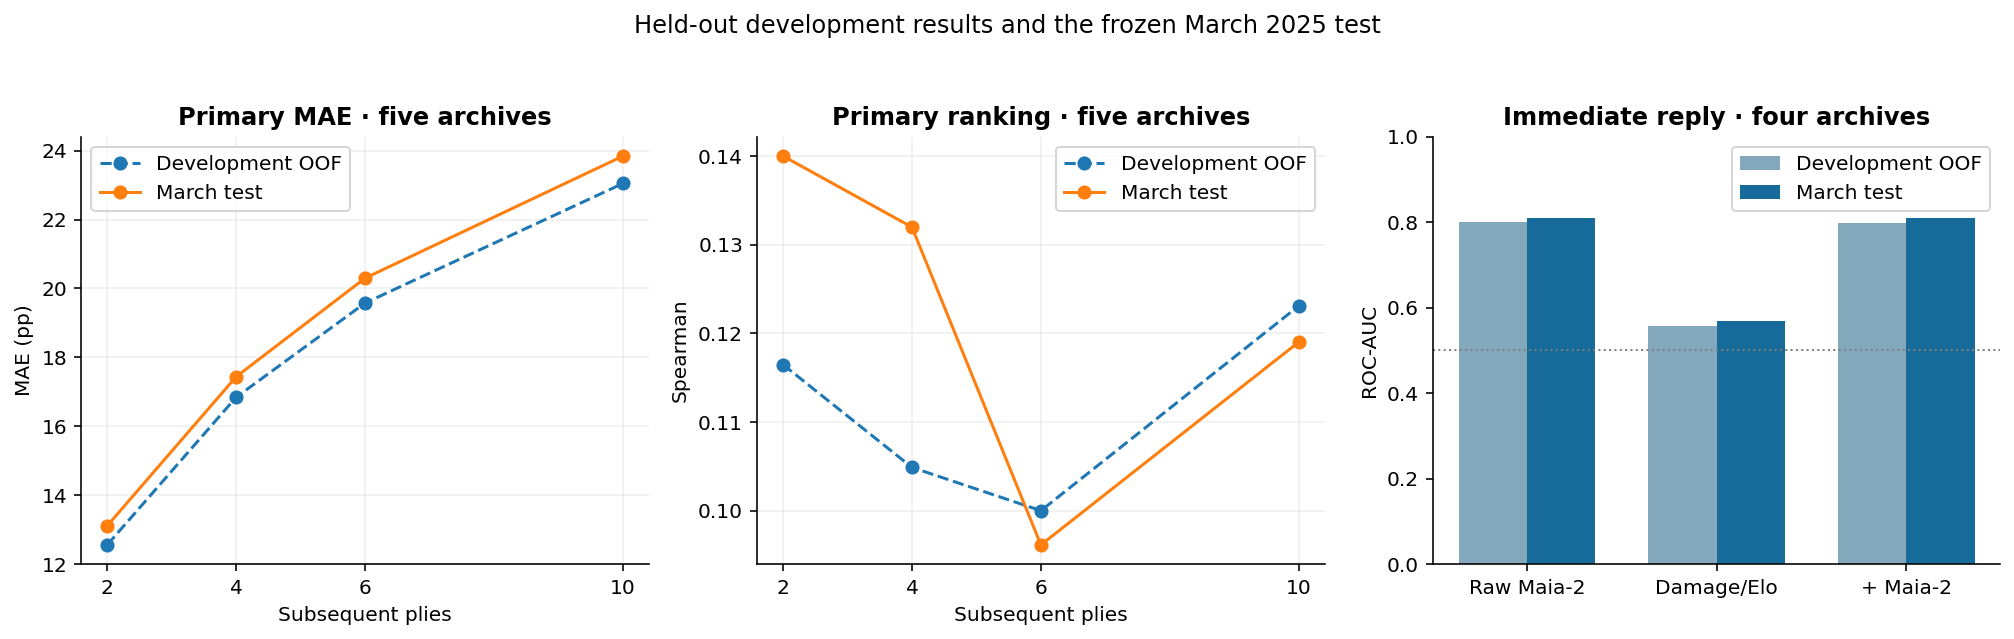

In [4]:
dp = T['development_primary'].copy()
dp['horizon'] = pd.to_numeric(dp.target)
dp['method'] = dp.model.replace({'fixed_lightgbm': 'Frozen LightGBM',
                                'no_change': 'No-change', 'training_mean': 'Training-mean'})
comparison = []
for d in dp.itertuples():
    key = f'primary_{d.horizon}' if d.model == 'fixed_lightgbm' else d.model
    t = PRIMARY[(PRIMARY.horizon == d.horizon) & (PRIMARY.model == key)].iloc[0]
    comparison.append({'Plies': d.horizon, 'Method': d.method, 'Development MAE': d.mae,
                       'Test MAE': t.mae, 'Development Spearman': d.spearman,
                       'Test Spearman': t.spearman})
table(pd.DataFrame(comparison), 'Primary development versus test', FIVE, DEV+' versus '+TEST)
dr = T['development_reply'].copy()
method_map = {'raw_maia': 'raw_maia', 'simple_lightgbm': 'reply_control',
              'simple_plus_maia_lightgbm': 'reply_maia',
              'training_majority_prevalence': 'training_majority'}
reply_comparison = []
for d in dr.itertuples():
    model = method_map[d.method]
    t = REPLY[REPLY.model == model].iloc[0]
    for metric in ['accuracy', 'balanced_accuracy', 'roc_auc', 'brier', 'log_loss']:
        reply_comparison.append({'Method': NAMES[model], 'Metric': metric,
            'Development': getattr(d, metric), 'Test': t[metric]})
table(pd.DataFrame(reply_comparison), 'Immediate reply: development versus test', FOUR,
      DEV+' versus '+TEST)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for cohort, frame, style in [('Development OOF', dp[dp.model == 'fixed_lightgbm'], '--'),
                            ('March test', PRIMARY[PRIMARY.model.str.startswith('primary_')], '-')]:
    frame = frame.sort_values('horizon')
    axes[0].plot(frame.horizon, frame.mae, style+'o', label=cohort)
    axes[1].plot(frame.horizon, frame.spearman, style+'o', label=cohort)
axes[0].set(title='Primary MAE · five archives', ylabel='MAE (pp)', xlabel='Subsequent plies')
axes[1].set(title='Primary ranking · five archives', ylabel='Spearman', xlabel='Subsequent plies')
for ax in axes[:2]:
    ax.set_xticks([2, 4, 6, 10]); ax.grid(alpha=.2); ax.legend()
x = np.arange(3)
plot_methods = ['raw_maia', 'reply_control', 'reply_maia']
dev_auc = [dr.loc[dr.method == next(k for k, v in method_map.items() if v == m), 'roc_auc'].iloc[0]
           for m in plot_methods]
test_auc = [REPLY.loc[REPLY.model == m, 'roc_auc'].iloc[0] for m in plot_methods]
axes[2].bar(x-.18, dev_auc, .36, label='Development OOF', color='#83a8bb')
axes[2].bar(x+.18, test_auc, .36, label='March test', color='#176b9b')
axes[2].set(xticks=x, xticklabels=['Raw Maia-2', 'Damage/Elo', '+ Maia-2'], ylim=(0, 1),
            ylabel='ROC-AUC', title='Immediate reply · four archives')
axes[2].axhline(.5, color='gray', ls=':', lw=1); axes[2].legend()
fig.suptitle('Held-out development results and the frozen March 2025 test', y=1.04)
fig.tight_layout(); figure(fig)


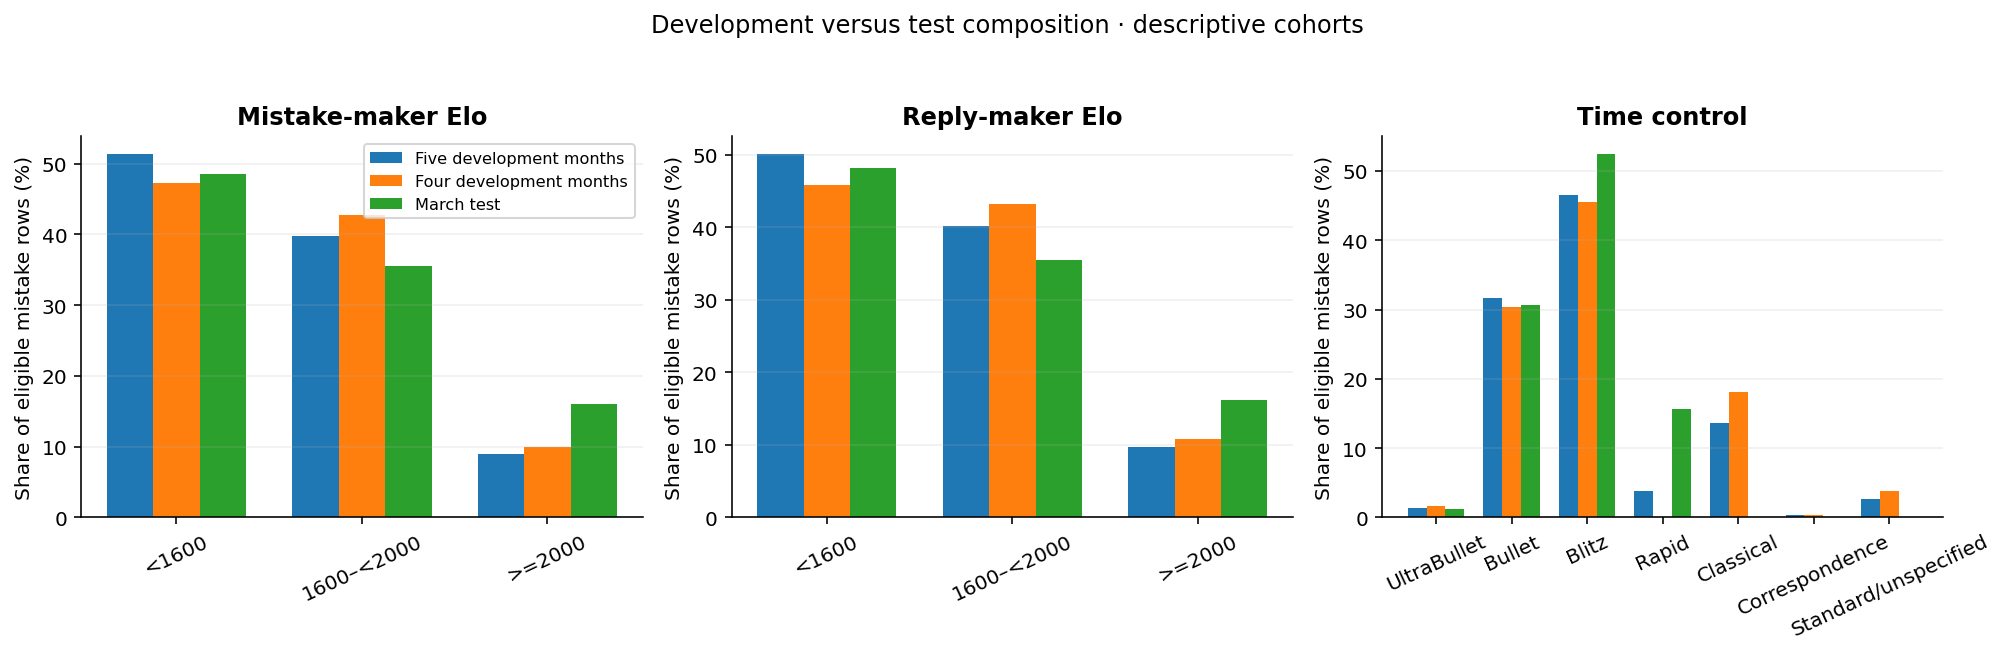

cohort,variable,group,n,games,share
development_five,player_elo_band,1600–<2000,9202,2905,0.397203
development_five,player_elo_band,<1600,11881,3563,0.512842
development_five,player_elo_band,>=2000,2084,694,0.089956
development_five,opponent_elo_band,1600–<2000,9304,2963,0.401606
development_five,opponent_elo_band,<1600,11596,3411,0.500540
development_five,opponent_elo_band,>=2000,2267,788,0.097855
development_five,time_control,-,69,21,0.002978
development_five,time_control,0+1,115,35,0.004964
development_five,time_control,0+2,14,5,0.000604
development_five,time_control,0+3,32,11,0.001381


In [5]:
distribution = T['distributions']
cohort_names = {'development_five': 'Five development months',
                'development_four': 'Four development months', 'final_temporal': 'March test'}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.3))
definitions = [('player_elo_band', ['<1600', '1600–<2000', '>=2000'], 'Mistake-maker Elo'),
               ('opponent_elo_band', ['<1600', '1600–<2000', '>=2000'], 'Reply-maker Elo'),
               ('speed_label', ['UltraBullet', 'Bullet', 'Blitz', 'Rapid', 'Classical'], 'Time control')]
for ax, (variable, preferred, title) in zip(axes, definitions):
    frame = distribution[distribution.variable == variable]
    groups = [g for g in preferred if g in set(frame.group)]
    groups += sorted(set(frame.group)-set(groups))
    for i, (cohort, label) in enumerate(cohort_names.items()):
        part = frame[frame.cohort == cohort].set_index('group').reindex(groups)
        ax.bar(np.arange(len(groups))+(i-1)*.25, part.share.fillna(0)*100, .25, label=label)
    ax.set(title=title, ylabel='Share of eligible mistake rows (%)',
           xticks=np.arange(len(groups)), xticklabels=groups)
    ax.tick_params(axis='x', rotation=25); ax.grid(axis='y', alpha=.2)
axes[0].legend(fontsize=8)
fig.suptitle('Development versus test composition · descriptive cohorts', y=1.04)
fig.tight_layout(); figure(fig)
table(distribution, 'All rating, speed, phase and exact time-control distributions',
      FIVE+'; '+FOUR+'; March 2025', 'Descriptive eligible-row cohorts; no model validation', collapsed=True)


## 3. Immediate opponent reply

The four methods use identical **3,356 replies / 951 games**. The control uses initial
damage and opponent Elo; its augmented version adds only the frozen Maia probability.
Raw Maia-2 was not locally fitted. ROC curves use continuous scores. The training
majority probability stays fixed at **0.5581351334300675**.


Method,Rows,Games,Accuracy,Balanced accuracy,ROC-AUC,Brier loss,Log loss,Precision (+),Recall (+),Recall (−),F1 (+),Average precision (+)
Raw Maia-2,3356,951,0.736889,0.728701,0.810216,0.179704,0.545852,0.738037,0.809524,0.647878,0.772129,0.833869
LightGBM: damage + opponent Elo,3356,951,0.567044,0.538733,0.569168,0.243971,0.681028,0.575124,0.818182,0.259284,0.675452,0.608080
LightGBM: damage + opponent Elo + Maia-2,3356,951,0.733909,0.725629,0.810050,0.176765,0.526934,0.735338,0.807359,0.643899,0.769667,0.834508
Training-majority / prevalence,3356,951,0.550656,0.500000,0.500000,0.247490,0.688120,0.550656,1.000000,0.000000,0.710223,0.550656


Method,tn,fp,fn,tp
Raw Maia-2,977,531,352,1496
LightGBM: damage + opponent Elo,391,1117,336,1512
LightGBM: damage + opponent Elo + Maia-2,971,537,356,1492
Training-majority / prevalence,0,1508,0,1848


model,baseline,metric,estimate,lower95,upper95,n,games
LightGBM: damage + opponent Elo + Maia-2,LightGBM: damage + opponent Elo,brier_improvement,0.067206,0.060561,0.073612,3356,951
LightGBM: damage + opponent Elo + Maia-2,LightGBM: damage + opponent Elo,accuracy_gain_pp,16.686532,14.703209,18.675440,3356,951
LightGBM: damage + opponent Elo + Maia-2,LightGBM: damage + opponent Elo,balanced_accuracy_gain_pp,18.689644,16.790962,20.592071,3356,951
Raw Maia-2,Training-majority / prevalence,brier_improvement,0.067786,0.059061,0.076163,3356,951
Raw Maia-2,Training-majority / prevalence,accuracy_gain_pp,18.623361,16.397366,20.783356,3356,951
Raw Maia-2,Training-majority / prevalence,balanced_accuracy_gain_pp,22.870090,21.246213,24.369028,3356,951


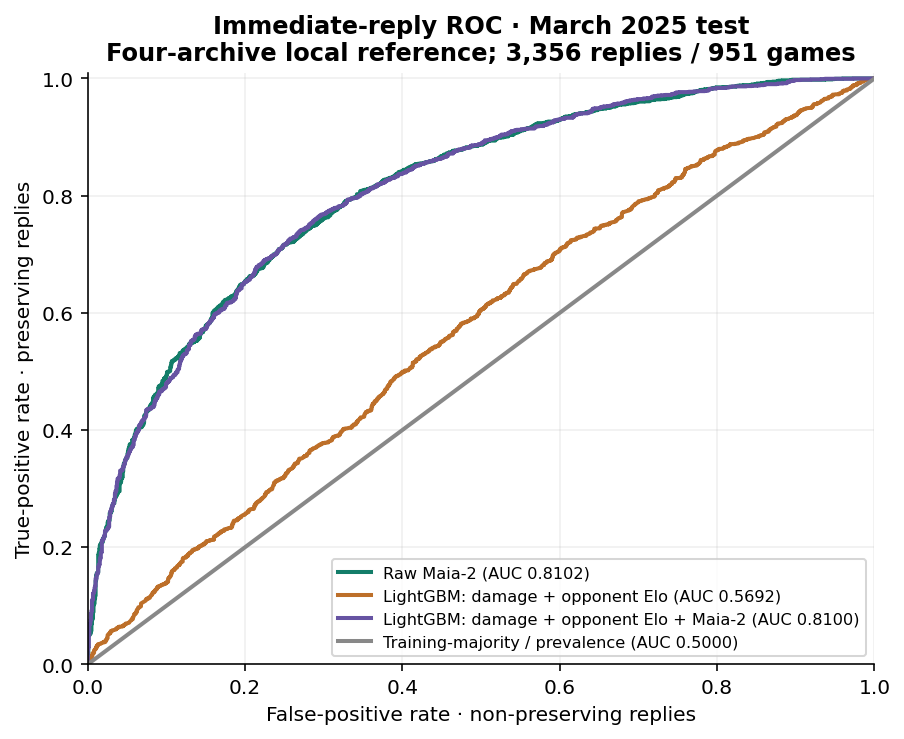

In [6]:
columns = ['model', 'n', 'games', 'accuracy', 'balanced_accuracy', 'roc_auc', 'brier',
           'log_loss', 'precision', 'recall', 'other_class_recall', 'f1', 'average_precision']
table(labelled(REPLY[columns]), 'Immediate reply · positive = preserving ≥75% damage', FOUR)
table(labelled(REPLY[['model', 'tn', 'fp', 'fn', 'tp']]),
      'Confusion counts · negative = non-preserving; positive = preserving', FOUR)
reply_ci = CI[(CI.task == 'reply') & (CI.threshold == 20)].copy()
reply_ci['model'] = reply_ci.model.map(NAMES)
reply_ci['baseline'] = reply_ci.baseline.map(NAMES)
table(reply_ci[['model', 'baseline', 'metric', 'estimate', 'lower95', 'upper95', 'n', 'games']],
      'Paired immediate-reply improvements · positive favors Maia', FOUR)

fig, ax = plt.subplots(figsize=(7, 5.3))
for model in ['raw_maia', 'reply_control', 'reply_maia', 'training_majority']:
    curve = DATA['roc'][model]
    ax.plot(curve['fpr'], curve['tpr'], color=COLORS[model], lw=2,
            label=f"{NAMES[model]} (AUC {curve['auc']:.4f})")
ax.set(xlabel='False-positive rate · non-preserving replies',
       ylabel='True-positive rate · preserving replies', xlim=(0, 1), ylim=(0, 1.01),
       title='Immediate-reply ROC · March 2025 test\nFour-archive local reference; 3,356 replies / 951 games')
ax.legend(loc='lower right', fontsize=8); ax.grid(alpha=.2); figure(fig)


### Probability calibration

Reliability uses **10 fixed equal-width bins** on [0,1]. A point compares the mean saved
probability with the observed preserving frequency in its bin; marker area reflects
bin size. The diagonal indicates agreement. Empty bins are omitted. These are descriptive
test summaries with no recalibration, threshold selection or fitting. Small bins are
unstable, and the plot has no game-cluster uncertainty bands.


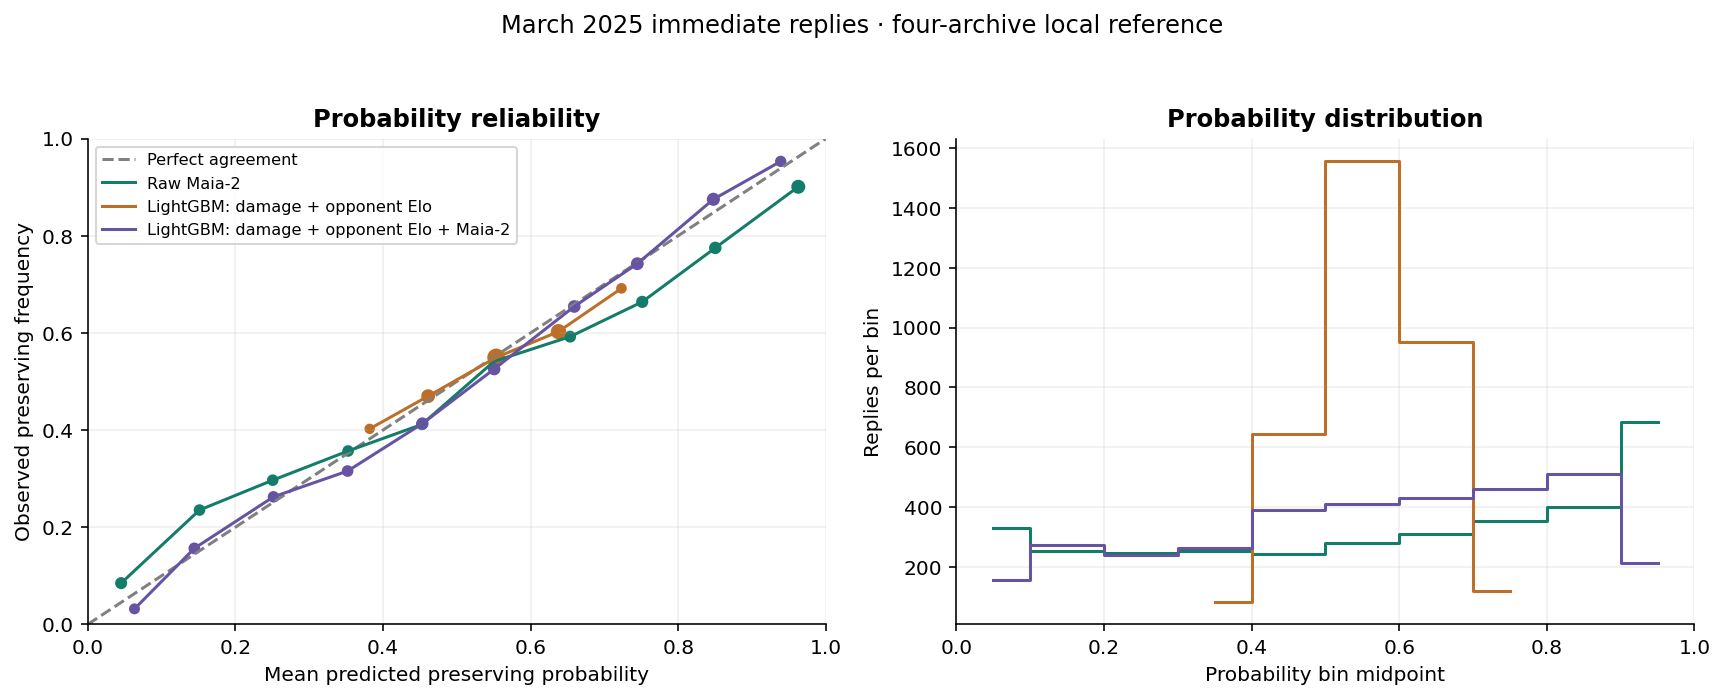

model,bin,lower,upper,n,mean_probability,observed_preserving
raw_maia,0,0.000000,0.100000,330,0.045212,0.084848
raw_maia,1,0.100000,0.200000,255,0.151352,0.235294
raw_maia,2,0.200000,0.300000,246,0.250562,0.296748
raw_maia,3,0.300000,0.400000,255,0.352645,0.356863
raw_maia,4,0.400000,0.500000,243,0.452650,0.411523
raw_maia,5,0.500000,0.600000,279,0.550330,0.541219
raw_maia,6,0.600000,0.700000,309,0.653462,0.592233
raw_maia,7,0.700000,0.800000,354,0.751178,0.663842
raw_maia,8,0.800000,0.900000,400,0.850155,0.775000
raw_maia,9,0.900000,1.000000,685,0.962594,0.900730


In [7]:
calibration = pd.DataFrame(DATA['calibration'])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].plot([0, 1], [0, 1], '--', color='gray', label='Perfect agreement')
for model in ['raw_maia', 'reply_control', 'reply_maia']:
    points = calibration[(calibration.model == model) & (calibration.n > 0)]
    axes[0].plot(points.mean_probability, points.observed_preserving, color=COLORS[model],
                 lw=1.5, label=NAMES[model])
    axes[0].scatter(points.mean_probability, points.observed_preserving,
                    s=15+100*points.n/3356, color=COLORS[model])
    axes[1].step((points.lower+points.upper)/2, points.n, where='mid',
                color=COLORS[model], label=NAMES[model])
axes[0].set(xlim=(0, 1), ylim=(0, 1), xlabel='Mean predicted preserving probability',
            ylabel='Observed preserving frequency', title='Probability reliability')
axes[1].set(xlim=(0, 1), xlabel='Probability bin midpoint', ylabel='Replies per bin',
            title='Probability distribution')
for ax in axes: ax.grid(alpha=.2)
axes[0].legend(fontsize=8)
fig.suptitle('March 2025 immediate replies · four-archive local reference', y=1.04)
fig.tight_layout(); figure(fig)
table(calibration, 'Calibration bin counts and means', FOUR, collapsed=True)


## 4. Later damage persistence

### Primary regression: five development archives

All horizons use **3,380 mistakes / 955 games** in the final test. No-change predicts zero;
training-mean uses a constant learned only from development. The frozen LightGBM loss
is mean absolute error. Lower MAE is better; higher Spearman is better.


Plies,Method,Rows,Games,MAE (pp),Spearman,Recovered-only MAE (diagnostic)
2,No-change,3380,955,13.140057,—,33.792760
2,Frozen LightGBM,3380,955,13.112113,0.140039,33.448690
2,Training-mean,3380,955,15.209204,—,27.540881
4,No-change,3380,955,17.603578,—,38.051457
4,Frozen LightGBM,3380,955,17.440267,0.132004,36.683098
4,Training-mean,3380,955,19.546459,—,30.080220
6,No-change,3380,955,20.618663,—,41.025800
6,Frozen LightGBM,3380,955,20.300963,0.096124,39.152733
6,Training-mean,3380,955,22.603856,—,31.910021
10,No-change,3380,955,24.421765,—,46.121097


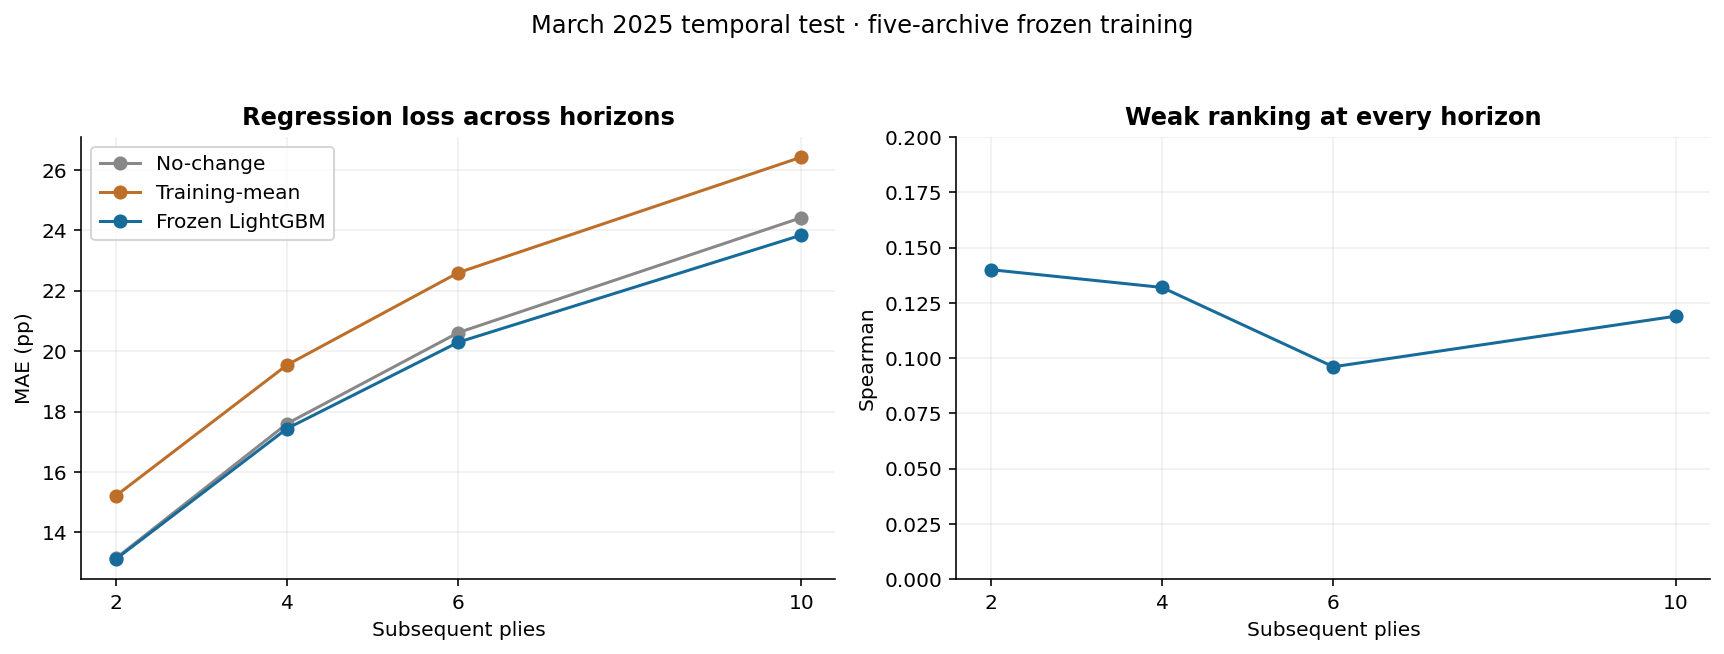

horizon,baseline,metric,estimate,lower95,upper95
2,no_change,mae_improvement_pp,0.027944,-0.026046,0.080649
2,no_change,mae_improvement_percent,0.212660,-0.196083,0.606994
2,training_mean,mae_improvement_pp,2.097090,1.922497,2.276189
2,training_mean,mae_improvement_percent,13.788297,12.432597,15.235138
4,no_change,mae_improvement_pp,0.163311,-0.027115,0.369149
4,no_change,mae_improvement_percent,0.927715,-0.158515,2.049579
4,training_mean,mae_improvement_pp,2.106192,1.822970,2.402081
4,training_mean,mae_improvement_percent,10.775313,9.319525,12.273631
6,no_change,mae_improvement_pp,0.317700,0.078549,0.574370
6,no_change,mae_improvement_percent,1.540836,0.381584,2.731187


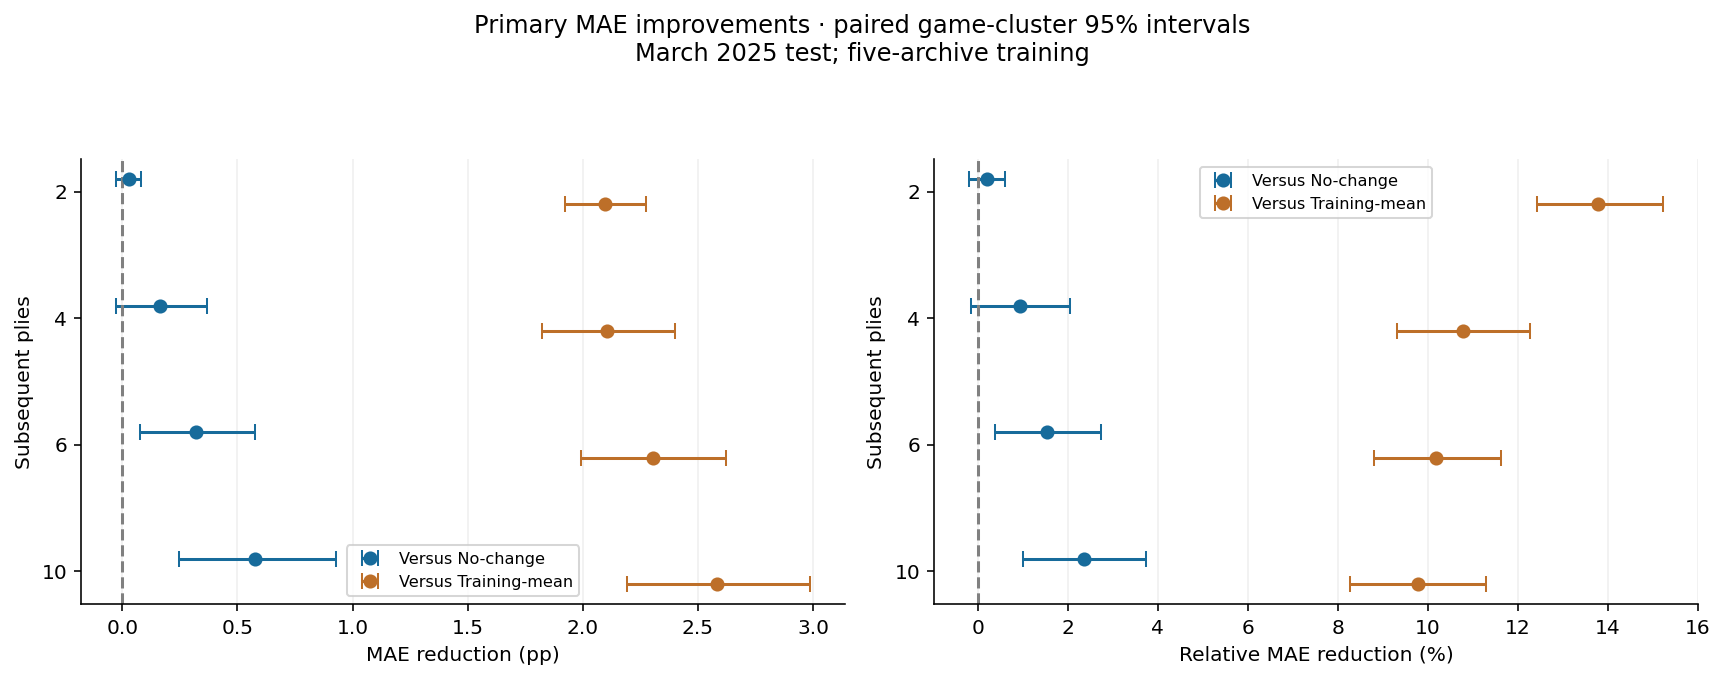

In [8]:
table(labelled(PRIMARY[['horizon', 'model', 'n', 'games', 'mae', 'spearman', 'recovered_only_mae']]),
      'Primary regression · MAE loss and ranking', FIVE)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for model, label in [('no_change', 'No-change'), ('training_mean', 'Training-mean'),
                      ('lightgbm', 'Frozen LightGBM')]:
    part = PRIMARY[PRIMARY.model.str.startswith('primary_') if model == 'lightgbm'
                   else PRIMARY.model == model].sort_values('horizon')
    axes[0].plot(part.horizon, part.mae, 'o-', color=COLORS[model], label=label)
axes[0].set(title='Regression loss across horizons', ylabel='MAE (pp)', xlabel='Subsequent plies')
axes[0].legend()
part = PRIMARY[PRIMARY.model.str.startswith('primary_')].sort_values('horizon')
axes[1].plot(part.horizon, part.spearman, 'o-', color=COLORS['lightgbm'])
axes[1].set(title='Weak ranking at every horizon', ylabel='Spearman', xlabel='Subsequent plies',
            ylim=(0, max(.2, part.spearman.max()*1.2)))
for ax in axes: ax.set_xticks([2, 4, 6, 10]); ax.grid(alpha=.2)
fig.suptitle('March 2025 temporal test · five-archive frozen training', y=1.04)
fig.tight_layout(); figure(fig)
primary_ci = CI[(CI.task == 'primary') & (CI.threshold == 20)]
table(primary_ci[['horizon', 'baseline', 'metric', 'estimate', 'lower95', 'upper95']],
      'Primary regression improvements · positive favors LightGBM', FIVE)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for ax, metric, xlabel in zip(axes, ['mae_improvement_pp', 'mae_improvement_percent'],
                            ['MAE reduction (pp)', 'Relative MAE reduction (%)']):
    for offset, baseline, color in [(-.10, 'no_change', '#176b9b'), (.10, 'training_mean', '#bd6f29')]:
        part = primary_ci[(primary_ci.metric == metric) &
                          (primary_ci.baseline == baseline)].sort_values('horizon')
        errors = np.array([part.estimate-part.lower95, part.upper95-part.estimate])
        ax.errorbar(part.estimate, np.arange(4)+offset, xerr=errors, fmt='o', capsize=4,
                    color=color, label='Versus '+NAMES[baseline])
    ax.axvline(0, color='gray', ls='--'); ax.set_yticks(np.arange(4), ['2', '4', '6', '10'])
    ax.set(xlabel=xlabel, ylabel='Subsequent plies'); ax.invert_yaxis(); ax.legend(fontsize=8)
    ax.grid(axis='x', alpha=.2)
fig.suptitle('Primary MAE improvements · paired game-cluster 95% intervals\n'
             'March 2025 test; five-archive training', y=1.08)
fig.tight_layout(); figure(fig)


Against no-change, the 2- and 4-ply intervals include zero. Gains at 6 and 10 plies
are positive but modest. The larger gains against training-mean do not imply strong
prediction. Intervals use **2,000 paired whole-game resamples, seed 1701**, with fixed
predictions and no bootstrap refitting or multiplicity adjustment.

### Matched 10-ply comparison: four development archives

These models use identical F24 predictors, settings and training rows; one adds only
the frozen Maia probability. Their difference isolates that input within this specified
model comparison. Comparing either with the five-archive primary model does not isolate
Maia, because the training cohorts differ.


In [9]:
table(labelled(TEN[['model', 'n', 'games', 'mae', 'spearman', 'recovered_only_mae']]),
      'Matched 10-ply test regression', FOUR)
ten_ci = CI[(CI.task == 'ten') & (CI.threshold == 20)]
table(ten_ci[['metric', 'estimate', 'lower95', 'upper95', 'n', 'games']],
      'Matched 10-ply Maia increment · positive favors adding Maia', FOUR)
rows = []
for d in T['development_ten'].itertuples():
    model = 'ten_control' if d.variant == 'fixed_lightgbm' else 'ten_maia'
    t = TEN[TEN.model == model].iloc[0]
    rows.append({'Method': NAMES[model], 'Development MAE': d.mae, 'Test MAE': t.mae,
                 'Development Spearman': d.spearman, 'Test Spearman': t.spearman})
table(pd.DataFrame(rows), 'Matched 10-ply development versus test', FOUR, DEV+' versus '+TEST)


Method,Rows,Games,MAE (pp),Spearman,Recovered-only MAE (diagnostic)
LightGBM: F24,3380,955,24.066105,0.078445,43.518341
LightGBM: F24 + Maia-2,3380,955,23.689191,0.146380,41.430672


metric,estimate,lower95,upper95,n,games
mae_improvement_pp,0.376914,0.202856,0.557825,3380,955
mae_improvement_percent,1.566159,0.851995,2.294402,3380,955


Method,Development MAE,Test MAE,Development Spearman,Test Spearman
LightGBM: F24,22.930386,24.066105,0.133253,0.078445
LightGBM: F24 + Maia-2,22.732183,23.689191,0.178333,0.146380


## 5. Recovered versus persistent diagnostics

Positive means **recovered (<0.75 ratio)**; negative means persistent (≥0.75).
These labels are derived from regression, not separate classifiers. Accuracy close to
majority accuracy can coexist with very low recovered recall. AUC and average precision
use continuous negative predicted ratio; this score is not a probability.


In [10]:
classification = ['horizon', 'model', 'accuracy', 'majority_accuracy', 'balanced_accuracy',
                  'roc_auc', 'precision', 'recall', 'other_class_recall', 'f1', 'average_precision']
table(labelled(PRIMARY[classification]), 'Primary regression-derived recovery · all horizons and baselines', FIVE)
table(labelled(PRIMARY[['horizon', 'model', 'tn', 'fp', 'fn', 'tp']]),
      'Primary recovery confusion counts · positive = recovered', FIVE, collapsed=True)
table(labelled(TEN[classification]), 'Matched 10-ply regression-derived recovery', FOUR)


Plies,Method,Accuracy,Majority accuracy,Balanced accuracy,ROC-AUC,Precision (+),Recall (+),Recall (−),F1 (+),Average precision (+)
2,No-change,0.721006,0.721006,0.500000,0.500000,—,0.000000,1.000000,0.000000,0.278994
2,Frozen LightGBM,0.721006,0.721006,0.503576,0.605051,0.500000,0.011665,0.995486,0.022798,0.367594
2,Training-mean,0.629586,0.721006,0.520141,0.540511,0.312272,0.272534,0.767747,0.291053,0.306862
4,No-change,0.665089,0.665089,0.500000,0.500000,—,0.000000,1.000000,0.000000,0.334911
4,Frozen LightGBM,0.667751,0.665089,0.507045,0.590053,0.621622,0.020318,0.993772,0.039350,0.422589
4,Training-mean,0.525148,0.665089,0.523291,0.532394,0.356231,0.517668,0.528915,0.422038,0.357042
6,No-change,0.639941,0.639941,0.500000,0.500000,—,0.000000,1.000000,0.000000,0.360059
6,Frozen LightGBM,0.644675,0.639941,0.510527,0.571932,0.633333,0.031224,0.989829,0.059514,0.437423
6,Training-mean,0.492899,0.639941,0.530299,0.541137,0.382395,0.663928,0.396671,0.485285,0.385783
10,No-change,0.619527,0.619527,0.500000,0.500000,—,0.000000,1.000000,0.000000,0.380473


Plies,Method,tn,fp,fn,tp
2,No-change,2437,0,943,0
2,Frozen LightGBM,2426,11,932,11
2,Training-mean,1871,566,686,257
4,No-change,2248,0,1132,0
4,Frozen LightGBM,2234,14,1109,23
4,Training-mean,1189,1059,546,586
6,No-change,2163,0,1217,0
6,Frozen LightGBM,2141,22,1179,38
6,Training-mean,858,1305,409,808
10,No-change,2094,0,1286,0


Plies,Method,Accuracy,Majority accuracy,Balanced accuracy,ROC-AUC,Precision (+),Recall (+),Recall (−),F1 (+),Average precision (+)
10,LightGBM: F24,0.626627,0.619527,0.517883,0.548527,0.586957,0.062986,0.972779,0.113764,0.445199
10,LightGBM: F24 + Maia-2,0.639349,0.619527,0.552154,0.595929,0.580723,0.187403,0.916905,0.283363,0.489603


## 6. Robustness and subgroups

The >25 and >30 damage subsets reuse the same frozen >20 predictions, with no refits.
All saved rows are retained below, including unfavorable results. Subgroup estimates
describe this cohort and are not causal effects or independent confirmations.

**UltraBullet is a small-sample limitation:** the test cohort contains only 40 mistakes
from 9 games. Classical also has only 2 mistakes from 1 game. These groups do not
support reliable performance findings, and some speeds are outside the Maia domain.


In [11]:
for task, title, archives in [('primary', 'Primary regression', FIVE),
                              ('reply', 'Immediate reply', FOUR), ('ten', 'Matched 10-ply', FOUR)]:
    frame = M[(M.task == task) & (M.threshold > 20)]
    table(labelled(frame), title+' · complete >25/>30 robustness metrics', archives, collapsed=True)
table(CI, 'All 72 paired intervals · >20/>25/>30',
      'Five months for primary; four months for immediate and matched 10-ply', collapsed=True)
for task, title, archives in [('primary', 'Primary regression', FIVE),
                              ('reply', 'Immediate reply', FOUR), ('ten', 'Matched 10-ply', FOUR)]:
    table(labelled(T['subgroups'][T['subgroups'].task == task]),
          title+' · all saved Elo, speed and phase subgroups', archives, collapsed=True)


task,Plies,Method,Damage > (pp),Games,excluded_missing_target,MAE (pp),Spearman,Recovered-only MAE (diagnostic),Majority accuracy,Rows,Accuracy,Balanced accuracy,Precision (+),Recall (+),Recall (−),tn,fp,fn,tp,ROC-AUC,Brier loss,F1 (+),Average precision (+),Log loss
primary,2,No-change,25,880,0,13.840541,—,38.253636,0.732477,2568,0.732477,0.500000,—,0.000000,1.000000,1881,0,687,0,0.500000,—,0.000000,0.267523,—
primary,2,Frozen LightGBM,25,880,0,13.806381,0.145934,37.859427,0.732477,2568,0.732866,0.504886,0.526316,0.014556,0.995215,1872,9,677,10,0.607615,—,0.028329,0.357290,—
primary,2,Training-mean,25,880,0,16.029903,—,31.990102,0.732477,2568,0.728972,0.498070,0.090909,0.001456,0.994684,1871,10,686,1,0.530597,—,0.002865,0.282559,—
primary,4,No-change,25,880,0,18.478087,—,42.424084,0.675234,2568,0.675234,0.500000,—,0.000000,1.000000,1734,0,834,0,0.500000,—,0.000000,0.324766,—
primary,4,Frozen LightGBM,25,880,0,18.287143,0.127479,40.876277,0.675234,2568,0.678738,0.508507,0.655172,0.022782,0.994233,1724,10,815,19,0.599312,—,0.044032,0.420135,—
primary,4,Training-mean,25,880,0,20.548286,—,34.433678,0.675234,2568,0.575156,0.515511,0.345738,0.345324,0.685698,1189,545,546,288,0.524709,—,0.345531,0.339793,—
primary,6,No-change,25,880,0,21.234550,—,45.284208,0.651869,2568,0.651869,0.500000,—,0.000000,1.000000,1674,0,894,0,0.500000,—,0.000000,0.348131,—
primary,6,Frozen LightGBM,25,880,0,20.881953,0.106621,43.181455,0.651869,2568,0.656542,0.511663,0.620000,0.034676,0.988650,1655,19,863,31,0.576883,—,0.065678,0.429116,—
primary,6,Training-mean,25,880,0,23.330659,—,36.087434,0.651869,2568,0.522975,0.527525,0.372790,0.542506,0.512545,858,816,409,485,0.537742,—,0.441913,0.372358,—
primary,10,No-change,25,880,0,25.042211,—,49.802443,0.623442,2568,0.623442,0.500000,—,0.000000,1.000000,1601,0,967,0,0.500000,—,0.000000,0.376558,—


task,Plies,Method,Damage > (pp),Games,excluded_missing_target,MAE (pp),Spearman,Recovered-only MAE (diagnostic),Majority accuracy,Rows,Accuracy,Balanced accuracy,Precision (+),Recall (+),Recall (−),tn,fp,fn,tp,ROC-AUC,Brier loss,F1 (+),Average precision (+),Log loss
reply,1,Raw Maia-2,25,876,21,—,—,—,—,2547,0.738123,0.724736,0.745773,0.820248,0.629224,689,406,261,1191,0.804894,0.180694,0.781240,0.836382,0.553453
reply,1,LightGBM: damage + opponent Elo,25,876,21,—,—,—,—,2547,0.582646,0.529656,0.586560,0.907713,0.151598,166,929,134,1318,0.560263,0.242159,0.712625,0.620120,0.677368
reply,1,LightGBM: damage + opponent Elo + Maia-2,25,876,21,—,—,—,—,2547,0.733412,0.718583,0.738433,0.824380,0.612785,671,424,255,1197,0.805212,0.177289,0.779043,0.837894,0.528705
reply,1,Training-majority / prevalence,25,876,21,—,—,—,—,2547,0.570082,0.500000,0.570082,1.000000,0.000000,0,1095,0,1452,0.500000,0.245231,0.726182,0.570082,0.683582
reply,1,Raw Maia-2,30,800,20,—,—,—,—,1927,0.740010,0.719063,0.752773,0.834065,0.604061,476,312,189,950,0.806006,0.177865,0.791337,0.848909,0.545458
reply,1,LightGBM: damage + opponent Elo,30,800,20,—,—,—,—,1927,0.600415,0.520220,0.601429,0.960492,0.079949,63,725,45,1094,0.539522,0.239957,0.739689,0.629082,0.672936
reply,1,LightGBM: damage + opponent Elo + Maia-2,30,800,20,—,—,—,—,1927,0.737935,0.715547,0.748433,0.838455,0.592640,467,321,184,955,0.807383,0.174578,0.790890,0.853384,0.521947
reply,1,Training-majority / prevalence,30,800,20,—,—,—,—,1927,0.591074,0.500000,0.591074,1.000000,0.000000,0,788,0,1139,0.500000,0.242790,0.742988,0.591074,0.678678


task,Plies,Method,Damage > (pp),Games,excluded_missing_target,MAE (pp),Spearman,Recovered-only MAE (diagnostic),Majority accuracy,Rows,Accuracy,Balanced accuracy,Precision (+),Recall (+),Recall (−),tn,fp,fn,tp,ROC-AUC,Brier loss,F1 (+),Average precision (+),Log loss
ten,10,LightGBM: F24,25,880,0,24.635206,0.083972,46.743977,0.623442,2568,0.631231,0.519351,0.592593,0.066184,0.972517,1557,44,903,64,0.550700,—,0.119070,0.443308,—
ten,10,LightGBM: F24 + Maia-2,25,880,0,24.205106,0.153010,44.335838,0.623442,2568,0.643302,0.554627,0.577982,0.195450,0.913804,1463,138,778,189,0.601310,—,0.292117,0.489499,—
ten,10,LightGBM: F24,30,808,0,24.562007,0.087288,49.653409,0.634309,1947,0.642527,0.521347,0.595238,0.070225,0.972470,1201,34,662,50,0.558256,—,0.125628,0.443549,—
ten,10,LightGBM: F24 + Maia-2,30,808,0,23.961889,0.177645,46.725709,0.634309,1947,0.660503,0.564661,0.604082,0.207865,0.921457,1138,97,564,148,0.627835,—,0.309300,0.504519,—


task,horizon,model,baseline,metric,threshold,n,games,estimate,lower95,upper95,valid_replicates,repeats
primary,2,primary_2,no_change,mae_improvement_pp,20,3380,955,0.027944,-0.026046,0.080649,2000,2000
primary,2,primary_2,no_change,mae_improvement_percent,20,3380,955,0.212660,-0.196083,0.606994,2000,2000
primary,2,primary_2,training_mean,mae_improvement_pp,20,3380,955,2.097090,1.922497,2.276189,2000,2000
primary,2,primary_2,training_mean,mae_improvement_percent,20,3380,955,13.788297,12.432597,15.235138,2000,2000
primary,4,primary_4,no_change,mae_improvement_pp,20,3380,955,0.163311,-0.027115,0.369149,2000,2000
primary,4,primary_4,no_change,mae_improvement_percent,20,3380,955,0.927715,-0.158515,2.049579,2000,2000
primary,4,primary_4,training_mean,mae_improvement_pp,20,3380,955,2.106192,1.822970,2.402081,2000,2000
primary,4,primary_4,training_mean,mae_improvement_percent,20,3380,955,10.775313,9.319525,12.273631,2000,2000
primary,6,primary_6,no_change,mae_improvement_pp,20,3380,955,0.317700,0.078549,0.574370,2000,2000
primary,6,primary_6,no_change,mae_improvement_percent,20,3380,955,1.540836,0.381584,2.731187,2000,2000


task,Plies,Method,variable,group,Games,small_group,MAE (pp),Spearman,Recovered-only MAE (diagnostic),Majority accuracy,Rows,Accuracy,Balanced accuracy,Precision (+),Recall (+),Recall (−),tn,fp,fn,tp,ROC-AUC,Brier loss
primary,2,No-change,player_elo_band,1600–<2000,362,False,13.000337,—,33.508743,0.713928,1199,0.713928,0.500000,—,0.000000,1.000000,856,0,343,0,0.500000,—
primary,2,No-change,player_elo_band,<1600,460,False,13.595702,—,34.159118,0.715680,1639,0.715680,0.500000,—,0.000000,1.000000,1173,0,466,0,0.500000,—
primary,2,No-change,player_elo_band,>=2000,182,False,12.071280,—,33.245704,0.752768,542,0.752768,0.500000,—,0.000000,1.000000,408,0,134,0,0.500000,—
primary,2,No-change,time_control,0+1,1,True,5.786812,—,—,1.000000,1,1.000000,—,—,—,1.000000,1,0,0,0,—,—
primary,2,No-change,time_control,120+0,3,True,11.505322,—,46.124231,0.818182,11,0.818182,0.500000,—,0.000000,1.000000,9,0,2,0,0.500000,—
primary,2,No-change,time_control,120+1,45,False,13.975947,—,32.302390,0.664384,146,0.664384,0.500000,—,0.000000,1.000000,97,0,49,0,0.500000,—
primary,2,No-change,time_control,15+0,9,True,12.193120,—,28.047009,0.625000,40,0.625000,0.500000,—,0.000000,1.000000,25,0,15,0,0.500000,—
primary,2,No-change,time_control,15+4,1,True,38.644583,—,57.650134,0.333333,3,0.333333,0.500000,—,0.000000,1.000000,1,0,2,0,0.500000,—
primary,2,No-change,time_control,180+0,146,False,12.276009,—,32.443826,0.726916,509,0.726916,0.500000,—,0.000000,1.000000,370,0,139,0,0.500000,—
primary,2,No-change,time_control,180+2,136,False,11.902644,—,31.569699,0.731111,450,0.731111,0.500000,—,0.000000,1.000000,329,0,121,0,0.500000,—


task,Plies,Method,variable,group,Games,small_group,MAE (pp),Spearman,Recovered-only MAE (diagnostic),Majority accuracy,Rows,Accuracy,Balanced accuracy,Precision (+),Recall (+),Recall (−),tn,fp,fn,tp,ROC-AUC,Brier loss
reply,1,Raw Maia-2,opponent_elo_band,1600–<2000,355,False,—,—,—,—,1189,0.733389,0.723288,0.745152,0.801788,0.644788,334,184,133,538,0.802354,0.182655
reply,1,Raw Maia-2,opponent_elo_band,<1600,455,False,—,—,—,—,1620,0.737037,0.731836,0.720573,0.821470,0.642202,490,273,153,704,0.821434,0.175418
reply,1,Raw Maia-2,opponent_elo_band,>=2000,189,False,—,—,—,—,547,0.744059,0.733879,0.774390,0.793750,0.674009,153,74,66,254,0.794961,0.185982
reply,1,Raw Maia-2,time_control,0+1,1,True,—,—,—,—,1,1.000000,—,1.000000,1.000000,—,0,0,0,1,—,0.000019
reply,1,Raw Maia-2,time_control,120+0,3,True,—,—,—,—,11,0.545455,0.535714,0.400000,0.500000,0.571429,4,3,2,2,0.607143,0.304027
reply,1,Raw Maia-2,time_control,120+1,45,False,—,—,—,—,146,0.726027,0.722191,0.717647,0.792208,0.652174,45,24,16,61,0.764540,0.204488
reply,1,Raw Maia-2,time_control,15+0,9,True,—,—,—,—,40,0.625000,0.673913,0.531250,1.000000,0.347826,8,15,0,17,0.800512,0.280759
reply,1,Raw Maia-2,time_control,15+4,1,True,—,—,—,—,2,0.000000,—,0.000000,—,0.000000,0,2,0,0,—,0.754932
reply,1,Raw Maia-2,time_control,180+0,145,False,—,—,—,—,505,0.746535,0.731598,0.763407,0.820339,0.642857,135,75,53,242,0.814746,0.174875
reply,1,Raw Maia-2,time_control,180+2,136,False,—,—,—,—,448,0.763393,0.759109,0.812500,0.781955,0.736264,134,48,58,208,0.846340,0.159419


task,Plies,Method,variable,group,Games,small_group,MAE (pp),Spearman,Recovered-only MAE (diagnostic),Majority accuracy,Rows,Accuracy,Balanced accuracy,Precision (+),Recall (+),Recall (−),tn,fp,fn,tp,ROC-AUC,Brier loss
ten,10,LightGBM: F24,player_elo_band,1600–<2000,362,False,23.149316,0.084733,42.202280,0.625521,1199,0.628857,0.513840,0.543478,0.055679,0.972000,729,21,424,25,0.546652,—
ten,10,LightGBM: F24,player_elo_band,<1600,460,False,25.610476,0.067047,45.690286,0.598536,1639,0.605857,0.514373,0.611111,0.050152,0.978593,960,21,625,33,0.547921,—
ten,10,LightGBM: F24,player_elo_band,>=2000,182,False,21.424048,0.193311,38.835496,0.669742,542,0.684502,0.543585,0.605263,0.128492,0.958678,348,15,156,23,0.614787,—
ten,10,LightGBM: F24,time_control,0+1,1,True,5.029468,—,—,1.000000,1,1.000000,—,—,—,1.000000,1,0,0,0,—,—
ten,10,LightGBM: F24,time_control,120+0,3,True,15.657810,0.254545,28.978578,0.636364,11,0.636364,0.500000,—,0.000000,1.000000,7,0,4,0,0.678571,—
ten,10,LightGBM: F24,time_control,120+1,45,False,22.182404,0.248598,37.939186,0.582192,146,0.623288,0.551495,0.875000,0.114754,0.988235,84,1,54,7,0.657281,—
ten,10,LightGBM: F24,time_control,15+0,9,True,26.760752,0.077486,43.184355,0.650000,40,0.550000,0.439560,0.166667,0.071429,0.807692,21,5,13,1,0.458791,—
ten,10,LightGBM: F24,time_control,15+4,1,True,81.322606,0.500000,81.322606,0.000000,3,0.000000,—,—,0.000000,—,0,0,3,0,—,—
ten,10,LightGBM: F24,time_control,180+0,146,False,22.860701,0.174657,41.097777,0.601179,509,0.628684,0.536141,0.888889,0.078818,0.993464,304,2,187,16,0.599730,—
ten,10,LightGBM: F24,time_control,180+2,136,False,21.650297,-0.018932,41.369548,0.657778,450,0.651111,0.499605,0.333333,0.019481,0.979730,290,6,151,3,0.529352,—


## 7. Development training diagnostics

### Saved LightGBM boosting-iteration curve

This **earlier development-only** run uses the same F24 feature list and fixed 240-tree
settings as the primary regressor, at **6 plies only**. It uses three game folds across
all five development months. Lines are mistake-weighted training and held-out fold
averages. Training occurrences repeat across folds and are not unique sample counts.
This is a historical diagnostic, not a test-set iteration sweep or a new model selection.


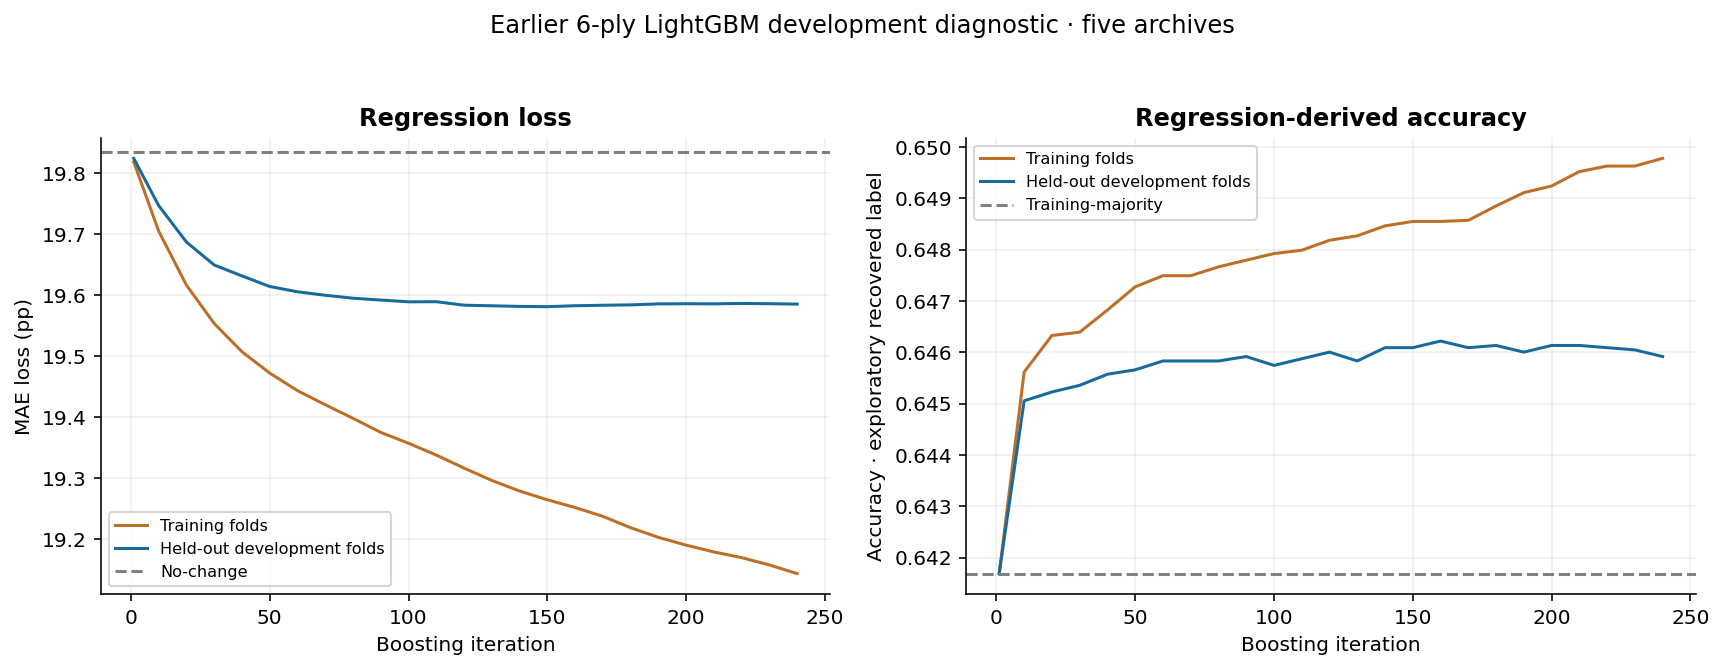

horizon,feature_set,iteration,split,folds,observation_occurrences,mae,mae_min_fold,mae_max_fold,accuracy_exploratory,accuracy_exploratory_min_fold,accuracy_exploratory_max_fold,no_change_mae,no_change_mae_min_fold,no_change_mae_max_fold,majority_accuracy,majority_accuracy_min_fold,majority_accuracy_max_fold
6,full_multipv,1,training,3,46334,19.818659,19.750506,19.897264,0.641689,0.638588,0.643411,19.834492,19.763157,19.916033,0.641689,0.638588,0.643411
6,full_multipv,1,validation,3,23167,19.824359,19.659832,19.966126,0.641689,0.638229,0.647948,19.834492,19.669900,19.975275,0.641689,0.638229,0.647948
6,full_multipv,10,training,3,46334,19.705061,19.657199,19.747052,0.645617,0.643623,0.646657,19.834492,19.763157,19.916033,0.641689,0.638588,0.643411
6,full_multipv,10,validation,3,23167,19.746837,19.590795,19.899931,0.645055,0.642023,0.650423,19.834492,19.669900,19.975275,0.641689,0.638229,0.647948
6,full_multipv,20,training,3,46334,19.616430,19.585482,19.637223,0.646329,0.644268,0.647873,19.834492,19.763157,19.916033,0.641689,0.638588,0.643411
6,full_multipv,20,validation,3,23167,19.687120,19.539829,19.851364,0.645228,0.642023,0.650814,19.834492,19.669900,19.975275,0.641689,0.638229,0.647948
6,full_multipv,30,training,3,46334,19.553587,19.522448,19.572727,0.646394,0.644397,0.647743,19.834492,19.763157,19.916033,0.641689,0.638588,0.643411
6,full_multipv,30,validation,3,23167,19.649474,19.512144,19.815530,0.645358,0.642151,0.650684,19.834492,19.669900,19.975275,0.641689,0.638229,0.647948
6,full_multipv,40,training,3,46334,19.507272,19.479797,19.524901,0.646825,0.644720,0.648455,19.834492,19.763157,19.916033,0.641689,0.638588,0.643411
6,full_multipv,40,validation,3,23167,19.631561,19.501704,19.792697,0.645573,0.642536,0.651075,19.834492,19.669900,19.975275,0.641689,0.638229,0.647948


In [12]:
boosting = T['boosting']
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for split, label, color in [('training', 'Training folds', '#bd6f29'),
                             ('validation', 'Held-out development folds', '#176b9b')]:
    part = boosting[boosting.split == split].sort_values('iteration')
    axes[0].plot(part.iteration, part.mae, color=color, label=label)
    axes[1].plot(part.iteration, part.accuracy_exploratory, color=color, label=label)
baseline = boosting[boosting.split == 'validation'].iloc[0]
axes[0].axhline(baseline.no_change_mae, color='gray', ls='--', label='No-change')
axes[1].axhline(baseline.majority_accuracy, color='gray', ls='--', label='Training-majority')
axes[0].set(ylabel='MAE loss (pp)', title='Regression loss')
axes[1].set(ylabel='Accuracy · exploratory recovered label', title='Regression-derived accuracy')
for ax in axes: ax.set_xlabel('Boosting iteration'); ax.grid(alpha=.2); ax.legend(fontsize=8)
fig.suptitle('Earlier 6-ply LightGBM development diagnostic · five archives', y=1.04)
fig.tight_layout(); figure(fig)
table(boosting, 'Saved boosting-iteration metrics · not the final test', FIVE,
      'Earlier three-fold game-grouped development; training and held-out folds', collapsed=True)


### Training-size learning curve

**Not available in the saved artifacts.** The historical files named “learning curves”
vary boosting iteration, not the number of training games. No training-size curve is
fabricated or fitted for this report. The final results show no obvious performance
collapse relative to development, but do not by themselves diagnose underfitting or
rule out overfitting.


## 8. Limitations and provenance

- The supplied March sample is not a representative random sample of the whole month.
  Original full-PGN sampling ranges, upstream settings and core Stockfish binary identity
  were not independently logged. Newly generated features and immediate labels used
  the frozen Stockfish 19 depth-18 procedure; earlier core/horizon values were preserved.
- Core targets use the original ±1000 cp mate conversion, while the legacy MultiPV
  convention uses ±100000 cp. These frozen conventions were retained.
- Maia uses a fixed 97.5% policy-mass prefix and midpoint residual bound, without
  renormalization. Numerical integration bounds are not behavioral confidence intervals.
  Documented Maia training ends in November 2023; individual membership is unaudited.
- Post-end targets follow the frozen PGN-result rule. Results alone cannot distinguish
  abandonment or disconnection. Final validation is temporal, not player-disjoint.
- Confidence intervals condition on fitted predictions and cluster by game, not player;
  they are not adjusted for multiple comparisons. No new intervals were invented for
  metrics lacking saved intervals. Calibration and added F1/AP/log-loss summaries are
  descriptive reporting from saved predictions, not extra model-selection criteria.

The four frozen comparisons, all robustness thresholds and saved subgroups appear here.
Separate horizon classifiers, tuned cutoffs, continuous Maia-weighted features and
clock/agreement variants remain development-only in the development notebook.

Further detail: [final report](final_evaluation/march_2025_once_v1/REPORT.md),
[complete supplement](final_evaluation/march_2025_once_v1/SUPPLEMENT.md),
[methods](final_evaluation/march_2025_once_v1/METHODOLOGY.md),
[frozen evaluation plan](MARCH_2025_EVALUATION_PLAN.md),
[development notebook](chess_development_results.ipynb).
These links are optional references; notebook execution does not open them.


In [13]:
meta = DATA['metadata']
display(Markdown(f"**Evaluation commit:** `{meta['execution_commit']}`\n\n"
                 f"**Frozen source/configuration commit:** `{meta['frozen_source_commit']}`\n\n"
                 f"**Saved prediction SHA-256:** `{meta['predictions_sha256']}`"))
versions = pd.DataFrame(list(meta['versions']['packages'].items()), columns=['Package', 'Evaluation version'])
display(HTML(versions.to_html(index=False, border=0)))
table(pd.DataFrame(DATA['sources']), 'Embedded snapshot source hashes',
      'Development and completed March evaluation artifacts', 'Reporting provenance only', collapsed=True)
assert len(M) == 54 and len(CI) == 72 and len(T['subgroups']) == 612
assert CI.valid_replicates.eq(2000).all()
assert REPLY.n.eq(3356).all() and PRIMARY.n.eq(3380).all() and TEN.n.eq(3380).all()
for row in M.itertuples():
    assert row.tn + row.fp + row.fn + row.tp == row.n
    assert abs((row.tn + row.tp)/row.n - row.accuracy) < 1e-12
for model in REPLY.model:
    counts = pd.DataFrame(DATA['calibration'])
    assert counts.loc[counts.model == model, 'n'].sum() == 3356
    curve = DATA['roc'][model]
    auc = np.trapezoid(curve['tpr'], curve['fpr'])
    assert abs(auc - REPLY.loc[REPLY.model == model, 'roc_auc'].iloc[0]) < 1e-12
display(Markdown('**Snapshot checks passed:** 54 metric rows, 72 paired intervals, '
                 '612 subgroup rows; ROC areas, calibration counts and confusion totals agree. '
                 'No model inference or training is performed by this notebook.'))


**Evaluation commit:** `729c8abd011c9dd2868c2fea2cc514f69823a474`

**Frozen source/configuration commit:** `bbe496325c83b8695a52cb1b93896ed4e8a34768`

**Saved prediction SHA-256:** `3fc88c9c19d8e55f182c39eb714f295c82e54c7c23786c8467f594d0d665ad20`

Package,Evaluation version
numpy,2.0.2
pandas,2.3.3
scipy,1.13.1
scikit-learn,1.6.1
lightgbm,4.6.0
joblib,1.5.3
threadpoolctl,3.7.0
python-dateutil,3.0.0
pytz,2026.6
tzdata,2026.6


path,sha256
final_evaluation/march_2025_once_v1/artifact_hashes.json,b464dae6b8cce1b77e9555d48cff9be7babb63656476fbf41e43246b26afa320
final_evaluation/march_2025_once_v1/METHODOLOGY.md,2548f03a6d7ec5bd2cc59d2fd07b815df80d87a714605da8a45b10079ba520f4
final_evaluation/march_2025_once_v1/REPORT.md,94221f298a56e2738fdb950a847a31a99ad18aba561cc368bf272d92739b4734
final_evaluation/march_2025_once_v1/SUPPLEMENT.md,8091754a883ce501eb408f0c15ae8dfccf6b2ca2228a9e29a773757cc694091a
final_evaluation/march_2025_once_v1/add_methodology.py,411f50ef80f4db3b326e6a3b1066fa454d507d05370d785e52d5112aa3771e43
final_evaluation/march_2025_once_v1/bootstrap_first5_expanded_checks.csv,cb688c232b64bc955d653e1abff48bd859e634ae2766e03f435a3147e4c539a1
final_evaluation/march_2025_once_v1/build_report.py,d5ce5a0e047d19ecef54e97741a0afc8e3a6417787eb942b0f3e4bbc1835fda3
final_evaluation/march_2025_once_v1/completion.json,7944333fd8fa4a425887d439ab04e85836e7303b1a30b9b322c671efab87a6b4
final_evaluation/march_2025_once_v1/development_immediate_context.csv,b0bbddab1e1f24e37824260454d0d27943220b7d1bd91678ba5949f85821c1de
final_evaluation/march_2025_once_v1/development_primary_context.csv,66e7be7341dc2f76cce30934177bb21489c28bc28aa7670f2f1d609f205c764f


**Snapshot checks passed:** 54 metric rows, 72 paired intervals, 612 subgroup rows; ROC areas, calibration counts and confusion totals agree. No model inference or training is performed by this notebook.